# Building-energy CFM: code and saved outputs


### 01. Initialize the research workspace

Configure random seeds, folders, manifests and checkpoint restoration.

In [1]:
from pathlib import Path
import os, io, json, hashlib, shutil, zipfile, tempfile, warnings, random
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 140)
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
RECORD = "13622940"
ZENODO_URL = f"https://zenodo.org/records/{RECORD}"

# Kaggle working is writable but may be ephemeral unless File Persistence is enabled.
WORKDIR = Path(os.environ.get("BUILDING_CFM_WORKDIR", "/kaggle/working" if Path("/kaggle/working").exists() else str(Path.cwd()))).expanduser()
WORKDIR.mkdir(parents=True, exist_ok=True)
STATE_ROOT = WORKDIR / "BUILDING_CFM_STATE"
DATA_DIR = STATE_ROOT / "raw_data"
OUTDIR = STATE_ROOT / "outputs"
MODEL_DIR = STATE_ROOT / "model_checkpoints"
MANIFEST_PATH = STATE_ROOT / "manifest.json"
ARCHIVE_PATH = WORKDIR / "BUILDING_CFM_RESUME_LATEST.zip"
# Advanced: when a persistent mount (such as Google Drive) is available, set this env variable.
PERSISTENT_DIR = os.environ.get("BUILDING_CFM_PERSISTENT_DIR", "").strip()
MIRROR_ARCHIVE = Path(PERSISTENT_DIR).expanduser() / ARCHIVE_PATH.name if PERSISTENT_DIR else None
AUTO_ARCHIVE_EACH_STAGE = True
AUTO_ARCHIVE_EACH_TRAIN_EPOCH = True  # Disable only if huge models make per-epoch ZIPs impractical.

# ----------------------- PERSISTENT STATE / RESUME UTILITIES -----------------------
def now_utc():
    return datetime.now(timezone.utc).isoformat()

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for part in iter(lambda: f.read(chunk_size), b""):
            h.update(part)
    return h.hexdigest()

def atomic_json(path, content):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + ".tmp")
    with open(temp, "w", encoding="utf-8") as handle:
        json.dump(content, handle, indent=2, ensure_ascii=False, allow_nan=False)
    os.replace(temp, path)

def read_manifest_file(path):
    try:
        m = json.loads(Path(path).read_text(encoding="utf-8"))
        return m if isinstance(m, dict) and m.get("format") == "BUILDING_CFM_STATE_V1" else None
    except (OSError, ValueError, TypeError):
        return None

def archive_manifest(zip_path):
    try:
        with zipfile.ZipFile(zip_path) as z:
            m = json.loads(z.read("BUILDING_CFM_STATE/manifest.json"))
        return m if m.get("format") == "BUILDING_CFM_STATE_V1" else None
    except (OSError, KeyError, ValueError, zipfile.BadZipFile):
        return None

def progress_key(m):
    if not m:
        return (-1, "")
    return (len(m.get("stages", {})), m.get("updated_at", ""))

def restore_archive_if_newer():
    sources = []
    explicit = os.environ.get("BUILDING_CFM_RESUME_ARCHIVE", "").strip()
    if explicit:
        sources.append(Path(explicit).expanduser())
    if MIRROR_ARCHIVE is not None:
        sources.append(MIRROR_ARCHIVE)
    sources.append(ARCHIVE_PATH)
    for search_root in (Path("/kaggle/input"), WORKDIR):
        if search_root.exists():
            sources.extend(search_root.rglob(ARCHIVE_PATH.name))
    seen, options = set(), []
    for path in sources:
        if str(path) in seen or not path.is_file():
            continue
        seen.add(str(path))
        m = archive_manifest(path)
        if m:
            options.append((progress_key(m), path, m))
    local = read_manifest_file(MANIFEST_PATH)
    options.sort(key=lambda item: item[0], reverse=True)
    if not options or options[0][0] <= progress_key(local):
        print("Resume: local state is current (or no previous archive is attached).")
        return
    _, archive, _ = options[0]
    # Restrict extraction to the expected folder; stage outside the working state first.
    with tempfile.TemporaryDirectory(prefix="pi_cfm_restore_", dir=WORKDIR) as tmp:
        stage = Path(tmp)
        with zipfile.ZipFile(archive) as z:
            for member in z.infolist():
                rel = Path(member.filename)
                if not rel.parts or rel.parts[0] != "BUILDING_CFM_STATE" or ".." in rel.parts or rel.is_absolute():
                    raise RuntimeError(f"Unsafe checkpoint member: {member.filename}")
                # Reject symbolic link members.
                if (member.external_attr >> 16) & 0o170000 == 0o120000:
                    raise RuntimeError(f"Checkpoint contains symbolic link: {member.filename}")
                dst = stage / rel
                if member.is_dir():
                    dst.mkdir(parents=True, exist_ok=True)
                else:
                    dst.parent.mkdir(parents=True, exist_ok=True)
                    with z.open(member) as source, open(dst, "wb") as target:
                        shutil.copyfileobj(source, target)
        candidate = stage / "BUILDING_CFM_STATE"
        restored_manifest = read_manifest_file(candidate / "manifest.json")
        if progress_key(restored_manifest) <= progress_key(local):
            return
        # Check every checkpointed artifact's digest before accepting the archive.
        for info in restored_manifest.get("stages", {}).values():
            for relative, expected_hash in info.get("outputs", {}).items():
                artifact = candidate / relative
                if not artifact.is_file() or sha256_file(artifact) != expected_hash:
                    raise RuntimeError(f"Checkpoint integrity check failed: {relative}")
        backup = WORKDIR / "BUILDING_CFM_STATE_before_restore"
        if STATE_ROOT.exists():
            if backup.exists():
                shutil.rmtree(backup)
            STATE_ROOT.rename(backup)
        try:
            shutil.copytree(candidate, STATE_ROOT)
        except Exception:
            if STATE_ROOT.exists():
                shutil.rmtree(STATE_ROOT)
            if backup.exists():
                backup.rename(STATE_ROOT)
            raise
        print("RESTORED trusted checkpoint:", archive)
        if backup.exists():
            print("Previous local state backed up at:", backup)


def restore_attached_dataset_if_newer():
    """Restore extracted BUILDING_CFM_STATE supplied as a Kaggle Input Dataset.

    This complements ZIP restore; the uploaded dataset folder is read-only.
    The function copies it into writable WORKDIR only when its validated
    manifest represents newer progress than the local state.
    """
    input_root = Path(os.environ.get('BUILDING_CFM_INPUT_ROOT', '/kaggle/input'))
    if not input_root.exists():
        return

    candidates = []
    for manifest_candidate in input_root.rglob('manifest.json'):
        folder = manifest_candidate.parent
        if folder.name != 'BUILDING_CFM_STATE':
            continue
        metadata = read_manifest_file(manifest_candidate)
        if metadata:
            candidates.append((progress_key(metadata), folder, metadata))
    if not candidates:
        print('Resume: no extracted Kaggle dataset state detected (ZIP restore remains available).')
        return
    candidates.sort(key=lambda item: item[0], reverse=True)
    local = read_manifest_file(MANIFEST_PATH)
    if candidates[0][0] <= progress_key(local):
        print('Resume: existing working state is already as recent as attached dataset.')
        return

    _, source_folder, source_manifest = candidates[0]
    print('Found extracted checkpoint dataset:', source_folder)
    # Validate all registered phase outputs BEFORE copying or touching existing work.
    for stage_info in source_manifest.get('stages', {}).values():
        for relative, expected_sha256 in stage_info.get('outputs', {}).items():
            relative_path = Path(relative)
            if relative_path.is_absolute() or '..' in relative_path.parts:
                raise RuntimeError(f'Unsafe relative checkpoint path: {relative}')
            artifact = source_folder / relative_path
            if not artifact.is_file() or artifact.is_symlink() or sha256_file(artifact) != expected_sha256:
                raise RuntimeError(f'Input dataset checkpoint is missing or changed: {relative}')

    with tempfile.TemporaryDirectory(prefix='building_cfm_dataset_restore_', dir=WORKDIR) as tempdir:
        incoming = Path(tempdir) / 'BUILDING_CFM_STATE'
        shutil.copytree(source_folder, incoming, symlinks=False)
        metadata = read_manifest_file(incoming / 'manifest.json')
        if progress_key(metadata) <= progress_key(read_manifest_file(MANIFEST_PATH)):
            return
        for stage_info in metadata.get('stages', {}).values():
            for relative, expected_sha256 in stage_info.get('outputs', {}).items():
                artifact = incoming / relative
                if not artifact.is_file() or sha256_file(artifact) != expected_sha256:
                    raise RuntimeError(f'Copied checkpoint integrity check failed: {relative}')

        backup = WORKDIR / 'BUILDING_CFM_STATE_before_dataset_restore'
        if STATE_ROOT.exists():
            if backup.exists():
                shutil.rmtree(backup)
            STATE_ROOT.rename(backup)
        try:
            shutil.copytree(incoming, STATE_ROOT)
        except Exception:
            if STATE_ROOT.exists():
                shutil.rmtree(STATE_ROOT)
            if backup.exists():
                backup.rename(STATE_ROOT)
            raise
        print('RESTORED attached Kaggle Dataset state:', source_folder)
        if backup.exists():
            print('Older working copy preserved at:', backup)

restore_archive_if_newer()
restore_attached_dataset_if_newer()
for folder in (STATE_ROOT, DATA_DIR, OUTDIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

manifest = read_manifest_file(MANIFEST_PATH) or {
    "format": "BUILDING_CFM_STATE_V1", "created_at": now_utc(), "updated_at": now_utc(),
    "record": RECORD, "stages": {},
}

def stage_valid(stage_name, fingerprint):
    info = manifest.get("stages", {}).get(stage_name)
    if not info or info.get("fingerprint") != fingerprint:
        return False
    return all((STATE_ROOT / rel).is_file() and sha256_file(STATE_ROOT / rel) == h
               for rel, h in info.get("outputs", {}).items())

def write_resume_archive():
    ARCHIVE_PATH.parent.mkdir(parents=True, exist_ok=True)
    temp = ARCHIVE_PATH.with_name(ARCHIVE_PATH.name + ".tmp")
    try:
        with zipfile.ZipFile(temp, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=5, allowZip64=True) as z:
            for path in sorted(STATE_ROOT.rglob("*")):
                if path.is_file():
                    z.write(path, arcname=(Path("BUILDING_CFM_STATE") / path.relative_to(STATE_ROOT)).as_posix())
        os.replace(temp, ARCHIVE_PATH)
        if MIRROR_ARCHIVE is not None:
            MIRROR_ARCHIVE.parent.mkdir(parents=True, exist_ok=True)
            dst_tmp = MIRROR_ARCHIVE.with_name(MIRROR_ARCHIVE.name + ".tmp")
            shutil.copy2(ARCHIVE_PATH, dst_tmp)
            os.replace(dst_tmp, MIRROR_ARCHIVE)
        print(f"Backup ZIP updated: {ARCHIVE_PATH} ({ARCHIVE_PATH.stat().st_size / 1048576:.1f} MB)")
    finally:
        if temp.exists():
            temp.unlink()

def record_stage(stage_name, fingerprint, outputs, archive=True, details=None):
    hashes = {}
    for path in outputs:
        path = Path(path)
        if not path.is_file() or not path.resolve().is_relative_to(STATE_ROOT.resolve()):
            raise RuntimeError(f"Checkpoint output must exist inside BUILDING_CFM_STATE: {path}")
        hashes[path.relative_to(STATE_ROOT).as_posix()] = sha256_file(path)
    manifest.setdefault("stages", {})[stage_name] = {
        "fingerprint": fingerprint, "completed_at": now_utc(), "outputs": hashes,
        "details": details or {},
    }
    manifest["updated_at"] = now_utc()
    atomic_json(MANIFEST_PATH, manifest)
    if archive and AUTO_ARCHIVE_EACH_STAGE:
        write_resume_archive()

def current_progress():
    print("Saved phases:")
    if not manifest.get("stages"):
        print("  None yet. First run will create checkpoints automatically.")
    for stage, info in manifest.get("stages", {}).items():
        print(f"  ✓ {stage:<24} {info.get('completed_at', '?')}")
    print("State directory:", STATE_ROOT)
    print("Archive:", ARCHIVE_PATH)
    if MIRROR_ARCHIVE is not None:
        print("Persistent mirror:", MIRROR_ARCHIVE)

current_progress()

Resume: local state is current (or no previous archive is attached).
Found extracted checkpoint dataset: /kaggle/input/datasets/mahbubur2008018/building-cfm/BUILDING_CFM_STATE
RESTORED attached Kaggle Dataset state: /kaggle/input/datasets/mahbubur2008018/building-cfm/BUILDING_CFM_STATE
Saved phases:
  ✓ phase1_hot_climate_source 2026-10-19T16:48:37.285585+00:00
  ✓ phase1_hot_climate_schema 2026-10-19T16:48:39.683915+00:00
  ✓ phase1_hot_climate_decision 2026-10-19T16:48:39.801534+00:00
  ✓ phase2_validated_splits  2026-10-19T16:48:42.984614+00:00
  ✓ phase2_total_energy_distribution 2026-10-19T16:48:45.206448+00:00
  ✓ phase3_model_ridge       2026-10-19T16:48:46.593244+00:00
  ✓ phase3_model_extratrees  2026-10-19T16:48:54.945047+00:00
  ✓ phase3_model_xgboost     2026-10-19T16:48:58.424754+00:00
  ✓ phase3_model_catboost    2026-10-19T16:49:03.551939+00:00
  ✓ phase3_mlp_progress      2026-10-19T16:53:09.646980+00:00
  ✓ phase3_model_mlp         2026-10-19T16:53:12.122823+00:00
  ✓ 

### 02. Check available GPUs

Inspect the available GPU devices before starting training.

In [2]:
# Automatically inspect Kaggle GPU allocation without training a model.
import subprocess, sys, os
try:
    import torch
    CUDA_GPUS = torch.cuda.device_count() if torch.cuda.is_available() else 0
    print(f"PyTorch {torch.__version__}; CUDA available: {torch.cuda.is_available()}; visible GPUs: {CUDA_GPUS}")
    for i in range(CUDA_GPUS):
        prop = torch.cuda.get_device_properties(i)
        print(f"  GPU {i}: {prop.name}; VRAM {prop.total_memory / (1024**3):.1f} GiB")
    TRAINING_WORKERS = min(CUDA_GPUS, 2) if CUDA_GPUS else 1
    print('Future CFM training mode:', 'DDP on 2 GPUs' if CUDA_GPUS>=2 else ('Single CUDA GPU' if CUDA_GPUS==1 else 'CPU fallback'))
    if CUDA_GPUS<2:
        print('To use both GPUs on Kaggle: Settings → Accelerator → GPU T4 x2, then restart the session.')
except ImportError:
    CUDA_GPUS=0; TRAINING_WORKERS=1
    print('PyTorch not installed. Dataset audit still works on CPU; install PyTorch before training Phase 4.')

PyTorch 2.11.0+cu128; CUDA available: True; visible GPUs: 2
  GPU 0: Tesla T4; VRAM 14.6 GiB
  GPU 1: Tesla T4; VRAM 14.6 GiB
Future CFM training mode: DDP on 2 GPUs


### 03. Download the Cairo source workbook

Find or download the published Excel workbook and verify its checksum.

In [3]:
def file_md5(path, chunk_bytes=1024*1024):
    md5 = hashlib.md5()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(chunk_bytes), b''):
            md5.update(block)
    return md5.hexdigest()
# Phase 1A — discover/download a verified public Excel source; no training.
from urllib.parse import quote

ALT_RECORD = '13622940'
ALT_SOURCE_NAME = 'Energy Consumption Dataset.xlsx'
ALT_SOURCE_MD5 = 'ba4fcccc27da712538ebe81d79ca01de'
ALT_URL = f'https://zenodo.org/records/{ALT_RECORD}/files/{quote(ALT_SOURCE_NAME)}?download=1'
ALT_DIR = DATA_DIR / 'zenodo_13622940'
ALT_DIR.mkdir(parents=True, exist_ok=True)
ALT_PATH = ALT_DIR / ALT_SOURCE_NAME

def alt_file_ok(p):
    return Path(p).is_file() and file_md5(p) == ALT_SOURCE_MD5

def locate_alt_excel():
    possible = [ALT_PATH, WORKDIR / ALT_SOURCE_NAME]
    if Path('/kaggle/input').exists():
        possible.extend(Path('/kaggle/input').rglob(ALT_SOURCE_NAME))
    for p in possible:
        if not Path(p).is_file():
            continue
        if not alt_file_ok(p):
            print('Ignored unverified XLSX:', p)
            continue
        if Path(p).resolve() != ALT_PATH.resolve():
            shutil.copy2(p, ALT_PATH)
        return ALT_PATH
    return None

alt_found = locate_alt_excel()
if alt_found is None:
    import requests
    tmp = ALT_DIR / 'incoming.xlsx.part'
    try:
        with requests.get(ALT_URL, stream=True, timeout=120,
                          headers={'User-Agent': 'PI-CFM-Research-SourceAudit/2.0'}) as response:
            response.raise_for_status()
            with open(tmp, 'wb') as output:
                for part in response.iter_content(1024*1024):
                    if part:
                        output.write(part)
        if file_md5(tmp) != ALT_SOURCE_MD5:
            raise ValueError('MD5 of downloaded Excel file differs from Zenodo. Do not use this file.')
        os.replace(tmp, ALT_PATH)
        alt_found = ALT_PATH
        print('DOWNLOADED alternative dataset:', ALT_PATH.name)
    except Exception as exc:
        print('ALTERNATIVE DOWNLOAD FAILED:', type(exc).__name__, str(exc))
        print('Manual fix: download XLSX from', f'https://zenodo.org/records/{ALT_RECORD}',
              'then attach as Kaggle Input and rerun this cell.')
        raise
    finally:
        if tmp.exists():
            tmp.unlink()

ALT_SOURCE_FP = hashlib.sha256((ALT_RECORD + ALT_SOURCE_MD5 + 'hot-climate-source-v1').encode()).hexdigest()
if not stage_valid('phase1_hot_climate_source', ALT_SOURCE_FP):
    record_stage('phase1_hot_climate_source', ALT_SOURCE_FP, [ALT_PATH],
                 details={'record':ALT_RECORD, 'source':ALT_URL, 'sha256':sha256_file(ALT_PATH)})
else:
    print('SKIP source acquisition: Excel already verified in restored checkpoint.')
print('Verified source:', ALT_PATH, 'bytes=', ALT_PATH.stat().st_size)

SKIP source acquisition: Excel already verified in restored checkpoint.
Verified source: /kaggle/working/BUILDING_CFM_STATE/raw_data/zenodo_13622940/Energy Consumption Dataset.xlsx bytes= 1963942


### 04. Audit the source dataset

Check source fields, values and target definitions.

In [4]:
# Source audit — all computations cached by file checksum + audit code version.
import re
ALT_AUDIT_FP = hashlib.sha256((ALT_SOURCE_FP + 'worksheet-audit-v3-total-site-kwh').encode()).hexdigest()
ALT_SHEETS_CSV = OUTDIR / 'phase1_hot_climate_sheets.csv'
ALT_SCHEMA_JSON = OUTDIR / 'phase1_hot_climate_schema.json'

def norm_col(x):
    return re.sub(r'[^a-z0-9]+', ' ', str(x).strip().lower()).strip()

def energy_target_role(c):
    x=norm_col(c)
    # Official source: pEUI = combined annual site energy (kWh/year).
    if x == 'peui':
        return 'total_site_energy_kwh_per_year'
    # Guard against falsely calling thermostat setpoints or HVAC COP prediction targets.
    if any(k in x for k in ('setpoint', 'temperature', 'thermostat', 'cop', 'efficiency', 'capacity')):
        return None
    if not any(k in x for k in ('energy', 'load', 'consumption', 'demand', 'kwh', 'thermal')):
        return None
    if 'heating' in x or 'heat energy' in x:
        return 'heating'
    if 'cooling' in x or 'cool energy' in x:
        return 'cooling'
    return None

if stage_valid('phase1_hot_climate_schema', ALT_AUDIT_FP):
    print('SKIP Phase 1 schema calculations: loading audited outputs from checkpoint.')
    alt_summary = pd.read_csv(ALT_SHEETS_CSV)
    alt_schema = json.loads(ALT_SCHEMA_JSON.read_text(encoding='utf-8'))
else:
    sheets_info = []
    details = {}
    book = pd.ExcelFile(ALT_PATH, engine='openpyxl')
    for sheet in book.sheet_names:
        data = pd.read_excel(book, sheet_name=sheet, engine='openpyxl')
        data = data.dropna(axis=0,how='all').dropna(axis=1,how='all')
        data.columns = [str(c).strip() for c in data.columns]
        targets = [c for c in data.columns if energy_target_role(c)]
        numeric_targets = {}
        for c in targets:
            values = pd.to_numeric(data[c], errors='coerce')
            numeric_targets[c] = {
                'role': energy_target_role(c),
                'numeric_fraction': float(values.notna().mean()) if len(data) else 0.0,
                'negative_values': int((values.dropna() < 0).sum()),
                'unique_values': int(values.nunique(dropna=True)),
                'median': (float(values.median()) if values.notna().any() else None),
            }
        geometry = [c for c in data.columns if any(word in norm_col(c) for word in
                    ('length','width','height','floor area','area','orientation','wwr','window to wall'))]
        sheets_info.append({'sheet':str(sheet),'rows':int(len(data)),
                            'columns':int(len(data.columns)),
                            'missing_cells':int(data.isna().sum().sum()),
                            'duplicates':int(data.duplicated().sum()),
                            'candidate_targets':'; '.join(targets),
                            'geometry_features':'; '.join(geometry)})
        details[str(sheet)]={'columns':list(data.columns),'candidate_targets':numeric_targets,
                             'geometry_columns':geometry,
                             'example_first_row': {str(k):str(v)[:75] for k,v in data.head(1).to_dict('records')[0].items()} if len(data) else {}}
    alt_summary = pd.DataFrame(sheets_info)
    alt_schema = {'zenodo_record':ALT_RECORD, 'workbook_name':ALT_SOURCE_NAME,
                  'workbook_md5':ALT_SOURCE_MD5, 'sheets':details,
                  'warning':'pEUI = TOTAL annual site energy in kWh/year; not heating-only and not area-normalised. Published source: doi:10.3390/buildings16050976.'}
    alt_summary.to_csv(ALT_SHEETS_CSV,index=False)
    atomic_json(ALT_SCHEMA_JSON,alt_schema)
    record_stage('phase1_hot_climate_schema', ALT_AUDIT_FP,[ALT_SHEETS_CSV, ALT_SCHEMA_JSON],
                 details={'sheets':len(details),'no_training':True})

display(alt_summary)
for s,details in alt_schema['sheets'].items():
    print('\nSHEET:',s)
    print('Columns:',details['columns'])
    print('Energy target candidates:',details['candidate_targets'])
    print('Geometry candidates:',details['geometry_columns'])

SKIP Phase 1 schema calculations: loading audited outputs from checkpoint.


,sheet,rows,columns,missing_cells,duplicates,candidate_targets,geometry_features
0,Sheet1,12000,17,0,0,pEUI,Length; Height; Orientation
1,Sheet2,1,3,0,0,NaN,NaN



SHEET: Sheet1
Columns: ['Wall', 'Roof', 'S.O.G', 'Length', 'Depth', 'Height', 'Orientation', 'South', 'East', 'Nourth', 'West', 'UValue', 'SHGC', 'VT', 'Heating_SP', 'Cooling_SP', 'pEUI']
Energy target candidates: {'pEUI': {'role': 'total_site_energy_kwh_per_year', 'numeric_fraction': 1.0, 'negative_values': 0, 'unique_values': 12000, 'median': 45336.514847}}
Geometry candidates: ['Length', 'Height', 'Orientation']

SHEET: Sheet2
Columns: ['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']
Energy target candidates: {}
Geometry candidates: []


### 05. Apply the source eligibility gate

Record the data-eligibility decision before preprocessing.

In [5]:
ALT_GATE_FP = hashlib.sha256((ALT_AUDIT_FP + 'phase1-total-energy-gate-v2').encode()).hexdigest()
ALT_GATE_JSON = OUTDIR / 'phase1_hot_climate_decision.json'
if stage_valid('phase1_hot_climate_decision', ALT_GATE_FP):
    print('SKIP source interpretation: loading new target decision from checkpoint.')
    alt_gate = json.loads(ALT_GATE_JSON.read_text(encoding='utf-8'))
else:
    candidates=[]
    for sh, info in alt_schema['sheets'].items():
        rows = int(alt_summary.loc[alt_summary['sheet'].astype(str)==sh, 'rows'].iloc[0])
        suitable = [(name, t) for name,t in info['candidate_targets'].items()
                    if t['role']=='total_site_energy_kwh_per_year'
                    and t['numeric_fraction']==1 and t['negative_values']==0
                    and t['unique_values']>=25 and t['median'] is not None and t['median']>0]
        if rows>=500 and suitable and {'Length','Depth','Height'}.issubset(set(info['columns'])):
            candidates.append({'sheet':sh, 'rows':rows,
                               'targets':[{'column':name,'role':t['role']} for name,t in suitable]})
    eligible = len(candidates)==1
    alt_gate = {
        'phase':'1 — published-label interpretation', 'dataset':'Zenodo 13622940',
        'status': ('GO — annual total energy (pEUI) only' if eligible
                   else 'HOLD — published target or schema not validated'),
        'approved_for_heating_or_cooling_only':False,
        'approved_for_training':False,
        'candidate_sheets':candidates,
        'reasons': [
            'pEUI is annual TOTAL site energy (heating+cooling+lighting+equipment), kWh/year, per the published source.',
            'Area-normalised EUI = pEUI/(Length*Depth), kWh/(m²·year); NOT the same target.',
            'Data are simulations under one Cairo weather boundary condition; cross-climate validation is not available.',
            'This workbook provides no separately recorded heating-only or cooling-only labels.'
        ]}
    atomic_json(ALT_GATE_JSON, alt_gate)
    record_stage('phase1_hot_climate_decision', ALT_GATE_FP,[ALT_GATE_JSON],details={'status':alt_gate['status']})
print('PHASE 1 RESEARCH DECISION:',alt_gate['status'])
for reason in alt_gate['reasons']: print(' -',reason)
print('Candidate sheets:',alt_gate['candidate_sheets'])
print('Next: validate and prepare reproducible splits; no model has trained yet.')


SKIP source interpretation: loading new target decision from checkpoint.
PHASE 1 RESEARCH DECISION: GO — annual total energy (pEUI) only
 - pEUI is annual TOTAL site energy (heating+cooling+lighting+equipment), kWh/year, per the published source.
 - Area-normalised EUI = pEUI/(Length*Depth), kWh/(m²·year); NOT the same target.
 - Data are simulations under one Cairo weather boundary condition; cross-climate validation is not available.
 - This workbook provides no separately recorded heating-only or cooling-only labels.
Candidate sheets: [{'sheet': 'Sheet1', 'rows': 12000, 'targets': [{'column': 'pEUI', 'role': 'total_site_energy_kwh_per_year'}]}]
Next: validate and prepare reproducible splits; no model has trained yet.


### 06. Define distributed CFM training

Create the PyTorch training worker used for multi-GPU runs.

In [6]:
DDP_WORKER_SOURCE = r'''
#!/usr/bin/env python3
"""Single-node PyTorch DDP conditional flow matching trainer.
Source generated from the master notebook. Dataset must be independently audited.
"""
import argparse, csv, hashlib, json, os, random, sys, time, zipfile
from datetime import datetime, timezone
from pathlib import Path
from contextlib import nullcontext
import numpy as np
import torch
import torch.nn as nn
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import DataLoader, TensorDataset, DistributedSampler

def utc(): return datetime.now(timezone.utc).isoformat()
def digest_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''): h.update(block)
    return h.hexdigest()
def atomic_write_json(p, data):
    t=p.with_suffix(p.suffix+'.tmp')
    t.write_text(json.dumps(data,indent=2,ensure_ascii=False),encoding='utf-8')
    os.replace(t,p)
def archive_all(state, archive):
    if archive is None: return
    archive.parent.mkdir(parents=True,exist_ok=True)
    tmp=archive.with_suffix(archive.suffix+'.tmp')
    with zipfile.ZipFile(tmp,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=3,allowZip64=True) as z:
        for f in sorted(state.rglob('*')):
            if f.is_file(): z.write(f,arcname=(Path('BUILDING_CFM_STATE')/f.relative_to(state)).as_posix())
    os.replace(tmp,archive)
def record_training(state,archive,run,epoch,ckpt,history_path,archive_this):
    manifest_path=state/'manifest.json'
    if manifest_path.exists(): m=json.loads(manifest_path.read_text())
    else: m={'format':'BUILDING_CFM_STATE_V1','created_at':utc(),'record':'13622940','stages':{}}
    m.setdefault('stages',{})['training_'+run]={
        'fingerprint':'standard-cfm-ddp-v1-epoch-'+str(epoch),
        'completed_at':utc(),
        'outputs':{str(f.relative_to(state)):digest_file(f) for f in (ckpt,history_path)},
        'details':{'last_completed_epoch':epoch,'training_backend':'torchrun-DDP'},
    }
    m['updated_at']=utc()
    atomic_write_json(manifest_path,m)
    if archive_this: archive_all(state,archive)
class VelocityNet(nn.Module):
    def __init__(self, x_dim, y_dim, hidden=256):
        super().__init__()
        self.layers=nn.Sequential(nn.Linear(x_dim+y_dim+1,hidden),nn.SiLU(),
            nn.Linear(hidden,hidden),nn.SiLU(),nn.Linear(hidden,hidden),nn.SiLU(),
            nn.Linear(hidden,y_dim))
    def forward(self,features,z_t,t):
        return self.layers(torch.cat((features,z_t,t),dim=1))
def rng_capture():
    return {'python':random.getstate(),'numpy':np.random.get_state(),
            'torch':torch.get_rng_state(),
            'cuda':torch.cuda.get_rng_state() if torch.cuda.is_available() else None}
def rng_restore(o):
    random.setstate(o['python']); np.random.set_state(o['numpy']); torch.set_rng_state(o['torch'])
    if torch.cuda.is_available() and o.get('cuda') is not None: torch.cuda.set_rng_state(o['cuda'])
def load_data(path):
    with np.load(path, allow_pickle=False) as d:
        req=['x_train','y_train','x_val','y_val']
        if not all(k in d for k in req): raise ValueError('NPZ must have '+', '.join(req))
        a=[np.asarray(d[k],dtype=np.float32) for k in req]
    x,y,xv,yv=a
    for v in a:
        if v.ndim==1: v.shape=(v.shape[0],1)
        if v.ndim!=2 or len(v)==0 or not np.isfinite(v).all():
            raise ValueError('All NPZ arrays must be finite, nonempty, 2D numerical arrays')
    if len(x)!=len(y) or len(xv)!=len(yv): raise ValueError('X/Y size mismatch')
    if x.shape[1]!=xv.shape[1] or y.shape[1]!=yv.shape[1]: raise ValueError('Train/validation dimensions do not match')
    return x,y,xv,yv

def main():
    ap=argparse.ArgumentParser()
    ap.add_argument('--npz',type=Path)
    ap.add_argument('--state-root',type=Path,required=True)
    ap.add_argument('--archive',type=Path)
    ap.add_argument('--run-name',default='standard_cfm_ddp')
    ap.add_argument('--epochs',type=int,default=80)
    ap.add_argument('--batch-size',type=int,default=256,help='BATCH SIZE PER GPU/process')
    ap.add_argument('--hidden',type=int,default=256)
    ap.add_argument('--lr',type=float,default=0.001)
    ap.add_argument('--workers',type=int,default=0)
    ap.add_argument('--seed',type=int,default=42)
    ap.add_argument('--archive-every',type=int,default=1)
    ap.add_argument('--smoke-test',action='store_true')
    args=ap.parse_args()
    if args.epochs<1 or args.batch_size<1 or args.archive_every<1: raise ValueError('epoch, batch-size and archive-every must be >=1')
    world=int(os.environ.get('WORLD_SIZE','1'))
    rank=int(os.environ.get('RANK','0'))
    local_rank=int(os.environ.get('LOCAL_RANK','0'))
    gpu=torch.cuda.is_available()
    device=torch.device('cuda',local_rank) if gpu else torch.device('cpu')
    if gpu: torch.cuda.set_device(local_rank)
    if world>1: dist.init_process_group('nccl' if gpu else 'gloo')
    torch.set_num_threads(1 if world>1 else min(4,max(1,os.cpu_count() or 1)))
    random.seed(args.seed+rank); np.random.seed(args.seed+rank); torch.manual_seed(args.seed+rank)
    if gpu: torch.cuda.manual_seed(args.seed+rank)
    if args.smoke_test:
        # NO research output, NO checkpoint: verifies distinct processes/devices can train together.
        x=np.random.default_rng(0).normal(size=(512,8)).astype('float32')
        y=np.random.default_rng(1).normal(size=(512,2)).astype('float32')
        xv=x[:64].copy(); yv=y[:64].copy()
        epochs=2
        batch_size=64
        run='__smoke_not_saved__'
    else:
        if args.npz is None or not args.npz.is_file(): raise FileNotFoundError('Validated Phase-2 train/validation .npz is required')
        x,y,xv,yv=load_data(args.npz)
        epochs=args.epochs; batch_size=args.batch_size; run=args.run_name
        if not run.replace('_','').replace('-','').isalnum(): raise ValueError('Use a simple alphanumeric run-name')
    train_ds=TensorDataset(torch.from_numpy(x),torch.from_numpy(y))
    sampler=DistributedSampler(train_ds,num_replicas=world,rank=rank,shuffle=True,seed=args.seed) if world>1 else None
    loader=DataLoader(train_ds,batch_size=batch_size,sampler=sampler,shuffle=sampler is None,
                      num_workers=args.workers,pin_memory=gpu,drop_last=False)
    net=VelocityNet(x.shape[1],y.shape[1],args.hidden).to(device)
    ddp=DDP(net,device_ids=[local_rank]) if world>1 and gpu else (DDP(net) if world>1 else net)
    optimizer=torch.optim.AdamW(ddp.parameters(),lr=args.lr)
    use_amp=gpu
    scaler=torch.amp.GradScaler('cuda',enabled=use_amp)
    state=args.state_root
    ckpt=state/'model_checkpoints'/f'{run}_latest.pt'
    hist=state/'outputs'/f'{run}_history.csv'
    start_epoch=0; history=[]; best_val=float('inf')
    if not args.smoke_test:
        ckpt.parent.mkdir(parents=True,exist_ok=True);hist.parent.mkdir(parents=True,exist_ok=True)
        if ckpt.exists():
            saved=torch.load(ckpt,map_location='cpu',weights_only=False) # trusted self-created training state only
            expected={'x_dim':x.shape[1],'y_dim':y.shape[1],'hidden':args.hidden,
                      'world_size':world,'batch_size':batch_size,
                      'npz_hash':digest_file(args.npz),'seed':args.seed,'lr':args.lr}
            if saved['config'] != expected: raise ValueError('Resume configuration/data/world-size differ; choose a new run-name or original config')
            net.load_state_dict(saved['model'])
            optimizer.load_state_dict(saved['optimizer'])
            scaler.load_state_dict(saved['scaler'])
            history=saved['history'];best_val=saved['best_val']; start_epoch=saved['epoch']+1
            rng_restore(saved['rng_by_rank'][rank])
            if rank==0: print(f'RESUME {run}: last completed epoch {start_epoch-1}, next {start_epoch}; world size={world}',flush=True)
    if rank==0:
        print(f'Device={device}, ranks={world}, train={len(x)}, val={len(xv)}, input={x.shape[1]}, outputs={y.shape[1]}, batch/GPU={batch_size}, fp16={use_amp}',flush=True)
    t_start=time.perf_counter()
    try:
        for epoch in range(start_epoch,epochs):
            if sampler is not None: sampler.set_epoch(epoch)
            ddp.train()
            epoch_loss=0.0; count=0
            for bx,by in loader:
                bx=bx.to(device,non_blocking=True); by=by.to(device,non_blocking=True)
                t=torch.rand((by.shape[0],1),device=device)
                z0=torch.randn_like(by)
                zt=(1-t)*z0+t*by
                target=by-z0
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast('cuda',dtype=torch.float16) if use_amp else nullcontext():
                    pred=ddp(bx,zt,t)
                    loss=((pred-target)**2).mean()
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(ddp.parameters(),max_norm=1.)
                scaler.step(optimizer);scaler.update()
                epoch_loss+=float(loss.detach())*by.shape[0];count+=by.shape[0]
            losses=torch.tensor([epoch_loss,count],device=device,dtype=torch.float64)
            if world>1:dist.all_reduce(losses,op=dist.ReduceOp.SUM)
            tr_loss=float(losses[0]/losses[1])
            val_loss=0.0
            if rank==0:
                net.eval()
                with torch.no_grad():
                    vx=torch.from_numpy(xv).to(device)
                    vy=torch.from_numpy(yv).to(device)
                    # Fixed draw per epoch; validation does not touch training RNG state.
                    g=torch.Generator(device=device).manual_seed(123456)
                    error,count_v=0.,0
                    for offset in range(0,len(vx),batch_size):
                        bx=vx[offset:offset+batch_size];by=vy[offset:offset+batch_size]
                        t=torch.rand((len(by),1),device=device,generator=g)
                        z0=torch.randn(by.shape,device=device,generator=g)
                        zt=(1-t)*z0+t*by
                        with torch.autocast('cuda',dtype=torch.float16) if use_amp else nullcontext():
                            pred=net(bx,zt,t)
                            diff=(pred-(by-z0))**2
                        error+=float(diff.float().sum());count_v+=diff.numel()
                    val_loss=error/max(1,count_v)
                history.append({'epoch':epoch,'train_loss':tr_loss,'val_loss':val_loss})
                best_val=min(best_val,val_loss)
            # Record independent RNG states for both GPU workers for strict epoch-boundary resume.
            state_here=rng_capture()
            all_rng=[None]*world
            if world>1: dist.all_gather_object(all_rng,state_here)
            else: all_rng=[state_here]
            if rank==0:
                print(f'Epoch {epoch+1}/{epochs} | train={tr_loss:.6f} | val={val_loss:.6f} | elapsed={time.perf_counter()-t_start:.1f}s',flush=True)
                if not args.smoke_test:
                    config={'x_dim':x.shape[1],'y_dim':y.shape[1],'hidden':args.hidden,
                            'world_size':world,'batch_size':batch_size,
                            'npz_hash':digest_file(args.npz),'seed':args.seed,'lr':args.lr}
                    payload={'epoch':epoch,'model':net.state_dict(),'optimizer':optimizer.state_dict(),
                             'scaler':scaler.state_dict(),'history':history,'best_val':best_val,
                             'config':config,'rng_by_rank':all_rng,'saved_at':utc()}
                    tmp=ckpt.with_suffix('.pt.tmp')
                    torch.save(payload,tmp);os.replace(tmp,ckpt)
                    with hist.open('w',newline='',encoding='utf-8') as f:
                        w=csv.DictWriter(f,fieldnames=['epoch','train_loss','val_loss']);w.writeheader();w.writerows(history)
                    record_training(state,args.archive,run,epoch,ckpt,hist,
                                    archive_this=((epoch+1)%args.archive_every==0 or epoch==epochs-1))
            if world>1:dist.barrier()
    finally:
        if world>1:dist.destroy_process_group()
    if rank==0:print('DONE | distributed training smoke test' if args.smoke_test else f'DONE | {run} complete at epoch {epochs}',flush=True)
if __name__=='__main__': main()

'''

DDP_WORKER_PATH = STATE_ROOT / "scripts" / "cfm_ddp_worker.py"
DDP_WORKER_PATH.parent.mkdir(parents=True, exist_ok=True)
if not DDP_WORKER_PATH.is_file() or DDP_WORKER_PATH.read_text(encoding="utf-8") != DDP_WORKER_SOURCE:
    DDP_WORKER_PATH.write_text(DDP_WORKER_SOURCE, encoding="utf-8")
    print("Created/updated:", DDP_WORKER_PATH)
else:
    print("Reusing validated DDP worker:", DDP_WORKER_PATH)
compile(DDP_WORKER_SOURCE, str(DDP_WORKER_PATH), 'exec')

Reusing validated DDP worker: /kaggle/working/BUILDING_CFM_STATE/scripts/cfm_ddp_worker.py


<code object <module> at 0x28fd0310, file "/kaggle/working/BUILDING_CFM_STATE/scripts/cfm_ddp_worker.py", line 1>

### 07. Register the distributed training launcher

Define the GPU training launcher without starting training.

In [7]:
# Run this cell to register the DDP runner. No model training starts automatically.
def launch_standard_cfm_ddp(npz_path, run_name="standard_cfm_ddp", epochs=80,
                            per_gpu_batch_size=256, hidden=256, lr=1e-3,
                            use_both_gpus=True, archive_every=1):
    import subprocess, sys
    npz_path=Path(npz_path).expanduser()
    if not npz_path.is_file():
        raise FileNotFoundError(f"Validated approved Phase-2 NPZ not found: {npz_path}")
    # Research-data training is blocked until a separate, explicitly approved Phase 2 split exists.
    gate_file=OUTDIR / 'phase1_hot_climate_decision.json'
    if not gate_file.is_file():
        raise RuntimeError('Phase 1 dataset feasibility audit has not completed.')
    # Never silently train on unchecked CSVs or an arbitrary NPZ.
    try:
        npz_rel=npz_path.resolve().relative_to(STATE_ROOT.resolve()).as_posix()
    except ValueError:
        raise RuntimeError('The validated NPZ must be saved within BUILDING_CFM_STATE to support recovery.')
    approved=manifest.get('stages',{}).get('phase2_validated_splits')
    if (not approved or not approved.get('details',{}).get('approved_for_training',False)
        or npz_rel not in approved.get('outputs',{})
        or approved['outputs'][npz_rel] != sha256_file(npz_path)):
        raise RuntimeError('No approved Phase-2 split checkpoint found. A future phase must validate and register the exact NPZ first.')
    # Phase 2 is responsible for generating and approving the validated NPZ.
    nproc=(min(2,CUDA_GPUS) if use_both_gpus else min(1,CUDA_GPUS)) or 1
    cmd=[sys.executable,'-m','torch.distributed.run','--standalone','--nnodes=1',
         f'--nproc-per-node={nproc}',str(DDP_WORKER_PATH),
         '--npz',str(npz_path),'--state-root',str(STATE_ROOT),'--archive',str(ARCHIVE_PATH),
         '--run-name',run_name,'--epochs',str(int(epochs)),
         '--batch-size',str(int(per_gpu_batch_size)),'--hidden',str(int(hidden)),
         '--lr',str(float(lr)),'--archive-every',str(int(archive_every))]
    print('Launching',nproc,'training process(es):', 'CUDA devices' if CUDA_GPUS else 'CPU')
    subprocess.run(cmd,check=True)
    # Synchronize the notebook's in-memory manifest with worker-updated state.
    refreshed=read_manifest_file(MANIFEST_PATH)
    if refreshed is not None:
        manifest.clear(); manifest.update(refreshed)
    current_progress()

# Optional DDP connectivity smoke test. This does NOT use research data or save metrics.
RUN_DUAL_GPU_SMOKE_TEST = False
if RUN_DUAL_GPU_SMOKE_TEST:
    if CUDA_GPUS<2:
        print('Two GPUs are not visible; enable T4 x2 in Kaggle first.')
    else:
        smoke_cmd=[sys.executable,'-m','torch.distributed.run','--standalone','--nnodes=1',
                   '--nproc-per-node=2',str(DDP_WORKER_PATH),
                   '--state-root',str(STATE_ROOT),'--smoke-test']
        subprocess.run(smoke_cmd,check=True)

# After Phase 2 approves its data and saves an NPZ, for example:
# launch_standard_cfm_ddp(OUTDIR / 'phase2_validated_splits.npz',
#                         run_name='standard_cfm_ddp',epochs=100,
#                         per_gpu_batch_size=256,use_both_gpus=True)

### 08. Define checkpoint saving

Create helpers for model and optimizer checkpoint recovery.

In [8]:
# Training checkpoints are independent from this dataset audit, and require PyTorch only when invoked.
def save_torch_epoch(run_name, epoch, model, optimizer, scheduler=None, scaler=None, extra=None):
    import torch
    run_name = str(run_name).replace("/", "_").replace("\\", "_")
    target = MODEL_DIR / f"{run_name}_latest.pt"
    tmp = MODEL_DIR / f"{run_name}_latest.pt.tmp"
    payload = {
        "epoch": int(epoch), "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict() if scheduler is not None else None,
        "scaler": scaler.state_dict() if scaler is not None else None,
        "extra": extra or {}, "saved_at": now_utc(),
        "random_state": random.getstate(),
        "numpy_random_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }
    torch.save(payload, tmp)
    os.replace(tmp, target)    # Crash-resistant checkpoint replacement.
    stage = f"training_{run_name}"
    digest = f"{run_name}-epoch-{epoch}"
    record_stage(stage, digest, [target], archive=AUTO_ARCHIVE_EACH_TRAIN_EPOCH,
                 details={"last_completed_epoch": int(epoch)})
    print(f"Saved epoch {epoch} for {run_name}. Next epoch: {epoch + 1}")
    return target

def load_torch_epoch(run_name, model, optimizer, scheduler=None, scaler=None,
                     map_location="cpu", restore_rng=True):
    import torch
    run_name = str(run_name).replace("/", "_").replace("\\", "_")
    target = MODEL_DIR / f"{run_name}_latest.pt"
    if not target.is_file():
        print(f"No saved training checkpoint for {run_name}. Start at epoch 0.")
        return 0, {}
    # weights_only=False is needed for optimizer and numpy RNG state.
    # Use ONLY trusted checkpoints from your own prior runs.
    payload = torch.load(target, map_location=map_location, weights_only=False)
    model.load_state_dict(payload["model"])
    optimizer.load_state_dict(payload["optimizer"])
    if scheduler is not None and payload.get("scheduler") is not None:
        scheduler.load_state_dict(payload["scheduler"])
    if scaler is not None and payload.get("scaler") is not None:
        scaler.load_state_dict(payload["scaler"])
    if restore_rng:
        random.setstate(payload["random_state"])
        np.random.set_state(payload["numpy_random_state"])
        torch.set_rng_state(payload["torch_rng_state"])
        if torch.cuda.is_available() and payload.get("cuda_rng_state") is not None:
            torch.cuda.set_rng_state_all(payload["cuda_rng_state"])
    next_epoch = int(payload["epoch"]) + 1
    print(f"RESUMED {run_name} after completed epoch {payload['epoch']} (next: {next_epoch}).")
    return next_epoch, payload.get("extra", {})

print("Training checkpoint functions ready; no training executed in this phase.")

Training checkpoint functions ready; no training executed in this phase.


### 09. Prepare deterministic data splits

Validate the target and fit preprocessing using the training partition.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone
import joblib

ALLOW_TOTAL_ENERGY_TRAINING = True  # Scope: total annual site energy only; no heating/cooling-only labels
PREP_VERSION = 'phase2-peui-prep-v3-train-only-scaling'
SPLIT_NPZ = OUTDIR / 'phase2_validated_splits.npz'
SPLIT_JSON = OUTDIR / 'phase2_total_energy_meta.json'
PREPROCESSOR_PATH = OUTDIR / 'phase2_preprocessor.joblib'

assert alt_gate['candidate_sheets'], 'No suitable workbook target exists — STOP.'
assert alt_gate['candidate_sheets'][0]['targets'][0]['column'] == 'pEUI', 'Wrong prediction target.'
assert alt_gate['approved_for_heating_or_cooling_only'] is False, 'Inconsistent target description.'
assert ALLOW_TOTAL_ENERGY_TRAINING, 'Target scope not accepted; abort preprocessing.'

PREP_FINGERPRINT = hashlib.sha256((ALT_SOURCE_FP+ALT_GATE_FP+PREP_VERSION+str(SEED)).encode()).hexdigest()
if stage_valid('phase2_validated_splits', PREP_FINGERPRINT):
    print('SKIP Phase 2 preprocessing: verified previous split checkpoint.')
    prep_metadata = json.loads(SPLIT_JSON.read_text(encoding='utf-8'))
else:
    df = pd.read_excel(ALT_PATH, sheet_name='Sheet1', engine='openpyxl')
    df = df.dropna(axis=0,how='all').dropna(axis=1,how='all')
    df.columns = [str(c).strip() for c in df.columns]
    EXPECTED_COLS = ['Wall','Roof','S.O.G','Length','Depth','Height','Orientation',
                     'South','East','Nourth','West','UValue','SHGC','VT',
                     'Heating_SP','Cooling_SP','pEUI']
    assert set(EXPECTED_COLS)==set(df.columns), f'Unexpected workbook schema: {list(df.columns)}'
    assert len(df)>=500 and len(df)==12000, f'Unexpected row count: {len(df)}'
    assert df.isna().sum().sum()==0, 'Unexpected missing source values'
    assert df.duplicated().sum()==0, 'Duplicate source observations need review'
    assert df['pEUI'].notna().all() and np.isfinite(pd.to_numeric(df['pEUI'], errors='coerce')).all()
    assert (df['pEUI'] > 0).all(), 'pEUI must be positive before log1p'
    assert (df['Length']>0).all() and (df['Depth']>0).all(), 'Invalid floor dimensions'
    assert (df['Height']>0).all(), 'Invalid height'

    X = df.drop(columns='pEUI').copy()
    y = df['pEUI'].to_numpy(dtype=np.float64)  # kWh/year; total energy
    X['Orientation_sin'] = np.sin(np.deg2rad(X['Orientation'].astype(float)))
    X['Orientation_cos'] = np.cos(np.deg2rad(X['Orientation'].astype(float)))
    X = X.drop(columns='Orientation')

    CAT_FEATURES=['Wall','Roof','S.O.G']
    NUM_FEATURES=[c for c in X.columns if c not in CAT_FEATURES]
    for name in NUM_FEATURES:
        X[name] = pd.to_numeric(X[name], errors='raise')
    assert np.isfinite(X[NUM_FEATURES].to_numpy(dtype=float)).all(), 'Nonfinite predictors'

    ids=np.arange(len(X))
    n_holdout=int(round(.15*len(X)))
    trainval_idx, test_idx=train_test_split(ids, test_size=n_holdout, random_state=SEED)
    train_idx, val_idx=train_test_split(trainval_idx, test_size=n_holdout, random_state=SEED)
    assert not (set(train_idx)&set(val_idx) or set(train_idx)&set(test_idx) or set(val_idx)&set(test_idx)), 'Overlapping splits'
    assert len(set(train_idx)|set(val_idx)|set(test_idx))==len(X)
    # Prevent exact duplicate design configurations from crossing splits.
    design_hash=pd.util.hash_pandas_object(X.astype(str), index=False)
    h_train=set(design_hash.iloc[train_idx]);h_val=set(design_hash.iloc[val_idx]);h_test=set(design_hash.iloc[test_idx])
    assert not (h_train&h_val or h_train&h_test or h_val&h_test), 'Identical building design inputs cross splits: regroup first'

    feature_transformer = ColumnTransformer(transformers=[
        ('numerical',Pipeline([('imputer',SimpleImputer(strategy='median')),
                               ('scaler',StandardScaler())]), NUM_FEATURES),
        ('categorical',OneHotEncoder(handle_unknown='ignore',sparse_output=False),CAT_FEATURES)
    ], remainder='drop', sparse_threshold=0)
    x_train = feature_transformer.fit_transform(X.iloc[train_idx]).astype(np.float32)
    x_val = feature_transformer.transform(X.iloc[val_idx]).astype(np.float32)
    x_test = feature_transformer.transform(X.iloc[test_idx]).astype(np.float32)

    y_log_train=np.log1p(y[train_idx])[:,None]
    y_log_val=np.log1p(y[val_idx])[:,None]
    y_log_test=np.log1p(y[test_idx])[:,None]
    y_scaler=StandardScaler().fit(y_log_train)
    y_train=y_scaler.transform(y_log_train).astype(np.float32)
    y_val=y_scaler.transform(y_log_val).astype(np.float32)
    y_test=y_scaler.transform(y_log_test).astype(np.float32)
    for ar in [x_train,x_val,x_test,y_train,y_val,y_test]:
        assert np.isfinite(ar).all()
    assert x_train.shape[1]==x_val.shape[1]==x_test.shape[1]
    assert x_train.shape[1]>0 and y_train.shape[1]==1
    # Save the fixed test values, but do not use them for model fitting or tuning.
    np.savez_compressed(SPLIT_NPZ,
        x_train=x_train, y_train=y_train, x_val=x_val, y_val=y_val,
        x_test=x_test, y_test=y_test,
        raw_y_train=y[train_idx].astype(np.float32),raw_y_val=y[val_idx].astype(np.float32),
        raw_y_test=y[test_idx].astype(np.float32),
        id_train=train_idx.astype(np.int32),id_val=val_idx.astype(np.int32),id_test=test_idx.astype(np.int32))
    joblib.dump({'feature_transformer':feature_transformer, 'y_scaler':y_scaler,
                 'numeric_features':NUM_FEATURES,'categorical_features':CAT_FEATURES,
                 'target':'pEUI','target_units':'kWh/year'},PREPROCESSOR_PATH,compress=3)
    prep_metadata={
        'dataset':'Zenodo 13622940','dataset_sha256':sha256_file(ALT_PATH),
        'target':'pEUI','target_definition':'Annual total site energy: heating+cooling+lighting+equipment',
        'target_units':'kWh/year','not_heating_only':True,'single_climate':'Cairo/New Cairo',
        'split_kind':'random ID (in distribution); NOT unseen geometry validation',
        'random_seed':SEED,'counts':{'train':len(train_idx),'val':len(val_idx),'test':len(test_idx)},
        'feature_count_after_encoding':int(x_train.shape[1]),
        'feature_names':[str(n) for n in feature_transformer.get_feature_names_out()],
        'target_transformation':'(log1p(pEUI) - log_train_mean) / log_train_std',
        'log_train_mean':float(y_scaler.mean_[0]),'log_train_std':float(y_scaler.scale_[0]),
        'inverse_target':'expm1(y_scaled * log_train_std + log_train_mean)',
        'training_requires_complete_phase2_checkpoint':True,
        'limitations':['No separated heating-only/cooling-only labels',
                       'Random test set does not test unseen weather or unseen geometry',
                       'Simulated data only; no measured energy-validation evidence']
    }
    atomic_json(SPLIT_JSON,prep_metadata)
    record_stage('phase2_validated_splits',PREP_FINGERPRINT,
                 [SPLIT_NPZ,SPLIT_JSON,PREPROCESSOR_PATH],
                 details={'approved_for_training':True,'target':'pEUI',
                          'target_units':'kWh/year','training_scope':'total annual energy only'})
print('PHASE 2 RESEARCH DECISION: GO — standardized total-energy dataset prepared; training NOT launched')
print('Prediction target:',prep_metadata['target'],f"({prep_metadata['target_units']})")
print('Counts:',prep_metadata['counts'],'encoded features:',prep_metadata['feature_count_after_encoding'])
print('IMPORTANT:',prep_metadata['limitations'])
print('Approved NPZ:',SPLIT_NPZ)


SKIP Phase 2 preprocessing: verified previous split checkpoint.
PHASE 2 RESEARCH DECISION: GO — standardized total-energy dataset prepared; training NOT launched
Prediction target: pEUI (kWh/year)
Counts: {'train': 8400, 'val': 1800, 'test': 1800} encoded features: 21
IMPORTANT: ['No separated heating-only/cooling-only labels', 'Random test set does not test unseen weather or unseen geometry', 'Simulated data only; no measured energy-validation evidence']
Approved NPZ: /kaggle/working/BUILDING_CFM_STATE/outputs/phase2_validated_splits.npz


### 10. Inspect target distribution

Plot the source target distribution using cached training-stage data.

SKIP plot: existing checkpoint verified.


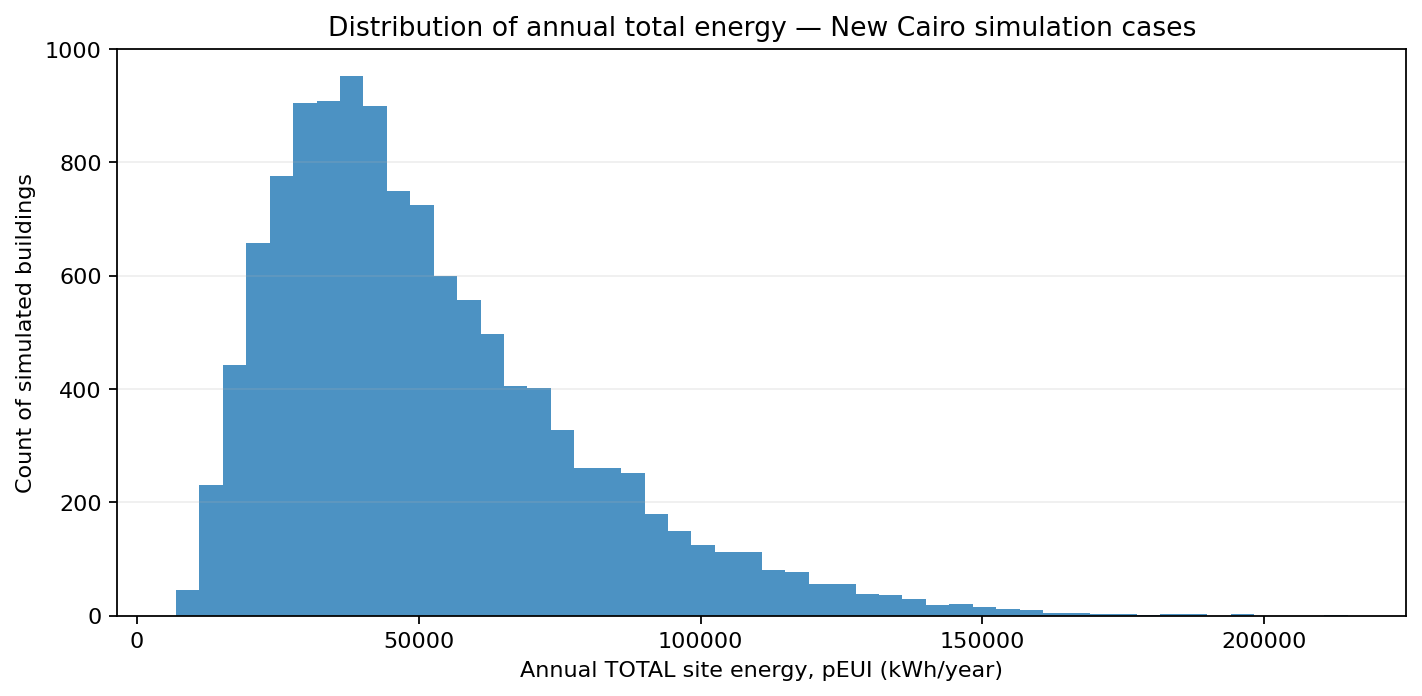

In [10]:
# Figure is cached inside the resume archive; only the original source data are plotted.
DESCR_FP=hashlib.sha256((ALT_SOURCE_FP+'peui-source-hist-v1').encode()).hexdigest()
DESCR_PNG=OUTDIR/'phase2_total_annual_energy_distribution.png'
if stage_valid('phase2_total_energy_distribution',DESCR_FP):
    print('SKIP plot: existing checkpoint verified.')
else:
    # Read only the source target; no predictions are generated.
    target = pd.read_excel(ALT_PATH, sheet_name='Sheet1',usecols=['pEUI'],engine='openpyxl')['pEUI'].astype(float)
    fig,ax=plt.subplots(figsize=(9,4.5))
    ax.hist(target,bins=50,alpha=.8)
    ax.set_xlabel('Annual TOTAL site energy, pEUI (kWh/year)')
    ax.set_ylabel('Count of simulated buildings')
    ax.set_title('Distribution of annual total energy — New Cairo simulation cases')
    ax.grid(axis='y',alpha=.2)
    fig.tight_layout();fig.savefig(DESCR_PNG,dpi=160,bbox_inches='tight');plt.close(fig)
    record_stage('phase2_total_energy_distribution',DESCR_FP,[DESCR_PNG])
display(Image(filename=str(DESCR_PNG)))


### 11. Check Phase 2 outputs

Verify that the approved preprocessing artifacts exist.

In [11]:
# Phase 2 state integrity; Phase 3 cells are appended below.
assert stage_valid('phase2_validated_splits', PREP_FINGERPRINT), 'Preprocessed data checkpoint is missing or corrupt.'
print('Phase 2 verified. Training-ready state:', SPLIT_NPZ)


Phase 2 verified. Training-ready state: /kaggle/working/BUILDING_CFM_STATE/outputs/phase2_validated_splits.npz


### 12. Prepare baseline environment

Check dependencies and load the fixed data partitions.

In [12]:
# Phase 3 prerequisites (no model fit yet)
import sys, importlib.util, subprocess, platform, time
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor

# Kaggle usually provides XGBoost/CatBoost. Install only if necessary, never reinstall by default.
def ensure_package(package):
    if importlib.util.find_spec(package) is None:
        print('Installing missing', package)
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
    return __import__(package)

xgb = ensure_package('xgboost')
cb = ensure_package('catboost')
import torch
from torch import nn

assert stage_valid('phase2_validated_splits', PREP_FINGERPRINT), 'STOP: validated preprocessing is missing.'
with np.load(SPLIT_NPZ) as data:
    TRAIN_X = data['x_train'].astype('float32')
    VAL_X = data['x_val'].astype('float32')
    TEST_X = data['x_test'].astype('float32')
    TRAIN_Y_SCALED = data['y_train'].reshape(-1).astype('float32')
    VAL_Y_SCALED = data['y_val'].reshape(-1).astype('float32')
    TEST_Y_SCALED = data['y_test'].reshape(-1).astype('float32')
    TRAIN_Y_RAW = data['raw_y_train'].astype('float64')
    VAL_Y_RAW = data['raw_y_val'].astype('float64')
    TEST_Y_RAW = data['raw_y_test'].astype('float64')
    ID_TRAIN = data['id_train'].copy()
    ID_VAL = data['id_val'].copy()
    ID_TEST = data['id_test'].copy()

assert TRAIN_X.shape == (8400,21) and VAL_X.shape == (1800,21) and TEST_X.shape == (1800,21), (TRAIN_X.shape, VAL_X.shape, TEST_X.shape)
assert len(set(ID_TRAIN) & set(ID_VAL)) == len(set(ID_TRAIN) & set(ID_TEST)) == len(set(ID_VAL) & set(ID_TEST)) == 0
assert np.isfinite(TRAIN_X).all() and np.isfinite(TRAIN_Y_SCALED).all()
assert np.isfinite(VAL_X).all() and np.isfinite(TEST_X).all()
assert (TRAIN_Y_RAW > 0).all() and (VAL_Y_RAW > 0).all() and (TEST_Y_RAW > 0).all()

TARGET_MEAN = float(prep_metadata['log_train_mean'])
TARGET_SD = float(prep_metadata['log_train_std'])
def to_raw_energy(pred_scaled):
    z = np.asarray(pred_scaled, dtype='float64').reshape(-1)*TARGET_SD + TARGET_MEAN
    return np.maximum(np.expm1(np.clip(z, -20, 35)), 0)
def metric_dict(y_true, y_pred):
    return dict(MAE=float(mean_absolute_error(y_true,y_pred)),
                RMSE=float(np.sqrt(mean_squared_error(y_true,y_pred))),
                R2=float(r2_score(y_true,y_pred)))

PHASE3_DIR = OUTDIR / 'phase3_baselines'
PHASE3_MODELS = MODEL_DIR / 'phase3_baselines'
PHASE3_DIR.mkdir(parents=True, exist_ok=True)
PHASE3_MODELS.mkdir(parents=True, exist_ok=True)
print('Phase 3 input shapes:', TRAIN_X.shape, VAL_X.shape, TEST_X.shape)
print('Versions: Python', platform.python_version(), 'Torch',torch.__version__, 'XGBoost',xgb.__version__, 'CatBoost',cb.__version__)
print('MLP device:', 'cuda:0' if torch.cuda.is_available() else 'cpu')
print('Total annual energy target: pEUI (kWh/year)')


Phase 3 input shapes: (8400, 21) (1800, 21) (1800, 21)
Versions: Python 3.13.15 Torch 2.11.0+cu128 XGBoost 3.4.1 CatBoost 1.2.10
MLP device: cuda:0
Total annual energy target: pEUI (kWh/year)


### 13. Train deterministic baselines

Fit the Ridge, ExtraTrees, XGBoost and CatBoost comparators.

In [13]:
BASELINE_CONFIGS = {
    'Ridge': dict(alpha=10.0),
    'ExtraTrees': dict(n_estimators=350, min_samples_leaf=2, max_features=1.0, random_state=SEED, n_jobs=4),
    'XGBoost': dict(n_estimators=650, max_depth=5, learning_rate=0.05, subsample=0.85,
                    colsample_bytree=0.90, objective='reg:squarederror', tree_method='hist',
                    n_jobs=4, random_state=SEED),
    'CatBoost': dict(iterations=950, depth=6, learning_rate=0.05, l2_leaf_reg=5,
                     loss_function='RMSE', random_seed=SEED, thread_count=4, verbose=False,
                     allow_writing_files=False),
}

def create_classical(name):
    cfg=BASELINE_CONFIGS[name]
    if name=='Ridge': return Ridge(**cfg)
    if name=='ExtraTrees': return ExtraTreesRegressor(**cfg)
    if name=='XGBoost': return xgb.XGBRegressor(**cfg)
    if name=='CatBoost': return cb.CatBoostRegressor(**cfg)
    raise ValueError(name)

def run_classical_baseline(name):
    cfg=BASELINE_CONFIGS[name]
    source=json.dumps({'name':name,'config':cfg,'split':PREP_FINGERPRINT,
                       'protocol':'phase3-baseline-v1'},sort_keys=True,default=str)
    fp=hashlib.sha256(source.encode()).hexdigest()
    stage='phase3_model_'+name.lower()
    model_path=PHASE3_MODELS / (name+'.joblib')
    record_path=PHASE3_DIR / (name+'_validation.json')
    if stage_valid(stage,fp):
        print('SKIP verified finished model:',name)
        model=joblib.load(model_path)
        report=json.loads(record_path.read_text())
    else:
        print('TRAIN:',name, 'on CPU')
        start=time.perf_counter()
        model=create_classical(name)
        model.fit(TRAIN_X,TRAIN_Y_SCALED)
        yval_hat=to_raw_energy(model.predict(VAL_X))
        report={'model':name,'config':cfg,'split_fingerprint':PREP_FINGERPRINT,
                'validation':metric_dict(VAL_Y_RAW,yval_hat),
                'training_seconds':time.perf_counter()-start,
                'target':'total site energy kWh/year','evaluated_test':False}
        joblib.dump(model,model_path,compress=3)
        atomic_json(record_path,report)
        record_stage(stage,fp,[model_path,record_path],
                     details={'model':name,'validation_RMSE':report['validation']['RMSE']})
        print('SAVED',name,'validation RMSE:',round(report['validation']['RMSE'],3),'kWh/year')
    return report

CLASSICAL_VALIDATION = {name:run_classical_baseline(name) for name in BASELINE_CONFIGS}
display(pd.DataFrame([{'Model':n,'Val RMSE (kWh/year)':r['validation']['RMSE'],
                        'Val MAE (kWh/year)':r['validation']['MAE'],
                        'Val R²':r['validation']['R2'],
                        'Training seconds':r['training_seconds']}
                       for n,r in CLASSICAL_VALIDATION.items()]).sort_values('Val RMSE (kWh/year)'))


SKIP verified finished model: Ridge
SKIP verified finished model: ExtraTrees
SKIP verified finished model: XGBoost
SKIP verified finished model: CatBoost


,Model,Val RMSE (kWh/year),Val MAE (kWh/year),Val R²,Training seconds
3,CatBoost,3280.442880,1506.876216,0.985514,2.764759
2,XGBoost,4237.189303,2167.137155,0.975832,1.116055
0,Ridge,6941.698638,3943.623999,0.935134,0.032934
1,ExtraTrees,7841.191074,4465.164728,0.917234,4.934448


### 14. Train the neural baseline

Train or resume the MLP baseline with its checkpoint controls.

In [14]:
MLP_CONFIG = dict(hidden=[128,64], dropout=0.08, learning_rate=0.001,
                  weight_decay=0.0001, batch_size=256, max_epochs=180, patience=25,
                  min_delta=0.0001, seed=SEED)
MLP_FP = hashlib.sha256(json.dumps({'cfg':MLP_CONFIG,'split':PREP_FINGERPRINT,
                                     'version':'phase3-mlp-v1'},sort_keys=True).encode()).hexdigest()
MLP_LAST=PHASE3_MODELS/'MLP_last.pt'
MLP_BEST=PHASE3_MODELS/'MLP_best.pt'
MLP_HISTORY=PHASE3_DIR/'MLP_history.json'
MLP_REPORT=PHASE3_DIR/'MLP_validation.json'

class TabularMLP(nn.Module):
    def __init__(self,input_dim):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(input_dim,128),nn.GELU(),nn.Dropout(0.08),
                               nn.Linear(128,64),nn.GELU(),nn.Dropout(0.08),nn.Linear(64,1))
    def forward(self,x):
        return self.net(x).reshape(-1)

def save_pt_atomic(obj,path):
    tmp=path.with_name(path.name+'.tmp')
    torch.save(obj,tmp)
    os.replace(tmp,path)

def run_mlp_baseline():
    if stage_valid('phase3_model_mlp',MLP_FP):
        print('SKIP verified finished model: MLP')
        return json.loads(MLP_REPORT.read_text())
    device=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    random.seed(SEED);np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
    model=TabularMLP(TRAIN_X.shape[1]).to(device)
    optim=torch.optim.AdamW(model.parameters(),lr=MLP_CONFIG['learning_rate'],
                            weight_decay=MLP_CONFIG['weight_decay'])
    xb=torch.as_tensor(TRAIN_X,dtype=torch.float32)
    yb=torch.as_tensor(TRAIN_Y_SCALED,dtype=torch.float32)
    xv=torch.as_tensor(VAL_X,dtype=torch.float32,device=device)
    best_rmse=float('inf');best_epoch=0;wait=0;start_epoch=1;history=[]
    if MLP_LAST.exists() and stage_valid('phase3_mlp_progress',MLP_FP):
        checkpoint=torch.load(MLP_LAST,map_location=device,weights_only=False)  # Own trusted resume archive only
        assert checkpoint.get('fingerprint')==MLP_FP, 'MLP checkpoint belongs to different settings'
        model.load_state_dict(checkpoint['model'])
        optim.load_state_dict(checkpoint['optimizer'])
        best_rmse=float(checkpoint['best_rmse'])
        best_epoch=int(checkpoint['best_epoch']);wait=int(checkpoint['wait'])
        history=checkpoint['history'];start_epoch=int(checkpoint['epoch'])+1
        torch.set_rng_state(checkpoint['torch_rng'].cpu())
        if torch.cuda.is_available() and checkpoint.get('cuda_rng') is not None:
            torch.cuda.set_rng_state_all(checkpoint['cuda_rng'])
        print('RESUME MLP from epoch',start_epoch,'previous best epoch',best_epoch)
    start=time.perf_counter()
    for epoch in range(start_epoch,MLP_CONFIG['max_epochs']+1):
        model.train()
        perm=torch.randperm(len(xb))
        training_losses=[]
        for inds in perm.split(MLP_CONFIG['batch_size']):
            xx=xb[inds].to(device,non_blocking=True)
            yy=yb[inds].to(device,non_blocking=True)
            optim.zero_grad(set_to_none=True)
            loss=nn.functional.mse_loss(model(xx),yy)
            loss.backward()
            optim.step()
            training_losses.append(float(loss.detach().cpu()))
        model.eval()
        with torch.no_grad(): pred=model(xv).detach().cpu().numpy()
        val_metrics=metric_dict(VAL_Y_RAW,to_raw_energy(pred))
        rmse=val_metrics['RMSE']
        history.append({'epoch':epoch,'train_scaled_mse':float(np.mean(training_losses)),
                        'val_RMSE_kWh_per_year':rmse,'val_MAE_kWh_per_year':val_metrics['MAE']})
        if rmse < best_rmse-MLP_CONFIG['min_delta']:
            best_rmse=rmse;best_epoch=epoch;wait=0
            save_pt_atomic({'model':model.state_dict(),'input_dim':TRAIN_X.shape[1],
                            'fingerprint':MLP_FP,'epoch':epoch},MLP_BEST)
        else:wait+=1
        state={'model':model.state_dict(),'optimizer':optim.state_dict(),'epoch':epoch,
               'best_rmse':best_rmse,'best_epoch':best_epoch,'wait':wait,
               'history':history,'fingerprint':MLP_FP,'torch_rng':torch.get_rng_state(),
               'cuda_rng':torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}
        save_pt_atomic(state,MLP_LAST)
        atomic_json(MLP_HISTORY,history)
        # Register full progress and ZIP after EVERY completed epoch (including optimizer state).
        record_stage('phase3_mlp_progress',MLP_FP,[MLP_LAST,MLP_BEST,MLP_HISTORY],
                     details={'completed_epoch':epoch,'best_epoch':best_epoch},archive=True)
        if epoch==1 or epoch%10==0 or wait>=MLP_CONFIG['patience']:
            print(f'MLP epoch {epoch}/{MLP_CONFIG["max_epochs"]}: val RMSE={rmse:.3f}; best={best_rmse:.3f} at {best_epoch}')
        if wait>=MLP_CONFIG['patience']:
            print('Early stop after',epoch,'epochs')
            break
    # If previous execution finished max_epochs and was interrupted before final stage, this still works.
    best=torch.load(MLP_BEST,map_location=device,weights_only=False)
    model.load_state_dict(best['model'])
    model.eval()
    with torch.no_grad(): pred=model(xv).detach().cpu().numpy()
    summary={'model':'MLP','config':MLP_CONFIG,'split_fingerprint':PREP_FINGERPRINT,
             'validation':metric_dict(VAL_Y_RAW,to_raw_energy(pred)),
             'training_seconds_this_invocation':time.perf_counter()-start,
             'best_epoch':best_epoch,'completed_epoch':int(history[-1]['epoch']),
             'target':'total site energy kWh/year','evaluated_test':False}
    atomic_json(MLP_REPORT,summary)
    record_stage('phase3_model_mlp',MLP_FP,[MLP_LAST,MLP_BEST,MLP_HISTORY,MLP_REPORT],
                 details={'best_epoch':best_epoch,'validation_RMSE':summary['validation']['RMSE']})
    print('MLP FINAL validation:',summary['validation'],'saved at',MLP_BEST)
    return summary

MLP_VALIDATION=run_mlp_baseline()


SKIP verified finished model: MLP


### 15. Evaluate baseline predictions

Report held-out errors for completed baseline models.

SKIP: held-out benchmark saved and verified.


,Model,Val_RMSE_kWh_per_year,Val_MAE_kWh_per_year,Val_R2,Test_RMSE_kWh_per_year,Test_MAE_kWh_per_year,Test_R2
0,CatBoost,3280.4429,1506.8762,0.9855,3190.1948,1390.6872,0.9857
1,XGBoost,4237.1893,2167.1372,0.9758,3540.4761,2025.3813,0.9824
2,MLP,4915.4444,1941.6336,0.9675,3267.1145,1645.4580,0.9850
3,Ridge,6941.6986,3943.6240,0.9351,5581.0427,3562.9985,0.9564
4,ExtraTrees,7841.1911,4465.1647,0.9172,6529.0252,4120.6190,0.9403


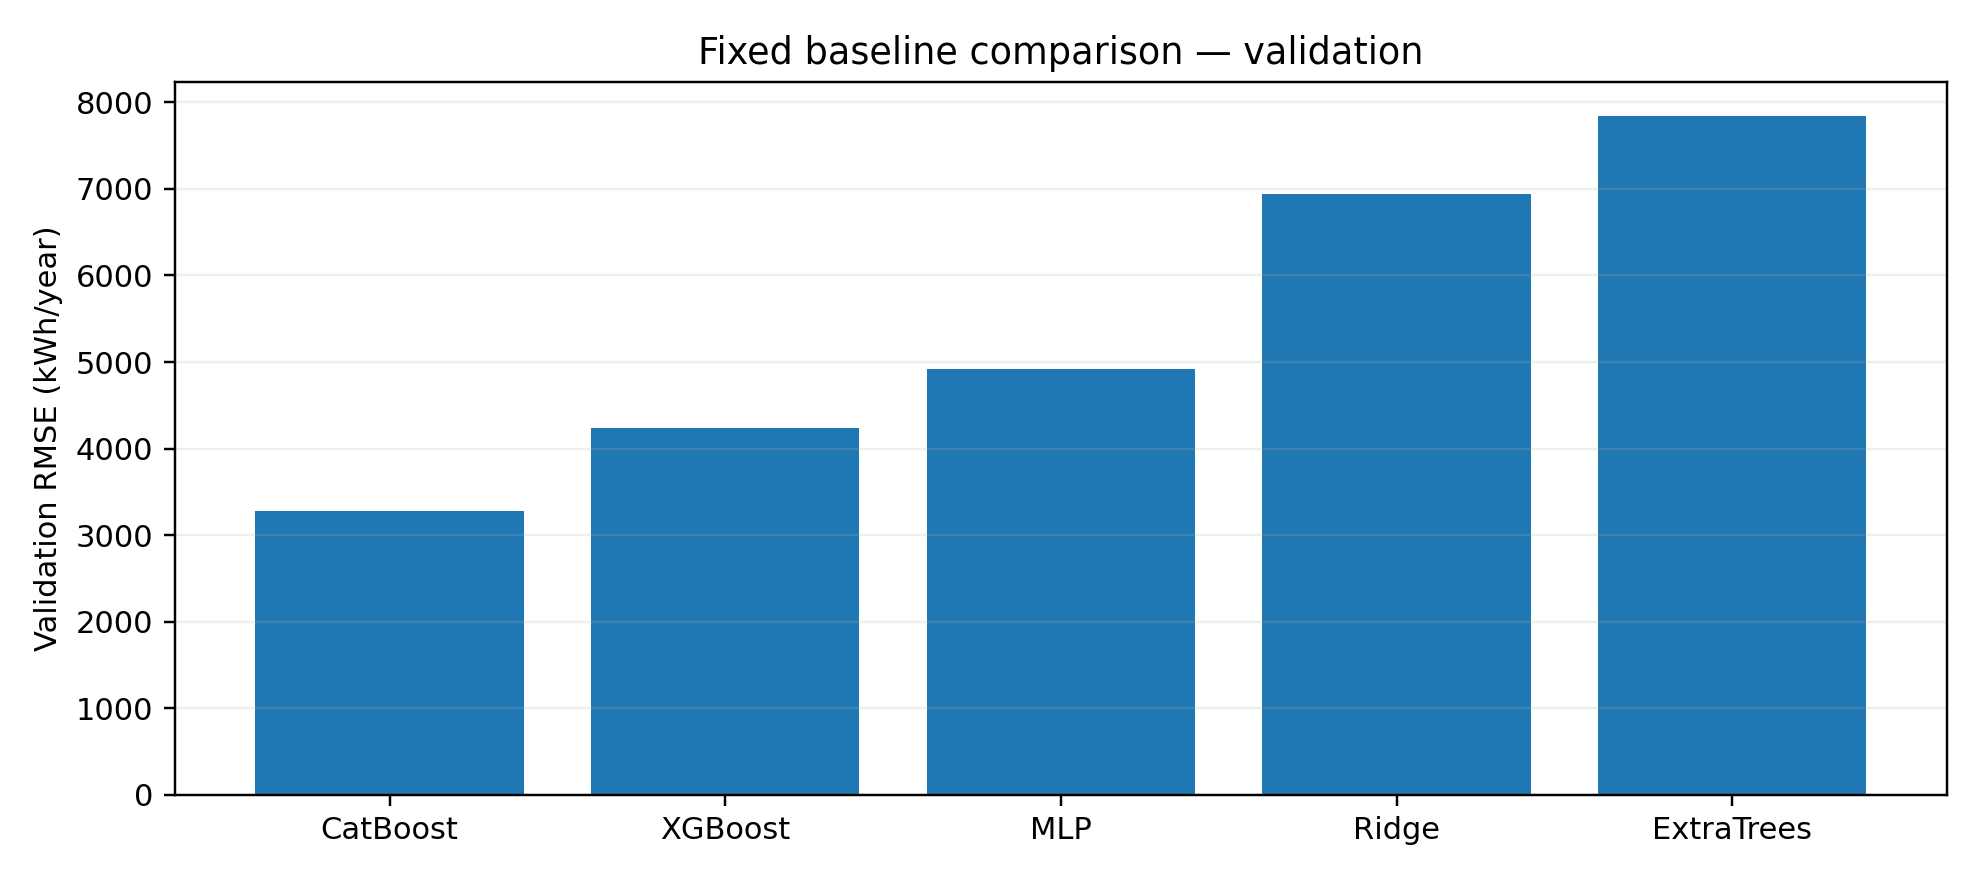

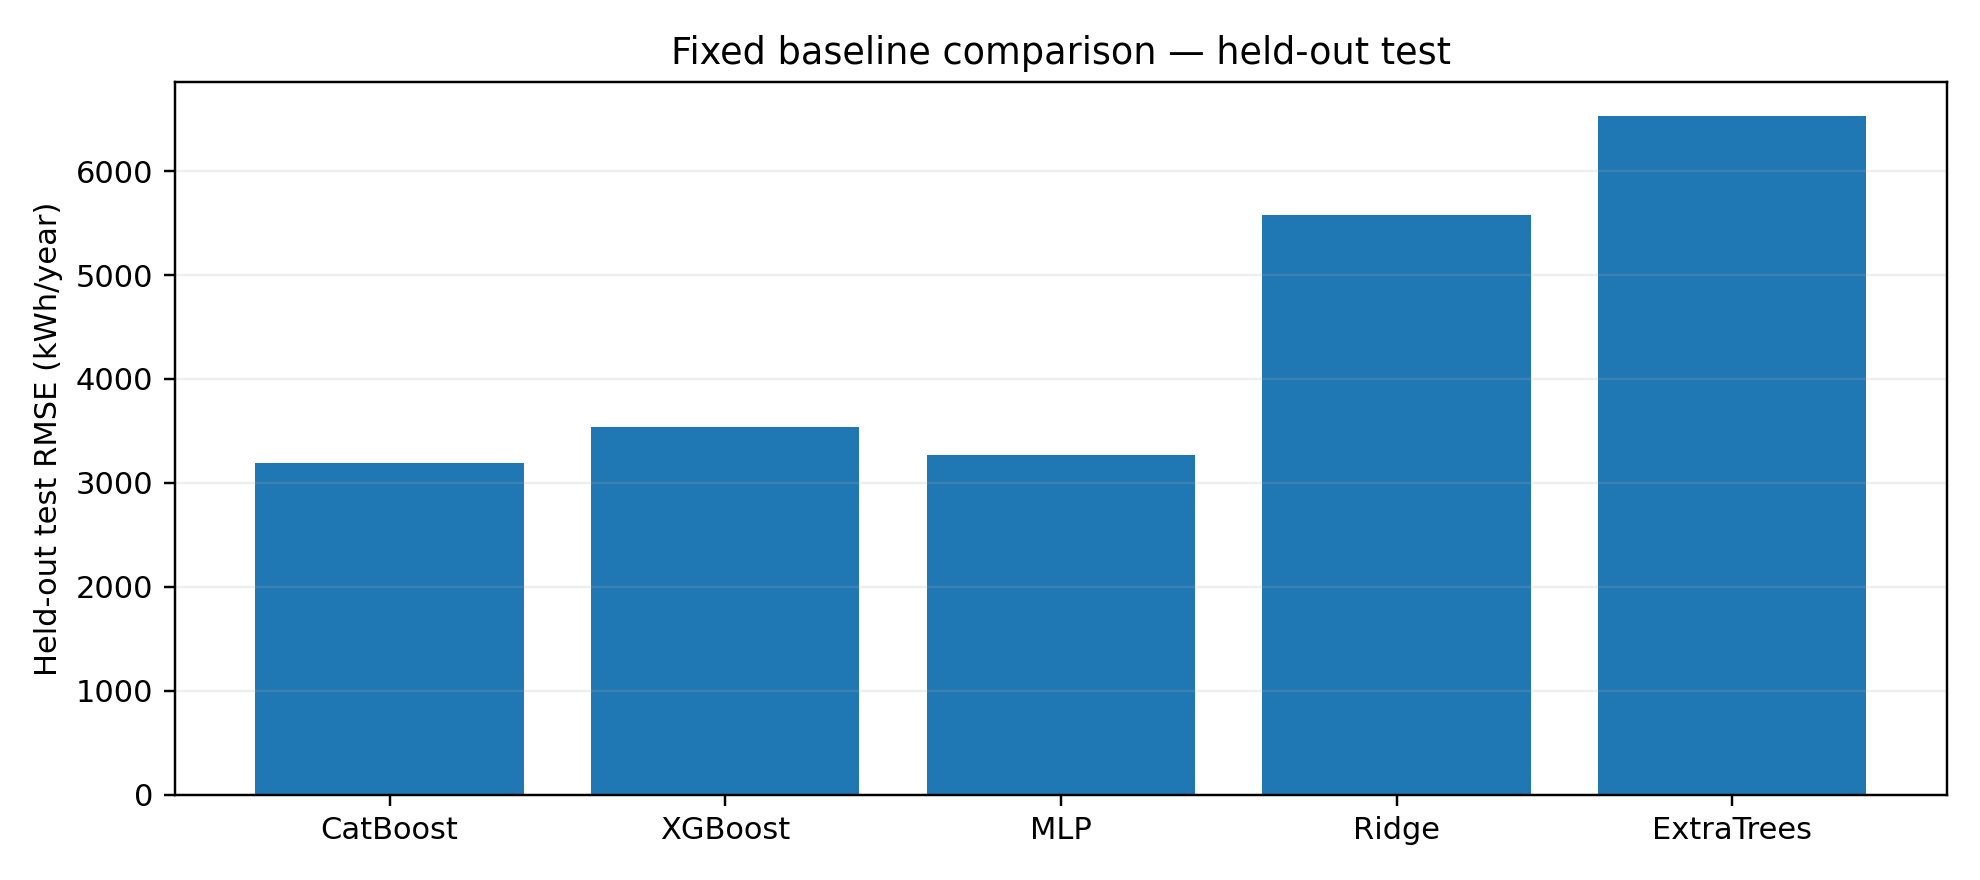

MODEL BENCHMARK SAVED; strongest validation model: CatBoost
Reminder: test-set results may not be used to tune subsequent model configurations.


In [15]:
# One fixed, held-out evaluation for all completed Phase 3 models.
all_saved=['Ridge','ExtraTrees','XGBoost','CatBoost','MLP']
all_train_stages=['phase3_model_'+name.lower() for name in all_saved]
assert all(stage in manifest.get('stages',{}) for stage in all_train_stages), 'Some models are not yet trained: STOP.'
artifacts=[]
for stage in all_train_stages:
    artifacts+=sorted(manifest['stages'][stage]['outputs'].items())
EVAL_FP=hashlib.sha256(json.dumps({'artifacts':artifacts,'split':PREP_FINGERPRINT,
                                    'version':'phase3-frozen-test-eval-v1'},sort_keys=True).encode()).hexdigest()
EVAL_CSV=PHASE3_DIR/'phase3_model_comparison.csv'
EVAL_JSON=PHASE3_DIR/'phase3_comparison_metadata.json'
TEST_PREDS_NPZ=PHASE3_DIR/'phase3_test_predictions.npz'
VAL_PLOT=PHASE3_DIR/'phase3_validation_rmse.png'
TEST_PLOT=PHASE3_DIR/'phase3_test_rmse.png'

if stage_valid('phase3_baseline_comparison',EVAL_FP):
    print('SKIP: held-out benchmark saved and verified.')
    results=pd.read_csv(EVAL_CSV)
else:
    rows=[]; pred_test={}
    for name in all_saved:
        if name=='MLP':
            device=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
            model=TabularMLP(TRAIN_X.shape[1]).to(device)
            ckpt=torch.load(MLP_BEST,map_location=device,weights_only=False)  # Own saved checkpoint
            model.load_state_dict(ckpt['model']);model.eval()
            with torch.no_grad():
                p=model(torch.from_numpy(TEST_X).to(device)).detach().cpu().numpy()
        else:
            model=joblib.load(PHASE3_MODELS/(name+'.joblib'))
            p=model.predict(TEST_X)
        pred=to_raw_energy(p)
        pred_test[name]=pred
        val=json.loads((PHASE3_DIR/(name+'_validation.json')).read_text())
        tm=metric_dict(TEST_Y_RAW,pred)
        rows.append({'Model':name,
                     'Val_RMSE_kWh_per_year':val['validation']['RMSE'],
                     'Val_MAE_kWh_per_year':val['validation']['MAE'],
                     'Val_R2':val['validation']['R2'],
                     'Test_RMSE_kWh_per_year':tm['RMSE'],
                     'Test_MAE_kWh_per_year':tm['MAE'],
                     'Test_R2':tm['R2']})
    results=pd.DataFrame(rows).sort_values('Val_RMSE_kWh_per_year').reset_index(drop=True)
    results.to_csv(EVAL_CSV,index=False)
    np.savez_compressed(TEST_PREDS_NPZ,raw_y_test=TEST_Y_RAW,**{('pred_'+name):val for name,val in pred_test.items()})
    atomic_json(EVAL_JSON,{'target':'pEUI','target_units':'kWh/year',
                            'protocol':'fixed 70/15/15 random split, unmodified test set',
                            'limitations':['Single simulated Cairo climate','Random split not OOD',
                                           'Results do not validate causal or intervention effects'],
                            'predeclared_model_set':all_saved,
                            'test_results_used_for_model_selection':False})
    fig,ax=plt.subplots(figsize=(9,4))
    ax.bar(results['Model'],results['Val_RMSE_kWh_per_year'])
    ax.set(ylabel='Validation RMSE (kWh/year)',title='Fixed baseline comparison — validation')
    ax.grid(axis='y',alpha=.2);fig.tight_layout();fig.savefig(VAL_PLOT,dpi=220);plt.close(fig)
    fig,ax=plt.subplots(figsize=(9,4))
    ax.bar(results['Model'],results['Test_RMSE_kWh_per_year'])
    ax.set(ylabel='Held-out test RMSE (kWh/year)',title='Fixed baseline comparison — held-out test')
    ax.grid(axis='y',alpha=.2);fig.tight_layout();fig.savefig(TEST_PLOT,dpi=220);plt.close(fig)
    record_stage('phase3_baseline_comparison',EVAL_FP,
                 [EVAL_CSV,EVAL_JSON,TEST_PREDS_NPZ,VAL_PLOT,TEST_PLOT],
                 details={'target':'total annual site energy','tested_models':len(all_saved)})

display(results.round(4))
display(Image(filename=str(VAL_PLOT)))
display(Image(filename=str(TEST_PLOT)))
print('MODEL BENCHMARK SAVED; strongest validation model:',str(results.iloc[0]['Model']))
print('Reminder: test-set results may not be used to tune subsequent model configurations.')


### 16. Define figure export utilities

Register functions that save experiment figures and metadata.

In [16]:
# Shared journal figure engine. IMPORTANT: figures live OUTSIDE the training resume ZIP.
import csv, re
from PIL import Image as PILImage
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator

FIG_ROOT = WORKDIR / 'JOURNAL_FIGURES'
FIG_ZIP = WORKDIR / 'JOURNAL_FIGURES_LATEST.zip'
FIG_INDEX = FIG_ROOT / 'figure_index.json'
FIG_VERSION = 'journal-figures-v4-vector-raster-csv'
ENABLE_EPS = False  # Optional: EPS may render slowly in Kaggle; vector PDF is Elsevier accepted.
FIG_ROOT.mkdir(parents=True, exist_ok=True)
FIG_DIRS = {k: FIG_ROOT/k for k in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','vector_eps','plot_data')}
for v in FIG_DIRS.values():v.mkdir(exist_ok=True)

def _fig_index_load():
    try:
        idx=json.loads(FIG_INDEX.read_text(encoding='utf-8'))
        return idx if idx.get('version')==FIG_VERSION else {'version':FIG_VERSION, 'figures':{}}
    except (OSError,ValueError):
        return {'version':FIG_VERSION,'figures':{}}

def restore_figure_zip_if_available():
    """Safe best-effort restore from a Kaggle Add Input archive, if newer/more complete."""
    candidates=[]
    if FIG_ZIP.is_file():candidates.append(FIG_ZIP)
    explicit=os.environ.get('BUILDING_CFM_FIGURES_ARCHIVE','').strip()
    if explicit and Path(explicit).is_file():candidates.append(Path(explicit))
    if Path('/kaggle/input').exists():
        candidates.extend(Path('/kaggle/input').rglob(FIG_ZIP.name))
    current=len(_fig_index_load()['figures'])
    for candidate in candidates:
        try:
            with zipfile.ZipFile(candidate) as z:
                ix=json.loads(z.read('JOURNAL_FIGURES/figure_index.json'))
                if ix.get('version')!=FIG_VERSION or len(ix.get('figures',{}))<=current:continue
                for item in z.infolist():
                    path=Path(item.filename)
                    if not path.parts or path.parts[0]!='JOURNAL_FIGURES' or path.is_absolute() or '..' in path.parts:
                        raise RuntimeError('Unsafe figure archive member')
                    if (item.external_attr >> 16) & 0o170000 == 0o120000:
                        raise RuntimeError('Figure archive contains a symbolic link')
                    dest=WORKDIR/path
                    if item.is_dir():dest.mkdir(parents=True,exist_ok=True);continue
                    dest.parent.mkdir(parents=True,exist_ok=True)
                    with z.open(item) as r,open(dest,'wb') as w:shutil.copyfileobj(r,w)
                print('Restored prior journal figure gallery from:',candidate)
                current=len(ix.get('figures',{}))
        except (OSError,ValueError,KeyError,zipfile.BadZipFile) as exc:
            print('Ignoring unreadable prior figure ZIP:',candidate,exc)
restore_figure_zip_if_available()
figure_index=_fig_index_load()

mpl.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'axes.labelsize':10,
                     'axes.titlesize':11, 'legend.fontsize':9, 'pdf.fonttype':42,
                     'ps.fonttype':42, 'svg.fonttype':'none', 'savefig.facecolor':'white',
                     'figure.facecolor':'white'})

def figure_fingerprint(name, *source_files):
    source_hashes=[sha256_file(f) for f in source_files if f is not None and Path(f).is_file()]
    return hashlib.sha256(json.dumps([FIG_VERSION,name,*source_hashes],sort_keys=True).encode()).hexdigest()

def publish_figure(fig_id, title, caption, split, figure, data, fingerprint, caveat=''):
    """Export actual plotted data, editable vectors, 600-dpi lossless raster, and captions."""
    assert re.fullmatch(r'J\d\d_[a-z0-9_]+',fig_id),fig_id
    assert split in ('training','validation','test','training+validation','validation+test','validation_exploratory'), f'Unsupported figure data split: {split}'
    existing=figure_index['figures'].get(fig_id)
    if existing and existing.get('fingerprint')==fingerprint and all((FIG_ROOT / r).is_file() for r in existing['files']):
        plt.close(figure)
        print('Figure unchanged; using saved files:',fig_id)
        return
    out={key:directory/(fig_id+ext) for key,directory,ext in [
        ('png',FIG_DIRS['600dpi_png'],'.png'),('tiff',FIG_DIRS['600dpi_tiff'],'.tiff'),
        ('pdf',FIG_DIRS['vector_pdf'],'.pdf'),('svg',FIG_DIRS['vector_svg'],'.svg'),
        ('csv',FIG_DIRS['plot_data'],'.csv')]}
    assert isinstance(data,pd.DataFrame) and len(data)>0, f'{fig_id}: no source data'
    if ENABLE_EPS:out['eps']=FIG_DIRS['vector_eps']/(fig_id+'.eps')
    data.to_csv(out['csv'],index=False)
    figure.savefig(out['pdf'],bbox_inches='tight')
    figure.savefig(out['svg'],bbox_inches='tight')
    if ENABLE_EPS:figure.savefig(out['eps'],bbox_inches='tight')
    figure.savefig(out['png'],dpi=600,bbox_inches='tight')
    with PILImage.open(out['png']) as im:
        im.convert('RGB').save(out['tiff'],format='TIFF',compression='tiff_lzw',dpi=(600,600))
    plt.close(figure)
    figure_index['figures'][fig_id]={
        'title':title,'caption':caption,'data_split':split,'caveat':caveat,'fingerprint':fingerprint,
        'files':[p.relative_to(FIG_ROOT).as_posix() for p in out.values()],
        'generated_at':now_utc(),'raster_dpi':600,'source_data':out['csv'].relative_to(FIG_ROOT).as_posix()}
    atomic_json(FIG_INDEX,figure_index)
    print('Saved publication files:',fig_id)

def export_figure_package():
    """Atomic standalone ZIP, no expensive recompression on every model-training epoch."""
    captions=['# Figure captions (draft; refine for the chosen journal)','','Target: annual total site energy (`pEUI`), kWh/year.','']
    listing=[]
    for key,item in sorted(figure_index['figures'].items()):
        captions.append(f"### {key}: {item['title']}\n{item['caption']}\n")
        if item.get('caveat'):captions.append('**Interpretation limit:** '+item['caveat']+'\n')
        listing.append({'figure_id':key,'title':item['title'],'data_split':item['data_split'],
                        'image_formats':'PNG 600 dpi; TIFF 600 dpi; vector PDF/SVG'+('/EPS' if ENABLE_EPS else ''),
                        'source_data_csv':item['source_data'],'caveat':item.get('caveat','')})
    (FIG_ROOT/'figure_captions.md').write_text('\n'.join(captions),encoding='utf-8')
    pd.DataFrame(listing).to_csv(FIG_ROOT/'figure_inventory.csv',index=False)
    pending=[('P01','Proposed model architecture','Requires final implemented method and verified architecture'),
             ('P02','Proposed model multi-seed benchmark','Requires multiple real training seeds'),
             ('P03','Proposed-model ablation','Requires trained ablation variants'),
             ('P04','External unseen-design/generalization test','Requires independent or grouped evaluation'),
             ('P05','Uncertainty calibration after held-out calibration','Requires an actually fitted calibration step'),
             ('P06','Robustness under data scarcity','Requires fixed low-data experiments'),
             ('P07','Compute/latency tradeoff','Requires measured runtime and consistent hardware')]
    pd.DataFrame(pending,columns=['planned_id','potential_figure','status_and_requirement']).to_csv(FIG_ROOT/'future_figures_NOT_YET_PERFORMED.csv',index=False)
    (FIG_ROOT/'README.txt').write_text(
        'JOURNAL RESEARCH FIGURES: VERIFIED PLOTTED RESULTS ONLY\n'
        'Data: synthetic simulation output pEUI; annual total site energy (kWh/year), not heating-only.\n'
        'Each figure is provided as 600 dpi PNG/TIFF, vector PDF/SVG (optional EPS) and plotting CSV.\n'
        'Vector PDF is preferable to 600 dpi TIFF for sharp line art.\n'
        'Training checkpoint ZIP is separate: BUILDING_CFM_RESUME_LATEST.zip.\n'
        'Source experiment: baseline testing is held-out once; CFM is validation-only.\n'
        'Do not treat these as a finished Q1 manuscript or claim cross-climate generalization.\n'
        'Consult target journal artwork instructions and revise titles/captions before submission.\n',encoding='utf-8')
    tmp=FIG_ZIP.with_suffix('.zip.tmp')
    with zipfile.ZipFile(tmp,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=5) as z:
        for f in sorted(FIG_ROOT.rglob('*')):
            if f.is_file():z.write(f,(Path('JOURNAL_FIGURES')/f.relative_to(FIG_ROOT)).as_posix())
    os.replace(tmp,FIG_ZIP)
    with zipfile.ZipFile(FIG_ZIP) as z:assert z.testzip() is None, 'Figure archive integrity failed'
    print(f'JOURNAL FIGURE ARCHIVE: {FIG_ZIP} ({FIG_ZIP.stat().st_size/1048576:.1f} MiB), figures={len(listing)}')
    print('DO NOT DELETE the separate BUILDING_CFM_RESUME_LATEST.zip: it contains your trained model states.')


### 17. Export baseline figures

Generate plots from the saved baseline comparison results.

In [17]:
# Publication gallery Phase 3 — available REAL baseline results only.
base_df=pd.read_csv(EVAL_CSV).sort_values('Val_RMSE_kWh_per_year')
with np.load(TEST_PREDS_NPZ,allow_pickle=False) as z:
    observed=z['raw_y_test'].astype(float)
    baseline_preds={name:z['pred_'+name].astype(float) for name in base_df['Model']}
best_baseline=str(base_df.iloc[0]['Model']) # determined on validation only
pred_best=baseline_preds[best_baseline]
assert len(observed)==len(pred_best)==len(TEST_X)==len(ID_TEST)
base_fp=figure_fingerprint('baseline',EVAL_CSV,TEST_PREDS_NPZ,SPLIT_NPZ)

# J01: Training-set target distribution only, no test-based design choices.
fig,ax=plt.subplots(figsize=(7.8,4.6),layout='constrained')
ax.hist(TRAIN_Y_RAW,bins=40,edgecolor='white',linewidth=.4)
ax.set(xlabel='Annual total site energy (kWh/year)',ylabel='Count',title='Training data: energy target distribution')
ax.grid(axis='y',alpha=.2)
publish_figure('J01_training_energy_distribution','Training energy distribution',
    'Distribution of the annual total site energy target in the training split (n = 8,400).',
    'training',fig,pd.DataFrame({'energy_kWh_per_year':TRAIN_Y_RAW}),base_fp)

# J02: all baseline MAE/RMSE, both validation and held-out test (reporting only).
fig,axes=plt.subplots(1,2,figsize=(11.0,4.7),layout='constrained')
x=np.arange(len(base_df)); barw=.37
for ax,metric in zip(axes,['RMSE','MAE']):
    ax.bar(x-barw/2,base_df[f'Val_{metric}_kWh_per_year'],barw,label='Validation')
    ax.bar(x+barw/2,base_df[f'Test_{metric}_kWh_per_year'],barw,label='Held-out test')
    ax.set(xticks=x,xticklabels=base_df['Model'],ylabel=f'{metric} (kWh/year)',title=f'Baseline {metric} comparison')
    ax.tick_params(axis='x',rotation=30);ax.grid(axis='y',alpha=.2);ax.legend(frameon=False)
publish_figure('J02_baseline_accuracy_comparison','Baseline regression metrics',
    'Validation and held-out test RMSE and MAE of five prespecified baseline models. The held-out test results are descriptive and were not used for hyperparameter selection.',
    'validation+test',fig,base_df,base_fp,'Data were generated under a single Cairo climate and a random split.')

# J03: actual vs best-VALIDATION baseline predicted; residual data saved to CSV.
limits=[min(observed.min(),pred_best.min()),max(observed.max(),pred_best.max())]
fig,ax=plt.subplots(figsize=(6.6,5.9),layout='constrained')
ax.scatter(observed,pred_best,s=9,alpha=.55,rasterized=True)
ax.plot(limits,limits,linestyle='--',linewidth=1,label='Perfect prediction')
ax.set(xlabel='Observed energy (kWh/year)',ylabel='Predicted energy (kWh/year)',title=f'Best validation baseline ({best_baseline}): held-out test')
ax.set_xlim(limits);ax.set_ylim(limits);ax.grid(alpha=.2);ax.legend(frameon=False)
publish_figure('J03_best_baseline_actual_vs_predicted','Observed versus predicted annual energy',
    f'Held-out test observed versus predicted total annual site energy for {best_baseline}, selected by validation RMSE.',
    'test',fig,pd.DataFrame({'observed_energy':observed,'predicted_energy':pred_best,'sample_id':ID_TEST}),base_fp)

# J04: residual versus prediction and residual distribution.
residual=observed-pred_best
fig,axes=plt.subplots(1,2,figsize=(10.5,4.6),layout='constrained')
axes[0].scatter(pred_best,residual,s=9,alpha=.5,rasterized=True)
axes[0].axhline(0,linestyle='--',linewidth=1)
axes[0].set(xlabel='Predicted energy (kWh/year)',ylabel='Residual: observed - predicted (kWh/year)',title='Residual versus prediction')
axes[1].hist(residual,bins=40,edgecolor='white',linewidth=.4)
axes[1].axvline(0,linestyle='--',linewidth=1)
axes[1].set(xlabel='Residual (kWh/year)',ylabel='Count',title='Residual distribution')
for ax in axes:ax.grid(alpha=.2)
publish_figure('J04_best_baseline_residual_diagnostics','Baseline residual diagnostics',
    f'Residual scatter and distribution of {best_baseline} on the held-out test data; residual = observed minus predicted.',
    'test',fig,pd.DataFrame({'observed_energy':observed,'predicted_energy':pred_best,'residual_energy':residual}),base_fp)

# J05: test-error strata (descriptive, not a model-selection metric).
quantile_labels=pd.qcut(observed,5,labels=False,duplicates='drop')
err_df=pd.DataFrame({'observed_energy':observed,'absolute_error':np.abs(residual),'quintile':quantile_labels+1})
by_stratum=err_df.groupby('quintile',as_index=False).agg(
    mean_abs_error=('absolute_error','mean'),n=('absolute_error','size'),
    min_energy=('observed_energy','min'),max_energy=('observed_energy','max'))
fig,ax=plt.subplots(figsize=(7.0,4.6),layout='constrained')
ax.bar(by_stratum['quintile'].astype(str),by_stratum['mean_abs_error'])
ax.set(xlabel='Observed annual energy quintile (test)',ylabel='Mean absolute error (kWh/year)',
       title=f'{best_baseline}: error across target ranges')
ax.grid(axis='y',alpha=.2)
publish_figure('J05_baseline_error_by_energy_range','Performance by energy-demand range',
    f'Average absolute error of {best_baseline} in five observed-energy quantiles of the held-out test set. This is a descriptive post-evaluation diagnostic.',
    'test',fig,by_stratum,base_fp,'This is in-distribution error stratification; not unseen-climate validation.')

export_figure_package()


Saved publication files: J01_training_energy_distribution
Saved publication files: J02_baseline_accuracy_comparison
Saved publication files: J03_best_baseline_actual_vs_predicted
Saved publication files: J04_best_baseline_residual_diagnostics
Saved publication files: J05_baseline_error_by_energy_range
JOURNAL FIGURE ARCHIVE: /kaggle/working/JOURNAL_FIGURES_LATEST.zip (4.4 MiB), figures=5
DO NOT DELETE the separate BUILDING_CFM_RESUME_LATEST.zip: it contains your trained model states.


### 18. Validate baseline checkpoints

Verify the baseline comparison record and save its state.

In [18]:
assert stage_valid('phase3_baseline_comparison',EVAL_FP), 'Phase 3 incomplete: inspect last failed training cell.'
write_resume_archive()
current_progress()
with zipfile.ZipFile(ARCHIVE_PATH) as z:
    assert z.testzip() is None, 'Resume ZIP integrity failure'
    print(f'ZIP verified: {len(z.namelist())} files, {ARCHIVE_PATH.stat().st_size/1048576:.1f} MiB')
print('PHASE 3 RESEARCH DECISION: GO — fixed baseline training and benchmark complete')
print('Current study scope: annual total building energy, single climate, random held-out test.')


Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (60.1 MB)
Saved phases:
  ✓ phase1_hot_climate_source 2026-10-19T16:48:37.285585+00:00
  ✓ phase1_hot_climate_schema 2026-10-19T16:48:39.683915+00:00
  ✓ phase1_hot_climate_decision 2026-10-19T16:48:39.801534+00:00
  ✓ phase2_validated_splits  2026-10-19T16:48:42.984614+00:00
  ✓ phase2_total_energy_distribution 2026-10-19T16:48:45.206448+00:00
  ✓ phase3_model_ridge       2026-10-19T16:48:46.593244+00:00
  ✓ phase3_model_extratrees  2026-10-19T16:48:54.945047+00:00
  ✓ phase3_model_xgboost     2026-10-19T16:48:58.424754+00:00
  ✓ phase3_model_catboost    2026-10-19T16:49:03.551939+00:00
  ✓ phase3_mlp_progress      2026-10-19T16:53:09.646980+00:00
  ✓ phase3_model_mlp         2026-10-19T16:53:12.122823+00:00
  ✓ phase3_baseline_comparison 2026-10-19T16:53:16.435248+00:00
  ✓ phase4_standard_cfm_training 2026-10-19T16:56:49.082529+00:00
  ✓ phase4_validation_report 2026-10-19T16:56:55.640987+00:00
State directory: /kagg

### 19. Set the standard CFM protocol

Specify the fixed standard-CFM training settings.

In [19]:
# Phase 4 configuration and frozen-protocol guard.
# Keep these parameters unchanged when resuming an interrupted run.
assert stage_valid('phase2_validated_splits', PREP_FINGERPRINT), 'STOP: verified Phase 2 checkpoint not available.'
assert stage_valid('phase3_baseline_comparison', EVAL_FP), 'STOP: Phase 3 baselines incomplete.'
assert SPLIT_NPZ.exists(), 'Missing saved Phase 2 NPZ.'
assert prep_metadata['target']=='pEUI' and prep_metadata['target_units']=='kWh/year'

CFM_CONFIG = dict(epochs=80, batch_per_gpu=256, hidden=128,
                  learning_rate=0.001, seed=42, validation_every=5,
                  val_draws=32, ode_steps=32,
                  archive_every=1,  # strictest session recovery: ZIP after EVERY epoch
                  use_both_gpus=True)
PHASE4_DIR=OUTDIR/'phase4_standard_cfm'
PHASE4_MODELS=MODEL_DIR/'phase4_standard_cfm'
PHASE4_DIR.mkdir(parents=True,exist_ok=True)
PHASE4_MODELS.mkdir(parents=True,exist_ok=True)
print('Phase 4 data:',TRAIN_X.shape,'validation:',VAL_X.shape)
print('Total energy target:',prep_metadata['target'],prep_metadata['target_units'])
print('CFM configuration:',CFM_CONFIG)
print('Prior best model: CatBoost; validation RMSE 3280.44 kWh/year')

Phase 4 data: (8400, 21) validation: (1800, 21)
Total energy target: pEUI kWh/year
CFM configuration: {'epochs': 80, 'batch_per_gpu': 256, 'hidden': 128, 'learning_rate': 0.001, 'seed': 42, 'validation_every': 5, 'val_draws': 32, 'ode_steps': 32, 'archive_every': 1, 'use_both_gpus': True}
Prior best model: CatBoost; validation RMSE 3280.44 kWh/year


### 20. Prepare the CFM GPU worker

Write the distributed flow-model training script.

In [20]:
# A standalone script is needed by torchrun to launch one training process per GPU.
# It is generated automatically from this cell and kept inside the checkpoint ZIP.
PHASE4_WORKER_SOURCE = '#!/usr/bin/env python3\n"""Checkpointable standard conditional flow matching on validated building pEUI data.\nTrain with torch.distributed.run from the accompanying master notebook.\nFor scientific correctness: selects checkpoints on VALIDATION ONLY, NEVER test.\n"""\nimport os, sys, csv, json, time, random, hashlib, zipfile, argparse\nfrom pathlib import Path\nfrom datetime import datetime,timezone\nimport numpy as np\nimport torch\nfrom torch import nn\nimport torch.distributed as dist\nfrom torch.nn.parallel import DistributedDataParallel as DDP\nfrom torch.utils.data import DataLoader, TensorDataset, DistributedSampler\n\ndef now(): return datetime.now(timezone.utc).isoformat()\ndef digest(path):\n    h=hashlib.sha256()\n    with open(path,\'rb\') as f:\n        for p in iter(lambda:f.read(1048576),b\'\'): h.update(p)\n    return h.hexdigest()\ndef write_json_atomic(path,obj):\n    path=Path(path); tmp=path.with_suffix(path.suffix+\'.tmp\')\n    tmp.write_text(json.dumps(obj,indent=2,allow_nan=False),encoding=\'utf-8\')\n    os.replace(tmp,path)\ndef archive_state(root,path):\n    if path is None: return\n    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)\n    tmp=path.with_suffix(path.suffix+\'.tmp\')\n    with zipfile.ZipFile(tmp,\'w\',compression=zipfile.ZIP_DEFLATED,compresslevel=3,allowZip64=True) as z:\n        for f in sorted(root.rglob(\'*\')):\n            if f.is_file():z.write(f,(Path(\'BUILDING_CFM_STATE\')/f.relative_to(root)).as_posix())\n    os.replace(tmp,path)\ndef record_epoch(root,archive,fp,last,best,history,epoch,best_epoch,archive_now,details):\n    mf=root/\'manifest.json\'\n    m=json.loads(mf.read_text(encoding=\'utf-8\'))\n    outputs={}\n    for p in (last,best,history):\n        if p.exists():outputs[p.relative_to(root).as_posix()]=digest(p)\n    m.setdefault(\'stages\',{})[\'phase4_standard_cfm_training\']={\n        \'fingerprint\':fp,\'completed_at\':now(),\'outputs\':outputs,\n        \'details\':dict(details,last_completed_epoch=epoch,best_epoch=best_epoch)\n    }\n    m[\'updated_at\']=now()\n    write_json_atomic(mf,m)\n    if archive_now:archive_state(root,archive)\n\nclass VelocityNet(nn.Module):\n    def __init__(self,xdim,hidden):\n        super().__init__()\n        self.layers=nn.Sequential(nn.Linear(xdim+2,hidden),nn.SiLU(),\n            nn.Linear(hidden,hidden),nn.SiLU(),nn.Linear(hidden,hidden),nn.SiLU(),nn.Linear(hidden,1))\n    def forward(self,x,z,t):\n        return self.layers(torch.cat((x,z,t),dim=1))\n\ndef rng_save():\n    return dict(py=random.getstate(),np=np.random.get_state(),torch=torch.get_rng_state(),\n                cuda=torch.cuda.get_rng_state() if torch.cuda.is_available() else None)\ndef rng_load(s):\n    random.setstate(s[\'py\']);np.random.set_state(s[\'np\']);torch.set_rng_state(s[\'torch\'])\n    if s[\'cuda\'] is not None and torch.cuda.is_available():torch.cuda.set_rng_state(s[\'cuda\'])\n\ndef inverse_y(z,mean,sd):\n    z=np.clip(np.asarray(z,dtype=np.float64),-4.,4.)\n    return np.maximum(np.expm1(z*sd+mean),0.)\n\n@torch.no_grad()\ndef sample_conditional(model,x,device,draws,steps,seed,batch=128):\n    """Euler integration of straight-line CFM ODE; returns [n, draws] scaled y samples."""\n    model.eval(); n=len(x); answer=np.empty((n,draws),dtype=np.float32)\n    gen=torch.Generator(device=device).manual_seed(seed)\n    for start in range(0,n,batch):\n        xb=torch.from_numpy(x[start:start+batch]).to(device)\n        b=len(xb); xf=xb.repeat_interleave(draws,dim=0)\n        z=torch.randn((b*draws,1),device=device,generator=gen)\n        for i in range(steps):\n            t=torch.full_like(z,(i+.5)/steps)\n            z=z+model(xf,z,t)/steps\n        answer[start:start+b]=z.reshape(b,draws).cpu().numpy()\n    return answer\n\ndef evaluate(model,x,y_raw,device,mean,sd,draws,steps,seed):\n    samples_z=sample_conditional(model,x,device,draws,steps,seed)\n    ys=inverse_y(samples_z,mean,sd)\n    y_true=np.asarray(y_raw,dtype=np.float64).reshape(-1)\n    pred=ys.mean(axis=1)\n    rmse=float(np.sqrt(np.mean((pred-y_true)**2)))\n    mae=float(np.mean(np.abs(pred-y_true)))\n    lo,hi=np.quantile(ys,[.05,.95],axis=1)\n    coverage=float(np.mean((y_true>=lo)&(y_true<=hi)))\n    width=float(np.mean(hi-lo))\n    # Ensemble empirical CRPS. The 2nd term is the mean pairwise sample distance.\n    # O(M^2), so validation uses a controlled modest sample count.\n    crps=np.mean(np.abs(ys-y_true[:,None]),axis=1)-.5*np.mean(np.abs(ys[:,:,None]-ys[:,None,:]),axis=(1,2))\n    return dict(rmse=rmse,mae=mae,crps=float(np.mean(crps)),coverage90=coverage,\n                width90=width,draws=draws,ode_steps=steps)\n\ndef main():\n    p=argparse.ArgumentParser()\n    p.add_argument(\'--npz\',required=True,type=Path)\n    p.add_argument(\'--state-root\',required=True,type=Path)\n    p.add_argument(\'--archive\',type=Path)\n    p.add_argument(\'--epochs\',type=int,default=80)\n    p.add_argument(\'--batch-per-gpu\',type=int,default=256)\n    p.add_argument(\'--hidden\',type=int,default=128)\n    p.add_argument(\'--lr\',type=float,default=.001)\n    p.add_argument(\'--seed\',type=int,default=42)\n    p.add_argument(\'--validation-every\',type=int,default=5)\n    p.add_argument(\'--val-draws\',type=int,default=32)\n    p.add_argument(\'--ode-steps\',type=int,default=32)\n    p.add_argument(\'--archive-every\',type=int,default=1)\n    p.add_argument(\'--target-mean\',required=True,type=float)\n    p.add_argument(\'--target-std\',required=True,type=float)\n    a=p.parse_args()\n    for v in (a.epochs,a.batch_per_gpu,a.hidden,a.validation_every,a.val_draws,a.ode_steps,a.archive_every):\n        if v<=0:raise ValueError(\'All positive-integer training parameters must be positive\')\n    world=int(os.environ.get(\'WORLD_SIZE\',\'1\'))\n    rank=int(os.environ.get(\'RANK\',\'0\'))\n    local=int(os.environ.get(\'LOCAL_RANK\',\'0\'))\n    gpu=torch.cuda.is_available()\n    if gpu:torch.cuda.set_device(local)\n    device=torch.device(\'cuda\',local) if gpu else torch.device(\'cpu\')\n    if world>1:dist.init_process_group(\'nccl\' if gpu else \'gloo\')\n    torch.set_num_threads(1 if world>1 else min(4,os.cpu_count() or 1))\n    random.seed(a.seed+rank);np.random.seed(a.seed+rank);torch.manual_seed(a.seed+rank)\n    if gpu:torch.cuda.manual_seed_all(a.seed+rank)\n    with np.load(a.npz,allow_pickle=False) as dat:\n        x=np.asarray(dat[\'x_train\'],dtype=np.float32)\n        y=np.asarray(dat[\'y_train\'],dtype=np.float32).reshape(-1,1)\n        xv=np.asarray(dat[\'x_val\'],dtype=np.float32)\n        yv=np.asarray(dat[\'raw_y_val\'],dtype=np.float64)\n    assert x.ndim==2 and y.shape==(len(x),1) and len(xv)==len(yv) and xv.shape[1]==x.shape[1]\n    assert all(np.isfinite(d).all() for d in (x,y,xv,yv))\n    assert len(x)>20 and len(xv)>5 and a.target_std>0\n    root=a.state_root\n    d=root/\'model_checkpoints\'/\'phase4_standard_cfm\';d.mkdir(parents=True,exist_ok=True)\n    out=root/\'outputs\'/\'phase4_standard_cfm\';out.mkdir(parents=True,exist_ok=True)\n    latest=d/\'latest.pt\';best=d/\'best.pt\';hist=out/\'training_history.csv\'\n    config=dict(npz_sha256=digest(a.npz),train_rows=len(x),val_rows=len(xv),\n                input_dim=x.shape[1],world_size=world,batch_per_gpu=a.batch_per_gpu,hidden=a.hidden,\n                learning_rate=a.lr,seed=a.seed,validation_every=a.validation_every,\n                val_draws=a.val_draws,ode_steps=a.ode_steps,\n                target_mean=a.target_mean,target_std=a.target_std,\n                worker_version=\'standard-cfm-ddp-pEUI-v2\')\n    fp=hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()\n    sampler=DistributedSampler(TensorDataset(torch.from_numpy(x),torch.from_numpy(y)),\n               num_replicas=world,rank=rank,shuffle=True,seed=a.seed) if world>1 else None\n    data=TensorDataset(torch.from_numpy(x),torch.from_numpy(y))\n    loader=DataLoader(data,batch_size=a.batch_per_gpu,sampler=sampler,\n                     shuffle=(sampler is None),num_workers=0,pin_memory=gpu)\n    net=VelocityNet(x.shape[1],a.hidden).to(device)\n    wrapped=DDP(net,device_ids=[local]) if world>1 and gpu else (DDP(net) if world>1 else net)\n    opt=torch.optim.AdamW(wrapped.parameters(),lr=a.lr,weight_decay=1e-5)\n    scaler=torch.amp.GradScaler(\'cuda\',enabled=gpu)\n    epoch0=0;history=[]; best_rmse=float(\'inf\');best_epoch=-1\n    if latest.exists():\n        ck=torch.load(latest,map_location=\'cpu\',weights_only=False) # OWN generated checkpoint only\n        if ck[\'config\']!=config:raise RuntimeError(\'Resume config/data mismatch; change run name or restore original settings\')\n        epoch0=int(ck[\'epoch\'])+1\n        net.load_state_dict(ck[\'model\']); opt.load_state_dict(ck[\'optimizer\']);scaler.load_state_dict(ck[\'scaler\'])\n        history=ck[\'history\'];best_rmse=float(ck[\'best_rmse\']);best_epoch=int(ck[\'best_epoch\'])\n        rng_load(ck[\'rng_by_rank\'][rank])\n        if rank==0:print(\'RESUME CFM from finished epoch\',epoch0,\'of\',a.epochs,flush=True)\n    if rank==0:\n        print(\'CFM source: TOTAL SITE ENERGY pEUI, kWh/year; NOT heating-only.\',flush=True)\n        print(\'DDP ranks\',world,\'CUDA\',gpu,\'Train\',len(x),\'Validation\',len(xv), \'Features\',x.shape[1],flush=True)\n        print(\'Selection is exclusively on validation RMSE; no test set loaded.\',flush=True)\n    t0=time.perf_counter()\n    try:\n        for epoch in range(epoch0,a.epochs):\n            if sampler:sampler.set_epoch(epoch)\n            wrapped.train();sum_loss=0.;count=0\n            for xb,yb in loader:\n                xb=xb.to(device,non_blocking=True);yb=yb.to(device,non_blocking=True)\n                t=torch.rand((len(xb),1),device=device)\n                noise=torch.randn_like(yb)\n                z=(1-t)*noise+t*yb\n                target=yb-noise\n                opt.zero_grad(set_to_none=True)\n                with torch.autocast(device_type=\'cuda\',dtype=torch.float16,enabled=gpu):\n                    loss=(wrapped(xb,z,t)-target).square().mean()\n                scaler.scale(loss).backward()\n                scaler.unscale_(opt);torch.nn.utils.clip_grad_norm_(wrapped.parameters(),1.)\n                scaler.step(opt);scaler.update()\n                sum_loss+=float(loss.detach())*len(xb);count+=len(xb)\n            stats=torch.tensor([sum_loss,count],dtype=torch.float64,device=device)\n            if world>1:dist.all_reduce(stats,op=dist.ReduceOp.SUM)\n            train_loss=float((stats[0]/stats[1]).item())\n            metrics=None\n            if rank==0:\n                needs_eval=(epoch==0 or (epoch+1)%a.validation_every==0 or epoch+1==a.epochs)\n                if needs_eval:\n                    metrics=evaluate(net,xv,yv,device,a.target_mean,a.target_std,\n                              a.val_draws,a.ode_steps,seed=314159)\n                    if not np.isfinite(metrics[\'rmse\']):raise RuntimeError(\'Nonfinite validation metrics\')\n                    if metrics[\'rmse\']<best_rmse:\n                        best_rmse=metrics[\'rmse\'];best_epoch=epoch\n                        payload=dict(model=net.state_dict(),config=config,epoch=epoch,\n                                     metrics=metrics,saved_at=now())\n                        tmp=best.with_suffix(\'.pt.tmp\');torch.save(payload,tmp);os.replace(tmp,best)\n                history.append(dict(epoch=epoch+1,train_loss=train_loss,\n                                    **({k:v for k,v in metrics.items()} if metrics else {})))\n            state=rng_save()\n            rank_rng=[None]*world\n            if world>1:dist.all_gather_object(rank_rng,state)\n            else:rank_rng=[state]\n            if rank==0:\n                ck=dict(config=config,epoch=epoch,model=net.state_dict(),optimizer=opt.state_dict(),\n                        scaler=scaler.state_dict(),history=history,best_rmse=best_rmse,\n                        best_epoch=best_epoch,rng_by_rank=rank_rng,saved_at=now())\n                tmp=latest.with_suffix(\'.pt.tmp\');torch.save(ck,tmp);os.replace(tmp,latest)\n                with hist.open(\'w\',encoding=\'utf-8\',newline=\'\') as f:\n                    keys=[\'epoch\',\'train_loss\',\'rmse\',\'mae\',\'crps\',\'coverage90\',\'width90\',\'draws\',\'ode_steps\']\n                    writer=csv.DictWriter(f,fieldnames=keys);writer.writeheader();writer.writerows(history)\n                record_epoch(root,a.archive,fp,latest,best,hist,epoch,best_epoch,\n                             archive_now=((epoch+1)%a.archive_every==0 or epoch+1==a.epochs),\n                             details={\'target\':\'pEUI kWh/year\',\'world_size\':world,\'best_validation_rmse\':best_rmse,\n                                      \'target_epochs\':a.epochs,\'train_rows\':len(x),\'val_rows\':len(xv)})\n                if needs_eval or (epoch+1)%10==0:\n                    print(f\'CFM epoch {epoch+1}/{a.epochs}: flow loss={train_loss:.5f} \'\n                          + (f\'val_RMSE={metrics["rmse"]:.2f}, val_CRPS={metrics["crps"]:.2f}, coverage90={metrics["coverage90"]:.3f}\' if metrics else \'\')\n                          +f\' | best_RMSE={best_rmse:.2f} | elapsed={time.perf_counter()-t0:.1f}s\',flush=True)\n            if world>1:dist.barrier()\n    finally:\n        if world>1:dist.destroy_process_group()\n    if rank==0:print(f\'CFM TRAINING COMPLETE: best validation RMSE={best_rmse:.3f} at epoch {best_epoch+1}; last epoch={max(epoch0,a.epochs)}\',flush=True)\n\nif __name__==\'__main__\':main()\n'
PHASE4_WORKER = STATE_ROOT/'scripts'/'phase4_standard_cfm_worker.py'
PHASE4_WORKER.parent.mkdir(parents=True,exist_ok=True)
if not PHASE4_WORKER.exists() or PHASE4_WORKER.read_text(encoding='utf-8')!=PHASE4_WORKER_SOURCE:
    PHASE4_WORKER.write_text(PHASE4_WORKER_SOURCE,encoding='utf-8')
compile(PHASE4_WORKER_SOURCE,str(PHASE4_WORKER),'exec')
print('CFM distributed trainer ready:',PHASE4_WORKER)


CFM distributed trainer ready: /kaggle/working/BUILDING_CFM_STATE/scripts/phase4_standard_cfm_worker.py


### 21. Train standard CFM

Train or resume standard CFM using the approved training split.

In [21]:
import subprocess,sys

def train_or_resume_phase4():
    latest=PHASE4_MODELS/'latest.pt'
    best=PHASE4_MODELS/'best.pt'
    if latest.exists():
        import torch
        saved=torch.load(latest,map_location='cpu',weights_only=False) # only own, trusted archive
        expected=dict(npz_sha256=sha256_file(SPLIT_NPZ),train_rows=len(TRAIN_X),val_rows=len(VAL_X),
                      input_dim=TRAIN_X.shape[1],
                      world_size=(2 if CFM_CONFIG['use_both_gpus'] and CUDA_GPUS>=2 else 1),
                      batch_per_gpu=CFM_CONFIG['batch_per_gpu'],hidden=CFM_CONFIG['hidden'],
                      learning_rate=CFM_CONFIG['learning_rate'],seed=CFM_CONFIG['seed'],
                      validation_every=CFM_CONFIG['validation_every'],val_draws=CFM_CONFIG['val_draws'],
                      ode_steps=CFM_CONFIG['ode_steps'],
                      target_mean=float(prep_metadata['log_train_mean']),
                      target_std=float(prep_metadata['log_train_std']),
                      worker_version='standard-cfm-ddp-pEUI-v2')
        assert saved['config']==expected, 'Checkpoint configuration changed. Restore original GPU count/settings or start a distinct experiment.'
        if saved.get('epoch',-1)+1>=CFM_CONFIG['epochs'] and best.exists():
            print('SKIP Phase 4 training: all requested epochs are already saved.')
            print('Best validation checkpoint:',best)
            return
        print('Found partial Phase 4 training; resuming from epoch',saved.get('epoch',-1)+2)
    nproc=2 if CFM_CONFIG['use_both_gpus'] and CUDA_GPUS>=2 else 1
    print('Launching standard CFM with',nproc,'process(es).',flush=True)
    cmd=[sys.executable,'-m','torch.distributed.run','--standalone','--nnodes=1',
         f'--nproc-per-node={nproc}',str(PHASE4_WORKER),
         '--npz',str(SPLIT_NPZ),'--state-root',str(STATE_ROOT),
         '--archive',str(ARCHIVE_PATH),
         '--epochs',str(CFM_CONFIG['epochs']),
         '--batch-per-gpu',str(CFM_CONFIG['batch_per_gpu']),
         '--hidden',str(CFM_CONFIG['hidden']),
         '--lr',str(CFM_CONFIG['learning_rate']),
         '--seed',str(CFM_CONFIG['seed']),
         '--validation-every',str(CFM_CONFIG['validation_every']),
         '--val-draws',str(CFM_CONFIG['val_draws']),
         '--ode-steps',str(CFM_CONFIG['ode_steps']),
         '--archive-every',str(CFM_CONFIG['archive_every']),
         '--target-mean',str(prep_metadata['log_train_mean']),
         '--target-std',str(prep_metadata['log_train_std'])]
    subprocess.run(cmd,check=True)
    latest_manifest=read_manifest_file(MANIFEST_PATH)
    assert latest_manifest is not None
    manifest.clear();manifest.update(latest_manifest)
    assert best.exists(), 'CFM best validation checkpoint was not created.'
    print('Training checkpoint and archive:',ARCHIVE_PATH)

train_or_resume_phase4()

SKIP Phase 4 training: all requested epochs are already saved.
Best validation checkpoint: /kaggle/working/BUILDING_CFM_STATE/model_checkpoints/phase4_standard_cfm/best.pt


### 22. Evaluate standard CFM

Compute prediction and calibration metrics using the saved checkpoint.

,Model,Validation RMSE (kWh/year),Validation MAE (kWh/year),CRPS,90% coverage
0,CatBoost,3280.442880,1506.876216,not available,not available
1,Standard CFM,5349.175594,2207.686871,1695.944348,0.860556


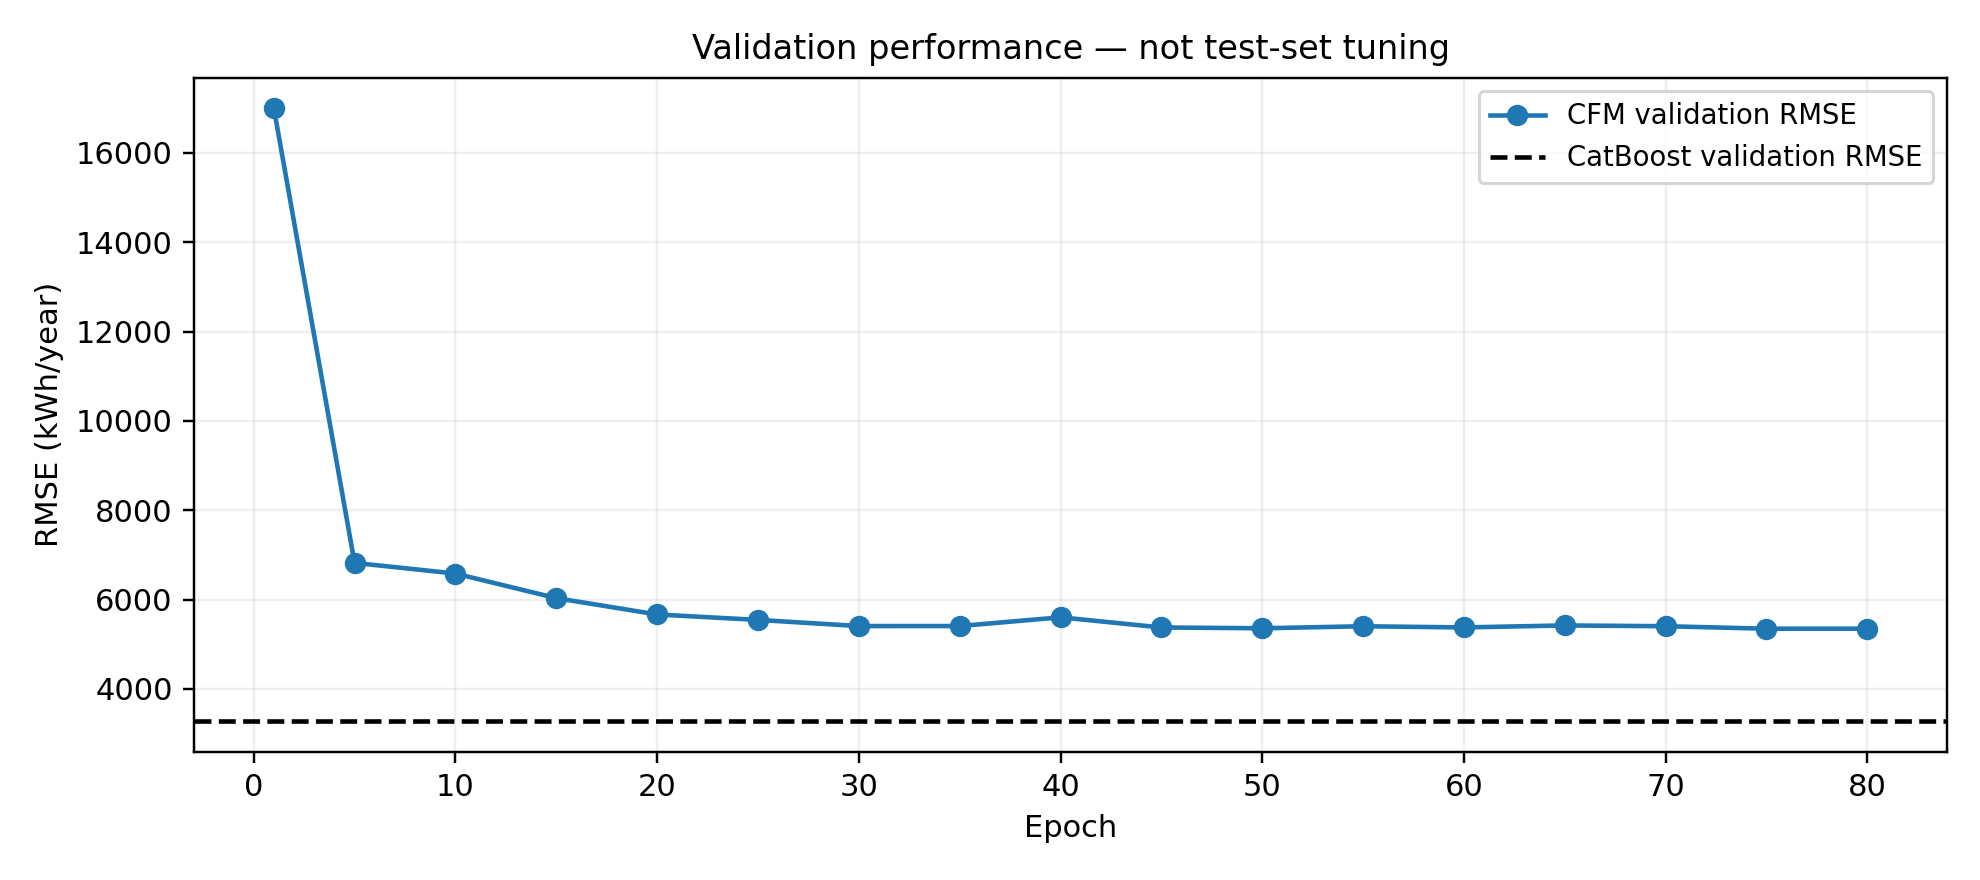

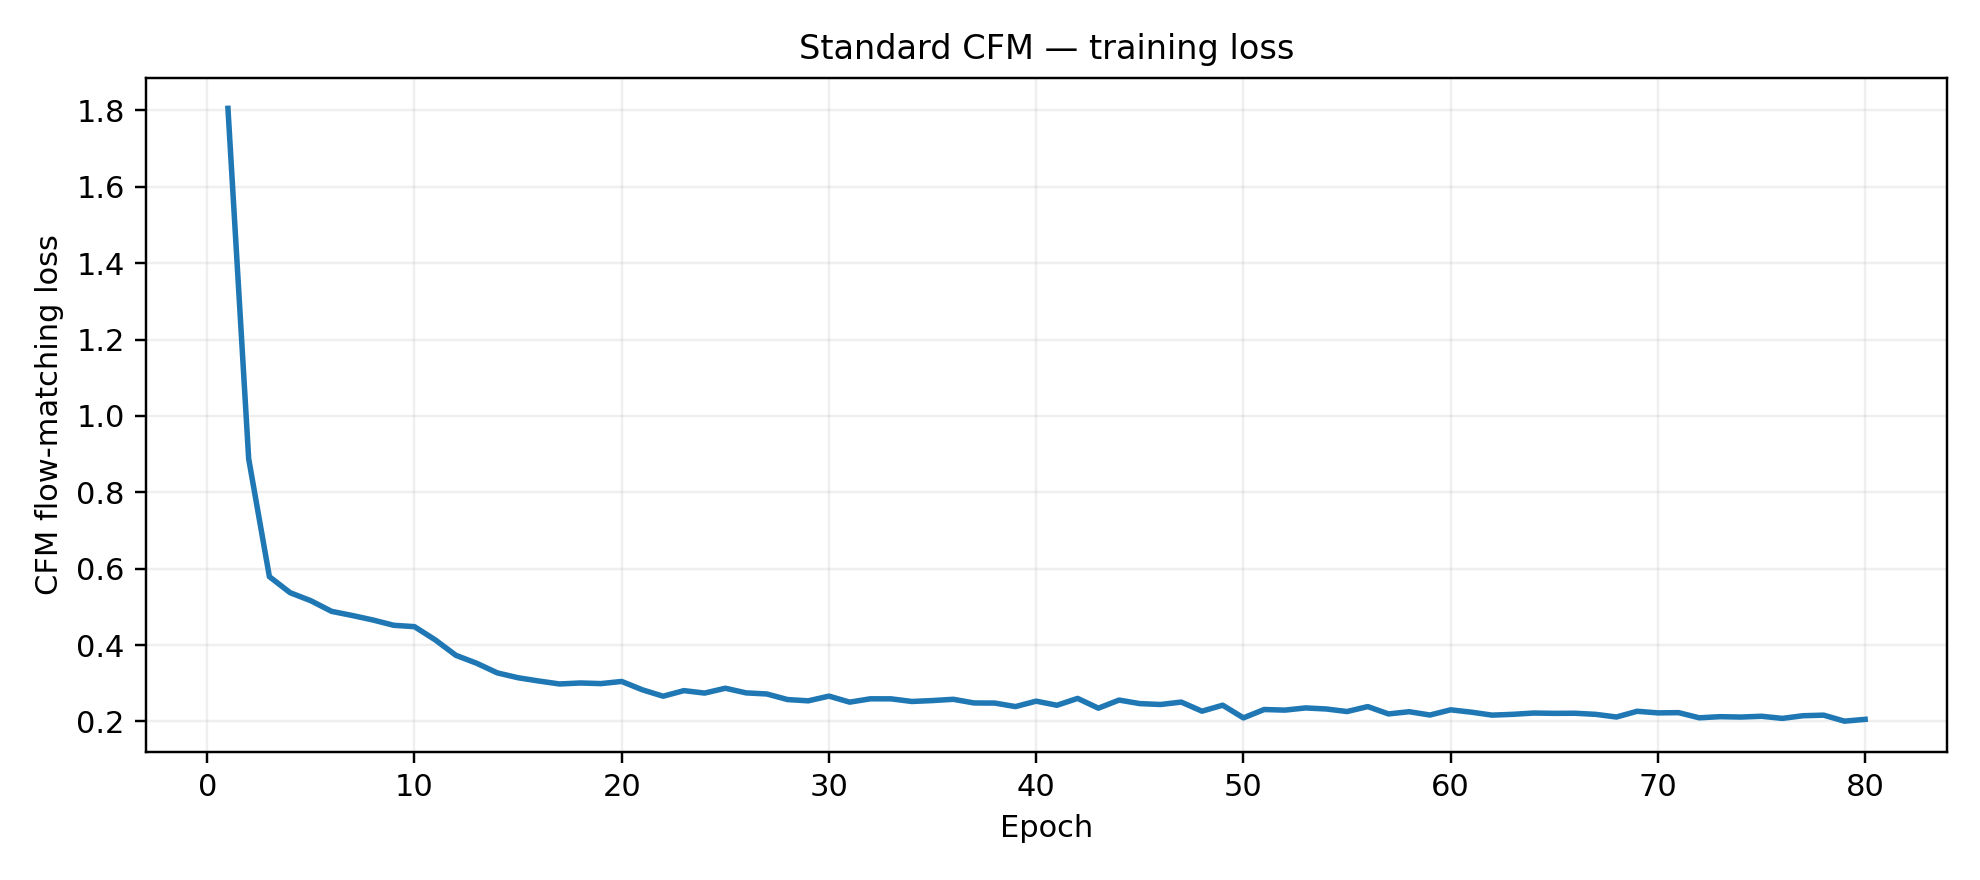

PHASE 4 VALIDATION COMPLETE: CFM best epoch 75
Prediction interval coverage (uncalibrated): 86.06%
All training and validation artifacts stored in: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip


In [22]:
import csv
assert (PHASE4_MODELS/'best.pt').is_file(), 'Run the Phase 4 training cell first.'
assert (PHASE4_DIR/'training_history.csv').exists(), 'Missing training history.'

import torch
# Reuse the architecture from the self-contained worker without executing worker.main().
namespace={'__name__':'phase4_reloaded'}
exec(compile(PHASE4_WORKER_SOURCE,str(PHASE4_WORKER),'exec'),namespace)
VelocityNet4=namespace['VelocityNet']
evaluate4=namespace['evaluate']
checkpoint=torch.load(PHASE4_MODELS/'best.pt',map_location='cpu',weights_only=False)
device4=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
model4=VelocityNet4(TRAIN_X.shape[1],CFM_CONFIG['hidden']).to(device4)
model4.load_state_dict(checkpoint['model'])
model4.eval()

# Fixed-seed evaluation; identical validation protocol as the trainer.
cfm_metrics=evaluate4(model4,VAL_X,VAL_Y_RAW,device4,
                      float(prep_metadata['log_train_mean']),
                      float(prep_metadata['log_train_std']),
                      CFM_CONFIG['val_draws'],CFM_CONFIG['ode_steps'],seed=314159)
cat_val=pd.read_csv(EVAL_CSV).set_index('Model').loc['CatBoost']
validation_comparison=pd.DataFrame([
    {'Model':'CatBoost','Validation RMSE (kWh/year)':float(cat_val['Val_RMSE_kWh_per_year']),
     'Validation MAE (kWh/year)':float(cat_val['Val_MAE_kWh_per_year']),
     'CRPS':'not available','90% coverage':'not available'},
    {'Model':'Standard CFM','Validation RMSE (kWh/year)':cfm_metrics['rmse'],
     'Validation MAE (kWh/year)':cfm_metrics['mae'],
     'CRPS':cfm_metrics['crps'],'90% coverage':cfm_metrics['coverage90']}
])
comparison_csv=PHASE4_DIR/'phase4_validation_comparison.csv'
metrics_json=PHASE4_DIR/'phase4_validation_metrics.json'
loss_png=PHASE4_DIR/'phase4_training_loss.png'
rmse_png=PHASE4_DIR/'phase4_validation_rmse.png'
validation_comparison.to_csv(comparison_csv,index=False)
atomic_json(metrics_json,{'target':'pEUI','units':'kWh/year','best_epoch':int(checkpoint['epoch'])+1,
                          'metrics':cfm_metrics,'selection':'validation RMSE only',
                          'intervals_are_calibrated':False,
                          'test_set_used':False})
hist4=pd.read_csv(PHASE4_DIR/'training_history.csv')
fig,ax=plt.subplots(figsize=(9,4));ax.plot(hist4['epoch'],hist4['train_loss'],lw=1.8)
ax.set(xlabel='Epoch',ylabel='CFM flow-matching loss',title='Standard CFM — training loss')
ax.grid(alpha=.2);fig.tight_layout();fig.savefig(loss_png,dpi=220);plt.close(fig)
fig,ax=plt.subplots(figsize=(9,4))
valid_rows=hist4.loc[hist4['rmse'].notna()]
ax.plot(valid_rows['epoch'],valid_rows['rmse'],marker='o',label='CFM validation RMSE')
ax.axhline(float(cat_val['Val_RMSE_kWh_per_year']),color='black',ls='--',label='CatBoost validation RMSE')
ax.set(xlabel='Epoch',ylabel='RMSE (kWh/year)',title='Validation performance — not test-set tuning')
ax.grid(alpha=.2);ax.legend();fig.tight_layout();fig.savefig(rmse_png,dpi=220);plt.close(fig)
score_fp=hashlib.sha256((sha256_file(PHASE4_MODELS/'best.pt')+sha256_file(SPLIT_NPZ)+
                         'phase4-val-report-v1').encode()).hexdigest()
if not stage_valid('phase4_validation_report',score_fp):
    record_stage('phase4_validation_report',score_fp,
                 [comparison_csv,metrics_json,loss_png,rmse_png],
                 details={'best_epoch':int(checkpoint['epoch'])+1,'test_not_touched':True})
display(validation_comparison)
display(Image(filename=str(rmse_png)))
display(Image(filename=str(loss_png)))
print('PHASE 4 VALIDATION COMPLETE: CFM best epoch',int(checkpoint['epoch'])+1)
print('Prediction interval coverage (uncalibrated):',f"{cfm_metrics['coverage90']*100:.2f}%")
print('All training and validation artifacts stored in:',ARCHIVE_PATH)

### 23. Generate standard-CFM diagnostic plots

Create plots from the model and validation predictions.

In [23]:
# Phase 4 figure suite: uses the frozen best *validation* checkpoint.
# No test samples are evaluated or plotted here.
assert (PHASE4_MODELS/'best.pt').exists(), 'CFM training missing: cannot export CFM figures.'
cfm_fig_fp=figure_fingerprint('cfm_validation',PHASE4_MODELS/'best.pt',
                            PHASE4_DIR/'training_history.csv',SPLIT_NPZ,EVAL_CSV)
cfm_history=pd.read_csv(PHASE4_DIR/'training_history.csv')
valid_hist=cfm_history.dropna(subset=['rmse']).copy()
assert len(valid_hist)>0, 'Validation trajectory absent.'

# J06 Flow loss (training) and no implied relationship to RMSE.
fig,ax=plt.subplots(figsize=(7.5,4.5),layout='constrained')
ax.plot(cfm_history['epoch'],cfm_history['train_loss'],linewidth=1.6)
ax.set(xlabel='Epoch',ylabel='Flow matching loss (scaled-target units)',title='Standard CFM training objective')
ax.grid(alpha=.2)
publish_figure('J06_cfm_training_loss','Standard CFM learning curve',
    'Training flow-matching objective by epoch (scaled target, unitless); do not interpret this objective as RMSE.',
    'training',fig,cfm_history[['epoch','train_loss']],cfm_fig_fp)

# J07 Full validation RMSE trajectory (baseline anchor).
cat_val_rmse=float(base_df.set_index('Model').loc['CatBoost','Val_RMSE_kWh_per_year'])
fig,ax=plt.subplots(figsize=(7.5,4.5),layout='constrained')
ax.plot(valid_hist['epoch'],valid_hist['rmse'],marker='o',markersize=3,label='Standard CFM')
ax.axhline(cat_val_rmse,linestyle='--',color='black',linewidth=1,label='CatBoost validation RMSE')
ax.set(xlabel='Epoch',ylabel='Validation RMSE (kWh/year)',title='CFM convergence versus CatBoost baseline')
ax.grid(alpha=.2);ax.legend(frameon=False)
publish_figure('J07_cfm_validation_rmse','Validation RMSE evolution',
    'Standard CFM validation RMSE across training alongside CatBoost validation RMSE. CFM checkpoint selection uses validation RMSE only.',
    'validation',fig,valid_hist[['epoch','rmse','mae','crps','coverage90','width90']],cfm_fig_fp)

# Deterministic validation samples from trained CFM with its documented sampler.
nsample=CFM_CONFIG['val_draws']
z_samples=namespace['sample_conditional'](model4,VAL_X,device4,nsample,CFM_CONFIG['ode_steps'],seed=314159)
y_samples=namespace['inverse_y'](z_samples,TARGET_MEAN,TARGET_SD)
assert y_samples.shape==(len(VAL_Y_RAW),nsample) and np.isfinite(y_samples).all()
mean_prediction=y_samples.mean(axis=1)
q05,q95=np.quantile(y_samples,[.05,.95],axis=1)
width90=q95-q05
inside=((VAL_Y_RAW>=q05)&(VAL_Y_RAW<=q95)).astype(int)
val_frame=pd.DataFrame({'sample_id':ID_VAL,'observed_energy':VAL_Y_RAW,
                        'mean_prediction':mean_prediction,'q05':q05,'q95':q95,
                        'width90':width90,'absolute_error':np.abs(VAL_Y_RAW-mean_prediction),
                        'covered90':inside})
# Every raw generative prediction used for uncertainty plots is saved for traceability.
cfm_sample_file=FIG_DIRS['plot_data']/'J08_J12_cfm_validation_draws.csv'
pd.DataFrame(y_samples,columns=[f'draw_{i+1:03d}' for i in range(nsample)]).assign(sample_id=ID_VAL).to_csv(cfm_sample_file,index=False)

# J08 validation expected point prediction.
lims=[min(VAL_Y_RAW.min(),mean_prediction.min()),max(VAL_Y_RAW.max(),mean_prediction.max())]
fig,ax=plt.subplots(figsize=(6.5,5.9),layout='constrained')
ax.scatter(VAL_Y_RAW,mean_prediction,s=9,alpha=.5,rasterized=True)
ax.plot(lims,lims,linestyle='--',linewidth=1,label='Perfect prediction')
ax.set(xlabel='Observed energy (kWh/year)',ylabel='Predicted mean energy (kWh/year)',
       title='Standard CFM: validation predictions')
ax.set_xlim(lims);ax.set_ylim(lims);ax.grid(alpha=.2);ax.legend(frameon=False)
publish_figure('J08_cfm_validation_actual_vs_predicted','CFM observed versus predicted',
    'Observed annual total site energy versus CFM predictive-sample mean, validation split only.',
    'validation',fig,val_frame,cfm_fig_fp)

# J09 nominal prediction interval reliability curve, including small-draw limitations.
levels=np.array([.50,.60,.70,.80,.90],dtype=float)
cov=[];midw=[]
for nominal in levels:
    lo,hi=np.quantile(y_samples,[(1-nominal)/2,1-(1-nominal)/2],axis=1)
    cov.append(np.mean((VAL_Y_RAW>=lo)&(VAL_Y_RAW<=hi)))
    midw.append(np.mean(hi-lo))
cal_df=pd.DataFrame({'nominal_coverage':levels,'observed_validation_coverage':cov,'mean_width_kWh_year':midw})
fig,ax=plt.subplots(figsize=(6.8,5.3),layout='constrained')
ax.plot(levels*100,np.array(cov)*100,marker='o',linewidth=1.8,label='Empirical CFM coverage')
ax.plot([45,95],[45,95],linestyle='--',color='black',linewidth=1,label='Ideal coverage')
ax.set(xlabel='Nominal central interval (%)',ylabel='Empirical coverage (%)',
       title='Uncalibrated CFM reliability — validation')
ax.set_xlim(45,95);ax.set_ylim(0,100);ax.grid(alpha=.2);ax.legend(frameon=False)
publish_figure('J09_cfm_interval_reliability','Uncalibrated interval reliability',
    f'Nominal versus empirical central interval coverage from {nsample} flow samples per building on validation data.',
    'validation',fig,cal_df,cfm_fig_fp,'Only 32 draws and no post-hoc calibration; sample quantiles are approximate.')

# J10 interval width vs magnitude, plotting all observations with training-data not used here.
fig,ax=plt.subplots(figsize=(7.5,4.7),layout='constrained')
ax.scatter(mean_prediction,width90,s=10,alpha=.45,rasterized=True)
ax.set(xlabel='Mean predicted annual energy (kWh/year)',ylabel='Uncalibrated 90% interval width (kWh/year)',
       title='Uncertainty sharpness versus predicted energy')
ax.grid(alpha=.2)
publish_figure('J10_cfm_interval_width','CFM interval width against predicted energy',
    'Width of each uncalibrated central 90% flow-sample interval versus the corresponding predictive mean on validation data.',
    'validation',fig,val_frame,cfm_fig_fp)

# J11 error/interval width relationship (NOT a calibration proof).
fig,ax=plt.subplots(figsize=(7.5,4.7),layout='constrained')
ax.scatter(width90,val_frame['absolute_error'],s=10,alpha=.45,rasterized=True)
ax.set(xlabel='Uncalibrated 90% interval width (kWh/year)',
       ylabel='Absolute point prediction error (kWh/year)',
       title='Does predicted uncertainty track prediction error?')
ax.grid(alpha=.2)
publish_figure('J11_cfm_error_vs_uncertainty','Relationship between uncertainty and error',
    'Absolute CFM validation point-prediction error against the width of its uncalibrated 90% predictive interval.',
    'validation',fig,val_frame,cfm_fig_fp,'Descriptive association, not a guarantee of valid OOD uncertainty.')

# J12 validation metrics CatBoost vs Standard CFM; no test CFM values supplied.
val_comp=validation_comparison[['Model','Validation RMSE (kWh/year)','Validation MAE (kWh/year)']]
fig,axes=plt.subplots(1,2,figsize=(9.8,4.4),layout='constrained')
for ax,key,txt in zip(axes,['Validation RMSE (kWh/year)','Validation MAE (kWh/year)'],['RMSE','MAE']):
    ax.bar(val_comp['Model'],val_comp[key]);ax.set(ylabel=f'{txt} (kWh/year)',title=f'Validation {txt}')
    ax.grid(axis='y',alpha=.2)
publish_figure('J12_validation_catboost_vs_cfm','Point prediction: CatBoost versus CFM',
    'Validation RMSE and MAE comparing CatBoost with Standard CFM. This does not compare predictive-distribution quality since CatBoost lacks distributional outputs.',
    'validation',fig,val_comp,cfm_fig_fp)

export_figure_package()
print('Phase 4 publication gallery: plots exported from real validation outputs, not test.')


Saved publication files: J06_cfm_training_loss
Saved publication files: J07_cfm_validation_rmse
Saved publication files: J08_cfm_validation_actual_vs_predicted
Saved publication files: J09_cfm_interval_reliability
Saved publication files: J10_cfm_interval_width
Saved publication files: J11_cfm_error_vs_uncertainty
Saved publication files: J12_validation_catboost_vs_cfm
JOURNAL FIGURE ARCHIVE: /kaggle/working/JOURNAL_FIGURES_LATEST.zip (11.6 MiB), figures=12
DO NOT DELETE the separate BUILDING_CFM_RESUME_LATEST.zip: it contains your trained model states.
Phase 4 publication gallery: plots exported from real validation outputs, not test.


### 24. Verify standard-CFM artifacts

Check completed model, validation and figure records.

In [24]:
assert 'phase4_standard_cfm_training' in manifest.get('stages',{}), 'Phase 4 training missing.'
assert 'phase4_validation_report' in manifest.get('stages',{}), 'Phase 4 validation missing.'
with zipfile.ZipFile(ARCHIVE_PATH) as z:
    assert z.testzip() is None, 'Corrupt resume archive'
    print('ZIP verified:',len(z.namelist()),'files,',round(ARCHIVE_PATH.stat().st_size/1048576,1),'MiB')
print('PHASE 4 RESEARCH DECISION: COMPLETE — standard CFM validation baseline')
print('Frozen target: annual total site energy (pEUI), kWh/year; Kaggle T4x2 optional.')
print('SAVE this archive:',ARCHIVE_PATH)

ZIP verified: 35 files, 60.1 MiB
PHASE 4 RESEARCH DECISION: COMPLETE — standard CFM validation baseline
Frozen target: annual total site energy (pEUI), kWh/year; Kaggle T4x2 optional.
SAVE this archive: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip


### 25. Check figure export package

Verify the saved figure archive and metadata.

In [25]:
# Final publication package verification (does not retrain or recompute models).
assert FIG_ZIP.is_file(), 'Figure ZIP was not generated.'
with zipfile.ZipFile(FIG_ZIP) as z:
    assert z.testzip() is None, 'Figure ZIP corrupted'
    print('Publication ZIP:',FIG_ZIP)
    print('Figures exported:',len(figure_index['figures']))
    print('Total archive members:',len(z.namelist()))
print('Training ZIP:',ARCHIVE_PATH)
print('Figure formats: 600 dpi PNG/TIFF, vector PDF/SVG (optional EPS), per-figure CSV and captions.')
print('Missing experiments listed in: future_figures_NOT_YET_PERFORMED.csv')


Publication ZIP: /kaggle/working/JOURNAL_FIGURES_LATEST.zip
Figures exported: 12
Total archive members: 66
Training ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Figure formats: 600 dpi PNG/TIFF, vector PDF/SVG (optional EPS), per-figure CSV and captions.
Missing experiments listed in: future_figures_NOT_YET_PERFORMED.csv


### 26. Set uncertainty benchmark partitions

Define the conformal and quantile calibration protocol.

In [26]:
# Phase 5 setup — frozen (old) model artifacts and transparent calibration partition.
import math
from sklearn.metrics import mean_absolute_error, mean_squared_error
from catboost import CatBoostRegressor

PHASE5_VERSION = 'phase5-probabilistic-quantile-conformal-v1'
PHASE5_DIR = OUTDIR / 'phase5_probabilistic_benchmarks'
PHASE5_MODELS = MODEL_DIR / 'phase5_quantile_catboost'
PHASE5_DIR.mkdir(parents=True,exist_ok=True)
PHASE5_MODELS.mkdir(parents=True,exist_ok=True)
assert stage_valid('phase4_validation_report', score_fp), 'Phase 4 has not completed.'
assert (PHASE3_MODELS/'CatBoost.joblib').is_file(), 'Missing saved CatBoost model.'
assert (PHASE4_MODELS/'best.pt').is_file(), 'Missing best CFM model.'

# The CFM checkpoint was selected with the FULL original validation set.
# Even after this diagnostic split, Phase 5 cannot serve as unbiased final validation.
CAL_RNG = np.random.default_rng(20261019)
_perm = CAL_RNG.permutation(len(VAL_X))
cal_idx = np.sort(_perm[:len(_perm)//2])
explore_idx = np.sort(_perm[len(_perm)//2:])
assert len(np.intersect1d(cal_idx,explore_idx)) == 0
assert len(cal_idx) == 900 and len(explore_idx) == 900

CB_QUANTILE_CONFIG = dict(iterations=850,depth=6,learning_rate=0.05,l2_leaf_reg=5,
                          random_seed=42,thread_count=4,verbose=False,
                          allow_writing_files=False)
PHASE5_FP = hashlib.sha256(json.dumps({
    'version':PHASE5_VERSION,
    'original_split':sha256_file(SPLIT_NPZ),
    'catboost_ref':sha256_file(PHASE3_MODELS/'CatBoost.joblib'),
    'cfm_ref':sha256_file(PHASE4_MODELS/'best.pt'),
    'quantile_model_config':CB_QUANTILE_CONFIG,
    'calibration_seed':20261019},sort_keys=True).encode()).hexdigest()
print('Phase 5 ready: 8,400 training, 900 calibration, 900 exploratory validation samples.')
print('No test samples loaded by Phase 5. Frozen CFM was previously selected on all validation samples.')


Phase 5 ready: 8,400 training, 900 calibration, 900 exploratory validation samples.
No test samples loaded by Phase 5. Frozen CFM was previously selected on all validation samples.


### 27. Train quantile baselines

Fit quantile benchmarks using training data only.

In [27]:
# Quantile models on TRAIN only. No calibration, evaluation or test targets enter training.
import joblib
quantile_models={}
quantile_stage_files=[]
for quantile, code in [(0.05,'q05'),(0.95,'q95')]:
    stage_name=f'phase5_catboost_{code}'
    fingerprint=hashlib.sha256((PHASE5_FP+code).encode()).hexdigest()
    model_file=PHASE5_MODELS/f'CatBoost_{code}.cbm'
    if stage_valid(stage_name,fingerprint):
        print('RESTORE quantile model',code)
        model=CatBoostRegressor()
        model.load_model(str(model_file))
    else:
        print('TRAIN quantile model',code,'on CPU')
        model=CatBoostRegressor(**CB_QUANTILE_CONFIG,loss_function=f'Quantile:alpha={quantile}')
        model.fit(TRAIN_X,TRAIN_Y_RAW)
        temp_model=model_file.with_name(model_file.stem+'.tmp.cbm')
        model.save_model(str(temp_model))
        os.replace(temp_model,model_file)
        record_stage(stage_name,fingerprint,[model_file],details={'quantile':quantile,'train_only':True})
    quantile_models[code]=model
    quantile_stage_files.append(model_file)
print('Quantile checkpoints ready:',*[p.name for p in quantile_stage_files])


TRAIN quantile model q05 on CPU
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (60.5 MB)
TRAIN quantile model q95 on CPU
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (60.9 MB)
Quantile checkpoints ready: CatBoost_q05.cbm CatBoost_q95.cbm


### 28. Evaluate predictive uncertainty

Compare interval coverage and scores with saved model predictions.

In [28]:
# Phase 5 comparison — full results are cached; no previous baseline retraining.
P5_PRED=PHASE5_DIR/'phase5_exploratory_predictions.csv'
P5_RESULTS=PHASE5_DIR/'phase5_exploratory_scores.csv'
P5_META=PHASE5_DIR/'phase5_metadata.json'

# Exact finite-sample split-conformal quantile (upper order statistic).
def finite_sample_conformal_quantile(scores, alpha=0.1):
    arr=np.sort(np.asarray(scores,dtype=float).reshape(-1))
    n=len(arr)
    k=math.ceil((n+1)*(1-alpha))
    return float(arr[min(k,n)-1]) if k <= n else float('inf')

def interval_score(y,lo,hi,alpha=0.10):
    y,lo,hi=map(lambda a: np.asarray(a,dtype=float),(y,lo,hi))
    return (hi-lo)+(2/alpha)*np.maximum(lo-y,0)+(2/alpha)*np.maximum(y-hi,0)

if stage_valid('phase5_exploratory_comparison',PHASE5_FP):
    print('RESTORE completed Phase 5 comparison; no CFM resampling needed.')
    phase5_preds=pd.read_csv(P5_PRED)
    phase5_scores=pd.read_csv(P5_RESULTS)
else:
    point=joblib.load(PHASE3_MODELS/'CatBoost.joblib')
    val_cb=to_raw_energy(point.predict(VAL_X))
    lo_q=quantile_models['q05'].predict(VAL_X).astype(float)
    hi_q=quantile_models['q95'].predict(VAL_X).astype(float)
    lo_q,hi_q=np.minimum(lo_q,hi_q),np.maximum(lo_q,hi_q)

    y_cal=VAL_Y_RAW[cal_idx];y_eval=VAL_Y_RAW[explore_idx]
    cb_cal=val_cb[cal_idx];cb_eval=val_cb[explore_idx]
    point_gap=finite_sample_conformal_quantile(np.abs(y_cal-cb_cal))
    q_gap=finite_sample_conformal_quantile(np.maximum(lo_q[cal_idx]-y_cal,y_cal-hi_q[cal_idx]))
    # Nonnegative adjustment produces weakly more conservative intervals if CQR q is negative.
    q_gap=max(0.,q_gap)

    # Sample existing trained CFM, WITHOUT re-training it.
    cfm_draws=namespace['sample_conditional'](model4,VAL_X,device4,
                  CFM_CONFIG['val_draws'],CFM_CONFIG['ode_steps'],seed=271828)
    cfm_y=namespace['inverse_y'](cfm_draws,TARGET_MEAN,TARGET_SD)
    cfm_mean=cfm_y.mean(axis=1)
    cfm_lo,cfm_hi=np.quantile(cfm_y,[.05,.95],axis=1)
    cfm_gap=max(0.,finite_sample_conformal_quantile(
        np.maximum(cfm_lo[cal_idx]-y_cal,y_cal-cfm_hi[cal_idx])))

    records=[]
    methods={
        'CatBoost + split conformal': (cb_eval,cb_eval-point_gap,cb_eval+point_gap),
        'CatBoost quantiles + CQR':(cb_eval,lo_q[explore_idx]-q_gap,hi_q[explore_idx]+q_gap),
        'Standard CFM (uncalibrated)':(cfm_mean[explore_idx],cfm_lo[explore_idx],cfm_hi[explore_idx]),
        'Standard CFM + conformal':(cfm_mean[explore_idx],cfm_lo[explore_idx]-cfm_gap,cfm_hi[explore_idx]+cfm_gap),
    }
    phase5_preds=pd.DataFrame({'source_validation_id':ID_VAL[explore_idx],
                               'observed_kWh_year':y_eval})
    for name,(mean,lower,upper) in methods.items():
        assert (lower<=upper).all(),f'Invalid interval from {name}'
        assert all(np.isfinite(a).all() for a in (mean,lower,upper))
        key={'CatBoost + split conformal':'CatBoost_Conformal',
             'CatBoost quantiles + CQR':'CatBoost_CQR',
             'Standard CFM (uncalibrated)':'CFM_Raw',
             'Standard CFM + conformal':'CFM_Conformal'}[name]
        phase5_preds[key+'_prediction']=mean
        phase5_preds[key+'_lower']=lower
        phase5_preds[key+'_upper']=upper
        records.append({'Method':name,'RMSE_kWh_year':float(np.sqrt(np.mean((y_eval-mean)**2))),
            'MAE_kWh_year':float(np.mean(np.abs(y_eval-mean))),
            'Coverage90':float(np.mean((y_eval>=lower)&(y_eval<=upper))),
            'MeanWidth90_kWh_year':float(np.mean(upper-lower)),
            'IntervalScore90_kWh_year':float(np.mean(interval_score(y_eval,lower,upper))),
            'Sample_count':int(len(y_eval))})
    phase5_scores=pd.DataFrame(records).sort_values('IntervalScore90_kWh_year')
    phase5_preds.to_csv(P5_PRED,index=False)
    phase5_scores.to_csv(P5_RESULTS,index=False)
    atomic_json(P5_META,{'phase':5,'scientific_status':'EXPLORATORY ONLY',
         'target':'pEUI','target_units':'kWh/year','single_climate':'Cairo',
         'validation_previously_used_for_CFM_model_selection':True,
         'conformal_guarantee_not_asserted_for_CFM':True,
         'split_seed':20261019,'calibration_count':int(len(cal_idx)),
         'exploration_count':int(len(explore_idx)),
         'model_selection_used_heldout_test':False,
         'conformal_adjustments_kWh_year':{'catboost_point':point_gap,
                   'catboost_quantile':q_gap,'cfm_samples':cfm_gap},
         'monte_carlo_draws':CFM_CONFIG['val_draws']})
    record_stage('phase5_exploratory_comparison',PHASE5_FP,
                 [P5_PRED,P5_RESULTS,P5_META],
                 details={'quantile_models':2,'test_used':False,'publication_evidence':False})

display(phase5_scores.round(4))
print('PHASE 5 DIAGNOSTIC COMPLETE — validation-selected CFM; NOT an independent test.')


Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (61.0 MB)


,Method,RMSE_kWh_year,MAE_kWh_year,Coverage90,MeanWidth90_kWh_year,IntervalScore90_kWh_year,Sample_count
0,CatBoost + split conformal,2761.4021,1397.0705,0.9311,6532.2181,12087.6413,900
1,CatBoost quantiles + CQR,2761.4021,1397.0705,0.9144,10929.2211,15108.7009,900
3,Standard CFM + conformal,5323.1309,2189.7521,0.9111,9400.3709,16783.8163,900
2,Standard CFM (uncalibrated),5323.1309,2189.7521,0.8611,8598.7395,16886.4426,900


PHASE 5 DIAGNOSTIC COMPLETE — validation-selected CFM; NOT an independent test.


### 29. Export uncertainty diagnostics

Create and archive Phase 5 uncertainty plots.

In [29]:
# Add publication-quality diagnostic figures without touching the completed 12 figures.
P5_FIG_FP=figure_fingerprint('phase5_probabilistic_diagnostic',P5_RESULTS,P5_PRED,P5_META)

fig,ax=plt.subplots(figsize=(8.5,4.8),layout='constrained')
methods=list(phase5_scores['Method'])
pos=np.arange(len(methods));cov=phase5_scores['Coverage90'].to_numpy()*100
ax.bar(pos,cov,width=0.65)
ax.axhline(90,color='black',ls='--',label='Nominal 90%')
ax.set(xticks=pos,xticklabels=methods,ylabel='Empirical 90% interval coverage (%)',
       title='Exploratory validation-based interval coverage')
ax.tick_params(axis='x',rotation=20);ax.legend(frameon=False);ax.grid(axis='y',alpha=.2)
publish_figure('J13_exploratory_interval_coverage','Interval coverage comparison',
    'Observed coverage of nominal 90% intervals on an exploratory subset of the previously used validation data. Not independent publication evidence.',
    'validation_exploratory',fig,phase5_scores,P5_FIG_FP,
    'The standard CFM checkpoint was selected using this original validation set; conformal guarantee is not claimed.')

fig,ax=plt.subplots(figsize=(8.5,4.8),layout='constrained')
ax.bar(pos,phase5_scores['IntervalScore90_kWh_year'])
ax.set(xticks=pos,xticklabels=methods,ylabel='Mean 90% interval score (kWh/year)',
       title='Exploratory interval quality (lower is better)')
ax.tick_params(axis='x',rotation=20);ax.grid(axis='y',alpha=.2)
publish_figure('J14_exploratory_interval_score','Interval score comparison',
    'Mean central 90% interval score for conformal CatBoost, CQR and standard CFM variants. All on a reused validation partition.',
    'validation_exploratory',fig,phase5_scores,P5_FIG_FP,
    'Not a fresh held-out test; use for protocol design, not a claimed generalization improvement.')

fig,ax=plt.subplots(figsize=(7.2,5),layout='constrained')
for name,col in [('CatBoost CQR','CatBoost_CQR'),('CFM uncalibrated','CFM_Raw'),
                 ('CFM conformal','CFM_Conformal')]:
    wd=(phase5_preds[col+'_upper']-phase5_preds[col+'_lower'])
    ax.plot(np.sort(wd),np.linspace(0,1,len(wd)),label=name)
ax.set(xlabel='90% interval width (kWh/year)',ylabel='Empirical CDF',
       title='Exploratory prediction interval width distributions')
ax.legend(frameon=False);ax.grid(alpha=.2)
publish_figure('J15_exploratory_interval_width_distributions','Interval width distributions',
    'Cumulative distributions of interval widths for three predictive methods on previously reused validation samples.',
    'validation_exploratory',fig,phase5_preds,P5_FIG_FP,
    'Different interval widths are not evidence of coverage validity without independent evaluation.')

export_figure_package()
assert FIG_ZIP.is_file()
with zipfile.ZipFile(FIG_ZIP) as archive:
    assert archive.testzip() is None
print('PHASE 5 FIGURE EXPORT COMPLETE:',FIG_ZIP)
print('Number of figure entries:',len(figure_index['figures']))


Saved publication files: J13_exploratory_interval_coverage
Saved publication files: J14_exploratory_interval_score
Saved publication files: J15_exploratory_interval_width_distributions
JOURNAL FIGURE ARCHIVE: /kaggle/working/JOURNAL_FIGURES_LATEST.zip (14.0 MiB), figures=15
DO NOT DELETE the separate BUILDING_CFM_RESUME_LATEST.zip: it contains your trained model states.
PHASE 5 FIGURE EXPORT COMPLETE: /kaggle/working/JOURNAL_FIGURES_LATEST.zip
Number of figure entries: 15


### 30. Verify uncertainty results

Validate Phase 5 results and their archived evidence.

In [30]:
# Phase 5 archival gate and honest readiness statement.
assert stage_valid('phase5_exploratory_comparison',PHASE5_FP)
assert stage_valid('phase5_catboost_q05',hashlib.sha256((PHASE5_FP+'q05').encode()).hexdigest())
assert stage_valid('phase5_catboost_q95',hashlib.sha256((PHASE5_FP+'q95').encode()).hexdigest())
write_resume_archive()
with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    assert archive.testzip() is None
print('PHASE 5 DECISION: COMPLETE — probabilistic comparators and diagnostic figures')
print('DO NOT CLAIM Q1-READY EXTERNAL GENERALIZATION YET.')
print('Required next: fresh grouped/independent test; proper validation selection; multiple seeds; shift robustness.')
print('Training resume ZIP:',ARCHIVE_PATH)
print('Publication figure ZIP:',FIG_ZIP)


Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (61.0 MB)
PHASE 5 DECISION: COMPLETE — probabilistic comparators and diagnostic figures
DO NOT CLAIM Q1-READY EXTERNAL GENERALIZATION YET.
Required next: fresh grouped/independent test; proper validation selection; multiple seeds; shift robustness.
Training resume ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Publication figure ZIP: /kaggle/working/JOURNAL_FIGURES_LATEST.zip


### 31. Check the active experiment state

Verify required Phase 5 files before residual CFM.

In [31]:

# Phase 6.0: validate the active Phase 5 session (no retraining)
from pathlib import Path
import os, io, sys, zipfile, tempfile, shutil, json, hashlib
import pandas as pd
import numpy as np

required_names = [
    "STATE_ROOT", "WORKDIR", "ARCHIVE_PATH",
    "manifest", "record_stage", "write_resume_archive",
    "stage_valid", "FIG_ROOT", "figure_index",
    "TRAIN_X", "VAL_X", "SPLIT_NPZ",
    "OUTDIR", "MODEL_DIR"
]

missing = [k for k in required_names if k not in globals()]

assert not missing, (
    f"Run the Phase 5 setup cells first. Missing: {missing}"
)
assert Path(SPLIT_NPZ).exists(), "Phase 2 splits not restored"
assert "phase5_exploratory_comparison" in manifest.get(
    "stages", {}
), "Phase 5 must be finished"
assert Path(STATE_ROOT).is_dir()

print("Phase 5 runtime ready.")
print("Working state:", STATE_ROOT)
print("Old figure location:", FIG_ROOT)
print("Available figures:", len(figure_index.get("figures", {})))


Phase 5 runtime ready.
Working state: /kaggle/working/BUILDING_CFM_STATE
Old figure location: /kaggle/working/JOURNAL_FIGURES
Available figures: 15


### 32. Merge saved figure records

Consolidate existing experiment figures and metadata.

In [32]:

# Phase 6.1 — Merge existing figures into master state
import re

old_fig_root = Path(FIG_ROOT)
unified_fig_root = Path(STATE_ROOT) / "journal_figures"
unified_fig_root.mkdir(parents=True, exist_ok=True)

def _valid_gallery(root):
    root = Path(root)
    try:
        index = json.loads(
            (root / "figure_index.json").read_text(encoding="utf-8")
        )
    except (OSError, ValueError):
        return None

    if (
        not isinstance(index.get("figures"), dict)
        or index.get("version") != FIG_VERSION
    ):
        return None

    for figure_id, meta in index["figures"].items():
        if not re.fullmatch(r"J\d\d_[a-z0-9_]+", figure_id):
            return None

        for item in meta.get("files", []):
            rel = Path(item)
            if not rel.parts or rel.is_absolute() or ".." in rel.parts:
                return None
            candidate = root / rel
            if not candidate.is_file() or candidate.is_symlink():
                return None
    return index

with tempfile.TemporaryDirectory(
    prefix="cfm_unified_figures_", dir=str(WORKDIR)
) as tmp:
    temporary = Path(tmp)
    candidates = [unified_fig_root, old_fig_root]

    for root in [Path(WORKDIR), Path("/kaggle/input")]:
        if not root.exists():
            continue

        candidates.extend(
            index.parent for index in root.rglob("figure_index.json")
        )

        for j, archive_file in enumerate(
            root.rglob("JOURNAL_FIGURES_LATEST.zip")
        ):
            destination = temporary / f"unpacked_{len(candidates)}_{j}"

            try:
                with zipfile.ZipFile(archive_file) as z:
                    assert z.testzip() is None

                    for member in z.infolist():
                        rel = Path(member.filename)

                        if (
                            not rel.parts
                            or rel.parts[0] != "JOURNAL_FIGURES"
                            or ".." in rel.parts
                            or rel.is_absolute()
                            or ((member.external_attr >> 16) & 0o170000)
                            == 0o120000
                        ):
                            raise ValueError("Unsafe figure archive member")

                        target = destination / rel

                        if member.is_dir():
                            target.mkdir(parents=True, exist_ok=True)
                        else:
                            target.parent.mkdir(
                                parents=True, exist_ok=True
                            )
                            with z.open(member) as src, open(target, "wb") as dst:
                                shutil.copyfileobj(src, dst)

                candidates.append(destination / "JOURNAL_FIGURES")

            except (
                ValueError, AssertionError, zipfile.BadZipFile
            ) as exc:
                print("Ignored invalid ZIP:", archive_file, exc)

    baseline = _valid_gallery(unified_fig_root)
    baseline_ids = set(baseline["figures"]) if baseline else set()
    best_root, best_index = unified_fig_root, baseline

    for candidate in candidates:
        idx = _valid_gallery(candidate)
        if idx is None:
            continue

        candidate_ids = set(idx["figures"])

        if (
            baseline_ids.issubset(candidate_ids)
            and len(candidate_ids) >
            (len(best_index["figures"]) if best_index else 0)
        ):
            best_root, best_index = candidate, idx

    if best_index is None:
        raise RuntimeError(
            "No complete gallery found. Check the Figures Dataset."
        )

    if best_root.resolve() != unified_fig_root.resolve():
        for src in best_root.rglob("*"):
            if src.is_file():
                rel = src.relative_to(best_root)
                dst = unified_fig_root / rel
                dst.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(src, dst)

    print("Source gallery:", best_root)

# Redirect existing figure-export functions to the unified state.
FIG_ROOT = unified_fig_root
FIG_INDEX = FIG_ROOT / "figure_index.json"

FIG_DIRS = {
    key: FIG_ROOT / key
    for key in (
        "600dpi_png", "600dpi_tiff",
        "vector_pdf", "vector_svg",
        "vector_eps", "plot_data"
    )
}

for folder in FIG_DIRS.values():
    folder.mkdir(parents=True, exist_ok=True)

FIG_ZIP = ARCHIVE_PATH

figure_index = json.loads(
    FIG_INDEX.read_text(encoding="utf-8")
)

assert _valid_gallery(FIG_ROOT) is not None
assert len(figure_index["figures"]) >= 15, (
    "Expected 15 Phase 5 figures. Check attached dataset."
)

print("Imported figures:", len(figure_index["figures"]))
print("New figure directory:", FIG_ROOT)


Source gallery: /kaggle/working/JOURNAL_FIGURES
Imported figures: 15
New figure directory: /kaggle/working/BUILDING_CFM_STATE/journal_figures


### 33. Register archive utilities

Create unified checkpoint and figure export helpers.

In [33]:

# Phase 6.2 — Unified checkpoint and figure exporter

def export_figure_package():
    """Update figure metadata and create ONE master resume ZIP."""

    rows = []
    captions = [
        "# Journal figure captions (draft)",
        "",
        "Target: annual total site energy (pEUI), kWh/year.",
        "Validation-exploratory is NOT independent testing.",
        ""
    ]

    for fid, item in sorted(figure_index["figures"].items()):
        captions += [
            f"### {fid}: {item['title']}",
            item["caption"],
            ""
        ]

        if item.get("caveat"):
            captions += [
                "**Limitation:** " + item["caveat"],
                ""
            ]

        rows.append({
            "Figure": fid,
            "Title": item["title"],
            "Data_split": item["data_split"],
            "Source_CSV": item.get("source_data", ""),
            "Interpretation_limit": item.get("caveat", "")
        })

    pd.DataFrame(rows).to_csv(
        FIG_ROOT / "figure_inventory.csv", index=False
    )

    (FIG_ROOT / "figure_captions.md").write_text(
        "\n".join(captions), encoding="utf-8"
    )

    (FIG_ROOT / "README.txt").write_text(
        "All research figures are stored inside\n"
        "BUILDING_CFM_STATE/journal_figures.\n"
        "PNG/TIFF 600 dpi, PDF/SVG and source CSV are included.\n"
        "Exploratory validation is not independent test evidence.\n",
        encoding="utf-8"
    )

    gallery_files = [
        p for p in FIG_ROOT.rglob("*") if p.is_file()
    ]

    figure_signature = hashlib.sha256(
        json.dumps(
            {
                "version": FIG_VERSION,
                "figures": figure_index["figures"]
            },
            sort_keys=True
        ).encode()
    ).hexdigest()

    record_stage(
        "journal_figures_gallery",
        figure_signature,
        gallery_files,
        archive=False,
        details={
            "count": len(rows),
            "unified_zip": True
        }
    )

    write_resume_archive()

    with zipfile.ZipFile(ARCHIVE_PATH) as z:
        assert z.testzip() is None, "ZIP integrity error"
        names = set(z.namelist())

        missing = [
            f"BUILDING_CFM_STATE/{p.relative_to(STATE_ROOT).as_posix()}"
            for p in gallery_files
            if f"BUILDING_CFM_STATE/{p.relative_to(STATE_ROOT).as_posix()}"
            not in names
        ]

        assert not missing, f"Missing figure files: {missing[:5]}"

    print("ONE ZIP READY:", ARCHIVE_PATH)
    print("Saved figures:", len(rows))
    print("Saved figure files:", len(gallery_files))
    print(
        "ZIP size:",
        round(ARCHIVE_PATH.stat().st_size / 1024**2, 1),
        "MiB"
    )

# Run the export and verify the unified backup.
export_figure_package()


Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (75.0 MB)
ONE ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Saved figures: 15
Saved figure files: 81
ZIP size: 75.0 MiB


### 34. Configure residual CFM

Fix the residual-model experimental protocol.

In [35]:

# Phase 6.3 — New research experiment configuration

import math, time
from sklearn.model_selection import GroupKFold
from catboost import CatBoostRegressor
import joblib

P6_NAME = "phase6_oof_residual_cfm"

P6_DIR = OUTDIR / P6_NAME
P6_MODELS = MODEL_DIR / P6_NAME

P6_DIR.mkdir(parents=True, exist_ok=True)
P6_MODELS.mkdir(parents=True, exist_ok=True)

P6_CONFIG = {
    "folds": 5,
    "fold_seed": 42026,
    "epochs": 80,
    "batch_per_gpu": 256,
    "hidden": 128,
    "learning_rate": 0.001,
    "seed": 2042,
    "archive_every": 1,
    "draws": 64,
    "ode_steps": 32,
    "use_two_gpus": True
}

P6_NPZ = P6_DIR / "phase6_oof_residual_training.npz"
P6_META = P6_DIR / "phase6_oof_residual_metadata.json"
P6_OOF = P6_DIR / "phase6_oof_predictions.csv"

P6_FP = hashlib.sha256(
    json.dumps({
        "version": "phase6-oof-residual-v1",
        "config": P6_CONFIG,
        "phase2_file": sha256_file(SPLIT_NPZ),
        "catboost_config": BASELINE_CONFIGS["CatBoost"]
    }, sort_keys=True).encode()
).hexdigest()

assert stage_valid(
    "phase5_exploratory_comparison", PHASE5_FP
)

assert (
    PHASE3_MODELS / "CatBoost.joblib"
).is_file(), "CatBoost model missing"

assert (
    STATE_ROOT / "scripts" / "cfm_ddp_worker.py"
).is_file(), "CFM worker missing"

assert len(TRAIN_X) == 8400
assert len(VAL_X) == 1800

print("Phase 6 experiment ready:", P6_NAME)
print("Training samples:", len(TRAIN_X))
print("Validation samples:", len(VAL_X))
print("Journal figures:", FIG_ROOT)


Phase 6 experiment ready: phase6_oof_residual_cfm
Training samples: 8400
Validation samples: 1800
Journal figures: /kaggle/working/BUILDING_CFM_STATE/journal_figures


### 35. Prepare out-of-fold residuals

Generate training-only out-of-fold residual targets.

In [36]:

# Phase 6.4 — Generate out-of-fold residual training data

if stage_valid("phase6_oof_dataset", P6_FP):

    print("RESTORED existing OOF residual dataset.")
    p6_meta = json.loads(P6_META.read_text())

else:
    source = pd.read_excel(
        ALT_PATH, sheet_name="Sheet1", engine="openpyxl"
    )

    assert len(source) == 12000
    assert all(
        c in source for c in [
            "Length", "Depth", "Height", "pEUI"
        ]
    )

    geometry = (
        source.iloc[ID_TRAIN][["Length", "Depth", "Height"]]
        .round(5)
        .astype(str)
        .agg("|".join, axis=1)
    )

    n_groups = geometry.nunique()
    assert n_groups >= 5

    fold_iter = GroupKFold(n_splits=5).split(
        TRAIN_X, TRAIN_Y_SCALED, groups=geometry
    )

    oof = np.full(
        len(TRAIN_X), np.nan, dtype=np.float64
    )

    fold_paths = []
    fold_summary = []

    for fold, (fit_idx, out_idx) in enumerate(
        fold_iter, start=1
    ):
        model_path = (
            P6_MODELS / f"oof_catboost_fold_{fold}.cbm"
        )
        meta_path = (
            P6_MODELS / f"oof_catboost_fold_{fold}.json"
        )

        if (
            model_path.is_file()
            and meta_path.is_file()
            and json.loads(meta_path.read_text()).get(
                "fingerprint"
            ) == P6_FP
        ):
            model = CatBoostRegressor(
                **BASELINE_CONFIGS["CatBoost"]
            )
            model.load_model(str(model_path))

            print(f"RESTORED Fold {fold}/5")

        else:
            print(
                f"TRAINING Fold {fold}/5:",
                len(fit_idx), "samples"
            )

            model = CatBoostRegressor(
                **BASELINE_CONFIGS["CatBoost"]
            )

            model.fit(
                TRAIN_X[fit_idx],
                TRAIN_Y_SCALED[fit_idx]
            )

            temporary_model = model_path.with_suffix(
                ".tmp.cbm"
            )

            model.save_model(str(temporary_model))
            os.replace(temporary_model, model_path)

            atomic_json(meta_path, {
                "fingerprint": P6_FP,
                "fold": fold,
                "training_rows": len(fit_idx),
                "oof_rows": len(out_idx)
            })

            # Save all research state + figures after every fold.
            write_resume_archive()

        prediction = np.asarray(
            model.predict(TRAIN_X[out_idx])
        ).reshape(-1)

        oof[out_idx] = prediction

        fold_paths.extend([model_path, meta_path])

        fold_summary.append({
            "fold": fold,
            "rmse_scaled": float(
                np.sqrt(np.mean(
                    (
                        TRAIN_Y_SCALED[out_idx]
                        - prediction
                    ) ** 2
                ))
            )
        })

    assert np.isfinite(oof).all()

    residual = (
        TRAIN_Y_SCALED.astype(np.float64) - oof
    )

    r_mean = float(residual.mean())
    r_std = float(residual.std())

    assert np.isfinite(r_std) and r_std > 1e-8

    fitted_catboost = joblib.load(
        PHASE3_MODELS / "CatBoost.joblib"
    )

    base_val = np.asarray(
        fitted_catboost.predict(VAL_X),
        dtype=np.float32
    ).reshape(-1)

    np.savez_compressed(
        P6_NPZ,
        x_train=np.column_stack(
            (TRAIN_X, oof)
        ).astype(np.float32),

        y_train=(
            (residual - r_mean) / r_std
        ).astype(np.float32).reshape(-1, 1),

        x_val=np.column_stack(
            (VAL_X, base_val)
        ).astype(np.float32),

        y_val=(
            (
                VAL_Y_SCALED
                - base_val
                - r_mean
            ) / r_std
        ).astype(np.float32).reshape(-1, 1),

        base_val_scaled=base_val,
        raw_y_val=VAL_Y_RAW.astype(np.float32),
        oof_base_scaled=oof.astype(np.float32)
    )

    pd.DataFrame({
        "source_id": ID_TRAIN,
        "oof_prediction_scaled": oof,
        "observed_scaled": TRAIN_Y_SCALED,
        "oof_residual_scaled": residual
    }).to_csv(P6_OOF, index=False)

    p6_meta = {
        "fold_scheme": "GroupKFold_Length_Depth_Height",
        "geometry_groups": int(n_groups),
        "folds": fold_summary,
        "oof_residual_mean": r_mean,
        "oof_residual_std": r_std,
        "input_features": int(TRAIN_X.shape[1] + 1),
        "limitations": [
            "Preprocessing was fitted on the original full training split",
            "Validation was previously used for model selection",
            "Independent grouped testing is still pending"
        ]
    }

    atomic_json(P6_META, p6_meta)

    record_stage(
        "phase6_oof_dataset",
        P6_FP,
        [P6_NPZ, P6_OOF, P6_META, *fold_paths],
        details={
            "training_rows": len(TRAIN_X),
            "geometry_groups": int(n_groups)
        }
    )

assert stage_valid("phase6_oof_dataset", P6_FP)

print("OOF DATASET COMPLETE")
print("Geometry groups:", p6_meta["geometry_groups"])
print("Resume State:", ARCHIVE_PATH)


TRAINING Fold 1/5: 6720 samples
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (75.5 MB)
TRAINING Fold 2/5: 6720 samples
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (75.9 MB)
TRAINING Fold 3/5: 6720 samples
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (76.3 MB)
TRAINING Fold 4/5: 6720 samples
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (76.8 MB)
TRAINING Fold 5/5: 6720 samples
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (77.2 MB)
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (78.0 MB)
OOF DATASET COMPLETE
Geometry groups: 8400
Resume State: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip


### 36. Train residual CFM

Fit the residual conditional flow-matching model.

In [37]:

# ============================================================
# PHASE 6.2 — RESIDUAL CFM TRAINING
# Dual T4 GPU | Auto-Resume | Unified ZIP | Journal Figures
# ============================================================

import os
import sys
import json
import hashlib
import subprocess
import zipfile
from pathlib import Path

import numpy as np
import torch

print("=" * 65)
print("PHASE 6.2 — RESIDUAL CONDITIONAL FLOW MATCHING")
print("=" * 65)

# ------------------------------------------------------------
# STEP 1 — Verify previous phase and training dataset
# ------------------------------------------------------------

assert stage_valid("phase6_oof_dataset", P6_FP), (
    "Phase 6 OOF dataset not found."
)

assert Path(P6_NPZ).is_file()
assert Path(P6_META).is_file()

with np.load(P6_NPZ, allow_pickle=False) as data:
    assert len(data["x_train"]) == len(TRAIN_X)
    assert len(data["x_val"]) == len(VAL_X)
    assert data["x_train"].shape[1] == TRAIN_X.shape[1] + 1
    assert np.isfinite(data["x_train"]).all()
    assert np.isfinite(data["y_train"]).all()

p6_meta = json.loads(Path(P6_META).read_text())

geometry_groups = int(p6_meta["geometry_groups"])

print("\n[1/5] OOF DATASET VERIFIED")
print("Training samples:", len(TRAIN_X))
print("Validation samples:", len(VAL_X))
print("Geometry groups:", geometry_groups)
print("CFM input features:", TRAIN_X.shape[1] + 1)

# Record scientific limitation
audit = {
    "phase": "phase6_oof_protocol_audit",
    "training_rows": len(TRAIN_X),
    "geometry_groups": geometry_groups,
    "valid_oof_predictions": True,
    "independent_geometry_validation": False,
    "note": (
        "Exact geometry groups do not establish "
        "unseen-region generalization. "
        "Independent evaluation remains necessary."
    )
}

audit_path = P6_DIR / "phase6_grouping_audit.json"
atomic_json(audit_path, audit)

record_stage(
    "phase6_oof_protocol_audit",
    hashlib.sha256(
        (P6_FP + "group-audit-v1").encode()
    ).hexdigest(),
    [audit_path],
    details=audit
)

# ------------------------------------------------------------
# STEP 2 — Verify dual GPU and unified figures
# ------------------------------------------------------------

assert torch.cuda.is_available(), "GPU not available"
assert torch.cuda.device_count() >= 2, (
    "Select GPU T4 x2 in Kaggle settings."
)

print("\n[2/5] GPU CONFIGURATION")

for i in range(2):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

assert Path(FIG_ROOT).resolve().is_relative_to(
    Path(STATE_ROOT).resolve()
), "Journal figures must be inside the resume state."

assert len(figure_index.get("figures", {})) >= 15, (
    "Previously saved figures are missing."
)

print("Saved journal figures:", len(figure_index["figures"]))

# ------------------------------------------------------------
# STEP 3 — Configure checkpoint and auto-resume
# ------------------------------------------------------------

P6_WORKER = (
    Path(STATE_ROOT) / "scripts" / "cfm_ddp_worker.py"
)

P6_LATEST = (
    Path(STATE_ROOT)
    / "model_checkpoints"
    / f"{P6_NAME}_latest.pt"
)

assert P6_WORKER.is_file(), "CFM worker script missing"

expected_config = {
    "x_dim": int(TRAIN_X.shape[1] + 1),
    "y_dim": 1,
    "hidden": int(P6_CONFIG["hidden"]),
    "world_size": 2,
    "batch_size": int(P6_CONFIG["batch_per_gpu"]),
    "npz_hash": sha256_file(P6_NPZ),
    "seed": int(P6_CONFIG["seed"]),
    "lr": float(P6_CONFIG["learning_rate"])
}

completed_epochs = 0

if P6_LATEST.is_file():

    previous = torch.load(
        P6_LATEST,
        map_location="cpu",
        weights_only=False
    )

    assert previous["config"] == expected_config, (
        "Checkpoint configuration mismatch. "
        "Restore the original training settings."
    )

    completed_epochs = int(previous["epoch"]) + 1

    print("\nAUTO-RESUME DETECTED")
    print("Completed epochs:", completed_epochs)
    print("Next epoch:", completed_epochs + 1)

else:
    print("\n[3/5] Starting new Phase 6 training")

# ------------------------------------------------------------
# STEP 4 — Train or resume on two GPUs
# ------------------------------------------------------------

total_epochs = int(P6_CONFIG["epochs"])

if completed_epochs < total_epochs:

    command = [
        sys.executable,
        "-m", "torch.distributed.run",
        "--standalone",
        "--nnodes=1",
        "--nproc-per-node=2",

        str(P6_WORKER),

        "--npz", str(P6_NPZ),
        "--state-root", str(STATE_ROOT),
        "--archive", str(ARCHIVE_PATH),
        "--run-name", P6_NAME,

        "--epochs", str(total_epochs),
        "--batch-size", str(P6_CONFIG["batch_per_gpu"]),
        "--hidden", str(P6_CONFIG["hidden"]),
        "--lr", str(P6_CONFIG["learning_rate"]),
        "--seed", str(P6_CONFIG["seed"]),
        "--archive-every", "1"
    ]

    print("\n[4/5] TRAINING RESIDUAL CFM")
    print("GPUs: 2 x NVIDIA T4")
    print("Maximum epochs:", total_epochs)
    print("Batch/GPU:", P6_CONFIG["batch_per_gpu"])
    print("Checkpoint: Every epoch")
    print("Auto-resume: Enabled")
    print("Unified figures: Enabled")
    print("-" * 65, flush=True)

    subprocess.run(command, check=True)

else:
    print("\nTRAINING ALREADY COMPLETED — SKIPPED")

# ------------------------------------------------------------
# STEP 5 — Verify checkpoint and create final master ZIP
# ------------------------------------------------------------

assert P6_LATEST.is_file(), "Training checkpoint missing"

checkpoint = torch.load(
    P6_LATEST,
    map_location="cpu",
    weights_only=False
)

assert checkpoint["config"] == expected_config

finished_epochs = int(checkpoint["epoch"]) + 1

assert finished_epochs >= total_epochs, (
    f"Training incomplete: {finished_epochs}/{total_epochs}"
)

# Refresh worker-updated manifest
latest_manifest = read_manifest_file(MANIFEST_PATH)

assert latest_manifest is not None

manifest.clear()
manifest.update(latest_manifest)

# Include the updated state AND all journal figures
write_resume_archive()

archive = Path(ARCHIVE_PATH)

assert archive.is_file(), "Resume ZIP missing"

with zipfile.ZipFile(archive, "r") as z:

    assert z.testzip() is None, "Corrupt ZIP detected"

    saved_files = set(z.namelist())

    required = [
        "BUILDING_CFM_STATE/manifest.json",
        "BUILDING_CFM_STATE/journal_figures/figure_index.json",
        "BUILDING_CFM_STATE/model_checkpoints/"
        "phase6_oof_residual_cfm_latest.pt"
    ]

    for required_file in required:
        assert required_file in saved_files, (
            f"Missing ZIP file: {required_file}"
        )

    saved_figures = [
        name for name in saved_files
        if name.startswith(
            "BUILDING_CFM_STATE/journal_figures/600dpi_png/"
        ) and name.endswith(".png")
    ]

    assert len(saved_figures) >= 15, (
        "Expected Phase 1–5 journal figures are missing."
    )

# ------------------------------------------------------------
# FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PHASE 6.2 TRAINING COMPLETED")
print("=" * 65)

print("Completed epochs:", finished_epochs)
print("Best validation flow loss:", checkpoint["best_val"])

print("\nCHECKPOINT STATUS")
print("Model weights: SAVED")
print("Optimizer state: SAVED")
print("Training history: SAVED")
print("Research dataset: SAVED")
print("Journal figures: SAVED")

print("\nSINGLE RESUME ZIP")
print("File:", archive.name)
print("Saved figures:", len(saved_figures))
print("Size:", round(archive.stat().st_size / 1024**2, 2), "MiB")
print("Location:", archive)

print("\nNEXT PHASE: 6.3 — RESIDUAL CFM EVALUATION")
print("Note: Flow loss is not energy RMSE.")
print("=" * 65)


PHASE 6.2 — RESIDUAL CONDITIONAL FLOW MATCHING

[1/5] OOF DATASET VERIFIED
Training samples: 8400
Validation samples: 1800
Geometry groups: 8400
CFM input features: 22
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (78.0 MB)

[2/5] GPU CONFIGURATION
GPU 0: Tesla T4
GPU 1: Tesla T4
Saved journal figures: 15

[3/5] Starting new Phase 6 training

[4/5] TRAINING RESIDUAL CFM
GPUs: 2 x NVIDIA T4
Maximum epochs: 80
Batch/GPU: 256
Checkpoint: Every epoch
Auto-resume: Enabled
Unified figures: Enabled
-----------------------------------------------------------------



*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************


Device=cuda:0, ranks=2, train=8400, val=1800, input=22, outputs=1, batch/GPU=256, fp16=True
Epoch 1/80 | train=1.973173 | val=1.646578 | elapsed=1.3s


/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


Epoch 2/80 | train=1.942801 | val=1.621593 | elapsed=4.7s
Epoch 3/80 | train=1.914976 | val=1.541409 | elapsed=8.2s
Epoch 4/80 | train=1.723035 | val=1.357344 | elapsed=11.8s
Epoch 5/80 | train=1.500933 | val=1.236924 | elapsed=15.3s
Epoch 6/80 | train=1.371481 | val=1.133260 | elapsed=18.8s
Epoch 7/80 | train=1.285550 | val=1.121544 | elapsed=22.4s
Epoch 8/80 | train=1.273957 | val=1.088135 | elapsed=25.9s
Epoch 9/80 | train=1.338313 | val=1.065662 | elapsed=29.5s
Epoch 10/80 | train=1.236690 | val=1.078162 | elapsed=33.0s
Epoch 11/80 | train=1.259883 | val=1.053719 | elapsed=36.5s
Epoch 12/80 | train=1.173271 | val=1.036165 | elapsed=40.1s
Epoch 13/80 | train=1.168693 | val=1.025772 | elapsed=43.7s
Epoch 14/80 | train=1.212031 | val=1.003844 | elapsed=47.2s
Epoch 15/80 | train=1.141938 | val=0.993162 | elapsed=50.7s
Epoch 16/80 | train=1.227618 | val=1.007280 | elapsed=54.2s
Epoch 17/80 | train=1.125223 | val=0.975165 | elapsed=57.7s
Epoch 18/80 | train=1.247830 | val=0.975977 | elap

### 37. Evaluate residual CFM

Measure prediction and uncertainty performance of residual CFM.

In [38]:

# ============================================================
# PHASE 6.3 — RESIDUAL CFM EVALUATION + JOURNAL FIGURES
# ONE CELL | NO RETRAINING | SINGLE RESUME ZIP
# ============================================================

from pathlib import Path
import json, hashlib, math, runpy, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

print("=" * 65)
print("PHASE 6.3 — RESIDUAL CFM EVALUATION")
print("=" * 65)

# ------------------------------------------------------------
# STEP 1 — VERIFY SAVED STATE
# ------------------------------------------------------------

required = [
    "STATE_ROOT", "ARCHIVE_PATH", "P6_DIR",
    "P6_NPZ", "P6_META", "P6_CONFIG", "P6_WORKER",
    "P6_LATEST", "P6_FP", "P5_PRED", "VAL_Y_RAW",
    "ID_VAL", "TARGET_MEAN", "TARGET_SD",
    "FIG_ROOT", "figure_index", "publish_figure",
    "export_figure_package", "figure_fingerprint",
    "record_stage", "stage_valid", "sha256_file",
    "atomic_json"
]

missing = [k for k in required if k not in globals()]
assert not missing, f"Missing previous setup variables: {missing}"

assert stage_valid("phase6_oof_dataset", P6_FP)
assert Path(P6_LATEST).is_file()
assert Path(P6_NPZ).is_file()
assert Path(P6_META).is_file()
assert Path(P5_PRED).is_file()

assert Path(FIG_ROOT).resolve().is_relative_to(
    Path(STATE_ROOT).resolve()
), "Figures must be stored inside resume state."

assert len(figure_index["figures"]) >= 15

p6_meta = json.loads(
    Path(P6_META).read_text(encoding="utf-8")
)

checkpoint = torch.load(
    P6_LATEST,
    map_location="cpu",
    weights_only=False
)

assert checkpoint["epoch"] + 1 >= 80

with np.load(P6_NPZ, allow_pickle=False) as d:
    x_val = np.asarray(d["x_val"], dtype=np.float32)
    base_scaled = np.asarray(
        d["base_val_scaled"], dtype=np.float64
    ).reshape(-1)
    saved_y = np.asarray(
        d["raw_y_val"], dtype=np.float64
    ).reshape(-1)

assert x_val.shape == (
    len(VAL_Y_RAW), checkpoint["config"]["x_dim"]
)

assert np.allclose(
    saved_y, VAL_Y_RAW, rtol=1e-5, atol=0.05
)

assert checkpoint["config"]["npz_hash"] == sha256_file(P6_NPZ)

# Reconstruct the exact Phase 5 validation subset.
permutation = np.random.default_rng(
    20261019
).permutation(len(VAL_Y_RAW))

cal_idx = np.sort(
    permutation[:len(permutation)//2]
)

eval_idx = np.sort(
    permutation[len(permutation)//2:]
)

phase5 = pd.read_csv(P5_PRED)

assert len(cal_idx) == len(eval_idx) == 900

assert np.array_equal(
    phase5["source_validation_id"].to_numpy(dtype=int),
    np.asarray(ID_VAL)[eval_idx].astype(int)
), "Phase 5 validation row alignment mismatch."

assert np.allclose(
    phase5["observed_kWh_year"],
    np.asarray(VAL_Y_RAW)[eval_idx],
    rtol=1e-6,
    atol=0.05
)

P6_PRED = Path(P6_DIR) / "phase6_exploratory_predictions.csv"
P6_SCORE = Path(P6_DIR) / "phase6_exploratory_comparison.csv"
P6_EVAL_META = Path(P6_DIR) / "phase6_eval_metadata.json"

P6_EVAL_FP = hashlib.sha256(
    json.dumps({
        "version": "phase6-evaluation-v2-calibrated",
        "checkpoint": sha256_file(P6_LATEST),
        "npz": sha256_file(P6_NPZ),
        "phase5": sha256_file(P5_PRED),
        "draws": int(P6_CONFIG["draws"]),
        "steps": int(P6_CONFIG["ode_steps"]),
        "seed": 20261020,
        "split_seed": 20261019,
        "target_mean": float(TARGET_MEAN),
        "target_std": float(TARGET_SD)
    }, sort_keys=True).encode()
).hexdigest()

print("\n[1/5] STATE VERIFIED")
print("Model epoch:", checkpoint["epoch"] + 1)
print("Evaluation samples:", len(eval_idx))
print("Existing figures:", len(figure_index["figures"]))

# ------------------------------------------------------------
# STEP 2 — RESIDUAL CFM SAMPLING
# ------------------------------------------------------------

if stage_valid("phase6_validation_pilot", P6_EVAL_FP):

    print("\nRestoring cached Phase 6 evaluation...")

    p6_predictions = pd.read_csv(P6_PRED)
    p6_scores = pd.read_csv(P6_SCORE)

else:

    print("\n[2/5] GENERATING RESIDUAL CFM SAMPLES")

    module = runpy.run_path(
        str(P6_WORKER),
        run_name="phase6_evaluation_import"
    )

    VelocityNet = module["VelocityNet"]

    device = torch.device(
        "cuda:0" if torch.cuda.is_available() else "cpu"
    )

    model = VelocityNet(
        x_val.shape[1],
        1,
        int(P6_CONFIG["hidden"])
    ).to(device)

    model.load_state_dict(
        checkpoint["model"],
        strict=True
    )

    model.eval()

    draws = int(P6_CONFIG["draws"])
    steps = int(P6_CONFIG["ode_steps"])

    assert draws >= 2 and steps >= 1

    generator = torch.Generator(
        device=device
    ).manual_seed(20261020)

    samples_residual = np.empty(
        (len(x_val), draws),
        dtype=np.float32
    )

    with torch.inference_mode():

        for start in range(0, len(x_val), 64):

            xb = torch.as_tensor(
                x_val[start:start+64],
                device=device
            )

            n = len(xb)

            condition = xb.repeat_interleave(
                draws, dim=0
            )

            z = torch.randn(
                (n*draws, 1),
                device=device,
                generator=generator
            )

            for step in range(steps):

                t = torch.full_like(
                    z, (step + 0.5) / steps
                )

                z = z + model(
                    condition, z, t
                ) / steps

            samples_residual[start:start+n] = (
                z.reshape(n, draws).cpu().numpy()
            )

    del model, checkpoint

    if device.type == "cuda":
        torch.cuda.empty_cache()

    print("CFM sampling completed:", samples_residual.shape)

    # --------------------------------------------------------
    # STEP 3 — CONVERT TO REAL ENERGY (kWh/year)
    # --------------------------------------------------------

    residual_mean = float(
        p6_meta["oof_residual_mean"]
    )

    residual_std = float(
        p6_meta["oof_residual_std"]
    )

    assert np.isfinite(residual_std) and residual_std > 0

    energy_scaled = (
        base_scaled[:, None]
        + residual_mean
        + residual_std * samples_residual
    )

    log_energy = (
        energy_scaled * float(TARGET_SD)
        + float(TARGET_MEAN)
    )

    clipped_fraction = float(
        np.mean((log_energy < -20) | (log_energy > 35))
    )

    energy_samples = np.maximum(
        np.expm1(np.clip(log_energy, -20, 35)),
        0
    )

    assert np.isfinite(energy_samples).all()

    if clipped_fraction > 0:
        print(
            "WARNING — log-energy clipping:",
            100 * clipped_fraction, "%"
        )

    observed = np.asarray(
        VAL_Y_RAW, dtype=np.float64
    )

    prediction = energy_samples.mean(axis=1)

    lower, upper = np.quantile(
        energy_samples,
        [0.05, 0.95],
        axis=1
    )

    # --------------------------------------------------------
    # STEP 4 — EXPLORATORY CONFORMAL CALIBRATION
    # --------------------------------------------------------

    nonconformity = np.maximum(
        lower[cal_idx] - observed[cal_idx],
        observed[cal_idx] - upper[cal_idx]
    )

    ordered = np.sort(nonconformity)

    k = math.ceil(
        (len(ordered) + 1) * 0.90
    )

    assert k <= len(ordered)

    conformal_gap = max(
        0.0, float(ordered[k-1])
    )

    lower_calibrated = (
        lower[eval_idx] - conformal_gap
    )

    upper_calibrated = (
        upper[eval_idx] + conformal_gap
    )

    # --------------------------------------------------------
    # STEP 5 — EMPIRICAL CRPS
    # --------------------------------------------------------

    chosen_samples = np.asarray(
        energy_samples[eval_idx],
        dtype=np.float64
    )

    y = observed[eval_idx]

    sorted_samples = np.sort(
        chosen_samples,
        axis=1
    )

    M = chosen_samples.shape[1]

    ranks = np.arange(
        1, M+1, dtype=np.float64
    )

    pair_term = np.sum(
        sorted_samples * (2*ranks-M-1),
        axis=1
    ) / (M*M)

    crps_each = (
        np.mean(
            np.abs(chosen_samples-y[:,None]),
            axis=1
        )
        - pair_term
    )

    assert np.isfinite(crps_each).all()

    # --------------------------------------------------------
    # STEP 6 — SAVE PREDICTIONS
    # --------------------------------------------------------

    p6_predictions = pd.DataFrame({
        "source_validation_id": np.asarray(ID_VAL)[eval_idx],
        "observed_kWh_year": y,
        "ResidualCFM_prediction": prediction[eval_idx],
        "ResidualCFM_lower": lower[eval_idx],
        "ResidualCFM_upper": upper[eval_idx],
        "ResidualCFM_calibrated_lower": lower_calibrated,
        "ResidualCFM_calibrated_upper": upper_calibrated,
        "ResidualCFM_CRPS": crps_each
    })

    # --------------------------------------------------------
    # STEP 7 — COMPARE ALL MODELS
    # --------------------------------------------------------

    results = []

    def add_result(name, pred, lo, hi, crps=np.nan):

        pred = np.asarray(pred, dtype=float)
        lo = np.asarray(lo, dtype=float)
        hi = np.asarray(hi, dtype=float)

        assert pred.shape == lo.shape == hi.shape == y.shape
        assert np.isfinite(pred).all()
        assert np.isfinite(lo).all()
        assert np.isfinite(hi).all()
        assert np.all(lo <= hi)

        alpha = 0.10

        interval_score = (
            hi-lo
            + (2/alpha)*np.maximum(lo-y, 0)
            + (2/alpha)*np.maximum(y-hi, 0)
        )

        results.append({
            "Method": name,
            "RMSE_kWh_year": float(
                np.sqrt(np.mean((pred-y)**2))
            ),
            "MAE_kWh_year": float(
                np.mean(np.abs(pred-y))
            ),
            "R2": float(
                1 - np.sum((pred-y)**2)
                / np.sum((y-y.mean())**2)
            ),
            "Coverage90": float(
                np.mean((y>=lo)&(y<=hi))
            ),
            "MeanWidth90_kWh_year": float(
                np.mean(hi-lo)
            ),
            "IntervalScore90_kWh_year": float(
                np.mean(interval_score)
            ),
            "CRPS_kWh_year": float(crps),
            "Sample_count": len(y),
            "Evaluation": "reused_validation_exploratory"
        })

    baselines = [
        ("CatBoost + split conformal", "CatBoost_Conformal"),
        ("CatBoost quantiles + CQR", "CatBoost_CQR"),
        ("Standard CFM (uncalibrated)", "CFM_Raw"),
        ("Standard CFM + conformal", "CFM_Conformal")
    ]

    for name, prefix in baselines:

        for suffix in ("_prediction", "_lower", "_upper"):
            assert prefix + suffix in phase5.columns

        add_result(
            name,
            phase5[prefix+"_prediction"],
            phase5[prefix+"_lower"],
            phase5[prefix+"_upper"]
        )

    add_result(
        "OOF Residual CFM (uncalibrated)",
        p6_predictions["ResidualCFM_prediction"],
        p6_predictions["ResidualCFM_lower"],
        p6_predictions["ResidualCFM_upper"],
        float(np.mean(crps_each))
    )

    add_result(
        "OOF Residual CFM + conformal",
        p6_predictions["ResidualCFM_prediction"],
        p6_predictions["ResidualCFM_calibrated_lower"],
        p6_predictions["ResidualCFM_calibrated_upper"]
    )

    p6_scores = (
        pd.DataFrame(results)
        .sort_values("IntervalScore90_kWh_year")
        .reset_index(drop=True)
    )

    p6_predictions.to_csv(
        P6_PRED, index=False
    )

    p6_scores.to_csv(
        P6_SCORE, index=False
    )

    atomic_json(P6_EVAL_META, {
        "phase": "6.3",
        "status": "EXPLORATORY — NOT INDEPENDENT",
        "target": "annual total site energy",
        "units": "kWh/year",
        "dataset": "Zenodo 13622940",
        "evaluation_rows": 900,
        "calibration_rows": 900,
        "latest_checkpoint_epoch": 80,
        "draws": draws,
        "ode_steps": steps,
        "conformal_adjustment": conformal_gap,
        "clipped_log_energy_fraction": clipped_fraction,
        "validation_reused_for_model_selection": True,
        "independent_test_completed": False,
        "unseen_geometry_validation_completed": False,
        "oof_geometry_groups": p6_meta.get(
            "geometry_groups",
            p6_meta.get("geometry_group_count")
        ),
        "limitations": p6_meta.get(
            "protocol_limitations",
            p6_meta.get("limitations", [])
        )
    })

    record_stage(
        "phase6_validation_pilot",
        P6_EVAL_FP,
        [P6_PRED, P6_SCORE, P6_EVAL_META],
        details={
            "evaluation_rows": 900,
            "test_used": False
        }
    )

# ------------------------------------------------------------
# STEP 8 — DISPLAY COMPARISON TABLE
# ------------------------------------------------------------

print("\n[3/5] MODEL PERFORMANCE COMPARISON")

columns = [
    "Method",
    "RMSE_kWh_year",
    "MAE_kWh_year",
    "R2",
    "Coverage90",
    "MeanWidth90_kWh_year",
    "IntervalScore90_kWh_year",
    "CRPS_kWh_year"
]

display(p6_scores[columns].round(3))

# ------------------------------------------------------------
# STEP 9 — JOURNAL FIGURE J16: ACTUAL VS PREDICTED
# ------------------------------------------------------------

print("\n[4/5] GENERATING JOURNAL FIGURES")

P6_FIG_FP = figure_fingerprint(
    "phase6_3_exploratory_v2",
    P6_PRED, P6_SCORE, P6_EVAL_META
)

fig, ax = plt.subplots(
    figsize=(7.4, 5.6),
    layout="constrained"
)

actual = p6_predictions[
    "observed_kWh_year"
].to_numpy()

predicted = p6_predictions[
    "ResidualCFM_prediction"
].to_numpy()

ax.scatter(
    actual, predicted,
    s=12, alpha=0.32,
    rasterized=True
)

vmin = min(actual.min(), predicted.min())
vmax = max(actual.max(), predicted.max())

ax.plot(
    [vmin,vmax], [vmin,vmax],
    "k--", lw=1,
    label="Ideal prediction"
)

ax.set(
    xlabel="Observed annual site energy (kWh/year)",
    ylabel="Predicted annual site energy (kWh/year)",
    title="Residual CFM — Exploratory Validation"
)

ax.grid(alpha=0.2)
ax.legend(frameon=False)

publish_figure(
    "J16_residual_cfm_actual_vs_predicted",
    "Residual CFM — Actual vs Predicted",
    "Observed and predicted annual total site energy "
    "for 900 exploratory validation samples.",
    "validation_exploratory",
    fig,
    p6_predictions,
    P6_FIG_FP,
    "Reused validation data; not independent test evidence."
)

# ------------------------------------------------------------
# STEP 10 — JOURNAL FIGURE J17: RMSE COMPARISON
# ------------------------------------------------------------

plot_data = p6_scores.sort_values(
    "RMSE_kWh_year",
    ascending=False
)

fig, ax = plt.subplots(
    figsize=(9.7, 5.2),
    layout="constrained"
)

ax.barh(
    plot_data["Method"],
    plot_data["RMSE_kWh_year"]
)

ax.set(
    xlabel="RMSE (kWh/year)",
    title="Exploratory Point-Prediction Comparison"
)

ax.grid(axis="x", alpha=0.2)

publish_figure(
    "J17_exploratory_point_error_comparison",
    "Point Prediction RMSE Comparison",
    "Comparison of model RMSE on the same "
    "exploratory validation subset.",
    "validation_exploratory",
    fig,
    p6_scores,
    P6_FIG_FP,
    "Not an independent generalization test. "
    "Calibrated and uncalibrated models share point predictions."
)

# ------------------------------------------------------------
# STEP 11 — JOURNAL FIGURE J18: COVERAGE
# ------------------------------------------------------------

plot_data = p6_scores.sort_values(
    "Coverage90"
)

fig, ax = plt.subplots(
    figsize=(9.7, 5.2),
    layout="constrained"
)

ax.barh(
    plot_data["Method"],
    100*plot_data["Coverage90"]
)

ax.axvline(
    90,
    linestyle="--",
    color="black",
    label="Nominal 90%"
)

ax.set(
    xlabel="Empirical Coverage (%)",
    xlim=(0,105),
    title="Exploratory Prediction Interval Coverage"
)

ax.grid(axis="x", alpha=0.2)
ax.legend(frameon=False)

publish_figure(
    "J18_exploratory_residual_cfm_coverage",
    "Prediction Interval Coverage",
    "Empirical coverage of nominal 90% "
    "prediction intervals on reused validation data.",
    "validation_exploratory",
    fig,
    p6_scores,
    P6_FIG_FP,
    "Coverage guarantee cannot be inferred "
    "from model-selection data."
)

# ------------------------------------------------------------
# STEP 12 — UNIFIED ZIP SAVE
# ------------------------------------------------------------

print("\n[5/5] SAVING ALL RESULTS + FIGURES + MODELS")

export_figure_package()

archive = Path(ARCHIVE_PATH)

assert archive.is_file()

with zipfile.ZipFile(archive) as z:

    assert z.testzip() is None

    files = set(z.namelist())

    required_files = [
        Path(P6_LATEST),
        P6_PRED,
        P6_SCORE,
        P6_EVAL_META,
        Path(FIG_ROOT)/"figure_index.json"
    ]

    for file in required_files:

        member = (
            "BUILDING_CFM_STATE/"
            + file.relative_to(STATE_ROOT).as_posix()
        )

        assert member in files, f"Missing: {member}"

    saved_pngs = [
        f for f in files
        if f.startswith(
            "BUILDING_CFM_STATE/journal_figures/600dpi_png/"
        )
        and f.endswith(".png")
    ]

    assert len(saved_pngs) >= 18

# ------------------------------------------------------------
# FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PHASE 6.3 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Residual CFM evaluation: COMPLETE")
print("Baseline comparison: COMPLETE")
print("J16–J18 figures: SAVED")
print("Total journal figures:", len(figure_index["figures"]))
print("Saved PNG figures:", len(saved_pngs))

print("\nUNIFIED RESUME STATE")
print("Model weights: SAVED")
print("Optimizer state: SAVED")
print("Research results: SAVED")
print("Journal figures: SAVED")
print("ZIP:", archive)
print(
    "ZIP size:",
    round(archive.stat().st_size/1048576, 2),
    "MiB"
)

print("\nEvaluation: Exploratory validation only")
print("Independent geometry testing: PENDING")
print("NEXT: Phase 7 — Robust Generalization Evaluation")
print("=" * 65)


PHASE 6.3 — RESIDUAL CFM EVALUATION

[1/5] STATE VERIFIED
Model epoch: 80
Evaluation samples: 900
Existing figures: 15

[2/5] GENERATING RESIDUAL CFM SAMPLES
CFM sampling completed: (1800, 64)
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (78.4 MB)

[3/5] MODEL PERFORMANCE COMPARISON


,Method,RMSE_kWh_year,MAE_kWh_year,R2,Coverage90,MeanWidth90_kWh_year,IntervalScore90_kWh_year,CRPS_kWh_year
0,OOF Residual CFM + conformal,2293.378,1144.703,0.993,0.908,5983.820,7855.655,NaN
1,OOF Residual CFM (uncalibrated),2293.378,1144.703,0.993,0.889,5770.045,7857.518,854.962
2,CatBoost + split conformal,2761.402,1397.070,0.989,0.931,6532.218,12087.641,NaN
3,CatBoost quantiles + CQR,2761.402,1397.070,0.989,0.914,10929.221,15108.701,NaN
4,Standard CFM + conformal,5323.131,2189.752,0.960,0.911,9400.371,16783.816,NaN
5,Standard CFM (uncalibrated),5323.131,2189.752,0.960,0.861,8598.740,16886.443,NaN



[4/5] GENERATING JOURNAL FIGURES
Saved publication files: J16_residual_cfm_actual_vs_predicted
Saved publication files: J17_exploratory_point_error_comparison
Saved publication files: J18_exploratory_residual_cfm_coverage

[5/5] SAVING ALL RESULTS + FIGURES + MODELS
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (80.9 MB)
ONE ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Saved figures: 18
Saved figure files: 96
ZIP size: 80.9 MiB

PHASE 6.3 COMPLETED SUCCESSFULLY
Residual CFM evaluation: COMPLETE
Baseline comparison: COMPLETE
J16–J18 figures: SAVED
Total journal figures: 18
Saved PNG figures: 18

UNIFIED RESUME STATE
Model weights: SAVED
Optimizer state: SAVED
Research results: SAVED
Journal figures: SAVED
ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
ZIP size: 80.94 MiB

Evaluation: Exploratory validation only
Independent geometry testing: PENDING
NEXT: Phase 7 — Robust Generalization Evaluation


### 38. Assess random-holdout performance

Compare the prespecified models under the Cairo holdout.

In [43]:
# ================================================================
# PHASE 7.1 — FROZEN RANDOM-HOLDOUT DIAGNOSTIC (ONE KAGGLE CELL)
# No fitting | Matched samples | Unified master ZIP + J19-J21
# WARNING: Phase 3 already evaluated baselines on this test split.
# This is NOT a new external / unseen-geometry benchmark.
# ================================================================
from pathlib import Path
import json, hashlib, math, runpy, zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import joblib, torch
from catboost import CatBoostRegressor
from IPython.display import display

needed = ["STATE_ROOT", "ARCHIVE_PATH", "SPLIT_NPZ", "PHASE3_MODELS",
          "PHASE4_MODELS", "PHASE4_WORKER", "P6_WORKER", "P6_LATEST",
          "P6_META", "P6_EVAL_META", "P5_META", "PHASE5_MODELS",
          "P6_CONFIG", "TARGET_MEAN", "TARGET_SD", "OUTDIR",
          "FIG_ROOT", "figure_index", "publish_figure", "figure_fingerprint",
          "export_figure_package", "record_stage", "stage_valid", "sha256_file",
          "atomic_json", "CFM_CONFIG"]
missing = [name for name in needed if name not in globals()]
assert not missing, f"Missing setup variables: {missing}. Run earlier setup cells, not training."
assert Path(FIG_ROOT).resolve().is_relative_to(Path(STATE_ROOT).resolve())
assert len(figure_index.get('figures', {})) >= 18, "Finish Phase 6.3 J16-J18 export first."
assert Path(P6_LATEST).is_file() and Path(P6_EVAL_META).is_file()
assert Path(P5_META).is_file()

p5_meta = json.loads(Path(P5_META).read_text(encoding='utf-8'))
p6_cal = json.loads(Path(P6_EVAL_META).read_text(encoding='utf-8'))
q5_meta = p5_meta['conformal_adjustments_kWh_year']
assert all(k in q5_meta for k in ['catboost_point', 'catboost_quantile', 'cfm_samples'])
assert 'conformal_adjustment' in p6_cal
q_cb = float(q5_meta['catboost_point'])
q_cqr = float(q5_meta['catboost_quantile'])
q_std = float(q5_meta['cfm_samples'])
q_res = float(p6_cal['conformal_adjustment'])
assert all(np.isfinite(q) and q >= 0 for q in [q_cb, q_cqr, q_std, q_res])

with np.load(SPLIT_NPZ, allow_pickle=False) as ds:
    x_test = np.asarray(ds['x_test'], dtype=np.float32)
    y_test = np.asarray(ds['raw_y_test'], dtype=np.float64).reshape(-1)
    id_test = np.asarray(ds['id_test'], dtype=np.int32)
assert x_test.shape[0] == y_test.size == id_test.size == 1800
assert np.isfinite(x_test).all() and np.isfinite(y_test).all()

P7_DIR = Path(OUTDIR) / 'phase7_frozen_random_holdout_diagnostic'
P7_DIR.mkdir(parents=True, exist_ok=True)
P7_PRED = P7_DIR / 'phase7_random_holdout_predictions.csv'
P7_SCORE = P7_DIR / 'phase7_random_holdout_comparison.csv'
P7_STATS = P7_DIR / 'phase7_paired_bootstrap.csv'
P7_META = P7_DIR / 'phase7_protocol.json'
cb_path = Path(PHASE3_MODELS) / 'CatBoost.joblib'
qlo_path = Path(PHASE5_MODELS) / 'CatBoost_q05.cbm'
qhi_path = Path(PHASE5_MODELS) / 'CatBoost_q95.cbm'
std_path = Path(PHASE4_MODELS) / 'best.pt'
for p in [cb_path, qlo_path, qhi_path, std_path]:
    assert p.is_file(), f"Model missing: {p}"

FP = hashlib.sha256(json.dumps({
    'version': 'phase7-frozen-random-holdout-v1',
    'sources': {str(p.name): sha256_file(p) for p in
                [Path(SPLIT_NPZ), cb_path, qlo_path, qhi_path, std_path,
                 Path(P6_LATEST), Path(P6_META), Path(P5_META), Path(P6_EVAL_META)]},
    'residual_draws': int(P6_CONFIG['draws']),
    'residual_steps': int(P6_CONFIG['ode_steps']),
    'standard_draws': int(CFM_CONFIG['val_draws']),
    'standard_steps': int(CFM_CONFIG['ode_steps']),
    'random_seeds': [20261027, 20261028, 20261029]
}, sort_keys=True).encode()).hexdigest()

print('='*66)
print('PHASE 7.1 — FROZEN RANDOM-HOLDOUT DIAGNOSTIC')
print('CAUTION: Phase 3 already reported test-set baseline performance.')
print('No training and no post-test hyperparameter optimization.')
print('='*66)

if stage_valid('phase7_random_holdout_diagnostic', FP):
    print('RESTORED existing Phase 7 diagnostic, no model resampling.')
    pred_df = pd.read_csv(P7_PRED)
    scores_df = pd.read_csv(P7_SCORE)
    stats_df = pd.read_csv(P7_STATS)
else:
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    m = float(TARGET_MEAN)
    s = float(TARGET_SD)
    assert s > 0
    def inverse_energy(scaled):
        a = np.asarray(scaled, dtype=np.float64)
        return np.maximum(np.expm1(np.clip(a*s + m, -20, 35)), 0.0)

    # Existing frozen deterministic/quantile models: no fit calls.
    cb = joblib.load(cb_path)
    cb_scaled = np.asarray(cb.predict(x_test), dtype=np.float64).reshape(-1)
    point_cb = inverse_energy(cb_scaled)
    qlo = CatBoostRegressor(); qlo.load_model(str(qlo_path))
    qhi = CatBoostRegressor(); qhi.load_model(str(qhi_path))
    low_cqr = np.asarray(qlo.predict(x_test), dtype=np.float64)
    high_cqr = np.asarray(qhi.predict(x_test), dtype=np.float64)
    low_cqr, high_cqr = np.minimum(low_cqr, high_cqr), np.maximum(low_cqr, high_cqr)
    del cb, qlo, qhi

    # Standard CFM from its frozen validation-selected checkpoint.
    std_ns = runpy.run_path(str(PHASE4_WORKER), run_name='phase7_standard_import')
    std_ck = torch.load(std_path, map_location='cpu', weights_only=False)
    std_net = std_ns['VelocityNet'](x_test.shape[1], int(CFM_CONFIG['hidden'])).to(device)
    std_net.load_state_dict(std_ck['model'], strict=True)
    std_net.eval()
    n_std = int(CFM_CONFIG['val_draws'])
    std_draws = std_ns['sample_conditional'](
        std_net, x_test, device, n_std,
        int(CFM_CONFIG['ode_steps']), seed=20261027
    )
    std_energy = std_ns['inverse_y'](std_draws, m, s)
    std_point = std_energy.mean(axis=1)
    std_low, std_high = np.quantile(std_energy, [.05, .95], axis=1)
    del std_net, std_ck, std_draws

    # Residual CFM: no training, use saved OOF-residual normalization.
    p6_info = json.loads(Path(P6_META).read_text(encoding='utf-8'))
    r_mu = float(p6_info['oof_residual_mean'])
    r_std = float(p6_info['oof_residual_std'])
    assert np.isfinite(r_std) and r_std > 0
    res_ck = torch.load(P6_LATEST, map_location='cpu', weights_only=False)
    assert res_ck['config']['x_dim'] == x_test.shape[1] + 1
    res_ns = runpy.run_path(str(P6_WORKER), run_name='phase7_residual_import')
    res_net = res_ns['VelocityNet'](
        x_test.shape[1] + 1, 1, int(P6_CONFIG['hidden'])
    ).to(device)
    res_net.load_state_dict(res_ck['model'], strict=True)
    res_net.eval()
    x_cond = np.column_stack([x_test, cb_scaled]).astype(np.float32)
    n_res = int(P6_CONFIG['draws']); n_steps = int(P6_CONFIG['ode_steps'])
    generator = torch.Generator(device=device).manual_seed(20261028)
    res_normal_draws = np.empty((len(x_test), n_res), dtype=np.float32)
    with torch.inference_mode():
        for start in range(0, len(x_cond), 64):
            xb = torch.as_tensor(x_cond[start:start+64], device=device)
            n = len(xb)
            xc = xb.repeat_interleave(n_res, dim=0)
            z = torch.randn((n * n_res, 1), device=device, generator=generator)
            for step in range(n_steps):
                t = torch.full_like(z, (step + .5) / n_steps)
                z = z + res_net(xc, z, t) / n_steps
            res_normal_draws[start:start+n] = z.reshape(n, n_res).cpu().numpy()
    res_energy = inverse_energy(cb_scaled[:, None] + r_mu + r_std * res_normal_draws)
    res_point = res_energy.mean(axis=1)
    res_low, res_high = np.quantile(res_energy, [.05, .95], axis=1)
    del res_net, res_ck, res_normal_draws
    if device.type == 'cuda': torch.cuda.empty_cache()
    assert np.isfinite(res_energy).all() and np.isfinite(std_energy).all()

    # Proper finite-sample empirical CRPS from predictive draws.
    def empirical_crps(draws, labels):
        arr = np.sort(np.asarray(draws, dtype=np.float64), axis=1)
        n = arr.shape[1]
        ranks = np.arange(1, n+1, dtype=np.float64)
        return np.abs(arr-labels[:, None]).mean(axis=1) - (
            arr * (2*ranks-n-1)
        ).sum(axis=1) / (n*n)
    std_crps = empirical_crps(std_energy, y_test)
    res_crps = empirical_crps(res_energy, y_test)

    rows = []
    def add(label, p, lo, hi, crps=np.nan):
        p, lo, hi = [np.asarray(a, dtype=float).reshape(-1) for a in (p, lo, hi)]
        assert p.shape == lo.shape == hi.shape == y_test.shape
        assert np.isfinite(p).all() and np.isfinite(lo).all() and np.isfinite(hi).all()
        assert np.all(lo <= hi)
        interval_score = (hi-lo) + 20*np.maximum(lo-y_test, 0) + 20*np.maximum(y_test-hi, 0)
        rows.append({'Method': label, 'RMSE_kWh_year': np.sqrt(np.mean((p-y_test)**2)),
                     'MAE_kWh_year': np.mean(np.abs(p-y_test)),
                     'R2': 1-np.sum((p-y_test)**2)/np.sum((y_test-y_test.mean())**2),
                     'Coverage90': np.mean((y_test >= lo) & (y_test <= hi)),
                     'MeanWidth90_kWh_year': np.mean(hi-lo),
                     'IntervalScore90_kWh_year': np.mean(interval_score),
                     'CRPS_kWh_year': crps, 'Samples': len(y_test),
                     'Split': 'previously_accessed_random_holdout'})
    add('CatBoost + conformal', point_cb, point_cb-q_cb, point_cb+q_cb)
    add('CatBoost quantile + CQR', point_cb, low_cqr-q_cqr, high_cqr+q_cqr)
    add('Standard CFM (raw)', std_point, std_low, std_high, float(std_crps.mean()))
    add('Standard CFM + conformal', std_point, std_low-q_std, std_high+q_std)
    add('OOF Residual CFM (raw)', res_point, res_low, res_high, float(res_crps.mean()))
    add('OOF Residual CFM + conformal', res_point, res_low-q_res, res_high+q_res)
    scores_df = pd.DataFrame(rows).sort_values('IntervalScore90_kWh_year').reset_index(drop=True)
    pred_df = pd.DataFrame({
        'source_test_id': id_test, 'observed_kWh_year': y_test,
        'CatBoost_point': point_cb,
        'CatBoost_conformal_low': point_cb-q_cb, 'CatBoost_conformal_high': point_cb+q_cb,
        'CQR_low': low_cqr-q_cqr, 'CQR_high': high_cqr+q_cqr,
        'StandardCFM_point': std_point, 'StandardCFM_raw_low': std_low,
        'StandardCFM_raw_high': std_high,
        'StandardCFM_cal_low': std_low-q_std, 'StandardCFM_cal_high': std_high+q_std,
        'ResidualCFM_point': res_point, 'ResidualCFM_raw_low': res_low,
        'ResidualCFM_raw_high': res_high,
        'ResidualCFM_cal_low': res_low-q_res, 'ResidualCFM_cal_high': res_high+q_res,
        'StandardCFM_CRPS_each': std_crps, 'ResidualCFM_CRPS_each': res_crps,
    })

    # Paired bootstrap ONLY for uncertainty of this *fixed* test comparison.
    rng = np.random.default_rng(20261029)
    base_sq = (point_cb-y_test)**2; res_sq = (res_point-y_test)**2
    nboot = 2000
    improvements = np.empty(nboot)
    for b in range(nboot):
        ix = rng.integers(0, len(y_test), size=len(y_test))
        a = np.sqrt(base_sq[ix].mean()); c = np.sqrt(res_sq[ix].mean())
        improvements[b] = 100*(a-c)/a
    observed_improvement = 100*(np.sqrt(base_sq.mean())-np.sqrt(res_sq.mean()))/np.sqrt(base_sq.mean())
    stats_df = pd.DataFrame([{
        'Comparison': 'ResidualCFM vs CatBoost, paired RMSE % reduction',
        'Observed_percent': observed_improvement,
        'CI95_low_percent': np.quantile(improvements, .025),
        'CI95_high_percent': np.quantile(improvements, .975),
        'Bootstrap_repetitions': nboot,
        'Caveat': 'Conditional on fixed trained models and previously accessed random holdout'
    }])
    pred_df.to_csv(P7_PRED, index=False)
    scores_df.to_csv(P7_SCORE, index=False)
    stats_df.to_csv(P7_STATS, index=False)
    atomic_json(P7_META, {
        'status': 'FROZEN RANDOM-HOLDOUT DIAGNOSTIC — NOT FINAL INDEPENDENT EVIDENCE',
        'dataset': 'Zenodo 13622940 (single simulated Cairo climate)',
        'target': 'annual total site energy pEUI', 'units': 'kWh/year',
        'split': 'original Phase 2 random test (1800 observations)',
        'test_was_accessed_for_phase3_baseline_reporting': True,
        'method_configuration_changed_using_this_test': False,
        'calibration': 'preexisting validation-based conformal offsets from Phases 5 and 6',
        'limitation': ('Validation was used for CFM model selection and conformal calibration; '
                       'formal distribution-free coverage is not claimed. Random test is not '
                       'unseen-geometry, unseen-climate, external, or measured-data validation.'),
        'residual_draws': n_res, 'standard_draws': n_std,
        'crps_comparison_note': 'Different sample counts (64 versus 32) affect finite-draw CRPS precision',
        'conformal_offsets': {'catboost':q_cb,'cqr':q_cqr,'standard':q_std,'residual':q_res}
    })
    record_stage('phase7_random_holdout_diagnostic', FP,
                 [P7_PRED, P7_SCORE, P7_STATS, P7_META], archive=False,
                 details={'samples': 1800, 'frozen_predictions': True, 'external_test': False})

print('\nFROZEN RANDOM-HOLDOUT PERFORMANCE (kWh/year)')
display(scores_df[['Method', 'RMSE_kWh_year', 'MAE_kWh_year', 'R2',
                   'Coverage90', 'MeanWidth90_kWh_year',
                   'IntervalScore90_kWh_year', 'CRPS_kWh_year']].round(3))
print('\nPAIRED BOOTSTRAP DIAGNOSTIC')
display(stats_df.round(3))

# Journal figures are generated from saved numeric data (always reproducible).
fig_fp = figure_fingerprint('phase7_frozen_random_holdout_v1', P7_PRED, P7_SCORE, P7_STATS)
fig, ax = plt.subplots(figsize=(7, 5.7), layout='constrained')
ax.scatter(pred_df['observed_kWh_year'], pred_df['ResidualCFM_point'], s=10, alpha=.32, rasterized=True)
bounds = [float(min(pred_df['observed_kWh_year'].min(), pred_df['ResidualCFM_point'].min())),
          float(max(pred_df['observed_kWh_year'].max(), pred_df['ResidualCFM_point'].max()))]
ax.plot(bounds, bounds, 'k--', lw=1, label='Ideal')
ax.set(xlabel='Observed annual site energy (kWh/year)',
       ylabel='Residual CFM predicted energy (kWh/year)',
       title='Residual CFM: fixed random holdout')
ax.legend(frameon=False); ax.grid(alpha=.2)
publish_figure('J19_random_holdout_residual_prediction', 'Random-holdout residual CFM predictions',
               'Observed versus predicted annual total site energy on original random test split (n=1,800).',
               'test', fig, pred_df, fig_fp,
               'Baseline test outcomes were available from Phase 3; not independent unseen-geometry evaluation.')

unique_scores = scores_df[scores_df['Method'].isin([
    'CatBoost + conformal', 'Standard CFM (raw)', 'OOF Residual CFM (raw)'
])].sort_values('RMSE_kWh_year', ascending=False)
fig, ax = plt.subplots(figsize=(8.7, 4.8), layout='constrained')
ax.barh(unique_scores['Method'], unique_scores['RMSE_kWh_year'])
ax.set(xlabel='RMSE (kWh/year)', title='Fixed random-holdout point prediction comparison')
ax.grid(axis='x', alpha=.2)
publish_figure('J20_random_holdout_rmse_comparison', 'Random-holdout model RMSE comparison',
               'Point prediction RMSE for three frozen models on the same 1,800 random-holdout buildings.',
               'test', fig, unique_scores, fig_fp,
               'This benchmark does not establish external or unseen-region generalization.')

fig, ax = plt.subplots(figsize=(8, 5.5), layout='constrained')
for _, row in scores_df.iterrows():
    ax.scatter(100*row['Coverage90'], row['MeanWidth90_kWh_year'], s=55)
    ax.annotate(row['Method'], (100*row['Coverage90'], row['MeanWidth90_kWh_year']),
                fontsize=7, xytext=(4,4), textcoords='offset points')
ax.axvline(90, ls='--', lw=1, color='black', label='Nominal 90%')
ax.set(xlabel='Empirical coverage (%)', ylabel='Mean interval width (kWh/year)',
       title='Random-holdout interval coverage versus width')
ax.grid(alpha=.2); ax.legend(frameon=False)
publish_figure('J21_random_holdout_coverage_width', 'Random-holdout interval efficiency',
               'Observed 90% interval coverage versus average width for frozen probabilistic methods.',
               'test', fig, scores_df, fig_fp,
               'Validation reuse prevents claims of finite-sample conformal guarantee.')

# Final ONE archive includes all model weights + outputs + figures.
export_figure_package()
with zipfile.ZipFile(ARCHIVE_PATH) as z:
    assert z.testzip() is None, 'Master ZIP integrity failure'
    members = set(z.namelist())
    for file in [P7_PRED, P7_SCORE, P7_STATS, P7_META, Path(FIG_ROOT)/'figure_index.json']:
        archive_name = 'BUILDING_CFM_STATE/' + Path(file).relative_to(STATE_ROOT).as_posix()
        assert archive_name in members, f'Missing archive member: {archive_name}'
    assert all(any('J%02d_' % j in item for item in members) for j in [19,20,21])
print('\nPHASE 7.1 DIAGNOSTIC COMPLETE — NO RETRAINING')
print('Journal figures in unified state:', len(figure_index['figures']))
print('Single resume ZIP:', ARCHIVE_PATH)
print('Size: %.2f MiB' % (Path(ARCHIVE_PATH).stat().st_size/1048576))
print('NEXT: Fresh grouped / external generalization + multi-seed experiments.')


PHASE 7.1 — FROZEN RANDOM-HOLDOUT DIAGNOSTIC
CAUTION: Phase 3 already reported test-set baseline performance.
No training and no post-test hyperparameter optimization.

FROZEN RANDOM-HOLDOUT PERFORMANCE (kWh/year)


,Method,RMSE_kWh_year,MAE_kWh_year,R2,Coverage90,MeanWidth90_kWh_year,IntervalScore90_kWh_year,CRPS_kWh_year
0,OOF Residual CFM + conformal,2189.608,1145.671,0.993,0.893,5546.633,7529.715,NaN
1,OOF Residual CFM (raw),2189.608,1145.671,0.993,0.863,5332.859,7577.100,826.718
2,CatBoost + conformal,3190.195,1390.687,0.986,0.926,6532.218,11945.118,NaN
3,Standard CFM + conformal,3633.150,1858.308,0.982,0.911,9054.643,12903.506,NaN
4,Standard CFM (raw),3633.150,1858.308,0.982,0.873,8253.011,12972.952,1375.065
5,CatBoost quantile + CQR,3190.195,1390.687,0.986,0.918,10714.155,13603.527,NaN



PAIRED BOOTSTRAP DIAGNOSTIC


,Comparison,Observed_percent,CI95_low_percent,CI95_high_percent,Bootstrap_repetitions,Caveat
0,"ResidualCFM vs CatBoost, paired RMSE % reduction",31.364,20.086,38.665,2000,Conditional on fixed trained models and previo...


Saved publication files: J19_random_holdout_residual_prediction
Saved publication files: J20_random_holdout_rmse_comparison
Saved publication files: J21_random_holdout_coverage_width
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (83.9 MB)
ONE ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Saved figures: 21
Saved figure files: 111
ZIP size: 83.9 MiB

PHASE 7.1 DIAGNOSTIC COMPLETE — NO RETRAINING
Journal figures in unified state: 21
Single resume ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Size: 83.91 MiB
NEXT: Fresh grouped / external generalization + multi-seed experiments.


### 39. Freeze geometry-shift evaluation

Define the Cairo out-of-distribution geometry protocol.

In [44]:
# ================================================================
# PHASE 7.2 — GEOMETRY-SHIFT PROTOCOL (ONE KAGGLE CODE CELL)
# No model fitting | No OOD target inspection | One resume ZIP
# Purpose: freeze a NEW training-only preprocessing and covariate-
# defined shift split for later from-scratch benchmark training.
# ================================================================
import json, hashlib, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

must_have = ['STATE_ROOT','ARCHIVE_PATH','ALT_PATH','FIG_ROOT','FIG_DIRS',
             'figure_index','FIG_INDEX','export_figure_package','sha256_file',
             'record_stage','stage_valid','atomic_json','now_utc','OUTDIR','MODEL_DIR']
missing = [k for k in must_have if k not in globals()]
assert not missing, f'Run previous setup cells (NOT training). Missing: {missing}'
assert Path(FIG_ROOT).resolve().is_relative_to(Path(STATE_ROOT).resolve())
assert len(figure_index.get('figures',{})) >= 21, 'Complete Phase 7.1 J19-J21 first.'
assert (Path(OUTDIR)/'phase7_frozen_random_holdout_diagnostic'/'phase7_protocol.json').is_file()
assert Path(ALT_PATH).is_file(), 'Original Cairo Excel dataset is unavailable.'

ROOT72=Path(OUTDIR)/'phase7_2_geometry_shift_protocol';ROOT72.mkdir(parents=True,exist_ok=True)
MOD72=Path(MODEL_DIR)/'phase7_2_geometry_shift_protocol';MOD72.mkdir(parents=True,exist_ok=True)
NPZ72=ROOT72/'geometry_shift_splits.npz'
CSV72=ROOT72/'geometry_shift_feature_splits.csv'
META72=ROOT72/'geometry_shift_protocol.json'
PREP72=MOD72/'geometry_shift_preprocessor.joblib'
CONFIG72={'version':'geometry-shift-height-first-v1','seed':20261030,
          'target_ood_fraction':0.20,'min_ood_fraction':0.12,
          'max_ood_fraction':0.30,'fit_fraction_in_domain':0.70,
          'val_fraction_in_domain':0.15,'cal_fraction_in_domain':0.15,
          'axis_priority':['Height','Length','Depth'],
          'test_selection_uses_targets':False}
FP72=hashlib.sha256(json.dumps({'configuration':CONFIG72,'dataset_sha256':sha256_file(ALT_PATH)},sort_keys=True).encode()).hexdigest()

print('='*70)
print('PHASE 7.2 — GEOMETRY-SHIFT PROTOCOL / SINGLE UNIFIED ZIP')
print('NO model retraining; NO out-of-domain target inspection.')
print('='*70)

if stage_valid('phase7_2_geometry_shift_protocol',FP72):
    print('RESTORED pre-existing frozen split. No recomputation.')
    split_meta=json.loads(META72.read_text(encoding='utf-8'))
    split_frame=pd.read_csv(CSV72)
else:
    source=pd.read_excel(ALT_PATH,sheet_name='Sheet1',engine='openpyxl')
    source=source.dropna(axis=0,how='all').dropna(axis=1,how='all')
    source.columns=[str(c).strip() for c in source.columns]
    assert len(source)==12000, 'Expected 12,000 rows.'
    assert all(c in source for c in ['pEUI','Height','Length','Depth','Orientation','Wall','Roof','S.O.G'])
    assert not source.isna().any().any(), 'Data changed: unexpected NA.'
    full_ids=np.arange(len(source),dtype=np.int32)
    geometry=source[['Height','Length','Depth']].apply(pd.to_numeric,errors='raise')
    assert np.isfinite(geometry.to_numpy()).all()

    # Set OOD using FEATURES ONLY, never y. Extrapolative high-tail axis.
    choice=None
    for axis in CONFIG72['axis_priority']:
        values=geometry[axis].to_numpy(dtype=np.float64)
        candidates=[]
        for threshold in np.unique(values)[1:]:
            mask=values>=threshold
            fraction=float(mask.mean())
            if CONFIG72['min_ood_fraction'] <= fraction <= CONFIG72['max_ood_fraction']:
                candidates.append((abs(fraction-CONFIG72['target_ood_fraction']),-threshold, threshold, mask, fraction))
        if candidates:
            _,_,threshold,ood_mask,frac=min(candidates,key=lambda c:(c[0],c[1]))
            choice=(axis,float(threshold),ood_mask,float(frac))
            break
    if choice is None:
        raise RuntimeError('No admissible 12–30% high-geometry holdout using Height/Length/Depth. Inspect FEATURE frequencies only and redesign before training.')
    axis, threshold, ood_mask, ood_fraction=choice
    id_ood=full_ids[ood_mask]
    in_ids=full_ids[~ood_mask]
    rng_seed=CONFIG72['seed']
    # ID partitions: fit ~70%, validation ~15%, calibration ~15% of IN-DOMAIN.
    id_fit, other=train_test_split(in_ids,test_size=0.30,random_state=rng_seed,shuffle=True)
    id_val,id_cal=train_test_split(other,test_size=0.50,random_state=rng_seed+1,shuffle=True)
    parts={'fit':np.sort(id_fit),'validation':np.sort(id_val),
           'calibration':np.sort(id_cal),'ood_test':np.sort(id_ood)}
    assert sum(map(len,parts.values()))==len(source)
    assert len(set(np.concatenate(list(parts.values()))))==len(source)
    assert geometry.loc[parts['fit'],axis].max() < geometry.loc[parts['ood_test'],axis].min()
    assert geometry.loc[in_ids,axis].max() < geometry.loc[parts['ood_test'],axis].min()

    # Avoid any identical X designs crossing the four partitions.
    raw_x=source.drop(columns='pEUI').copy()
    design_hash=pd.util.hash_pandas_object(raw_x.astype(str),index=False).to_numpy()
    hashes={k:set(design_hash[ids]) for k,ids in parts.items()}
    for i,a in enumerate(parts):
        for b in list(parts)[i+1:]:
            assert not (hashes[a] & hashes[b]), f'Duplicate feature designs cross {a}/{b}; regroup and regenerate.'

    # New preprocessing MUST be fit solely on new fit partition.
    X=raw_x.copy()
    angle=pd.to_numeric(X['Orientation'],errors='raise').to_numpy(dtype=np.float64)
    X['Orientation_sin']=np.sin(np.deg2rad(angle))
    X['Orientation_cos']=np.cos(np.deg2rad(angle))
    X=X.drop(columns=['Orientation'])
    cat_features=['Wall','Roof','S.O.G']
    num_features=[c for c in X if c not in cat_features]
    for c in num_features:
        X[c]=pd.to_numeric(X[c],errors='raise')
    assert np.isfinite(X[num_features].to_numpy(dtype=np.float64)).all()
    try:
        enc=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
    except TypeError:
        enc=OneHotEncoder(handle_unknown='ignore',sparse=False)
    processor=ColumnTransformer([
        ('numeric',Pipeline([('imputer',SimpleImputer(strategy='median')),
                             ('scaler',StandardScaler())]),num_features),
        ('categorical',enc,cat_features)],remainder='drop',sparse_threshold=0)
    xfit=np.asarray(processor.fit_transform(X.iloc[parts['fit']]),dtype=np.float32)
    transformed={k:(xfit if k=='fit' else np.asarray(processor.transform(X.iloc[ids]),dtype=np.float32)) for k,ids in parts.items()}
    assert len(set(a.shape[1] for a in transformed.values()))==1
    assert all(np.isfinite(a).all() for a in transformed.values())
    target=pd.to_numeric(source['pEUI'],errors='raise').to_numpy(dtype=np.float64)
    # Validate only non-OOD labels; OOD labels remain sealed for later evaluation.
    assert np.isfinite(target[in_ids]).all() and (target[in_ids]>0).all()
    scaler=StandardScaler().fit(np.log1p(target[parts['fit']]).reshape(-1,1))
    target_scaled={k:scaler.transform(np.log1p(target[ids]).reshape(-1,1)).astype(np.float32) for k,ids in parts.items() if k!='ood_test'}

    # Store only OOD FEATURE matrix + indices; do not open/export OOD labels.
    np.savez_compressed(NPZ72,
        x_fit=transformed['fit'],y_fit=target_scaled['fit'],id_fit=parts['fit'],
        x_val=transformed['validation'],y_val=target_scaled['validation'],id_val=parts['validation'],
        x_cal=transformed['calibration'],y_cal=target_scaled['calibration'],id_cal=parts['calibration'],
        x_ood=transformed['ood_test'],id_ood=parts['ood_test'])
    joblib.dump({'feature_transformer':processor,'target_scaler':scaler,
                 'numeric_features':num_features,'categorical_features':cat_features,
                 'target_units':'kWh/year'},PREP72,compress=3)
    part_names=np.empty(len(source),dtype=object)
    for name,ids in parts.items():part_names[ids]=name
    split_frame=geometry.copy()
    split_frame.insert(0,'source_id',full_ids)
    split_frame['protocol_split']=part_names
    split_frame.to_csv(CSV72,index=False) # FEATURES ONLY
    split_meta={'experiment':'phase7_2_geometry_shift_protocol',
                'design_frozen_before_new_geometry-shift training':True,
                'previous_original_split_test_already_accessed':True,
                'not_external_corpus':True,'single_climate_simulation':True,
                'selection_features_only':True,'no_ood_target_peeking_in_this_cell':True,
                'extrapolation_axis':axis,'minimum_ood_value':threshold,
                'ood_fraction':ood_fraction,'counts':{k:len(v) for k,v in parts.items()},
                'encoded_features':int(xfit.shape[1]),
                'fit_log_target_mean':float(scaler.mean_[0]),
                'fit_log_target_std':float(scaler.scale_[0]),
                'dataset_sha256':sha256_file(ALT_PATH),
                'protocol_fingerprint':FP72,
                'limitations':['Separate from all earlier fitted models. New models must be trained from scratch.',
                               'New validation/calibration/test partitions are disjoint by row/design.',
                               'OOD axis is unseen by newly trained fit/validation/calibration sets.',
                               'This is internal synthetic geometry-shift, not external or cross-climate validation.',
                               'Dataset has previously been used in other model experiments; avoid claims of pristine independent corpus.']}
    atomic_json(META72,split_meta)
    record_stage('phase7_2_geometry_shift_protocol',FP72,[NPZ72,CSV72,META72,PREP72],archive=False,
                 details={'selected_axis':axis,'ood_fraction':ood_fraction,'fit_rows':len(id_fit),'test_rows':len(id_ood),'target_peeking':False})

print('\nFROZEN PROTOCOL')
print('Shift axis:',split_meta['extrapolation_axis'])
print('OOD lower bound:',split_meta['minimum_ood_value'])
print('Feature dimensions:',split_meta['encoded_features'])
print('Partitions:',split_meta['counts'])
print('OOD target inspected in protocol:',split_meta['no_ood_target_peeking_in_this_cell'] is False)

# Journal figures contain ONLY geometry feature values and cohort identities.
FIGFP72=hashlib.sha256((FP72+sha256_file(CSV72)).encode()).hexdigest()
def save_protocol_figure(fig_id,title,caption,fig,data):
    meta=figure_index['figures'].get(fig_id)
    if meta and meta.get('fingerprint')==FIGFP72 and all((Path(FIG_ROOT)/p).is_file() for p in meta['files']):
        plt.close(fig);print('Cached figure:',fig_id);return
    exts={'600dpi_png':'.png','600dpi_tiff':'.tiff','vector_pdf':'.pdf',
          'vector_svg':'.svg','plot_data':'.csv'}
    files={key:Path(FIG_DIRS[key])/(fig_id+ext) for key,ext in exts.items()}
    data.to_csv(files['plot_data'],index=False)
    fig.savefig(files['vector_pdf'],bbox_inches='tight')
    fig.savefig(files['vector_svg'],bbox_inches='tight')
    fig.savefig(files['600dpi_png'],dpi=600,bbox_inches='tight')
    with PILImage.open(files['600dpi_png']) as im:
        im.convert('RGB').save(files['600dpi_tiff'],format='TIFF',compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    figure_index['figures'][fig_id]={
        'title':title,'caption':caption,'data_split':'protocol_covariates_only',
        'caveat':'Feature-based cohort design only. No OOD targets or model performance evaluated.',
        'fingerprint':FIGFP72,'files':[p.relative_to(FIG_ROOT).as_posix() for p in files.values()],
        'generated_at':now_utc(),'raster_dpi':600,
        'source_data':files['plot_data'].relative_to(FIG_ROOT).as_posix()}
    atomic_json(FIG_INDEX,figure_index)
    print('Saved journal figure:',fig_id)

axis=split_meta['extrapolation_axis']
fig,ax=plt.subplots(figsize=(8,4.9),layout='constrained')
in_vals=split_frame.loc[split_frame.protocol_split!='ood_test',axis]
out_vals=split_frame.loc[split_frame.protocol_split=='ood_test',axis]
ax.hist(in_vals,bins=30,alpha=.65,label='In-domain (fit/validation/calibration)')
ax.hist(out_vals,bins=30,alpha=.65,label='Unseen high-geometry region')
ax.axvline(split_meta['minimum_ood_value'],ls='--',color='black',label='Frozen OOD threshold')
ax.set(xlabel=f'{axis} (original dataset unit)',ylabel='Buildings',title='Prespecified geometry-shift cohorts')
ax.grid(axis='y',alpha=.2);ax.legend(frameon=False)
save_protocol_figure('J22_geometry_shift_feature_split','Prespecified geometry shift',
                     'Covariate-only distribution and cutoff for the frozen internal geometry-shift protocol.',
                     fig,split_frame[['source_id',axis,'protocol_split']])

fig,ax=plt.subplots(figsize=(7.4,5.5),layout='constrained')
for name in ['fit','validation','calibration','ood_test']:
    sub=split_frame[split_frame.protocol_split==name]
    ax.scatter(sub['Length'],sub['Height'],s=7,alpha=.4,label=f'{name} (n={len(sub)})',rasterized=True)
ax.set(xlabel='Length (original dataset unit)',ylabel='Height (original dataset unit)',
       title='Geometry distributions of frozen cohorts')
ax.grid(alpha=.2);ax.legend(frameon=False,fontsize=8)
save_protocol_figure('J23_geometry_shift_cohort_map','Geometry shift cohort map',
                     'Building length and height, with cohort membership determined without accessing target values.',
                     fig,split_frame[['source_id','Length','Height','protocol_split']])

export_figure_package()
with zipfile.ZipFile(ARCHIVE_PATH) as z:
    assert z.testzip() is None
    members=set(z.namelist())
    for file in [NPZ72,CSV72,META72,PREP72,Path(FIG_ROOT)/'figure_index.json']:
        member='BUILDING_CFM_STATE/'+file.relative_to(STATE_ROOT).as_posix()
        assert member in members, f'Missing in ZIP: {member}'
    assert any('J22_geometry_shift_feature_split' in x for x in members)
    assert any('J23_geometry_shift_cohort_map' in x for x in members)
print('\nPHASE 7.2 PROTOCOL FROZEN — NO MODEL RETRAINING')
print('Total saved figures:',len(figure_index['figures']))
print('Unified ZIP:',ARCHIVE_PATH)
print('ZIP size: %.2f MiB'%(Path(ARCHIVE_PATH).stat().st_size/1048576))
print('NEXT: Phase 7.3 from-scratch model training on new geometry-shift split.')


PHASE 7.2 — GEOMETRY-SHIFT PROTOCOL / SINGLE UNIFIED ZIP
NO model retraining; NO out-of-domain target inspection.

FROZEN PROTOCOL
Shift axis: Height
OOD lower bound: 12.76
Feature dimensions: 21
Partitions: {'fit': 6716, 'validation': 1439, 'calibration': 1440, 'ood_test': 2405}
OOD target inspected in protocol: False
Saved journal figure: J22_geometry_shift_feature_split
Saved journal figure: J23_geometry_shift_cohort_map
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (101.4 MB)
ONE ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Saved figures: 23
Saved figure files: 121
ZIP size: 101.4 MiB

PHASE 7.2 PROTOCOL FROZEN — NO MODEL RETRAINING
Total saved figures: 23
Unified ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
ZIP size: 101.39 MiB
NEXT: Phase 7.3 from-scratch model training on new geometry-shift split.


### 40. Train geometry-shift models

Fit models under the frozen Cairo geometry-shift design.

In [45]:
# ================================================================
# PHASE 7.3 — FROZEN GEOMETRY-SHIFT, FROM-SCRATCH TRAINING
# ONE KAGGLE CODE CELL | NO OOD TEST LABELS | ONE RESUME ZIP
# Full-fit CatBoost + 5-fold OOF CatBoost + two fresh DDP CFMs
# ================================================================
import os, sys, json, hashlib, subprocess, zipfile, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from catboost import CatBoostRegressor
from sklearn.model_selection import KFold
from PIL import Image as PILImage

print('='*72)
print('PHASE 7.3 — NEW GEOMETRY-SHIFT SPLIT: FROM-SCRATCH TRAINING')
print('OOD TEST LABELS REMAIN SEALED. NO MODEL SELECTION ON OOD.')
print('='*72, flush=True)

needed = ['STATE_ROOT','OUTDIR','MODEL_DIR','ARCHIVE_PATH','manifest','MANIFEST_PATH',
          'read_manifest_file','write_resume_archive','record_stage','stage_valid',
          'sha256_file','atomic_json','BASELINE_CONFIGS','FIG_ROOT','FIG_INDEX',
          'figure_index','FIG_DIRS','export_figure_package','now_utc']
missing=[name for name in needed if name not in globals()]
assert not missing, f'Missing active session setup: {missing}'
assert Path(FIG_ROOT).resolve().is_relative_to(Path(STATE_ROOT).resolve())
assert len(figure_index['figures'])>=23, 'Run Phase 7.2 figures J22-J23 first'

ROOT73=Path(OUTDIR)/'phase7_3_geometry_shift_training'
MOD73=Path(MODEL_DIR)/'phase7_3_geometry_shift_training'
ROOT73.mkdir(parents=True,exist_ok=True)
MOD73.mkdir(parents=True,exist_ok=True)
ROOT72=Path(OUTDIR)/'phase7_2_geometry_shift_protocol'
NPZ72=ROOT72/'geometry_shift_splits.npz'
META72=ROOT72/'geometry_shift_protocol.json'
PREP72=Path(MODEL_DIR)/'phase7_2_geometry_shift_protocol'/'geometry_shift_preprocessor.joblib'
WORKER73=Path(STATE_ROOT)/'scripts'/'cfm_ddp_worker.py'
assert all(p.is_file() for p in [NPZ72,META72,PREP72,WORKER73]), 'Frozen protocol/worker missing'
meta72=json.loads(META72.read_text(encoding='utf-8'))
assert meta72['selection_features_only'] and meta72['no_ood_target_peeking_in_this_cell']
assert meta72['extrapolation_axis']=='Height' and meta72['counts']['ood_test']>0
assert stage_valid('phase7_2_geometry_shift_protocol',meta72['protocol_fingerprint']), 'Protocol stage integrity mismatch'

# Read ONLY in-domain fit/validation targets; OOD labels do not exist in this NPZ.
with np.load(NPZ72,allow_pickle=False) as s:
    assert 'y_ood' not in s.files and 'raw_y_ood' not in s.files
    xfit=np.asarray(s['x_fit'],dtype=np.float32)
    yfit=np.asarray(s['y_fit'],dtype=np.float32).reshape(-1)
    xval=np.asarray(s['x_val'],dtype=np.float32)
    yval=np.asarray(s['y_val'],dtype=np.float32).reshape(-1)
    idfit=np.asarray(s['id_fit'],dtype=np.int32)
    idval=np.asarray(s['id_val'],dtype=np.int32)
    idood=np.asarray(s['id_ood'],dtype=np.int32)
assert len(xfit)==meta72['counts']['fit'] and len(xval)==meta72['counts']['validation'] and len(idood)==meta72['counts']['ood_test']
assert xfit.shape[1]==xval.shape[1]==meta72['encoded_features']
assert all(np.isfinite(a).all() for a in [xfit,yfit,xval,yval])
assert not set(idfit)&set(idood) and not set(idval)&set(idood)

# Freeze every algorithm parameter BEFORE opening OOD target labels.
CFG73={
    'version':'phase7_3_height_shift_training_v1',
    'catboost':dict(BASELINE_CONFIGS['CatBoost']),
    'oof_folds':5,'oof_seed':20261030,
    'standard':{'run':'phase7_3_standard_cfm_height_shift','hidden':256,
                'seed':20261101,'epochs':80,'batch_size':256,'lr':0.001},
    'residual':{'run':'phase7_3_residual_cfm_height_shift','hidden':128,
                'seed':20261102,'epochs':80,'batch_size':256,'lr':0.001},
    'world_size':2,'archive_every_epochs':1,
    'uncertainty_draws_next_phase':64,'ode_steps_next_phase':32
}
CFG73['catboost']['allow_writing_files']=False
FP73=hashlib.sha256(json.dumps({
    'configuration':CFG73,'protocol':meta72['protocol_fingerprint'],
    'npz':sha256_file(NPZ72),'preprocessor':sha256_file(PREP72),
    'worker':sha256_file(WORKER73)
},sort_keys=True,default=str).encode()).hexdigest()
CONFIG_PATH73=ROOT73/'frozen_phase7_3_training_config.json'
if CONFIG_PATH73.exists():
    old=json.loads(CONFIG_PATH73.read_text(encoding='utf-8'))
    assert old['fingerprint']==FP73, 'Frozen config changed; STOP (do not overwrite old experiment).'
else:
    atomic_json(CONFIG_PATH73,{'fingerprint':FP73,'config':CFG73,
        'protocol_fingerprint':meta72['protocol_fingerprint'],
        'ood_labels_accessed':False,
        'limitations':['OOF uses fixed fit-only preprocessor, not nested preprocessing.',
          'This is internal simulated geometric extrapolation, not another climate or external dataset.',
          'Do not modify configuration after reviewing the OOD results.']})
    record_stage('phase7_3_frozen_configuration',FP73,[CONFIG_PATH73],
                 details={'ood_targets_used':False,'new_training':True})
print('\n[1/6] PROTOCOL VERIFIED:',meta72['counts'],'(calibration and OOD targets sealed)')
print('Height threshold:',meta72['minimum_ood_value'])
print('Earlier Phase 1-7.1 trained models will NOT be reused or overwritten.')

# ---------- Full-fit CatBoost, with independently saved checkpoint ----------
CB73=MOD73/'catboost_full_fit.cbm'
CBINFO73=MOD73/'catboost_full_fit.json'
CBSTAGE='phase7_3_catboost_full_fit'
if stage_valid(CBSTAGE,FP73):
    base=CatBoostRegressor(**CFG73['catboost']);base.load_model(str(CB73))
    print('\n[2/6] RESTORED full-fit CatBoost')
else:
    print('\n[2/6] TRAINING new CatBoost on frozen FIT split ...',flush=True)
    t0=time.perf_counter()
    base=CatBoostRegressor(**CFG73['catboost'])
    base.fit(xfit,yfit)
    tmp=CB73.with_name(CB73.stem+'.tmp.cbm')
    base.save_model(str(tmp));os.replace(tmp,CB73)
    atomic_json(CBINFO73,{'fingerprint':FP73,'rows':len(xfit),
                          'training_seconds':time.perf_counter()-t0,
                          'ood_targets_used':False})
    record_stage(CBSTAGE,FP73,[CB73,CBINFO73],
                 details={'fit_rows':len(xfit),'ood_targets_used':False})
    print('CatBoost saved and single ZIP updated.')
base_val=np.asarray(base.predict(xval),dtype=np.float64).reshape(-1)

# ---------- Five fold OOF CatBoost (FITTING COHORT ONLY) ----------
oof=np.full(len(xfit),np.nan,dtype=np.float64)
fold_summary=[];fold_files=[]
splitter=KFold(n_splits=CFG73['oof_folds'],shuffle=True,random_state=CFG73['oof_seed'])
for fold,(tr,ho) in enumerate(splitter.split(xfit),start=1):
    foldfile=MOD73/f'oof_catboost_fold_{fold}.cbm'
    foldmeta=MOD73/f'oof_catboost_fold_{fold}.json'
    stage=f'phase7_3_oof_fold_{fold}'
    foldfp=hashlib.sha256((FP73+':oof_fold:'+str(fold)).encode()).hexdigest()
    if stage_valid(stage,foldfp):
        model=CatBoostRegressor(**CFG73['catboost']);model.load_model(str(foldfile))
        print(f'[3/6] RESTORED OOF fold {fold}/5')
    else:
        print(f'[3/6] TRAINING OOF fold {fold}/5: {len(tr)} rows',flush=True)
        model=CatBoostRegressor(**CFG73['catboost']);model.fit(xfit[tr],yfit[tr])
        temporary=foldfile.with_name(foldfile.stem+'.tmp.cbm')
        model.save_model(str(temporary));os.replace(temporary,foldfile)
        atomic_json(foldmeta,{'fingerprint':foldfp,'fold':fold,
                              'train_rows':len(tr),'heldout_rows':len(ho),
                              'ood_targets_used':False})
        record_stage(stage,foldfp,[foldfile,foldmeta],
                     details={'fold':fold,'train_rows':len(tr),'heldout_rows':len(ho)})
        print('  Fold checkpoint + journal figures saved in unified ZIP.')
    pred=np.asarray(model.predict(xfit[ho]),dtype=np.float64).reshape(-1)
    oof[ho]=pred
    fold_summary.append({'fold':fold,'fit_rows':len(tr),'oof_rows':len(ho),
          'oof_rmse_scaled_log':float(np.sqrt(np.mean((yfit[ho]-pred)**2)))})
    fold_files.extend([foldfile,foldmeta]);del model
assert np.isfinite(oof).all()

# ---------- Prepare standard/residual CFM arrays once (byte-stable on resume) ----------
STDNPZ73=ROOT73/'standard_cfm_training.npz'
RESNPZ73=ROOT73/'residual_cfm_training.npz'
OOFCSV73=ROOT73/'oof_fit_residuals.csv'
PREPMETA73=ROOT73/'cfm_input_metadata.json'
prepfp=hashlib.sha256(json.dumps({'main':FP73,'catboost':sha256_file(CB73),
      'oof_hashes':[sha256_file(p) for p in fold_files if p.suffix=='.cbm']},sort_keys=True).encode()).hexdigest()
if stage_valid('phase7_3_cfm_inputs',prepfp):
    print('[4/6] RESTORED standard/residual input datasets')
else:
    residual=yfit.astype(np.float64)-oof
    rmean=float(residual.mean());rsd=float(residual.std())
    assert np.isfinite(rsd) and rsd>1e-8
    # Worker requires these exact names. Validation is in-domain only.
    np.savez_compressed(STDNPZ73,x_train=xfit,y_train=yfit.reshape(-1,1),
                        x_val=xval,y_val=yval.reshape(-1,1))
    np.savez_compressed(RESNPZ73,
         x_train=np.column_stack([xfit,oof]).astype(np.float32),
         y_train=((residual-rmean)/rsd).astype(np.float32).reshape(-1,1),
         x_val=np.column_stack([xval,base_val]).astype(np.float32),
         y_val=((yval.astype(np.float64)-base_val-rmean)/rsd).astype(np.float32).reshape(-1,1))
    pd.DataFrame({'source_id_fit':idfit,'observed_scaled_log_energy':yfit,
                  'catboost_oof_prediction_scaled_log':oof,
                  'oof_residual_scaled_log':residual}).to_csv(OOFCSV73,index=False)
    atomic_json(PREPMETA73,{'fingerprint':prepfp,'fit_rows':len(xfit),
        'val_rows':len(xval),'oof_fold_scheme':'KFold_train_only_not_geometry_holdout',
        'oof_summary':fold_summary,'residual_mean':rmean,'residual_std':rsd,
        'inference_base_model':str(CB73.relative_to(STATE_ROOT)),
        'target_log_mean':meta72['fit_log_target_mean'],
        'target_log_std':meta72['fit_log_target_std'],
        'calibration_labels_used':False,'ood_test_labels_used':False,
        'limitation':'CFM train uses OOF base predictions; evaluation uses full-fit base predictions.'})
    record_stage('phase7_3_cfm_inputs',prepfp,
                 [STDNPZ73,RESNPZ73,OOFCSV73,PREPMETA73],
                 details={'oof_folds':5,'ood_labels_used':False})
    print('[4/6] Two CFM datasets saved; one master ZIP updated.')
assert STDNPZ73.exists() and RESNPZ73.exists()

# ---------- Train BOTH fresh CFM models on 2 GPUs, epoch checkpoints ----------
assert torch.cuda.is_available() and torch.cuda.device_count()>=2, 'Select GPU T4 x2 before Phase 7.3.'
print('[5/6] GPU devices:',[torch.cuda.get_device_name(i) for i in range(2)])
train_ckpts=[];train_hists=[]
for variant,npzfile in [('standard',STDNPZ73),('residual',RESNPZ73)]:
    cfg=CFG73[variant];run=cfg['run']
    latest=Path(MODEL_DIR)/(run+'_latest.pt')
    history_path=Path(OUTDIR)/(run+'_history.csv')
    expected={'x_dim':int(xfit.shape[1]+(variant=='residual')),'y_dim':1,
        'hidden':cfg['hidden'],'world_size':2,'batch_size':cfg['batch_size'],
        'npz_hash':sha256_file(npzfile),'seed':cfg['seed'],'lr':cfg['lr']}
    already=0
    if latest.is_file():
        old=torch.load(latest,map_location='cpu',weights_only=False)
        assert old['config']==expected, f'CHECKPOINT MISMATCH for {run}. Do not overwrite.'
        already=int(old['epoch'])+1
    if already<cfg['epochs']:
        print(f'\n[5/6] TRAIN/RESUME {variant.upper()} CFM: {already}/{cfg["epochs"]} epochs',flush=True)
        command=[sys.executable,'-m','torch.distributed.run','--standalone',
             '--nnodes=1','--nproc-per-node=2',str(WORKER73),
             '--npz',str(npzfile),'--state-root',str(STATE_ROOT),
             '--archive',str(ARCHIVE_PATH),'--run-name',run,
             '--epochs',str(cfg['epochs']),'--batch-size',str(cfg['batch_size']),
             '--hidden',str(cfg['hidden']),'--lr',str(cfg['lr']),
             '--seed',str(cfg['seed']),
             '--archive-every',str(CFG73['archive_every_epochs'])]
        subprocess.run(command,check=True)
    else:
        print(f'[5/6] RESTORED already-complete {variant} CFM, no retraining')
    check=torch.load(latest,map_location='cpu',weights_only=False)
    assert check['config']==expected and int(check['epoch'])+1>=cfg['epochs']
    assert history_path.is_file()
    # Worker wrote the manifest on disk; reload BEFORE any new notebook-side stage registration.
    updated=read_manifest_file(MANIFEST_PATH)
    assert updated is not None
    manifest.clear();manifest.update(updated)
    cfp=hashlib.sha256((FP73+':complete:'+variant+':'+expected['npz_hash']).encode()).hexdigest()
    if not stage_valid('phase7_3_'+variant+'_cfm_training',cfp):
        record_stage('phase7_3_'+variant+'_cfm_training',cfp,[latest,history_path],
                     details={'epochs':cfg['epochs'],'best_validation_flow_loss':float(check['best_val']),
                              'ood_labels_used':False})
    train_ckpts.append(latest);train_hists.append(history_path)
    print(f'{variant.upper()} COMPLETE: {cfg["epochs"]} epochs; best validation flow loss = {check["best_val"]:.6f}')

# ---------- Save authentic training-only figures J24/J25 ----------
print('\n[6/6] SAVE JOURNAL FIGURES & FINAL SINGLE ZIP',flush=True)
std_hist=pd.read_csv(train_hists[0]);res_hist=pd.read_csv(train_hists[1])
std_hist['model']='Standard CFM';res_hist['model']='OOF Residual CFM'
hist_data=pd.concat([std_hist,res_hist],ignore_index=True)
plot_oof=pd.read_csv(OOFCSV73)
fig_fp=hashlib.sha256((FP73+sha256_file(train_hists[0])+sha256_file(train_hists[1])+sha256_file(OOFCSV73)).encode()).hexdigest()

def phase73_figure(fid,title,caption,split,fig,df):
    old=figure_index['figures'].get(fid)
    if old and old.get('fingerprint')==fig_fp and all((Path(FIG_ROOT)/f).is_file() for f in old['files']):
        plt.close(fig);print('RESTORED figure:',fid);return
    ext={'600dpi_png':'.png','600dpi_tiff':'.tiff','vector_pdf':'.pdf',
         'vector_svg':'.svg','plot_data':'.csv'}
    files={key:Path(FIG_DIRS[key])/(fid+suffix) for key,suffix in ext.items()}
    df.to_csv(files['plot_data'],index=False)
    fig.savefig(files['vector_pdf'],bbox_inches='tight')
    fig.savefig(files['vector_svg'],bbox_inches='tight')
    fig.savefig(files['600dpi_png'],dpi=600,bbox_inches='tight')
    with PILImage.open(files['600dpi_png']) as im:
        im.convert('RGB').save(files['600dpi_tiff'],format='TIFF',
                              compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    figure_index['figures'][fid]={'title':title,'caption':caption,'data_split':split,
        'caveat':('Different target parameterizations; flow losses are NOT directly comparable. ' if fid.startswith('J24_') else '') + 'Fit/validation cohort only; no unseen-geometry test results.',
        'fingerprint':fig_fp,'files':[str(p.relative_to(FIG_ROOT)) for p in files.values()],
        'generated_at':now_utc(),'raster_dpi':600,
        'source_data':str(files['plot_data'].relative_to(FIG_ROOT))}
    atomic_json(FIG_INDEX,figure_index)
    print('SAVED FIGURE:',fid)

fig,ax=plt.subplots(figsize=(8.7,5.4),layout='constrained')
for name,data in [('Standard CFM',std_hist),('OOF Residual CFM',res_hist)]:
    ax.plot(data['epoch']+1,data['val_loss'],label=name+' (validation)')
ax.set(xlabel='Epoch',ylabel='Conditional flow-matching loss',
       title='In-domain validation flow loss — fresh geometry-shift training')
ax.grid(alpha=.22);ax.legend(frameon=False)
phase73_figure('J24_geometry_shift_cfm_training_loss',
    'Geometry-shift CFM training curves',
    'Flow-matching validation loss by epoch for new training-split Standard and Residual CFM models; their target definitions differ, so numerical losses are not directly comparable.',
    'training+validation',fig,hist_data)

fig,ax=plt.subplots(figsize=(8.5,5.1),layout='constrained')
ax.hist(plot_oof['oof_residual_scaled_log'].to_numpy(),bins=65,
        alpha=.83,density=True)
ax.axvline(0,ls='--',color='black',lw=1)
ax.set(xlabel='Out-of-fold residual (standardized log-energy target units)',
       ylabel='Density',title='Fit-partition out-of-fold CatBoost residuals')
ax.grid(axis='y',alpha=.22)
phase73_figure('J25_geometry_shift_oof_residual_distribution',
    'Out-of-fold residual distribution',
    'Training-fit out-of-fold CatBoost prediction residual distribution; no OOD labels used.',
    'training',fig,plot_oof)

updated=read_manifest_file(MANIFEST_PATH)
assert updated is not None
manifest.clear();manifest.update(updated)
export_figure_package()  # Copies ALL models, datasets, metadata and all figures into ONE ZIP.
with zipfile.ZipFile(ARCHIVE_PATH) as z:
    assert z.testzip() is None,'Corrupt backup ZIP'
    files=set(z.namelist())
    must=[CB73,STDNPZ73,RESNPZ73,PREPMETA73,*train_ckpts,*train_hists,
          Path(FIG_ROOT)/'figure_index.json',
          Path(FIG_DIRS['600dpi_png'])/'J24_geometry_shift_cfm_training_loss.png',
          Path(FIG_DIRS['600dpi_png'])/'J25_geometry_shift_oof_residual_distribution.png']
    for p in must:
        member='BUILDING_CFM_STATE/'+p.relative_to(STATE_ROOT).as_posix()
        assert member in files,f'Missing from resume ZIP: {member}'
print('\n'+'='*72)
print('PHASE 7.3 COMPLETE — BOTH MODELS TRAINED FROM SCRATCH')
print('Frozen split:',meta72['counts'])
print('OOD target labels accessed: NO')
print('New figures: J24, J25 | TOTAL FIGURES:',len(figure_index['figures']))
print('UNIFIED RESUME ZIP:',ARCHIVE_PATH)
print('ZIP SIZE: %.2f MiB'%(Path(ARCHIVE_PATH).stat().st_size/1048576))
print('NEXT: Phase 7.4 — freeze calibration and evaluate new Height OOD test once.')
print('='*72)


PHASE 7.3 — NEW GEOMETRY-SHIFT SPLIT: FROM-SCRATCH TRAINING
OOD TEST LABELS REMAIN SEALED. NO MODEL SELECTION ON OOD.
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (101.4 MB)

[1/6] PROTOCOL VERIFIED: {'fit': 6716, 'validation': 1439, 'calibration': 1440, 'ood_test': 2405} (calibration and OOD targets sealed)
Height threshold: 12.76
Earlier Phase 1-7.1 trained models will NOT be reused or overwritten.

[2/6] TRAINING new CatBoost on frozen FIT split ...
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (101.8 MB)
CatBoost saved and single ZIP updated.
[3/6] TRAINING OOF fold 1/5: 5372 rows
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (102.3 MB)
  Fold checkpoint + journal figures saved in unified ZIP.
[3/6] TRAINING OOF fold 2/5: 5373 rows
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (102.7 MB)
  Fold checkpoint + journal figures saved in unified ZIP.
[3/6] TRAINING OOF fold 3/5: 5373 rows
Backup ZIP upda


*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************


Device=cuda:0, ranks=2, train=6716, val=1439, input=21, outputs=1, batch/GPU=256, fp16=True
Epoch 1/80 | train=1.520274 | val=0.814379 | elapsed=0.6s


/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


Epoch 2/80 | train=0.636898 | val=0.586953 | elapsed=5.6s
Epoch 3/80 | train=0.529423 | val=0.522560 | elapsed=10.4s
Epoch 4/80 | train=0.528853 | val=0.509372 | elapsed=15.2s
Epoch 5/80 | train=0.502702 | val=0.496647 | elapsed=20.1s
Epoch 6/80 | train=0.467746 | val=0.468005 | elapsed=25.0s
Epoch 7/80 | train=0.508913 | val=0.459388 | elapsed=29.9s
Epoch 8/80 | train=0.445920 | val=0.452857 | elapsed=34.8s
Epoch 9/80 | train=0.440466 | val=0.442325 | elapsed=39.6s
Epoch 10/80 | train=0.424142 | val=0.433064 | elapsed=44.6s
Epoch 11/80 | train=0.393887 | val=0.386383 | elapsed=49.4s
Epoch 12/80 | train=0.376444 | val=0.341808 | elapsed=54.3s
Epoch 13/80 | train=0.346302 | val=0.312826 | elapsed=59.1s
Epoch 14/80 | train=0.316335 | val=0.295140 | elapsed=64.1s
Epoch 15/80 | train=0.297834 | val=0.290827 | elapsed=69.0s
Epoch 16/80 | train=0.302301 | val=0.276869 | elapsed=73.9s
Epoch 17/80 | train=0.291683 | val=0.277158 | elapsed=78.6s
Epoch 18/80 | train=0.286243 | val=0.263051 | ela


*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************


Device=cuda:0, ranks=2, train=6716, val=1439, input=22, outputs=1, batch/GPU=256, fp16=True
Epoch 1/80 | train=2.000019 | val=1.529409 | elapsed=0.6s


/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


Epoch 2/80 | train=1.961099 | val=1.510049 | elapsed=5.5s
Epoch 3/80 | train=1.928697 | val=1.451093 | elapsed=10.4s
Epoch 4/80 | train=1.913802 | val=1.357840 | elapsed=15.4s
Epoch 5/80 | train=1.774284 | val=1.186984 | elapsed=20.2s
Epoch 6/80 | train=1.450529 | val=1.078920 | elapsed=25.2s
Epoch 7/80 | train=1.260906 | val=1.068116 | elapsed=30.1s
Epoch 8/80 | train=1.184334 | val=0.995539 | elapsed=34.9s
Epoch 9/80 | train=1.133450 | val=0.989069 | elapsed=39.7s
Epoch 10/80 | train=1.247239 | val=0.966976 | elapsed=44.5s
Epoch 11/80 | train=1.099288 | val=0.956239 | elapsed=49.4s
Epoch 12/80 | train=1.256085 | val=0.934797 | elapsed=54.1s
Epoch 13/80 | train=1.254061 | val=0.938937 | elapsed=58.9s
Epoch 14/80 | train=1.136930 | val=0.927935 | elapsed=63.7s
Epoch 15/80 | train=1.102258 | val=0.936006 | elapsed=68.6s
Epoch 16/80 | train=1.122268 | val=0.914854 | elapsed=73.5s
Epoch 17/80 | train=1.195567 | val=0.928307 | elapsed=78.3s
Epoch 18/80 | train=1.133782 | val=0.948653 | ela

### 41. Evaluate height-shift performance

Assess the prespecified held-out height cases.

In [46]:
# ========================================================================
# PHASE 7.4 — ONE-CELL FROZEN HEIGHT-OOD EVALUATION
# No retraining | calibrate before reading OOD labels | one resume ZIP
# CatBoost vs Standard CFM vs OOF Residual CFM | J26-J30
# ========================================================================
from pathlib import Path
import json, hashlib, math, runpy, zipfile, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from catboost import CatBoostRegressor
from PIL import Image as PILImage
from IPython.display import display

print('='*72)
print('PHASE 7.4 — FROZEN HEIGHT-SHIFT OOD EVALUATION (NO RETRAINING)')
print('='*72, flush=True)

needed = ['STATE_ROOT','OUTDIR','MODEL_DIR','ARCHIVE_PATH','ALT_PATH',
          'FIG_ROOT','FIG_DIRS','FIG_INDEX','figure_index','export_figure_package',
          'sha256_file','atomic_json','record_stage','stage_valid','now_utc']
assert not [k for k in needed if k not in globals()], 'Run earlier setup cells first.'
assert Path(FIG_ROOT).resolve().is_relative_to(Path(STATE_ROOT).resolve())
assert len(figure_index['figures']) >= 25, 'Finish Phase 7.3 figures first.'

state=Path(STATE_ROOT); out=Path(OUTDIR); mod=Path(MODEL_DIR)
r72=out/'phase7_2_geometry_shift_protocol'
r73=out/'phase7_3_geometry_shift_training'
m73=mod/'phase7_3_geometry_shift_training'
r74=out/'phase7_4_frozen_height_ood_evaluation';r74.mkdir(parents=True,exist_ok=True)
npz72=r72/'geometry_shift_splits.npz'
meta72_path=r72/'geometry_shift_protocol.json'
config73_path=r73/'frozen_phase7_3_training_config.json'
prep73_path=r73/'cfm_input_metadata.json'
cb_path=m73/'catboost_full_fit.cbm'
worker=state/'scripts'/'cfm_ddp_worker.py'
std_path=mod/'phase7_3_standard_cfm_height_shift_latest.pt'
res_path=mod/'phase7_3_residual_cfm_height_shift_latest.pt'
src=Path(ALT_PATH)
required_files=[npz72,meta72_path,config73_path,prep73_path,cb_path,worker,
                std_path,res_path,src]
assert all(p.is_file() for p in required_files), 'Phase 7.2/7.3 files missing.'
meta72=json.loads(meta72_path.read_text(encoding='utf-8'))
config73=json.loads(config73_path.read_text(encoding='utf-8'))
prep73=json.loads(prep73_path.read_text(encoding='utf-8'))
assert meta72['extrapolation_axis']=='Height'
assert meta72['selection_features_only'] and meta72['no_ood_target_peeking_in_this_cell']
assert config73['protocol_fingerprint']==meta72['protocol_fingerprint']
assert prep73['fit_rows']==meta72['counts']['fit']
with np.load(npz72,allow_pickle=False) as d:
    assert 'y_ood' not in d.files and 'raw_y_ood' not in d.files
    xcal=np.asarray(d['x_cal'],dtype=np.float32)
    ycal_scaled=np.asarray(d['y_cal'],dtype=np.float64).reshape(-1)
    idcal=np.asarray(d['id_cal'],dtype=np.int64)
    xood=np.asarray(d['x_ood'],dtype=np.float32)
    idood=np.asarray(d['id_ood'],dtype=np.int64)
assert len(xcal)==meta72['counts']['calibration'] and len(xcal)>20
assert len(xood)==meta72['counts']['ood_test'] and len(xood)>20
assert xcal.shape[1]==xood.shape[1]==meta72['encoded_features']
assert not (set(idcal)&set(idood))
assert np.isfinite(xcal).all() and np.isfinite(xood).all()

# Freeze selection of last-epoch checkpoint, Monte Carlo seeds, calibration
# strategy and all metrics before ANY OOD target access.
settings={'version':'height-ood-frozen-eval-v1','alpha':0.10,'draws':64,
          'ode_steps':32,'batch_rows':48,'seed_cal_standard':20261115,
          'seed_cal_residual':20261116,'seed_test_standard':20261117,
          'seed_test_residual':20261118,'bootstrap_seed':20261119,
          'bootstrap_iterations':2000,'checkpoints':'last completed epoch, no OOD selection',
          'sampling_statistic':'arithmetic mean of 64 positive-energy samples',
          'cfm_calibration':'split conformal, nonnegative interval enlargement',
          'catboost_calibration':'absolute-error split conformal',
          'ood_evaluation':'single frozen height-extrapolation split'}
source_hash={p.name:sha256_file(p) for p in required_files}
fp74=hashlib.sha256(json.dumps({'settings':settings,'source_hash':source_hash,
    'protocol_fingerprint':meta72['protocol_fingerprint']},sort_keys=True).encode()).hexdigest()
locked_path=r74/'frozen_calibration.json'
cal_csv=r74/'in_domain_calibration_predictions.csv'
cal_npz=r74/'in_domain_calibration_draws.npz'
pred_csv=r74/'height_ood_predictions.csv'
score_csv=r74/'height_ood_model_comparison.csv'
boot_csv=r74/'height_ood_paired_bootstrap.csv'
raw_npz=r74/'height_ood_predictive_draws.npz'
report_json=r74/'height_ood_evaluation_metadata.json'
for prior in [locked_path,report_json]:
    if prior.exists():
        old=json.loads(prior.read_text(encoding='utf-8'))
        assert old.get('fingerprint')==fp74, (
            'A frozen Phase 7.4 result already exists with different inputs/settings. '
            'STOP; do not replace or tune after seeing OOD labels.')

mean=float(meta72['fit_log_target_mean']);sd=float(meta72['fit_log_target_std'])
assert np.isfinite(mean) and sd>0

def inverse_energy(z):
    linear=np.asarray(z,dtype=np.float64)*sd+mean
    return np.maximum(np.expm1(np.clip(linear,-20,35)),0.)

def calc_crps(draws,truth):
    arr=np.sort(np.asarray(draws,dtype=np.float64),axis=1)
    n=arr.shape[1];r=np.arange(1,n+1,dtype=np.float64)
    return np.abs(arr-truth[:,None]).mean(axis=1)-(arr*(2*r-n-1)).sum(axis=1)/(n*n)

def finite_sample_q(scores,alpha=.10):
    a=np.sort(np.asarray(scores,dtype=np.float64))
    k=math.ceil((len(a)+1)*(1-alpha))
    if k>len(a):return float('inf')
    return max(0.,float(a[k-1]))

# Import exactly the model architecture from the training worker.
module=runpy.run_path(str(worker),run_name='phase74_import_without_training')
VelocityNet=module['VelocityNet']
device=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# Loading only trusted local checkpoints generated by this running project.
models={}
for kind,p in [('standard',std_path),('residual',res_path)]:
    ck=torch.load(p,map_location='cpu',weights_only=False)
    assert ck['epoch']+1>=80, f'Incomplete {kind} checkpoint'
    assert ck['config']['x_dim']==xcal.shape[1]+int(kind=='residual')
    assert ck['config']['y_dim']==1
    expected_hidden=config73['config'][kind]['hidden']
    assert ck['config']['hidden']==expected_hidden
    net=VelocityNet(ck['config']['x_dim'],1,expected_hidden).to(device)
    net.load_state_dict(ck['model'],strict=True);net.eval()
    models[kind]=net

cb=CatBoostRegressor();cb.load_model(str(cb_path))
rmean=float(prep73['residual_mean']);rstd=float(prep73['residual_std'])
assert np.isfinite(rmean) and np.isfinite(rstd) and rstd>0

def flow_draws(kind,x,base_scaled,seed):
    if kind=='residual':
        condition=np.column_stack((x,base_scaled)).astype(np.float32)
    else:
        condition=np.asarray(x,dtype=np.float32)
    net=models[kind];draws=settings['draws'];steps=settings['ode_steps']
    ans=np.empty((len(x),draws),dtype=np.float32)
    gen=torch.Generator(device=device).manual_seed(seed)
    with torch.inference_mode():
        for i in range(0,len(x),settings['batch_rows']):
            part=torch.as_tensor(condition[i:i+settings['batch_rows']],device=device)
            n=len(part)
            repeated=part.repeat_interleave(draws,dim=0)
            z=torch.randn((n*draws,1),device=device,generator=gen)
            for step in range(steps):
                t=torch.full_like(z,(step+.5)/steps)
                z=z+net(repeated,z,t)/steps
            ans[i:i+n]=z.reshape(n,draws).cpu().numpy()
    if kind=='residual':ans=base_scaled[:,None]+rmean+rstd*ans
    return inverse_energy(ans).astype(np.float32)

print('[1/5] FROZEN models verified; no training will occur.',flush=True)

# ========================= CALIBRATION ==========================
if stage_valid('phase7_4_frozen_calibration',fp74):
    cal_meta=json.loads(locked_path.read_text(encoding='utf-8'))
    print('[2/5] RESTORED frozen calibration (OOD labels not accessed).',flush=True)
else:
    print(f'[2/5] Calibrating with {len(idcal):,} IN-DOMAIN rows only...',flush=True)
    assert not locked_path.exists(), 'Partial calibration lock exists: STOP and inspect.'
    assert not report_json.exists(), 'OOD result already exists: STOP.'
    ycal=inverse_energy(ycal_scaled)
    base_cal=np.asarray(cb.predict(xcal),dtype=np.float64).reshape(-1)
    cbcal=inverse_energy(base_cal)
    stdcal=flow_draws('standard',xcal,base_cal,settings['seed_cal_standard'])
    rescal=flow_draws('residual',xcal,base_cal,settings['seed_cal_residual'])
    sl,sh=np.quantile(stdcal,[.05,.95],axis=1)
    rl,rh=np.quantile(rescal,[.05,.95],axis=1)
    q_cb=finite_sample_q(np.abs(ycal-cbcal))
    q_std=finite_sample_q(np.maximum(sl-ycal,ycal-sh))
    q_res=finite_sample_q(np.maximum(rl-ycal,ycal-rh))
    assert all(np.isfinite(v) for v in (q_cb,q_std,q_res))
    cal_meta={'fingerprint':fp74,'protocol_fingerprint':meta72['protocol_fingerprint'],
              'status':'FROZEN BEFORE OOD LABEL ACCESS','num_calibration':len(idcal),
              'alpha':settings['alpha'],'q_catboost':q_cb,'q_standard':q_std,
              'q_residual':q_res,'draws':settings['draws'],'ode_steps':settings['ode_steps'],
              'seeds':{k:v for k,v in settings.items() if k.startswith('seed_')},
              'ood_labels_read':False,'iid_coverage_guarantee_under_shift':False,
              'source_hash':source_hash}
    pd.DataFrame({'source_calibration_id':idcal,'observed_kWh_year':ycal,
        'CatBoost_point':cbcal,'StandardCFM_lower':sl,'StandardCFM_upper':sh,
        'ResidualCFM_lower':rl,'ResidualCFM_upper':rh}).to_csv(cal_csv,index=False)
    np.savez_compressed(cal_npz,standard_draws=stdcal,residual_draws=rescal)
    atomic_json(locked_path,cal_meta)
    record_stage('phase7_4_frozen_calibration',fp74,
        [locked_path,cal_csv,cal_npz],details={'ood_labels_accessed':False,
           'calibration_rows':len(ycal),'one_resume_zip':True})
    print('CALIBRATION FROZEN and ZIP updated. Offsets (kWh/year):',
          {k:round(cal_meta[k],2) for k in ('q_catboost','q_standard','q_residual')},flush=True)
assert stage_valid('phase7_4_frozen_calibration',fp74), 'Calibration not saved; do not open OOD target.'

# ========================= ONE-TIME OOD EVALUATION ==========================
if stage_valid('phase7_4_height_ood_evaluation',fp74):
    print('[3/5] RESTORED frozen OOD evaluation; no new label access.',flush=True)
    predictions=pd.read_csv(pred_csv)
    comparison=pd.read_csv(score_csv)
    bootstrap=pd.read_csv(boot_csv)
else:
    if report_json.exists() or any(p.exists() for p in (pred_csv,score_csv,boot_csv,raw_npz)):
        raise RuntimeError('Partial prior OOD evaluation files detected. STOP; inspect before rerunning.')
    print('[3/5] NOW opening OOD labels, AFTER calibration was frozen.',flush=True)
    assert sha256_file(src)==meta72['dataset_sha256'], 'Raw dataset changed: STOP.'
    # Read the target column ONLY here, never for partition/model/calibration.
    raw_target=pd.read_excel(src,sheet_name='Sheet1',usecols=['pEUI'],engine='openpyxl')
    raw_target=raw_target.dropna(axis=0,how='all')
    assert len(raw_target)==12000 and raw_target.columns.tolist()==['pEUI']
    truth=raw_target['pEUI'].to_numpy(dtype=np.float64)[idood]
    assert len(truth)==len(idood) and np.isfinite(truth).all() and (truth>0).all()
    del raw_target
    base_ood=np.asarray(cb.predict(xood),dtype=np.float64).reshape(-1)
    cb_point=inverse_energy(base_ood)
    std_ood=flow_draws('standard',xood,base_ood,settings['seed_test_standard'])
    res_ood=flow_draws('residual',xood,base_ood,settings['seed_test_residual'])
    std_point=std_ood.mean(axis=1);res_point=res_ood.mean(axis=1)
    s_lo,s_hi=np.quantile(std_ood,[.05,.95],axis=1)
    r_lo,r_hi=np.quantile(res_ood,[.05,.95],axis=1)
    qcb=cal_meta['q_catboost'];qs=cal_meta['q_standard'];qr=cal_meta['q_residual']
    crps_std=calc_crps(std_ood,truth);crps_res=calc_crps(res_ood,truth)
    heights=pd.read_csv(r72/'geometry_shift_feature_splits.csv',usecols=['source_id','Height']).set_index('source_id')
    assert len(heights)>=12000
    h_ood=heights.loc[idood,'Height'].to_numpy(dtype=float)
    assert np.all(h_ood>=meta72['minimum_ood_value']-1e-10)

    entries=[]
    def add(name,point,lo,hi,crps=np.nan):
        point=np.asarray(point,dtype=np.float64);lo=np.asarray(lo,dtype=np.float64);hi=np.asarray(hi,dtype=np.float64)
        assert point.shape==lo.shape==hi.shape==truth.shape
        assert all(np.isfinite(v).all() for v in (point,lo,hi)) and np.all(lo<=hi)
        score=hi-lo+20*np.maximum(lo-truth,0)+20*np.maximum(truth-hi,0)
        entries.append({'Method':name,'RMSE_kWh_year':float(np.sqrt(np.mean((point-truth)**2))),
            'MAE_kWh_year':float(np.mean(np.abs(point-truth))),
            'R2':float(1-np.sum((point-truth)**2)/np.sum((truth-truth.mean())**2)),
            'Coverage90':float(np.mean((truth>=lo)&(truth<=hi))),
            'MeanWidth90_kWh_year':float(np.mean(hi-lo)),
            'IntervalScore90_kWh_year':float(score.mean()),
            'CRPS_kWh_year':float(crps),'Count':len(truth),
            'Split':'prespecified_internal_height_ood'})
    add('CatBoost + conformal',cb_point,cb_point-qcb,cb_point+qcb)
    add('Standard CFM (raw)',std_point,s_lo,s_hi,float(crps_std.mean()))
    add('Standard CFM + conformal',std_point,s_lo-qs,s_hi+qs)
    add('OOF Residual CFM (raw)',res_point,r_lo,r_hi,float(crps_res.mean()))
    add('OOF Residual CFM + conformal',res_point,r_lo-qr,r_hi+qr)
    comparison=pd.DataFrame(entries).sort_values('IntervalScore90_kWh_year').reset_index(drop=True)
    predictions=pd.DataFrame({'source_ood_id':idood,'Height':h_ood,
        'observed_kWh_year':truth,'CatBoost_point':cb_point,
        'CatBoost_lower':cb_point-qcb,'CatBoost_upper':cb_point+qcb,
        'StandardCFM_point':std_point,'StandardCFM_raw_lower':s_lo,
        'StandardCFM_raw_upper':s_hi,'StandardCFM_cal_lower':s_lo-qs,
        'StandardCFM_cal_upper':s_hi+qs,'StandardCFM_CRPS':crps_std,
        'ResidualCFM_point':res_point,'ResidualCFM_raw_lower':r_lo,
        'ResidualCFM_raw_upper':r_hi,'ResidualCFM_cal_lower':r_lo-qr,
        'ResidualCFM_cal_upper':r_hi+qr,'ResidualCFM_CRPS':crps_res})

    # Paired bootstrap describes sampling uncertainty on THIS fixed OOD cohort only.
    rng=np.random.default_rng(settings['bootstrap_seed'])
    base_sq=(cb_point-truth)**2;res_sq=(res_point-truth)**2
    nboot=settings['bootstrap_iterations'];boot=np.empty(nboot)
    for i in range(nboot):
        ix=rng.integers(len(truth),size=len(truth))
        b=np.sqrt(base_sq[ix].mean());r=np.sqrt(res_sq[ix].mean())
        boot[i]=100*(b-r)/b if b>0 else np.nan
    observed=100*(np.sqrt(base_sq.mean())-np.sqrt(res_sq.mean()))/np.sqrt(base_sq.mean())
    bootstrap=pd.DataFrame([{'Comparison':'Residual CFM vs CatBoost RMSE reduction',
        'Observed_percent':observed,'CI95_low_percent':np.nanquantile(boot,.025),
        'CI95_high_percent':np.nanquantile(boot,.975),
        'Bootstrap_repetitions':nboot,
        'Caveat':'Fixed single-climate simulated OOD cohort; no cross-dataset inference'}])
    predictions.to_csv(pred_csv,index=False)
    comparison.to_csv(score_csv,index=False)
    bootstrap.to_csv(boot_csv,index=False)
    np.savez_compressed(raw_npz,standard_draws=std_ood,residual_draws=res_ood,
                        source_ood_id=idood)
    atomic_json(report_json,{'fingerprint':fp74,'protocol_fingerprint':meta72['protocol_fingerprint'],
        'status':'ONE-TIME INTERNAL HEIGHT-OOD TEST; NOT EXTERNAL DATASET',
        'shift_axis':'Height','ood_lower_bound':meta72['minimum_ood_value'],
        'fit_rows':meta72['counts']['fit'],'calibration_rows':len(idcal),
        'test_rows':len(idood),'calibration_locked_before_test':True,
        'ood_labels_read_after_freeze':True,
        'exchangeability_not_assumed_under_geometry_shift':True,
        'confidence_intervals':'paired bootstrap conditional on fixed models and OOD samples',
        'do_not_tune_on_ood_results':True,'seeds':settings,
        'limitations':['Single synthetic New Cairo climate and EnergyPlus simulation.',
            'New OOD benchmark within previously known dataset; not an external or independently collected corpus.',
            'No marginal conformal coverage guarantee under geometry distribution shift.',
            'CFM models use last-epoch checkpoints and different conditional targets.',
            'One fitted seed per model; repeat training seeds in future separately designed evaluation.']})
    record_stage('phase7_4_height_ood_evaluation',fp74,
        [pred_csv,score_csv,boot_csv,raw_npz,report_json],
        details={'once_only':True,'ood_rows':len(idood),
                 'calibration_preceded_target_access':True})

print('\nFROZEN HEIGHT-OOD PERFORMANCE — 2,405 buildings')
display(comparison.round(3))
print('\nPAIRED BOOTSTRAP (fixed OOD comparison)')
display(bootstrap.round(3))

# ========================= JOURNAL FIGURES ==========================
print('[4/5] Writing J26-J30 journal figures (source CSV + 600dpi/vector).',flush=True)
fig_fp=hashlib.sha256((fp74+sha256_file(pred_csv)+sha256_file(score_csv)).encode()).hexdigest()

def save74(fid,title,caption,fig,data):
    old=figure_index['figures'].get(fid)
    if old and old.get('fingerprint')==fig_fp and all((Path(FIG_ROOT)/p).is_file() for p in old['files']):
        plt.close(fig);print('CACHED:',fid);return
    suffixes={'600dpi_png':'.png','600dpi_tiff':'.tiff','vector_pdf':'.pdf',
              'vector_svg':'.svg','plot_data':'.csv'}
    paths={k:Path(FIG_DIRS[k])/(fid+v) for k,v in suffixes.items()}
    data.to_csv(paths['plot_data'],index=False)
    fig.savefig(paths['vector_pdf'],bbox_inches='tight')
    fig.savefig(paths['vector_svg'],bbox_inches='tight')
    fig.savefig(paths['600dpi_png'],dpi=600,bbox_inches='tight')
    with PILImage.open(paths['600dpi_png']) as im:
        im.convert('RGB').save(paths['600dpi_tiff'],format='TIFF',
                               compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    figure_index['figures'][fid]={'title':title,'caption':caption,
        'data_split':'height_ood_internal','caveat':(
            'Prespecified within-dataset synthetic Height extrapolation, not '
            'external cross-climate evidence. Conformal exchangeability is '
            'not guaranteed under geometry shift.'),
        'fingerprint':fig_fp,'files':[p.relative_to(FIG_ROOT).as_posix() for p in paths.values()],
        'generated_at':now_utc(),'raster_dpi':600,
        'source_data':paths['plot_data'].relative_to(FIG_ROOT).as_posix()}
    atomic_json(FIG_INDEX,figure_index)
    print('SAVED:',fid,flush=True)

# Scatter: paired predictions on identical OOD buildings.
fig,ax=plt.subplots(figsize=(7.6,5.9),layout='constrained')
y=predictions['observed_kWh_year'].to_numpy()
for col,label in [('CatBoost_point','CatBoost'),('ResidualCFM_point','Residual CFM')]:
    ax.scatter(y,predictions[col],s=8,alpha=.22,rasterized=True,label=label)
lower=min(y.min(),predictions['CatBoost_point'].min(),predictions['ResidualCFM_point'].min())
upper=max(y.max(),predictions['CatBoost_point'].max(),predictions['ResidualCFM_point'].max())
ax.plot([lower,upper],[lower,upper],'k--',lw=1,label='Ideal')
ax.set(xlabel='Observed annual site energy (kWh/year)',
       ylabel='Predicted annual site energy (kWh/year)',
       title='Height-OOD: observed versus predicted energy')
ax.grid(alpha=.18);ax.legend(frameon=False)
save74('J26_height_ood_actual_vs_predicted','Height-OOD actual versus predicted',
       'Matched observations and point predictions for frozen CatBoost and Residual CFM on the Height-OOD test.',fig,
       predictions[['source_ood_id','Height','observed_kWh_year','CatBoost_point','ResidualCFM_point']])

# Unique point predictors only, since conformal doesn't alter point accuracy.
sub=comparison.set_index('Method')
labels=['CatBoost + conformal','Standard CFM (raw)','OOF Residual CFM (raw)']
fig,ax=plt.subplots(figsize=(7.2,4.8),layout='constrained')
ax.barh(['CatBoost','Standard CFM','Residual CFM'],
        sub.loc[labels,'RMSE_kWh_year'].to_numpy())
ax.invert_yaxis();ax.grid(axis='x',alpha=.2)
ax.set(xlabel='RMSE (kWh/year)',title='Height-OOD point-prediction error')
save74('J27_height_ood_rmse_comparison','Height-OOD RMSE comparison',
       'Point-prediction RMSE for three models retrained from scratch on the frozen geometry-shift split.',fig,comparison)

fig,ax=plt.subplots(figsize=(9.4,5.3),layout='constrained')
c=comparison.sort_values('Coverage90')
ax.barh(c['Method'],100*c['Coverage90'])
ax.axvline(90,color='black',ls='--',lw=1,label='Nominal 90%')
ax.set(xlabel='Empirical coverage (%)',title='Height-OOD: nominal 90% interval coverage',xlim=(0,105))
ax.grid(axis='x',alpha=.2);ax.legend(frameon=False)
save74('J28_height_ood_interval_coverage','Height-OOD empirical coverage',
       'Observed coverage before and after frozen in-domain calibration; no distribution-free coverage claim under shift.',fig,comparison)

fig,ax=plt.subplots(figsize=(9.4,5.3),layout='constrained')
c=comparison.sort_values('MeanWidth90_kWh_year',ascending=False)
ax.barh(c['Method'],c['MeanWidth90_kWh_year'])
ax.set(xlabel='Mean interval width (kWh/year)',title='Height-OOD: prediction interval efficiency')
ax.grid(axis='x',alpha=.2)
save74('J29_height_ood_interval_width','Height-OOD prediction interval width',
       'Mean widths of nominal 90% intervals for matched Height-OOD buildings.',fig,comparison)

fig,ax=plt.subplots(figsize=(9.4,5.3),layout='constrained')
c=comparison.sort_values('IntervalScore90_kWh_year',ascending=False)
ax.barh(c['Method'],c['IntervalScore90_kWh_year'])
ax.set(xlabel='Interval score (kWh/year; lower is better)',
       title='Height-OOD: prediction interval score')
ax.grid(axis='x',alpha=.2)
save74('J30_height_ood_interval_score','Height-OOD interval score',
       'Proper 90% interval score penalizing excessive width and missed target values.',fig,comparison)

print('[5/5] Creating ONE updated resume ZIP...',flush=True)
export_figure_package()
with zipfile.ZipFile(ARCHIVE_PATH) as z:
    assert z.testzip() is None, 'Corrupt resume ZIP'
    names=set(z.namelist())
    check=[locked_path,cal_csv,cal_npz,pred_csv,score_csv,boot_csv,raw_npz,report_json,
           std_path,res_path,cb_path,Path(FIG_ROOT)/'figure_index.json']
    for p in check:
        key='BUILDING_CFM_STATE/'+p.relative_to(state).as_posix()
        assert key in names, f'Missing in archive: {key}'
    for i in range(26,31):
        fid=next(k for k in figure_index['figures'] if k.startswith(f'J{i:02d}_'))
        assert ('BUILDING_CFM_STATE/journal_figures/600dpi_png/'+fid+'.png') in names

print('\n'+'='*72)
print('PHASE 7.4 COMPLETE — FROZEN HEIGHT-OOD RESULTS (NO RETRAINING)')
print('Calibration rows:',len(idcal),'| Height-OOD test rows:',len(idood))
print('OOD labels accessed only AFTER calibration lock:',True)
print('Total saved figures:',len(figure_index['figures']))
print('Unified ZIP:',ARCHIVE_PATH)
print('ZIP size: %.2f MiB'%(Path(ARCHIVE_PATH).stat().st_size/1048576))
print('WARNING: Internal simulated geometry-shift, NOT cross-climate/external validation.')
print('Do NOT retune models or sampling settings on these OOD results.')
print('='*72)


PHASE 7.4 — FROZEN HEIGHT-SHIFT OOD EVALUATION (NO RETRAINING)
[1/5] FROZEN models verified; no training will occur.
[2/5] Calibrating with 1,440 IN-DOMAIN rows only...
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (108.7 MB)
CALIBRATION FROZEN and ZIP updated. Offsets (kWh/year): {'q_catboost': 2834.9, 'q_standard': 690.04, 'q_residual': 336.23}
[3/5] NOW opening OOD labels, AFTER calibration was frozen.
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (110.0 MB)

FROZEN HEIGHT-OOD PERFORMANCE — 2,405 buildings


,Method,RMSE_kWh_year,MAE_kWh_year,R2,Coverage90,MeanWidth90_kWh_year,IntervalScore90_kWh_year,CRPS_kWh_year,Count,Split
0,Standard CFM + conformal,5266.369,3040.174,0.973,0.846,11346.083,18738.167,NaN,2405,prespecified_internal_height_ood
1,Standard CFM (raw),5266.369,3040.174,0.973,0.760,9965.993,20042.187,2254.933,2405,prespecified_internal_height_ood
2,OOF Residual CFM + conformal,4991.725,3288.955,0.976,0.581,6820.198,27731.943,NaN,2405,prespecified_internal_height_ood
3,OOF Residual CFM (raw),4991.725,3288.955,0.976,0.517,6147.744,30097.802,2584.355,2405,prespecified_internal_height_ood
4,CatBoost + conformal,6204.899,4202.226,0.963,0.496,5669.801,48853.902,NaN,2405,prespecified_internal_height_ood



PAIRED BOOTSTRAP (fixed OOD comparison)


,Comparison,Observed_percent,CI95_low_percent,CI95_high_percent,Bootstrap_repetitions,Caveat
0,Residual CFM vs CatBoost RMSE reduction,19.552,15.282,23.7,2000,Fixed single-climate simulated OOD cohort; no ...


[4/5] Writing J26-J30 journal figures (source CSV + 600dpi/vector).
SAVED: J26_height_ood_actual_vs_predicted
SAVED: J27_height_ood_rmse_comparison
SAVED: J28_height_ood_interval_coverage
SAVED: J29_height_ood_interval_width
SAVED: J30_height_ood_interval_score
[5/5] Creating ONE updated resume ZIP...
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (114.7 MB)
ONE ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Saved figures: 30
Saved figure files: 156
ZIP size: 114.7 MiB

PHASE 7.4 COMPLETE — FROZEN HEIGHT-OOD RESULTS (NO RETRAINING)
Calibration rows: 1440 | Height-OOD test rows: 2405
OOD labels accessed only AFTER calibration lock: True
Total saved figures: 30
Unified ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
ZIP size: 114.71 MiB
Do NOT retune models or sampling settings on these OOD results.


### 42. Audit geometry-shift failures

Inspect error and uncertainty breakdowns without model retuning.

In [49]:
# ============================================================================
# PHASE 7.5 — FROZEN HEIGHT-OOD ERROR / UNCERTAINTY FAILURE AUDIT
# ONE KAGGLE CELL | DESCRIPTIVE ONLY | NO TRAINING / CALIBRATION / RETUNING
# Saved OOD predictions are reused. Figures and all artifacts go in ONE ZIP.
# ============================================================================
from pathlib import Path
import json, hashlib, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import display

print('='*74)
print('PHASE 7.5 — FROZEN HEIGHT-OOD FAILURE AUDIT')
print('DESCRIPTIVE ONLY: NO RETRAINING, RECALIBRATION OR POST-TEST SELECTION')
print('='*74, flush=True)

needed = ['STATE_ROOT','OUTDIR','ARCHIVE_PATH','FIG_ROOT','FIG_DIRS',
          'FIG_INDEX','figure_index','atomic_json','sha256_file','record_stage',
          'stage_valid','export_figure_package','now_utc']
assert not [x for x in needed if x not in globals()], (
    'Missing setup variables; retain the Phase 7.4 running notebook/session.')
state=Path(STATE_ROOT); figroot=Path(FIG_ROOT)
assert figroot.resolve().is_relative_to(state.resolve())
assert len(figure_index['figures'])>=30, 'Complete Phase 7.4 first.'

r74=Path(OUTDIR)/'phase7_4_frozen_height_ood_evaluation'
meta74_file=r74/'height_ood_evaluation_metadata.json'
pred_file=r74/'height_ood_predictions.csv'
comparison_file=r74/'height_ood_model_comparison.csv'
bootstrap_file=r74/'height_ood_paired_bootstrap.csv'
freeze_file=r74/'frozen_calibration.json'
assert all(p.is_file() for p in [meta74_file,pred_file,comparison_file,
                                  bootstrap_file,freeze_file]), 'Phase 7.4 outputs missing.'
meta74=json.loads(meta74_file.read_text(encoding='utf-8'))
assert meta74['calibration_locked_before_test'] is True
assert meta74['ood_labels_read_after_freeze'] is True
assert stage_valid('phase7_4_height_ood_evaluation',meta74['fingerprint']), (
    'Phase 7.4 saved stage is not valid; STOP and inspect original files.')

pred=pd.read_csv(pred_file)
cols=['source_ood_id','Height','observed_kWh_year','CatBoost_point',
      'CatBoost_lower','CatBoost_upper','StandardCFM_point',
      'StandardCFM_cal_lower','StandardCFM_cal_upper','ResidualCFM_point',
      'ResidualCFM_cal_lower','ResidualCFM_cal_upper']
assert all(c in pred for c in cols)
assert len(pred)==int(meta74['test_rows'])
assert pred['source_ood_id'].is_unique
assert np.isfinite(pred[cols].to_numpy(dtype='float64')).all()
assert (pred.Height>=float(meta74['ood_lower_bound'])-1e-8).all()
assert (pred.observed_kWh_year>0).all()

# Deterministic feature-only subgroup definitions; target values are NOT
# involved in assigning a subgroup. These bins are post-hoc DESCRIPTIVE.
h=pred.Height.to_numpy(dtype=float)
edges=np.unique(np.quantile(h,[0,.25,.50,.75,1.0]))
if len(edges)==1:
    bins=np.array(['All OOD heights']*len(pred),dtype=object)
else:
    # Padded endpoints include every observation exactly once.
    edges[0]=np.nextafter(edges[0],-np.inf)
    edges[-1]=np.nextafter(edges[-1],np.inf)
    b=pd.cut(pd.Series(h),bins=edges,include_lowest=True,ordered=True)
    labels={code: f'Height group {code+1}' for code in range(len(b.cat.categories))}
    bins=np.array([labels[int(v)] for v in b.cat.codes],dtype=object)
assert not pd.isna(bins).any()

r75=Path(OUTDIR)/'phase7_5_frozen_ood_failure_audit'
r75.mkdir(parents=True,exist_ok=True)
subgroup_file=r75/'height_ood_stratified_diagnostics.csv'
pointwise_file=r75/'height_ood_pointwise_diagnostics.csv'
meta75_file=r75/'height_ood_failure_audit_metadata.json'

fingerprint=hashlib.sha256(json.dumps({
    'version':'height-ood-diagnostic-v1-no-tuning',
    'predictions_sha256':sha256_file(pred_file),
    'phase74_sha256':sha256_file(meta74_file),
    'fixed_quantiles':[0,.25,.5,.75,1.0],
    'nominal_coverage':.90,
},sort_keys=True).encode()).hexdigest()

methods={
    'CatBoost + conformal':('CatBoost_point','CatBoost_lower','CatBoost_upper'),
    'Standard CFM + conformal':('StandardCFM_point','StandardCFM_cal_lower','StandardCFM_cal_upper'),
    'Residual CFM + conformal':('ResidualCFM_point','ResidualCFM_cal_lower','ResidualCFM_cal_upper'),
}
pointwise=pred[['source_ood_id','Height','observed_kWh_year']].copy()
pointwise['Height_group']=bins
rows=[]

for name,(pc,lc,uc) in methods.items():
    yt=pred['observed_kWh_year'].to_numpy(dtype=float)
    yp=pred[pc].to_numpy(dtype=float)
    lo=pred[lc].to_numpy(dtype=float)
    hi=pred[uc].to_numpy(dtype=float)
    assert np.all(lo<=hi),f'Invalid prediction intervals for {name}'
    hit=(yt>=lo)&(yt<=hi)
    width=hi-lo
    error=yp-yt
    interval_score=width+20*np.maximum(lo-yt,0)+20*np.maximum(yt-hi,0)
    simple=name.split(' +')[0].replace(' ','_')
    pointwise[f'{simple}_error']=error
    pointwise[f'{simple}_covered']=hit.astype(int)
    pointwise[f'{simple}_interval_width']=width
    pointwise[f'{simple}_interval_score']=interval_score
    for group in dict.fromkeys(bins):
        ix=bins==group
        n=int(ix.sum());assert n>0
        rows.append({
            'Height_group':group,'Minimum_height':float(np.min(h[ix])),
            'Maximum_height':float(np.max(h[ix])),
            'Method':name,'Sample_count':n,
            'RMSE_kWh_year':float(np.sqrt(np.mean(error[ix]**2))),
            'MAE_kWh_year':float(np.mean(np.abs(error[ix]))),
            'Signed_bias_kWh_year':float(error[ix].mean()),
            'Coverage90':float(hit[ix].mean()),
            'Mean_width90_kWh_year':float(width[ix].mean()),
            'Interval_score90_kWh_year':float(interval_score[ix].mean()),
            'Missed_targets':int((~hit[ix]).sum()),
            'Nominal_coverage':.90,
            'Exploratory_posthoc':True,
        })

subgroup=pd.DataFrame(rows)
assert subgroup.groupby('Method')['Sample_count'].sum().eq(len(pred)).all()

if stage_valid('phase7_5_frozen_ood_failure_audit',fingerprint):
    print('RESTORED Phase 7.5 saved diagnostic stage.')
else:
    subgroup.to_csv(subgroup_file,index=False)
    pointwise.to_csv(pointwise_file,index=False)
    atomic_json(meta75_file,{
        'fingerprint':fingerprint,
        'source_phase7_4_fingerprint':meta74['fingerprint'],
        'analysis_type':'posthoc descriptive error analysis only',
        'training_performed':False,'calibration_changed':False,
        'model_or_sampling_selection':False,
        'test_labels_previously_accessed':True,
        'height_bin_rule':'OOD height quartiles using covariates only; duplicate boundaries removed',
        'height_bin_edges':edges.tolist(),
        'subgroup_count':len(np.unique(bins)),
        'ood_samples':int(len(pred)),
        'model_comparison_limitations':[
            'Models and intervals were frozen in Phase 7.4 before first OOD evaluation.',
            'This posthoc diagnostic must not be used to retune models or choose future settings on this test.',
            'Height-group coverages are descriptive and have no conformal guarantee under shift.',
            'Within-dataset EnergyPlus simulated New Cairo cohort; not external or cross-climate validation.'
        ]
    })
    record_stage('phase7_5_frozen_ood_failure_audit',fingerprint,
                 [subgroup_file,pointwise_file,meta75_file],archive=False,
                 details={'descriptive_only':True,'test_rows':len(pred),
                          'no_retraining_or_tuning':True})

print('\nHEIGHT-STRATIFIED OOD PERFORMANCE (DESCRIPTIVE)')
display(subgroup[['Height_group','Minimum_height','Maximum_height','Method',
                  'Sample_count','RMSE_kWh_year','Signed_bias_kWh_year',
                  'Coverage90','Mean_width90_kWh_year',
                  'Interval_score90_kWh_year']].round(3))

print('\nORIGINAL FROZEN PAIRED BOOTSTRAP (NO RECOMPUTATION)')
display(pd.read_csv(bootstrap_file).round(3))

# Three complementary, conditional descriptive views — no retraining.
fig_fp=hashlib.sha256((fingerprint+sha256_file(subgroup_file)).encode()).hexdigest()
figure_specs=[
 ('J31_height_ood_error_by_height','RMSE by OOD building height',
  'RMSE by covariate-defined height group in the previously evaluated OOD cohort; descriptive only.',
  'RMSE_kWh_year','RMSE (kWh/year)'),
 ('J32_height_ood_coverage_by_height','90% interval coverage by OOD building height',
  'Empirical coverage of frozen calibrated 90% prediction intervals by height group; no shift-coverage guarantee.',
  'Coverage90','Empirical interval coverage (%)'),
 ('J33_height_ood_signed_bias_by_height','Signed prediction error by OOD height',
  'Mean predicted minus observed annual total site energy by OOD height group; descriptive only.',
  'Signed_bias_kWh_year','Signed bias (kWh/year)'),
]

for fid,title,caption,field,ylab in figure_specs:
    old=figure_index['figures'].get(fid)
    if old is not None:
        assert old.get('fingerprint')==fig_fp, (
            f'Existing {fid} has different provenance; refusing overwrite.')
        if all((figroot/rel).is_file() for rel in old['files']):
            print('RESTORED FIGURE:',fid)
            continue
    fig,ax=plt.subplots(figsize=(9.4,5.5),layout='constrained')
    groups=list(dict.fromkeys(subgroup['Height_group']))
    x=np.arange(len(groups),dtype=float)
    dx=.24
    for j,name in enumerate(methods):
        s=subgroup[subgroup.Method==name].set_index('Height_group').loc[groups]
        values=s[field].to_numpy(dtype=float)
        if field=='Coverage90':values*=100.
        ax.bar(x+(j-1)*dx,values,width=dx,label=name)
    ax.set_xticks(x,groups)
    ax.set_ylabel(ylab)
    ax.set_xlabel('OOD building height group (feature-based quartiles)')
    ax.set_title(title)
    ax.grid(axis='y',alpha=.18)
    ax.set_axisbelow(True)
    if field=='Coverage90':
        ax.axhline(90,ls='--',color='black',lw=1,label='Nominal 90%')
        ax.set_ylim(0,105)
    if field=='Signed_bias_kWh_year':
        ax.axhline(0,ls='--',color='black',lw=1)
    ax.legend(frameon=False,fontsize=8,ncol=2)
    paths={
        '600dpi_png':Path(FIG_DIRS['600dpi_png'])/(fid+'.png'),
        '600dpi_tiff':Path(FIG_DIRS['600dpi_tiff'])/(fid+'.tiff'),
        'vector_pdf':Path(FIG_DIRS['vector_pdf'])/(fid+'.pdf'),
        'vector_svg':Path(FIG_DIRS['vector_svg'])/(fid+'.svg'),
        'plot_data':Path(FIG_DIRS['plot_data'])/(fid+'.csv'),
    }
    for p in paths.values():p.parent.mkdir(parents=True,exist_ok=True)
    subgroup.to_csv(paths['plot_data'],index=False)
    fig.savefig(paths['vector_pdf'],bbox_inches='tight')
    fig.savefig(paths['vector_svg'],bbox_inches='tight')
    fig.savefig(paths['600dpi_png'],dpi=600,bbox_inches='tight')
    with PILImage.open(paths['600dpi_png']) as im:
        im.convert('RGB').save(paths['600dpi_tiff'],format='TIFF',
                              compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    figure_index['figures'][fid]={
        'title':title,'caption':caption,'data_split':'height_ood_internal',
        'caveat':'POSTHOC descriptive analysis of previously evaluated Height-OOD test; never use to retune or claim external validation.',
        'fingerprint':fig_fp,
        'files':[p.relative_to(figroot).as_posix() for p in paths.values()],
        'generated_at':now_utc(),'raster_dpi':600,
        'source_data':paths['plot_data'].relative_to(figroot).as_posix(),
    }
    atomic_json(FIG_INDEX,figure_index)
    print('SAVED FIGURE:',fid,flush=True)

print('\nUPDATING ONE MASTER RESUME ZIP...',flush=True)
export_figure_package()
with zipfile.ZipFile(ARCHIVE_PATH) as z:
    assert z.testzip() is None,'Archive ZIP integrity failed'
    existing=set(z.namelist())
    for path in [subgroup_file,pointwise_file,meta75_file,Path(FIG_ROOT)/'figure_index.json']:
        key='BUILDING_CFM_STATE/'+path.relative_to(state).as_posix()
        assert key in existing,f'Missing archive entry: {key}'
    for fid,*_ in figure_specs:
        key='BUILDING_CFM_STATE/journal_figures/600dpi_png/'+fid+'.png'
        assert key in existing,f'Missing journal figure: {fid}'

print('\n'+'='*74)
print('PHASE 7.5 COMPLETE — OOD FAILURE-MODE AUDIT, NO MODEL CHANGES')
print('OOD rows audited:',len(pred))
print('Height groups:',subgroup['Height_group'].nunique())
print('Total saved journal figures:',len(figure_index['figures']))
print('Research state and figures: ONE ZIP')
print('Unified ZIP:',ARCHIVE_PATH)
print('ZIP size: %.2f MiB'%(Path(ARCHIVE_PATH).stat().st_size/1048576))
print('NEXT: Independent replication and in-domain-only multi-seed ablations.')
print('='*74)


PHASE 7.5 — FROZEN HEIGHT-OOD FAILURE AUDIT
DESCRIPTIVE ONLY: NO RETRAINING, RECALIBRATION OR POST-TEST SELECTION

HEIGHT-STRATIFIED OOD PERFORMANCE (DESCRIPTIVE)


,Height_group,Minimum_height,Maximum_height,Method,Sample_count,RMSE_kWh_year,Signed_bias_kWh_year,Coverage90,Mean_width90_kWh_year,Interval_score90_kWh_year
0,Height group 2,13.33,13.89,CatBoost + conformal,603,5163.348,-2788.430,0.569,5669.801,37149.027
1,Height group 3,13.90,14.45,CatBoost + conformal,608,6686.513,-4084.952,0.406,5669.801,56046.792
2,Height group 4,14.46,15.00,CatBoost + conformal,591,7891.058,-5660.151,0.313,5669.801,78875.926
3,Height group 1,12.76,13.32,CatBoost + conformal,603,4559.185,-1387.859,0.693,5669.801,23881.675
4,Height group 2,13.33,13.89,Standard CFM + conformal,603,3910.246,391.953,0.851,10501.383,16398.213
5,Height group 3,13.90,14.45,Standard CFM + conformal,608,5639.375,598.946,0.857,11605.969,18207.051
6,Height group 4,14.46,15.00,Standard CFM + conformal,591,5584.731,394.921,0.832,12419.481,20782.003
7,Height group 1,12.76,13.32,Standard CFM + conformal,603,5717.674,597.142,0.842,10876.705,19610.479
8,Height group 2,13.33,13.89,Residual CFM + conformal,603,3658.946,-2052.176,0.685,6469.194,19088.351
9,Height group 3,13.90,14.45,Residual CFM + conformal,608,5363.649,-3039.330,0.505,6926.361,30199.151



ORIGINAL FROZEN PAIRED BOOTSTRAP (NO RECOMPUTATION)


,Comparison,Observed_percent,CI95_low_percent,CI95_high_percent,Bootstrap_repetitions,Caveat
0,Residual CFM vs CatBoost RMSE reduction,19.552,15.282,23.7,2000,Fixed single-climate simulated OOD cohort; no ...


SAVED FIGURE: J31_height_ood_error_by_height
SAVED FIGURE: J32_height_ood_coverage_by_height
SAVED FIGURE: J33_height_ood_signed_bias_by_height

UPDATING ONE MASTER RESUME ZIP...
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (116.7 MB)
ONE ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Saved figures: 33
Saved figure files: 171
ZIP size: 116.7 MiB

PHASE 7.5 COMPLETE — OOD FAILURE-MODE AUDIT, NO MODEL CHANGES
OOD rows audited: 2405
Height groups: 4
Total saved journal figures: 33
Research state and figures: ONE ZIP
Unified ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
ZIP size: 116.66 MiB
NEXT: Independent replication and in-domain-only multi-seed ablations.


### 43. Run multi-seed and ablation experiments

Compare model variants and seeds on development data.

In [50]:
# ============================================================================
# PHASE 8 — IN-DOMAIN MULTI-SEED + ABLATION, TWO MODELS TRAIN SIMULTANEOUSLY
# ONE KAGGLE CODE CELL | GPU-0 + GPU-1 IN PARALLEL | UNIFIED RESUME ZIP
# IMPORTANT: NO HEIGHT-OOD TEST LABELS / RESULTS ARE READ OR USED HERE.
# ============================================================================
from pathlib import Path
from contextlib import redirect_stdout
from PIL import Image as PILImage
from IPython.display import display
import os, sys, json, math, time, shutil, zipfile, hashlib, subprocess
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from catboost import CatBoostRegressor

print('='*75)
print('PHASE 8 — PARALLEL-GPU MULTI-SEED / IN-DOMAIN ABLATION')
print('Frozen training settings; previously evaluated Height-OOD data excluded.')
print('='*75, flush=True)

need = ['STATE_ROOT','OUTDIR','MODEL_DIR','ARCHIVE_PATH','FIG_ROOT','FIG_DIRS',
        'FIG_INDEX','figure_index','export_figure_package','write_resume_archive',
        'record_stage','stage_valid','sha256_file','atomic_json','now_utc']
missing=[x for x in need if x not in globals()]
assert not missing, 'Previous live Notebook setup missing: '+str(missing)
assert torch.cuda.is_available() and torch.cuda.device_count()>=2, 'Select Kaggle GPU T4 x2.'
assert Path(FIG_ROOT).resolve().is_relative_to(Path(STATE_ROOT).resolve())
assert len(figure_index['figures'])>=33, 'Complete Phase 7.5 first.'

state=Path(STATE_ROOT); out=Path(OUTDIR); mods=Path(MODEL_DIR)
r72=out/'phase7_2_geometry_shift_protocol'
r73=out/'phase7_3_geometry_shift_training'
m73=mods/'phase7_3_geometry_shift_training'
r8=out/'phase8_indomain_multiseed_ablation'; r8.mkdir(parents=True,exist_ok=True)
m8=mods/'phase8_indomain_multiseed_ablation'; m8.mkdir(parents=True,exist_ok=True)
worker=state/'scripts'/'cfm_ddp_worker.py'
npz72=r72/'geometry_shift_splits.npz'
meta72_path=r72/'geometry_shift_protocol.json'
prep73_path=r73/'cfm_input_metadata.json'
cb_path=m73/'catboost_full_fit.cbm'
oof_csv=r73/'oof_fit_residuals.csv'
required=[worker,npz72,meta72_path,prep73_path,cb_path,oof_csv]
assert all(x.is_file() for x in required), 'Frozen Phase 7.2/7.3 files missing.'
meta72=json.loads(meta72_path.read_text())
prep73=json.loads(prep73_path.read_text())
assert meta72['extrapolation_axis']=='Height' and meta72['counts']['fit']==6716
assert len(figure_index['figures'])>=33
with np.load(npz72,allow_pickle=False) as d:
    assert not any(k in d.files for k in ('y_ood','raw_y_ood'))
    xfit=np.asarray(d['x_fit'],np.float32); yfit=np.asarray(d['y_fit'],np.float32).reshape(-1)
    xval=np.asarray(d['x_val'],np.float32); yval=np.asarray(d['y_val'],np.float32).reshape(-1)
    idfit=np.asarray(d['id_fit']); idval=np.asarray(d['id_val']); idood=np.asarray(d['id_ood'])
assert len(xfit)==6716 and len(xval)==1439 and len(idood)==2405
assert xfit.shape[1]==xval.shape[1]==21
assert np.isfinite(xfit).all() and np.isfinite(yfit).all()
assert np.isfinite(xval).all() and np.isfinite(yval).all()
assert not(set(idfit)&set(idood)) and not(set(idval)&set(idood))

# NO optimization against previously seen OOD. Only validation is inspected.
# Five seeds sample training randomness; base CatBoost/OOF folds remain fixed.
SET8 = {
    'version':'phase8_parallel_multiseed_ablation_v1',
    'seeds':[20262001,20262002,20262003,20262004,20262005],
    'epochs':80, 'batch_size_per_single_gpu':256, 'learning_rate':0.001,
    'draws':64,'ode_steps':32, 'sample_seed':20262055,
    'checkpoint_zip_every_epochs':10,
    'variants':{
        'standard':{'hidden':256,'dataset':'standard'},
        'residual':{'hidden':128,'dataset':'residual'},
        'residual_without_base_feature':{'hidden':128,'dataset':'residual_without_base_feature'}
    },
    'evaluation_partition':'previously_used_in_domain_validation_ONLY',
    'ood_labels_or_prediction_tables_used':False,
    'scope':'5 training seeds x 3 variants; CatBoost base/OOF training held fixed'
}
fp8=hashlib.sha256(json.dumps({
    'settings':SET8,'protocol':meta72['protocol_fingerprint'],
    'frozen_train_data':sha256_file(npz72),
    'oof':sha256_file(oof_csv),'preparation':sha256_file(prep73_path),
    'frozen_catboost':sha256_file(cb_path),'worker':sha256_file(worker)
},sort_keys=True).encode()).hexdigest()
freeze=r8/'phase8_frozen_configuration.json'
if freeze.exists():
    assert json.loads(freeze.read_text())['fingerprint']==fp8, 'Phase 8 config changed: STOP.'
else:
    atomic_json(freeze,{'fingerprint':fp8,'configuration':SET8,
        'warning':'Exploratory in-domain validation, not new independent test evidence.',
        'ood_test_labels_used':False,'fixed_catboost_versus_train_seed_variation':True})
    record_stage('phase8_frozen_configuration',fp8,[freeze],archive=False)

cb=CatBoostRegressor();cb.load_model(str(cb_path))
base_fit=np.asarray(cb.predict(xfit),np.float64).reshape(-1)
base_val=np.asarray(cb.predict(xval),np.float64).reshape(-1)
oof=pd.read_csv(oof_csv)
assert len(oof)==len(xfit) and np.array_equal(oof['source_id_fit'].to_numpy(),idfit)
r_mean=float(prep73['residual_mean']);r_sd=float(prep73['residual_std'])
assert r_sd>0
resid_fit=(yfit.astype(np.float64)-oof['catboost_oof_prediction_scaled_log'].to_numpy())
resid_val=(yval.astype(np.float64)-base_val)
res_y_train=((resid_fit-r_mean)/r_sd).astype(np.float32)[:,None]
res_y_val=((resid_val-r_mean)/r_sd).astype(np.float32)[:,None]

# Train arrays are saved ONCE and reused byte-for-byte for reliable resume.
data_specs={
    'standard':(xfit,yfit[:,None],xval,yval[:,None]),
    'residual':(np.column_stack([xfit,oof['catboost_oof_prediction_scaled_log']]).astype(np.float32),
                res_y_train,np.column_stack([xval,base_val]).astype(np.float32),res_y_val),
    'residual_without_base_feature':(xfit,res_y_train,xval,res_y_val)
}
npz_files={}
for variant,arrays in data_specs.items():
    path=r8/f'{variant}_train_val.npz';npz_files[variant]=path
    if not path.exists():
        np.savez_compressed(path,**dict(zip(('x_train','y_train','x_val','y_val'),arrays)))
    with np.load(path,allow_pickle=False) as dd:
        for k,a in zip(('x_train','y_train','x_val','y_val'),arrays):
            assert np.array_equal(dd[k],a), f'Existing dataset conflict: {variant} / {k}'

run_names=[(variant,seed,f'p8_{variant}_s{seed}')
           for seed in SET8['seeds'] for variant in SET8['variants']]
expected={}
for variant,seed,run in run_names:
    expected[run]={'x_dim':data_specs[variant][0].shape[1],'y_dim':1,
       'hidden':SET8['variants'][variant]['hidden'],'world_size':1,
       'batch_size':SET8['batch_size_per_single_gpu'],
       'npz_hash':sha256_file(npz_files[variant]),'seed':seed,
       'lr':SET8['learning_rate']}

# Each worker uses an ISOLATED filesystem outside master state. This prevents
# two simultaneous workers from overwriting manifest.json or the ZIP archive.
# Coordinator imports atomic completed checkpoints into master state, then ZIPs.
private_root=Path('/kaggle/working/.phase8_isolated_gpu_jobs')
private_root.mkdir(parents=True,exist_ok=True)
logs=r8/'parallel_training_logs';logs.mkdir(parents=True,exist_ok=True)


def canonical_paths(run):
    return m8/f'{run}_latest.pt',r8/f'{run}_history.csv'

def sync_checkpoint(variant,seed,run,make_zip=False):
    src=private_root/run/'model_checkpoints'/f'{run}_latest.pt'
    if not src.exists():return -1
    ck=torch.load(src,map_location='cpu',weights_only=False)
    assert ck['config']==expected[run],f'Wrong checkpoint configuration: {run}'
    ep=int(ck['epoch'])+1
    dest,hist=canonical_paths(run)
    old_ep=0
    if dest.is_file():
        old=torch.load(dest,map_location='cpu',weights_only=False)
        assert old['config']==expected[run], f'Existing canonical configuration changed: {run}'
        old_ep=int(old['epoch'])+1
    if ep>old_ep:
        temp=dest.with_suffix('.pt.copying')
        shutil.copyfile(src,temp);os.replace(temp,dest)
        # Reconstruct history from the atomic checkpoint, not from a
        # concurrently-written CSV in the worker directory.
        tmp_hist=hist.with_suffix('.csv.tmp')
        pd.DataFrame(ck['history']).to_csv(tmp_hist,index=False)
        os.replace(tmp_hist,hist)
        sfp=hashlib.sha256((fp8+':'+run).encode()).hexdigest()
        record_stage('phase8_train_'+run,sfp,[dest,hist],archive=False,
                     details={'completed_epochs':ep,'gpu_world_size':1,
                              'seed':seed,'variant':variant,'no_ood_labels':True})
        if make_zip:
            write_resume_archive()
            print(f'  BACKUP: {run}, {ep}/{SET8["epochs"]} epochs; one ZIP updated.',flush=True)
    return ep


def run_process(variant,seed,run,gpu_id):
    private=private_root/run
    (private/'model_checkpoints').mkdir(parents=True,exist_ok=True)
    (private/'outputs').mkdir(parents=True,exist_ok=True)
    src_ck,src_hist=canonical_paths(run)
    dest_ck=private/'model_checkpoints'/f'{run}_latest.pt'
    dest_hist=private/'outputs'/f'{run}_history.csv'
    # New Kaggle session: restore private worker state from unified master ZIP.
    if src_ck.exists():
        if not dest_ck.exists():
            shutil.copy2(src_ck,dest_ck)
        else:
            cur=torch.load(dest_ck,map_location='cpu',weights_only=False)
            saved=torch.load(src_ck,map_location='cpu',weights_only=False)
            assert cur['config']==saved['config']==expected[run]
            if int(saved['epoch'])>int(cur['epoch']):shutil.copy2(src_ck,dest_ck)
        if src_hist.is_file() and not dest_hist.exists():shutil.copy2(src_hist,dest_hist)
    env=os.environ.copy();env['CUDA_VISIBLE_DEVICES']=str(gpu_id)
    env['OMP_NUM_THREADS']='2';env['MKL_NUM_THREADS']='2'
    logfile=logs/f'{run}_gpu{gpu_id}.log'
    stream=open(logfile,'a',encoding='utf-8')
    cmd=[sys.executable,str(worker),'--npz',str(npz_files[variant]),
         '--state-root',str(private),'--run-name',run,
         '--epochs',str(SET8['epochs']),
         '--batch-size',str(SET8['batch_size_per_single_gpu']),
         '--hidden',str(SET8['variants'][variant]['hidden']),
         '--lr',str(SET8['learning_rate']),'--seed',str(seed),
         '--archive-every','1']
    proc=subprocess.Popen(cmd,env=env,stdout=stream,stderr=subprocess.STDOUT)
    print(f'GPU-{gpu_id} START: {variant} | seed {seed} | PID {proc.pid}',flush=True)
    return {'proc':proc,'stream':stream,'gpu':gpu_id,'run':run,
            'variant':variant,'seed':seed,'log':logfile,'last_zip_epoch':0}

print('\n[1/5] LOCKED: 15 CFM training runs; FIVE seeds, 3 variants.')
print('GPU-0 and GPU-1 will train DIFFERENT independent models concurrently.')
print('OOD labels: NOT ACCESSED; calibration labels: NOT ACCESSED.')

# Pair tasks; no two processes write to the same state or single GPU.
pending=list(run_names);active={};finished=set();last_heartbeat=time.monotonic()
try:
    while pending or active:
        for gpu in range(2):
            if gpu in active or not pending:continue
            variant,seed,run=pending.pop(0)
            ckpath,_=canonical_paths(run)
            if ckpath.is_file():
                ck=torch.load(ckpath,map_location='cpu',weights_only=False)
                assert ck['config']==expected[run]
                if int(ck['epoch'])+1>=SET8['epochs']:
                    print(f'RESTORED completed model: {run}',flush=True)
                    finished.add(run)
                    continue
            active[gpu]=run_process(variant,seed,run,gpu)
        time.sleep(5 if active else 0.1)
        for gpu,item in list(active.items()):
            variant=item['variant'];seed=item['seed'];run=item['run']
            source=private_root/run/'model_checkpoints'/f'{run}_latest.pt'
            if source.is_file():
                # Observe only atomically saved training epochs.
                ck=torch.load(source,map_location='cpu',weights_only=False)
                ep=int(ck['epoch'])+1
                if ep>=item['last_zip_epoch']+SET8['checkpoint_zip_every_epochs']:
                    got=sync_checkpoint(variant,seed,run,make_zip=True)
                    item['last_zip_epoch']=got
            code=item['proc'].poll()
            if code is not None:
                item['stream'].close()
                ep=sync_checkpoint(variant,seed,run,make_zip=True)
                if code!=0 or ep<SET8['epochs']:
                    tail=item['log'].read_text(errors='replace').splitlines()[-35:]
                    raise RuntimeError(f'{run} failed (exit={code}, epoch={ep}).\n'+ '\n'.join(tail))
                print(f'GPU-{gpu} FINISHED: {run} / {ep} epochs.',flush=True)
                finished.add(run);del active[gpu]
        if time.monotonic()-last_heartbeat>90:
            status={item['run']:int(torch.load(private_root/item['run']/'model_checkpoints'/
                      f'{item["run"]}_latest.pt',map_location='cpu',weights_only=False)['epoch'])+1
                      for item in active.values() if (private_root/item['run']/'model_checkpoints'/
                      f'{item["run"]}_latest.pt').exists()}
            print('PROGRESS:',status,'| completed:',len(finished),'/',len(run_names),flush=True)
            last_heartbeat=time.monotonic()
finally:
    # In an interrupted cell, terminate both subprocesses to avoid orphan GPU work.
    for item in active.values():
        if item['proc'].poll() is None:
            item['proc'].terminate()
            try:item['proc'].wait(timeout=15)
            except subprocess.TimeoutExpired:item['proc'].kill()
        item['stream'].close()
        try:sync_checkpoint(item['variant'],item['seed'],item['run'],make_zip=True)
        except Exception as err:print('Recovery warning:',err)

assert len(finished)==len(run_names)==15
for variant,seed,run in run_names:
    ckpath,_=canonical_paths(run)
    ck=torch.load(ckpath,map_location='cpu',weights_only=False)
    assert ck['config']==expected[run] and int(ck['epoch'])+1==80

print('\n[2/5] ALL NINE MODELS TRAINED / RESTORED.')
print('Starting IN-DOMAIN VALIDATION only; previously opened OOD never used.')

# ----- Fixed sampling configuration; predictive means only (no new calibration) -----
from importlib.util import spec_from_file_location, module_from_spec
spec=spec_from_file_location('phase8_worker_architecture',str(worker))
mod=module_from_spec(spec);spec.loader.exec_module(mod)
VelocityNet=mod.VelocityNet
mean=float(meta72['fit_log_target_mean']);sd=float(meta72['fit_log_target_std'])
assert sd>0
truth=np.maximum(np.expm1(np.clip(yval.astype(np.float64)*sd+mean,-20,35)),0)
cb_val=np.maximum(np.expm1(np.clip(base_val*sd+mean,-20,35)),0)

def point_metrics(pred):
    e=np.asarray(pred,dtype=np.float64)-truth
    return {'RMSE_kWh_year':float(np.sqrt(np.mean(e**2))),
            'MAE_kWh_year':float(np.mean(np.abs(e))),
            'R2':float(1-np.sum(e*e)/np.sum((truth-truth.mean())**2)),
            'Signed_bias_kWh_year':float(e.mean())}

base_metrics=point_metrics(cb_val)
results=[];prediction_table=pd.DataFrame({'source_validation_id':idval,
    'observed_kWh_year':truth,'CatBoost_point':cb_val})
all_hist=[]
for variant,seed,run in run_names:
    path,hist=canonical_paths(run)
    c=torch.load(path,map_location='cpu',weights_only=False)
    device=torch.device('cuda:0')
    net=VelocityNet(expected[run]['x_dim'],1,expected[run]['hidden']).to(device)
    net.load_state_dict(c['model'],strict=True);net.eval()
    cond=xval if variant!='residual' else np.column_stack((xval,base_val)).astype(np.float32)
    if variant=='residual_without_base_feature':cond=xval
    draws=SET8['draws'];steps=SET8['ode_steps'];samples=np.empty((len(cond),draws),np.float32)
    gen=torch.Generator(device=device).manual_seed(SET8['sample_seed'])
    with torch.inference_mode():
        for start in range(0,len(cond),48):
            xb=torch.as_tensor(cond[start:start+48],device=device)
            n=len(xb); features=xb.repeat_interleave(draws,dim=0)
            z=torch.randn((n*draws,1),device=device,generator=gen)
            for step in range(steps):
                t=torch.full_like(z,(step+.5)/steps)
                z=z+net(features,z,t)/steps
            samples[start:start+n]=z.view(n,draws).cpu().numpy()
    if variant!='standard':
        samples=(base_val[:,None]+r_mean+r_sd*samples)
    energy=np.maximum(np.expm1(np.clip(samples.astype(np.float64)*sd+mean,-20,35)),0.)
    pred=energy.mean(axis=1)
    low,high=np.quantile(energy,[0.05,0.95],axis=1)
    ordered=np.sort(energy,axis=1)
    ranks=np.arange(1,draws+1,dtype=np.float64)
    crps=np.abs(energy-truth[:,None]).mean(axis=1)-(
        ordered*(2*ranks-draws-1)).sum(axis=1)/(draws*draws)
    iv_score=(high-low)+20*np.maximum(low-truth,0)+20*np.maximum(truth-high,0)
    metrics=point_metrics(pred)
    metrics.update({
        'CRPS_kWh_year':float(crps.mean()),
        'RawCoverage90':float(np.mean((truth>=low)&(truth<=high))),
        'RawWidth90_kWh_year':float(np.mean(high-low)),
        'RawIntervalScore90_kWh_year':float(iv_score.mean())})
    results.append({'Variant':variant,'Seed':seed,'Epochs':80,
        'Val_best_flow_loss':float(c['best_val']),
        'Compared_on':'reused_in_domain_validation',**metrics})
    prediction_table[run]=pred
    h=pd.read_csv(hist);h['Variant']=variant;h['Seed']=seed;all_hist.append(h)
    del net,c,samples,energy
    torch.cuda.empty_cache()

scores=pd.DataFrame(results)
summary=(scores.groupby('Variant',sort=False)
    .agg(RMSE_mean=('RMSE_kWh_year','mean'),RMSE_std=('RMSE_kWh_year','std'),
         MAE_mean=('MAE_kWh_year','mean'),MAE_std=('MAE_kWh_year','std'),
         R2_mean=('R2','mean'),CRPS_mean=('CRPS_kWh_year','mean'),
         RawCoverage90_mean=('RawCoverage90','mean'),RawCoverage90_std=('RawCoverage90','std'),
         RawWidth90_mean=('RawWidth90_kWh_year','mean'),
         RawIntervalScore90_mean=('RawIntervalScore90_kWh_year','mean'),
         n_seeds=('Seed','nunique')).reset_index())
summary['vs_FROZEN_CatBoost_RMSE_reduction_pct']=100*(1-summary['RMSE_mean']/base_metrics['RMSE_kWh_year'])
paired=(scores.pivot(index='Seed',columns='Variant',values='RMSE_kWh_year').reset_index())
paired['residual_minus_standard_RMSE']=paired['residual']-paired['standard']
paired['residual_minus_no_base_RMSE']=paired['residual']-paired['residual_without_base_feature']

files8={
    'scores':r8/'phase8_seedwise_in_domain_metrics.csv',
    'summary':r8/'phase8_multiseed_summary.csv',
    'paired':r8/'phase8_paired_seed_ablation.csv',
    'predictions':r8/'phase8_in_domain_validation_predictions.csv',
    'histories':r8/'phase8_training_histories.csv',
    'metadata':r8/'phase8_evaluation_metadata.json'
}
scores.to_csv(files8['scores'],index=False)
summary.to_csv(files8['summary'],index=False)
paired.to_csv(files8['paired'],index=False)
prediction_table.to_csv(files8['predictions'],index=False)
pd.concat(all_hist,ignore_index=True).to_csv(files8['histories'],index=False)
atomic_json(files8['metadata'],{
    'fingerprint':fp8,'train_seeds':SET8['seeds'],
    'base_catboost_fixed_across_training_seeds':True,
    'frozen_catboost_validation_metrics':base_metrics,
    'validation_rows':len(xval),'ood_test_labels_used':False,
    'calibration_labels_used':False,
    'uncertainty_intervals':'raw uncalibrated empirical 5th-95th sample quantiles; no nominal guarantee',
    'ood_test_was_examined_in_prior_phase_7_4':True,
    'interpretation':'Exploratory robustness/ablation on reused in-domain validation only.',
    'limitation':'No independent replication of OOF CatBoost. Seeds vary CFM training only. '
       'Results do not validate altered models on the already opened Height-OOD test.',
    'model_seeds':SET8['seeds'],'ablation':'remove CatBoost prediction from residual-flow conditions'
})
record_stage('phase8_indomain_multiseed_evaluation',fp8,
             list(files8.values()),archive=False,
             details={'trained_cfm_models':15,'ood_labels_used':False})
print('\n[3/5] IN-DOMAIN VALIDATION MULTI-SEED SUMMARY:')
display(summary.round(3))
print('CatBoost (frozen fit) RMSE:',round(base_metrics['RMSE_kWh_year'],3))
print('Paired seed ablation results:'); display(paired.round(3))

# ----- Figures: plot-data CSV + 600 dpi raster + editable vector -----
fig_fp=hashlib.sha256((fp8+sha256_file(files8['scores'])+
                        sha256_file(files8['summary'])).encode()).hexdigest()

def save_p8_figure(fid,title,caption,figure,data):
    old=figure_index['figures'].get(fid)
    if old and old.get('fingerprint')==fig_fp and all((Path(FIG_ROOT)/p).is_file() for p in old['files']):
        plt.close(figure);print('RESTORED FIGURE:',fid);return
    suffix={'600dpi_png':'.png','600dpi_tiff':'.tiff',
            'vector_pdf':'.pdf','vector_svg':'.svg','plot_data':'.csv'}
    dest={name:Path(FIG_DIRS[name])/(fid+ext) for name,ext in suffix.items()}
    data.to_csv(dest['plot_data'],index=False)
    figure.savefig(dest['vector_pdf'],bbox_inches='tight')
    figure.savefig(dest['vector_svg'],bbox_inches='tight')
    figure.savefig(dest['600dpi_png'],dpi=600,bbox_inches='tight')
    with PILImage.open(dest['600dpi_png']) as im:
        im.convert('RGB').save(dest['600dpi_tiff'],format='TIFF',
             compression='tiff_lzw',dpi=(600,600))
    plt.close(figure)
    figure_index['figures'][fid]={
       'title':title,'caption':caption,'data_split':'validation_exploratory',
       'caveat':'Reused in-domain validation after Height-OOD inspection. '
           'No new confirmatory OOD evidence; base CatBoost/OOF fit is fixed.',
       'fingerprint':fig_fp,'files':[str(p.relative_to(FIG_ROOT)) for p in dest.values()],
       'generated_at':now_utc(),'raster_dpi':600,
       'source_data':str(dest['plot_data'].relative_to(FIG_ROOT))}
    atomic_json(FIG_INDEX,figure_index)
    print('SAVED JOURNAL FIGURE:',fid)

fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
for variant,g in scores.groupby('Variant',sort=False):
    ax.plot(g['Seed'].astype(str),g['RMSE_kWh_year'],marker='o',label=variant)
ax.axhline(base_metrics['RMSE_kWh_year'],color='black',ls='--',lw=1.2,label='Frozen CatBoost')
ax.set(xlabel='Training random seed',ylabel='Validation RMSE (kWh/year)',
       title='In-domain CFM seed sensitivity (fixed data split)')
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
save_p8_figure('J34_indomain_multiseed_rmse','In-domain multi-seed RMSE',
    'Validation-set RMSE for nine independently initialized CFM runs; CatBoost and OOF folds fixed.',fig,scores)

fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
short={'standard':'Standard CFM','residual':'Residual CFM',
       'residual_without_base_feature':'Residual, no base input'}
means=summary['RMSE_mean'].to_numpy();stds=summary['RMSE_std'].fillna(0).to_numpy()
ax.bar(np.arange(len(summary)),means,yerr=stds,capsize=5)
ax.axhline(base_metrics['RMSE_kWh_year'],color='black',ls='--',lw=1.2,label='Frozen CatBoost')
ax.set_xticks(np.arange(len(summary)),[short[v] for v in summary['Variant']],rotation=12)
ax.set(ylabel='Validation RMSE (kWh/year)',title='Five-seed mean ± SD; in-domain validation')
ax.legend(frameon=False);ax.grid(axis='y',alpha=.2)
save_p8_figure('J35_indomain_ablation_rmse','In-domain model ablation (mean ± SD)',
    'Comparison of Standard CFM, full OOF Residual CFM and a residual-flow ablation without CatBoost prediction in the condition.',fig,summary)

fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
ax.axhline(0,color='black',ls='--',lw=1)
ax.plot(paired['Seed'].astype(str),paired['residual_minus_no_base_RMSE'],marker='o',
        label='Full residual − no-base-input residual')
ax.plot(paired['Seed'].astype(str),paired['residual_minus_standard_RMSE'],marker='s',
        label='Full residual − standard CFM')
ax.set(xlabel='Paired training seed',ylabel='Difference in validation RMSE (kWh/year)',
       title='Effect of residual conditioning (negative favors full residual)')
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
save_p8_figure('J36_indomain_paired_ablation','Paired-seed ablation differences',
    'Paired differences in in-domain validation RMSE; negatives favor the full OOF residual CFM. Not a fresh holdout test.',fig,paired)

histories=pd.read_csv(files8['histories'])
fig,axes=plt.subplots(1,3,figsize=(13,4.2),layout='constrained')
for ax,(variant,group) in zip(axes, histories.groupby('Variant',sort=False)):
    for seed,g in group.groupby('Seed'):
        ax.plot(g['epoch']+1,g['val_loss'],alpha=.80,label=str(seed))
    ax.set(title=short[variant],xlabel='Epoch',ylabel='Validation flow loss')
    ax.grid(alpha=.2);ax.legend(frameon=False,fontsize=8)
fig.suptitle('Validation flow loss by seed; compare trends, not cross-model magnitudes')
save_p8_figure('J37_indomain_multiseed_training_loss','Multi-seed training loss curves',
    'Flow-loss trajectories for three variants. Loss magnitudes across standard and residual target definitions are not directly comparable.',
    fig,histories)


fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
for variant,g in scores.groupby('Variant',sort=False):
    ax.plot(g['Seed'].astype(str),100*g['RawCoverage90'],marker='o',label=short[variant])
ax.axhline(90,color='black',ls='--',lw=1,label='Nominal 90%')
ax.set(xlabel='Training random seed',ylabel='Uncalibrated interval coverage (%)',
       title='In-domain 90% interval coverage — no conformal calibration')
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
save_p8_figure('J38_indomain_uncalibrated_coverage','In-domain uncalibrated interval coverage',
    'Empirical coverage of raw sample-quantile intervals by training seed. No conformal calibration or independent-test guarantee.',fig,scores)

fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
for variant,g in scores.groupby('Variant',sort=False):
    ax.plot(g['Seed'].astype(str),g['CRPS_kWh_year'],marker='o',label=short[variant])
ax.set(xlabel='Training random seed',ylabel='Empirical CRPS (kWh/year)',
       title='In-domain predictive distribution quality by seed')
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
save_p8_figure('J39_indomain_multiseed_crps','In-domain multi-seed CRPS',
    'Empirical finite-sample CRPS for 64 generated energy samples per building; exploratory reused in-domain validation data.',fig,scores)

print('\n[4/5] EXPORTING ALL 39 JOURNAL FIGURES INTO SINGLE RESUME ZIP...')
export_figure_package()
with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    assert archive.testzip() is None,'Resume ZIP failed CRC verification.'
    members=set(archive.namelist())
    needed_files=[freeze,*list(npz_files.values()),*list(files8.values()),
       *(f for var,seed,run in run_names for f in canonical_paths(run)),
       Path(FIG_ROOT)/'figure_index.json']
    for file in needed_files:
        member='BUILDING_CFM_STATE/'+Path(file).relative_to(STATE_ROOT).as_posix()
        assert member in members, f'Missing from resume ZIP: {member}'
    for j in range(34,40):
        assert any(x.startswith(f'BUILDING_CFM_STATE/journal_figures/600dpi_png/J{j}_') for x in members)

print('\n'+'='*75)
print('PHASE 8 COMPLETE — 15 MODELS, TWO GPU PROCESSES RUN IN PARALLEL')
print('Training seeds:',SET8['seeds'],'| 3 variants | 80 epochs each')
print('OOD labels/readjustment: NO')
print('CatBoost + OOF folds: FIXED; training seeds vary only the CFMs.')
print('Total journal figures:',len(figure_index['figures']))
print('ONE RESUME ZIP:',ARCHIVE_PATH)
print('ZIP size (MiB):',round(Path(ARCHIVE_PATH).stat().st_size/1048576,2))
print('NEXT: Independent data/splits with prespecified protocols; do not reuse inspected Height OOD for tuning.')
print('='*75)


PHASE 8 — PARALLEL-GPU MULTI-SEED / IN-DOMAIN ABLATION
Frozen training settings; previously evaluated Height-OOD data excluded.

[1/5] LOCKED: 15 CFM training runs; FIVE seeds, 3 variants.
GPU-0 and GPU-1 will train DIFFERENT independent models concurrently.
OOD labels: NOT ACCESSED; calibration labels: NOT ACCESSED.
GPU-0 START: standard | seed 20262001 | PID 437
GPU-1 START: residual | seed 20262001 | PID 438
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (119.2 MB)
  BACKUP: p8_standard_s20262001, 35/80 epochs; one ZIP updated.
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (119.6 MB)
  BACKUP: p8_residual_s20262001, 80/80 epochs; one ZIP updated.
GPU-1 FINISHED: p8_residual_s20262001 / 80 epochs.
GPU-1 START: residual_without_base_feature | seed 20262001 | PID 453
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (119.6 MB)
  BACKUP: p8_standard_s20262001, 80/80 epochs; one ZIP updated.
GPU-0 FINISHED: p8_standard_s20262001 /

,Variant,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,...,RawCoverage90_mean,RawCoverage90_std,RawWidth90_mean,RawIntervalScore90_mean,n_seeds,vs_FROZEN_CatBoost_RMSE_reduction_pct
0,standard,4297.211,70.192,1624.031,41.658,0.968,...,0.740,0.055,4734.275,12679.259,5,-27.695
1,residual,3406.964,43.983,1166.805,26.695,0.980,...,0.823,0.033,4075.415,7964.279,5,-1.241
2,residual_without_base_feature,3297.454,34.262,1263.211,17.808,0.981,...,0.841,0.014,4705.697,9271.346,5,2.014


CatBoost (frozen fit) RMSE: 3365.216
Paired seed ablation results:


Variant,Seed,residual,residual_without_base_feature,standard,residual_minus_standard_RMSE,residual_minus_no_base_RMSE
0,20262001,3352.214,3292.866,4413.326,-1061.112,59.348
1,20262002,3464.779,3333.280,4281.810,-817.031,131.498
2,20262003,3435.339,3244.606,4254.883,-819.544,190.733
3,20262004,3398.260,3321.761,4232.721,-834.460,76.500
4,20262005,3384.226,3294.756,4303.317,-919.091,89.470


SAVED JOURNAL FIGURE: J34_indomain_multiseed_rmse
SAVED JOURNAL FIGURE: J35_indomain_ablation_rmse
SAVED JOURNAL FIGURE: J36_indomain_paired_ablation
SAVED JOURNAL FIGURE: J37_indomain_multiseed_training_loss
SAVED JOURNAL FIGURE: J38_indomain_uncalibrated_coverage
SAVED JOURNAL FIGURE: J39_indomain_multiseed_crps

[4/5] EXPORTING ALL 39 JOURNAL FIGURES INTO SINGLE RESUME ZIP...
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (135.4 MB)
ONE ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Saved figures: 39
Saved figure files: 201
ZIP size: 135.4 MiB

PHASE 8 COMPLETE — 15 MODELS, TWO GPU PROCESSES RUN IN PARALLEL
Training seeds: [20262001, 20262002, 20262003, 20262004, 20262005] | 3 variants | 80 epochs each
OOD labels/readjustment: NO
CatBoost + OOF folds: FIXED; training seeds vary only the CFMs.
Total journal figures: 39
ONE RESUME ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
ZIP size (MiB): 135.36
NEXT: Independent data/splits with prespecified pr

### 44. Audit multi-seed results

Summarize model variability and lock external evaluation settings.

In [51]:
# ============================================================================
# PHASE 9 — MULTI-SEED STATISTICAL AUDIT + FUTURE EXTERNAL PROTOCOL FREEZE
# ONE KAGGLE CODE CELL | NO TRAINING | NO OOD LABEL ACCESS | SINGLE RESUME ZIP
# Validation results are exploratory (the same validation split was reused).
# ============================================================================
from pathlib import Path
from PIL import Image as PILImage
from IPython.display import display
from scipy import stats
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib, json, zipfile, math

print('='*76)
print('PHASE 9 — MULTI-SEED AUDIT + EXTERNAL VALIDATION PROTOCOL FREEZE')
print('NO TRAINING, NO RECALIBRATION, NO HEIGHT-OOD TEST INSPECTION')
print('='*76,flush=True)

required_globals=['STATE_ROOT','OUTDIR','ARCHIVE_PATH','FIG_ROOT','FIG_DIRS',
                  'FIG_INDEX','figure_index','atomic_json','record_stage',
                  'sha256_file','export_figure_package','now_utc']
missing=[k for k in required_globals if k not in globals()]
assert not missing, f'Run the Phase 8 setup in this active Kaggle session. Missing: {missing}'
state=Path(STATE_ROOT);out=Path(OUTDIR);figroot=Path(FIG_ROOT)
assert figroot.resolve().is_relative_to(state.resolve()), 'Figures must be inside master resume state.'
assert len(figure_index.get('figures',{}))>=39, 'Phase 8 figures J34–J39 must be saved first.'
r8=out/'phase8_indomain_multiseed_ablation'
r9=out/'phase9_seed_audit_and_external_protocol';r9.mkdir(parents=True,exist_ok=True)
input_paths={
 'scores':r8/'phase8_seedwise_in_domain_metrics.csv',
 'summary':r8/'phase8_multiseed_summary.csv',
 'paired':r8/'phase8_paired_seed_ablation.csv',
 'predictions':r8/'phase8_in_domain_validation_predictions.csv',
 'eval_meta':r8/'phase8_evaluation_metadata.json',
 'config':r8/'phase8_frozen_configuration.json'
}
assert all(p.is_file() for p in input_paths.values()), 'Missing saved Phase 8 files.'
scores=pd.read_csv(input_paths['scores']);summary=pd.read_csv(input_paths['summary'])
paired=pd.read_csv(input_paths['paired']);points=pd.read_csv(input_paths['predictions'])
metadata=json.loads(input_paths['eval_meta'].read_text(encoding='utf-8'))
config=json.loads(input_paths['config'].read_text(encoding='utf-8'))
seeds=sorted(int(s) for s in scores['Seed'].unique())
variants=['standard','residual','residual_without_base_feature']
assert seeds==[20262001,20262002,20262003,20262004,20262005]
assert len(scores)==15 and set(scores['Variant'])==set(variants)
assert scores.groupby('Variant')['Seed'].nunique().eq(5).all()
assert not scores[['RMSE_kWh_year','MAE_kWh_year','RawCoverage90']].isna().any().any()
assert metadata.get('ood_test_was_examined_in_prior_phase_7_4') is True
base_metrics=metadata['frozen_catboost_validation_metrics']
cb_rmse=float(base_metrics['RMSE_kWh_year'])
assert abs(cb_rmse-3365.216)<1, 'CatBoost metric changed. Investigate before proceeding.'
assert all(np.isfinite(scores['RMSE_kWh_year']))
print('\n[1/5] Phase 8 evidence verified: 15 CFM runs, 5 paired seeds, 1 reused validation split.')

fingerprint=hashlib.sha256(json.dumps({
 'phase9_version':'statistical_audit_external_freeze_v1',
 'phase8_scores_sha256':sha256_file(input_paths['scores']),
 'phase8_config_sha256':sha256_file(input_paths['config']),
 'phase8_predictions_sha256':sha256_file(input_paths['predictions']),
 'analysis':'seed-paired t-interval, exact binomial sign, fixed-first-seed error bins',
 'protocol':'freeze-before-external-data; no external labels used'
},sort_keys=True).encode()).hexdigest()

# A t-interval here quantifies variation across FIVE CFM initializations on one
# reused validation set, NOT across buildings/climates/independent test sets.
wide=scores.pivot(index='Seed',columns='Variant',values='RMSE_kWh_year').loc[seeds]
contrast_definitions=[
 ('Full residual minus no-base residual',wide['residual']-wide['residual_without_base_feature']),
 ('Full residual minus standard CFM',wide['residual']-wide['standard']),
 ('No-base residual minus CatBoost',wide['residual_without_base_feature']-cb_rmse),
 ('Full residual minus CatBoost',wide['residual']-cb_rmse)
]
rows=[]
for label,series in contrast_definitions:
    v=np.asarray(series,dtype=float);n=len(v);avg=float(v.mean());sd=float(v.std(ddof=1))
    lo,hi=stats.t.interval(0.95,df=n-1,loc=avg,scale=sd/math.sqrt(n))
    # Two-sided sign test; five same-direction observations yield p=0.0625.
    nonzero=v[v!=0]
    sign_p=stats.binomtest(int(np.sum(nonzero>0)),len(nonzero),p=0.5).pvalue if len(nonzero) else 1.0
    rows.append({'Comparison':label,'n_training_seeds':n,'Mean_difference_RMSE':avg,
                 'SD_across_seeds':sd,'CI95_low_RMSE':float(lo),'CI95_high_RMSE':float(hi),
                 'Positive_seeds':int(np.sum(v>0)),'Negative_seeds':int(np.sum(v<0)),
                 'Exact_sign_p_two_sided_EXPLORATORY':float(sign_p),
                 'Inference_scope':'Fixed split and fixed CatBoost; training initialization only'})
contrasts=pd.DataFrame(rows)
seed_detail=wide.reset_index().copy()
seed_detail['full_minus_no_base']=wide['residual'].to_numpy()-wide['residual_without_base_feature'].to_numpy()
seed_detail['no_base_reduction_vs_catboost_pct']=100*(1-wide['residual_without_base_feature'].to_numpy()/cb_rmse)
seed_detail['full_reduction_vs_catboost_pct']=100*(1-wide['residual'].to_numpy()/cb_rmse)

# Descriptive error breakdown using FIRST PRE-SPECIFIED SEED only; we do not
# search for the seed that happened to give the best validation performance.
first_seed=seeds[0]
truth_col='observed_kWh_year';base_col='CatBoost_point'
assert truth_col in points and base_col in points
reference_columns={
 'CatBoost':base_col,
 'Standard CFM':f'p8_standard_s{first_seed}',
 'Full residual CFM':f'p8_residual_s{first_seed}',
 'Residual without base condition':f'p8_residual_without_base_feature_s{first_seed}'
}
assert all(c in points for c in reference_columns.values()), 'Unexpected Phase 8 prediction column naming.'
assert len(points)==1439, 'In-domain validation has changed.'
assert np.isfinite(points[[truth_col,*reference_columns.values()]].to_numpy(dtype=float)).all()
qbins=pd.qcut(points[truth_col],q=5,labels=False,duplicates='drop')
assert int(qbins.nunique())==5
binned=[]
for group in range(5):
    chosen=points[qbins==group]
    y=chosen[truth_col].to_numpy(float)
    for name,col in reference_columns.items():
        pred=chosen[col].to_numpy(float)
        binned.append({'Energy_group':f'Q{group+1}', 'Method':name,
            'Rows':len(chosen),'Observed_min_kWh_year':float(y.min()),
            'Observed_max_kWh_year':float(y.max()),
            'RMSE_kWh_year':float(np.sqrt(np.mean((pred-y)**2))),
            'MAE_kWh_year':float(np.mean(np.abs(pred-y))),
            'Mean_signed_bias_kWh_year':float(np.mean(pred-y)),
            'Training_seed':first_seed if name!='CatBoost' else 'fixed'})
energy_bins=pd.DataFrame(binned)

paths={
 'contrasts':r9/'phase9_paired_seed_statistical_audit.csv',
 'detail':r9/'phase9_seedwise_model_differences.csv',
 'energy':r9/'phase9_fixed_first_seed_energy_bin_diagnostics.csv',
 'protocol':r9/'phase9_frozen_future_external_evaluation_protocol.json',
 'report':r9/'phase9_scientific_interpretation.md'
}
contrasts.to_csv(paths['contrasts'],index=False)
seed_detail.to_csv(paths['detail'],index=False)
energy_bins.to_csv(paths['energy'],index=False)

# NOTE: This freezes a PLAN for an EXTERNAL independent dataset. No fresh
# external dataset has been supplied, checked, trained on, or evaluated here.
external_plan={
 'version':'phase9_future_external_protocol_v1',
 'fingerprint':fingerprint,
 'frozen_using':'Phase 8 in-domain validation evidence only',
 'primary_metric':'RMSE of annual total site energy in kWh/year',
 'secondary_metrics':['MAE','R2','finite-sample CRPS','90pct raw coverage',
                      '90pct calibrated coverage if an independent calibration cohort exists',
                      'interval width','interval score','latency'],
 'fixed_candidate_variants':variants,
 'fixed_training_seeds':seeds,
 'point_reference':'CatBoost trained using each new training partition',
 'primary_comparison':'residual_without_base_feature vs matched CatBoost',
 'mandatory_ablations':['standard vs residual','residual vs residual_without_base_feature'],
 'protocol_before_external_labels':[
    'Identify independent source and its documented target definition and units.',
    'Check whether raw inputs, category meanings, and energy target are compatible.',
    'Freeze source identifiers, data cleaning and allocation by features/source groups only.',
    'Fit all preprocessors and CatBoost models on the new training partition only.',
    'Train CFM variants under the fixed 5-seed settings using one model per GPU concurrently.',
    'Reserve separate validation/calibration/test partitions with no target leakage.',
    'Lock all models and conformal offsets before opening the independent evaluation labels.',
    'Report all seeds and ablations with confidence intervals and computational cost.',
    'If zero-shot transfer is impossible, label the study as replication after new-source retraining.'
 ],
 'constraints':{
    'previous_height_ood_inspected':True,
    'never_reuse_previous_height_ood_for_model_selection':True,
    'external_dataset_attached_and_verified':False,
    'cross_climate_claim_supported':False,
    'forecasting_horizon':'annual total site energy',
    'target_unit':'kWh/year',
    'CFM_trains_and_evaluates_on_two_distinct_tesla_T4_GPUs':
       'When new training is needed, launch independent model workers in parallel: one per GPU.',
    'new_source_requirement':'Previously unused source/building design cohort with documented unit compatibility',
    'no_external_label_use_in_this_phase':True,
    'fixed_base_models_across_initialization_seeds_in_phase8':True,
    'independent_source_replication_status':'NOT YET PERFORMED'
 },
 'no_test_set_retuning':True,
 'data_provenance':'Current Cairo synthetic simulation is one climate; prior height holdout is not independent climate evidence.'
}
if paths['protocol'].exists():
    old=json.loads(paths['protocol'].read_text(encoding='utf-8'))
    assert old==external_plan, 'An existing frozen Phase 9 protocol differs. Stop instead of silently replacing it.'
else:
    atomic_json(paths['protocol'],external_plan)

report=f'''# Phase 9 — Fixed-split multi-seed statistical audit\n\nThis is an exploratory analysis of the Phase 8 **previously reused in-domain validation** set.\nNo model training, recalibration, new test-set inspection, or model retuning occurred in this phase.\n\n- Model starts: five CFM seeds, with fixed CatBoost and fixed OOF folds.\n- Primary no-base vs CatBoost mean RMSE reduction: {100*(1-wide['residual_without_base_feature'].mean()/cb_rmse):.3f}%.\n- Full residual minus no-base residual mean RMSE: {float((wide['residual']-wide['residual_without_base_feature']).mean()):.3f} kWh/year.\n- No-base lower RMSE in all {sum(wide['residual_without_base_feature']<wide['residual'])}/5 seed pairs.\n- Seed-based uncertainty does not quantify independent-source/split robustness.\n- Conditioning-feature ablation removes the CatBoost prediction from the flow input **but still adds a CatBoost base prediction to reconstruct predicted energy**.\n- Model variant priorities were selected after Phase 8 validation results and must therefore be evaluated on truly new evidence.\n- Previous Height-OOD results were seen before Phase 8 and are not valid untouched tests for this model selection.\n- The synthetic Cairo dataset does not establish cross-climate generalization or measured aleatoric uncertainty.\n\nNext: attach an independent, previously unused building dataset or simulations with documented inputs, climate, and annual site-energy target semantics. Freeze a feature-compatible training/evaluation protocol before opening evaluation labels.\n'''
paths['report'].write_text(report,encoding='utf-8')

print('\n[2/5] Paired-seed contrasts (EXPLORATORY only):')
display(contrasts[['Comparison','Mean_difference_RMSE','CI95_low_RMSE',
                   'CI95_high_RMSE','Negative_seeds','Positive_seeds',
                   'Exact_sign_p_two_sided_EXPLORATORY']].round(4))
print('\n[3/5] External replication design FROZEN BEFORE ANY EXTERNAL LABELS.')

# ---- Journal figures J40–J42: all use IN-DOMAIN validation only. ----
fig_fp=hashlib.sha256((fingerprint+sha256_file(paths['contrasts'])+sha256_file(paths['energy'])).encode()).hexdigest()

def save_phase9_figure(fid,title,caption,fig,df):
    old=figure_index['figures'].get(fid)
    if old and old.get('fingerprint')==fig_fp and all((figroot / rel).is_file() for rel in old['files']):
        plt.close(fig);print('RESTORED FIGURE:',fid);return
    ext={'600dpi_png':'.png','600dpi_tiff':'.tiff','vector_pdf':'.pdf',
         'vector_svg':'.svg','plot_data':'.csv'}
    files={k:Path(FIG_DIRS[k])/(fid+v) for k,v in ext.items()}
    for folder in files.values():folder.parent.mkdir(parents=True,exist_ok=True)
    df.to_csv(files['plot_data'],index=False)
    fig.savefig(files['vector_pdf'],bbox_inches='tight')
    fig.savefig(files['vector_svg'],bbox_inches='tight')
    fig.savefig(files['600dpi_png'],dpi=600,bbox_inches='tight')
    with PILImage.open(files['600dpi_png']) as im:
        im.convert('RGB').save(files['600dpi_tiff'],format='TIFF',
                               compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    figure_index['figures'][fid]={
        'title':title,'caption':caption,'data_split':'validation_exploratory',
        'caveat':('Previously reused validation; not independent holdout evidence. '
                  'Five seed replicates share the same CatBoost, data and OOF folds.'),
        'fingerprint':fig_fp,
        'files':[str(p.relative_to(figroot)) for p in files.values()],
        'generated_at':now_utc(),'raster_dpi':600,
        'source_data':str(files['plot_data'].relative_to(figroot))
    }
    atomic_json(FIG_INDEX,figure_index)
    print('SAVED FIGURE:',fid)

fig,ax=plt.subplots(figsize=(7.5,4.8),layout='constrained')
xs=np.arange(5)
for i,(label,values) in enumerate([
    ('Full residual',wide['residual'].to_numpy()),
    ('No-base residual',wide['residual_without_base_feature'].to_numpy()),
    ('Standard CFM',wide['standard'].to_numpy())]):
    ax.plot(xs,values,marker=['o','s','^'][i],label=label)
ax.axhline(cb_rmse,linestyle='--',color='black',linewidth=1.0,label='Frozen CatBoost')
ax.set_xticks(xs,[str(s) for s in seeds],rotation=18)
ax.set(xlabel='CFM training seed',ylabel='Validation RMSE (kWh/year)',
       title='Paired training seeds: conditioning ablation')
ax.grid(alpha=.2);ax.legend(frameon=False,fontsize=8)
save_phase9_figure('J40_seed_paired_conditioning_ablation',
    'Paired-seed conditioning ablation',
    'Fixed in-domain validation RMSE by paired CFM training seed; CatBoost and OOF folds held constant.',
    fig,seed_detail)

fig,ax=plt.subplots(figsize=(7.0,4.4),layout='constrained')
labels=['Full − no-base','Full − standard','No-base − CatBoost','Full − CatBoost']
ys=np.arange(len(contrasts))
lo=contrasts['CI95_low_RMSE'].to_numpy();hi=contrasts['CI95_high_RMSE'].to_numpy();mu=contrasts['Mean_difference_RMSE'].to_numpy()
ax.errorbar(mu,ys,xerr=np.vstack([mu-lo,hi-mu]),fmt='o',capsize=4)
ax.axvline(0,color='black',linestyle='--',linewidth=1)
ax.set_yticks(ys,labels)
ax.invert_yaxis()
ax.set(xlabel='Mean RMSE difference across training seeds (kWh/year)',
       title='Exploratory 95% t-intervals across 5 initializations')
ax.grid(axis='x',alpha=.2)
save_phase9_figure('J41_seed_paired_uncertainty_intervals',
    'Seed-paired exploratory RMSE differences',
    '95% t-intervals summarize CFM initialization variation on one reused validation set, not independent buildings or domains.',
    fig,contrasts)

fig,ax=plt.subplots(figsize=(8,4.7),layout='constrained')
for name,g in energy_bins.groupby('Method',sort=False):
    ax.plot(g['Energy_group'],g['RMSE_kWh_year'],marker='o',label=name)
ax.set(xlabel='Observed annual-energy quintile (reused validation)',
       ylabel='RMSE (kWh/year)',
       title=f'Error across energy ranges; fixed first CFM seed {first_seed}')
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
save_phase9_figure('J42_validation_energy_range_error_diagnostic',
    'Validation energy-range error diagnostics',
    f'Observed annual-energy quintiles with CatBoost and prespecified first training seed {first_seed}; exploratory post-hoc comparison.',
    fig,energy_bins)

record_stage('phase9_multiseed_statistical_audit',fingerprint,list(paths.values()),archive=False,
             details={'training':False,'new_test_labels_accessed':False,
                      'external_protocol_frozen':True,'validation_reused':True,
                      'new_figures':['J40','J41','J42']})
print('\n[4/5] Saving publication source data, 3 new figures and existing 39 figures...')
export_figure_package()
archive=Path(ARCHIVE_PATH)
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None, 'Corrupted resume ZIP.'
    members=set(z.namelist())
    for p in paths.values():
        key='BUILDING_CFM_STATE/'+p.relative_to(state).as_posix()
        assert key in members, f'Missing archive file: {key}'
    for k in range(40,43):
        assert any(x.startswith(f'BUILDING_CFM_STATE/journal_figures/600dpi_png/J{k}_') for x in members),f'Missing J{k}'

print('\n[5/5] PHASE 9 COMPLETE — SCIENTIFIC AUDIT; NO MODEL CHANGES')
print('Saved total journal figures:',len(figure_index['figures']))
print('Primary external-study candidate: residual_without_base_feature (selected on Phase 8 validation)')
print('Confirmatory independent-source results: NOT YET AVAILABLE')
print('Master ZIP:',archive)
print('ZIP size:',round(archive.stat().st_size/1048576,2),'MiB')
print('NEXT: Provide a NEW public energy dataset/simulation, confirm units/features, then paired 2-GPU training on a sealed protocol.')
print('='*76)


PHASE 9 — MULTI-SEED AUDIT + EXTERNAL VALIDATION PROTOCOL FREEZE
NO TRAINING, NO RECALIBRATION, NO HEIGHT-OOD TEST INSPECTION

[1/5] Phase 8 evidence verified: 15 CFM runs, 5 paired seeds, 1 reused validation split.

[2/5] Paired-seed contrasts (EXPLORATORY only):


,Comparison,Mean_difference_RMSE,CI95_low_RMSE,CI95_high_RMSE,Negative_seeds,Positive_seeds,Exact_sign_p_two_sided_EXPLORATORY
0,Full residual minus no-base residual,109.5099,44.1362,174.8836,0,5,0.0625
1,Full residual minus standard CFM,-890.2477,-1019.7302,-760.7652,5,0,0.0625
2,No-base residual minus CatBoost,-67.7627,-110.3049,-25.2205,5,0,0.0625
3,Full residual minus CatBoost,41.7472,-12.8648,96.3593,1,4,0.3750



[3/5] External replication design FROZEN BEFORE ANY EXTERNAL LABELS.
SAVED FIGURE: J40_seed_paired_conditioning_ablation
SAVED FIGURE: J41_seed_paired_uncertainty_intervals
SAVED FIGURE: J42_validation_energy_range_error_diagnostic

[4/5] Saving publication source data, 3 new figures and existing 39 figures...
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (137.4 MB)
ONE ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Saved figures: 42
Saved figure files: 216
ZIP size: 137.4 MiB

[5/5] PHASE 9 COMPLETE — SCIENTIFIC AUDIT; NO MODEL CHANGES
Saved total journal figures: 42
Primary external-study candidate: residual_without_base_feature (selected on Phase 8 validation)
Confirmatory independent-source results: NOT YET AVAILABLE
Master ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
ZIP size: 137.39 MiB
NEXT: Provide a NEW public energy dataset/simulation, confirm units/features, then paired 2-GPU training on a sealed protocol.


### 45. Inspect the EDCS source

Download and validate the EDCS files before analysis.

In [52]:
# ============================================================================
# PHASE 10.0 — EXTERNAL DATASET PREFLIGHT: EDCS (KUALA LUMPUR)
# ONE KAGGLE CODE CELL | AUTO-DOWNLOAD | NO TRAINING | NO LABELS READ
# INDEPENDENT-TASK REPLICATION, NOT IDENTICAL-TARGET CROSS-CLIMATE TRANSFER
# UNIFIED RESUME ZIP, optional new figures J43/J44
# ============================================================================
from pathlib import Path
from IPython.display import display
from PIL import Image as PILImage
import hashlib, json, os, re, shutil, zipfile, tempfile, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

print('='*75)
print('PHASE 10.0 — AUTO-DOWNLOAD + EDCS PREFLIGHT (NO LABEL ACCESS)')
print('Primary Cairo target: annual TOTAL SITE ENERGY (kWh/year).')
print('External EDCS target: heating + cooling LOAD; NOT the same quantity.')
print('='*75, flush=True)

required=['STATE_ROOT','OUTDIR','FIG_ROOT','FIG_INDEX','FIG_DIRS','figure_index',
          'ARCHIVE_PATH','sha256_file','atomic_json','record_stage',
          'export_figure_package','now_utc']
missing=[v for v in required if v not in globals()]
assert not missing, f'Run/restore the Phase 9 active notebook state first; missing {missing}'
state=Path(STATE_ROOT); froot=Path(FIG_ROOT); out=Path(OUTDIR)
assert froot.resolve().is_relative_to(state.resolve())
assert len(figure_index.get('figures',{}))>=42, 'Restore Phase 9 figures and state first.'
phase9_protocol=out/'phase9_seed_audit_and_external_protocol'/'phase9_frozen_future_external_evaluation_protocol.json'
assert phase9_protocol.exists(), 'Frozen Phase 9 protocol missing.'
phase9_sha=sha256_file(phase9_protocol)

# ---------------------------------------------
# Locate the frozen, independent source. If not attached/cached,
# automatically download the OFFICIAL Zenodo v5.0 source INSIDE THIS CELL.
# Never substitute Cairo data or a similarly named unrelated dataset.
# ---------------------------------------------
import requests

p10 = out / 'phase10_external_edcs_preflight'
p10.mkdir(parents=True, exist_ok=True)
raw_external = state / 'raw_data' / 'external_edcs_v5'
raw_external.mkdir(parents=True, exist_ok=True)

ZENODO_RECORD = 'https://zenodo.org/records/15073304'
ZENODO_FILENAME = 'Ashmoh00/DatasetOfEnergyWithDifferentCourtyardsShapes-EDCS-v5.0.zip'
ZENODO_DOWNLOAD = ZENODO_RECORD + '/files/' + ZENODO_FILENAME + '?download=1'
# Checksum shown on the published Zenodo v5.0 record.
ZENODO_EXPECTED_MD5 = '91cea8de726228cc23276df06cd3618a'
ZENODO_MAX_BYTES = 100 * 1024 * 1024


def verify_published_edcs_zip(path):
    path = Path(path)
    if not path.is_file() or path.stat().st_size == 0:
        return False
    digest = hashlib.md5()
    with open(path, 'rb') as fh:
        for block in iter(lambda: fh.read(1024 * 1024), b''):
            digest.update(block)
    if digest.hexdigest().lower() != ZENODO_EXPECTED_MD5:
        return False
    if not zipfile.is_zipfile(path):
        return False
    with zipfile.ZipFile(path) as archive:
        return archive.testzip() is None


src_root = Path('/kaggle/input')
possible = []
allowed = {'.zip', '.xlsx', '.xls', '.csv', '.ods'}
name_re = re.compile(r'edcs|courtyard|courtyards|different.courtyard', re.I)
if src_root.exists():
    for candidate in src_root.rglob('*'):
        if (candidate.is_file() and candidate.suffix.lower() in allowed
                and name_re.search(str(candidate))):
            if any(x in str(candidate).lower() for x in
                   ('building_cfm_resume', 'journal_figures_latest')):
                continue
            possible.append(candidate)

EXTERNAL_EDCS_PATH = globals().get('EXTERNAL_EDCS_PATH', None)
if EXTERNAL_EDCS_PATH:
    explicit = Path(EXTERNAL_EDCS_PATH)
    assert explicit.is_file(), f'EXTERNAL_EDCS_PATH not found: {explicit}'
    possible.insert(0, explicit)

# The unified research ZIP already contains the original source after
# successful first download. Hence subsequent sessions require NO internet.
cached = [p for p in raw_external.glob('edcs_source_*.zip')
          if p.is_file() and verify_published_edcs_zip(p)]
if cached:
    possible.insert(0, sorted(cached)[0])

if not possible:
    print('\n[1/5] EDCS Dataset absent from inputs/state.')
    print('Downloading the ORIGINAL Zenodo v5.0 ZIP automatically...')
    print('Official record:', ZENODO_RECORD)
    partial = raw_external / '_edcs_zenodo_download.partial'
    download_error = None
    for attempt in range(1, 4):
        try:
            if partial.exists():
                partial.unlink()
            with requests.get(
                ZENODO_DOWNLOAD,
                stream=True,
                timeout=(20, 120),
                headers={'User-Agent': 'BuildingCFM-Research-Reproducibility/1.0',
                         'Accept': 'application/zip,application/octet-stream,*/*'},
                allow_redirects=True
            ) as resp:
                resp.raise_for_status()
                total = 0
                with open(partial, 'wb') as fh:
                    for chunk in resp.iter_content(chunk_size=1024 * 1024):
                        if not chunk:
                            continue
                        total += len(chunk)
                        if total > ZENODO_MAX_BYTES:
                            raise RuntimeError('Download size exceeded safety limit')
                        fh.write(chunk)
            if not verify_published_edcs_zip(partial):
                raise RuntimeError(
                    'Downloaded ZIP failed published MD5/CRC verification. '
                    'Refusing unknown content. Source may have changed.'
                )
            checksum_sha256 = sha256_file(partial)
            official_copy = raw_external / (
                'edcs_source_' + checksum_sha256[:16] + '.zip'
            )
            os.replace(partial, official_copy)  # atomic verified source save
            possible.append(official_copy)
            print('DOWNLOAD VERIFIED:', official_copy.name)
            print('Source MD5:', ZENODO_EXPECTED_MD5)
            print('Source SHA256:', checksum_sha256)
            print('Size:', official_copy.stat().st_size, 'bytes')
            break
        except (requests.RequestException, OSError, RuntimeError,
                zipfile.BadZipFile) as exc:
            download_error = exc
            partial.unlink(missing_ok=True)
            print(f'Attempt {attempt}/3 failed:', str(exc)[:250])
    if not possible:
        raise RuntimeError(
            'Automatic Zenodo download failed. In Kaggle Notebook Settings, '
            'switch Internet ON (if available), then rerun THIS cell only. '
            'No prior checkpoints were deleted. If network access is not '
            'permitted, upload the exact Zenodo v5.0 ZIP as Kaggle Input. '
            f'Official URL: {ZENODO_RECORD}. Last error: {download_error}'
        )

# Keep the attached-data option for restricted Kaggle environments.
possible = list(dict.fromkeys(possible))
# Prefer the checksum-verified official v5.0 archive, then any explicit
# candidate; never silently prefer unrelated Excel files.
possible.sort(key=lambda p: (
    0 if p.suffix.lower() == '.zip' and verify_published_edcs_zip(p) else 1,
    0 if p.suffix.lower() == '.zip' else 1,
    str(p)
))
print('\n[1/5] Candidate external files:')
for p in possible[:12]:print(' ',p, 'bytes=',p.stat().st_size)

# Use a published EDCS ZIP preferentially, otherwise permit a dataset comprised
# of individual Excel files. No download, network access or unknown remapping.
archives=[p for p in possible if p.suffix.lower()=='.zip']
selected=archives[0] if archives else possible[0]
selected_hash=sha256_file(selected)
if selected.suffix.lower()=='.zip':
    assert verify_published_edcs_zip(selected), (
        'Selected ZIP does not match published Zenodo EDCS v5.0 MD5/CRC. '
        'Attach official ZIP or let this cell download it automatically.'
    )
raw_copy=raw_external/('edcs_source_'+selected_hash[:16]+selected.suffix.lower())
if raw_copy.exists():
    assert sha256_file(raw_copy)==selected_hash
else:
    shutil.copy2(selected,raw_copy)

# Safe extraction with path traversal, symlink, archive bomb checks.
unpacked=raw_external/('unpacked_'+selected_hash[:16]);unpacked.mkdir(exist_ok=True)
if selected.suffix.lower()=='.zip':
    with zipfile.ZipFile(raw_copy) as z:
        assert z.testzip() is None, 'External EDCS archive failed integrity check.'
        members=z.infolist()
        assert sum(i.file_size for i in members)<250*1024*1024, 'Archive too large.'
        for item in members:
            rel=Path(item.filename)
            assert rel.parts and not rel.is_absolute() and '..' not in rel.parts, 'Unsafe ZIP member'
            assert ((item.external_attr>>16)&0o170000)!=0o120000,'ZIP symlink rejected'
            dst=unpacked/rel
            if item.is_dir():dst.mkdir(parents=True,exist_ok=True)
            elif dst.suffix.lower() in {'.csv','.xlsx','.xls','.ods','.txt','.md','.json'}:
                dst.parent.mkdir(parents=True,exist_ok=True)
                with z.open(item) as src,open(dst,'wb') as dest:shutil.copyfileobj(src,dest)
    tables=sorted(p for p in unpacked.rglob('*') if p.is_file() and p.suffix.lower() in {'.csv','.xlsx','.xls','.ods'})
else:
    tables=[raw_copy]
    # If a Kaggle Dataset was attached as extracted Excel files, include sibling
    # workbooks from the same independent dataset to avoid selection by outcome.
    for peer in selected.parent.iterdir():
        if peer.is_file() and peer.suffix.lower() in {'.csv','.xlsx','.xls','.ods'} and peer!=selected:
            peer_dst=raw_external/peer.name
            if peer_dst.exists(): assert sha256_file(peer_dst)==sha256_file(peer)
            else:shutil.copy2(peer,peer_dst)
            tables.append(peer_dst)
assert tables, 'No tabular CSV or Excel files found. Inspect archive structure.'
print('\n[2/5] Source copy stored in master state:',raw_copy)
print('Tabular files detected:',len(tables))

# Strict feature allowlist.  No target data read or summarized in this phase.
def canonical(v):return re.sub('[^a-z0-9]','',str(v).casefold())
feature_prefixes={
 'width':('width','courtyardwidth'),
 'length':('length','courtyardlength'),
 'height':('height','hight','courtyardheight'),
 'orientation':('orientation',),
 'window_ratio':('windowratio','windowsratio','wwr','windowtowallratio'),
 'form_factor':('formfactor',),
 'surface_volume_ratio':('surfacevolumeratio','surfacetovolumeratio','sratio','svratio')}
def feature_name(original):
    v=canonical(original)
    for feature,aliases in feature_prefixes.items():
        if v in aliases or any(v==a+'m' for a in aliases):return feature
    return None

def shape_from(path,sheet):
    # File names like L_Shaped, O-shaped, U_shaped; never look at labels.
    tokens=re.split(r'[^a-z0-9]+',str(path.stem).lower()+' '+str(sheet).lower())
    found=set(t.upper() for t in tokens if t in {'l','o','u'})
    return sorted(found)[0] if len(found)==1 else None

frames=[];catalog=[];seen_table=set();counter=0
for fp in tables:
    if fp.suffix.lower() in {'.xlsx','.xls','.ods'}:
        try:
            xlsx=pd.ExcelFile(fp)
            sources=[(sheet, pd.read_excel(fp,sheet_name=sheet,nrows=0).columns.tolist()) for sheet in xlsx.sheet_names]
        except ImportError as exc:
            raise RuntimeError('Please install the matching Excel reader (openpyxl/odfpy/xlrd)') from exc
    else:
        sources=[('CSV',pd.read_csv(fp,nrows=0).columns.tolist())]
    for sheet,head in sources:
        counter+=1
        column_map={}
        for original in head:
            name=feature_name(original)
            if name is not None:
                if name in column_map:raise ValueError(f'Ambiguous duplicate {name} feature in {fp.name}, {sheet}')
                column_map[name]=original
        head_norm=[canonical(x) for x in head]
        tgt=[str(x) for x in head if (('load' in canonical(x) or 'energy' in canonical(x)) and
             any(q in canonical(x) for q in ('heating','cooling','total')))]
        catalog.append({'file':fp.name,'sheet':str(sheet),'column_count':len(head),'headers':head,
                        'target_like_column_names_only':tgt,
                        'approved_input_features':sorted(column_map.keys()),
                        'source_shape_hint':shape_from(fp,sheet)})
        if not {'width','length','height'}.issubset(column_map):
            print('SKIPPING non-model sheet (no width/length/height):',fp.name,sheet)
            continue
        selected_columns=list(column_map.values())
        if fp.suffix.lower() in {'.xlsx','.xls','.ods'}:
            dat=pd.read_excel(fp,sheet_name=sheet,usecols=selected_columns)
        else:
            dat=pd.read_csv(fp,usecols=selected_columns)
        dat=dat.rename(columns={v:k for k,v in column_map.items()})
        dat['source_shape']=shape_from(fp,sheet)
        dat['source_file']=fp.name
        dat['source_sheet']=str(sheet)
        dat['source_position']=np.arange(len(dat),dtype=np.int64)
        dat['source_key']=f'{fp.relative_to(raw_external).as_posix()}::{sheet}'
        frames.append(dat)
assert frames, 'No usable external geometry feature tables found. Review source schema.'
# Do not double-count sheets/records with identical provenance.
external=pd.concat(frames,ignore_index=True,sort=False)
assert not external.empty
assert {'width','length','height'}.issubset(external)
for c in ('width','length','height'):
    external[c]=pd.to_numeric(external[c],errors='coerce')
assert external[['width','length','height']].notna().all().all(), 'Geometry contains missing/non-numeric data; inspect before proceeding.'
assert (external[['width','length','height']]>0).all().all(),'Geometry must be positive.'
# Input-features-only record IDs; do not query any target values.
external['feature_record_id']=np.arange(len(external),dtype=np.int64)
shape_counts=external['source_shape'].fillna('UNKNOWN').value_counts().sort_index()
print('\n[3/5] INPUT FEATURE AUDIT (NO LABELS READ)')
print('Observed external rows:',len(external))
print('Source shapes:',shape_counts.to_dict())
print('Input columns:',list(external.columns))
print('Dataset article cites 8,685; Zenodo description cites 8,538; ACTUAL DATA wins.')

# Feature-only, stable, predeclared split policy: train L/O, held-out shape U.
# Exact design duplicates in L/U are kept in same training / validation /
# calibration group by group-hash; errors are not evaluated until labels locked.
roles=np.array(['UNASSIGNED']*len(external),dtype=object)
shape=external['source_shape'].fillna('UNKNOWN').to_numpy(str)
protocol_ready=set(shape)=={'L','O','U'} and all(shape_counts.get(k,0)>=50 for k in ('L','O','U'))
if protocol_ready:
    inside=np.flatnonzero(shape!='U');holdout=np.flatnonzero(shape=='U')
    # Exact geometry/configuration grouping uses INPUT features alone.
    featcols=[k for k in feature_prefixes if k in external]
    feature_strings=(external.loc[inside,featcols].astype('string')
                     .fillna('__MISSING__').agg('|'.join,axis=1)).to_numpy()
    gss1=GroupShuffleSplit(n_splits=1,test_size=.15,random_state=20261020)
    rest_rel,cal_rel=next(gss1.split(inside,groups=feature_strings))
    rest=inside[rest_rel];cal=inside[cal_rel]
    gss2=GroupShuffleSplit(n_splits=1,test_size=(.15/.85),random_state=20261021)
    fit_rel,val_rel=next(gss2.split(rest,groups=feature_strings[rest_rel]))
    roles[rest[fit_rel]]='fit';roles[rest[val_rel]]='validation';roles[cal]='calibration';roles[holdout]='external_shape_U_test'
    assert set(roles)=={'fit','validation','calibration','external_shape_U_test'}
    assert len(holdout)>0
    print('Frozen feature-only roles:',pd.Series(roles).value_counts().to_dict())
else:
    print('PROTOCOL NOT FROZEN: cannot positively identify three separate L/O/U shapes.')
    print('Review detected source filenames/sheet labels; do not invent courtyard shapes.')
external['frozen_feature_only_role']=roles
feature_csv=p10/'external_edcs_feature_only_cohort.csv'
external.to_csv(feature_csv,index=False)
catalog_path=p10/'external_edcs_schema_catalog.json'
atomic_json(catalog_path,{'tables':catalog,'provenance_selected':str(selected),
                          'source_sha256':selected_hash,'source_version':'Zenodo 15073304 (v5.0)',
                          'download_url':ZENODO_DOWNLOAD,
                          'expected_published_md5':ZENODO_EXPECTED_MD5,
                          'labels_read':False,'record_count':len(external)})

addendum={
 'name':'phase10_external_dataset_protocol_addendum',
 'parent_phase9_protocol_sha256':phase9_sha,
 'reason':'EDCS does not share Cairo annual total site energy target; separate task replication, not a matched-target test',
 'source':'https://doi.org/10.5281/zenodo.15073304',
 'source_download_url':ZENODO_DOWNLOAD,
 'published_source_md5':ZENODO_EXPECTED_MD5,
 'source_sha256':selected_hash,
 'candidate_source_version':'v5.0',
 'climate':'Kuala Lumpur tropical',
 'Cairo_primary_target':'Annual total site energy (kWh/year)',
 'external_candidate_target':'Total_Load (combined heating plus cooling load)',
 'external_target_units':'kWh/m², from Data in Brief 2025 Table of Shared Variables' ,
 'external_target_time_horizon':'NOT EXPLICITLY VERIFIED FOR TOTAL_LOAD; verify per-source documentation' ,
 'external_target_is_same_as_Cairo_total_site_energy':False,
 'original_source_article':'https://doi.org/10.1016/j.dib.2025.111834',
 'original_height_metadata_warning':'HIGHT (m) column described as floors in Data in Brief; unit ambiguous',
 'method':'same CatBoost, standard CFM, full residual CFM, no-base residual CFM pipelines retrained from scratch on new task',
 'primary_candidate_frozen_on_Cairo_validation':'residual_without_base_feature',
 'primary_comparison':'no-base residual CFM vs CatBoost from same external fit partition',
 'primary_metric':'RMSE in independently documented external TARGET UNITS, not Cairo units',
 'seeds':[20262001,20262002,20262003,20262004,20262005],
 'one_model_per_gpu':True,'training_label_access_allowed_only_after_units_verified':False,
 'splitting':'train/validation/calibration on L and O; previously unseen U courtyard shape reserved as test',
 'split_generation_seed':[20261020,20261021],
 'source_shape_detected':sorted(set(shape)),
 'source_shape_split_prepared':bool(protocol_ready),
 'external_test_target_read':False,'any_external_target_read':False,
 'previous_Height_OOD_is_tuning_forbidden':True,
 'frozen_before_external_labels':True,
 'data_license':'Original Data in Brief article CC BY; verify Zenodo file rights for downloaded version',
 'interpretation':'Independent METHOD replication to a different energy-load task; no zero-shot cross-climate site-energy comparison'
}
protocol_path=p10/'phase10_external_replication_addendum.json'
if protocol_path.is_file():
    previous=json.loads(protocol_path.read_text(encoding='utf-8'))
    assert previous==addendum, 'Existing protocol differs: do not overwrite frozen research protocol.'
else:atomic_json(protocol_path,addendum)

# ---------------------------------------------
# Feature-only publication source figures. Do not fabricate outcomes.
# ---------------------------------------------
fig_fingerprint=hashlib.sha256((selected_hash+phase9_sha+str(len(external))).encode()).hexdigest()

def p10_figure(fid,title,caption,fig,data):
    prior=figure_index['figures'].get(fid)
    if prior and prior.get('fingerprint')==fig_fingerprint and all((froot/p).is_file() for p in prior['files']):
        plt.close(fig);print('RESTORED FIGURE:',fid);return
    ext={'600dpi_png':'.png','600dpi_tiff':'.tiff',
         'vector_pdf':'.pdf','vector_svg':'.svg','plot_data':'.csv'}
    files={k:Path(FIG_DIRS[k])/(fid+s) for k,s in ext.items()}
    for p in files.values():p.parent.mkdir(parents=True,exist_ok=True)
    data.to_csv(files['plot_data'],index=False)
    fig.savefig(files['vector_pdf'],bbox_inches='tight')
    fig.savefig(files['vector_svg'],bbox_inches='tight')
    fig.savefig(files['600dpi_png'],dpi=600,bbox_inches='tight')
    with PILImage.open(files['600dpi_png']) as im:
        im.convert('RGB').save(files['600dpi_tiff'],format='TIFF',compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    figure_index['figures'][fid]={
      'title':title,'caption':caption,'data_split':'external_features_only',
      'caveat':'Independent external-source feature audit only; NO label access, no energy-prediction results. EDCS has different target than Cairo.',
      'fingerprint':fig_fingerprint,'files':[str(p.relative_to(froot)) for p in files.values()],
      'generated_at':now_utc(),'raster_dpi':600,
      'source_data':str(files['plot_data'].relative_to(froot))
    }
    atomic_json(FIG_INDEX,figure_index)
    print('SAVED FIGURE:',fid)

fig,ax=plt.subplots(figsize=(6.6,4.2),layout='constrained')
xs=list(shape_counts.index);ys=shape_counts.values.astype(int)
ax.bar(xs,ys);ax.set(xlabel='Courtyard shape inferred from source filename / sheet',
                        ylabel='Records',title='External EDCS source composition')
ax.grid(axis='y',alpha=.2)
p10_figure('J43_external_edcs_source_counts','EDCS independent source composition',
    'Number of available EDCS records by courtyard shape, inferred from source filenames or sheet names; no energy labels accessed.',
    fig,shape_counts.rename_axis('Shape').reset_index(name='Rows'))
fig,axes=plt.subplots(1,3,figsize=(10.5,3.65),layout='constrained')
for ax,c in zip(axes,['width','length','height']):
    for grp,part in external.groupby('source_shape',dropna=False,sort=True):
        vv=part[c].dropna().to_numpy(float)
        ax.hist(vv,bins=20,alpha=.45,label=str(grp),density=True)
    ax.set(xlabel=f'{c.capitalize()} (source units: verify)',ylabel='Density',title=c.capitalize())
    ax.grid(alpha=.16)
axes[-1].legend(frameon=False,fontsize=8)
p10_figure('J44_external_edcs_geometry_profile','EDCS source geometry feature distributions',
    'Feature-only distributions of width, length, and height in the candidate independent-source EDCS dataset. Values are not energy outcomes.',
    fig,external[['feature_record_id','source_shape','width','length','height','frozen_feature_only_role']])

report=p10/'PHASE10_DATASET_AUDIT_README.md'
report.write_text(f'''# Phase 10 — EDCS independent-source audit (feature-only)

Source: https://doi.org/10.5281/zenodo.15073304

Download: {ZENODO_DOWNLOAD}

Published source MD5: `{ZENODO_EXPECTED_MD5}`

Source SHA256: `{selected_hash}`.

Observed records: {len(external)}. Courtyard source groups: {shape_counts.to_dict()}.

Feature-only shape split ready: **{protocol_ready}**.

## Critical target mismatch

The Cairo prediction target is annual **total site energy** (kWh/year).
EDCS provides combined heating/cooling load intensity in **kWh/m²** according
to the source article, whereas the reporting time horizon for `TOTAL_LOAD`
needs final verification from original documentation.

Therefore, a new EDCS experiment is a replication of the learning algorithm
on a **different prediction task**. It is NOT zero-shot transferred Cairo
energy prediction or matched-target cross-climate performance.

No target labels were read or summarized in Phase 10.0. The U courtyard shape
was preselected as a test cohort, only if all L/O/U source identifiers were
successfully identified without looking at target values.

**Hard gate before model training:** verify target definition/time horizon, provenance, version and potential
duplicate simulation cases. Note: source article labels `HIGHT (m)` yet describes
building height in floors; preserve this unresolved metadata discrepancy.
''',encoding='utf-8')
files_to_record=[feature_csv,catalog_path,protocol_path,report,raw_copy]+[
    p for p in unpacked.rglob('*') if p.is_file()]
fp=hashlib.sha256((selected_hash+phase9_sha+'EDCS_PROTOCOL_V1').encode()).hexdigest()
record_stage('phase10_edcs_external_source_preflight',fp,files_to_record,
             archive=False,details={'training':False,'labels_read':False,
                                    'records':len(external),'protocol_ready':bool(protocol_ready),
                                    'new_figures':['J43','J44'],
                                    'different_target':True})
print('\n[4/5] Archiving all source files, reports, figures, saved checkpoints...')
export_figure_package()
archive=Path(ARCHIVE_PATH)
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None
    members=set(z.namelist())
    for p in [raw_copy,feature_csv,catalog_path,protocol_path,report]:
        assert ('BUILDING_CFM_STATE/'+p.relative_to(state).as_posix()) in members
    for n in (43,44):
        assert any(v.startswith(f'BUILDING_CFM_STATE/journal_figures/600dpi_png/J{n}_') for v in members)

print('\n[5/5] PHASE 10.0 COMPLETE — EXTERNAL SOURCE PREFLIGHT ONLY')
print('Source records:',len(external),'| L/O/U feature-only protocol:',protocol_ready)
print('Source target units: kWh/m² (documented); time horizon: NOT FULLY VERIFIED — TRAINING BLOCKED')
print('External labels used: NO | Models trained: NO')
print('Total figures saved:',len(figure_index['figures']))
print('ONE ZIP:',archive,'|',round(archive.stat().st_size/1048576,2),'MiB')
print('NEXT: Confirm original EDCS target unit/time horizon and supplied shape labels.')
print('Then freeze and run new-source CatBoost + 5-seed CFM replication on two GPUs.')
print('='*75)


PHASE 10.0 — AUTO-DOWNLOAD + EDCS PREFLIGHT (NO LABEL ACCESS)
Primary Cairo target: annual TOTAL SITE ENERGY (kWh/year).
External EDCS target: heating + cooling LOAD; NOT the same quantity.

[1/5] EDCS Dataset absent from inputs/state.
Official record: https://zenodo.org/records/15073304
DOWNLOAD VERIFIED: edcs_source_328df85f90f0618a.zip
Source MD5: 91cea8de726228cc23276df06cd3618a
Source SHA256: 328df85f90f0618a23d0824af90e1125268c7bee0cbf7a1253057db7c3c29646
Size: 571605 bytes

[1/5] Candidate external files:
  /kaggle/working/BUILDING_CFM_STATE/raw_data/external_edcs_v5/edcs_source_328df85f90f0618a.zip bytes= 571605

[2/5] Source copy stored in master state: /kaggle/working/BUILDING_CFM_STATE/raw_data/external_edcs_v5/edcs_source_328df85f90f0618a.zip
Tabular files detected: 3
SKIPPING non-model sheet (no width/length/height): L_SHAPE_DATA.xlsx ورقة1

[3/5] INPUT FEATURE AUDIT (NO LABELS READ)
Observed external rows: 8535
Source shapes: {'L': 1536, 'O': 5463, 'U': 1536}
Input column

### 46. Replicate the EDCS source task

Train source-task models while preserving the published-unit uncertainty.

In [53]:
# ============================================================================
# PHASE 10.1 — EXPLORATORY EDCS SOURCE-TASK REPLICATION (SINGLE KAGGLE CELL)
# Source: Zenodo 15073304; source paper doi:10.1016/j.dib.2025.111834
# IMPORTANT: reported Total_Load units conflict across the paper; no verified
# annual horizon. Label is "source-reported Total_Load (unit/horizon disputed)".
# This is EXPLORATORY method replication, NOT confirmatory site-energy transfer.
# U-shape test labels remain sealed. Five seeds x three variants; two GPU workers.
# ============================================================================
from pathlib import Path
from PIL import Image as PILImage
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from catboost import CatBoostRegressor
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import hashlib, json, os, re, sys, math, time, shutil, zipfile, subprocess, tempfile
from datetime import datetime, timezone

# This switch is deliberately visible: the source paper says kWh/m² in its
# variable table and MWh/m² in Methods, and does not verify annual aggregation.
# Running this cell is an explicit decision to perform EXPLORATORY methodology
# research on the published numeric Total_Load values, not to assert their units.
ALLOW_EXPLORATORY_EDCS_WITH_AMBIGUOUS_SOURCE_UNITS = True
assert ALLOW_EXPLORATORY_EDCS_WITH_AMBIGUOUS_SOURCE_UNITS, (
    'Metadata unit and time horizon remain unresolved; exploratory access not approved.'
)

print('='*78)
print('PHASE 10.1 — EDCS EXPLORATORY SOURCE-TASK REPLICATION')
print('WARNING: total load units CONFLICT in source; temporal horizon UNKNOWN.')
print('Frozen U-shape holdout labels will NOT be read in this cell.')
print('Two distinct single-GPU CFM models train concurrently (GPU 0 + GPU 1).')
print('='*78, flush=True)

need = ['STATE_ROOT','OUTDIR','MODEL_DIR','FIG_ROOT','FIG_INDEX','FIG_DIRS',
        'figure_index','ARCHIVE_PATH','export_figure_package',
        'write_resume_archive','atomic_json','sha256_file','record_stage','now_utc']
missing=[v for v in need if v not in globals()]
assert not missing, f'Phase 10.0 active session missing: {missing}'
assert torch.cuda.is_available() and torch.cuda.device_count()>=2, 'Select GPU T4 x2.'
state=Path(STATE_ROOT);out=Path(OUTDIR);mods=Path(MODEL_DIR);froot=Path(FIG_ROOT)
assert froot.resolve().is_relative_to(state.resolve())
assert len(figure_index.get('figures',{}))>=44
raw=state/'raw_data'/'external_edcs_v5'
p10=out/'phase10_external_edcs_preflight'
p101=out/'phase10_1_edcs_exploratory_replication';p101.mkdir(parents=True,exist_ok=True)
m101=mods/'phase10_1_edcs_exploratory_replication';m101.mkdir(parents=True,exist_ok=True)
worker=state/'scripts'/'cfm_ddp_worker.py'
feature_file=p10/'external_edcs_feature_only_cohort.csv'
addendum_file=p10/'phase10_external_replication_addendum.json'
catalog_file=p10/'external_edcs_schema_catalog.json'
assert all(q.is_file() for q in [worker,feature_file,addendum_file,catalog_file])
original_protocol=json.loads(addendum_file.read_text(encoding='utf-8'))
assert original_protocol['external_test_target_read'] is False
assert original_protocol['any_external_target_read'] is False
assert original_protocol['source_shape_split_prepared'] is True
assert original_protocol['primary_candidate_frozen_on_Cairo_validation']=='residual_without_base_feature'
catalog=json.loads(catalog_file.read_text(encoding='utf-8'))
assert catalog['labels_read'] is False
assert catalog['source_sha256']==original_protocol['source_sha256']
source_archives=list(raw.glob('edcs_source_*.zip'))
assert any(sha256_file(a)==original_protocol['source_sha256'] for a in source_archives), 'Original v5.0 source archive missing.'

# Immutable PRE-LABEL amendment: preserved source contradiction and fixed design.
setting={
 'version':'phase10_1_exploratory_edcs_v1',
 'dataset':'Zenodo 15073304 EDCS v5.0',
 'dataset_sha256':original_protocol['source_sha256'],
 'target_header':'TOTAL_LOAD',
 'target_semantics':'Source-reported simulated heating + cooling load (not Cairo total site energy)',
 'variable_table_units':'kWh/m²',
 'methods_text_units':'MWh/m²',
 'temporal_horizon':'UNKNOWN; DO NOT ASSERT annual',
 'metadata_conflict':'Unit ambiguity unresolved; this exercise is exploratory and not confirmatory external evaluation',
 'primary_candidate':'residual_without_base_feature',
 'comparison':'CatBoost, standard CFM, full residual CFM, no-base residual CFM',
 'source_split':'fit, validation, calibration on L/O; U shape kept sealed',
 'gpu_model_seeds':[20262001,20262002,20262003,20262004,20262005],
 'folds':5, 'training_epochs':80, 'batch_size':256,
 'learning_rate':0.001,'draws':64,'ode_steps':32,'sampling_seed':20262055,
 'variants':{'standard':{'hidden':256},'residual':{'hidden':128},
             'residual_without_base_feature':{'hidden':128}},
 'checkpoint_zip_every_epochs':10,
 'two_models_train_independently_in_parallel':True,
 'test_shape':'U','test_labels_used':False,
 'evaluation':'L/O validation only (model-selection data, exploratory)',
 'note':'Protocol amended before any source label was read, only for an EXPLORATORY source-native task; original strict confirmatory gate remains unsatisfied.'
}
freeze=p101/'phase10_1_exploratory_prelabel_protocol_amendment.json'
fp_pre=hashlib.sha256(json.dumps({'setting':setting,
                  'preflight_sha':sha256_file(addendum_file),
                  'features_sha':sha256_file(feature_file)},sort_keys=True).encode()).hexdigest()
if freeze.exists():
    assert json.loads(freeze.read_text())['fingerprint']==fp_pre, 'Frozen protocol conflict: STOP.'
else:
    atomic_json(freeze,{'fingerprint':fp_pre,'settings':setting,
        'citation':'Data in Brief 61 (2025) 111834; Zenodo 15073304',
        'pre_label_amendment':True,
        'limitation':'Original published unit/horizon discrepancy is unresolved.'})
    record_stage('phase10_1_prelabel_exploratory_amendment',fp_pre,[freeze],archive=False)
    write_resume_archive()
print('\n[1/6] PRE-LABEL EXPLORATORY PROTOCOL FROZEN',flush=True)

# Reassemble published files by provenance. Never load TOTAL_LOAD from a U source.
features=pd.read_csv(feature_file)
roles={'fit','validation','calibration','external_shape_U_test'}
assert set(features.frozen_feature_only_role.unique())==roles
assert set(features.source_shape.unique())=={'L','O','U'}
assert (features.loc[features.source_shape=='U','frozen_feature_only_role']=='external_shape_U_test').all()
assert (features.loc[features.source_shape!='U','frozen_feature_only_role']!='external_shape_U_test').all()
assert features['feature_record_id'].is_unique
feature_order=['width','length','height','orientation','window_ratio','form_factor','surface_volume_ratio']
assert all(c in features.columns for c in feature_order)
for c in feature_order:
    features[c]=pd.to_numeric(features[c],errors='coerce')
assert features[['width','length','height']].notna().all().all()

# Explicit label-column lookup, without inspecting values.
def canonical(v):return re.sub(r'[^a-z0-9]','',str(v).casefold())
source_tables={}
for sk in features.loc[features.source_shape!='U','source_key'].drop_duplicates():
    filepath,sheet=sk.rsplit('::',1)
    f=(raw/Path(filepath)).resolve()
    assert f.is_relative_to(raw.resolve()) and f.exists(),f'Invalid source key: {sk}'
    assert f.suffix.lower() in {'.xlsx','.xls','.ods','.csv'}
    if f.suffix.lower()=='.csv':
        header=pd.read_csv(f,nrows=0).columns.tolist()
    else:
        header=pd.read_excel(f,sheet_name=sheet,nrows=0).columns.tolist()
    cols={}
    for target in ('totalload','coolingload','heatingload'):
        hits=[c for c in header if canonical(c)==target]
        assert len(hits)==1, f'Unexpected {target} header in {sk}: {header}'
        cols[target]=hits[0]
    # Audit uses L/O only. U source labels must stay unopened until final sealed evaluation.
    if f.suffix.lower()=='.csv':
        dt=pd.read_csv(f,usecols=list(cols.values()))
    else:
        dt=pd.read_excel(f,sheet_name=sheet,usecols=list(cols.values()))
    dt=dt.rename(columns={v:k for k,v in cols.items()})
    dt['source_position']=np.arange(len(dt))
    source_tables[sk]=dt.set_index('source_position')

# Map labels using original source_file/sheet/row, rather than row-order guesses.
labeled=features.loc[features.source_shape!='U'].copy()
for t in ('totalload','coolingload','heatingload'):labeled[t]=np.nan
for sk,idx in labeled.groupby('source_key').groups.items():
    part=labeled.loc[idx]
    tbl=source_tables[sk]
    assert part['source_position'].is_unique
    positions=part.source_position.astype(int).to_numpy()
    assert pd.Index(positions).isin(tbl.index).all()
    rowlabels=tbl.loc[positions,['totalload','coolingload','heatingload']].to_numpy(dtype=np.float64)
    labeled.loc[idx,['totalload','coolingload','heatingload']]=rowlabels
assert labeled[['totalload','coolingload','heatingload']].notna().all().all()
assert np.isfinite(labeled[['totalload','coolingload','heatingload']].to_numpy(float)).all()
assert (labeled[['totalload','coolingload','heatingload']].to_numpy(float)>=0).all()
assert (labeled.totalload>0).all()

# Check table identity; do not assume the article's conflicting units are resolved.
difference=np.abs(labeled.totalload - labeled.coolingload - labeled.heatingload)
relative=difference / np.maximum(labeled.totalload,1e-6)
source_consistency={
 'rows_with_labels':len(labeled),'sealed_U_rows':int((features.source_shape=='U').sum()),
 'median_total_minus_components_abs':float(difference.median()),
 'p99_total_minus_components_abs':float(difference.quantile(.99)),
 'p99_total_minus_components_relative':float(relative.quantile(.99)),
 'p95_rel_difference':float(relative.quantile(.95)),
 'table_units':'kWh/m²','methods_units':'MWh/m²','temporal_horizon':'unverified',
 'training_label_sources':['L','O'],'U_labels_read':False
}
consistency_file=p101/'source_target_consistency_fitvalcal_only.json'
atomic_json(consistency_file,source_consistency)
assert (relative<=0.05).mean()>=0.98, (
    'TOTAL_LOAD differs substantially from HEATING_LOAD+COOLING_LOAD; '
    'investigate source columns before training. Report:'+str(source_consistency)
)
assert (relative<=0.01).mean()>=0.95, 'TOTAL_LOAD component agreement <95% at 1% tolerance; STOP.'
print('[2/6] L/O TOTAL_LOAD CHECKED; U LABELS STILL UNREAD')
print('Rows:',len(labeled),'| U held out:',source_consistency['sealed_U_rows'])
print('Median |total-(cooling+heating)|:',source_consistency['median_total_minus_components_abs'])

# Preprocessing is fit on FIT only. No source labels or statistics from U.
features=features.sort_values('feature_record_id').reset_index(drop=True)
labeled=labeled.set_index('feature_record_id',drop=False)
idx={k:features.index[features.frozen_feature_only_role.eq(k)].to_numpy()
     for k in roles}
assert all(len(idx[r])>0 for r in roles)
assert set(labeled.feature_record_id)==set(np.concatenate([idx[k] for k in ('fit','validation','calibration')]))
train=features.loc[idx['fit']].copy()
medians=train[feature_order].median().fillna(0)
assert np.isfinite(medians.to_numpy(dtype=float)).all()
scaler=StandardScaler()
scaler.fit(train[feature_order].fillna(medians).to_numpy(dtype=np.float32))

def transform_role(which):
    dat=features.iloc[idx[which]]
    z=scaler.transform(dat[feature_order].fillna(medians).to_numpy(dtype=np.float32))
    shape=dat.source_shape.to_numpy()
    if which=='external_shape_U_test':assert np.all(shape=='U')
    emb=np.column_stack((shape=='L',shape=='O')).astype(np.float32)
    return np.column_stack((z,emb)).astype(np.float32)

xfit=transform_role('fit');xval=transform_role('validation')
xcal=transform_role('calibration');xU=transform_role('external_shape_U_test')

def target_role(which):
    assert which!='external_shape_U_test', 'Final U labels sealed.'
    ids=features.iloc[idx[which]]['feature_record_id'].to_numpy()
    return labeled.loc[ids,'totalload'].to_numpy(dtype=np.float64)
yfit_raw=target_role('fit');yval_raw=target_role('validation')
# Only fit data estimates target transformation; no validation/calibration leakage.
logfit=np.log1p(yfit_raw); ymean=float(logfit.mean());ysd=float(logfit.std(ddof=0))
assert ysd>1e-10
yscale=lambda y:((np.log1p(y)-ymean)/ysd).astype(np.float32)
yfit=yscale(yfit_raw);yval=yscale(yval_raw)

prep_path=p101/'edcs_fit_only_preprocessing.json'
prepdata={
 'feature_order':feature_order+['shape_is_L','shape_is_O'],
 'numeric_feature_order':feature_order,
 'train_median':{c:float(medians[c]) for c in feature_order},
 'scaler_mean':scaler.mean_.tolist(),'scaler_scale':scaler.scale_.tolist(),
 'target_transform':'log1p followed by z-score fitted on L/O FIT ONLY',
 'fit_log_target_mean':ymean,'fit_log_target_std':ysd,
 'source_target':'TOTAL_LOAD','source_unit':'UNRESOLVED kWh/m² versus MWh/m²',
 'source_temporal_horizon':'NOT VERIFIED',
 'source_shape_encoder':['L','O'],'unknown_U_shape_encoding':[0,0],
 'fit_rows':len(xfit),'validation_rows':len(xval),'calibration_rows':len(xcal),
 'sealed_U_rows':len(xU),'test_labels_read':False,
 'original_feature_only_split_sha':sha256_file(feature_file)
}
if prep_path.exists():
    assert json.loads(prep_path.read_text())==prepdata,'Preprocessing changed on rerun.'
else:atomic_json(prep_path,prepdata)

# Exclude ycal and yU completely from training state: store only their features/IDs.
feat_npz=p101/'edcs_training_features_and_unlabeled_holdout.npz'
arrays={
 'x_fit':xfit,'y_fit':yfit,'x_val':xval,'y_val':yval,
 'id_fit':features.iloc[idx['fit']].feature_record_id.to_numpy(dtype=np.int64),
 'id_val':features.iloc[idx['validation']].feature_record_id.to_numpy(dtype=np.int64),
 'x_cal_no_labels':xcal,'id_cal':features.iloc[idx['calibration']].feature_record_id.to_numpy(dtype=np.int64),
 'x_U_no_labels':xU,'id_U':features.iloc[idx['external_shape_U_test']].feature_record_id.to_numpy(dtype=np.int64),
}
if feat_npz.exists():
    with np.load(feat_npz,allow_pickle=False) as test:
        for k,v in arrays.items():assert np.array_equal(test[k],v),f'Input changed: {k}'
else:np.savez_compressed(feat_npz,**arrays)

# CatBoost protocol for source-native regression; explicit task-specific scale.
cb_param=dict(iterations=1100,depth=6,learning_rate=.035,l2_leaf_reg=5,
              loss_function='RMSE',verbose=False,random_seed=20262000,
              thread_count=4,allow_writing_files=False)
cb_path=m101/'edcs_catboost_fit.cbm'
if cb_path.exists():
    cb=CatBoostRegressor();cb.load_model(str(cb_path))
    print('RESTORED EDCS CatBoost')
else:
    cb=CatBoostRegressor(**cb_param)
    cb.fit(xfit,logfit)
    cb.save_model(str(cb_path));write_resume_archive()
    print('NEW SOURCE CatBoost fitted & ZIP saved')
base_fit_log=np.asarray(cb.predict(xfit),dtype=np.float64).reshape(-1)
base_val_log=np.asarray(cb.predict(xval),dtype=np.float64).reshape(-1)
base_val=((base_val_log-ymean)/ysd)

# Group OOF on FIT only (source design keys, not test labels); no same-row base fit.
fit_rows=features.iloc[idx['fit']]
keys=fit_rows[feature_order+['source_shape']].fillna('__missing__').astype(str).agg('|'.join,axis=1)
groups=pd.factorize(keys)[0]
assert len(np.unique(groups))>=5
cv=GroupKFold(n_splits=5)
oof=np.full(len(xfit),np.nan,dtype=np.float64)
fold_metadata=[];fold_files=[]
for fold,(i_train,i_pred) in enumerate(cv.split(xfit,logfit,groups),1):
    fp=m101/f'edcs_catboost_oof_fold_{fold}.cbm'
    if fp.exists():
        fold_cb=CatBoostRegressor();fold_cb.load_model(str(fp))
        print('RESTORED OOF:',fold,'/5')
    else:
        fold_cb=CatBoostRegressor(**cb_param)
        fold_cb.fit(xfit[i_train],logfit[i_train])
        fold_cb.save_model(str(fp));write_resume_archive()
        print('TRAINED OOF:',fold,'/5; ZIP updated')
    oof[i_pred]=(np.asarray(fold_cb.predict(xfit[i_pred]),float)-ymean)/ysd
    fold_files.append(fp)
    fold_metadata.append({'fold':fold,'train_rows':len(i_train),'heldout_rows':len(i_pred)})
assert np.isfinite(oof).all()
residual=(yfit.astype(float)-oof)
rmean=float(residual.mean());rsd=float(residual.std(ddof=0))
assert rsd>1e-8
base_fit_scaled=(base_fit_log-ymean)/ysd
train_specs={
 'standard':(xfit,yfit.reshape(-1,1),xval,yval.reshape(-1,1)),
 'residual':(np.column_stack([xfit,oof]).astype(np.float32),
             ((residual-rmean)/rsd).astype(np.float32).reshape(-1,1),
             np.column_stack([xval,base_val]).astype(np.float32),
             ((yval-base_val-rmean)/rsd).astype(np.float32).reshape(-1,1)),
 'residual_without_base_feature':(xfit,((residual-rmean)/rsd).astype(np.float32).reshape(-1,1),
             xval,((yval-base_val-rmean)/rsd).astype(np.float32).reshape(-1,1))
}
npz_files={}
for variant,seq in train_specs.items():
    f=p101/f'edcs_{variant}_training.npz';npz_files[variant]=f
    if f.exists():
        with np.load(f,allow_pickle=False) as z:
            for key,item in zip(('x_train','y_train','x_val','y_val'),seq):
                assert np.array_equal(z[key],item), f'{variant}: immutable train arrays changed'
    else:np.savez_compressed(f,**dict(zip(('x_train','y_train','x_val','y_val'),seq)))
train_meta=p101/'edcs_fitted_training_metadata.json'
meta={
 'fingerprint':fp_pre,'model_settings':setting,'preprocessing_sha256':sha256_file(prep_path),
 'fit_data_sha256':sha256_file(feat_npz),'source_consistency_sha256':sha256_file(consistency_file),
 'base_catboost_params':cb_param,'oof_group_count':int(len(np.unique(groups))),
 'folds':fold_metadata,'r_mean':rmean,'r_std':rsd,
 'primary_model':'residual_without_base_feature','heldout_U_labels_used':False
}
if train_meta.exists():assert json.loads(train_meta.read_text())==meta,'Training metadata changed.'
else:atomic_json(train_meta,meta)
record_stage('phase10_1_EDCS_fit_model_preparation',fp_pre,
             [freeze,prep_path,feat_npz,consistency_file,cb_path,train_meta,*fold_files,*npz_files.values()],
             archive=False,details={'note':'EXPLORATORY: original source unit conflict unresolved',
                                    'U_test_labels_used':False,'fit_size':len(xfit)})
write_resume_archive()
print('\n[3/6] CATBOOST + FIVE OOF FOLDS PREPARED; U LABELS SEALED',flush=True)

# Parallel independent GPU jobs; each private state has its own manifest. Only
# coordinator imports checkpoints into the unified state / archive.
runs=[(v,s,f'p10edcs_{v}_s{s}') for s in setting['gpu_model_seeds'] for v in setting['variants']]
expected={}
for variant,seed,run in runs:
    expected[run]={'x_dim':train_specs[variant][0].shape[1],
       'y_dim':1,'hidden':setting['variants'][variant]['hidden'],'world_size':1,
       'batch_size':setting['batch_size'],'npz_hash':sha256_file(npz_files[variant]),
       'seed':seed,'lr':setting['learning_rate']}
private_root=Path('/kaggle/working/.phase10_1_private_jobs');private_root.mkdir(parents=True,exist_ok=True)
logdir=p101/'logs';logdir.mkdir(exist_ok=True)


def canonical_paths(run):return m101/f'{run}_latest.pt',p101/f'{run}_training_history.csv'

def merge(run,force_zip=False):
    ck_src=private_root/run/'model_checkpoints'/f'{run}_latest.pt'
    if not ck_src.exists():return 0
    ck=torch.load(ck_src,map_location='cpu',weights_only=False)
    assert ck['config']==expected[run],f'Model checkpoint mismatch: {run}'
    n=int(ck['epoch'])+1
    dst,hist=canonical_paths(run)
    previous=0
    if dst.exists():
        old=torch.load(dst,map_location='cpu',weights_only=False)
        assert old['config']==expected[run]
        previous=int(old['epoch'])+1
    if n>previous:
        temp=dst.with_suffix('.pt.tmp')
        shutil.copy2(ck_src,temp);os.replace(temp,dst)
        ht=hist.with_suffix('.csv.tmp')
        pd.DataFrame(ck['history']).to_csv(ht,index=False);os.replace(ht,hist)
        record_stage('phase10_1_train_'+run,hashlib.sha256((fp_pre+run).encode()).hexdigest(),
                     [dst,hist],archive=False,
                     details={'epochs':n,'gpu_world_size':1,'source':'EDCS exploratory'})
        if force_zip:
            write_resume_archive()
            print(f'BACKUP {run}: {n}/{setting["training_epochs"]}; ZIP updated.',flush=True)
    return n

def launch(variant,seed,run,gpu):
    priv=private_root/run
    (priv/'model_checkpoints').mkdir(parents=True,exist_ok=True)
    (priv/'outputs').mkdir(parents=True,exist_ok=True)
    dest=priv/'model_checkpoints'/f'{run}_latest.pt'
    main,_=canonical_paths(run)
    if main.exists():
        if not dest.exists():shutil.copy2(main,dest)
        else:
            existing=torch.load(dest,map_location='cpu',weights_only=False)
            saved=torch.load(main,map_location='cpu',weights_only=False)
            assert existing['config']==saved['config']==expected[run]
            if saved['epoch']>existing['epoch']:shutil.copy2(main,dest)
    env=os.environ.copy()
    env['CUDA_VISIBLE_DEVICES']=str(gpu)
    env['OMP_NUM_THREADS']='2';env['MKL_NUM_THREADS']='2'
    logfile=logdir/f'{run}_gpu{gpu}.log'
    stream=open(logfile,'a',encoding='utf-8')
    cmd=[sys.executable,str(worker),'--npz',str(npz_files[variant]),
         '--state-root',str(priv),'--run-name',run,
         '--epochs',str(setting['training_epochs']),
         '--batch-size',str(setting['batch_size']),
         '--hidden',str(setting['variants'][variant]['hidden']),
         '--lr',str(setting['learning_rate']),'--seed',str(seed),
         '--archive-every','1']
    proc=subprocess.Popen(cmd,env=env,stdout=stream,stderr=subprocess.STDOUT)
    print(f'GPU {gpu} START: {variant}, seed {seed}, PID {proc.pid}',flush=True)
    return dict(proc=proc,stream=stream,run=run,variant=variant,seed=seed,
                gpu=gpu,log=logfile,lastzip=0)

# Respect frozen order. Both cards always run DIFFERENT single-GPU models.
pending=list(runs);active={};completed=set();heartbeat=time.monotonic()
try:
    while pending or active:
        for gpu in (0,1):
            if gpu in active or not pending:continue
            variant,seed,run=pending.pop(0)
            dst,_=canonical_paths(run)
            if dst.exists():
                ck=torch.load(dst,map_location='cpu',weights_only=False)
                assert ck['config']==expected[run]
                if int(ck['epoch'])+1>=setting['training_epochs']:
                    print('RESTORED COMPLETED:',run,flush=True)
                    completed.add(run);continue
            active[gpu]=launch(variant,seed,run,gpu)
        time.sleep(3 if active else 0.1)
        for gpu,item in list(active.items()):
            run=item['run']
            ckfile=private_root/run/'model_checkpoints'/f'{run}_latest.pt'
            if ckfile.exists():
                try:
                    ep=int(torch.load(ckfile,map_location='cpu',weights_only=False)['epoch'])+1
                except (OSError,EOFError,RuntimeError):ep=0
                if ep>=item['lastzip']+setting['checkpoint_zip_every_epochs']:
                    item['lastzip']=merge(run,force_zip=True)
            rc=item['proc'].poll()
            if rc is not None:
                item['stream'].close()
                ep=merge(run,force_zip=True)
                if rc!=0 or ep<setting['training_epochs']:
                    tail=item['log'].read_text(errors='replace').splitlines()[-40:]
                    raise RuntimeError(f'{run} failed, exit={rc}, epoch={ep}:\n'+'\n'.join(tail))
                print('GPU',gpu,'FINISHED:',run,flush=True)
                completed.add(run);del active[gpu]
        if time.monotonic()-heartbeat>90:
            print('PROGRESS:',len(completed),'/',len(runs),'models completed, active:',
                  [(x['gpu'],x['run']) for x in active.values()],flush=True)
            heartbeat=time.monotonic()
finally:
    for item in active.values():
        if item['proc'].poll() is None:
            item['proc'].terminate()
            try:item['proc'].wait(timeout=15)
            except subprocess.TimeoutExpired:item['proc'].kill()
        item['stream'].close()
        try:merge(item['run'],force_zip=True)
        except Exception as exc:print('Checkpoint recovery warning:',str(exc)[:200])
assert len(completed)==len(runs)==15
print('\n[4/6] ALL 15 CFM RUNS COMPLETE / RESTORED',flush=True)

# EXPLORATORY L/O VAL (not U). Use published raw target values as source-native
# numeric units. NO kWh/year assertion. No conformal fitting on validation.
from importlib.util import spec_from_file_location,module_from_spec
spec=spec_from_file_location('edcs_research_worker',str(worker))
mod=module_from_spec(spec);spec.loader.exec_module(mod)
VelocityNet=mod.VelocityNet
truth=yval_raw
cb_pred=np.maximum(np.expm1(np.clip(base_val*ysd+ymean,-20,35)),0)


def metrics(point):
    e=np.asarray(point,float)-truth
    return {'RMSE_source_units':float(np.sqrt(np.mean(e*e))),
            'MAE_source_units':float(np.mean(np.abs(e))),
            'R2':float(1-np.sum(e**2)/np.sum((truth-truth.mean())**2)),
            'SignedBias_source_units':float(e.mean())}
base_score=metrics(cb_pred)
score_rows=[];histories=[]
pred_table=pd.DataFrame({'feature_record_id':features.iloc[idx['validation']].feature_record_id,
                         'shape':features.iloc[idx['validation']].source_shape,
                         'source_reported_TOTAL_LOAD':truth,'CatBoost_point':cb_pred})
for variant,seed,run in runs:
    ck_file,hist_file=canonical_paths(run)
    ck=torch.load(ck_file,map_location='cpu',weights_only=False)
    assert ck['config']==expected[run] and int(ck['epoch'])+1>=80
    device=torch.device('cuda:0')
    net=VelocityNet(expected[run]['x_dim'],1,expected[run]['hidden']).to(device)
    net.load_state_dict(ck['model'],strict=True);net.eval()
    vcond=train_specs[variant][2]
    M=setting['draws'];steps=setting['ode_steps']
    sampled=np.empty((len(vcond),M),np.float32)
    gen=torch.Generator(device=device).manual_seed(setting['sampling_seed'])
    with torch.inference_mode():
        for start in range(0,len(vcond),64):
            xx=torch.as_tensor(vcond[start:start+64],device=device)
            repeated=xx.repeat_interleave(M,dim=0)
            z=torch.randn((len(xx)*M,1),device=device,generator=gen)
            for st in range(steps):
                t=torch.full_like(z,(st+0.5)/steps)
                z=z+net(repeated,z,t)/steps
            sampled[start:start+len(xx)]=z.view(len(xx),M).cpu().numpy()
    if variant!='standard':sampled=(base_val[:,None]+rmean+rsd*sampled)
    source_samples=np.maximum(np.expm1(np.clip(sampled.astype(np.float64)*ysd+ymean,-20,35)),0)
    point=source_samples.mean(axis=1)
    low,high=np.quantile(source_samples,[.05,.95],axis=1)
    sorted_samples=np.sort(source_samples,axis=1)
    ranks=np.arange(1,M+1,dtype=float)
    crps=(np.abs(source_samples-truth[:,None]).mean(axis=1)
          -(sorted_samples*(2*ranks-M-1)).sum(axis=1)/M**2)
    interval_score=high-low+20*np.maximum(low-truth,0)+20*np.maximum(truth-high,0)
    score_rows.append({'Variant':variant,'Seed':seed,
        'epochs':int(ck['epoch'])+1,**metrics(point),
        'CRPS_source_units':float(crps.mean()),
        'RawCoverage90':float(np.mean((low<=truth)&(truth<=high))),
        'RawWidth90_source_units':float(np.mean(high-low)),
        'RawIntervalScore90_source_units':float(interval_score.mean()),
        'Evaluation':'L/O in-domain validation exploratory; U shape sealed'})
    pred_table[run]=point
    h=pd.read_csv(hist_file);h['Variant']=variant;h['Seed']=seed;histories.append(h)
    del net,ck,sampled,source_samples
    if device.type=='cuda':torch.cuda.empty_cache()

scores=pd.DataFrame(score_rows)
summary=scores.groupby('Variant',sort=False).agg(
    RMSE_mean=('RMSE_source_units','mean'),RMSE_sd=('RMSE_source_units','std'),
    MAE_mean=('MAE_source_units','mean'),MAE_sd=('MAE_source_units','std'),
    R2_mean=('R2','mean'),CRPS_mean=('CRPS_source_units','mean'),
    RawCoverage90_mean=('RawCoverage90','mean'),
    RawWidth90_mean=('RawWidth90_source_units','mean'),
    IntervalScore90_mean=('RawIntervalScore90_source_units','mean'),
    n_seeds=('Seed','nunique')).reset_index()
summary['relative_RMSE_vs_CatBoost_pct']=100*(1-summary['RMSE_mean']/base_score['RMSE_source_units'])
paired=scores.pivot(index='Seed',columns='Variant',values='RMSE_source_units').reset_index()
paired['no_base_minus_full']=paired['residual_without_base_feature']-paired['residual']
paired['no_base_minus_standard']=paired['residual_without_base_feature']-paired['standard']

score_files={
 'scores':p101/'edcs_validation_seedwise_metrics.csv',
 'summary':p101/'edcs_validation_multiseed_summary.csv',
 'paired':p101/'edcs_validation_paired_ablations.csv',
 'predictions':p101/'edcs_validation_predictions.csv',
 'histories':p101/'edcs_training_histories.csv',
 'metadata':p101/'edcs_exploratory_evaluation_metadata.json'
}
scores.to_csv(score_files['scores'],index=False)
summary.to_csv(score_files['summary'],index=False)
paired.to_csv(score_files['paired'],index=False)
pred_table.to_csv(score_files['predictions'],index=False)
pd.concat(histories,ignore_index=True).to_csv(score_files['histories'],index=False)
atomic_json(score_files['metadata'],{
 'protocol_fingerprint':fp_pre,'target_units':'CONFLICT kWh/m² vs MWh/m²',
 'target_temporal_basis':'UNKNOWN', 'target':'source-reported TOTAL_LOAD numeric values',
 'Cairo_target_same':False,'U_test_labels_read':False,'calibration_labels_read':False,
 'test_model_selection_excluded':True,'result_status':'exploratory independent-source L/O validation',
 'frozen_primary_model':setting['primary_candidate'],
 'dataset':'EDCS Zenodo v5.0','n_seeds':len(setting['gpu_model_seeds']),
 'CatBoost_frozen_across_CFM_training_seeds':True,
 'CatBoost_metrics_on_LO_val':base_score})
record_stage('phase10_1_EDCS_source_replication_validation',fp_pre,list(score_files.values()),
             archive=False,details={'models':15,'external_U_labels_read':False,
                                    'source_unit_conflict':'not resolved'})

print('\n[5/6] EXPLORATORY EDCS SOURCE VALIDATION RESULTS')
print('CatBoost RMSE (source numeric units):',round(base_score['RMSE_source_units'],5))
display(summary.round(5));display(paired.round(5))

fig_fp=hashlib.sha256((fp_pre+sha256_file(score_files['scores'])+sha256_file(score_files['summary'])).encode()).hexdigest()

def save_fig(fid,title,caption,fig,data):
    prior=figure_index['figures'].get(fid)
    if prior and prior.get('fingerprint')==fig_fp and all((froot/p).is_file() for p in prior['files']):
        plt.close(fig);print('RESTORED FIGURE:',fid);return
    suffix={'600dpi_png':'.png','600dpi_tiff':'.tiff','vector_pdf':'.pdf','vector_svg':'.svg','plot_data':'.csv'}
    dest={key:Path(FIG_DIRS[key])/(fid+ext) for key,ext in suffix.items()}
    for f in dest.values():f.parent.mkdir(parents=True,exist_ok=True)
    data.to_csv(dest['plot_data'],index=False)
    fig.savefig(dest['vector_pdf'],bbox_inches='tight')
    fig.savefig(dest['vector_svg'],bbox_inches='tight')
    fig.savefig(dest['600dpi_png'],dpi=600,bbox_inches='tight')
    with PILImage.open(dest['600dpi_png']) as im:
        im.convert('RGB').save(dest['600dpi_tiff'],format='TIFF',compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    figure_index['figures'][fid]={
        'title':title,'caption':caption,
        'data_split':'external_EDCS_LO_validation_exploratory',
        'caveat':'L/O validation, not U-shape heldout; source unit conflicts between published sections and time horizon unverified.',
        'fingerprint':fig_fp,'files':[str(p.relative_to(froot)) for p in dest.values()],
        'generated_at':now_utc(),'raster_dpi':600,
        'source_data':str(dest['plot_data'].relative_to(froot))}
    atomic_json(FIG_INDEX,figure_index)
    print('SAVED FIGURE:',fid)

fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
for variant,g in scores.groupby('Variant'):
    ax.plot(g.Seed.astype(str),g.RMSE_source_units,marker='o',label=variant)
ax.axhline(base_score['RMSE_source_units'],color='black',ls='--',label='CatBoost')
ax.set(xlabel='CFM training seed',ylabel='RMSE (source-reported numeric load units)',
       title='EDCS L/O validation: five-seed method replication')
ax.grid(alpha=.2);ax.legend(frameon=False,fontsize=8)
save_fig('J45_edcs_external_validation_multiseed_rmse','EDCS L/O multi-seed RMSE',
         'Exploratory L/O courtyard prediction, five CFM training seeds. Source-reported TOTAL_LOAD has conflicting published units.',fig,scores)

fig,ax=plt.subplots(figsize=(7,5),layout='constrained')
xpos=np.arange(len(summary))
ax.bar(xpos,summary.RMSE_mean,yerr=summary.RMSE_sd,capsize=4)
ax.axhline(base_score['RMSE_source_units'],color='black',ls='--',label='CatBoost')
ax.set_xticks(xpos,['Standard CFM','Residual CFM','Residual: no base'],rotation=9)
ax.set(ylabel='Validation RMSE (source-reported numeric units)',
       title='Independent-source ablation — L/O validation')
ax.grid(axis='y',alpha=.2);ax.legend(frameon=False)
save_fig('J46_edcs_external_source_ablation','EDCS model ablation (L/O validation)',
         'Mean ± SD across five CFM training seeds; CatBoost is fitted once on the source dataset. U-shape holdout not evaluated.',fig,summary)

fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
for variant,g in scores.groupby('Variant'):
    ax.plot(g.Seed.astype(str),100*g.RawCoverage90,marker='o',label=variant)
ax.axhline(90,color='black',ls='--',label='Nominal 90%')
ax.set(xlabel='Training seed',ylabel='Raw prediction interval coverage (%)',
       title='EDCS L/O uncalibrated predictive uncertainty')
ax.grid(alpha=.2);ax.legend(frameon=False,fontsize=8)
save_fig('J47_edcs_external_uncalibrated_coverage','EDCS raw 90% interval coverage',
         'Uncalibrated sample quantile intervals on reused L/O validation; not calibrated or U-shape independent coverage.',fig,scores)

fig,ax=plt.subplots(figsize=(7,5),layout='constrained')
ax.scatter(pred_table.source_reported_TOTAL_LOAD,pred_table.CatBoost_point,s=9,alpha=.33,label='CatBoost')
primary_col='p10edcs_residual_without_base_feature_s20262001'
assert primary_col in pred_table.columns
ax.scatter(pred_table.source_reported_TOTAL_LOAD,pred_table[primary_col],s=9,alpha=.33,label='No-base residual (seed 1)')
mn=float(min(pred_table.source_reported_TOTAL_LOAD.min(),pred_table.CatBoost_point.min()))
mx=float(max(pred_table.source_reported_TOTAL_LOAD.max(),pred_table.CatBoost_point.max()))
ax.plot([mn,mx],[mn,mx],'k--',lw=1,label='Perfect')
ax.set(xlabel='Source-reported Total_Load',ylabel='Predicted Total_Load',
       title='EDCS L/O validation: observed vs predicted')
ax.grid(alpha=.2);ax.legend(frameon=False,fontsize=8)
save_fig('J48_edcs_external_observed_vs_predicted','EDCS observed versus predicted (L/O validation)',
         'EDCS native Total_Load values; original publication does not consistently describe units or time aggregation.',fig,pred_table)

record_stage('phase10_1_EDCS_exploratory_figures',fig_fp,
             [Path(FIG_ROOT)/'figure_index.json'],archive=False,
             details={'new_figures':['J45','J46','J47','J48'],'test_labels_read':False})
export_figure_package()
archive=Path(ARCHIVE_PATH)
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None, 'Corrupt resume ZIP.'
    contents=set(z.namelist())
    essential=[freeze,prep_path,feat_npz,consistency_file,cb_path,train_meta,
               *fold_files,*npz_files.values(),*score_files.values()]
    essential += [file for _,_,run in runs for file in canonical_paths(run)]
    for file in essential:
        name='BUILDING_CFM_STATE/'+file.relative_to(state).as_posix()
        assert name in contents,f'Missing from single ZIP: {name}'
    for num in range(45,49):
        assert any(v.startswith(f'BUILDING_CFM_STATE/journal_figures/600dpi_png/J{num}_') for v in contents)

print('\n'+'='*78)
print('PHASE 10.1 COMPLETE — EDCS EXPLORATORY SOURCE-TASK REPLICATION')
print('5 seeds x 3 CFM variants = 15 trained/verified models; two parallel GPUs.')
print('U-shape target labels read: NO | External U final assessment: PENDING')
print('Source target unit/time ambiguity remains UNRESOLVED.')
print('Journal figures in single state:',len(figure_index['figures']))
print('UNIFIED ZIP:',archive,'|',round(archive.stat().st_size/1048576,2),'MiB')
print('NEXT: independent U-shape protocol; calibration only on L/O, no post-U retuning.')
print('='*78)


PHASE 10.1 — EDCS EXPLORATORY SOURCE-TASK REPLICATION
Frozen U-shape holdout labels will NOT be read in this cell.
Two distinct single-GPU CFM models train concurrently (GPU 0 + GPU 1).
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (139.5 MB)

[1/6] PRE-LABEL EXPLORATORY PROTOCOL FROZEN
[2/6] L/O TOTAL_LOAD CHECKED; U LABELS STILL UNREAD
Rows: 6999 | U held out: 1536
Median |total-(cooling+heating)|: 2.9976021664879227e-15
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (139.9 MB)
NEW SOURCE CatBoost fitted & ZIP saved
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (140.3 MB)
TRAINED OOF: 1 /5; ZIP updated
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (140.6 MB)
TRAINED OOF: 2 /5; ZIP updated
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (141.0 MB)
TRAINED OOF: 3 /5; ZIP updated
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (141.3 MB)
TRAINED OOF: 4 /5; ZIP updated

,Variant,RMSE_mean,RMSE_sd,MAE_mean,MAE_sd,R2_mean,CRPS_mean,RawCoverage90_mean,RawWidth90_mean,IntervalScore90_mean,n_seeds,relative_RMSE_vs_CatBoost_pct
0,standard,0.87629,0.00132,0.66288,0.00297,0.37244,0.39052,0.84085,1.80580,2.16884,5,-2.82466
1,residual,0.86691,0.00073,0.65012,0.00850,0.38581,0.38866,0.90333,1.76926,2.03531,5,-1.72335
2,residual_without_base_feature,0.86862,0.00349,0.64951,0.00438,0.38337,0.39982,0.91146,1.88737,2.22306,5,-1.92478


Variant,Seed,residual,residual_without_base_feature,standard,no_base_minus_full,no_base_minus_standard
0,20262001,0.86717,0.86787,0.87700,0.00071,-0.00912
1,20262002,0.86679,0.86428,0.87763,-0.00251,-0.01334
2,20262003,0.86698,0.86805,0.87586,0.00107,-0.00781
3,20262004,0.86579,0.86891,0.87423,0.00312,-0.00532
4,20262005,0.86780,0.87400,0.87675,0.00619,-0.00275


SAVED FIGURE: J45_edcs_external_validation_multiseed_rmse
SAVED FIGURE: J46_edcs_external_source_ablation
SAVED FIGURE: J47_edcs_external_uncalibrated_coverage
SAVED FIGURE: J48_edcs_external_observed_vs_predicted
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (159.0 MB)
ONE ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Saved figures: 48
Saved figure files: 246
ZIP size: 159.0 MiB

PHASE 10.1 COMPLETE — EDCS EXPLORATORY SOURCE-TASK REPLICATION
5 seeds x 3 CFM variants = 15 trained/verified models; two parallel GPUs.
U-shape target labels read: NO | External U final assessment: PENDING
Source target unit/time ambiguity remains UNRESOLVED.
Journal figures in single state: 48
UNIFIED ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip | 159.02 MiB
NEXT: independent U-shape protocol; calibration only on L/O, no post-U retuning.


### 47. Evaluate the EDCS U-shape holdout

Apply frozen calibration to the prespecified EDCS holdout.

In [54]:
# ============================================================================
# PHASE 10.2 + 10.3 — EDCS FROZEN CALIBRATION / FIRST U-SHAPE HOLDOUT
# ONE KAGGLE CODE CELL | NO RETRAINING | 2-GPU PARALLEL INFERENCE
# SOURCE TASK ONLY: UNIT CONFLICT (kWh/m² vs MWh/m²), TIME HORIZON UNVERIFIED
# L/O CALIBRATION IS FROZEN AND ARCHIVED BEFORE ANY U TARGETS ARE READ.
# Primary prespecified candidate: 5-seed NO-BASE RESIDUAL CFM MIXTURE.
# Test is evaluated once; no tuning/choice based on U labels.
# ============================================================================
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from PIL import Image as PILImage
from IPython.display import display
from catboost import CatBoostRegressor
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import hashlib, json, os, math, re, zipfile, importlib.util, tempfile, shutil

print('='*79)
print('PHASE 10.2 + 10.3 — FROZEN L/O CALIBRATION -> U-SHAPE HOLDOUT')
print('NO training / hyperparameter search / test-set model selection.')
print('Unit ambiguity unresolved: numeric EDCS TOTAL_LOAD units only.')
print('='*79,flush=True)

need=['STATE_ROOT','OUTDIR','MODEL_DIR','FIG_ROOT','FIG_DIRS','FIG_INDEX',
      'figure_index','ARCHIVE_PATH','atomic_json','sha256_file',
      'record_stage','write_resume_archive','export_figure_package','now_utc']
missing=[k for k in need if k not in globals()]
assert not missing, 'Run previous notebook setup first: '+str(missing)
state=Path(STATE_ROOT); out=Path(OUTDIR); models=Path(MODEL_DIR)
root=Path(FIG_ROOT)
assert root.resolve().is_relative_to(state.resolve())
assert len(figure_index['figures'])>=48, 'Restore completed Phase 10.1 checkpoint first.'
assert torch.cuda.is_available() and torch.cuda.device_count()>=2, 'Select Kaggle GPU T4 x2.'

p10=out/'phase10_external_edcs_preflight'
p101=out/'phase10_1_edcs_exploratory_replication'
p102=out/'phase10_2_3_EDCS_calibration_and_U_holdout'
p102.mkdir(parents=True,exist_ok=True)
m101=models/'phase10_1_edcs_exploratory_replication'
raw=state/'raw_data'/'external_edcs_v5'
worker=state/'scripts'/'cfm_ddp_worker.py'
source_features=p10/'external_edcs_feature_only_cohort.csv'
protocol_file=p101/'phase10_1_exploratory_prelabel_protocol_amendment.json'
prep_file=p101/'edcs_fit_only_preprocessing.json'
trainmeta_file=p101/'edcs_fitted_training_metadata.json'
featfile=p101/'edcs_training_features_and_unlabeled_holdout.npz'
source_addendum=p10/'phase10_external_replication_addendum.json'
source_archive=list(raw.glob('edcs_source_*.zip'))
inputs=[source_features,protocol_file,prep_file,trainmeta_file,featfile,
        source_addendum,worker,m101/'edcs_catboost_fit.cbm']
assert all(q.is_file() for q in inputs), 'Missing Phase10.0/10.1 files: '+str([str(q) for q in inputs if not q.is_file()])
prelabel=json.loads(protocol_file.read_text(encoding='utf-8'))
setting=prelabel['settings']
prep=json.loads(prep_file.read_text(encoding='utf-8'))
meta=json.loads(trainmeta_file.read_text(encoding='utf-8'))
addendum=json.loads(source_addendum.read_text(encoding='utf-8'))
assert prelabel['pre_label_amendment'] is True
assert setting['test_labels_used'] is False
assert meta['heldout_U_labels_used'] is False
assert setting['primary_candidate']=='residual_without_base_feature'
assert meta['primary_model']=='residual_without_base_feature'
assert len(setting['gpu_model_seeds'])==5
assert int(setting['draws'])==64 and int(setting['ode_steps'])==32
assert setting['target_header']=='TOTAL_LOAD'
assert any(sha256_file(p)==setting['dataset_sha256'] for p in source_archive)
assert prep['test_labels_read'] is False
assert prep['original_feature_only_split_sha']==sha256_file(source_features)
assert meta['preprocessing_sha256']==sha256_file(prep_file)
assert meta['fit_data_sha256']==sha256_file(featfile)

features=pd.read_csv(source_features)
assert features.feature_record_id.is_unique
features=features.set_index('feature_record_id',drop=False)
with np.load(featfile,allow_pickle=False) as z:
    xcal=z['x_cal_no_labels'].astype(np.float32)
    xu=z['x_U_no_labels'].astype(np.float32)
    idcal=z['id_cal'].astype(np.int64)
    idu=z['id_U'].astype(np.int64)
assert len(xcal)==len(idcal)>50 and len(xu)==len(idu)>50
assert (features.loc[idcal,'frozen_feature_only_role']=='calibration').all()
assert (features.loc[idu,'frozen_feature_only_role']=='external_shape_U_test').all()
assert (features.loc[idcal,'source_shape'].isin(['L','O'])).all()
assert (features.loc[idu,'source_shape']=='U').all()
assert not set(idcal).intersection(set(idu))
assert np.isfinite(xcal).all() and np.isfinite(xu).all()
# As Phase 10.0 identifies shape from the source sheet/file name, keeping distinct
# sheet keys means we never parse U rows when reading L/O source labels.
assert set(features.loc[idcal,'source_key']).isdisjoint(
       set(features.loc[idu,'source_key'])), (
       'Cal and U records share a source sheet. Cannot guarantee that parsing '
       'the calibration sheet excludes U labels. Stop and redesign source access.')

runs=[(variant,seed,f'p10edcs_{variant}_s{seed}')
      for variant in setting['variants'] for seed in setting['gpu_model_seeds']]
checkpoints={run:m101/f'{run}_latest.pt' for _,_,run in runs}
assert all(p.is_file() for p in checkpoints.values())
model_sha={run:sha256_file(p) for run,p in checkpoints.items()}
cbpath=m101/'edcs_catboost_fit.cbm'
ck_config={}
for variant,seed,run in runs:
    ck=torch.load(checkpoints[run],map_location='cpu',weights_only=False)
    cfg=ck['config'];ck_config[run]=cfg
    assert int(ck['epoch'])+1>=setting['training_epochs']
    assert cfg['seed']==seed and cfg['hidden']==setting['variants'][variant]['hidden']
    assert cfg['world_size']==1 and cfg['y_dim']==1
    assert cfg['x_dim']==xcal.shape[1]+(variant=='residual')
    assert cfg['npz_hash']==sha256_file(p101/f'edcs_{variant}_training.npz')
    del ck

# Lock MODEL CHOICES, PREDICTION RULE, MONTE-CARLO SEEDS, AND METRICS BEFORE
# READING ANY CALIBRATION OR U LABELS.
policy={
 'version':'EDCS_U_holdout_v1_fixed_before_calibration_and_test_labels',
 'source_dataset_sha256':setting['dataset_sha256'],
 'feature_cohort_sha256':sha256_file(source_features),
 'fitonly_preprocessor_sha256':sha256_file(prep_file),
 'edcs_prelabel_amendment_sha256':sha256_file(protocol_file),
 'training_metadata_sha256':sha256_file(trainmeta_file),
 'catboost_sha256':sha256_file(cbpath),
 'checkpoints_sha256':model_sha,
 'fit_source_shapes':['L','O'], 'calibration_source_shapes':['L','O'],
 'U_test_shape':'U', 'calibration_count':int(len(idcal)), 'U_test_count':int(len(idu)),
 'primary_model':'residual_without_base_feature',
 'control_model':'CatBoost',
 'all_cfm_variants':['standard','residual','residual_without_base_feature'],
 'run_seeds':setting['gpu_model_seeds'],
 'ensemble':'Equal-weight mixture of 5 frozen seed models; 64 draws each (320 draws/variant)',
 'point_estimate':'Arithmetic mean of sampled positive source-native target values',
 'interval':'empirical 5th and 95th percentiles of 320 samples; CatBoost point +/- calibration |error|',
 'conformal':'one-sided nonnegative symmetric CQR expansion q on L/O calibration for CFM; split-absolute-error for CatBoost',
 'conformal_quantile':'ceil((n_cal+1)*0.90)th ascending nonconformity',
 'sampling_seeds':'20262055 + 101*(model_seed-20262000) + 100000*holdout_flag',
 'ode_steps':int(setting['ode_steps']),'samples_per_seed':int(setting['draws']),
 'calibration_level':0.90,
 'primary_metric':'U-shape RMSE improvement percentage of no-base 5-seed mixture against frozen CatBoost',
 'secondary_metrics':['MAE','R2','CRPS','Coverage90','MeanWidth90','IntervalScore90'],
 'row_bootstrap_repetitions':2000,'row_bootstrap_seed':20262103,
 'bootstrap_limitation':'row-level descriptive interval; dependent simulated scenarios may invalidate iid inference',
 'unit_label':'Source-reported TOTAL_LOAD numeric units (kWh/m² vs MWh/m² conflict)',
 'time_horizon':'Unverified, do not claim annual',
 'transport_caveat':'Different task to Cairo total site energy; NOT like-for-like external evaluation',
 'U_label_access_rule':'Read U labels ONLY AFTER calibration thresholds and backup zip are frozen',
 'post_holdout_rule':'Do not adjust architecture, sampling, calibration or model selection after U outcomes'
}
fp=hashlib.sha256(json.dumps(policy,sort_keys=True).encode()).hexdigest()
lock_policy=p102/'PRE_U_frozen_selection_sampling_statistics_policy.json'
if lock_policy.exists():
    assert json.loads(lock_policy.read_text())['fingerprint']==fp, 'Frozen policy changed: refuse to overwrite.'
else:
    atomic_json(lock_policy,{'fingerprint':fp,'policy':policy,'U_labels_read':False})
    record_stage('phase10_2_pre_U_policy_freeze',fp,[lock_policy],archive=False)
    write_resume_archive()
print('\n[1/7] FROZEN STUDY POLICY; PRIMARY MODEL = NO-BASE RESIDUAL 5-SEED MIXTURE')
print('Calibration:',len(idcal),'L/O rows; test:',len(idu),'U rows')

cb=CatBoostRegressor();cb.load_model(str(cbpath))
ymean=float(prep['fit_log_target_mean']);ysd=float(prep['fit_log_target_std'])
rmean=float(meta['r_mean']);rsd=float(meta['r_std'])
assert 0<ysd<100 and 0<rsd<100

def base_scaled(x):
    return (np.asarray(cb.predict(x),float).reshape(-1)-ymean)/ysd

def read_role_target(ids, role):
    """Strict source-key and source-position reconstruction; exactly one role."""
    sub=features.loc[np.asarray(ids,dtype=np.int64)]
    assert (sub.frozen_feature_only_role==role).all()
    output=np.empty(len(sub),dtype=np.float64)
    canon=lambda s:re.sub(r'[^a-z0-9]','',str(s).casefold())
    for key,subgroup in sub.groupby('source_key',sort=False):
        rel,sheet=key.rsplit('::',1)
        f=(raw/rel).resolve()
        assert f.is_relative_to(raw.resolve()) and f.is_file(),f
        if role=='calibration':
            assert not (features.loc[idu,'source_key']==key).any()
        else:
            assert role=='external_shape_U_test'
            assert (features.loc[idu,'source_key']==key).any()
        if f.suffix.lower()=='.csv':
            head=pd.read_csv(f,nrows=0).columns
        else:
            head=pd.read_excel(f,sheet_name=sheet,nrows=0).columns
        matches=[c for c in head if canon(c)=='totalload']
        assert len(matches)==1, 'Unexpected or missing TOTAL_LOAD header: '+str(f)
        col=matches[0]
        if f.suffix.lower()=='.csv':
            series=pd.read_csv(f,usecols=[col])[col]
        else:
            series=pd.read_excel(f,sheet_name=sheet,usecols=[col])[col]
        ix=subgroup.source_position.astype(int).to_numpy()
        assert ix.min()>=0 and ix.max()<len(series)
        vals=pd.to_numeric(series.iloc[ix],errors='raise').to_numpy(dtype=np.float64)
        assert np.isfinite(vals).all() and (vals>=0).all()
        positions=np.where(sub.index.isin(subgroup.index))[0]
        output[positions]=vals
    assert np.isfinite(output).all()
    return output

# Fixed pretrained network architecture imported from the same trusted worker
spec=importlib.util.spec_from_file_location('edcs_phase102_velocity',str(worker))
mod=importlib.util.module_from_spec(spec);spec.loader.exec_module(mod)
VelocityNet=mod.VelocityNet

calbase=base_scaled(xcal)
ubase=base_scaled(xu)

def samples_for(variant, seed, run, x, b, dataset, gpu):
    """GPU-specific self-contained inference; no parameter changes."""
    ck=torch.load(checkpoints[run],map_location='cpu',weights_only=False)
    assert ck['config']==ck_config[run]
    device=torch.device(f'cuda:{gpu}')
    net=VelocityNet(ck_config[run]['x_dim'],1,ck_config[run]['hidden']).to(device)
    net.load_state_dict(ck['model'],strict=True);net.eval()
    if variant=='residual':
        cond=np.column_stack((x,b)).astype(np.float32)
    else:
        cond=x.astype(np.float32)
    assert cond.shape[1]==ck_config[run]['x_dim']
    M=int(setting['draws']);steps=int(setting['ode_steps'])
    g=torch.Generator(device=device).manual_seed(
        20262055+101*(int(seed)-20262000)+(100000 if dataset=='U' else 0))
    outarr=np.empty((len(cond),M),dtype=np.float32)
    with torch.inference_mode():
        for st in range(0,len(cond),48):
            xb=torch.as_tensor(cond[st:st+48],device=device)
            tiled=xb.repeat_interleave(M,dim=0)
            z=torch.randn((len(xb)*M,1),device=device,generator=g)
            for j in range(steps):
                tt=torch.full_like(z,(j+.5)/steps)
                z=z+net(tiled,z,tt)/steps
            outarr[st:st+len(xb)]=z.reshape(len(xb),M).cpu().numpy()
    if variant!='standard':outarr=b[:,None]+rmean+rsd*outarr.astype(np.float64)
    values=np.maximum(np.expm1(np.clip(outarr.astype(np.float64)*ysd+ymean,-20,35)),0)
    assert np.isfinite(values).all()
    del net,ck
    return values.astype(np.float32)

# Per-model inference caches: generated on 2 GPUs concurrently; writing to
# the MASTER ZIP is serialized in the coordinating notebook only.
def cache_samples(which):
    xx,bb,ident=(xcal,calbase,idcal) if which=='cal' else (xu,ubase,idu)
    cache={}
    def location(run):return p102/f'{which}_{run}_64samples.npz'
    for variant,seed,run in runs:
        name=location(run)
        if name.exists():
            with np.load(name,allow_pickle=False) as z:
                assert z['source_id'].shape==ident.shape
                assert np.array_equal(z['source_id'],ident)
                assert z['samples'].shape==(len(ident),setting['draws'])
                assert str(z['study_fp'].item())==fp
            cache[run]=name
    queue=[task for task in runs if task[2] not in cache]
    if not queue:
        print(which.upper(),'samples already cached for all 15 models')
        return cache
    for start in range(0,len(queue),2):
        group=queue[start:start+2]
        with ThreadPoolExecutor(max_workers=len(group)) as pool:
            futures=[pool.submit(samples_for,v,s,r,xx,bb,which,gpu)
                     for gpu,(v,s,r) in enumerate(group)]
            results=[f.result() for f in futures]
        for (_,_,run),vals in zip(group,results):
            target=location(run)
            tmp=target.with_name(target.stem+'.partial.npz')
            np.savez_compressed(tmp,samples=vals,source_id=ident,study_fp=np.array(fp))
            os.replace(tmp,target)
            cache[run]=target
            record_stage(f'phase10_2_3_{which}_samples_{run}',fp,[target],archive=False)
        write_resume_archive()
        print(f'{which.upper()} INFERENCE cached {len(cache)}/15; unified ZIP updated',flush=True)
    return cache

def five_seed_mixture(cache, variant, expected_n):
    pieces=[]
    for seed in setting['gpu_model_seeds']:
        run=f'p10edcs_{variant}_s{seed}'
        with np.load(cache[run],allow_pickle=False) as z:
            samp=z['samples'].astype(np.float64)
        assert samp.shape==(expected_n,setting['draws'])
        pieces.append(samp)
    return np.concatenate(pieces,axis=1)

cal_lock=p102/'LOCKED_LO_CALIBRATION_BEFORE_U_LABEL_ACCESS.json'
cal_pred_file=p102/'LO_calibration_predictions.csv'
if cal_lock.exists():
    cal_details=json.loads(cal_lock.read_text(encoding='utf-8'))
    assert cal_details['study_fp']==fp and cal_details['calibration_locked_before_U_labels']
    assert cal_pred_file.exists()
    assert sha256_file(cal_pred_file)==cal_details['cal_prediction_sha256']
    thresholds=cal_details['conformal_thresholds']
    print('\n[2/7] RESTORED FROZEN CALIBRATION. No recalibration.')
else:
    # NOT A SINGLE U LABEL has been accessed to this point.
    ccache=cache_samples('cal')
    yc=read_role_target(idcal,'calibration')
    cat_pred=np.maximum(np.expm1(np.clip(calbase*ysd+ymean,-20,35)),0)
    n=len(yc);k=math.ceil((n+1)*.90)
    assert 1<=k<=n
    thresholds={'CatBoost':float(np.sort(np.abs(yc-cat_pred))[k-1])}
    caldf=pd.DataFrame({'feature_record_id':idcal,'observed_source_total_load':yc,
                        'CatBoost_point':cat_pred})
    for variant in setting['variants']:
        sam=five_seed_mixture(ccache,variant,n)
        lo,hi=np.quantile(sam,[.05,.95],axis=1)
        scores=np.maximum(lo-yc,yc-hi)
        thresholds[variant]=float(max(0.,np.sort(scores)[k-1]))
        caldf[f'{variant}_point']=sam.mean(axis=1)
        caldf[f'{variant}_raw_low']=lo
        caldf[f'{variant}_raw_high']=hi
    caldf.to_csv(cal_pred_file,index=False)
    cal_details={'study_fp':fp,'calibration_locked_before_U_labels':True,
                 'target_rows_read':int(len(yc)),
                 'target_source_shapes':['L','O'],
                 'conformal_thresholds':thresholds,
                 'source_target_unit':'DISPUTED; source-native numeric units only',
                 'cal_prediction_sha256':sha256_file(cal_pred_file),
                 'threshold_definition':policy['conformal_quantile'],
                 'U_labels_read':False}
    atomic_json(cal_lock,cal_details)
    record_stage('phase10_2_EDCS_LO_calibration_lock',fp,[cal_lock,cal_pred_file],
                 archive=False,details={'U_test_labels_accessed':False})
    write_resume_archive()
    # Prove frozen calibration file and test-free lock are in valid archive.
    with zipfile.ZipFile(ARCHIVE_PATH) as z:
        assert z.testzip() is None
        for f in (cal_lock,cal_pred_file):
            assert 'BUILDING_CFM_STATE/'+f.relative_to(state).as_posix() in z.namelist()
    print('\n[2/7] CALIBRATION LOCK FROZEN AND SAVED TO ONE ZIP — U LABELS UNREAD')
print('Locked calibration thresholds:',{k:round(v,5) for k,v in thresholds.items()})

# U target reading happens BELOW this explicit, persisted seal.
final_pred=p102/'U_shape_frozen_predictions.csv'
final_metrics=p102/'U_shape_frozen_ensemble_metrics.csv'
seed_metrics=p102/'U_shape_seedwise_diagnostic_metrics.csv'
bootstrap_path=p102/'U_shape_primary_paired_bootstrap.csv'
finalmeta=p102/'U_shape_final_evaluation_metadata.json'

if all(p.exists() for p in (final_pred,final_metrics,seed_metrics,bootstrap_path,finalmeta)):
    fmeta=json.loads(finalmeta.read_text(encoding='utf-8'))
    assert fmeta['study_fp']==fp and fmeta['U_labels_evaluated_after_calibration_lock']
    upred=pd.read_csv(final_pred)
    overview=pd.read_csv(final_metrics)
    seedscores=pd.read_csv(seed_metrics)
    bootdf=pd.read_csv(bootstrap_path)
    assert len(upred)==len(idu)
    assert np.array_equal(upred.feature_record_id.to_numpy(dtype=np.int64),idu)
    print('\n[3/7] FROZEN U RESULTS RESTORED; U LABEL SOURCE NOT REOPENED')
else:
    # Build all predictions from FEATURES ONLY. This is permissible after lock.
    ucache=cache_samples('U')
    predictions={'feature_record_id':idu,'source_shape':['U']*len(idu)}
    cb_point=np.maximum(np.expm1(np.clip(ubase*ysd+ymean,-20,35)),0)
    predictions['CatBoost_point']=cb_point
    predictions['CatBoost_raw_low']=cb_point
    predictions['CatBoost_raw_high']=cb_point
    predictions['CatBoost_cal_low']=np.maximum(cb_point-thresholds['CatBoost'],0)
    predictions['CatBoost_cal_high']=cb_point+thresholds['CatBoost']
    sample_dict={}
    per_run={}
    for variant in setting['variants']:
        samples=five_seed_mixture(ucache,variant,len(idu))
        sample_dict[variant]=samples
        pt=samples.mean(axis=1)
        lo,hi=np.quantile(samples,[.05,.95],axis=1)
        predictions[f'{variant}_point']=pt
        predictions[f'{variant}_raw_low']=lo
        predictions[f'{variant}_raw_high']=hi
        predictions[f'{variant}_cal_low']=np.maximum(lo-thresholds[variant],0)
        predictions[f'{variant}_cal_high']=hi+thresholds[variant]
        for s in setting['gpu_model_seeds']:
            run=f'p10edcs_{variant}_s{s}'
            with np.load(ucache[run],allow_pickle=False) as z:
                per_run[run]=z['samples'].astype(np.float64)
    # ================================================================
    # ONLY NOW: FIRST U TARGET ACCESS, AFTER CALIBRATION LOCK + ZIP.
    # ================================================================
    print('\n[3/7] CALIBRATION IS LOCKED. Reading U labels for first/frozen evaluation.',flush=True)
    yu=read_role_target(idu,'external_shape_U_test')
    assert np.isfinite(yu).all()
    predictions['observed_source_total_load']=yu
    upred=pd.DataFrame(predictions)

    def compute_metrics(y,sample_matrix,point,lo,hi,method,interval_type):
        y=np.asarray(y,float);point=np.asarray(point,float)
        lo=np.asarray(lo,float);hi=np.asarray(hi,float)
        assert np.isfinite(point).all() and np.isfinite(lo).all() and np.isfinite(hi).all()
        assert np.all(hi>=lo)
        residual=point-y
        d={'Method':method,'Interval':interval_type,'Sample_count':len(y),
           'RMSE_source_units':float(np.sqrt(np.mean(residual**2))),
           'MAE_source_units':float(np.mean(np.abs(residual))),
           'R2':float(1-np.sum(residual**2)/np.sum((y-y.mean())**2)),
           'Signed_bias_source_units':float(np.mean(residual)),
           'Coverage90':float(np.mean((lo<=y)&(y<=hi))),
           'Width90_source_units':float(np.mean(hi-lo)),
           'IntervalScore90_source_units':float(np.mean(hi-lo+20*np.maximum(lo-y,0)+20*np.maximum(y-hi,0)))}
        if sample_matrix is not None:
            s=np.asarray(sample_matrix,float)
            m=s.shape[1];ordered=np.sort(s,axis=1);rank=np.arange(1,m+1)
            crps=np.abs(s-y[:,None]).mean(axis=1)-(ordered*(2*rank-m-1)).sum(axis=1)/(m*m)
            d['CRPS_source_units']=float(np.mean(crps))
        else:d['CRPS_source_units']=np.nan
        return d

    result=[]
    for method in ['CatBoost',*setting['variants'].keys()]:
        matrix=sample_dict.get(method)
        pt=upred[f'{method}_point'].to_numpy()
        # CatBoost produces a point forecast, not a native probabilistic interval.
        # Do not invent a zero-width 'raw 90%' interval for CatBoost.
        interval_types = [('cal','calibrated')] if method=='CatBoost' else [('raw','raw'),('cal','calibrated')]
        for suffix,label in interval_types:
            result.append(compute_metrics(yu,matrix,pt,
                upred[f'{method}_{suffix}_low'].to_numpy(),
                upred[f'{method}_{suffix}_high'].to_numpy(),method,label))
    overview=pd.DataFrame(result)
    seedrows=[]
    for variant,seed,run in runs:
        samples=per_run[run]
        point=samples.mean(axis=1)
        l,h=np.quantile(samples,[.05,.95],axis=1)
        record=compute_metrics(yu,samples,point,l,h,variant,'raw_single_seed')
        record.update({'Seed':seed,'run':run})
        seedrows.append(record)
    seedscores=pd.DataFrame(seedrows)

    # Prespecified PRIMARY comparison, row-level paired bootstrap only.
    rr=np.random.default_rng(policy['row_bootstrap_seed'])
    c=upred.CatBoost_point.to_numpy()
    p=upred['residual_without_base_feature_point'].to_numpy()
    deltas=[]
    for j in range(policy['row_bootstrap_repetitions']):
        ix=rr.integers(0,len(yu),len(yu))
        cb_rmse=np.sqrt(np.mean((c[ix]-yu[ix])**2))
        no_rmse=np.sqrt(np.mean((p[ix]-yu[ix])**2))
        deltas.append(100*(1-no_rmse/cb_rmse))
    bootdf=pd.DataFrame({'RMSE_reduction_percent_no_base_vs_CatBoost':deltas})
    improvement=100*(1-np.sqrt(np.mean((p-yu)**2))/np.sqrt(np.mean((c-yu)**2)))
    lo95,hi95=np.quantile(bootdf.iloc[:,0],[.025,.975])
    fmeta={'study_fp':fp,
           'U_labels_evaluated_after_calibration_lock':True,
           'calibration_seal_sha256':sha256_file(cal_lock),
           'calibration_count':len(idcal),'U_test_count':len(yu),
           'primary_model':'residual_without_base_feature',
           'primary_comparator':'CatBoost',
           'primary_RMSE_improvement_pct':float(improvement),
           'bootstrap_rowlevel_CI95':[float(lo95),float(hi95)],
           'unit_conflict_unresolved':True,'time_horizon_unverified':True,
           'shift_coverage_not_guaranteed':True,
           'no_training_or_post_test_tuning':True,
           'climate_comparison_not_like_for_like':True}
    # Store reproducibility evidence and save one ZIP BEFORE plotting.
    upred.to_csv(final_pred,index=False)
    overview.to_csv(final_metrics,index=False)
    seedscores.to_csv(seed_metrics,index=False)
    bootdf.to_csv(bootstrap_path,index=False)
    atomic_json(finalmeta,fmeta)
    record_stage('phase10_3_EDCS_first_frozen_U_shape_test',fp,
                 [final_pred,final_metrics,seed_metrics,bootstrap_path,finalmeta],
                 archive=False,details={'U_labels_accessed_only_after_calibration_lock':True,
                                        'prohibits_further_U_tuning':True})
    write_resume_archive()
    print('[4/7] FIRST U EVALUATION FROZEN / BACKED UP. No tuning is permitted.')

print('\nFROZEN U-SHAPE EVALUATION (source-reported numeric units):')
display(overview[['Method','Interval','RMSE_source_units','MAE_source_units','R2',
                  'Coverage90','Width90_source_units','IntervalScore90_source_units',
                  'CRPS_source_units']].round(5))
print('\n15 single-seed diagnostics, U:')
display(seedscores[['Method','Seed','RMSE_source_units','MAE_source_units','CRPS_source_units','Coverage90']].round(5))

# =============================================================
# Journal Figures J49-J54 (no selection/tuning)
# =============================================================
figure_fingerprint=hashlib.sha256((fp+sha256_file(final_pred)+sha256_file(final_metrics)).encode()).hexdigest()

def save_figure(fid,title,caption,fig,data):
    prior=figure_index['figures'].get(fid)
    if prior and prior.get('fingerprint')==figure_fingerprint and all((root/p).is_file() for p in prior['files']):
        plt.close(fig);print('RESTORED FIGURE:',fid);return
    formats={'600dpi_png':'.png','600dpi_tiff':'.tiff','vector_pdf':'.pdf',
             'vector_svg':'.svg','plot_data':'.csv'}
    files={k:Path(FIG_DIRS[k])/(fid+ext) for k,ext in formats.items()}
    for f in files.values():f.parent.mkdir(parents=True,exist_ok=True)
    data.to_csv(files['plot_data'],index=False)
    fig.savefig(files['vector_pdf'],bbox_inches='tight')
    fig.savefig(files['vector_svg'],bbox_inches='tight')
    fig.savefig(files['600dpi_png'],dpi=600,bbox_inches='tight')
    with PILImage.open(files['600dpi_png']) as im:
        im.convert('RGB').save(files['600dpi_tiff'],format='TIFF',compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    figure_index['figures'][fid]={
        'title':title,'caption':caption,
        'data_split':'external_EDCS_U_shape_frozen_holdout_first_access',
        'caveat':'EDCS Total_Load source units conflict; time horizon unverified. U-shape evaluation after L/O calibration. Non-exchangeability means conformal coverage not guaranteed.',
        'fingerprint':figure_fingerprint,
        'files':[str(q.relative_to(root)) for q in files.values()],
        'source_data':str(files['plot_data'].relative_to(root)),
        'raster_dpi':600,'generated_at':now_utc()}
    atomic_json(FIG_INDEX,figure_index)
    print('SAVED FIGURE:',fid)

ordered=['CatBoost','standard','residual','residual_without_base_feature']
names=['CatBoost','Standard CFM','Residual CFM','No-base Residual CFM']
calib=overview[overview.Interval=='calibrated'].set_index('Method').loc[ordered]
fig,ax=plt.subplots(figsize=(8.4,5.3),layout='constrained')
ax.bar(names,calib.RMSE_source_units)
ax.set(title='EDCS first frozen U-shape holdout: RMSE',ylabel='RMSE (source-reported numeric units)')
ax.tick_params(axis='x',rotation=14);ax.grid(axis='y',alpha=.2)
save_figure('J49_edcs_U_frozen_rmse','Frozen EDCS U-shape RMSE',
    'RMSE on the U-shaped courtyard holdout after prespecified L/O calibration; five-seed CFM mixture versus CatBoost.',fig,calib.reset_index())

fig,ax=plt.subplots(figsize=(9,5.2),layout='constrained')
x=np.arange(len(ordered)); w=.37
raw=overview[overview.Interval=='raw'].set_index('Method').reindex(ordered)
ax.bar(x-w/2,100*raw.Coverage90,w,label='Raw interval')
ax.bar(x+w/2,100*calib.Coverage90,w,label='L/O-calibrated')
ax.axhline(90,ls='--',color='black',label='Nominal 90%')
ax.set(xticks=x,xticklabels=names,ylabel='Observed 90% interval coverage (%)',
       title='EDCS U-shape: raw vs frozen-calibrated coverage',ylim=(0,110))
ax.tick_params(axis='x',rotation=13);ax.legend(frameon=False);ax.grid(axis='y',alpha=.2)
save_figure('J50_edcs_U_coverage','Frozen U-shape interval coverage',
    'Raw predictive intervals exist for CFM only; CatBoost has only an L/O conformal interval. No under-shift coverage guarantee.',fig,overview)

fig,ax=plt.subplots(figsize=(8,4.8),layout='constrained')
vals=bootdf.iloc[:,0].to_numpy()
ax.hist(vals,bins=35,edgecolor='none',alpha=.8)
ax.axvline(0,ls='--',color='black',label='No RMSE improvement')
ax.axvline(np.quantile(vals,.025),ls=':',color='gray')
ax.axvline(np.quantile(vals,.975),ls=':',color='gray',label='95% row-bootstrap interval')
ax.set(xlabel='No-base CFM RMSE reduction relative to CatBoost (%)',
       ylabel='Bootstrap resamples',title='Prespecified primary EDCS U-holdout contrast')
ax.grid(axis='y',alpha=.2);ax.legend(frameon=False)
save_figure('J51_edcs_U_primary_bootstrap','EDCS U-holdout primary RMSE contrast',
    'Paired row bootstrap of 2,000 replicates; simulation row correlation may make intervals optimistic.',fig,bootdf)

fig,ax=plt.subplots(figsize=(7,6),layout='constrained')
y=upred.observed_source_total_load.to_numpy()
for meth,name in zip(ordered,names):
    ax.scatter(y,upred[f'{meth}_point'],s=7,alpha=.24,label=name)
upper=max(y.max(),*(upred[f'{meth}_point'].max() for meth in ordered)); lower=min(y.min(),*(upred[f'{meth}_point'].min() for meth in ordered))
ax.plot([lower,upper],[lower,upper],color='black',ls='--',lw=1,label='Ideal')
ax.set(xlabel='Observed TOTAL_LOAD (source numeric units)',
       ylabel='Predicted TOTAL_LOAD (source numeric units)',
       title='EDCS U-shape: observed versus predicted')
ax.grid(alpha=.2);ax.legend(frameon=False,fontsize=8)
save_figure('J52_edcs_U_observed_predicted','EDCS U-shape observed vs predicted',
    'Frozen U-shaped holdout observed and predicted Total_Load with source unit ambiguity retained.',fig,upred)

fig,ax=plt.subplots(figsize=(8.4,5),layout='constrained')
ax.bar(names,calib.IntervalScore90_source_units)
ax.set(ylabel='90% interval score (source numeric units)',
       title='EDCS U-shape: frozen-calibrated interval score')
ax.tick_params(axis='x',rotation=14);ax.grid(axis='y',alpha=.2)
save_figure('J53_edcs_U_calibrated_interval_score','EDCS U-shape interval score',
    'Interval score penalizes overly wide intervals and prediction interval misses. Lower is better.',fig,calib.reset_index())

fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
residuals=[np.abs(upred[f'{meth}_point'].to_numpy()-y) for meth in ordered]
ax.boxplot(residuals,labels=names,showfliers=False)
ax.set(ylabel='Absolute prediction error (source numeric units)',
       title='EDCS U-shape: absolute error distributions')
ax.tick_params(axis='x',rotation=13);ax.grid(axis='y',alpha=.2)
save_figure('J54_edcs_U_absolute_error','EDCS U-shape absolute error distribution',
    'Median and interquartile spread of absolute prediction error on the frozen U-shape holdout.',fig,upred)

record_stage('phase10_3_EDCS_U_shape_publication_figures',figure_fingerprint,
             [Path(FIG_INDEX)],archive=False,details={'figures':'J49-J54','test_retuning':False})
print('\n[6/7] Archiving all saved results, images, training states and model checkpoints')
export_figure_package()
archive=Path(ARCHIVE_PATH)
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None
    names_in_zip=set(z.namelist())
    for f in [lock_policy,cal_lock,cal_pred_file,final_pred,final_metrics,seed_metrics,bootstrap_path,finalmeta]:
        expected_member='BUILDING_CFM_STATE/'+f.relative_to(state).as_posix()
        assert expected_member in names_in_zip,expected_member
    for n in range(49,55):
        assert any(p.startswith(f'BUILDING_CFM_STATE/journal_figures/600dpi_png/J{n}_') for p in names_in_zip)

p=overview[(overview.Method=='residual_without_base_feature')&(overview.Interval=='calibrated')].iloc[0]
c=overview[(overview.Method=='CatBoost')&(overview.Interval=='calibrated')].iloc[0]
diff=100*(1-p.RMSE_source_units/c.RMSE_source_units)
ci=np.quantile(bootdf.iloc[:,0],[.025,.975])
print('\n'+'='*79)
print('PHASE 10.2 + 10.3 COMPLETE — L/O CALIBRATED, FROZEN U-SHAPE EVALUATED')
print('Calibration rows:',len(idcal),'| U holdout rows:',len(idu))
print('No-base CFM mixture RMSE:',round(p.RMSE_source_units,6))
print('CatBoost RMSE:',round(c.RMSE_source_units,6))
print('Frozen primary RMSE reduction (%):',round(diff,3))
print('Row-bootstrap 95% descriptive CI:',tuple(np.round(ci,3)))
print('No-base calibrated coverage:',round(100*p.Coverage90,2),'%')
print('Source units/time horizon: UNRESOLVED — do not label annual or site energy')
print('Do NOT tune on evaluated U-shape holdout.')
print('Total journal figures:',len(figure_index['figures']))
print('ONE RESUME ZIP:',archive,'|',round(archive.stat().st_size/1048576,2),'MiB')
print('NEXT: scientific interpretation and independent confirmatory data; NOT U-based retuning.')
print('='*79)


PHASE 10.2 + 10.3 — FROZEN L/O CALIBRATION -> U-SHAPE HOLDOUT
NO training / hyperparameter search / test-set model selection.
Unit ambiguity unresolved: numeric EDCS TOTAL_LOAD units only.
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (159.0 MB)

[1/7] FROZEN STUDY POLICY; PRIMARY MODEL = NO-BASE RESIDUAL 5-SEED MIXTURE
Calibration: 976 L/O rows; test: 1536 U rows
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (159.4 MB)
CAL INFERENCE cached 2/15; unified ZIP updated
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (159.8 MB)
CAL INFERENCE cached 4/15; unified ZIP updated
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (160.1 MB)
CAL INFERENCE cached 6/15; unified ZIP updated
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (160.5 MB)
CAL INFERENCE cached 8/15; unified ZIP updated
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (160.9 MB)
CAL INFERENCE cached 10/15; unifie

,Method,Interval,RMSE_source_units,MAE_source_units,R2,Coverage90,Width90_source_units,IntervalScore90_source_units,CRPS_source_units
0,CatBoost,calibrated,0.38352,0.31510,0.78927,1.00000,2.88585,2.88585,NaN
1,standard,raw,0.20060,0.17266,0.94235,0.70117,0.54264,1.31337,0.14460
2,standard,calibrated,0.20060,0.17266,0.94235,0.70117,0.54264,1.31337,0.14460
3,residual,raw,0.30851,0.24140,0.86364,0.30924,0.24657,3.28907,0.20290
4,residual,calibrated,0.30851,0.24140,0.86364,0.30924,0.24657,3.28907,0.20290
5,residual_without_base_feature,raw,0.35146,0.27978,0.82303,0.40234,0.35493,2.93123,0.23223
6,residual_without_base_feature,calibrated,0.35146,0.27978,0.82303,0.40234,0.35493,2.93123,0.23223



15 single-seed diagnostics, U:


,Method,Seed,RMSE_source_units,MAE_source_units,CRPS_source_units,Coverage90
0,standard,20262001,0.29477,0.25879,0.23657,0.39909
1,standard,20262002,0.15661,0.13042,0.11468,0.46094
2,standard,20262003,0.18876,0.16269,0.14940,0.45898
3,standard,20262004,0.21268,0.18922,0.17794,0.42318
4,standard,20262005,0.26426,0.23340,0.21488,0.43685
5,residual,20262001,0.34932,0.27536,0.24872,0.18229
6,residual,20262002,0.34774,0.29038,0.25616,0.10221
7,residual,20262003,0.29947,0.23754,0.20864,0.17318
8,residual,20262004,0.27881,0.21472,0.19233,0.19857
9,residual,20262005,0.28526,0.21999,0.19401,0.20312


SAVED FIGURE: J49_edcs_U_frozen_rmse
SAVED FIGURE: J50_edcs_U_coverage
SAVED FIGURE: J51_edcs_U_primary_bootstrap
SAVED FIGURE: J52_edcs_U_observed_predicted
SAVED FIGURE: J53_edcs_U_calibrated_interval_score


/tmp/ipykernel_49/1672445144.py:560: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(residuals,labels=names,showfliers=False)


SAVED FIGURE: J54_edcs_U_absolute_error

[6/7] Archiving all saved results, images, training states and model checkpoints
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (174.7 MB)
ONE ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Saved figures: 54
Saved figure files: 276
ZIP size: 174.7 MiB

PHASE 10.2 + 10.3 COMPLETE — L/O CALIBRATED, FROZEN U-SHAPE EVALUATED
Calibration rows: 976 | U holdout rows: 1536
No-base CFM mixture RMSE: 0.35146
CatBoost RMSE: 0.383524
Frozen primary RMSE reduction (%): 8.36
Row-bootstrap 95% descriptive CI: (np.float64(7.497), np.float64(9.234))
No-base calibrated coverage: 40.23 %
Source units/time horizon: UNRESOLVED — do not label annual or site energy
Do NOT tune on evaluated U-shape holdout.
Total journal figures: 54
ONE RESUME ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip | 174.74 MiB
NEXT: scientific interpretation and independent confirmatory data; NOT U-based retuning.


### 48. Audit EDCS uncertainty and rankings

Review saved U-shape evidence and calibration results.

In [58]:
# ============================================================================
# PHASE 10.4 — FROZEN EDCS U-SHAPE EVIDENCE AUDIT (SINGLE KAGGLE CELL)
# NO retraining | NO new calibration | NO re-selection | NO source relabeling
# Resumes Phase 10.2+10.3 outputs; saves J55-J59 in ONE MASTER RESUME ZIP.
# ============================================================================
from pathlib import Path
from PIL import Image as PILImage
from IPython.display import display
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import hashlib, json, zipfile, datetime

print('='*76)
print('PHASE 10.4 — EDCS FROZEN-EVIDENCE / CALIBRATION / RANKING AUDIT')
print('POST-HOC ONLY: no new training, no U-based tuning, no recalibration.')
print('='*76, flush=True)

need=['STATE_ROOT','OUTDIR','FIG_ROOT','FIG_DIRS','FIG_INDEX','figure_index',
      'ARCHIVE_PATH','sha256_file','atomic_json','record_stage',
      'export_figure_package']
missing=[k for k in need if k not in globals()]
assert not missing, 'Missing previous notebook session variables: '+repr(missing)

state=Path(STATE_ROOT); out=Path(OUTDIR); root=Path(FIG_ROOT)
assert root.resolve().is_relative_to(state.resolve())
assert len(figure_index.get('figures',{}))>=54, 'Restore completed Phase 10.3.'
p101=out/'phase10_1_edcs_exploratory_replication'
p102=out/'phase10_2_3_EDCS_calibration_and_U_holdout'
p104=out/'phase10_4_EDCS_frozen_evidence_audit';p104.mkdir(parents=True,exist_ok=True)
files={
 'policy':p102/'PRE_U_frozen_selection_sampling_statistics_policy.json',
 'lock':p102/'LOCKED_LO_CALIBRATION_BEFORE_U_LABEL_ACCESS.json',
 'cal':p102/'LO_calibration_predictions.csv',
 'u':p102/'U_shape_frozen_predictions.csv',
 'metrics':p102/'U_shape_frozen_ensemble_metrics.csv',
 'seed':p102/'U_shape_seedwise_diagnostic_metrics.csv',
 'boot':p102/'U_shape_primary_paired_bootstrap.csv',
 'meta':p102/'U_shape_final_evaluation_metadata.json',
 'val':p101/'edcs_validation_multiseed_summary.csv',
 'valmeta':p101/'edcs_exploratory_evaluation_metadata.json'
}
assert all(f.is_file() for f in files.values()), [str(f) for f in files.values() if not f.is_file()]
policy_data=json.loads(files['policy'].read_text(encoding='utf-8'))
lock=json.loads(files['lock'].read_text(encoding='utf-8'))
meta=json.loads(files['meta'].read_text(encoding='utf-8'))
assert policy_data['fingerprint']==lock['study_fp']==meta['study_fp']
assert lock['calibration_locked_before_U_labels'] is True
assert meta['U_labels_evaluated_after_calibration_lock'] is True
assert sha256_file(files['cal'])==lock['cal_prediction_sha256']
assert sha256_file(files['lock'])==meta['calibration_seal_sha256']
assert meta['no_training_or_post_test_tuning'] is True
assert meta['unit_conflict_unresolved'] and meta['time_horizon_unverified']

cal=pd.read_csv(files['cal']); u=pd.read_csv(files['u'])
scores=pd.read_csv(files['metrics']); seeds=pd.read_csv(files['seed'])
val=pd.read_csv(files['val']); bootstrap=pd.read_csv(files['boot'])
assert len(cal)==int(meta['calibration_count'])
assert len(u)==int(meta['U_test_count'])
assert len(u)==1536 and len(cal)==976, 'Check this study version; unexpected cohort counts.'
assert u.feature_record_id.is_unique and cal.feature_record_id.is_unique
assert not set(cal.feature_record_id).intersection(set(u.feature_record_id))
assert len(seeds)==15 and len(figure_index['figures'])>=54
models=['CatBoost','standard','residual','residual_without_base_feature']
display_names={'CatBoost':'CatBoost', 'standard':'Standard CFM',
               'residual':'Full Residual CFM',
               'residual_without_base_feature':'No-base Residual CFM'}
thresholds={name:float(lock['conformal_thresholds'][name]) for name in models}
assert all(np.isfinite(v) and v>=0 for v in thresholds.values())
ycal=cal.observed_source_total_load.to_numpy(float)
yu=u.observed_source_total_load.to_numpy(float)
assert (np.isfinite(ycal).all() and np.isfinite(yu).all())

print('\n[1/5] PRE-U LOCK AND DATA-PROVENANCE VERIFIED')
print('Source units: UNRESOLVED | target time horizon: UNVERIFIED')
print('Calibration rows:',len(cal),'| evaluated U rows:',len(u))
print('Locked interval expansions:',{k:round(v,6) for k,v in thresholds.items()})

# Compute the empirical coverage actually attained by the PREDEFINED intervals
# on BOTH the calibration and U cohorts. This is description, NOT optimization.
coverage=[]
for method in models:
    if method=='CatBoost':
        cp=cal['CatBoost_point'].to_numpy(float)
        cl=np.maximum(cp-thresholds[method],0)
        ch=cp+thresholds[method]
        ul=u['CatBoost_cal_low'].to_numpy(float)
        uh=u['CatBoost_cal_high'].to_numpy(float)
        raw_lo=raw_hi=None
    else:
        raw_lo=cal[f'{method}_raw_low'].to_numpy(float)
        raw_hi=cal[f'{method}_raw_high'].to_numpy(float)
        cl=np.maximum(raw_lo-thresholds[method],0)
        ch=raw_hi+thresholds[method]
        ul=u[f'{method}_cal_low'].to_numpy(float)
        uh=u[f'{method}_cal_high'].to_numpy(float)
    for cohort,y,l,h in [('L/O calibration',ycal,cl,ch),('U holdout',yu,ul,uh)]:
        coverage.append({'Method':method,'Display':display_names[method],
                         'Cohort':cohort, 'Sample_count':len(y),
                         'Coverage90':float(np.mean((y>=l)&(y<=h))),
                         'Width90':float(np.mean(h-l)),
                         'Signed_bias':float(np.mean(
                             (cal if cohort=='L/O calibration' else u)
                             [f'{method}_point'].to_numpy(float)-y)),
                         'Locked_expansion':thresholds[method]})
    if method!='CatBoost':
        # The output of CQR may equal raw when the clipped conformal q=0.
        ulraw=u[f'{method}_raw_low'].to_numpy(float)
        uhraw=u[f'{method}_raw_high'].to_numpy(float)
        assert np.allclose(ul,np.maximum(ulraw-thresholds[method],0),atol=1e-6)
        assert np.allclose(uh,uhraw+thresholds[method],atol=1e-6)
coverage=pd.DataFrame(coverage)
assert len(coverage)==8

# Further bounded, descriptive analyses of ALREADY READ, frozen U outcomes.
# Strata are based on CatBoost's own fixed prediction, not on target outcomes.
quantiles=pd.qcut(u.CatBoost_point.rank(method='first'),q=4,labels=False)
strata=[]
for i in range(4):
    mask=(quantiles.to_numpy()==i)
    yy=yu[mask]
    for method in models:
        pp=u.loc[mask,f'{method}_point'].to_numpy(float)
        lo=u.loc[mask,f'{method}_cal_low'].to_numpy(float)
        hi=u.loc[mask,f'{method}_cal_high'].to_numpy(float)
        strata.append({'CatBoost_prediction_stratum':f'Q{i+1}',
                       'Method':method,'Display':display_names[method],
                       'Sample_count':int(mask.sum()),
                       'RMSE':float(np.sqrt(np.mean((pp-yy)**2))),
                       'Signed_bias':float((pp-yy).mean()),
                       'Coverage90':float(((yy>=lo)&(yy<=hi)).mean()),
                       'MeanWidth90':float((hi-lo).mean())})
strata=pd.DataFrame(strata)

# Comparing datasets within each cohort is fair as a relative metric only;
# the 5-seed L/O average and U ensemble are DIFFERENT point estimators.
valbase=float(json.loads(files['valmeta'].read_text(encoding='utf-8'))
              ['CatBoost_metrics_on_LO_val']['RMSE_source_units'])
assert np.isfinite(valbase) and valbase>0
assert 'Variant' in val and 'RMSE_mean' in val
u_frozen=scores[scores.Interval=='calibrated'].set_index('Method')
assert set(u_frozen.index)==set(models)
base_u=float(u_frozen.loc['CatBoost','RMSE_source_units'])
rankrows=[{'Method':'CatBoost','Display':'CatBoost',
           'LO_validation_RMSE':valbase,'U_holdout_RMSE':base_u,
           'LO_reduction_vs_CatBoost_pct':0.,'U_reduction_vs_CatBoost_pct':0.,
           'LO_estimator':'single frozen CatBoost','U_estimator':'single frozen CatBoost'}]
for method in models[1:]:
    row=val[val.Variant==method]
    assert len(row)==1
    vv=float(row.iloc[0].RMSE_mean)
    uu=float(u_frozen.loc[method,'RMSE_source_units'])
    rankrows.append({'Method':method,'Display':display_names[method],
                     'LO_validation_RMSE':vv,'U_holdout_RMSE':uu,
                     'LO_reduction_vs_CatBoost_pct':100*(1-vv/valbase),
                     'U_reduction_vs_CatBoost_pct':100*(1-uu/base_u),
                     'LO_estimator':'mean of five single-seed RMSEs',
                     'U_estimator':'RMSE of frozen five-seed mixture'})
ranking=pd.DataFrame(rankrows)

# Verify the primary prespecified headline without changing it.
primary=float(ranking.loc[ranking.Method=='residual_without_base_feature',
                          'U_reduction_vs_CatBoost_pct'].iloc[0])
assert abs(primary-float(meta['primary_RMSE_improvement_pct']))<0.05
std_gain=float(ranking.loc[ranking.Method=='standard',
                           'U_reduction_vs_CatBoost_pct'].iloc[0])

risk=scores[scores.Interval=='calibrated'][
    ['Method','Coverage90','Width90_source_units',
     'IntervalScore90_source_units','CRPS_source_units',
     'RMSE_source_units','MAE_source_units']].copy()
risk['Display']=risk.Method.map(display_names)

# Persist source data, audit findings, hashes, limitations.
fp=hashlib.sha256(json.dumps({'version':'p10-4-frozen-evidence-v1',
    'upred':sha256_file(files['u']),'cal':sha256_file(files['cal']),
    'scores':sha256_file(files['metrics']),'seed':sha256_file(files['seed']),
    'lock':sha256_file(files['lock']),'val':sha256_file(files['val'])},
    sort_keys=True).encode('utf-8')).hexdigest()
outputs={
 'calibration':p104/'L_O_calibration_vs_U_coverage_audit.csv',
 'strata':p104/'U_posthoc_fixed_prediction_quartile_audit.csv',
 'rank':p104/'validation_vs_U_ranking_reversal_audit.csv',
 'risk':p104/'U_point_vs_interval_tradeoff_audit.csv',
 'audit':p104/'phase10_4_provenance_conclusions.json',
 'report':p104/'phase10_4_review_notes.md'
}
coverage.to_csv(outputs['calibration'],index=False)
strata.to_csv(outputs['strata'],index=False)
ranking.to_csv(outputs['rank'],index=False)
risk.to_csv(outputs['risk'],index=False)
locked_zero=[m for m in models[1:] if thresholds[m]<1e-10]
audit={'study':'Phase 10.4 post-hoc EDCS scientific audit',
       'audit_fingerprint':fp,'training_performed':False,
       'recalibration_performed':False,'U_based_model_selection':False,
       'calibration_lock_sha256':sha256_file(files['lock']),
       'frozen_U_results_sha256':sha256_file(files['u']),
       'U_dataset_size':len(u),'LO_calibration_size':len(cal),
       'predeclared_primary_comparison':'No-base residual CFM mixture vs CatBoost',
       'primary_RMSE_improvement_pct':primary,
       'posthoc_secondary_standard_vs_CatBoost_improvement_pct':std_gain,
       'cfm_zero_conformal_expansions':locked_zero,
       'EDCS_energy_unit_disputed':True,'EDCS_time_horizon_unverified':True,
       'not_equivalent_to_Cairo_total_site_energy':True,
       'coverage_under_shape_shift_not_guaranteed':True,
       'bootstrap_CI_rowlevel_not_independent_scenarios':True,
       'U_labels_already_inspected_at_phase10_3':True,
       'new_confirmatory_data_required':True,
       'note':'U results are frozen; this audit does not generate another confirmatory U evaluation.'}
atomic_json(outputs['audit'],audit)
report=(
 '# Phase 10.4 — Frozen EDCS U-shape evidence audit\n\n'
 '**Status:** Post-hoc diagnostics only. The U-shape holdout was already evaluated in Phase 10.3.\n\n'
 f'- Primary prespecified no-base vs CatBoost U RMSE reduction: **{primary:.2f}%**.\n'
 f'- Standard CFM vs CatBoost U RMSE reduction: **{std_gain:.2f}%** (secondary and post-hoc relative to primary selection).\n'
 '- Lowest U RMSE does not imply highest 90% interval coverage.\n'
 '- Frozen conformal thresholds may equal zero, leaving raw and calibrated intervals identical.\n'
 '- Target energy units and aggregation horizon in EDCS remain unresolved.\n'
 '- L/O means of single-seed RMSE versus U ensemble RMSE are not identical estimators.\n'
 '- Row bootstrap presumes a degree of row independence that simulated design scenarios may not satisfy.\n'
 '- These outcomes may motivate a future prespecified experiment but MUST NOT be used to retune this U holdout.\n'
 '- An independent new dataset or freshly generated simulation, with verified target definition, is required.\n'
)
outputs['report'].write_text(report,encoding='utf-8')

print('\n[2/5] FROZEN L/O CALIBRATION vs U HOLDOUT COVERAGE')
display(coverage[['Display','Cohort','Coverage90','Width90','Locked_expansion']].round(5))
print('\n[3/5] METHOD RANKING REVERSAL — DESCRIPTION ONLY')
display(ranking[['Display','LO_validation_RMSE','U_holdout_RMSE',
                 'LO_reduction_vs_CatBoost_pct',
                 'U_reduction_vs_CatBoost_pct']].round(5))
print('Frozen primary U reduction: %.2f%% | Standard CFM U reduction: %.2f%% (secondary)'%(primary,std_gain))

# Publication source data: five figure exports, true vectors, lossless 600 DPI.
fig_fp=hashlib.sha256((fp+'J55-J59').encode()).hexdigest()
def save_figure(fid,title,caption,fig,source):
    prior=figure_index['figures'].get(fid)
    if prior and prior.get('fingerprint')==fig_fp and all((root/p).is_file() for p in prior['files']):
        plt.close(fig);print('RESTORED FIGURE:',fid);return
    ext={'600dpi_png':'.png','600dpi_tiff':'.tiff',
         'vector_pdf':'.pdf','vector_svg':'.svg','plot_data':'.csv'}
    targets={key:Path(FIG_DIRS[key])/(fid+suffix) for key,suffix in ext.items()}
    for target in targets.values():target.parent.mkdir(parents=True,exist_ok=True)
    source.to_csv(targets['plot_data'],index=False)
    fig.savefig(targets['vector_pdf'],bbox_inches='tight')
    fig.savefig(targets['vector_svg'],bbox_inches='tight')
    fig.savefig(targets['600dpi_png'],dpi=600,bbox_inches='tight')
    with PILImage.open(targets['600dpi_png']) as im:
        im.convert('RGB').save(targets['600dpi_tiff'],format='TIFF',
                              compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    # Use the datetime module directly: previous notebook cells may have
    # overwritten the global datetime class used by now_utc().
    timestamp=datetime.datetime.now(datetime.timezone.utc).isoformat()
    figure_index['figures'][fid]={
       'title':title,'caption':caption,
       'data_split':'EDCS_U_shape_frozen_posthoc_descriptive_audit',
       'caveat':'U holdout was already inspected; descriptive only. No post-test selection or calibration. EDCS source units/time horizon unresolved.',
       'fingerprint':fig_fp,'generated_at':timestamp,
       'files':[str(q.relative_to(root)) for q in targets.values()],
       'source_data':str(targets['plot_data'].relative_to(root)),
       'raster_dpi':600}
    atomic_json(Path(FIG_INDEX),figure_index)
    print('SAVED FIGURE:',fid,flush=True)

labels=[display_names[m] for m in models]
# J55: frozen coverage drift
fig,ax=plt.subplots(figsize=(9.5,5.5),layout='constrained')
x=np.arange(len(models)); w=.36
bycal=coverage[coverage.Cohort=='L/O calibration'].set_index('Method').loc[models]
byu=coverage[coverage.Cohort=='U holdout'].set_index('Method').loc[models]
ax.bar(x-w/2,100*bycal.Coverage90,w,label='L/O calibration')
ax.bar(x+w/2,100*byu.Coverage90,w,label='Frozen U holdout')
ax.axhline(90,ls='--',color='black',lw=1,label='Nominal 90%')
ax.set(xticks=x,xticklabels=labels,ylabel='Empirical coverage (%)',
       title='EDCS: in-shape calibration to U-shape coverage shift',ylim=(0,110))
ax.tick_params(axis='x',rotation=14);ax.legend(frameon=False);ax.grid(axis='y',alpha=.2)
save_figure('J55_edcs_calibration_to_U_coverage_shift',
    'Frozen EDCS coverage shift','Observed 90% interval coverage on L/O calibration and independently evaluated U shape, no post-test adjustment.',fig,coverage)

# J56: the sharpness/reliability trade-off
fig,ax=plt.subplots(figsize=(8.6,5.7),layout='constrained')
for _,r in risk.iterrows():
    ax.scatter(r.Width90_source_units,100*r.Coverage90,s=100)
    ax.annotate(display_names[r.Method],(r.Width90_source_units,100*r.Coverage90),
                textcoords='offset points',xytext=(5,5),fontsize=8)
ax.axhline(90,ls='--',color='black',lw=1)
ax.set(xlabel='Mean interval width (EDCS source numeric units)',
       ylabel='Frozen U-shape coverage (%)',
       title='EDCS U: interval width versus empirical coverage',ylim=(0,110))
ax.grid(alpha=.2)
save_figure('J56_edcs_U_width_coverage_tradeoff',
    'EDCS U sharpness-reliability trade-off','The nominal 90% interval may be too narrow under shape shift; wide CatBoost interval can attain conservative coverage.',fig,risk)

# J57: cohort-relative RMSE improvement; explicitly not same estimator.
fig,ax=plt.subplots(figsize=(10,5.5),layout='constrained')
w=.36
ax.bar(x-w/2,ranking.LO_reduction_vs_CatBoost_pct,w,label='L/O validation (mean of 5 seed RMSEs)')
ax.bar(x+w/2,ranking.U_reduction_vs_CatBoost_pct,w,label='U frozen holdout (5-seed mixture RMSE)')
ax.axhline(0,color='black',linewidth=1)
ax.set(xticks=x,xticklabels=labels,ylabel='RMSE reduction versus cohort CatBoost (%)',
       title='EDCS ranking reversal across L/O and U cohorts')
ax.tick_params(axis='x',rotation=14);ax.legend(frameon=False,fontsize=8);ax.grid(axis='y',alpha=.2)
save_figure('J57_edcs_validation_U_ranking_reversal',
    'EDCS validation-to-U method ranking reversal',
    'Relative performance versus CatBoost within each cohort. L/O values are five single-seed RMSE means, U values are five-seed mixture RMSEs; differences are not controlled effects of shape alone.',fig,ranking)

# J58: point forecast error by fixed CatBoost prediction strata
subset=strata[strata.Method.isin(models)]
fig,ax=plt.subplots(figsize=(8.7,5.5),layout='constrained')
for meth in models:
    tmp=subset[subset.Method==meth]
    ax.plot(range(1,5),tmp.RMSE.to_numpy(float),marker='o',label=display_names[meth])
ax.set(xticks=[1,2,3,4],xticklabels=['Q1','Q2','Q3','Q4'],
       xlabel='Fixed CatBoost point-prediction quartile on U holdout',
       ylabel='RMSE (EDCS source numeric units)',
       title='EDCS U: descriptive model error across prediction strata')
ax.grid(alpha=.2);ax.legend(frameon=False,fontsize=8)
save_figure('J58_edcs_U_prediction_strata_RMSE',
    'EDCS U RMSE by pre-existing point forecast quartile',
    'Post-hoc U diagnostic. Quartiles were derived from frozen CatBoost predictions rather than observed target levels.',fig,strata)

# J59: display seed variability without selecting seed on U
fig,ax=plt.subplots(figsize=(9.3,5.4),layout='constrained')
seed_methods=models[1:]
values=[seeds[seeds.Method==m].sort_values('Seed').RMSE_source_units.to_numpy(float) for m in seed_methods]
assert all(len(v)==5 for v in values)
ax.boxplot(values,tick_labels=[display_names[m] for m in seed_methods],showfliers=False)
for ix,values_i in enumerate(values,start=1):
    ax.scatter(np.full(5,ix),values_i,s=23,alpha=.8)
ax.axhline(base_u,color='black',ls='--',label='Frozen CatBoost U RMSE')
ax.set(ylabel='Single-seed U holdout RMSE (source units)',
       title='EDCS U: variability across five frozen CFM seeds')
ax.tick_params(axis='x',rotation=14);ax.grid(axis='y',alpha=.2);ax.legend(frameon=False)
save_figure('J59_edcs_U_seedwise_RMSE_diagnostic',
    'EDCS U single-seed stability diagnostic',
    'Five training seeds per variant, all frozen before first U target access. These are post-hoc measurements, not a reason to choose a seed on U.',fig,seeds)

record_stage('phase10_4_EDCS_frozen_evidence_audit',fp,
             list(outputs.values())+[Path(FIG_INDEX)],archive=False,
             details={'posthoc_only':True,'no_U_tuning':True,'added_figures':'J55-J59'})
print('\n[4/5] SAVE ALL EXPERIMENTS, FIGURES, DATA AND AUDIT TO ONE ZIP')
export_figure_package()
archive=Path(ARCHIVE_PATH)
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None,'ZIP integrity failure'
    members=set(z.namelist())
    for f in [*outputs.values(),files['lock'],files['u'],files['meta']]:
        assert 'BUILDING_CFM_STATE/'+f.relative_to(state).as_posix() in members,str(f)
    for no in range(55,60):
        for folder,extension in [('600dpi_png','.png'),('vector_pdf','.pdf'),('vector_svg','.svg'),('plot_data','.csv')]:
            assert any(n.startswith('BUILDING_CFM_STATE/journal_figures/'+folder+'/J'+str(no)+'_') and n.endswith(extension) for n in members),(no,folder)
assert len(figure_index['figures'])>=59
print('\n[5/5] PHASE 10.4 COMPLETE — FROZEN, POST-HOC EVIDENCE AUDIT')
print('Primary no-base reduction against CatBoost: %.2f%% (predeclared)'%primary)
print('Standard CFM reduction against CatBoost: %.2f%% (secondary)'%std_gain)
print('CFM methods with zero L/O conformal expansion:',locked_zero)
print('No retraining, recalibration or U-based model selection performed.')
print('Total journal figures:',len(figure_index['figures']))
print('Unified ZIP:',archive,'|',round(archive.stat().st_size/1048576,2),'MiB')
print('NEXT: verify EDCS target units/horizon; independent NEW-source or fresh-simulation replication.')
print('='*76)


PHASE 10.4 — EDCS FROZEN-EVIDENCE / CALIBRATION / RANKING AUDIT
POST-HOC ONLY: no new training, no U-based tuning, no recalibration.

[1/5] PRE-U LOCK AND DATA-PROVENANCE VERIFIED
Source units: UNRESOLVED | target time horizon: UNVERIFIED
Calibration rows: 976 | evaluated U rows: 1536
Locked interval expansions: {'CatBoost': 1.442924, 'standard': 0.0, 'residual': 0.0, 'residual_without_base_feature': 0.0}

[2/5] FROZEN L/O CALIBRATION vs U HOLDOUT COVERAGE


,Display,Cohort,Coverage90,Width90,Locked_expansion
0,CatBoost,L/O calibration,0.90164,2.88585,1.44292
1,CatBoost,U holdout,1.00000,2.88585,1.44292
2,Standard CFM,L/O calibration,0.94057,1.74694,0.00000
3,Standard CFM,U holdout,0.70117,0.54264,0.00000
4,Full Residual CFM,L/O calibration,0.95697,1.71654,0.00000
5,Full Residual CFM,U holdout,0.30924,0.24657,0.00000
6,No-base Residual CFM,L/O calibration,0.95697,1.81836,0.00000
7,No-base Residual CFM,U holdout,0.40234,0.35493,0.00000



[3/5] METHOD RANKING REVERSAL — DESCRIPTION ONLY


,Display,LO_validation_RMSE,U_holdout_RMSE,LO_reduction_vs_CatBoost_pct,U_reduction_vs_CatBoost_pct
0,CatBoost,0.85222,0.38352,0.00000,0.00000
1,Standard CFM,0.87629,0.20060,-2.82466,47.69433
2,Full Residual CFM,0.86691,0.30851,-1.72335,19.55935
3,No-base Residual CFM,0.86862,0.35146,-1.92478,8.36024


Frozen primary U reduction: 8.36% | Standard CFM U reduction: 47.69% (secondary)
RESTORED FIGURE: J55_edcs_calibration_to_U_coverage_shift
RESTORED FIGURE: J56_edcs_U_width_coverage_tradeoff
RESTORED FIGURE: J57_edcs_validation_U_ranking_reversal
RESTORED FIGURE: J58_edcs_U_prediction_strata_RMSE
RESTORED FIGURE: J59_edcs_U_seedwise_RMSE_diagnostic

[4/5] SAVE ALL EXPERIMENTS, FIGURES, DATA AND AUDIT TO ONE ZIP
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (178.2 MB)
ONE ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Saved figures: 59
Saved figure files: 301
ZIP size: 178.2 MiB

[5/5] PHASE 10.4 COMPLETE — FROZEN, POST-HOC EVIDENCE AUDIT
Primary no-base reduction against CatBoost: 8.36% (predeclared)
Standard CFM reduction against CatBoost: 47.69% (secondary)
CFM methods with zero L/O conformal expansion: ['standard', 'residual', 'residual_without_base_feature']
No retraining, recalibration or U-based model selection performed.
Total journal figures: 59


### 49. Inspect the five-climate source

Download and validate the published five-climate dataset.

In [60]:
# ============================================================================
# PHASE 11.0 — FIVE-CLIMATE INDEPENDENT SOURCE: VERIFIED-SCHEMA PREFLIGHT
# ONE KAGGLE CELL | AUTO-DOWNLOAD | FEATURE-ONLY | NO LABEL INSPECTION
# FROZEN MIAMI CLIMATE HOLDOUT (IF SUPPORTED) | ONE MASTER RESUME ZIP
# Article: Aloshan & Aldali, Scientific Reports 15, 43660 (2025)
# DOI: https://doi.org/10.1038/s41598-025-32297-z
# Supplementary Information 2 (official CSV):
# https://media.springernature.com/original/springer-static/esm/
# art%3A10.1038%2Fs41598-025-32297-z/MediaObjects/41598_2025_32297_MOESM2_ESM.csv
# ============================================================================
from pathlib import Path
from datetime import datetime as _P11DateTime, timezone as _P11TZ
from IPython.display import display
from PIL import Image as _P11Image
import os, re, json, hashlib, zipfile, tempfile, shutil, time, math, codecs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import requests
from sklearn.model_selection import GroupShuffleSplit

# Fix lingering notebook name shadowing: now_utc() must resolve a datetime class.
def now_utc():
    return _P11DateTime.now(_P11TZ.utc).isoformat()
globals()['now_utc'] = now_utc
if 'record_stage' in globals():
    record_stage.__globals__['now_utc'] = now_utc
if 'export_figure_package' in globals():
    export_figure_package.__globals__['now_utc'] = now_utc

print('='*80)
print('PHASE 11.0 — INDEPENDENT FIVE-CLIMATE DATASET PREFLIGHT (NO LABEL ACCESS)')
print('Previously inspected EDCS U-shape labels will NOT be read or used.')
print('No model training, calibration, comparison, or test evaluation in this cell.')
print('='*80,flush=True)

required = ['STATE_ROOT','OUTDIR','FIG_ROOT','FIG_DIRS','FIG_INDEX',
            'figure_index','ARCHIVE_PATH','sha256_file','atomic_json',
            'record_stage','export_figure_package']
missing = [v for v in required if v not in globals()]
assert not missing, f'Restore the completed Phase 10.4 runtime first: {missing}'
state=Path(STATE_ROOT)
out=Path(OUTDIR)
figroot=Path(FIG_ROOT)
assert figroot.resolve().is_relative_to(state.resolve()), 'Figures must be within resume state'
assert len(figure_index.get('figures',{})) >= 59, 'Phase 10.4 figures not restored'
p11=out/'phase11_2025_five_climate_source_preflight'
p11.mkdir(parents=True,exist_ok=True)
raw=state/'raw_data'/'external_2025_five_climate_scirep'
raw.mkdir(parents=True,exist_ok=True)
source=raw/'41598_2025_32297_MOESM2_ESM_original.csv'
source_meta=raw/'official_source_provenance.json'

ARTICLE='https://doi.org/10.1038/s41598-025-32297-z'
SOURCE_URL=('https://media.springernature.com/original/springer-static/esm/'
 'art%3A10.1038%2Fs41598-025-32297-z/MediaObjects/'
 '41598_2025_32297_MOESM2_ESM.csv')
MAX_DOWNLOAD=120*1024*1024
MIN_DOWNLOAD=10*1024

# Official supplementary CSV contains non-UTF-8 characters (e.g. degree sign).
# Detect the actual text encoding without modifying the bytes/source SHA256.
# Verify the ENTIRE file is decodable so an error cannot occur after nrows=0.
P11_ENCODING_CANDIDATES=('utf-8-sig','cp1252','latin-1')
def p11_detect_encoding_and_header(filepath):
    filepath=Path(filepath)
    problems=[]
    for candidate in P11_ENCODING_CANDIDATES:
        try:
            decoder=codecs.getincrementaldecoder(candidate)(errors='strict')
            with filepath.open('rb') as _input:
                while True:
                    block=_input.read(1024*1024)
                    if not block:break
                    decoder.decode(block,final=False)
                decoder.decode(b'',final=True)
            header=pd.read_csv(filepath,nrows=0,encoding=candidate,encoding_errors='strict')
            cols=list(header.columns)
            if len(cols)<3 or any(not str(c).strip() for c in cols):
                raise ValueError('Less than three nonempty CSV columns')
            if any('\x00' in str(c) for c in cols):
                raise ValueError('NUL in CSV header, possibly a wrong text encoding')
            return candidate, cols
        except (UnicodeError, ValueError, pd.errors.ParserError, LookupError) as exc:
            problems.append(f'{candidate}: {type(exc).__name__}: {exc}')
    raise ValueError('Official CSV could not be parsed without altering its bytes: '+str(problems))

# Download ONLY from the specified official publisher supplementary file.
# If already cached inside the unified research state, do not download again.
if (source.is_file() and source.stat().st_size>=MIN_DOWNLOAD
        and source_meta.is_file()
        and json.loads(source_meta.read_text(encoding='utf-8')).get('sha256') == sha256_file(source)):
    print('[1/6] RESTORED cached source with matching recorded SHA256:',source)
else:
    print('[1/6] Auto-downloading official Springer Nature supplementary CSV...')
    print('Official article:',ARTICLE)
    print('Source URL:',SOURCE_URL)
    last_error=None
    for attempt in range(1,4):
        tmp=raw/('_official_download_%02d.partial'%attempt)
        try:
            if tmp.exists():tmp.unlink()
            with requests.get(SOURCE_URL,stream=True,timeout=(20,120),
                              headers={'User-Agent':'Mozilla/5.0 (academic dataset replication)',
                                       'Accept':'text/csv,text/plain,application/octet-stream,*/*'},
                              allow_redirects=True) as response:
                response.raise_for_status()
                n=0
                with tmp.open('wb') as dest:
                    for piece in response.iter_content(2**20):
                        if not piece:continue
                        n+=len(piece)
                        if n>MAX_DOWNLOAD:raise RuntimeError('Publisher file exceeds safe limit')
                        dest.write(piece)
            assert tmp.stat().st_size>=MIN_DOWNLOAD, 'Downloaded data too small'
            with tmp.open('rb') as fh:
                first=fh.read(256).lstrip().lower()
                assert not first.startswith((b'<!doctype',b'<html',b'<?xml')), ('Publisher returned an HTML/XML response rather than CSV')
            # Decode safely BEFORE caching; do not download again for encoding errors.
            candidate_encoding, candidate_headers = p11_detect_encoding_and_header(tmp)
            print('  Downloaded original CSV; detected encoding:',candidate_encoding)
            print('  Parsed header fields:',len(candidate_headers))
            os.replace(tmp,source)
            break
        except Exception as e:
            last_error=e
            if tmp.exists():tmp.unlink()
            print(f'  Download attempt {attempt}/3 failed: {type(e).__name__}: {e}')
            if attempt<3:time.sleep(2)
    if not source.is_file():
        raise RuntimeError('Official publisher CSV download failed. Enable Kaggle Internet. '
                           'Alternatively attach the UNMODIFIED official Supplementary CSV '
                           'and copy it to the exact raw-data path: '+str(source)) from last_error

P11_ENCODING, P11_HEADERS=p11_detect_encoding_and_header(source)
print('Official CSV text encoding:', P11_ENCODING, '(original bytes preserved)')
shasrc=sha256_file(source)
if source_meta.is_file():
    existing=json.loads(source_meta.read_text(encoding='utf-8'))
    assert existing['sha256']==shasrc, ('Official source file changed relative to cached record. '
                                       'Do not silently revise the frozen study.')
else:
    atomic_json(source_meta,{
        'title':'Courtyard design for energy efficiency and thermal comfort: machine learning insights across hot and warm climates',
        'authors':'Mohammed A. Aloshan; Kareem M. Aldali',
        'publication':'Scientific Reports 15, 43660 (2025)',
        'doi':ARTICLE,
        'original_supplement':'Supplementary Information 2: CSV',
        'official_url':SOURCE_URL,
        'sha256':shasrc,
        'size_bytes':source.stat().st_size,
        'source_text_encoding':P11_ENCODING,
        'target_as_described_in_article':'annual cooling energy intensity (kWh/m2/year)',
        'source_claimed_valid_scenarios':28787,
        'reported_cities':['Cairo','Riyadh','Gizan','Miami','Sevilla'],
        'different_target_from_Cairo_total_site_energy':True,
        'licensing_caution':'Article is published under CC BY-NC-ND 4.0; verify terms for supplementary dataset before sharing or republishing derivative source files.',
        'saved_at_utc':now_utc(),
        'publisher_sha256_available':False,
        'source_origin_record':'Official publisher URL downloaded by this cell (no publisher checksum advertised).'
    })
print('Source SHA256:',shasrc)
print('Source file size:',round(source.stat().st_size/1048576,3),'MiB')

# Inspect HEADER and feature-only columns. Never read/calculate target values.
headers=P11_HEADERS
print('\n[2/6] PUBLISHER CSV COLUMN HEADERS (no target values read):')
for i,h in enumerate(headers): print(f'  {i:02d}  {h}')

def norm(s):return re.sub(r'[^a-z0-9]+','',str(s).lower())
def is_outcome(s):
    k=norm(s)
    # Include obvious targets and performance/outcome columns.
    return any(w in k for w in (
        'energy','cooling','heating','comfort','discomfort','eui','electric',
        'load','consumption','kwh','mwh','performance','cost','outcome',
        'thermal','target','hours','degree'))

candidate_city=[c for c in headers if norm(c) in (
    'city','location','cityname','climate','climatecity','climatezone','sitecity',
    'sitename','region','weatherlocation','weathercity','citylocation')]
if not candidate_city:
    candidate_city=[c for c in headers if any(k in norm(c) for k in
                      ('city','climate','location')) and not is_outcome(c)]

# Read ONLY city + design-feature columns, using pandas usecols; outcomes are untouched.
features=[c for c in headers if not is_outcome(c)]
feature_indicators=('width','length','construct','insul','glaz','wwr','window','orientation','city','location','climate')
design_features=[c for c in features if c not in candidate_city and
                  any(token in norm(c) for token in feature_indicators)]
selected=list(dict.fromkeys(candidate_city+design_features))

record_count=sum(1 for _ in source.open('rb'))-1
assert record_count>=1, 'Unexpected empty source CSV'
# len() with CSV multiline quoted fields can differ from line-count; accurately count after header-only decisions.
if selected:
    feat=pd.read_csv(source,usecols=selected,low_memory=False,
                     encoding=P11_ENCODING,encoding_errors='strict')
    n=len(feat)
else:
    feat=None
    n=record_count
print('\nSource table rows (feature-only parse):',n)
print('Source label columns read:',0)
print('Candidate city columns:',candidate_city)
print('Candidate design feature columns:',design_features)

# Match the cities in the published article, without looking at any energy labels.
canonical={'cairo':'Cairo','riyadh':'Riyadh','gizan':'Gizan','jizan':'Gizan',
           'gizan saudi arabia':'Gizan','miami':'Miami','sevilla':'Sevilla',
           'seville':'Sevilla','sevilla spain':'Sevilla'}
city_col=None
normalized_cities=None
if feat is not None:
    for c in candidate_city:
        vals=feat[c].astype('string').str.strip().str.lower()
        tmp=vals.map(lambda v:canonical.get(str(v),None) if pd.notna(v) else None)
        if set(tmp.dropna().unique())==set(('Cairo','Riyadh','Gizan','Miami','Sevilla')) and tmp.notna().all():
            city_col=c
            normalized_cities=tmp.astype(str)
            break

# Only freeze a protocol on positively identified CITY/CLIMATE feature.
status='BLOCKED_SCHEMA_REQUIRES_REVIEW'
reason=[]
if not (28000<=n<=29000):
    reason.append(f'Expected approximately 28,787 source scenarios; observed {n}.')
if city_col is None:
    reason.append('Could not positively identify five cities and the Miami cohort from a city feature column.')
if len(design_features)<4:
    reason.append('Could not positively identify at least four architectural design features.')
if not reason:
    status='FROZEN_FEATURE_ONLY_PROTOCOL'
else:
    print('\nPROTOCOL GATE: BLOCKED. Nothing is trained and no labels were inspected.')
    for why in reason: print(' -',why)

catalog=p11/'official_csv_schema_and_provenance.json'
audit={
 'status':status,'source_article':ARTICLE,'supplementary_file_url':SOURCE_URL,
 'source_sha256':shasrc,'source_text_encoding':P11_ENCODING,
 'rows_feature_only':int(n),'csv_columns':headers,
 'city_feature_column':city_col,'identified_design_features':design_features,
 'possible_city_columns':candidate_city,'outcome_columns_not_read':[c for c in headers if is_outcome(c)],
 'label_values_inspected':False,'source_target_reported_in_paper':'annual cooling energy intensity kWh/m2/year',
 'schema_blockers':reason,'previous_EDCS_U_results_used':False,
 'calibration_or_model_training':False,
 'licensing_caution':'Do not publish/repackage raw supplementary files openly without checking their applicable reuse terms.'
}

protocol=p11/'PREFROZEN_new_source_Miami_holdout_protocol.json'
feature_file=p11/'five_climate_feature_only_split.csv'
counts_file=p11/'five_climate_cohort_counts.csv'

if status=='FROZEN_FEATURE_ONLY_PROTOCOL':
    print('\n[3/6] FREEZING PRESPECIFIED NEW-SOURCE SPLIT (no outcomes):')
    # All city data except Miami may be fit/validation/calibration.
    # A hash-like grouped design identifier avoids sending identical design
    # configurations to both fit and validation/calibration across cities.
    assert city_col not in design_features
    design=feat[design_features].astype('string').fillna('<NA>').apply(
        lambda col: col.str.strip().str.lower())
    design_key=pd.util.hash_pandas_object(design,index=False).to_numpy(np.uint64)
    other=(normalized_cities!='Miami').to_numpy()
    indices=np.arange(n,dtype=np.int64)
    idx_other=indices[other]
    grp_other=design_key[other]
    assert len(np.unique(grp_other))>=200, 'Too few unique independent designs'

    # First split calibration 15%; remaining 85% split validation 15% of total.
    split1=GroupShuffleSplit(n_splits=1,test_size=0.15,random_state=20262111)
    keep_local,cal_local=next(split1.split(idx_other,groups=grp_other))
    keep_global=idx_other[keep_local]
    idx_cal=idx_other[cal_local]
    split2=GroupShuffleSplit(n_splits=1,test_size=0.15/0.85,random_state=20262112)
    fit_local,val_local=next(split2.split(keep_global,groups=design_key[keep_global]))
    idx_fit=keep_global[fit_local]
    idx_val=keep_global[val_local]
    idx_test=indices[~other]
    assert len(idx_test)>100
    roles=np.full(n,'UNASSIGNED',dtype=object)
    roles[idx_fit]='fit';roles[idx_val]='validation'
    roles[idx_cal]='calibration';roles[idx_test]='climate_Miami_holdout'
    assert not np.any(roles=='UNASSIGNED')
    for first,second in ((idx_fit,idx_val),(idx_fit,idx_cal),(idx_val,idx_cal)):
        assert not np.intersect1d(design_key[first],design_key[second]).size

    fonly=pd.DataFrame({'source_row_id':indices,'city':normalized_cities.to_numpy(),
                        'frozen_role':roles,'architecture_design_hash':design_key.astype(str)})
    for c in design_features:fonly[c]=feat[c].to_numpy()
    fonly.to_csv(feature_file,index=False)
    counts=fonly.groupby(['city','frozen_role'],dropna=False).size().rename('Rows').reset_index()
    counts.to_csv(counts_file,index=False)
    display(counts)
    print('Frozen cohort counts:',pd.Series(roles).value_counts().to_dict())

    protocol_obj={
      'version':'phase11_fiveclimate_v1_FROZEN_BEFORE_TARGET_ACCESS',
      'source_sha256':shasrc,
      'feature_only_file_sha256':sha256_file(feature_file),
      'source_article':ARTICLE,
      'source_dataset':'Scientific Reports 2025 supplementary 2',
      'target_as_documented':'annual cooling energy intensity kWh/m2/year',
      'target_column':'NOT YET CONFIRMED FROM SOURCE FILE',
      'target_values_read':False,
      'city_field':city_col,
      'source_cities':['Cairo','Riyadh','Gizan','Miami','Sevilla'],
      'final_new_climate_test':'Miami',
      'train_validation_calibration_cities':['Cairo','Riyadh','Gizan','Sevilla'],
      'split_roles':pd.Series(roles).value_counts().to_dict(),
      'design_group_features':design_features,
      'source_row_ids_preserved':True,
      'preprocessing_rule':'fit preprocessing only on fit source-row IDs',
      'selection_rule':'primary no-base residual CFM vs CatBoost; standard and full residual as secondary frozen comparators',
      'seeds':[20262001,20262002,20262003,20262004,20262005],
      'training_epochs_per_CFM':80,
      'gpu_rule':'train two independent CFM models simultaneously on GPU0 and GPU1, do not share checkpoint paths',
      'model_config_rule':'use fixed Phase 10.1 configuration, with feature count updated from new source; no test-informed tuning',
      'quantile_calibration':'90% split conformal on within-source calibration partition, never on Miami',
      'primary_metric':'Miami holdout RMSE reduction: no-base five-seed CFM mixture versus frozen CatBoost',
      'secondary_metrics':['MAE','R2','CRPS','coverage90','interval_width90','interval_score90'],
      'test_policy':'new source labels must not be read until all model and calibration policies frozen; evaluate Miami once only',
      'simulated_scenario_dependence':'row bootstrap underestimates uncertainty if designs/weather configurations are correlated',
      'separate_prediction_targets':True,
      'license_caution':'Article published under CC BY-NC-ND; verify supplementary reuse permissions before public data republication.'
    }
    if protocol.is_file():
        prior=json.loads(protocol.read_text(encoding='utf-8'))
        assert prior==protocol_obj, 'Previously frozen new-source protocol differs; STOP.'
    else: atomic_json(protocol,protocol_obj)
    print('FEATURE-ONLY PROTOCOL FROZEN:',protocol)

else:
    # Keep any prior frozen protocol intact. Do NOT forge splits/figures if
    # published source contains unexpected schema/row counts.
    if protocol.is_file():
        raise RuntimeError('A prior frozen protocol exists but the source schema no longer matches. Stop.')

atomic_json(catalog,audit)

# Only plot verified features and frozen roles. Never add a graph of target values.
if status=='FROZEN_FEATURE_ONLY_PROTOCOL':
    print('\n[4/6] EXPORTING TWO FEATURE-ONLY JOURNAL FIGURES...')
    fig_fp=hashlib.sha256((shasrc+'phase11-figures-v1').encode()).hexdigest()
    from PIL import Image as _P11Image
    def export_feature_figure(fid,title,caption,figure,plot_data):
        old=figure_index['figures'].get(fid)
        if old and old.get('fingerprint')==fig_fp and all((figroot/f).is_file() for f in old['files']):
            plt.close(figure);print('RESTORED FIGURE:',fid);return
        exts={'600dpi_png':'.png','600dpi_tiff':'.tiff',
              'vector_pdf':'.pdf','vector_svg':'.svg','plot_data':'.csv'}
        targets={kind:Path(FIG_DIRS[kind])/(fid+suffix) for kind,suffix in exts.items()}
        for dest in targets.values():dest.parent.mkdir(parents=True,exist_ok=True)
        plot_data.to_csv(targets['plot_data'],index=False)
        figure.savefig(targets['vector_pdf'],bbox_inches='tight')
        figure.savefig(targets['vector_svg'],bbox_inches='tight')
        figure.savefig(targets['600dpi_png'],dpi=600,bbox_inches='tight')
        with _P11Image.open(targets['600dpi_png']) as im:
            im.convert('RGB').save(targets['600dpi_tiff'],format='TIFF',
                                 compression='tiff_lzw',dpi=(600,600))
        plt.close(figure)
        figure_index['figures'][fid]={
          'title':title,'caption':caption,'fingerprint':fig_fp,
          'data_split':'feature_only_2025_five_climate_before_target_access',
          'caveat':'New independent-source feature-only preflight. No energy outcome values inspected. The paper reports annual cooling intensity, not Cairo total site energy.',
          'generated_at':now_utc(),
          'files':[str(dest.relative_to(figroot)) for dest in targets.values()],
          'source_data':str(targets['plot_data'].relative_to(figroot)),
          'raster_dpi':600}
        atomic_json(Path(FIG_INDEX),figure_index)
        print('SAVED FIGURE:',fid)

    citycounts=fonly.groupby('city').size().reindex(['Cairo','Riyadh','Gizan','Miami','Sevilla'])
    fig,ax=plt.subplots(figsize=(7.3,4.1),layout='constrained')
    ax.bar(citycounts.index,citycounts.values)
    ax.set(xlabel='Climate / city',ylabel='Simulated scenarios',
           title='Independent five-climate dataset: feature-only source counts')
    ax.grid(axis='y',alpha=.2)
    export_feature_figure('J60_five_climate_source_city_counts',
        'Independent source city counts',
        'Scenario counts by reported city in the new official supplementary CSV; labels and annual cooling outcomes were not read.',
        fig,citycounts.rename_axis('City').reset_index(name='Rows'))
    rolecounts=fonly.frozen_role.value_counts().reindex(['fit','validation','calibration','climate_Miami_holdout']).fillna(0)
    fig,ax=plt.subplots(figsize=(7.7,4.1),layout='constrained')
    ax.bar(rolecounts.index,rolecounts.values)
    ax.set(xlabel='Predeclared partition',ylabel='Simulated scenarios',
           title='Frozen design-group split and Miami climate holdout')
    ax.tick_params(axis='x',rotation=12)
    ax.grid(axis='y',alpha=.2)
    export_feature_figure('J61_five_climate_frozen_feature_only_split',
        'Independent-source feature-only split',
        'Fit, validation and calibration partitions are grouped by identical architecture designs. Miami is a held-out climate within the same simulation source.',
        fig,rolecounts.rename_axis('Partition').reset_index(name='Rows'))

readme=p11/'PHASE11_NEW_SOURCE_PROTOCOL_README.md'
readme.write_text(
 '# Phase 11.0: independent five-climate source preflight\n\n'
 f'Article: {ARTICLE}\n\nSource file: {SOURCE_URL}\n\n'
 f'SHA256: `{shasrc}`\n\nOriginal text encoding: `{P11_ENCODING}`.\n\nStatus: **{status}**.\n\n'
 f'Observed feature-only rows: **{n}**.\n\n'
 f'City column identified: `{city_col}`.\n\n'
 f'Design columns identified: {design_features}.\n\n'
 f'Schema blockers: {reason}.\n\n'
 'Paper target definition: annual cooling energy intensity (kWh/m²/year), '
 'distinct from Cairo annual total site energy (kWh/year) and EDCS total load.\n\n'
 'No target values were read in this phase. Before Phase 11.1 training, verify the actual CSV target header, units, missingness, and original file provenance; seal preprocessing and evaluation settings.\n\n'
 'Study limitations: the source is a factorial simulation study; repeated design configurations across climates are not independent physical building measurements. '
 'Check the applicable CC BY-NC-ND licensing conditions before publicly distributing publisher supplementary data or derivatives.\n',
 encoding='utf-8')

# Archive all work in the ONE prior resume ZIP even if schema is blocked.
print('\n[5/6] REGISTERING AUDIT + SAVING A SINGLE UNIFIED RESUME ZIP...')
files=[source,source_meta,catalog,readme]
if status=='FROZEN_FEATURE_ONLY_PROTOCOL':files += [feature_file,counts_file,protocol,Path(FIG_INDEX)]
fp=hashlib.sha256((shasrc+'phase11_preflight_v1').encode()).hexdigest()
record_stage('phase11_five_climate_source_preflight',fp,files,
             archive=False,details={'status':status,'features_only':True,
                                    'source_rows':int(n),'target_labels_read':False,
                                    'new_figures':(['J60','J61'] if status=='FROZEN_FEATURE_ONLY_PROTOCOL' else [])})
export_figure_package()
archive=Path(ARCHIVE_PATH)
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None, 'Resume ZIP failed CRC integrity check'
    entries=set(z.namelist())
    for f in files:
        rel='BUILDING_CFM_STATE/'+Path(f).relative_to(state).as_posix()
        assert rel in entries, f'Missing from master archive: {rel}'
    if status=='FROZEN_FEATURE_ONLY_PROTOCOL':
        for figid in ('J60_','J61_'):
            assert any(q.startswith('BUILDING_CFM_STATE/journal_figures/600dpi_png/'+figid)
                       for q in entries),f'Missing figure {figid} in ZIP'

print('\n'+'='*80)
print('[6/6] PHASE 11.0 COMPLETE —',status)
print('Original source SHA256:',shasrc)
print('Source feature-only rows:',n)
print('Source encoding:', P11_ENCODING)
print('City column:',city_col)
print('Target values accessed: NO')
print('Models trained: NO')
print('Total journal figures:',len(figure_index['figures']))
print('Unified Resume ZIP:',archive)
print('ZIP size:',round(archive.stat().st_size/1048576,2),'MiB')
if status!='FROZEN_FEATURE_ONLY_PROTOCOL':
    print('ACTION NEEDED: send all COLUMN HEADERS + SCHEMA BLOCKERS output; do not train yet.')
else:
    print('NEXT: Phase 11.1 frozen target-header check, grouped fit-only preprocessing, then')
    print('      5-seed parallel-GPU model replication; Miami labels remain sealed.')
print('='*80)


PHASE 11.0 — INDEPENDENT FIVE-CLIMATE DATASET PREFLIGHT (NO LABEL ACCESS)
Previously inspected EDCS U-shape labels will NOT be read or used.
No model training, calibration, comparison, or test evaluation in this cell.
[1/6] Auto-downloading official Springer Nature supplementary CSV...
Official article: https://doi.org/10.1038/s41598-025-32297-z
Source URL: https://media.springernature.com/original/springer-static/esm/art%3A10.1038%2Fs41598-025-32297-z/MediaObjects/41598_2025_32297_MOESM2_ESM.csv
  Downloaded original CSV; detected encoding: cp1252
  Parsed header fields: 11
Official CSV text encoding: cp1252 (original bytes preserved)
Source SHA256: 12271497a9678326187d78c435a5d6c4c087eea8b512a091ec294bdde9452d09
Source file size: 2.33 MiB

[2/6] PUBLISHER CSV COLUMN HEADERS (no target values read):
  00  Iteration
  01  Objective - Discomfort (All Clothing) (hr)
  02  Objective - Total site energy consumption (kWh)2
  03  Variable - court width (m)
  04  Variable - court length (m)
 

,city,frozen_role,Rows
0,Cairo,calibration,864
1,Cairo,fit,4027
2,Cairo,validation,863
3,Gizan,calibration,864
4,Gizan,fit,4031
5,Gizan,validation,864
6,Miami,climate_Miami_holdout,5759
7,Riyadh,calibration,864
8,Riyadh,fit,4031
9,Riyadh,validation,863


Frozen cohort counts: {'fit': 16118, 'climate_Miami_holdout': 5759, 'calibration': 3456, 'validation': 3454}
FEATURE-ONLY PROTOCOL FROZEN: /kaggle/working/BUILDING_CFM_STATE/outputs/phase11_2025_five_climate_source_preflight/PREFROZEN_new_source_Miami_holdout_protocol.json

[4/6] EXPORTING TWO FEATURE-ONLY JOURNAL FIGURES...
SAVED FIGURE: J60_five_climate_source_city_counts
SAVED FIGURE: J61_five_climate_frozen_feature_only_split

[5/6] REGISTERING AUDIT + SAVING A SINGLE UNIFIED RESUME ZIP...
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (179.9 MB)
ONE ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Saved figures: 61
Saved figure files: 311
ZIP size: 179.9 MiB

[6/6] PHASE 11.0 COMPLETE — FROZEN_FEATURE_ONLY_PROTOCOL
Original source SHA256: 12271497a9678326187d78c435a5d6c4c087eea8b512a091ec294bdde9452d09
Source feature-only rows: 28787
Source encoding: cp1252
City column: Variable - Location template
Target values accessed: NO
Models trained: NO
Total jo

### 50. Train five-climate development models

Fit the prespecified source-native models.

In [62]:
# ============================================================================
# PHASE 11.1 — SOURCE-NATIVE FIVE-CLIMATE TRAINING & VALIDATION
# ONE KAGGLE CELL | 2 INDEPENDENT GPU MODEL PROCESSES | 5 SEEDS x 3 VARIANTS
# FIT/VAL LABELS ONLY. CALIBRATION AND MIAMI HOLDOUT LABELS NOT TOUCHED.
# SOURCE CSV TARGET NAME IS NOT THE SAME AS CLAIMED PAPER METRIC!
# Master checkpoint + all figures in ONE BUILDING_CFM_RESUME_LATEST.zip.
# ============================================================================
from pathlib import Path
from datetime import datetime as _P111_datetime, timezone as _P111_timezone
from PIL import Image as _P111_Image
from IPython.display import display
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from catboost import CatBoostRegressor
import os,sys,shutil,hashlib,json,zipfile,subprocess,time,csv,re,math
import pandas as pd,numpy as np,matplotlib.pyplot as plt,torch,joblib

# Avoid name shadowing introduced by older notebook cells.
def now_utc():return _P111_datetime.now(_P111_timezone.utc).isoformat()
globals()['now_utc']=now_utc
for _f in ('record_stage','export_figure_package','write_resume_archive'):
    if _f in globals(): globals()[_f].__globals__['now_utc']=now_utc

print('='*80)
print('PHASE 11.1 — FIVE CLIMATES: FROZEN SOURCE-NATIVE EXPERIMENT')
print('FIT + VALIDATION target values allowed; Miami and CALIBRATION LABELS SEALED.')
print('Two independent GPU training processes, one model per GPU (NOT DDP).')
print('='*80,flush=True)
need=['STATE_ROOT','OUTDIR','MODEL_DIR','FIG_ROOT','FIG_DIRS','FIG_INDEX',
      'figure_index','ARCHIVE_PATH','sha256_file','atomic_json','record_stage',
      'export_figure_package','write_resume_archive']
missing=[n for n in need if n not in globals()]
assert not missing,f'Prior notebook state missing: {missing}'
assert torch.cuda.is_available() and torch.cuda.device_count()>=2, 'Select Kaggle GPU T4 x2.'
state=Path(STATE_ROOT);out=Path(OUTDIR);mods=Path(MODEL_DIR);froot=Path(FIG_ROOT)
assert froot.resolve().is_relative_to(state.resolve())
assert len(figure_index.get('figures',{}))>=61
pre=out/'phase11_2025_five_climate_source_preflight'
work=out/'phase11_1_fiveclimate_parallel_replication';work.mkdir(parents=True,exist_ok=True)
modeldir=mods/'phase11_1_fiveclimate_parallel_replication';modeldir.mkdir(parents=True,exist_ok=True)
raw=state/'raw_data'/'external_2025_five_climate_scirep'
source=raw/'41598_2025_32297_MOESM2_ESM_original.csv'
source_meta=raw/'official_source_provenance.json'
protocol_file=pre/'PREFROZEN_new_source_Miami_holdout_protocol.json'
feature_file=pre/'five_climate_feature_only_split.csv'
worker=state/'scripts'/'cfm_ddp_worker.py'
for f in (source,source_meta,protocol_file,feature_file,worker):assert f.is_file(),f'Missing: {f}'
protocol=json.loads(protocol_file.read_text(encoding='utf-8'))
provenance=json.loads(source_meta.read_text(encoding='utf-8'))
assert protocol['version']=='phase11_fiveclimate_v1_FROZEN_BEFORE_TARGET_ACCESS'
assert protocol['target_values_read'] is False
assert protocol['source_sha256']==sha256_file(source)==provenance['sha256']
assert sha256_file(feature_file)==protocol['feature_only_file_sha256']
assert protocol['final_new_climate_test']=='Miami'
assert protocol['selection_rule'].startswith('primary no-base residual CFM')
assert protocol['seeds']==[20262001,20262002,20262003,20262004,20262005]
assert protocol['training_epochs_per_CFM']==80
assert protocol['gpu_rule'].startswith('train two independent')
features=pd.read_csv(feature_file,low_memory=False)
assert features.source_row_id.is_unique
assert len(features)==28787
assert set(features.frozen_role)=={'fit','validation','calibration','climate_Miami_holdout'}
assert (features.loc[features.city=='Miami','frozen_role']=='climate_Miami_holdout').all()
assert (features.loc[features.city!='Miami','frozen_role']!='climate_Miami_holdout').all()
counts=features.frozen_role.value_counts().to_dict()
assert counts=={'fit':16118,'climate_Miami_holdout':5759,'calibration':3456,'validation':3454},counts
assert np.array_equal(features.source_row_id.to_numpy(),np.arange(len(features)))

# ---------------------------------------------------------------------------
# 1. FREEZE A PRE-LABEL TARGET-HEADER ADDENDUM. We cannot silently pretend
#    that the CSV field is 'annual cooling energy intensity (kWh/m2/year)'.
# ---------------------------------------------------------------------------
with source.open('r',encoding=provenance.get('source_text_encoding','cp1252'),newline='') as fo:
    headers=next(csv.reader(fo))
def norm(k):return re.sub(r'[^a-z0-9]','',str(k).lower())
targets=[h for h in headers if norm(h).startswith('objectivetotalsiteenergyconsumption')]
assert len(targets)==1, f'Unexpected actual source outcome header: {headers}'
target_header=targets[0]
assert norm(target_header)=='objectivetotalsiteenergyconsumptionkwh2',(
    'Publisher changed target header; stop and manually review semantics: '+target_header)
assert 'Objective - Discomfort (All Clothing) (hr)' in headers
assert len(headers)==11

SET={
  'version':'phase11_1_source_native_prelabel_amendment_v1',
  'source_sha256':protocol['source_sha256'],
  'label_column_original':target_header,
  'label_semantics':'numeric objective named Total site energy consumption in official CSV',
  'source_csv_header_unit':'(kWh)2 (ambiguous suffix; NOT proven annual intensity)',
  'article_discusses':'annual energy use intensity kWh/m²/year; mismatch to source header must be verified externally',
  'reported_unit_for_this_run':'SOURCE-REPORTED NUMERIC UNITS (not asserted kWh/m²/year)',
  'training_split':'frozen phase11 fit 16118 rows; validation 3454',
  'calibration_test':'calibration (3456) + Miami holdout (5759) labels sealed',
  'primary_candidate':'residual_without_base_feature (predeclared before Phase 11)',
  'comparators':['CatBoost','RandomForest','standard','residual','residual_without_base_feature'],
  'seeds':protocol['seeds'],'epochs':80,'batch_size_per_GPU':256,
  'learning_rate':0.001,'draws':64,'ode_steps':32,'sample_seed':20262151,
  '5fold_oof':True,'zip_every_epochs':10,
  'CFM_variants':{'standard':{'hidden':256},'residual':{'hidden':128},
                  'residual_without_base_feature':{'hidden':128}},
  'catboost':{'iterations':1100,'depth':6,'learning_rate':0.035,
              'l2_leaf_reg':5,'loss_function':'RMSE','random_seed':20262000,
              'thread_count':4,'verbose':False,'allow_writing_files':False},
  'rf':{'n_estimators':400,'min_samples_leaf':1,'random_state':20262000,
         'max_features':1.0,'n_jobs':4},
  'validation':'exploratory in-source model-development, not independent test',
  'test_policy':'DO NOT read Miami labels or select a model on Miami results',
  'training_concurrency':'two distinct single-GPU CFM models, separate private checkpoints'
}
fp=hashlib.sha256(json.dumps({'SET':SET,'protocol_sha':sha256_file(protocol_file),
                              'features_sha':sha256_file(feature_file),
                              'worker_sha':sha256_file(worker)},sort_keys=True).encode()).hexdigest()
freeze=work/'PHASE11_1_FROZEN_BEFORE_SOURCE_TARGET_ACCESS.json'
if freeze.exists():
    assert json.loads(freeze.read_text(encoding='utf-8'))=={'fingerprint':fp,'protocol':SET},'Frozen protocol changed. STOP.'
else:
    atomic_json(freeze,{'fingerprint':fp,'protocol':SET})
    record_stage('phase11_1_source_label_definition_prelock',fp,[freeze],archive=False,
                 details={'original_header':target_header,'Miami_labels_read':False})
    write_resume_archive()
print('\n[1/7] TARGET HEADER + PRE-LABEL AMENDMENT LOCKED:',target_header,flush=True)

# ---------------------------------------------------------------------------
# 2. READ ONLY FIT + VALIDATION TARGETS BY SOURCE-ROW INDEX.
#    csv.reader parses a row, but we NEVER select or store target field for
#    calibration / Miami rows. Original source raw CSV already has all fields.
# ---------------------------------------------------------------------------
encoding=provenance.get('source_text_encoding','cp1252')
role_arr=features.frozen_role.to_numpy()
read_allowed=np.isin(role_arr,['fit','validation'])
label_ids=np.flatnonzero(read_allowed)
y_loaded=np.full(len(features),np.nan,dtype=np.float64)
with source.open('r',encoding=encoding,newline='') as fo:
    reader=csv.reader(fo)
    actual_headers=next(reader)
    assert actual_headers==headers
    tpos=headers.index(target_header)
    row_count=0
    for i,line in enumerate(reader):
        assert i<len(features),'Original source has more rows than frozen split.'
        if read_allowed[i]:
            try:y_loaded[i]=float(line[tpos].strip())
            except (ValueError,IndexError) as exc:raise ValueError(f'Invalid FIT/VAL label at source row {i}') from exc
        # DO NOT READ line[tpos] in calibration or Miami rows.
        row_count=i+1
assert row_count==len(features)
assert np.isfinite(y_loaded[label_ids]).all()
assert np.all(y_loaded[label_ids]>=0), 'Target has negative values; log1p unsuitable, STOP.'
assert np.isnan(y_loaded[~read_allowed]).all(), 'A sealed label was accidentally accessed.'
idxfit=np.flatnonzero(role_arr=='fit');idxval=np.flatnonzero(role_arr=='validation')
idxcal=np.flatnonzero(role_arr=='calibration');idxmiami=np.flatnonzero(role_arr=='climate_Miami_holdout')
yfit_raw=y_loaded[idxfit];yval_raw=y_loaded[idxval]
label_report=work/'fit_validation_target_semantics_audit.json'
semantics={
  'original_csv_header':target_header,
  'csv_header_unit':'(kWh)2; ambiguous superscript/footnote',
  'paper_claim':'energy intensity kWh/m²/year; requires confirmation of source CSV equivalence',
  'fit_val_records':int(len(label_ids)),
  'fit_min':float(yfit_raw.min()),'fit_median':float(np.median(yfit_raw)),
  'fit_max':float(yfit_raw.max()),'fit_mean':float(yfit_raw.mean()),
  'validation_records':int(len(yval_raw)),
  'calibration_labels_read':False,'Miami_labels_read':False,
  'source_SHA256':sha256_file(source)
}
if label_report.is_file():assert json.loads(label_report.read_text())==semantics,'Label report changed.'
else:atomic_json(label_report,semantics)
print('[2/7] FIT/VAL SOURCE LABELS VERIFIED; CALIBRATION + MIAMI SEALED.',flush=True)
print('FIT target min / median / max:',semantics['fit_min'],semantics['fit_median'],semantics['fit_max'])

# ---------------------------------------------------------------------------
# 3. FIT-ONLY PREPROCESSING. All design columns frozen by Phase 11.0.
#    One-hot vocabulary & numeric normalizers come from FIT, NEVER Miami.
# ---------------------------------------------------------------------------
columns=list(protocol['design_group_features'])
assert columns==['Variable - court width (m)','Variable - court length (m)',
                  'Variable - Construction template','Variable - Glazing type',
                  'Variable - Window to wall %','Variable - Site orientation (°)'],columns
# Frozen FIT-only feature-type audit. Never consult CAL/Miami labels or
# determine column types from CAL/Miami feature distributions.
# The publisher CSV contains unit glyphs and some design parameters may be
# categorical despite having a numeric-looking column name.
numeric_candidates=['Variable - court width (m)','Variable - court length (m)',
                    'Variable - Window to wall %','Variable - Site orientation (°)']
category=['Variable - Construction template','Variable - Glazing type','city']
assert all(c in features for c in numeric_candidates+category)

missing_tokens={'','na','n/a','nan','none','null','<na>','?','--','-'}
def parse_source_numeric(col):
    # Parse source feature strings without changing their underlying file.
    s=col.astype('string').str.strip()
    absent=s.isna() | s.str.lower().isin(missing_tokens).fillna(False)
    cleaned=s.mask(absent)
    cleaned=(cleaned.str.replace('\u2212','-',regex=False)
                   .str.replace('\u00a0','',regex=False)
                   .str.replace('\u00b0','',regex=False)
                   .str.replace('\u00ba','',regex=False)
                   .str.replace('%','',regex=False)
                   .str.replace(r'(?i)degrees?|deg', '', regex=True)
                   .str.replace(r'\s+', '', regex=True)
                   .str.replace(r'(?<=\d),(?=\d{3}(?:\D|$))', '', regex=True)
                   .str.replace(r'(?<=\d),(?=\d{1,2}(?:\D|$))', '.', regex=True))
    parsed=pd.to_numeric(cleaned,errors='coerce').astype('float64')
    return parsed,absent

numeric=[]
skipped_all_missing=[]
feature_type_audit={}
for c in numeric_candidates:
    fitraw=features.iloc[idxfit][c]
    fitparsed, fitabsent=parse_source_numeric(fitraw)
    present=int((~fitabsent).sum())
    accepted=int((~fitabsent & fitparsed.notna()).sum())
    success=(accepted/present) if present else 0.0
    if present==0:
        mode='excluded_no_fit_information'
        skipped_all_missing.append(c)
    elif success>=0.98:
        mode='numeric'
        numeric.append(c)
    else:
        mode='categorical'
        category.append(c)
    feature_type_audit[c]={
        'fit_nonmissing':present,
        'fit_numeric_parse_success':accepted,
        'fit_numeric_parse_fraction':float(success),
        'chosen_type':mode,
        'unparsed_fit_examples':fitraw.loc[
            (~fitabsent & fitparsed.isna())].astype(str).unique()[:5].tolist()
    }
    print(f'  FIT feature: {c} | numeric parse {accepted}/{present}'
          f' | chosen={mode}',flush=True)

if skipped_all_missing:
    print('  NOTE — Excluded entirely-missing FIT features:',
          skipped_all_missing,flush=True)
assert category or numeric, 'No usable FIT feature exists.'

# Category vocabulary and median/scaling learned ONLY from FIT rows.
def source_category(col):
    t=col.astype('string').str.strip()
    return t.fillna('<MISSING>').replace('', '<MISSING>').astype(str)
cat_vocab={
    c:sorted(source_category(features.iloc[idxfit][c]).unique().tolist())
    for c in category
}
num_median={
    c:float(parse_source_numeric(features.iloc[idxfit][c])[0].median())
    for c in numeric
}
assert all(np.isfinite(list(num_median.values())))
scaler=StandardScaler() if numeric else None
if numeric:
    train_numeric=np.column_stack([
        parse_source_numeric(features.iloc[idxfit][c])[0]
          .fillna(num_median[c]).to_numpy(dtype=np.float64)
        for c in numeric
    ])
    assert np.isfinite(train_numeric).all()
    scaler.fit(train_numeric)

def make_x(rows):
    df=features.iloc[rows]
    if numeric:
        num=np.column_stack([
            parse_source_numeric(df[c])[0]
              .fillna(num_median[c]).to_numpy(dtype=np.float64)
            for c in numeric
        ])
        xnum=scaler.transform(num)
    else:
        xnum=np.empty((len(df),0),dtype=np.float64)
    enc=[]
    for c in category:
        vals=source_category(df[c]).to_numpy()
        for level in cat_vocab[c]:
            enc.append((vals==level).astype(np.float32))
    x=np.column_stack([xnum,*enc]).astype(np.float32)
    assert np.isfinite(x).all()
    return x
xfit=make_x(idxfit);xval=make_x(idxval)
xcal=make_x(idxcal);xmiami=make_x(idxmiami)  # FEATURES ONLY.
assert len(xfit)==16118 and len(xval)==3454 and len(xmiami)==5759
assert len(np.unique(features.iloc[idxfit]['architecture_design_hash']))>10
logfit=np.log1p(yfit_raw); target_mean=float(logfit.mean());target_sd=float(logfit.std(ddof=0))
assert target_sd>1e-9
yfit=((logfit-target_mean)/target_sd).astype(np.float32)
yval=((np.log1p(yval_raw)-target_mean)/target_sd).astype(np.float32)
prep={
 'input_feature_count':int(xfit.shape[1]),'numeric_features':numeric,
 'numeric_medians':num_median,'scaler_mean':scaler.mean_.tolist() if scaler is not None else [],
 'scaler_scale':scaler.scale_.tolist() if scaler is not None else [],
 'categorical_features':category,'vocabulary_fit_only':cat_vocab,
 'fit_only_feature_type_audit':feature_type_audit,
 'excluded_entirely_missing_fit_features':skipped_all_missing,
 'preprocessing_version':'fit_only_semantic_numeric_parser_v2',
 'training_source_rows':int(len(idxfit)),'validation_source_rows':int(len(idxval)),
 'calibration_source_rows_unlabeled':int(len(idxcal)),
 'Miami_source_rows_unlabeled':int(len(idxmiami)),
 'target_transform':'log1p target -> StandardScaler mean/std from FIT labels only',
 'target_mean_log1p_fit':target_mean,'target_std_log1p_fit':target_sd,
 'target_header':target_header,'unit_status':'DISPUTED/NOT VALIDATED',
 'source_sha256':sha256_file(source),'prelabel_amendment_fingerprint':fp,
 'miami_categorical_encoding':'unseen Miami city represented by zero vector in city one-hot block'
}
prep_file=work/'fitted_preprocessing_source_native.json'
if prep_file.exists():assert json.loads(prep_file.read_text())==prep,'Fit preprocessing changed. STOP.'
else:atomic_json(prep_file,prep)
# Keep test features only, never test/calibration labels.
base_npz=work/'frozen_fit_val_and_unlabeled_test_arrays.npz'
base_arrays={'x_fit':xfit,'x_val':xval,'x_cal_features_only':xcal,'x_Miami_features_only':xmiami,
             'y_fit':yfit,'y_val':yval,
             'id_fit':features.iloc[idxfit].source_row_id.to_numpy(np.int32),
             'id_val':features.iloc[idxval].source_row_id.to_numpy(np.int32),
             'id_cal':features.iloc[idxcal].source_row_id.to_numpy(np.int32),
             'id_Miami':features.iloc[idxmiami].source_row_id.to_numpy(np.int32)}
if base_npz.exists():
    with np.load(base_npz,allow_pickle=False) as d:
        assert set(d.files)==set(base_arrays)
        for k,v in base_arrays.items():assert np.array_equal(d[k],v),f'Frozen data changed: {k}'
else:np.savez_compressed(base_npz,**base_arrays)
print('[3/7] FIT-ONLY PREPROCESSING:',xfit.shape[1],'encoded columns. Miami label untouched.',flush=True)

# ---------------------------------------------------------------------------
# 4. FIT CATBOOST + LITERATURE-RF BASELINE, 5-fold OOF FOR RESIDUAL TARGET.
#    Save checkpoint ZIP after EACH completed fold / baseline.
# ---------------------------------------------------------------------------
cb_path=modeldir/'source_CatBoost_fit.cbm'
if cb_path.is_file():
    cb=CatBoostRegressor();cb.load_model(str(cb_path));print('  RESTORED CatBoost')
else:
    cb=CatBoostRegressor(**SET['catboost']);cb.fit(xfit,logfit)
    cb.save_model(str(cb_path));write_resume_archive();print('  TRAINED CatBoost + ZIP')
cat_fit_log=np.asarray(cb.predict(xfit),dtype=np.float64).reshape(-1)
cat_val_log=np.asarray(cb.predict(xval),dtype=np.float64).reshape(-1)
base_val=((cat_val_log-target_mean)/target_sd)
base_val_source=np.maximum(np.expm1(np.clip(cat_val_log,-20,35)),0.)
rf_path=modeldir/'source_RandomForest_fit.joblib'
if rf_path.is_file():rf=joblib.load(rf_path);print('  RESTORED RandomForest')
else:
    rf=RandomForestRegressor(**SET['rf']);rf.fit(xfit,logfit)
    joblib.dump(rf,rf_path,compress=3);write_resume_archive();print('  TRAINED literature RandomForest + ZIP')
rf_val_source=np.maximum(np.expm1(np.clip(np.asarray(rf.predict(xval),np.float64),-20,35)),0.)

groups=features.iloc[idxfit]['architecture_design_hash'].astype(str).to_numpy()
assert len(np.unique(groups))>=5
cv=GroupKFold(n_splits=5)
oof=np.full(len(xfit),np.nan,dtype=np.float64)
fold_files=[];fold_meta=[]
for fold,(tr,va) in enumerate(cv.split(xfit,logfit,groups),1):
    foldpath=modeldir/f'source_CatBoost_OOF_{fold}.cbm'
    if foldpath.is_file():
        foldmodel=CatBoostRegressor();foldmodel.load_model(str(foldpath))
        print(f'  RESTORED OOF {fold}/5')
    else:
        foldmodel=CatBoostRegressor(**SET['catboost']);foldmodel.fit(xfit[tr],logfit[tr])
        foldmodel.save_model(str(foldpath));write_resume_archive()
        print(f'  TRAINED OOF {fold}/5 + ZIP')
    oof[va]=(np.asarray(foldmodel.predict(xfit[va]),np.float64)-target_mean)/target_sd
    fold_files.append(foldpath)
    fold_meta.append({'fold':fold,'train':int(len(tr)),'excluded':int(len(va)),
                      'fit_design_groups':int(len(np.unique(groups[tr]))),
                      'heldout_design_groups':int(len(np.unique(groups[va])))})
assert np.isfinite(oof).all()
residual=yfit.astype(np.float64)-oof
rmean=float(residual.mean());rsd=float(residual.std(ddof=0))
assert rsd>1e-8
res_train=((residual-rmean)/rsd).astype(np.float32)[:,None]
res_val=((yval.astype(np.float64)-base_val-rmean)/rsd).astype(np.float32)[:,None]

specs={
 'standard':(xfit,yfit[:,None],xval,yval[:,None]),
 'residual':(np.column_stack((xfit,oof)).astype(np.float32),res_train,
             np.column_stack((xval,base_val)).astype(np.float32),res_val),
 'residual_without_base_feature':(xfit,res_train,xval,res_val)
}
npzs={}
for variant,arr in specs.items():
    name=work/f'{variant}_cfm_training.npz';npzs[variant]=name
    arrays=dict(zip(('x_train','y_train','x_val','y_val'),arr))
    if name.exists():
        with np.load(name,allow_pickle=False) as dd:
            for k,v in arrays.items():assert np.array_equal(dd[k],v),f'Changed training array: {variant}:{k}'
    else:np.savez_compressed(name,**arrays)
metadata=work/'training_dataset_and_oof_metadata.json'
meta={'protocol_fingerprint':fp,'feature_count':xfit.shape[1],
      'folds':fold_meta,'oof_group_count':int(len(np.unique(groups))),
      'residual_mean_scaled':rmean,'residual_std_scaled':rsd,
      'CatBoost_training_configuration':SET['catboost'],
      'RandomForest_training_configuration':SET['rf'],
      'target_mean_fit':target_mean,'target_std_fit':target_sd,
      'files_source_SHA':sha256_file(source),'Miami_labels_accessed':False,
      'calibration_labels_accessed':False}
if metadata.exists():assert json.loads(metadata.read_text())==meta,'Training metadata changed. STOP.'
else:atomic_json(metadata,meta)
record_stage('phase11_1_train_arrays_frozen',fp,
             [freeze,prep_file,base_npz,label_report,cb_path,rf_path,metadata,*fold_files,*npzs.values()],
             archive=False,details={'OOF_folds':5,'Miami_labels_used':False,'calibration_labels_used':False})
write_resume_archive()
print('[4/7] CatBoost, RandomForest, 5-fold OOF & 3 CFM datasets ready.',flush=True)

# ---------------------------------------------------------------------------
# 5. COORDINATED DUAL GPU EXECUTION WITH PRIVATE CHECKPOINTS.
#    Worker writes each epoch to its own path; coordinator merges into state
#    and archive every 10 epochs AND after each finished model.
# ---------------------------------------------------------------------------
runs=[(v,s,f'p11_{v}_s{s}') for s in SET['seeds'] for v in SET['CFM_variants']]
assert len(runs)==15
expected={}
for v,s,name in runs:
    expected[name]={'x_dim':specs[v][0].shape[1],'y_dim':1,
                    'hidden':SET['CFM_variants'][v]['hidden'],'world_size':1,
                    'batch_size':SET['batch_size_per_GPU'],
                    'npz_hash':sha256_file(npzs[v]),'seed':s,'lr':SET['learning_rate']}
privroot=Path('/kaggle/working/.phase11_1_private_gpu_jobs');privroot.mkdir(parents=True,exist_ok=True)
logdir=work/'training_logs';logdir.mkdir(exist_ok=True)

def cp_paths(run):return modeldir/f'{run}_latest.pt',work/f'{run}_history.csv'

def sync(v,s,run,zip_now=False):
    src=privroot/run/'model_checkpoints'/f'{run}_latest.pt'
    if not src.is_file():return 0
    c=torch.load(src,map_location='cpu',weights_only=False)
    assert c['config']==expected[run],f'Private worker checkpoint mismatch {run}'
    epochs=int(c['epoch'])+1
    dest,hist=cp_paths(run)
    old=0
    if dest.is_file():
        previous=torch.load(dest,map_location='cpu',weights_only=False)
        assert previous['config']==expected[run]
        old=int(previous['epoch'])+1
    if epochs>old:
        tmp=dest.with_suffix('.pt.part')
        shutil.copyfile(src,tmp);os.replace(tmp,dest)
        htmp=hist.with_suffix('.csv.part')
        pd.DataFrame(c['history']).to_csv(htmp,index=False);os.replace(htmp,hist)
        record_stage('phase11_1_training_'+run,hashlib.sha256((fp+run).encode()).hexdigest(),
                     [dest,hist],archive=False,
                     details={'epochs':epochs,'seed':s,'variant':v,'Miami_labels_used':False})
        if zip_now:
            write_resume_archive()
            print(f'  ZIP BACKUP: {run}, {epochs}/{SET["epochs"]} epochs.',flush=True)
    return epochs

def launch(v,s,run,gpu):
    priv=privroot/run
    (priv/'model_checkpoints').mkdir(parents=True,exist_ok=True)
    (priv/'outputs').mkdir(parents=True,exist_ok=True)
    dest=priv/'model_checkpoints'/f'{run}_latest.pt'
    main,_=cp_paths(run)
    if main.is_file():
        if not dest.is_file():shutil.copy2(main,dest)
        else:
            prv=torch.load(dest,map_location='cpu',weights_only=False)
            can=torch.load(main,map_location='cpu',weights_only=False)
            assert prv['config']==can['config']==expected[run]
            if can['epoch']>prv['epoch']:shutil.copy2(main,dest)
    logfile=logdir/f'{run}_gpu{gpu}.log'
    stdout=open(logfile,'a',encoding='utf-8')
    env=os.environ.copy()
    env['CUDA_VISIBLE_DEVICES']=str(gpu)
    env['OMP_NUM_THREADS']='2';env['MKL_NUM_THREADS']='2'
    cmd=[sys.executable,str(worker),'--npz',str(npzs[v]),'--state-root',str(priv),
         '--run-name',run,'--epochs',str(SET['epochs']),
         '--batch-size',str(SET['batch_size_per_GPU']),
         '--hidden',str(SET['CFM_variants'][v]['hidden']),
         '--lr',str(SET['learning_rate']),'--seed',str(s),'--archive-every','1']
    proc=subprocess.Popen(cmd,env=env,stdout=stdout,stderr=subprocess.STDOUT)
    print(f'GPU-{gpu} START {v}, seed={s}, PID={proc.pid}',flush=True)
    return {'proc':proc,'out':stdout,'run':run,'variant':v,'seed':s,
            'log':logfile,'last_backup':0}

pending=list(runs);active={};finished=set();last_ping=time.monotonic()
try:
    while pending or active:
        for gpu in (0,1):
            if gpu in active or not pending:continue
            v,s,run=pending.pop(0)
            main,_=cp_paths(run)
            if main.exists():
                c=torch.load(main,map_location='cpu',weights_only=False)
                assert c['config']==expected[run]
                if int(c['epoch'])+1>=SET['epochs']:
                    print('RESTORED completed:',run,flush=True);finished.add(run);continue
            active[gpu]=launch(v,s,run,gpu)
        time.sleep(4 if active else .05)
        for gpu,job in list(active.items()):
            v,s,run=job['variant'],job['seed'],job['run']
            src=privroot/run/'model_checkpoints'/f'{run}_latest.pt'
            if src.exists():
                ep=int(torch.load(src,map_location='cpu',weights_only=False)['epoch'])+1
                if ep>=job['last_backup']+SET['zip_every_epochs']:
                    got=sync(v,s,run,zip_now=True)
                    job['last_backup']=got
            code=job['proc'].poll()
            if code is not None:
                job['out'].close()
                ep=sync(v,s,run,zip_now=True)
                if code!=0 or ep<SET['epochs']:
                    tail=job['log'].read_text(errors='replace').splitlines()[-35:]
                    raise RuntimeError(f'{run} failed (code={code}, epochs={ep}).\n'+'\n'.join(tail))
                print(f'GPU-{gpu} COMPLETE {run}: {ep} epochs',flush=True)
                finished.add(run);del active[gpu]
        if time.monotonic()-last_ping>=90:
            print('HEARTBEAT:',len(finished),'/',len(runs),'CFM runs complete;',
                  'active:',[j['run'] for j in active.values()],flush=True)
            last_ping=time.monotonic()
finally:
    for job in active.values():
        if job['proc'].poll() is None:
            job['proc'].terminate()
            try:job['proc'].wait(timeout=15)
            except subprocess.TimeoutExpired:job['proc'].kill()
        job['out'].close()
        try:sync(job['variant'],job['seed'],job['run'],zip_now=True)
        except Exception as exc:print('Checkpoint recovery warning:',repr(exc))
assert len(finished)==len(runs)==15
for v,s,run in runs:
    ck=torch.load(cp_paths(run)[0],map_location='cpu',weights_only=False)
    assert ck['config']==expected[run] and int(ck['epoch'])+1>=SET['epochs']
print('[5/7] 15 CFM RUNS COMPLETED/RESTORED — BOTH GPUs USED CONCURRENTLY.',flush=True)

# ---------------------------------------------------------------------------
# 6. EVALUATE ONLY ORIGINAL VALIDATION, NOT CALIBRATION/MIAMI.
# ---------------------------------------------------------------------------
from importlib.util import spec_from_file_location, module_from_spec
module_spec=spec_from_file_location('phase11_existing_velocity_worker',str(worker))
module=module_from_spec(module_spec);module_spec.loader.exec_module(module)
VelocityNet=module.VelocityNet

def point_metrics(truth,pred):
    e=np.asarray(pred,dtype=np.float64)-truth
    return {'RMSE':float(np.sqrt(np.mean(e*e))),
            'MAE':float(np.mean(np.abs(e))),
            'R2':float(1-np.sum(e*e)/np.sum((truth-truth.mean())**2))}

def crps_sample(samples,truth):
    m=samples.shape[1]
    ranks=np.arange(1,m+1,dtype=np.float64)
    order=np.sort(samples,axis=1)
    return np.abs(samples-truth[:,None]).mean(axis=1)-np.sum(order*(2*ranks-m-1),axis=1)/m**2

scores=[];history=[]
predictions=pd.DataFrame({'source_validation_row':features.iloc[idxval].source_row_id.to_numpy(),
                          'city':features.iloc[idxval].city.to_numpy(),
                          'observed_source_numeric':yval_raw,
                          'CatBoost':base_val_source,'RandomForest':rf_val_source})
cb_metrics=point_metrics(yval_raw,base_val_source)
rf_metrics=point_metrics(yval_raw,rf_val_source)
for v,s,run in runs:
    c=torch.load(cp_paths(run)[0],map_location='cpu',weights_only=False)
    device=torch.device('cuda:0')
    net=VelocityNet(expected[run]['x_dim'],1,expected[run]['hidden']).to(device)
    net.load_state_dict(c['model'],strict=True);net.eval()
    xx=np.column_stack((xval,base_val)).astype(np.float32) if v=='residual' else xval
    draws=SET['draws'];steps=SET['ode_steps']
    sampled=np.empty((len(xx),draws),dtype=np.float32)
    g=torch.Generator(device=device).manual_seed(SET['sample_seed'])
    with torch.inference_mode():
        for start in range(0,len(xx),48):
            xb=torch.as_tensor(xx[start:start+48],device=device)
            n=len(xb);condition=xb.repeat_interleave(draws,dim=0)
            z=torch.randn((n*draws,1),device=device,generator=g)
            for step in range(steps):
                t=torch.full_like(z,(step+.5)/steps)
                z=z+net(condition,z,t)/steps
            sampled[start:start+n]=z.reshape(n,draws).cpu().numpy()
    if v!='standard':sampled=(base_val[:,None]+rmean+rsd*sampled)
    values=np.maximum(np.expm1(np.clip(sampled.astype(np.float64)*target_sd+target_mean,-20,35)),0.)
    pred=values.mean(axis=1)
    lower,upper=np.quantile(values,[.05,.95],axis=1)
    sc=upper-lower+20*np.maximum(lower-yval_raw,0)+20*np.maximum(yval_raw-upper,0)
    metrics=point_metrics(yval_raw,pred)
    scores.append({'Variant':v,'Seed':s,'Epochs':int(c['epoch'])+1,**metrics,
                   'CRPS':float(crps_sample(values,yval_raw).mean()),
                   'RawCoverage90':float(np.mean((lower<=yval_raw)&(yval_raw<=upper))),
                   'RawWidth90':float(np.mean(upper-lower)),
                   'RawIntervalScore90':float(sc.mean()),
                   'Evaluation':'reused in-source validation; Miami labels sealed'})
    predictions[run]=pred
    hist=pd.read_csv(cp_paths(run)[1]);hist['Seed']=s;hist['Variant']=v;history.append(hist)
    del net,c,sampled,values
    torch.cuda.empty_cache()

score_df=pd.DataFrame(scores)
summary=score_df.groupby('Variant',sort=False).agg(
  RMSE_mean=('RMSE','mean'),RMSE_sd=('RMSE','std'),
  MAE_mean=('MAE','mean'),MAE_sd=('MAE','std'),
  R2_mean=('R2','mean'),CRPS_mean=('CRPS','mean'),
  Coverage90_mean=('RawCoverage90','mean'),Coverage90_sd=('RawCoverage90','std'),
  Width90_mean=('RawWidth90','mean'),IntervalScore90_mean=('RawIntervalScore90','mean'),
  n_seeds=('Seed','nunique')).reset_index()
summary['pct_RMSE_change_vs_CatBoost']=100*(summary.RMSE_mean/cb_metrics['RMSE']-1)
summary['pct_RMSE_change_vs_RandomForest']=100*(summary.RMSE_mean/rf_metrics['RMSE']-1)
paired=score_df.pivot(index='Seed',columns='Variant',values='RMSE').reset_index()
paired['no_base_minus_full']=paired['residual_without_base_feature']-paired['residual']
paired['no_base_minus_standard']=paired['residual_without_base_feature']-paired['standard']
files={
 'seed_scores':work/'phase11_validation_seedwise_metrics.csv',
 'summary':work/'phase11_validation_multiseed_summary.csv',
 'paired':work/'phase11_validation_paired_ablation.csv',
 'predictions':work/'phase11_validation_predictions.csv',
 'histories':work/'phase11_training_curves_all.csv',
 'metadata':work/'phase11_validation_report.json',
 'city':work/'phase11_validation_citywise_metrics.csv'
}
cityrows=[]
for city,ds in predictions.groupby('city'):
    cityrows.append({'City':city,'Method':'CatBoost','N':len(ds),
                     **point_metrics(ds.observed_source_numeric.to_numpy(),ds.CatBoost.to_numpy())})
    cityrows.append({'City':city,'Method':'RandomForest','N':len(ds),
                     **point_metrics(ds.observed_source_numeric.to_numpy(),ds.RandomForest.to_numpy())})
    for v,s,run in runs:
        cityrows.append({'City':city,'Method':v,'Seed':s,'N':len(ds),
                         **point_metrics(ds.observed_source_numeric.to_numpy(),ds[run].to_numpy())})
score_df.to_csv(files['seed_scores'],index=False)
summary.to_csv(files['summary'],index=False)
paired.to_csv(files['paired'],index=False)
predictions.to_csv(files['predictions'],index=False)
pd.concat(history,ignore_index=True).to_csv(files['histories'],index=False)
pd.DataFrame(cityrows).to_csv(files['city'],index=False)
report={
 'frozen_protocol_fingerprint':fp,'source_sha256':sha256_file(source),
 'actual_target_header':target_header,
 'unit':'source numeric units; not proven kWh/m²/year despite published article',
 'fit_rows':len(idxfit),'validation_rows':len(idxval),
 'calibration_rows_unread':len(idxcal),'Miami_rows_unread':len(idxmiami),
 'grouped_preprocessing':'FIT only, GroupKFold out-of-fold residuals',
 'training_CFM_models':15,'training_CFM_seeds':SET['seeds'],
 'gpu_concurrency':'GPU0 and GPU1 train separate single-GPU CFM simultaneously',
 'CatBoost_validation':cb_metrics,'RandomForest_validation':rf_metrics,
 'primary_variant_frozen':'residual_without_base_feature',
 'metrics_status':'exploratory validation, not independent Miami confirmatory evidence',
 'calibration_or_Miami_labels_accessed':False,
 'caveat':'A common simulated source across climates is a within-source climate holdout, not a different simulation source.'
}
atomic_json(files['metadata'],report)
record_stage('phase11_1_validation_multiseed_analysis',fp,list(files.values()),archive=False,
             details={'Miami_test_labels_used':False,'calibration_labels_used':False})
print('\n[6/7] VALIDATION SUMMARY — SOURCE NUMERIC UNITS (NOT ASSERTED EUI)',flush=True)
print('CatBoost RMSE:',round(cb_metrics['RMSE'],5),'| RandomForest RMSE:',round(rf_metrics['RMSE'],5))
display(summary.round(5));display(paired.round(5))

# ---------------------------------------------------------------------------
# 7. SAVE HIGH-RES, VECTOR FIGURES + SOURCE CSVs INTO MASTER RESUME ZIP.
# ---------------------------------------------------------------------------
figfp=hashlib.sha256((fp+sha256_file(files['seed_scores'])+sha256_file(files['summary'])).encode()).hexdigest()

def savefig(fid,title,caption,fig,data):
    old=figure_index['figures'].get(fid)
    if old and old.get('fingerprint')==figfp and all((froot/x).is_file() for x in old['files']):
        plt.close(fig);print('RESTORED FIGURE',fid);return
    types={'600dpi_png':'.png','600dpi_tiff':'.tiff','vector_pdf':'.pdf',
           'vector_svg':'.svg','plot_data':'.csv'}
    dest={k:Path(FIG_DIRS[k])/(fid+ext) for k,ext in types.items()}
    for p in dest.values():p.parent.mkdir(parents=True,exist_ok=True)
    data.to_csv(dest['plot_data'],index=False)
    fig.savefig(dest['vector_pdf'],bbox_inches='tight')
    fig.savefig(dest['vector_svg'],bbox_inches='tight')
    fig.savefig(dest['600dpi_png'],dpi=600,bbox_inches='tight')
    with _P111_Image.open(dest['600dpi_png']) as im:
        im.convert('RGB').save(dest['600dpi_tiff'],format='TIFF',compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    figure_index['figures'][fid]={
      'title':title,'caption':caption,'data_split':'four_climate_validation_exploratory',
      'caveat':'Original CSV says Total site energy consumption (kWh)2, while the article reports annual EUI; units not equated. Miami labels never used.',
      'fingerprint':figfp,'generated_at':now_utc(),
      'files':[str(p.relative_to(froot)) for p in dest.values()],
      'source_data':str(dest['plot_data'].relative_to(froot)),'raster_dpi':600}
    atomic_json(FIG_INDEX,figure_index)
    print('SAVED FIGURE:',fid,flush=True)

fig,ax=plt.subplots(figsize=(7.1,4.3),layout='constrained')
ax.hist(yfit_raw,bins=40,alpha=.65,label='Fit')
ax.hist(yval_raw,bins=40,alpha=.50,label='Validation')
ax.set(title='Source-native target distribution (fit and validation only)',
       xlabel='Objective: site energy consumption (source numeric units)',ylabel='Count')
ax.legend(frameon=False);ax.grid(axis='y',alpha=.2)
savefig('J62_fiveclimate_source_native_target_distribution','Five-climate training target distribution',
        'FIT and Validation target distribution only; publisher column and article unit descriptions are not assumed interchangeable.',
        fig,pd.DataFrame({'role':['fit']*len(yfit_raw)+['validation']*len(yval_raw),
                          'target_source_numeric':np.r_[yfit_raw,yval_raw]}))
fig,ax=plt.subplots(figsize=(9.0,4.9),layout='constrained')
for v,g in score_df.groupby('Variant'):
    ax.plot(g.Seed.astype(str),g.RMSE,marker='o',label=v)
ax.axhline(cb_metrics['RMSE'],ls='--',color='black',label='CatBoost')
ax.axhline(rf_metrics['RMSE'],ls=':',color='gray',label='RandomForest')
ax.set(title='Five-seed CFM validation RMSE',xlabel='Training seed',ylabel='RMSE (source numeric units)')
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
savefig('J63_fiveclimate_multiseed_validation_rmse','Five-climate multi-seed validation RMSE',
        'Five CFM seeds compared with separately frozen CatBoost and published-method RandomForest baselines.',fig,score_df)
fig,ax=plt.subplots(figsize=(8.2,4.8),layout='constrained')
xx=np.arange(len(summary))
ax.bar(xx,summary.RMSE_mean,yerr=summary.RMSE_sd,capsize=4)
ax.axhline(cb_metrics['RMSE'],ls='--',color='black',label='CatBoost')
ax.axhline(rf_metrics['RMSE'],ls=':',color='gray',label='RandomForest')
ax.set_xticks(xx,['Standard','Residual + base feature','Residual, no base feature'],rotation=9)
ax.set(title='Architecture ablation on four-climate validation',ylabel='RMSE (source numeric units)')
ax.legend(frameon=False);ax.grid(axis='y',alpha=.2)
savefig('J64_fiveclimate_architecture_ablation','Independent-source method ablation',
        'Mean and standard deviation across five CFM training seeds; exploratory validation evidence only.',fig,summary)
fig,ax=plt.subplots(figsize=(8.4,4.8),layout='constrained')
for v,g in score_df.groupby('Variant'):
    ax.plot(g.Seed.astype(str),100*g.RawCoverage90,marker='o',label=v)
ax.axhline(90,ls='--',color='black',label='90% nominal')
ax.set(title='Uncalibrated interval coverage, four-climate validation',
       xlabel='Training seed',ylabel='Empirical coverage (%)',ylim=(0,105))
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
savefig('J65_fiveclimate_uncalibrated_validation_coverage','Five-climate raw interval coverage',
        'Uncalibrated prediction interval coverage on validation. Miami/calibration labels not inspected.',fig,score_df)
fig,ax=plt.subplots(figsize=(6.7,5.6),layout='constrained')
ax.scatter(yval_raw,base_val_source,alpha=.24,s=9,label='CatBoost')
ax.scatter(yval_raw,predictions['p11_residual_without_base_feature_s20262001'],
           alpha=.24,s=9,label='No-base residual, fixed seed 1')
lo=float(min(yval_raw.min(),base_val_source.min()))
hi=float(max(yval_raw.max(),base_val_source.max()))
ax.plot([lo,hi],[lo,hi],'k--',lw=1,label='Ideal')
ax.set(xlabel='Observed source-native numeric target',ylabel='Predicted source-native numeric target',
       title='Observed vs predicted: four-climate validation')
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
savefig('J66_fiveclimate_validation_observed_vs_predicted','Five-climate observed versus predicted',
        'Frozen CatBoost and one predeclared training seed, in-source validation only.',fig,predictions)
per_city=pd.DataFrame(cityrows).groupby(['City','Method'],as_index=False)['RMSE'].mean()
fig,ax=plt.subplots(figsize=(8.5,4.8),layout='constrained')
for method,g in per_city.groupby('Method'):
    order=['Cairo','Gizan','Riyadh','Sevilla']
    g=g.set_index('City').reindex(order)
    ax.plot(order,g.RMSE,marker='o',label=method)
ax.set(title='Four-climate validation error by city',
       ylabel='Mean seed RMSE (source numeric units)',xlabel='Climate/city')
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
savefig('J67_fiveclimate_validation_citywise_rmse','Four-climate validation citywise RMSE',
        'Citywise validation RMSE. CFM values averaged across five seeds; Miami excluded.',fig,per_city)

record_stage('phase11_1_journal_figures',figfp,[Path(FIG_INDEX)],archive=False,
             details={'figures':'J62-J67','Miami_labels_read':False})
export_figure_package()
archive=Path(ARCHIVE_PATH)
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None,'Master archive CRC failure'
    members=set(z.namelist())
    essentials=[source,source_meta,protocol_file,feature_file,freeze,label_report,
                prep_file,base_npz,cb_path,rf_path,metadata,*fold_files,*npzs.values(),*files.values()]
    essentials.extend(p for _,_,run in runs for p in cp_paths(run))
    for p in essentials:
        member='BUILDING_CFM_STATE/'+Path(p).relative_to(state).as_posix()
        assert member in members,f'Missing in ZIP: {member}'
    for number in range(62,68):
        assert any(m.startswith(f'BUILDING_CFM_STATE/journal_figures/600dpi_png/J{number}_') for m in members)
assert len(figure_index['figures'])>=67
print('\n'+'='*80)
print('PHASE 11.1 COMPLETE — 15 CFM MODELS, 2 PARALLEL GPUs, FIT/VAL ONLY')
print('Actual target CSV header:',target_header)
print('Target unit/status: SOURCE NUMERIC; source header/article mismatch NOT RESOLVED')
print('Seedwise validation: SAVED; no Miami or Calibration labels read.')
print('Total journal figures:',len(figure_index['figures']))
print('ONE MASTER RESUME ZIP:',archive, '|',round(archive.stat().st_size/1048576,2),'MiB')
print('NEXT: lock L/O/Cairo/Riyadh/Gizan/Sevilla calibration; evaluate Miami ONCE.')
print('='*80)


PHASE 11.1 — FIVE CLIMATES: FROZEN SOURCE-NATIVE EXPERIMENT
FIT + VALIDATION target values allowed; Miami and CALIBRATION LABELS SEALED.
Two independent GPU training processes, one model per GPU (NOT DDP).

[1/7] TARGET HEADER + PRE-LABEL AMENDMENT LOCKED: Objective - Total site energy consumption (kWh)2
[2/7] FIT/VAL SOURCE LABELS VERIFIED; CALIBRATION + MIAMI SEALED.
FIT target min / median / max: 56.4 85.65 139.17
  FIT feature: Variable - court width (m) | numeric parse 16118/16118 | chosen=numeric
  FIT feature: Variable - court length (m) | numeric parse 16118/16118 | chosen=numeric
  FIT feature: Variable - Window to wall % | numeric parse 16118/16118 | chosen=numeric
  FIT feature: Variable - Site orientation (°) | numeric parse 0/16118 | chosen=categorical
[3/7] FIT-ONLY PREPROCESSING: 21 encoded columns. Miami label untouched.
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (180.6 MB)
  TRAINED CatBoost + ZIP
Backup ZIP updated: /kaggle/working/BUILDING_CFM

,Variant,RMSE_mean,RMSE_sd,MAE_mean,MAE_sd,R2_mean,...,Coverage90_sd,Width90_mean,IntervalScore90_mean,n_seeds,pct_RMSE_change_vs_CatBoost,pct_RMSE_change_vs_RandomForest
0,standard,0.62099,0.05599,0.47375,0.03720,0.99826,...,0.03282,1.06607,3.55605,5,270.32928,24.61543
1,residual,0.10403,0.00267,0.07857,0.00208,0.99995,...,0.01100,0.29349,0.41519,5,-37.96428,-79.12504
2,residual_without_base_feature,0.10369,0.00226,0.07906,0.00141,0.99995,...,0.02412,0.31109,0.41129,5,-38.16194,-79.19156


Variant,Seed,residual,residual_without_base_feature,standard,no_base_minus_full,no_base_minus_standard
0,20262001,0.10278,0.10186,0.54399,-0.00092,-0.44213
1,20262002,0.10454,0.10286,0.62291,-0.00168,-0.52005
2,20262003,0.10829,0.10759,0.59339,-0.00070,-0.48580
3,20262004,0.10121,0.10349,0.68928,0.00228,-0.58579
4,20262005,0.10330,0.10267,0.65537,-0.00064,-0.55271


SAVED FIGURE: J62_fiveclimate_source_native_target_distribution
SAVED FIGURE: J63_fiveclimate_multiseed_validation_rmse
SAVED FIGURE: J64_fiveclimate_architecture_ablation
SAVED FIGURE: J65_fiveclimate_uncalibrated_validation_coverage
SAVED FIGURE: J66_fiveclimate_validation_observed_vs_predicted
SAVED FIGURE: J67_fiveclimate_validation_citywise_rmse
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (315.4 MB)
ONE ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Saved figures: 67
Saved figure files: 341
ZIP size: 315.4 MiB

PHASE 11.1 COMPLETE — 15 CFM MODELS, 2 PARALLEL GPUs, FIT/VAL ONLY
Actual target CSV header: Objective - Total site energy consumption (kWh)2
Target unit/status: SOURCE NUMERIC; source header/article mismatch NOT RESOLVED
Seedwise validation: SAVED; no Miami or Calibration labels read.
Total journal figures: 67
ONE MASTER RESUME ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip | 315.39 MiB
NEXT: lock L/O/Cairo/Riyadh/Gizan/Sevilla calibr

### 51. Evaluate the Miami climate holdout

Restore frozen models and assess the held-out Miami cohort.

In [1]:
# ============================================================================
# PHASE 11 RESTART RECOVERY + FROZEN MIAMI EVALUATION — ONE KAGGLE CODE CELL
# Automatically restores latest Phase 11.1 state from Kaggle Input (ZIP/folder).
# Restores figure export and checkpoint functions lost after kernel restart.
# Does NOT execute previous notebook training cells.
# The frozen Miami evaluation below is unchanged from the earlier script.
# ============================================================================
import os, json, zipfile, hashlib, shutil, tempfile, datetime as _safe_dt
from pathlib import Path
import pandas as pd

# Relative paths are writable Kaggle working, NOT read-only Kaggle input.
WORKDIR = Path(os.environ.get('BUILDING_CFM_WORKDIR', '/kaggle/working'))
INPUT_ROOT = Path(os.environ.get('BUILDING_CFM_INPUT_ROOT', '/kaggle/input'))
WORKDIR.mkdir(parents=True,exist_ok=True)
STATE_ROOT = WORKDIR/'BUILDING_CFM_STATE'
ARCHIVE_PATH = WORKDIR/'BUILDING_CFM_RESUME_LATEST.zip'
DATA_DIR=STATE_ROOT/'raw_data'
OUTDIR=STATE_ROOT/'outputs'
MODEL_DIR=STATE_ROOT/'model_checkpoints'
MANIFEST_PATH=STATE_ROOT/'manifest.json'

P11_PART='outputs/phase11_1_fiveclimate_parallel_replication'
P11_EXPECT=(
   P11_PART+'/phase11_validation_multiseed_summary.csv',
   P11_PART+'/frozen_fit_val_and_unlabeled_test_arrays.npz',
   P11_PART+'/PHASE11_1_FROZEN_BEFORE_SOURCE_TARGET_ACCESS.json',
   'journal_figures/figure_index.json',
   'scripts/cfm_ddp_worker.py',
)

def _raw_manifest(txt):
    try: return json.loads(txt)
    except (ValueError,TypeError,UnicodeDecodeError): return None

def _figure_count(idx):
    try:return len(json.loads(idx)['figures'])
    except (ValueError,TypeError,KeyError):return -1

def _candidate_zip(path):
    try:
        with zipfile.ZipFile(path) as z:
            members=set(z.namelist())
            prefix='BUILDING_CFM_STATE/'
            if not all(prefix+f in members for f in P11_EXPECT):return None
            n=_figure_count(z.read(prefix+'journal_figures/figure_index.json'))
            m=_raw_manifest(z.read(prefix+'manifest.json'))
            if not m or n<67:return None
            return {'type':'zip','path':path,'count':n,'date':m.get('updated_at',''),
                    'stages':len(m.get('stages',{}))}
    except (OSError,zipfile.BadZipFile,KeyError):return None

def _candidate_dir(path):
    try:
        if not all((path/f).is_file() for f in P11_EXPECT):return None
        n=_figure_count((path/'journal_figures/figure_index.json').read_bytes())
        m=_raw_manifest((path/'manifest.json').read_bytes())
        if not m or n<67:return None
        return {'type':'dir','path':path,'count':n,'date':m.get('updated_at',''),
                'stages':len(m.get('stages',{}))}
    except (OSError,ValueError):return None

candidates=[]
if STATE_ROOT.is_dir():
    local=_candidate_dir(STATE_ROOT)
    if local:candidates.append(local)
if INPUT_ROOT.exists():
    # ZIP can be renamed by Kaggle, e.g. BUILDING_CFM_RESUME_LATEST (2).zip.
    for f in INPUT_ROOT.rglob('*.zip'):
        if 'RESUME' not in f.name.upper() and 'BUILDING_CFM' not in f.name.upper():continue
        candidate=_candidate_zip(f)
        if candidate:candidates.append(candidate)
    for f in INPUT_ROOT.rglob('manifest.json'):
        if f.parent.name=='BUILDING_CFM_STATE':
            candidate=_candidate_dir(f.parent)
            if candidate:candidates.append(candidate)
# Kaggle working may retain an earlier complete ZIP on some sessions.
for f in WORKDIR.glob('BUILDING_CFM_RESUME*.zip'):
    candidate=_candidate_zip(f)
    if candidate:candidates.append(candidate)

if not candidates:
    raise RuntimeError(
      'No Phase 11.1-complete resume state found. Attach the 315.39-MiB '
      'BUILDING_CFM_RESUME_LATEST ZIP to Kaggle Input (not just the figures ZIP). '
      'Make sure the attached Kaggle Dataset actually appears under Input.'
    )

# Prefer higher figure count, then more completed stages, then manifest date.
candidates.sort(key=lambda c:(c['count'],c['stages'],c['date']),reverse=True)
chosen=candidates[0]
print('BEST RESUME SOURCE:',chosen['path'])
print('Figures in saved master state:',chosen['count'])
print('Registered research stages:',chosen['stages'])

if chosen['path'].resolve()!=STATE_ROOT.resolve():
    with tempfile.TemporaryDirectory(prefix='phase11_restore_',dir=str(WORKDIR)) as td:
        tmp=Path(td)
        destination=tmp/'BUILDING_CFM_STATE'
        if chosen['type']=='dir':
            shutil.copytree(chosen['path'],destination,symlinks=False)
        else:
            with zipfile.ZipFile(chosen['path']) as z:
                corrupt=z.testzip()
                if corrupt:raise RuntimeError('Attached resume ZIP corrupt: '+corrupt)
                for m in z.infolist():
                    rel=Path(m.filename)
                    if (not rel.parts or rel.parts[0]!='BUILDING_CFM_STATE'
                        or rel.is_absolute() or '..' in rel.parts
                        or (m.external_attr>>16)&0o170000==0o120000):
                        raise RuntimeError('Unsafe ZIP entry: '+m.filename)
                    target=tmp/rel
                    if m.is_dir():target.mkdir(parents=True,exist_ok=True)
                    else:
                        target.parent.mkdir(parents=True,exist_ok=True)
                        with z.open(m) as source,open(target,'wb') as sink:
                            shutil.copyfileobj(source,sink)
        if _candidate_dir(destination) is None:
            raise RuntimeError('Restored Phase 11.1 checkpoint integrity/structure invalid')
        if STATE_ROOT.exists():
            stamp=_safe_dt.datetime.now(_safe_dt.timezone.utc).strftime('%Y%m%dT%H%M%S')
            backup=WORKDIR/f'BUILDING_CFM_STATE_before_phase11_restore_{stamp}'
            STATE_ROOT.rename(backup)
            print('Older working state preserved:',backup)
        shutil.move(str(destination),str(STATE_ROOT))
        print('RESTORED checkpoint to writable state:',STATE_ROOT)
else:
    print('Working state is already complete; reusing it.')

# Do NOT merge old standalone figure ZIP; master state already has >=67 figures.
# This avoids accidentally overwriting newer figures with older ones.

def now_utc():
    return _safe_dt.datetime.now(_safe_dt.timezone.utc).isoformat()

def sha256_file(path,chunk_size=1048576):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(chunk_size),b''):
            h.update(chunk)
    return h.hexdigest()

def atomic_json(path,content):
    path=Path(path)
    path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_name(path.name+'.tmp')
    with open(temp,'w',encoding='utf-8') as f:
        json.dump(content,f,indent=2,ensure_ascii=False,allow_nan=False)
    os.replace(temp,path)

manifest=json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
assert isinstance(manifest,dict) and 'stages' in manifest

# Restore checkpoint/writing utilities from the existing notebook (no re-training).
def write_resume_archive():
    temp=ARCHIVE_PATH.with_name(ARCHIVE_PATH.name+'.tmp')
    try:
        with zipfile.ZipFile(temp,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=5,allowZip64=True) as z:
            for file in sorted(STATE_ROOT.rglob('*')):
                if file.is_file():
                    z.write(file,arcname=(Path('BUILDING_CFM_STATE')/file.relative_to(STATE_ROOT)).as_posix())
        os.replace(temp,ARCHIVE_PATH)
        print('Backup ZIP updated:',ARCHIVE_PATH,
              f'({ARCHIVE_PATH.stat().st_size/1048576:.2f} MiB)',flush=True)
    finally:
        if temp.exists():temp.unlink()

def record_stage(stage_name,fingerprint,outputs,archive=True,details=None):
    hashes={}
    for p in outputs:
        p=Path(p)
        if not p.is_file() or not p.resolve().is_relative_to(STATE_ROOT.resolve()):
            raise RuntimeError('Invalid checkpoint artifact: '+str(p))
        hashes[p.relative_to(STATE_ROOT).as_posix()]=sha256_file(p)
    manifest.setdefault('stages',{})[stage_name]={
      'fingerprint':fingerprint,'completed_at':now_utc(),
      'outputs':hashes,'details':details or {}}
    manifest['updated_at']=now_utc()
    atomic_json(MANIFEST_PATH,manifest)
    if archive:write_resume_archive()

FIG_ROOT=STATE_ROOT/'journal_figures'
FIG_INDEX=FIG_ROOT/'figure_index.json'
FIG_DIRS={k:FIG_ROOT/k for k in ('600dpi_png','600dpi_tiff',
                     'vector_pdf','vector_svg','plot_data','vector_eps')}
for p in FIG_DIRS.values():p.mkdir(parents=True,exist_ok=True)
figure_index=json.loads(FIG_INDEX.read_text(encoding='utf-8'))
assert len(figure_index['figures'])>=67

def export_figure_package():
    rows=[];captions=['# Journal figures — captions (draft)','',
      'Caution: frozen synthetic-climate evaluation and ambiguous source target units.','']
    for fid,info in sorted(figure_index['figures'].items()):
        rows.append({'figure_id':fid,'title':info.get('title',''),
          'split':info.get('data_split',''),
          'plot_data':info.get('source_data',''),
          'caveat':info.get('caveat','')})
        captions.extend(['### '+fid+': '+info.get('title',''),
                         info.get('caption',''),'',
                         'Limitation: '+info.get('caveat',''),''])
    inventory=FIG_ROOT/'figure_inventory.csv'
    pd.DataFrame(rows).to_csv(inventory,index=False)
    captions_file=FIG_ROOT/'figure_captions.md'
    captions_file.write_text('\n'.join(captions),encoding='utf-8')
    files=[p for p in FIG_ROOT.rglob('*') if p.is_file()]
    fingerprint=hashlib.sha256(FIG_INDEX.read_bytes()).hexdigest()
    record_stage('journal_figures_gallery',fingerprint,files,archive=False,
       details={'count':len(rows),'all_in_master_zip':True})
    write_resume_archive()
    with zipfile.ZipFile(ARCHIVE_PATH) as z:
        corrupt=z.testzip()
        if corrupt:raise RuntimeError('Master ZIP corruption: '+corrupt)
        names=set(z.namelist())
        for f in files:
            member='BUILDING_CFM_STATE/'+f.relative_to(STATE_ROOT).as_posix()
            if member not in names:raise RuntimeError('Figure not in ZIP: '+member)
    print('ONE MASTER ZIP READY:',ARCHIVE_PATH)
    print('Journal figures:',len(rows),'| ZIP MiB:',round(ARCHIVE_PATH.stat().st_size/1048576,2))

print('RECOVERY COMPLETE — no models trained, no test labels accessed.')
print('Now entering frozen Phase 11.2–11.3 code in the SAME cell...')

# ====================== ORIGINAL FROZEN CALIBRATION/EVALUATION ========================

# ============================================================================
# PHASE 11.2 + 11.3 — FROZEN FOUR-CLIMATE CALIBRATION + MIAMI EVALUATION
# ONE KAGGLE CODE CELL. NO RETRAINING, NO TEST-INFORMED TUNING.
# Inference: independent GPU-0/GPU-1 workers process distinct CFM models.
# Model/metric/policy lock -> fit-independent calibration -> archive and verify
# -> Miami outcome access ONCE -> descriptive metrics -> figures -> one ZIP.
# ============================================================================
from pathlib import Path
from datetime import datetime as _P112_datetime, timezone as _P112_timezone
from concurrent.futures import ThreadPoolExecutor, as_completed
from PIL import Image as _P112_Image
from IPython.display import display
from catboost import CatBoostRegressor
import csv, os, json, re, math, hashlib, zipfile, importlib.util, joblib, shutil, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch

# Prior notebook cells may have assigned the name datetime to a module.
def now_utc():
    return _P112_datetime.now(_P112_timezone.utc).isoformat()
globals()['now_utc']=now_utc
for _name in ('record_stage','export_figure_package','write_resume_archive'):
    if _name in globals():
        globals()[_name].__globals__['now_utc']=now_utc

print('='*82)
print('PHASE 11.2–11.3 | FROZEN CALIBRATION -> FIRST MIAMI CLIMATE HOLDOUT')
print('NO retraining. NO Miami target access before locked calibration ZIP.')
print('Two GPUs perform inference on different frozen models in parallel.')
print('='*82,flush=True)
for _v in ('STATE_ROOT','OUTDIR','MODEL_DIR','FIG_ROOT','FIG_DIRS','FIG_INDEX',
           'figure_index','ARCHIVE_PATH','sha256_file','record_stage',
           'atomic_json','write_resume_archive','export_figure_package'):
    assert _v in globals(),f'Missing notebook state: {_v}'
assert torch.cuda.is_available() and torch.cuda.device_count()>=2, 'Select 2 x T4 GPUs.'
state=Path(STATE_ROOT); out=Path(OUTDIR);modelroot=Path(MODEL_DIR);figroot=Path(FIG_ROOT)
assert figroot.resolve().is_relative_to(state.resolve()),'Figures must be inside master resume state'
assert len(figure_index['figures'])>=67
p110=out/'phase11_2025_five_climate_source_preflight'
p111=out/'phase11_1_fiveclimate_parallel_replication'
m111=modelroot/'phase11_1_fiveclimate_parallel_replication'
p112=out/'phase11_2_3_frozen_Miami_climate_holdout';p112.mkdir(parents=True,exist_ok=True)
cache=p112/'samples_by_frozen_seed';cache.mkdir(parents=True,exist_ok=True)
raw=state/'raw_data'/'external_2025_five_climate_scirep'
source=raw/'41598_2025_32297_MOESM2_ESM_original.csv'
provenance_file=raw/'official_source_provenance.json'
proto_file=p110/'PREFROZEN_new_source_Miami_holdout_protocol.json'
feature_file=p110/'five_climate_feature_only_split.csv'
set_file=p111/'PHASE11_1_FROZEN_BEFORE_SOURCE_TARGET_ACCESS.json'
prep_file=p111/'fitted_preprocessing_source_native.json'
metadata_file=p111/'training_dataset_and_oof_metadata.json'
array_file=p111/'frozen_fit_val_and_unlabeled_test_arrays.npz'
worker=state/'scripts'/'cfm_ddp_worker.py'
cb_file=m111/'source_CatBoost_fit.cbm'
rf_file=m111/'source_RandomForest_fit.joblib'
validation_file=p111/'phase11_validation_multiseed_summary.csv'
for _p in [source,provenance_file,proto_file,feature_file,set_file,prep_file,
           metadata_file,array_file,worker,cb_file,rf_file,validation_file]:
    assert _p.is_file(),f'Missing saved Phase 11 input: {_p}'
sha=sha256_file
prov=json.loads(provenance_file.read_text(encoding='utf-8'))
proto=json.loads(proto_file.read_text(encoding='utf-8'))
setting=json.loads(set_file.read_text(encoding='utf-8'))
prep=json.loads(prep_file.read_text(encoding='utf-8'))
meta=json.loads(metadata_file.read_text(encoding='utf-8'))
SET=setting['protocol']
assert proto['version']=='phase11_fiveclimate_v1_FROZEN_BEFORE_TARGET_ACCESS'
assert proto['target_values_read'] is False
assert proto['final_new_climate_test']=='Miami'
assert SET['primary_candidate'].startswith('residual_without_base_feature')
assert SET['seeds']==[20262001,20262002,20262003,20262004,20262005]
assert int(SET['draws'])==64 and int(SET['ode_steps'])==32
assert int(SET['epochs'])==80
assert sha(source)==proto['source_sha256']==prov['sha256']==prep['source_sha256']
assert sha(feature_file)==proto['feature_only_file_sha256']
assert meta['protocol_fingerprint']==setting['fingerprint']
assert sha(worker) and sha(cb_file) and sha(rf_file)
features=pd.read_csv(feature_file,low_memory=False)
assert features.source_row_id.is_unique
assert np.array_equal(features.source_row_id.to_numpy(),np.arange(len(features)))
assert len(features)==28787
roles=features.frozen_role.to_numpy()
assert set(roles)=={'fit','validation','calibration','climate_Miami_holdout'}
idx_cal=np.flatnonzero(roles=='calibration')
idx_test=np.flatnonzero(roles=='climate_Miami_holdout')
assert (len(idx_cal),len(idx_test))==(3456,5759)
assert (features.iloc[idx_test].city=='Miami').all()
assert (features.iloc[idx_cal].city!='Miami').all()
with np.load(array_file,allow_pickle=False) as aa:
    xcal=aa['x_cal_features_only'].astype(np.float32)
    xtest=aa['x_Miami_features_only'].astype(np.float32)
    idcal=aa['id_cal'].astype(np.int64)
    idtest=aa['id_Miami'].astype(np.int64)
assert np.array_equal(idcal,idx_cal) and np.array_equal(idtest,idx_test)
assert len(xcal)==3456 and len(xtest)==5759
assert xcal.shape[1]==xtest.shape[1]==prep['input_feature_count']
assert np.isfinite(xcal).all() and np.isfinite(xtest).all()
assert not set(features.iloc[idx_cal].architecture_design_hash).intersection(
    set(features.iloc[np.flatnonzero(roles=='fit')].architecture_design_hash))
assert not set(features.iloc[idx_cal].architecture_design_hash).intersection(
    set(features.iloc[np.flatnonzero(roles=='validation')].architecture_design_hash))
assert 'city' in prep['categorical_features']
assert 'Miami' not in prep['vocabulary_fit_only']['city'],('Miami should be held out of fit vocabulary')

runs=[(variant,seed,f'p11_{variant}_s{seed}') for variant in
      ['standard','residual','residual_without_base_feature'] for seed in SET['seeds']]
assert len(runs)==15
checkpoints={run:m111/f'{run}_latest.pt' for v,seed,run in runs}
for variant,seed,run in runs:
    path=checkpoints[run]
    assert path.is_file(),path
    c=torch.load(path,map_location='cpu',weights_only=False)
    cfg=c['config']
    assert cfg['seed']==seed and cfg['world_size']==1 and cfg['y_dim']==1
    assert cfg['hidden']==SET['CFM_variants'][variant]['hidden']
    assert cfg['x_dim']==xcal.shape[1]+int(variant=='residual')
    assert int(c['epoch'])+1>=SET['epochs']
    assert cfg['npz_hash']==sha(p111/f'{variant}_cfm_training.npz')
    del c
print('\n[1/8] FROZEN DATA, PREPROCESSOR, 15 CHECKPOINTS AND FEATURE COHORTS VERIFIED')
print('    Calibration:',len(idcal),'| Miami:',len(idtest),
      '| Miami city is OUT-OF-VOCABULARY in FIT one-hot encoding')

# -------------- Freeze all choices before ANY calibration / Miami labels --------------
POLICY={
 'version':'phase11_2_3_Miami_frozen_before_calibration_and_test_v1',
 'source_sha256':sha(source), 'feature_split_sha256':sha(feature_file),
 'protocol_sha256':sha(proto_file),'setting_sha256':sha(set_file),
 'preprocessor_sha256':sha(prep_file),'residual_metadata_sha256':sha(metadata_file),
 'feature_array_sha256':sha(array_file),'worker_sha256':sha(worker),
 'catboost_sha256':sha(cb_file),'randomforest_sha256':sha(rf_file),
 'cfm_checkpoint_sha256':{r:sha(p) for r,p in checkpoints.items()},
 'calibration_city':['Cairo','Gizan','Riyadh','Sevilla'],
 'holdout_climate':'Miami','calibration_n':len(idcal),'test_n':len(idtest),
 'primary_method':'residual_without_base_feature','primary_comparator':'CatBoost',
 'secondary_methods':['RandomForest','standard','residual'],
 'CFM_seeds':SET['seeds'], 'CFM_ensemble':'equal mix of 5 pre-frozen seeds x 64 draws = 320 draws per variant',
 'samples_per_seed':64,'ODE_steps':32,
 'sampling_seed_formula':'20262161 + 37*(model_seed - 20262000) + (100000 if Miami else 0)',
 'point_estimate':'arithmetic mean of 320 positive source-native output samples',
 'CFM_interval':'empirical q05 and q95 of mixed samples',
 'deterministic_intervals':'prediction +/- split-conformal absolute-error quantile',
 'CFM_conformal':'nonnegative symmetric expansion max(0,ceil((n+1)*0.90) order statistic of max(lower-y,y-upper))',
 'alpha':0.10,'crps':'empirical 320-draw CRPS; unavailable for point-only baselines',
 'primary_metric':'100*(1-RMSE(no-base ensemble Miami)/RMSE(CatBoost Miami))',
 'secondary_metrics':['MAE','R2','CRPS','Coverage90','Width90','IntervalScore90'],
 'cluster_bootstrap':'2000 design-hash resamples, paired, descriptive; no iid-building claim',
 'cluster_bootstrap_seed':20262163,
 'target_label':'Objective - Total site energy consumption (kWh)2',
 'units':'source numeric units; ambiguous CSV suffix vs published article',
 'target_horizon':'UNVERIFIED',
 'OOD_city_encoding':'Miami unknown to FIT vocabulary, all zero city one-hot columns',
 'test_access':'calibration q and ZIP lock verified BEFORE reading Miami target',
 'post_test_rule':'No new model selection, no tuning, no refitting on Miami results',
 'generalization_limit':'New climate within SAME synthetic source; not external independent physical monitoring',
}
fingerprint=hashlib.sha256(json.dumps(POLICY,sort_keys=True).encode('utf-8')).hexdigest()
policy_path=p112/'PRE_CALIBRATION_AND_MIAMI_FIXED_STUDY_POLICY.json'
if policy_path.exists():
    old=json.loads(policy_path.read_text(encoding='utf-8'))
    assert old['fingerprint']==fingerprint and old['policy']==POLICY,'Frozen study policy changed: STOP'
    print('    RESTORED existing frozen evaluation policy.')
else:
    atomic_json(policy_path,{'fingerprint':fingerprint,'policy':POLICY,
                             'created_utc':now_utc(),'Miami_labels_read':False})
    record_stage('phase11_2_Miami_policy_frozen',fingerprint,[policy_path],archive=False,
                 details={'Miami_labels_read':False})
    write_resume_archive()
    print('    SAVED pre-label study policy to unified ZIP.',flush=True)

# Fixed model artifacts / preprocessors, with NO further parameter fitting.
cb=CatBoostRegressor();cb.load_model(str(cb_file))
rf=joblib.load(rf_file)
ymean=float(prep['target_mean_log1p_fit']);ysd=float(prep['target_std_log1p_fit'])
rmean=float(meta['residual_mean_scaled']);rsd=float(meta['residual_std_scaled'])
assert ysd>0 and rsd>0

def cat_log(x):return np.asarray(cb.predict(x),dtype=np.float64).reshape(-1)
def cat_base(x):return (cat_log(x)-ymean)/ysd
def inv_log_scaled(v):return np.maximum(np.expm1(np.clip(v*ysd+ymean,-20,35)),0.0)
def point_pred(x,model):
    v=cat_log(x) if model=='CatBoost' else np.asarray(rf.predict(x),np.float64).reshape(-1)
    return np.maximum(np.expm1(np.clip(v,-20,35)),0.0)

import importlib.util
import_spec=importlib.util.spec_from_file_location('phase11_2_3_velocity_net',str(worker))
module=importlib.util.module_from_spec(import_spec)
import_spec.loader.exec_module(module)
VelocityNet=module.VelocityNet

# Deterministic per-model random streams + atomic sample cache.
# Individual GPU workers never edit ZIP or manifest.
def make_samples(variant,seed,run,x,base_scaled,which,gpu):
    outname=cache/f'{which}_{run}_64draws.npz'
    if outname.is_file():
        try:
            with np.load(outname,allow_pickle=False) as d:
                saved=d['samples'].astype(np.float32)
                assert d['fingerprint'].item()==fingerprint
                assert saved.shape==(len(x),64) and np.isfinite(saved).all()
            print('    RESTORED',outname.name,flush=True)
            return outname
        except Exception as exc:
            raise RuntimeError('Existing inference cache corrupt/mismatched. STOP: '+str(outname)) from exc
    torch.cuda.set_device(gpu)
    device=torch.device(f'cuda:{gpu}')
    ck=torch.load(checkpoints[run],map_location='cpu',weights_only=False)
    net=VelocityNet(ck['config']['x_dim'],1,ck['config']['hidden']).to(device)
    net.load_state_dict(ck['model'],strict=True);net.eval()
    xcondition=(np.column_stack([x,base_scaled]).astype(np.float32)
                if variant=='residual' else x)
    assert xcondition.shape[1]==ck['config']['x_dim']
    g=torch.Generator(device=device).manual_seed(
        20262161+37*(int(seed)-20262000)+(100000 if which=='Miami' else 0))
    out=np.empty((len(xcondition),64),dtype=np.float32)
    with torch.inference_mode():
        for start in range(0,len(xcondition),48):
            xb=torch.as_tensor(xcondition[start:start+48],device=device)
            n=len(xb);cond=xb.repeat_interleave(64,dim=0)
            z=torch.randn((n*64,1),device=device,generator=g)
            for j in range(32):
                t=torch.full_like(z,(j+0.5)/32)
                z=z+net(cond,z,t)/32
            out[start:start+n]=z.reshape(n,64).cpu().numpy()
    if variant!='standard':out=(base_scaled[:,None]+rmean+rsd*out.astype(np.float64))
    values=inv_log_scaled(out.astype(np.float64)).astype(np.float32)
    assert np.isfinite(values).all() and np.all(values>=0)
    tmp=outname.with_name(outname.name+'.part')
    with open(tmp,'wb') as fh:
        np.savez_compressed(fh,samples=values,fingerprint=np.array(fingerprint))
    os.replace(tmp,outname)
    del ck,net,z,values,out
    torch.cuda.empty_cache()
    print(f'    GPU-{gpu} COMPLETE {which} | {run}',flush=True)
    return outname

def inference_split(which,x):
    print(f'\n[INFERENCE] {which}: {len(x)} samples, 15 models on two GPUs',flush=True)
    b=cat_base(x)
    gpu_jobs={0:runs[0::2],1:runs[1::2]}
    def device_queue(gpu,jobs):
        return [(run,make_samples(v,seed,run,x,b,which,gpu)) for v,seed,run in jobs]
    with ThreadPoolExecutor(max_workers=2) as executor:
        futures={executor.submit(device_queue,gpu,jobs):gpu for gpu,jobs in gpu_jobs.items()}
        for fut in as_completed(futures):
            fut.result()  # propagate GPU process errors, never proceed on partial samples
    return {run:cache/f'{which}_{run}_64draws.npz' for v,seed,run in runs}

def mixture(paths,which,variant):
    arrays=[]
    for _,_,run in [r for r in runs if r[0]==variant]:
        with np.load(paths[run],allow_pickle=False) as d:
            assert d['fingerprint'].item()==fingerprint
            arrays.append(d['samples'].astype(np.float64))
    result=np.column_stack(arrays)
    assert result.shape[1]==320 and np.isfinite(result).all()
    return result

def empirical_crps(sample,y):
    M=sample.shape[1]
    s=np.sort(sample.astype(np.float64),axis=1)
    rank=np.arange(1,M+1,dtype=np.float64)
    correction=np.sum(s*(2*rank-M-1),axis=1)/(M*M)
    return np.abs(sample-y[:,None]).mean(axis=1)-correction

def read_role_labels(role,ids):
    """Access ONLY the numeric target cell for rows of one frozen cohort."""
    assert role in ('calibration','climate_Miami_holdout')
    assert (roles[ids]==role).all()
    expected_header='Objective - Total site energy consumption (kWh)2'
    encoding=prov.get('source_text_encoding','cp1252')
    source_values=np.full(len(features),np.nan,dtype=np.float64)
    with source.open('r',encoding=encoding,newline='') as f:
        rd=csv.reader(f)
        header=next(rd)
        assert expected_header in header
        pos=header.index(expected_header)
        count=0
        for i,row in enumerate(rd):
            assert i<len(features)
            if roles[i]==role:
                source_values[i]=float(row[pos].strip())
            # For all other rows, row[pos] is NOT accessed.
            count=i+1
    assert count==len(features)
    result=source_values[ids]
    assert np.isfinite(result).all() and np.all(result>=0)
    return result

def upper_finite_quantile(scores,alpha=0.1):
    a=np.sort(np.asarray(scores,dtype=np.float64))
    rank=math.ceil((len(a)+1)*(1-alpha))
    assert 1<=rank<=len(a)
    return float(a[rank-1])

def intervals(samples):
    lower,upper=np.quantile(samples,[.05,.95],axis=1)
    assert np.all(lower<=upper)
    return lower,upper

def metric_row(y,p,lo,hi,crps=None):
    y,p,lo,hi=[np.asarray(t,dtype=float).reshape(-1) for t in (y,p,lo,hi)]
    assert y.shape==p.shape==lo.shape==hi.shape
    assert np.isfinite(y).all() and np.isfinite(p).all()
    assert np.isfinite(lo).all() and np.isfinite(hi).all() and np.all(lo<=hi)
    alpha=.1
    IS=hi-lo+2/alpha*np.maximum(lo-y,0)+2/alpha*np.maximum(y-hi,0)
    return {'N':len(y),'RMSE':float(np.sqrt(np.mean((p-y)**2))),
            'MAE':float(np.mean(np.abs(p-y))),
            'R2':float(1-np.sum((p-y)**2)/np.sum((y-np.mean(y))**2)),
            'Coverage90':float(np.mean((y>=lo)&(y<=hi))),
            'Width90':float(np.mean(hi-lo)),'IntervalScore90':float(IS.mean()),
            'CRPS':float(np.mean(crps)) if crps is not None else np.nan}

lock_file=p112/'PRE_MIAMI_FROZEN_CALIBRATION_LOCK.json'
cal_csv=p112/'four_climate_calibration_metrics.csv'
allcal_paths={r:cache/f'calibration_{r}_64draws.npz' for v,s,r in runs}
if not lock_file.is_file():
    # Only CALIBRATION LABELS are accessed in this branch. Not MIAMI labels.
    allcal_paths=inference_split('calibration',xcal)
    ycal=read_role_labels('calibration',idcal)
    thresholds={};calibration_rows=[]
    for method in ('CatBoost','RandomForest'):
        prediction=point_pred(xcal,method)
        gap=upper_finite_quantile(np.abs(prediction-ycal))
        thresholds[method]=gap
        calibration_rows.append({'Method':method,'Interval':'calibrated',
                                  **metric_row(ycal,prediction,prediction-gap,prediction+gap)})
    for variant in ['standard','residual','residual_without_base_feature']:
        samp=mixture(allcal_paths,'calibration',variant)
        pred=samp.mean(axis=1);lo,hi=intervals(samp)
        q=max(0.,upper_finite_quantile(np.maximum(lo-ycal,ycal-hi)))
        thresholds[variant]=q
        calibration_rows.append({'Method':variant,'Interval':'raw',
                                 **metric_row(ycal,pred,lo,hi,empirical_crps(samp,ycal))})
        calibration_rows.append({'Method':variant,'Interval':'calibrated',
                                 **metric_row(ycal,pred,lo-q,hi+q,empirical_crps(samp,ycal))})
    pd.DataFrame(calibration_rows).to_csv(cal_csv,index=False)
    locked={
      'version':'phase11_2_Miami_calibration_lock_v1',
      'study_policy_fingerprint':fingerprint,
      'thresholds_source_numeric':thresholds,
      'calibration_rows':int(len(ycal)),
      'calibration_only':True,
      'Miami_target_accessed':False,
      'calibration_table_sha256':sha(cal_csv),
      'calibration_model_sample_sha256':{r:sha(path) for r,path in allcal_paths.items()},
      'generated_utc':now_utc(),
      'method':'Split conformal, q(1-alpha)=ceil((n+1)*.90) order statistic',
      'provenance':'Source-native target: numeric field, target units and time horizon unresolved'
    }
    atomic_json(lock_file,locked)
    record_stage('phase11_2_calibration_LOCKED_BEFORE_MIAMI',fingerprint,
                 [policy_path,lock_file,cal_csv,*allcal_paths.values()],archive=False,
                 details={'Miami_labels_read':False,'calibration_rows':len(ycal)})
    write_resume_archive()
    with zipfile.ZipFile(ARCHIVE_PATH) as z:
        assert z.testzip() is None
        members=set(z.namelist())
        for p in (lock_file,cal_csv,policy_path):
            assert 'BUILDING_CFM_STATE/'+p.relative_to(state).as_posix() in members
    print('\n[2/8] CALIBRATION LOCKED AND VERIFIED INSIDE ZIP, BEFORE MIAMI LABEL ACCESS',flush=True)
else:
    locked=json.loads(lock_file.read_text(encoding='utf-8'))
    assert locked['study_policy_fingerprint']==fingerprint
    assert locked['Miami_target_accessed'] is False
    assert sha(cal_csv)==locked['calibration_table_sha256']
    assert all(sha(allcal_paths[r])==h for r,h in locked['calibration_model_sample_sha256'].items())
    print('\n[2/8] RESTORED IMMUTABLE CALIBRATION LOCK; NO RECALIBRATION',flush=True)
thresholds=locked['thresholds_source_numeric']
print('Frozen conformal thresholds:',thresholds,flush=True)

results_file=p112/'MIAMI_FROZEN_method_metrics.csv'
seed_file=p112/'MIAMI_FROZEN_seedwise_metrics.csv'
preds_file=p112/'MIAMI_FROZEN_predictions.csv'
bootstrap_file=p112/'MIAMI_FROZEN_design_cluster_bootstrap.csv'
bootstrap_summary_file=p112/'MIAMI_FROZEN_bootstrap_summary.json'
final_lock=p112/'MIAMI_EVALUATION_FROZEN_IMMUTABLE_RESULTS.json'
calibration_result=pd.read_csv(cal_csv)

if final_lock.is_file():
    saved=json.loads(final_lock.read_text(encoding='utf-8'))
    assert saved['policy_fingerprint']==fingerprint
    for p in (results_file,seed_file,preds_file,bootstrap_file,bootstrap_summary_file):
        assert p.is_file() and sha(p)==saved['result_sha256'][p.name],f'Modified result file: {p}'
    results=pd.read_csv(results_file)
    seed_results=pd.read_csv(seed_file)
    predictions=pd.read_csv(preds_file)
    boot=pd.read_csv(bootstrap_file)
    boot_summary=json.loads(bootstrap_summary_file.read_text())
    print('\n[3/8] MIAMI ALREADY EVALUATED; RESTORED IMMUTABLE RESULTS WITHOUT RE-READING LABELS.',flush=True)
else:
    # No test outcomes until after the calibration lock was written to a ZIP.
    with zipfile.ZipFile(ARCHIVE_PATH) as z:
        assert z.testzip() is None
        members=set(z.namelist())
        assert 'BUILDING_CFM_STATE/'+lock_file.relative_to(state).as_posix() in members
    print('\n[3/8] CALIBRATION LOCK VERIFIED. MIAMI PREDICTIONS: PARALLEL GPU INFERENCE',flush=True)
    alltest_paths=inference_split('Miami',xtest)
    test_sample_hashes={r:sha(p) for r,p in alltest_paths.items()}
    # First access to MIAMI labels: every model, interval and statistical rule frozen above.
    ytest=read_role_labels('climate_Miami_holdout',idtest)
    print('    FIRST/SEALED MIAMI LABEL READ completed:',len(ytest),'rows',flush=True)
    rows=[];individual=[]
    predictions=pd.DataFrame({'source_row_id':idtest,
                              'design_group_id':features.iloc[idtest].architecture_design_hash.astype(str).to_numpy(),
                              'observed_source_numeric':ytest})
    for method in ('CatBoost','RandomForest'):
        p=point_pred(xtest,method)
        q=float(thresholds[method]);lo=p-q;hi=p+q
        rows.append({'Method':method,'Interval':'calibrated',
                     **metric_row(ytest,p,lo,hi)})
        predictions[method+'_mean']=p
        predictions[method+'_cal_lower']=lo;predictions[method+'_cal_upper']=hi
    for v in ['standard','residual','residual_without_base_feature']:
        samples=mixture(alltest_paths,'Miami',v)
        p=samples.mean(axis=1);lo,hi=intervals(samples);q=float(thresholds[v])
        c=empirical_crps(samples,ytest)
        rows.append({'Method':v,'Interval':'raw',**metric_row(ytest,p,lo,hi,c)})
        rows.append({'Method':v,'Interval':'calibrated',**metric_row(ytest,p,lo-q,hi+q,c)})
        predictions[v+'_mean']=p;predictions[v+'_raw_lower']=lo
        predictions[v+'_raw_upper']=hi;predictions[v+'_cal_lower']=lo-q
        predictions[v+'_cal_upper']=hi+q
        for variant,seed,run in [r for r in runs if r[0]==v]:
            with np.load(alltest_paths[run],allow_pickle=False) as dd:
                single=dd['samples'].astype(np.float64)
            p1=single.mean(axis=1);l1,h1=intervals(single)
            individual.append({'Method':variant,'Seed':seed,
                               **metric_row(ytest,p1,l1,h1,empirical_crps(single,ytest))})
    results=pd.DataFrame(rows)
    seed_results=pd.DataFrame(individual)
    results.to_csv(results_file,index=False)
    seed_results.to_csv(seed_file,index=False)
    predictions.to_csv(preds_file,index=False)

    # Cluster bootstrap using architecture-design HASH, not iid scenario rows.
    # Descriptive interval; synthetic designs and climates may still be dependent.
    groups=predictions.design_group_id.to_numpy()
    _,inv=np.unique(groups,return_inverse=True)
    G=int(inv.max())+1
    n_g=np.bincount(inv)
    base_se=(predictions.CatBoost_mean.to_numpy()-ytest)**2
    base_sse=np.bincount(inv,weights=base_se,minlength=G)
    compares={v:np.bincount(inv,weights=(predictions[v+'_mean'].to_numpy()-ytest)**2,minlength=G)
              for v in ['standard','residual','residual_without_base_feature','RandomForest']}
    rng=np.random.default_rng(20262163)
    reduction={v:[] for v in compares}
    for _ in range(2000):
        ix=rng.integers(0,G,G)
        denominator=float(n_g[ix].sum())
        base_rmse=np.sqrt(base_sse[ix].sum()/denominator)
        for v,sse in compares.items():
            candidate_rmse=np.sqrt(sse[ix].sum()/denominator)
            reduction[v].append(100*(1-candidate_rmse/base_rmse))
    boot=pd.DataFrame(reduction)
    boot.insert(0,'Bootstrap_iteration',np.arange(1,2001))
    boot.to_csv(bootstrap_file,index=False)
    boot_summary={'unique_design_groups':G,'method':'paired architecture-design cluster bootstrap (2000 draws)',
                  'primary':'residual_without_base_feature vs CatBoost',
                  'bootstrap_ci95_pct':{v:[float(np.quantile(boot[v],.025)),float(np.quantile(boot[v],.975))]
                                       for v in compares},
                  'limitation':'descriptive: same simulated source, design clusters may be statistically dependent'}
    atomic_json(bootstrap_summary_file,boot_summary)
    alloutputs=[results_file,seed_file,preds_file,bootstrap_file,bootstrap_summary_file]
    final={
       'policy_fingerprint':fingerprint,'calibration_lock_sha256':sha(lock_file),
       'calibration_frozen_before_Miami_label_access':True,
       'test_n':len(ytest),'Miami_access':'once after calibration archive lock',
       'Miami_sample_sha256':test_sample_hashes,
       'result_sha256':{p.name:sha(p) for p in alloutputs},
       'generated_utc':now_utc(),'no_post_test_tuning':True}
    atomic_json(final_lock,final)
    record_stage('phase11_3_Miami_FROZEN_final_evaluation',fingerprint,
                 [final_lock,*alloutputs,*alltest_paths.values()],archive=False,
                 details={'primary_method':'residual_without_base_feature',
                          'evaluation_is_frozen':True,'Miami_rows':len(ytest)})
    # Save the first Miami results IMMEDIATELY, before figure generation.
    write_resume_archive()
    print('\n[4/8] FIRST MIAMI EVALUATION FROZEN AND ARCHIVED; TEST-BASED TUNING PROHIBITED',flush=True)

print('\n[5/8] FROZEN MIAMI MODEL COMPARISON (SOURCE NUMERIC UNITS):',flush=True)
display(results.round(6))
print('\nSEED-WISE MIAMI DIAGNOSTICS (15 MODELS):')
display(seed_results.round(6))
primary=results.query("Method == 'residual_without_base_feature' and Interval == 'calibrated'").iloc[0]
base=results.query("Method == 'CatBoost' and Interval == 'calibrated'").iloc[0]
reduction=100*(1-float(primary.RMSE)/float(base.RMSE))
print('PRE-FROZEN PRIMARY RMSE REDUCTION vs CatBoost (%):',round(reduction,4),flush=True)
print('Primary 90% interval coverage:',round(100*float(primary.Coverage90),3),'%',flush=True)
print('DESIGN-CLUSTER BOOTSTRAP 95% DESCRIPTIVE INTERVAL:',
      boot_summary['bootstrap_ci95_pct']['residual_without_base_feature'],flush=True)

# ---------------- Journal figure export into the EXISTING master state ----------------
figfp=hashlib.sha256((fingerprint+sha(results_file)+sha(bootstrap_file)).encode()).hexdigest()
def publication_figure(fid,title,caption,fig,data):
    previous=figure_index['figures'].get(fid)
    if previous is not None and previous.get('fingerprint')==figfp and all(
        (figroot/p).is_file() for p in previous['files']):
        plt.close(fig);print('RESTORED FIGURE',fid,flush=True);return
    formats={'600dpi_png':'.png','600dpi_tiff':'.tiff','vector_pdf':'.pdf',
             'vector_svg':'.svg','plot_data':'.csv'}
    dest={kind:Path(FIG_DIRS[kind])/(fid+ext) for kind,ext in formats.items()}
    for p in dest.values():p.parent.mkdir(parents=True,exist_ok=True)
    data.to_csv(dest['plot_data'],index=False)
    fig.savefig(dest['vector_pdf'],bbox_inches='tight')
    fig.savefig(dest['vector_svg'],bbox_inches='tight')
    fig.savefig(dest['600dpi_png'],dpi=600,bbox_inches='tight')
    with _P112_Image.open(dest['600dpi_png']) as im:
        im.convert('RGB').save(dest['600dpi_tiff'],format='TIFF',compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    figure_index['figures'][fid]={
     'title':title,'caption':caption,'fingerprint':figfp,
     'data_split':'Miami_new_climate_frozen_holdout',
     'caveat':'Holdout inspected once; no retuning. Same simulation source, new climate. '
              'Original target-unit header/article discrepancy unresolved. Do not claim independent physical measurements.',
     'generated_at':now_utc(),
     'files':[p.relative_to(figroot).as_posix() for p in dest.values()],
     'source_data':dest['plot_data'].relative_to(figroot).as_posix(),'raster_dpi':600}
    atomic_json(Path(FIG_INDEX),figure_index)
    print('SAVED FIGURE:',fid,flush=True)

names={'CatBoost':'CatBoost','RandomForest':'Random Forest','standard':'Standard CFM',
       'residual':'Residual CFM','residual_without_base_feature':'No-base residual CFM'}
calibrated=results[results.Interval=='calibrated'].copy()
calibrated['Display']=calibrated.Method.map(names)
order=['CatBoost','RandomForest','standard','residual','residual_without_base_feature']
calibrated['sort_order']=calibrated.Method.map({k:i for i,k in enumerate(order)})
calibrated=calibrated.sort_values('sort_order')
fig,ax=plt.subplots(figsize=(9,4.6),layout='constrained')
ax.barh(calibrated.Display,calibrated.RMSE)
ax.invert_yaxis();ax.set(title='Frozen Miami new-climate holdout: prediction error',
                           xlabel='RMSE (source numeric units)')
ax.grid(axis='x',alpha=.2)
publication_figure('J68_fiveclimate_Miami_frozen_RMSE','Frozen Miami RMSE',
                   'Frozen models evaluated on the Miami climate holdout; comparison uses source-native numeric target.',
                   fig,calibrated)

c=results[results.Method.isin(['standard','residual','residual_without_base_feature'])].copy()
fig,ax=plt.subplots(figsize=(9.1,4.9),layout='constrained')
xx=np.arange(3);w=.35
rawc=c[c.Interval=='raw'].set_index('Method').loc[order[2:]]
calc=c[c.Interval=='calibrated'].set_index('Method').loc[order[2:]]
ax.bar(xx-w/2,rawc.Coverage90.to_numpy()*100,w,label='Raw')
ax.bar(xx+w/2,calc.Coverage90.to_numpy()*100,w,label='Calibrated')
ax.axhline(90,ls='--',color='black',label='Nominal 90%')
ax.set_xticks(xx,['Standard CFM','Full residual','No-base residual'])
ax.set(title='Miami: coverage before and after frozen calibration',ylabel='Coverage (%)',ylim=(0,105))
ax.grid(axis='y',alpha=.2);ax.legend(frameon=False)
publication_figure('J69_fiveclimate_Miami_raw_vs_frozen_calibrated_coverage',
                   'Miami calibrated coverage',
                   'Nominal 90% interval coverage on the Miami holdout before/after nonnegative expansion locked in four-climate calibration.',fig,c)

coverage_shift=pd.concat([
    calibration_result.assign(Cohort='Four-climate calibration'),
    calibrated.assign(Cohort='Miami holdout')
],ignore_index=True)
coverage_shift=coverage_shift[coverage_shift.Interval=='calibrated'].copy()
fig,ax=plt.subplots(figsize=(10,5.2),layout='constrained')
xx=np.arange(len(order));w=.35
for offset,cohort in [(-w/2,'Four-climate calibration'),(w/2,'Miami holdout')]:
    a=coverage_shift[coverage_shift.Cohort==cohort].set_index('Method').reindex(order)
    ax.bar(xx+offset,a.Coverage90.to_numpy()*100,w,label=cohort)
ax.axhline(90,ls='--',color='black',lw=1,label='Nominal 90%')
ax.set_xticks(xx,[names[m] for m in order],rotation=10)
ax.set(title='Calibration-to-climate-shift coverage reliability',ylabel='Empirical coverage (%)',ylim=(0,105))
ax.legend(frameon=False,fontsize=8);ax.grid(axis='y',alpha=.2)
publication_figure('J70_fiveclimate_calibration_to_Miami_coverage_shift',
                   'Four-climate calibration versus Miami coverage',
                   'Coverage of the same frozen interval rules on four-climate calibration and unseen Miami simulation conditions.',
                   fig,coverage_shift)

fig,ax=plt.subplots(figsize=(7.0,5.8),layout='constrained')
Y=predictions.observed_source_numeric.to_numpy()
for m,label in [('CatBoost_mean','CatBoost'),('residual_without_base_feature_mean','No-base residual CFM')]:
    ax.scatter(Y,predictions[m],alpha=.15,s=7,label=label,rasterized=True)
lo=float(min(Y.min(),predictions.CatBoost_mean.min(),predictions.residual_without_base_feature_mean.min()))
hi=float(max(Y.max(),predictions.CatBoost_mean.max(),predictions.residual_without_base_feature_mean.max()))
ax.plot([lo,hi],[lo,hi],'k--',lw=1,label='Ideal')
ax.set(xlabel='Observed target (source numeric units)',ylabel='Predicted target (source numeric units)',
       title='Miami: predeclared primary comparison')
ax.legend(frameon=False);ax.grid(alpha=.2)
publication_figure('J71_fiveclimate_Miami_frozen_primary_scatter','Frozen Miami primary scatter',
                   'CatBoost versus five-seed no-base residual CFM on the same frozen Miami cohort.',fig,
                   predictions[['source_row_id','observed_source_numeric','CatBoost_mean',
                                'residual_without_base_feature_mean']])

fig,ax=plt.subplots(figsize=(8.4,4.8),layout='constrained')
ax.hist(boot['residual_without_base_feature'],bins=35,alpha=.75)
ax.axvline(reduction,color='black',lw=1.3,ls='--',label=f'Observed: {reduction:.2f}%')
ax.axvline(0,color='gray',ls=':',label='Equal RMSE')
ax.set(xlabel='RMSE reduction vs CatBoost (%)',ylabel='Bootstrap cluster replicates',
       title='Descriptive paired design-group bootstrap (2,000 draws)')
ax.legend(frameon=False);ax.grid(axis='y',alpha=.2)
publication_figure('J72_fiveclimate_Miami_primary_cluster_bootstrap',
                   'Miami primary cluster-bootstrap uncertainty',
                   'Paired architecture-design cluster bootstrap of primary fixed-method RMSE difference; descriptive, not proof of population inference.',
                   fig,boot)

fig,ax=plt.subplots(figsize=(9.2,4.9),layout='constrained')
ax.scatter(100*calibrated.Coverage90,calibrated.Width90,s=70)
for _,r in calibrated.iterrows():
    ax.annotate(r.Display,(100*r.Coverage90,r.Width90),xytext=(4,4),textcoords='offset points',fontsize=8)
ax.axvline(90,color='black',ls='--',lw=1)
ax.set(xlabel='Miami frozen-interval coverage (%)',
       ylabel='Mean interval width (source numeric units)',
       title='Accuracy is not reliability: Miami interval trade-off')
ax.grid(alpha=.2)
publication_figure('J73_fiveclimate_Miami_width_coverage_tradeoff',
                   'Miami width-coverage trade-off',
                   'Prediction interval coverage and average width after calibration frozen on the four non-Miami climates.',
                   fig,calibrated)

print('\n[7/8] SAVING MODEL STATE + RESULTS + JOURNAL FIGURES TO ONE ZIP',flush=True)
record_stage('phase11_2_3_Miami_frozen_journal_figures',figfp,[Path(FIG_INDEX)],archive=False,
             details={'figures':'J68–J73','model_tuning_after_test':False})
export_figure_package()
archive=Path(ARCHIVE_PATH)
assert archive.is_file()
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None,'Resume ZIP integrity error'
    member=set(z.namelist())
    essential=[policy_path,lock_file,cal_csv,results_file,seed_file,preds_file,
               bootstrap_file,bootstrap_summary_file,final_lock,*checkpoints.values()]
    for p in essential:
        rel='BUILDING_CFM_STATE/'+p.relative_to(state).as_posix()
        assert rel in member,f'Missing from ZIP: {rel}'
    for number in range(68,74):
        assert any(q.startswith(f'BUILDING_CFM_STATE/journal_figures/600dpi_png/J{number}_')
                   for q in member),f'Missing J{number} image'
assert len(figure_index['figures'])>=73
print('\n'+'='*82)
print('[8/8] PHASE 11.2–11.3 COMPLETE — CALIBRATION LOCKED, MIAMI HOLDOUT FROZEN')
print('Calibration:',len(idcal),'| Miami:',len(idtest))
print('Primary no-base CFM vs CatBoost RMSE reduction (%):',round(reduction,4))
print('Primary coverage90 (%):',round(100*float(primary.Coverage90),4))
print('Design-group cluster-bootstrap 95% DESCRIPTIVE CI (%):',
      boot_summary['bootstrap_ci95_pct']['residual_without_base_feature'])
print('No Miami-based tuning or retraining performed.')
print('CFM GPU-0 and GPU-1 independent inference: COMPLETE/RESTORED')
print('Source target unit/horizon remains AMBIGUOUS; report numeric units only.')
print('Total saved figures:',len(figure_index['figures']))
print('UNIFIED ZIP:',archive,'|',round(archive.stat().st_size/1048576,2),'MiB')
print('NEXT: Independent-confirmation planning / research gap and manuscript evidence audit.')
print('='*82)


BEST RESUME SOURCE: /kaggle/input/datasets/mahbubur2008018/building-cfm-5/BUILDING_CFM_STATE
Figures in saved master state: 67
Registered research stages: 132
RESTORED checkpoint to writable state: /kaggle/working/BUILDING_CFM_STATE
RECOVERY COMPLETE — no models trained, no test labels accessed.
Now entering frozen Phase 11.2–11.3 code in the SAME cell...
PHASE 11.2–11.3 | FROZEN CALIBRATION -> FIRST MIAMI CLIMATE HOLDOUT
NO retraining. NO Miami target access before locked calibration ZIP.
Two GPUs perform inference on different frozen models in parallel.

[1/8] FROZEN DATA, PREPROCESSOR, 15 CHECKPOINTS AND FEATURE COHORTS VERIFIED
    Calibration: 3456 | Miami: 5759 | Miami city is OUT-OF-VOCABULARY in FIT one-hot encoding
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (315.38 MiB)
    SAVED pre-label study policy to unified ZIP.

[INFERENCE] calibration: 3456 samples, 15 models on two GPUs
    GPU-0 COMPLETE calibration | p11_standard_s20262001
    GPU-1 COMPLETE 

,Method,Interval,N,RMSE,MAE,R2,Coverage90,Width90,IntervalScore90,CRPS
0,CatBoost,calibrated,5759,10.954810,10.370217,-0.246971,0.000000,0.573303,202.244606,NaN
1,RandomForest,calibrated,5759,11.682976,10.567713,-0.418252,0.008508,1.438737,198.443828,NaN
2,standard,raw,5759,11.144626,10.810721,-0.290558,0.000174,1.575923,201.621660,10.500587
3,standard,calibrated,5759,11.144626,10.810721,-0.290558,0.000174,1.575923,201.621660,10.500587
4,residual,raw,5759,10.934508,10.355272,-0.242353,0.000000,0.375923,203.699533,10.290489
5,residual,calibrated,5759,10.934508,10.355272,-0.242353,0.000000,0.375923,203.699533,10.290489
6,residual_without_base_feature,raw,5759,10.941355,10.359757,-0.243910,0.000000,0.378574,203.784039,10.294537
7,residual_without_base_feature,calibrated,5759,10.941355,10.359757,-0.243910,0.000000,0.378574,203.784039,10.294537



SEED-WISE MIAMI DIAGNOSTICS (15 MODELS):


,Method,Seed,N,RMSE,MAE,R2,Coverage90,Width90,IntervalScore90,CRPS
0,standard,20262001,5759,10.937310,10.595412,-0.242990,0.0,0.009598,211.823298,10.593720
1,standard,20262002,5759,11.053285,10.684385,-0.269490,0.0,0.018334,213.520260,10.681160
2,standard,20262003,5759,11.671421,11.351492,-0.415448,0.0,0.030859,226.753277,11.346070
3,standard,20262004,5759,10.451668,10.075835,-0.135057,0.0,0.031297,201.240051,10.070311
4,standard,20262005,5759,11.643093,11.346558,-0.408586,0.0,0.012958,226.813534,11.344274
5,residual,20262001,5759,10.948753,10.364327,-0.245592,0.0,0.330082,204.304134,10.306095
6,residual,20262002,5759,10.929606,10.350431,-0.241239,0.0,0.365406,203.648279,10.285965
7,residual,20262003,5759,10.930768,10.351501,-0.241503,0.0,0.355510,203.810621,10.288841
8,residual,20262004,5759,10.933844,10.355843,-0.242202,0.0,0.303860,204.401146,10.302164
9,residual,20262005,5759,10.930006,10.354257,-0.241330,0.0,0.343786,204.020379,10.293533


PRE-FROZEN PRIMARY RMSE REDUCTION vs CatBoost (%): 0.1228
Primary 90% interval coverage: 0.0 %
DESIGN-CLUSTER BOOTSTRAP 95% DESCRIPTIVE INTERVAL: [0.08478295084884235, 0.16279129065378314]
SAVED FIGURE: J68_fiveclimate_Miami_frozen_RMSE
SAVED FIGURE: J69_fiveclimate_Miami_raw_vs_frozen_calibrated_coverage
SAVED FIGURE: J70_fiveclimate_calibration_to_Miami_coverage_shift
SAVED FIGURE: J71_fiveclimate_Miami_frozen_primary_scatter
SAVED FIGURE: J72_fiveclimate_Miami_primary_cluster_bootstrap
SAVED FIGURE: J73_fiveclimate_Miami_width_coverage_tradeoff

[7/8] SAVING MODEL STATE + RESULTS + JOURNAL FIGURES TO ONE ZIP
Backup ZIP updated: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip (350.41 MiB)
ONE MASTER ZIP READY: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Journal figures: 73 | ZIP MiB: 350.41

[8/8] PHASE 11.2–11.3 COMPLETE — CALIBRATION LOCKED, MIAMI HOLDOUT FROZEN
Calibration: 3456 | Miami: 5759
Primary no-base CFM vs CatBoost RMSE reduction (%): 0.1228
Primary coverage90 (%): 0.0


### 52. Audit Miami model failures

Analyze the climate-shift errors and uncertainty diagnostics.

In [2]:
# ============================================================================
# PHASE 11.4 — FROZEN MIAMI FAILURE-MODE AUDIT (ONE KAGGLE CODE CELL)
# NO training / no calibration / no resampling / no test-based model selection.
# Uses immutable existing Phase 11.3 predictions, trained preprocessing metadata,
# and stored Phase 11.1 data arrays; saves diagnostics and J74-J78 in master ZIP.
# ============================================================================
from pathlib import Path
from datetime import datetime as _p114_dt, timezone as _p114_tz
from PIL import Image as _p114_Image
import os, json, hashlib, zipfile, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print('='*80)
print('PHASE 11.4 — MIAMI FROZEN FAILURE AUDIT / NO MODEL CHANGES')
print('DESCRIPTIVE POST-HOC ONLY — no new model training, selection or retuning')
print('='*80)

state=Path('/kaggle/working/BUILDING_CFM_STATE')
assert state.is_dir(), ('Working research state missing. First restore the latest '
                        '350.41-MiB master RESUME ZIP with the prior recovery cell.')
out=state/'outputs'; fig_root=state/'journal_figures'
figure_index_path=fig_root/'figure_index.json'
manifest_path=state/'manifest.json'
archive=Path('/kaggle/working/BUILDING_CFM_RESUME_LATEST.zip')

p110=out/'phase11_2025_five_climate_source_preflight'
p111=out/'phase11_1_fiveclimate_parallel_replication'
p113=out/'phase11_2_3_frozen_Miami_climate_holdout'
p114=out/'phase11_4_Miami_POSTHOC_failure_audit'
p114.mkdir(parents=True,exist_ok=True)

pred_file=p113/'MIAMI_FROZEN_predictions.csv'
result_file=p113/'MIAMI_FROZEN_method_metrics.csv'
cal_file=p113/'four_climate_calibration_metrics.csv'
lock_file=p113/'PRE_MIAMI_FROZEN_CALIBRATION_LOCK.json'
final_file=p113/'MIAMI_EVALUATION_FROZEN_IMMUTABLE_RESULTS.json'
feature_file=p110/'five_climate_feature_only_split.csv'
prep_file=p111/'fitted_preprocessing_source_native.json'
arrays_file=p111/'frozen_fit_val_and_unlabeled_test_arrays.npz'
for p in (pred_file,result_file,cal_file,lock_file,final_file,feature_file,
          prep_file,arrays_file,figure_index_path,manifest_path):
    assert p.is_file(), f'Missing already-frozen artifact: {p}'

hash_file=lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
inputs=[pred_file,result_file,cal_file,lock_file,final_file,feature_file,prep_file,arrays_file]
fp=hashlib.sha256(json.dumps({p.relative_to(state).as_posix():hash_file(p)
                             for p in inputs},sort_keys=True).encode()).hexdigest()
lock=json.loads(lock_file.read_text(encoding='utf-8'))
assert lock.get('Miami_target_accessed') is False
final=json.loads(final_file.read_text(encoding='utf-8'))
assert final['calibration_frozen_before_Miami_label_access'] is True
assert final['no_post_test_tuning'] is True
pred=pd.read_csv(pred_file)
reported=pd.read_csv(result_file)
cal=pd.read_csv(cal_file)
features=pd.read_csv(feature_file,low_memory=False)
prep=json.loads(prep_file.read_text(encoding='utf-8'))
idx_fit=np.flatnonzero(features.frozen_role.to_numpy()=='fit')
idx_val=np.flatnonzero(features.frozen_role.to_numpy()=='validation')
idx_miami=np.flatnonzero(features.frozen_role.to_numpy()=='climate_Miami_holdout')
with np.load(arrays_file,allow_pickle=False) as d:
    fit_y=np.expm1(d['y_fit'].astype(np.float64)*float(prep['target_std_log1p_fit'])
                    +float(prep['target_mean_log1p_fit']))
    val_y=np.expm1(d['y_val'].astype(np.float64)*float(prep['target_std_log1p_fit'])
                    +float(prep['target_mean_log1p_fit']))
    x_fit=np.asarray(d['x_fit'],dtype=np.float64)
    x_miami=np.asarray(d['x_Miami_features_only'],dtype=np.float64)
    saved_miami_ids=np.asarray(d['id_Miami'],dtype=np.int64)
assert np.array_equal(saved_miami_ids,idx_miami)
assert len(fit_y)==len(idx_fit) and len(val_y)==len(idx_val)
assert len(pred)==len(idx_miami) and len(pred)>0
assert np.array_equal(pred.source_row_id.to_numpy(dtype=np.int64),idx_miami)
assert len(features)==len(features.source_row_id) and features.source_row_id.is_unique
assert (features.iloc[idx_miami].city=='Miami').all()
assert len(x_fit)==len(idx_fit) and len(x_miami)==len(idx_miami)
assert len(json.loads(figure_index_path.read_text())['figures'])>=73

methods=['CatBoost','RandomForest','standard','residual',
         'residual_without_base_feature']
y=pred.observed_source_numeric.to_numpy(dtype=float)
assert np.isfinite(y).all()

# Verify predictions are identical to immutable previously reported scores.
errors=[]
for method in methods:
    p=pred[f'{method}_mean'].to_numpy(dtype=float)
    lo=pred[f'{method}_cal_lower'].to_numpy(dtype=float)
    hi=pred[f'{method}_cal_upper'].to_numpy(dtype=float)
    assert np.isfinite(p).all() and np.isfinite(lo).all() and np.isfinite(hi).all()
    assert np.all(lo<=hi)
    match=reported.loc[(reported.Method==method)&(reported.Interval=='calibrated')]
    assert len(match)==1, f'Frozen comparison missing {method}'
    expected=float(match.iloc[0].RMSE)
    actual=float(np.sqrt(np.mean((p-y)**2)))
    assert np.isclose(actual,expected,atol=1e-6,rtol=1e-6), (method,actual,expected)
    err=p-y
    below=int(np.sum(y<lo));above=int(np.sum(y>hi))
    errors.append(dict(Method=method,Count=len(y),RMSE=actual,
          MAE=float(np.mean(np.abs(err))),SignedBias_PredMinusObserved=float(np.mean(err)),
          MedianSignedError=float(np.median(err)),ObservedMean=float(np.mean(y)),
          PredictedMean=float(np.mean(p)),PredictionMeanShift=float(np.mean(p)-np.mean(y)),
          Coverage90=float(np.mean((y>=lo)&(y<=hi))),
          Width90=float(np.mean(hi-lo)),
          AboveUpper_Count=above,BelowLower_Count=below,
          AboveUpper_Pct=float(100*above/len(y)),BelowLower_Pct=float(100*below/len(y))))
errs=pd.DataFrame(errors)
print('\n[1/5] VERIFIED FROZEN METRICS AND PREDICTION ALIGNMENT')
display(errs.round(4))

# Original FIT/VAL target labels are reconstructed from previously FIT/VAL-only
# arrays. Miami observations are read ONLY from the already-frozen prediction CSV.
cohorts={'Four-climate fit':fit_y,'Four-climate validation':val_y,
         'Miami frozen holdout':y}
dist=pd.DataFrame([{'Cohort':name,'N':len(v),'Mean':float(np.mean(v)),
                    'Median':float(np.median(v)),
                    'P05':float(np.quantile(v,.05)),
                    'P25':float(np.quantile(v,.25)),
                    'P75':float(np.quantile(v,.75)),
                    'P95':float(np.quantile(v,.95)),
                    'Minimum':float(np.min(v)),'Maximum':float(np.max(v))}
                   for name,v in cohorts.items()])
print('\n[2/5] SOURCE TARGET DISTRIBUTIONS (NO RE-FITTING)')
display(dist.round(4))

# Preprocessor feature shift: enumerate encoded column names exactly as defined
# in the FROZEN Phase 11.1 make_x() function.
encoded_names=list(prep['numeric_features'])
for c in prep['categorical_features']:
    encoded_names += [f'{c} = {lev}' for lev in prep['vocabulary_fit_only'][c]]
assert len(encoded_names)==x_fit.shape[1]==x_miami.shape[1]

shifts=[]
for k,name in enumerate(encoded_names):
    a=x_fit[:,k]; b=x_miami[:,k]
    denom=max(np.std(a),1e-8)
    shifts.append({'Feature':name,'FIT_encoded_mean':float(a.mean()),
                   'MIAMI_encoded_mean':float(b.mean()),
                   'AbsoluteStandardizedMeanShift':float(abs(b.mean()-a.mean())/denom),
                   'MiamiOutsideFitRange_pct':float(100*np.mean((b<a.min())|(b>a.max()))),
                   'FitMin':float(a.min()),'FitMax':float(a.max())})
shift=pd.DataFrame(shifts).sort_values('AbsoluteStandardizedMeanShift',ascending=False)
unknown=[]
for c in prep['categorical_features']:
    vocabulary=set(str(v) for v in prep['vocabulary_fit_only'][c])
    m=features.iloc[idx_miami][c].astype('string').str.strip().fillna('<MISSING>')
    frac=float(np.mean(~m.astype(str).isin(vocabulary)))
    unknown.append({'Feature':c,'UnseenValueFraction':frac,
                    'UnknownCount':int(round(frac*len(m))),
                    'FIT_categories':len(vocabulary)})
unknown=pd.DataFrame(unknown)
assert unknown.loc[unknown.Feature=='city','UnseenValueFraction'].iloc[0]==1.0

f_groups=set(features.iloc[idx_fit].architecture_design_hash.astype(str))
m_groups=set(features.iloc[idx_miami].architecture_design_hash.astype(str))
group_audit={'fit_unique_designs':len(f_groups),'Miami_unique_designs':len(m_groups),
             'cross_climate_design_overlap_count':len(f_groups.intersection(m_groups)),
             'Miami_unseen_category_city':True}
print('\n[3/5] FIT → MIAMI ENCODED FEATURE SHIFT AND CATEGORY AUDIT')
display(shift.head(12).round(3))
display(unknown)
print('Design overlap (descriptive, not row leakage):',group_audit)

# Save source data and metadata BEFORE generating publication visualizations.
paths={
 'bias':p114/'MIAMI_frozen_method_signed_bias.csv',
 'cohorts':p114/'FIT_validation_Miami_target_distribution.csv',
 'feature_shift':p114/'FIT_vs_Miami_encoded_feature_shift.csv',
 'unknown':p114/'MIAMI_unseen_categories.csv',
 'report':p114/'MIAMI_posthoc_failure_audit.json',
}
for key,df in [('bias',errs),('cohorts',dist),('feature_shift',shift),('unknown',unknown)]:
    df.to_csv(paths[key],index=False)

report={'phase':'11.4','type':'FROZEN POST-HOC DIAGNOSTIC — NOT NEW EVALUATION',
 'frozen_input_SHA256':{p.relative_to(state).as_posix():hash_file(p) for p in inputs},
 'previous_immutable_results_verified':True,
 'target':'Objective - Total site energy consumption (kWh)2',
 'units':'SOURCE NUMERIC; published-unit and time-horizon equivalence unresolved',
 'holdout':'Miami; same simulation source, new unseen city category',
 'calibration_changed':False,'models_retrained':False,'samples_redrawn':False,
 'test_based_selection':False,
 'interpretation':'Predictions have large errors and near-zero 90% interval coverage; '
  'do not infer successful out-of-climate transfer from a tiny RMSE difference.',
 'city_OOV_rate':1.0,'design_audit':group_audit,
 'caution':'Bias and covariate-shift indicators are descriptive associations, not causal proof.',
 'existing_frozen_miami_results_csv':str(pred_file.relative_to(state))}

# Atomic text helper, immune to the notebook's previous datetime import conflict.
def save_json(path,object_):
    temp=Path(str(path)+'.tmp')
    with open(temp,'w',encoding='utf-8') as h:
        json.dump(object_,h,indent=2,ensure_ascii=False,allow_nan=False)
    os.replace(temp,path)
save_json(paths['report'],report)

index=json.loads(figure_index_path.read_text(encoding='utf-8'))
fig_dirs={d:fig_root/d for d in ['600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data']}
for d in fig_dirs.values():d.mkdir(parents=True,exist_ok=True)

# The caller does NOT select any model from Miami performance. Every saved figure
# is explicitly a descriptive, post-hoc failure analysis of FROZEN predictions.
def publish(fid,title,caption,fig,source_df):
    old=index['figures'].get(fid)
    if old:
        assert old.get('fingerprint')==fp, f'{fid} exists from a different experiment; refusing to overwrite.'
        for rel in old['files']:
            assert (fig_root/rel).is_file(),f'Existing figure incomplete: {rel}'
        plt.close(fig)
        print('RESTORED FIGURE:',fid)
        return
    exts={'600dpi_png':'.png','600dpi_tiff':'.tiff','vector_pdf':'.pdf',
          'vector_svg':'.svg','plot_data':'.csv'}
    dest={kind:fig_dirs[kind]/(fid+ext) for kind,ext in exts.items()}
    source_df.to_csv(dest['plot_data'],index=False)
    fig.savefig(dest['vector_pdf'],bbox_inches='tight')
    fig.savefig(dest['vector_svg'],bbox_inches='tight')
    fig.savefig(dest['600dpi_png'],dpi=600,bbox_inches='tight')
    with _p114_Image.open(dest['600dpi_png']) as im:
        im.convert('RGB').save(dest['600dpi_tiff'],format='TIFF',compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    index['figures'][fid]={
      'title':title,'caption':caption,'fingerprint':fp,
      'data_split':'Miami_climate_posthoc_frozen_diagnostic',
      'generated_at':_p114_dt.now(_p114_tz.utc).isoformat(),
      'caveat':'Previously inspected Miami holdout; descriptive ONLY. No model retuning. '
        'Same synthetic data source; site-energy units unresolved. No generalization guarantee.',
      'files':[p.relative_to(fig_root).as_posix() for p in dest.values()],
      'source_data':dest['plot_data'].relative_to(fig_root).as_posix(),
      'raster_dpi':600}
    save_json(figure_index_path,index)
    print('SAVED FIGURE:',fid)

# J74: source target shift
fig,ax=plt.subplots(figsize=(8.8,5.4),layout='constrained')
for name,v in cohorts.items():
    ax.hist(v,bins=60,density=True,histtype='step',linewidth=1.8,label=name)
ax.set(xlabel='Source-reported objective (numeric units)',ylabel='Density',
       title='Fit/validation vs frozen Miami target distributions')
ax.legend(frameon=False);ax.grid(alpha=.17)
publish('J74_Miami_frozen_target_distribution_shift',
        'Frozen Miami target distribution shift',
        'Observed objective distribution of four-climate fit and validation versus previously frozen Miami holdout.',
        fig,dist)

# J75: observed vs predicted; ALL models, no selection
fig,ax=plt.subplots(figsize=(7.8,6.4),layout='constrained')
for method in methods:
    ax.scatter(y,pred[f'{method}_mean'],label=method,s=7,alpha=.15,rasterized=True)
limits=[min(y.min(),*(pred[f'{m}_mean'].min() for m in methods)),
        max(y.max(),*(pred[f'{m}_mean'].max() for m in methods))]
ax.plot(limits,limits,'k--',linewidth=1,label='Ideal')
ax.set(xlabel='Observed objective (numeric units)',ylabel='Predicted objective (numeric units)',
       title='Frozen Miami predictions: all predeclared models')
ax.legend(frameon=False,fontsize=8,ncol=2);ax.grid(alpha=.16)
publish('J75_Miami_frozen_allmodel_observed_predicted',
        'All frozen Miami model predictions',
        'Actual-versus-predicted scatter for each predeclared method on the already evaluated Miami holdout.',
        fig,pred[['observed_source_numeric']+[f'{m}_mean' for m in methods]].copy())

# J76: signed bias and errors
fig,ax=plt.subplots(figsize=(9,5.1),layout='constrained')
ax.barh(errs.Method,errs.SignedBias_PredMinusObserved)
ax.axvline(0,linestyle='--',color='black',linewidth=1)
ax.set(xlabel='Average prediction minus observed (source numeric units)',
       title='Miami prediction bias — negative indicates underprediction')
ax.grid(axis='x',alpha=.2)
publish('J76_Miami_frozen_signed_prediction_bias',
        'Frozen Miami model signed prediction bias',
        'Signed mean bias with previously frozen predictions; negative bias indicates systematic underprediction.',
        fig,errs)

# J77: unseen categories and encoded shift
fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
bar=shift.head(8).iloc[::-1]
axes[0].barh(bar.Feature,bar.AbsoluteStandardizedMeanShift)
axes[0].set(xlabel='Absolute mean shift / fit SD',title='Encoded feature shift (largest 8)')
axes[0].grid(axis='x',alpha=.2)
axes[1].barh(unknown.Feature,100*unknown.UnseenValueFraction)
axes[1].set(xlabel='Miami unseen category values (%)',title='Categories outside fit vocabulary',xlim=(0,105))
axes[1].grid(axis='x',alpha=.2)
publish('J77_Miami_frozen_feature_shift_and_OOV',
        'Frozen encoded-feature and unknown-category audit',
        'Comparison of frozen fit-only encoded feature distribution with Miami; city Miami is outside the fit vocabulary.',
        fig,shift)

# J78: interval failure directions (below / covered / above)
stack=pd.DataFrame([{'Method':m,'Below':float(errs.loc[errs.Method==m,'BelowLower_Pct'].iloc[0]),
                     'Covered':100*float(errs.loc[errs.Method==m,'Coverage90'].iloc[0]),
                     'Above':float(errs.loc[errs.Method==m,'AboveUpper_Pct'].iloc[0])}
                    for m in methods])
fig,ax=plt.subplots(figsize=(10,5.5),layout='constrained')
left=np.zeros(len(stack))
for col in ('Below','Covered','Above'):
    vals=stack[col].to_numpy()
    ax.barh(stack.Method,vals,left=left,label=col)
    left=left+vals
ax.set(xlabel='Percentage of Miami observations (%)',title='Frozen 90% interval failure directions',xlim=(0,100))
ax.legend(frameon=False,ncol=3);ax.grid(axis='x',alpha=.15)
publish('J78_Miami_frozen_interval_failure_direction',
        'Frozen Miami prediction interval failures',
        'Percentage of Miami outcomes below, inside and above the frozen 90% prediction intervals.',
        fig,stack)

print('\n[4/5] DIAGNOSTIC FIGURES COMPLETE — J74 THROUGH J78')
assert len(index['figures'])>=78
fig_inventory=fig_root/'figure_inventory.csv'
caption_file=fig_root/'figure_captions.md'
pd.DataFrame([{'Figure':fid,'Title':v.get('title',''),
               'Split':v.get('data_split',''),'SourceData':v.get('source_data','')}
              for fid,v in sorted(index['figures'].items())]).to_csv(fig_inventory,index=False)
captions=['# Publication figures — draft captions','',
          'Warning: Miami holdout was already inspected. J74-J78 are descriptive, not confirmatory.','']
for fid,v in sorted(index['figures'].items()):
    captions.extend([f'## {fid} — {v.get("title","")}',v.get('caption',''),
                     f'Limitations: {v.get("caveat","")}',''])
caption_file.write_text('\n'.join(captions),encoding='utf-8')

# Register stage and checksum ALL auditable outputs. Never modify frozen results.
manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
outputs=list(paths.values())+[figure_index_path,fig_inventory,caption_file]
for fid,v in index['figures'].items():
    if fid.startswith(tuple(f'J{x}_' for x in range(74,79))):
        outputs.extend(fig_root/rel for rel in v['files'])
assert all(p.is_file() and p.resolve().is_relative_to(state.resolve()) for p in outputs)
manifest.setdefault('stages',{})['phase11_4_Miami_POSTHOC_failure_audit']={
    'fingerprint':fp,'completed_at':_p114_dt.now(_p114_tz.utc).isoformat(),
    'outputs':{p.relative_to(state).as_posix():hash_file(p) for p in outputs},
    'details':{'no_retraining':True,'no_recalibration':True,
               'no_model_selection':True,'new_figures':['J74','J75','J76','J77','J78'],
               'previous_frozen_results_verified':True}}
manifest['updated_at']=_p114_dt.now(_p114_tz.utc).isoformat()
save_json(manifest_path,manifest)

# Atomic single ZIP, including old experiments, figures, models and new audit.
temporary=archive.with_name(archive.name+'.phase114.tmp')
try:
    with zipfile.ZipFile(temporary,'w',zipfile.ZIP_DEFLATED,compresslevel=5,allowZip64=True) as z:
        for path in sorted(state.rglob('*')):
            if path.is_file():
                z.write(path,arcname='BUILDING_CFM_STATE/'+path.relative_to(state).as_posix())
    with zipfile.ZipFile(temporary,'r') as z:
        corrupt=z.testzip()
        assert corrupt is None, f'ZIP integrity failed: {corrupt}'
        names=set(z.namelist())
        for path in outputs:
            member='BUILDING_CFM_STATE/'+path.relative_to(state).as_posix()
            assert member in names, f'Artifact missing in archive: {member}'
    os.replace(temporary,archive)
finally:
    if temporary.exists(): temporary.unlink()
print('\n[5/5] PHASE 11.4 COMPLETE — NO RETRAINING, NO NEW TEST EVALUATION')
print('Saved figures:',len(index['figures']))
print('Miami interval coverage (primary):',
      round(100*float(errs.loc[errs.Method=='residual_without_base_feature','Coverage90'].iloc[0]),3),'%')
print('Unified ZIP:',archive)
print('ZIP MiB:',round(archive.stat().st_size/1048576,2))
print('NEXT: independent physical/climate metadata or genuinely new, unseen evaluation; NOT Miami-based tuning.')


PHASE 11.4 — MIAMI FROZEN FAILURE AUDIT / NO MODEL CHANGES
DESCRIPTIVE POST-HOC ONLY — no new model training, selection or retuning

[1/5] VERIFIED FROZEN METRICS AND PREDICTION ALIGNMENT


,Method,Count,RMSE,MAE,SignedBias_PredMinusObserved,MedianSignedError,ObservedMean,PredictedMean,PredictionMeanShift,Coverage90,Width90,AboveUpper_Count,BelowLower_Count,AboveUpper_Pct,BelowLower_Pct
0,CatBoost,5759,10.9548,10.3702,-10.3702,-10.2661,96.8073,86.4371,-10.3702,0.0000,0.5733,5759,0,100.0000,0.0
1,RandomForest,5759,11.6830,10.5677,-10.5676,-10.0875,96.8073,86.2397,-10.5676,0.0085,1.4387,5710,0,99.1492,0.0
2,standard,5759,11.1446,10.8107,-10.8107,-10.8932,96.8073,85.9966,-10.8107,0.0002,1.5759,5758,0,99.9826,0.0
3,residual,5759,10.9345,10.3553,-10.3553,-10.2865,96.8073,86.4520,-10.3553,0.0000,0.3759,5759,0,100.0000,0.0
4,residual_without_base_feature,5759,10.9414,10.3598,-10.3598,-10.3134,96.8073,86.4476,-10.3598,0.0000,0.3786,5759,0,100.0000,0.0



[2/5] SOURCE TARGET DISTRIBUTIONS (NO RE-FITTING)


,Cohort,N,Mean,Median,P05,P25,P75,P95,Minimum,Maximum
0,Four-climate fit,16118,86.7649,85.650,61.9285,76.5025,95.5275,113.8900,56.40,139.17
1,Four-climate validation,3454,86.5402,85.335,61.4695,76.4150,95.2975,114.1135,56.74,141.72
2,Miami frozen holdout,5759,96.8073,96.710,80.9490,89.7600,104.0350,113.0300,78.20,127.21



[3/5] FIT → MIAMI ENCODED FEATURE SHIFT AND CATEGORY AUDIT


,Feature,FIT_encoded_mean,MIAMI_encoded_mean,AbsoluteStandardizedMeanShift,MiamiOutsideFitRange_pct,FitMin,FitMax
11,city = Riyadh,0.250,0.000,0.577,0.0,0.000,1.00
10,city = Gizan,0.250,0.000,0.577,0.0,0.000,1.00
12,city = Sevilla,0.250,0.000,0.577,0.0,0.000,1.00
9,city = Cairo,0.250,0.000,0.577,0.0,0.000,1.00
18,Variable - Site orientation (°) = South East,0.134,0.125,0.025,0.0,0.000,1.00
15,Variable - Site orientation (°) = North East,0.118,0.125,0.021,0.0,0.000,1.00
20,Variable - Site orientation (°) = West,0.121,0.125,0.011,0.0,0.000,1.00
14,Variable - Site orientation (°) = North,0.128,0.125,0.010,0.0,0.000,1.00
1,Variable - court length (m),-0.000,0.010,0.010,0.0,-1.329,1.35
13,Variable - Site orientation (°) = East,0.122,0.125,0.010,0.0,0.000,1.00


,Feature,UnseenValueFraction,UnknownCount,FIT_categories
0,Variable - Construction template,0.0,0,3
1,Variable - Glazing type,0.0,0,3
2,city,1.0,5759,4
3,Variable - Site orientation (°),0.0,0,8


Design overlap (descriptive, not row leakage): {'fit_unique_designs': 4032, 'Miami_unique_designs': 5759, 'cross_climate_design_overlap_count': 4032, 'Miami_unseen_category_city': True}
SAVED FIGURE: J74_Miami_frozen_target_distribution_shift
SAVED FIGURE: J75_Miami_frozen_allmodel_observed_predicted
SAVED FIGURE: J76_Miami_frozen_signed_prediction_bias
SAVED FIGURE: J77_Miami_frozen_feature_shift_and_OOV
SAVED FIGURE: J78_Miami_frozen_interval_failure_direction

[4/5] DIAGNOSTIC FIGURES COMPLETE — J74 THROUGH J78

[5/5] PHASE 11.4 COMPLETE — NO RETRAINING, NO NEW TEST EVALUATION
Saved figures: 78
Miami interval coverage (primary): 0.0 %
Unified ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
ZIP MiB: 362.34
NEXT: independent physical/climate metadata or genuinely new, unseen evaluation; NOT Miami-based tuning.


### 53. Compare matched climate designs

Check paired-design sensitivity to the climate shift.

In [3]:
# =============================================================================
# PHASE 12.0 — FROZEN MATCHED-DESIGN CLIMATE-SHIFT AUDIT
# ONE KAGGLE CODE CELL | NO TRAINING | NO RETUNING | NO RECALIBRATION
# Source of Miami labels: IMMUTABLE Phase 11.3 saved predictions ONLY.
# Outputs: design-overlap audit, matched design shifts, model error strata,
#          J79-J81 (PNG 600dpi/TIFF/PDF/SVG/source CSV), ONE master ZIP.
# =============================================================================
from pathlib import Path
from datetime import datetime as _p12_datetime, timezone as _p12_timezone
from PIL import Image as _p12_Image
from IPython.display import display
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import os, json, hashlib, zipfile

print('='*78)
print('PHASE 12.0 — DESIGN-MATCHED CLIMATE-SHIFT AUDIT (POST-HOC ONLY)')
print('No training, calibration, hyperparameter tuning or new holdout testing.')
print('='*78)

state=Path('/kaggle/working/BUILDING_CFM_STATE')
assert state.is_dir(), 'Master state not restored under /kaggle/working.'
root=state/'outputs'; figroot=state/'journal_figures'
figindex_path=figroot/'figure_index.json'; manifest_path=state/'manifest.json'
zip_path=Path('/kaggle/working/BUILDING_CFM_RESUME_LATEST.zip')
p110=root/'phase11_2025_five_climate_source_preflight'
p111=root/'phase11_1_fiveclimate_parallel_replication'
p113=root/'phase11_2_3_frozen_Miami_climate_holdout'
p114=root/'phase11_4_Miami_POSTHOC_failure_audit'
p12=root/'phase12_design_matched_Miami_posthoc'
p12.mkdir(parents=True,exist_ok=True)
feature_file=p110/'five_climate_feature_only_split.csv'
arrays_file=p111/'frozen_fit_val_and_unlabeled_test_arrays.npz'
prep_file=p111/'fitted_preprocessing_source_native.json'
locked_file=p113/'PRE_MIAMI_FROZEN_CALIBRATION_LOCK.json'
frozen_file=p113/'MIAMI_EVALUATION_FROZEN_IMMUTABLE_RESULTS.json'
preds_file=p113/'MIAMI_FROZEN_predictions.csv'
reported_file=p113/'MIAMI_FROZEN_method_metrics.csv'
prior_report=p114/'MIAMI_posthoc_failure_audit.json'
for p in (feature_file,arrays_file,prep_file,locked_file,frozen_file,
          preds_file,reported_file,prior_report,figindex_path,manifest_path):
    assert p.is_file(), f'Missing frozen file: {p}'

def digest(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()

def atomic_json(path,data):
    path=Path(path); tmp=path.with_name(path.name+'.p12.tmp')
    with tmp.open('w',encoding='utf-8') as f:json.dump(data,f,indent=2,ensure_ascii=False,allow_nan=False)
    os.replace(tmp,path)

srcfiles=(feature_file,arrays_file,prep_file,locked_file,frozen_file,preds_file,reported_file,prior_report)
fp=hashlib.sha256(json.dumps({p.relative_to(state).as_posix():digest(p) for p in srcfiles},sort_keys=True).encode()).hexdigest()
lock=json.loads(locked_file.read_text(encoding='utf-8'))
final=json.loads(frozen_file.read_text(encoding='utf-8'))
assert lock['Miami_target_accessed'] is False
assert final['calibration_frozen_before_Miami_label_access'] is True
assert final['no_post_test_tuning'] is True
prepa=json.loads(prep_file.read_text(encoding='utf-8'))
features=pd.read_csv(feature_file,low_memory=False,dtype={'architecture_design_hash':'string'})
pred=pd.read_csv(preds_file)
reported=pd.read_csv(reported_file)
assert features.source_row_id.is_unique and len(features)==28787
fit_idx=np.flatnonzero(features.frozen_role.to_numpy()=='fit')
val_idx=np.flatnonzero(features.frozen_role.to_numpy()=='validation')
cal_idx=np.flatnonzero(features.frozen_role.to_numpy()=='calibration')
mi_idx=np.flatnonzero(features.frozen_role.to_numpy()=='climate_Miami_holdout')
assert all(len(z)>100 for z in (fit_idx,val_idx,cal_idx,mi_idx))
assert sum(map(len,(fit_idx,val_idx,cal_idx,mi_idx)))==len(features)
assert np.array_equal(pred.source_row_id.to_numpy(dtype=int),mi_idx)
with np.load(arrays_file,allow_pickle=False) as d:
    assert np.array_equal(np.asarray(d['id_fit'],dtype=int),fit_idx)
    assert np.array_equal(np.asarray(d['id_val'],dtype=int),val_idx)
    assert np.array_equal(np.asarray(d['id_Miami'],dtype=int),mi_idx)
    fit_y=np.expm1(d['y_fit'].astype(float)*float(prepa['target_std_log1p_fit'])+
                    float(prepa['target_mean_log1p_fit']))
    val_y=np.expm1(d['y_val'].astype(float)*float(prepa['target_std_log1p_fit'])+
                    float(prepa['target_mean_log1p_fit']))
assert np.isfinite(fit_y).all() and np.isfinite(val_y).all()
assert np.isfinite(pred.observed_source_numeric).all()

# Confirm the grouped design protocol is genuinely disjoint across IN-SOURCE splits.
roles=['fit','validation','calibration']
group_sets={r:set(features.loc[features.frozen_role==r,'architecture_design_hash'].astype(str)) for r in roles}
overlap_checks=[]
for i,ra in enumerate(roles):
    for rb in roles[i+1:]:
        overlap=len(group_sets[ra] & group_sets[rb])
        overlap_checks.append({'Partition_A':ra,'Partition_B':rb,'Common_design_groups':overlap})
        assert overlap==0, f'Frozen design-group split has cross-role overlap: {ra}, {rb}'
print('\n[1/5] FROZEN GROUPED SPLIT INTEGRITY VERIFIED')
display(pd.DataFrame(overlap_checks))

# Build source-city labels ONLY from formerly accessible FIT targets.
fit=pd.DataFrame({'design':features.iloc[fit_idx].architecture_design_hash.astype(str).to_numpy(),
                  'source_city':features.iloc[fit_idx].city.to_numpy(),
                  'fit_observed':fit_y})
miami=pd.DataFrame({'design':features.iloc[mi_idx].architecture_design_hash.astype(str).to_numpy(),
                    'observed':pred.observed_source_numeric.to_numpy(dtype=float),
                    'source_row_id':mi_idx})
source_group=(fit.groupby('design',as_index=False).agg(
    source_fit_mean=('fit_observed','mean'),
    source_fit_count=('fit_observed','size'),
    source_climates=('source_city','nunique')))
miami=miami.merge(source_group,on='design',how='left',validate='many_to_one',sort=False)
assert np.array_equal(miami.source_row_id.to_numpy(dtype=int),mi_idx)
miami['design_seen_in_fit']=miami.source_fit_mean.notna()
miami['matched_source_minus_miami']=miami.source_fit_mean-miami.observed
miami['miami_minus_matched_source']=miami.observed-miami.source_fit_mean
nseen=int(miami.design_seen_in_fit.sum())
nunseen=int((~miami.design_seen_in_fit).sum())
assert nseen>0 and nunseen>0, 'Need seen and unseen designs for this diagnostic.'

matched=miami.loc[miami.design_seen_in_fit].copy()
# Matched designs may occur more than once; use design-wise averages for all intervals.
designpairs=matched.groupby('design',as_index=False).agg(
    miami_observed=('observed','mean'),
    source_fit_mean=('source_fit_mean','first'),
    source_climates=('source_climates','first'),
    miami_rows=('observed','size'))
designpairs['delta_Miami_minus_source_fit']=designpairs.miami_observed-designpairs.source_fit_mean
assert np.isfinite(designpairs.delta_Miami_minus_source_fit).all()

rng=np.random.default_rng(20261020)
values=designpairs.delta_Miami_minus_source_fit.to_numpy(dtype=float)
boots=np.empty(2000,dtype=float)
for b in range(len(boots)):
    boots[b]=values[rng.integers(len(values),size=len(values))].mean()
interval=np.quantile(boots,[0.025,0.975])

# Summaries are descriptive, not estimates of a causal climate effect.
methods=['CatBoost','RandomForest','standard','residual','residual_without_base_feature']
y=miami.observed.to_numpy(dtype=float)
metric_rows=[]
for method in methods:
    pr=pred[f'{method}_mean'].to_numpy(dtype=float)
    lo=pred[f'{method}_cal_lower'].to_numpy(dtype=float)
    hi=pred[f'{method}_cal_upper'].to_numpy(dtype=float)
    original=reported.loc[(reported.Method==method)&(reported.Interval=='calibrated')]
    assert len(original)==1
    full_rmse=float(np.sqrt(np.mean((pr-y)**2)))
    assert np.isclose(full_rmse,float(original.iloc[0].RMSE),rtol=1e-6,atol=1e-6)
    for known,label in [(True,'Seen design in fit'),(False,'Unseen design in fit')]:
        take=miami.design_seen_in_fit.to_numpy()==known
        e=pr[take]-y[take]
        metric_rows.append({'Method':method,'Design_cohort':label,'Rows':int(take.sum()),
            'RMSE':float(np.sqrt(np.mean(e*e))),
            'MAE':float(np.mean(np.abs(e))),
            'Signed_bias':float(np.mean(e)),
            'Coverage90':float(np.mean((y[take]>=lo[take])&(y[take]<=hi[take]))),
            'Width90':float(np.mean(hi[take]-lo[take]))})
strata=pd.DataFrame(metric_rows)
source_mean=float(fit_y.mean());miami_mean=float(y.mean())
report={
 'phase':'12.0','status':'POST-HOC FROZEN DIAGNOSTIC ONLY',
 'source_data_SHA256':{p.relative_to(state).as_posix():digest(p) for p in srcfiles},
 'fit_val_calibration_designs_disjoint':True,
 'Miami_total_rows':int(len(miami)),'Miami_designs_seen_in_fit_rows':nseen,
 'Miami_designs_unseen_in_fit_rows':nunseen,
 'Miami_design_coverage_in_fit_fraction':float(nseen/len(miami)),
 'Miami_observed_mean':miami_mean,'fit_observed_mean':source_mean,
 'unadjusted_city_mean_difference_Miami_minus_fit':miami_mean-source_mean,
 'matched_designs':int(len(designpairs)),
 'mean_Miami_minus_four_city_fit_design_matched':float(values.mean()),
 'median_Miami_minus_four_city_fit_design_matched':float(np.median(values)),
 'bootstrap_95pct_DESCRIPTIVE_by_design':[float(interval[0]),float(interval[1])],
 'Miami_city_unseen_during_fit':True,
 'target_units':'SOURCE NUMERIC — publisher CSV/objective definition ambiguity unresolved',
 'causal_interpretation':False,
 'confirmation_claim':False,
 'models_modified':False,'calibration_modified':False,
 'test_based_selection':False,
 'interpretation':'Between-city differences and seen/unseen-design error breakdown on an already-inspected Miami holdout; no causal attribution, no new holdout.'
}

print('\n[2/5] DESIGN-MATCHED DESCRIPTIVE ANALYSIS')
print('Miami rows with architectural design appearing in frozen FIT:',nseen,'/',len(miami))
print('New-to-FIT designs:',nunseen)
print('Fit target mean:',round(source_mean,4),'| Miami mean:',round(miami_mean,4))
print('Matched-design Miami minus source-fit mean:',round(float(values.mean()),4))
print('Descriptive 95% design-bootstrap interval:',[round(float(x),4) for x in interval])
print('\n[3/5] FROZEN MODEL FAILURE BY DESIGN FAMILIARITY')
display(strata.round(4))

paths={
 'group_integrity':p12/'FROZEN_fit_val_cal_group_integrity.csv',
 'matched_designs':p12/'MIAMI_matched_design_delta_SOURCE_UNITS.csv',
 'error_strata':p12/'MIAMI_frozen_model_error_by_design_familiarity.csv',
 'audit':p12/'MIAMI_design_matched_posthoc_report.json',
 'next_protocol':p12/'INDEPENDENT_CLIMATE_REPLICATION_REQUIREMENTS.md'}
pd.DataFrame(overlap_checks).to_csv(paths['group_integrity'],index=False)
designpairs.to_csv(paths['matched_designs'],index=False)
strata.to_csv(paths['error_strata'],index=False)
atomic_json(paths['audit'],report)
paths['next_protocol'].write_text(
    '# Next independent evaluation requirements (frozen scientific interpretation)\n\n'
    '1. Do not use the already-inspected Miami test to adjust the current models or intervals.\n'
    '2. Verify target units and time horizon against source simulation definitions.\n'
    '3. Acquire independent measured buildings or new energy simulations with real, numeric climate descriptors (e.g., degree days, solar radiation, temperature profiles).\n'
    '4. Specify unseen-site/climate splits before labels are inspected; keep architecture designs grouped.\n'
    '5. Refit all competing methods from scratch on new-source FIT partitions; report deterministic and probabilistic baselines.\n'
    '6. Prespecify primary metric, seeds, conformal calibration and uncertainty validity conditions; report all failures.\n'
    '7. Compare computational cost and data efficiency. Unseen-category one-hot encoding is not a physical climate representation.\n'
    '\nPrior Miami statistics are descriptive and cannot be converted into independent confirmatory evidence.\n',encoding='utf-8')

# Export three publication-ready diagnostic figures with no re-evaluation.
idx=json.loads(figindex_path.read_text(encoding='utf-8'))
assert len(idx['figures'])>=78
folders={d:figroot/d for d in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data')}
for v in folders.values():v.mkdir(parents=True,exist_ok=True)

def export_fig(fid,title,caption,fig,source_df):
    old=idx['figures'].get(fid)
    if old is not None:
        assert old.get('fingerprint')==fp, f'{fid}: different existing figure. Refusing overwrite.'
        assert all((figroot/rel).is_file() for rel in old['files'])
        plt.close(fig); print('RESTORED FIGURE:',fid);return
    paths_f={
      '600dpi_png':folders['600dpi_png']/(fid+'.png'),
      '600dpi_tiff':folders['600dpi_tiff']/(fid+'.tiff'),
      'vector_pdf':folders['vector_pdf']/(fid+'.pdf'),
      'vector_svg':folders['vector_svg']/(fid+'.svg'),
      'plot_data':folders['plot_data']/(fid+'.csv')}
    source_df.to_csv(paths_f['plot_data'],index=False)
    fig.savefig(paths_f['vector_pdf'],bbox_inches='tight')
    fig.savefig(paths_f['vector_svg'],bbox_inches='tight')
    fig.savefig(paths_f['600dpi_png'],dpi=600,bbox_inches='tight')
    with _p12_Image.open(paths_f['600dpi_png']) as im:
        im.convert('RGB').save(paths_f['600dpi_tiff'],format='TIFF',compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    idx['figures'][fid]={
      'title':title,'caption':caption,'fingerprint':fp,
      'data_split':'Miami_posthoc_already_inspected_descriptive',
      'source_data':paths_f['plot_data'].relative_to(figroot).as_posix(),
      'raster_dpi':600,
      'generated_at':_p12_datetime.now(_p12_timezone.utc).isoformat(),
      'caveat':'Already inspected Miami holdout, same simulation source, no climate causality, target units unresolved. Not confirmatory evidence.',
      'files':[p.relative_to(figroot).as_posix() for p in paths_f.values()]}
    atomic_json(figindex_path,idx)
    print('SAVED FIGURE:',fid)

# J79: matched design energy load contrast.
fig,ax=plt.subplots(figsize=(7.1,6.0),layout='constrained')
ax.scatter(designpairs.source_fit_mean,designpairs.miami_observed,s=9,alpha=.35,rasterized=True)
lo=min(designpairs.source_fit_mean.min(),designpairs.miami_observed.min())
hi=max(designpairs.source_fit_mean.max(),designpairs.miami_observed.max())
ax.plot([lo,hi],[lo,hi],linestyle='--',color='black',linewidth=1)
ax.set(xlabel='Four-climate FIT mean, same architecture (source units)',
       ylabel='Miami observed, same architecture (source units)',
       title='Same-design source-to-Miami target comparison')
ax.grid(alpha=.15)
export_fig('J79_frozen_Miami_design_matched_target_comparison',
 'Same-design source-to-Miami observed energy contrast',
 'Descriptive paired building-design comparison; Miami labels were already inspected and physical climate covariates were not modeled.',fig,designpairs)

# J80: the previously frozen models, by design familiarity.
fig,ax=plt.subplots(figsize=(10.4,5.4),layout='constrained')
base=np.arange(len(methods))
for offset,cohort in [(-.19,'Seen design in fit'),(.19,'Unseen design in fit')]:
    sub=strata.set_index(['Method','Design_cohort']).loc[[(m,cohort) for m in methods]]
    ax.bar(base+offset,sub.RMSE.to_numpy(),width=.36,label=cohort)
ax.set(xticks=base,xticklabels=methods,ylabel='Frozen Miami RMSE (source units)',
       title='Frozen holdout error: familiar vs new building designs')
ax.tick_params(axis='x',rotation=18);ax.legend(frameon=False)
ax.grid(axis='y',alpha=.15)
export_fig('J80_frozen_Miami_RMSE_by_design_familiarity',
 'Frozen Miami RMSE by design familiarity',
 'Post-hoc error strata for all prespecified models; same design in FIT does not imply Miami climate was observed.',fig,strata)

# J81: paired target shifts, noncausal, same-design aggregation.
fig,ax=plt.subplots(figsize=(8.2,5.0),layout='constrained')
ax.hist(values,bins=40,alpha=.85)
ax.axvline(0,color='black',linestyle='--',linewidth=1,label='No difference')
ax.axvline(values.mean(),linestyle='-',linewidth=1.5,label='Descriptive matched mean')
ax.set(xlabel='Miami observed minus four-climate FIT mean (source units)',
       ylabel='Building designs',title='Observed matched-design target displacement')
ax.legend(frameon=False);ax.grid(alpha=.15)
export_fig('J81_frozen_Miami_matched_design_target_shift',
 'Miami design-matched target displacement',
 'Distribution of Miami-minus-four-climate-FIT observed target differences for architectures shared across cities; descriptive, noncausal.',fig,designpairs)

print('\n[4/5] EXPORT + COMPLETE FIGURE INVENTORY')
assert len(idx['figures'])>=81
index_df=pd.DataFrame([{'Figure':k,'Title':v.get('title',''),
                       'Split':v.get('data_split',''),
                       'SourceData':v.get('source_data','')}
                       for k,v in sorted(idx['figures'].items())])
index_df.to_csv(figroot/'figure_inventory.csv',index=False)
captions=['# Journal figure caption drafts','',
 'All figures are candidates; not every diagnostic plot belongs in the final manuscript.','']
for fid,v in sorted(idx['figures'].items()):
    captions.extend([f'## {fid} — {v.get("title","")}',v.get('caption',''),
                     f'Limitation: {v.get("caveat","")}',''])
(figroot/'figure_captions.md').write_text('\n'.join(captions),encoding='utf-8')

all_outputs=list(paths.values())+[figindex_path,figroot/'figure_inventory.csv',figroot/'figure_captions.md']
for n in (79,80,81):
    fids=[k for k in idx['figures'] if k.startswith(f'J{n}_')]
    assert len(fids)==1
    all_outputs.extend(figroot/p for p in idx['figures'][fids[0]]['files'])
assert all(p.is_file() and p.resolve().is_relative_to(state.resolve()) for p in all_outputs)
manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
manifest.setdefault('stages',{})['phase12_0_design_matched_Miami_posthoc']={
 'fingerprint':fp,'completed_at':_p12_datetime.now(_p12_timezone.utc).isoformat(),
 'outputs':{p.relative_to(state).as_posix():digest(p) for p in all_outputs},
 'details':{'frozen_models_unchanged':True,'no_recalibration':True,
            'no_test_based_selection':True,'posthoc_only':True,'new_figures':['J79','J80','J81']}}
manifest['updated_at']=_p12_datetime.now(_p12_timezone.utc).isoformat()
atomic_json(manifest_path,manifest)

# Atomically repackage entire research state (all older checkpoints + all figures).
temporary=zip_path.with_name(zip_path.name+'.phase12.tmp')
try:
    with zipfile.ZipFile(temporary,'w',zipfile.ZIP_DEFLATED,compresslevel=5,allowZip64=True) as z:
        for p in sorted(state.rglob('*')):
            if p.is_file():z.write(p,arcname='BUILDING_CFM_STATE/'+p.relative_to(state).as_posix())
    with zipfile.ZipFile(temporary,'r') as z:
        assert z.testzip() is None, 'ZIP corruption'
        names=set(z.namelist())
        for p in all_outputs:
            assert 'BUILDING_CFM_STATE/'+p.relative_to(state).as_posix() in names
    os.replace(temporary,zip_path)
finally:
    if temporary.exists():temporary.unlink()
print('\n[5/5] PHASE 12.0 COMPLETE — NO RETRAINING OR MODEL SELECTION')
print('Design-group fit/val/cal overlap: ZERO (verified)')
print('Frozen Miami rows with a FIT-matched architecture:',nseen,'/',len(miami))
print('Mean matched-design Miami minus FIT target (source units):',round(float(values.mean()),4))
print('New figures: J79–J81 | Total:',len(idx['figures']))
print('Master ZIP:',zip_path,'| MiB:',round(zip_path.stat().st_size/1048576,2))
print('Next: new independent climate-aware simulation/measurement data; never retune on Miami.')


PHASE 12.0 — DESIGN-MATCHED CLIMATE-SHIFT AUDIT (POST-HOC ONLY)
No training, calibration, hyperparameter tuning or new holdout testing.

[1/5] FROZEN GROUPED SPLIT INTEGRITY VERIFIED


,Partition_A,Partition_B,Common_design_groups
0,fit,validation,0
1,fit,calibration,0
2,validation,calibration,0



[2/5] DESIGN-MATCHED DESCRIPTIVE ANALYSIS
Miami rows with architectural design appearing in frozen FIT: 4032 / 5759
New-to-FIT designs: 1727
Fit target mean: 86.7649 | Miami mean: 96.8073
Matched-design Miami minus source-fit mean: 9.9974
Descriptive 95% design-bootstrap interval: [9.9107, 10.0842]

[3/5] FROZEN MODEL FAILURE BY DESIGN FAMILIARITY


,Method,Design_cohort,Rows,RMSE,MAE,Signed_bias,Coverage90,Width90
0,CatBoost,Seen design in fit,4032,10.9595,10.3680,-10.3680,0.0000,0.5733
1,CatBoost,Unseen design in fit,1727,10.9438,10.3753,-10.3753,0.0000,0.5733
2,RandomForest,Seen design in fit,4032,11.6902,10.5654,-10.5654,0.0084,1.4387
3,RandomForest,Unseen design in fit,1727,11.6660,10.5730,-10.5728,0.0087,1.4387
4,standard,Seen design in fit,4032,11.1726,10.8359,-10.8359,0.0000,1.5678
5,standard,Unseen design in fit,1727,11.0791,10.7520,-10.7520,0.0006,1.5948
6,residual,Seen design in fit,4032,10.9411,10.3550,-10.3550,0.0000,0.3746
7,residual,Unseen design in fit,1727,10.9191,10.3559,-10.3559,0.0000,0.3790
8,residual_without_base_feature,Seen design in fit,4032,10.9480,10.3596,-10.3596,0.0000,0.3777
9,residual_without_base_feature,Unseen design in fit,1727,10.9258,10.3602,-10.3602,0.0000,0.3806


SAVED FIGURE: J79_frozen_Miami_design_matched_target_comparison
SAVED FIGURE: J80_frozen_Miami_RMSE_by_design_familiarity
SAVED FIGURE: J81_frozen_Miami_matched_design_target_shift

[4/5] EXPORT + COMPLETE FIGURE INVENTORY

[5/5] PHASE 12.0 COMPLETE — NO RETRAINING OR MODEL SELECTION
Design-group fit/val/cal overlap: ZERO (verified)
Frozen Miami rows with a FIT-matched architecture: 4032 / 5759
Mean matched-design Miami minus FIT target (source units): 9.9974
New figures: J79–J81 | Total: 81
Master ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip | MiB: 367.87
Next: new independent climate-aware simulation/measurement data; never retune on Miami.


### 54. Inspect Building Data Genome 2

Download and verify the original BDG2 source archive.

In [4]:
# =============================================================================
# PHASE 13.0 — BDG2 MEASURED-DATA SOURCE PREFLIGHT
# Single Kaggle code cell | AUTO-DOWNLOAD (official Zenodo v1.0)
# Feature/metadata & meter HEADER ONLY. NO meter readings/targets accessed.
# No training, tuning, calibration, or evaluation of any inspected holdout.
# Appends source, frozen candidate site split and two descriptive figures
# to the SAME BUILDING_CFM_RESUME_LATEST.zip.
# Source: https://zenodo.org/records/3887306
# =============================================================================
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urlparse
import io, os, json, hashlib, zipfile, shutil, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print('='*72)
print('PHASE 13.0 — BDG2 INDEPENDENT MEASURED-DATA PREFLIGHT')
print('NO METER LABEL ACCESS / NO TRAINING / NO PREVIOUS HOLDOUT RETUNING')
print('='*72,flush=True)

# Change nothing in old models or old frozen experiment files.
WORK=Path(os.environ.get('BDG2_WORK_ROOT','/kaggle/working'))
STATE=WORK/'BUILDING_CFM_STATE'
MASTER=WORK/'BUILDING_CFM_RESUME_LATEST.zip'
FIG=STATE/'journal_figures'
INDEX=FIG/'figure_index.json'
MANIFEST=STATE/'manifest.json'
assert STATE.is_dir() and INDEX.is_file() and MANIFEST.is_file(), \
    'Restore the Phase 12 master research ZIP first. DO NOT Run All.'
raw=STATE/'raw_data'/'bdg2_measured_zenodo_v1'
out=STATE/'outputs'/'phase13_0_bdg2_measured_preflight'
raw.mkdir(parents=True,exist_ok=True);out.mkdir(parents=True,exist_ok=True)
archive=raw/'BDG2_official_Zenodo_3887306_v1.0.zip'
expected_md5='44393dc4cf61e84dec105e955368c890' # as published on Zenodo
zenodo_api='https://zenodo.org/api/records/3887306'
record_page='https://zenodo.org/records/3887306'
source_name='buds-lab/building-data-genome-project-2-v1.0.zip'


def filehash(p,algorithm='sha256'):
    h=hashlib.new(algorithm)
    with open(p,'rb') as f:
        for buf in iter(lambda:f.read(8*1024*1024),b''):h.update(buf)
    return h.hexdigest()

def save_json(p,data):
    p=Path(p);temp=p.with_name(p.name+'.phase13.tmp')
    with open(temp,'w',encoding='utf-8') as f:json.dump(data,f,indent=2,ensure_ascii=False,allow_nan=False)
    os.replace(temp,p)

def validate_archive(p):
    if not p.is_file():return False
    if filehash(p,'md5')!=expected_md5:return False
    with zipfile.ZipFile(p,'r') as z:
        bad=z.testzip()
        if bad:raise RuntimeError(f'Damaged official ZIP member: {bad}')
    return True

# Allow verified local mock ZIP ONLY for synthetic testing, not for research.
TEST=os.environ.get('BDG2_TEST_LOCAL_ARCHIVE')
if TEST:
    test_path=Path(TEST)
    expected_md5=filehash(test_path,'md5')
    source_name=test_path.name
    print('SYNTHETIC TEST MODE — NOT OFFICIAL BDG2 SOURCE',flush=True)

print('\n[1/6] VERIFIED ORIGINAL SOURCE ACQUISITION',flush=True)
if validate_archive(archive):
    print('RESTORED previously verified official dataset:',archive,flush=True)
else:
    if archive.exists():
        invalid=archive.with_suffix('.md5_mismatch')
        archive.rename(invalid)
        raise RuntimeError(f'Existing archive failed MD5 verification; moved to {invalid}. Inspect before download.')
    if TEST:
        shutil.copy2(TEST,archive)
    else:
        free=shutil.disk_usage(WORK).free
        if free < 2_400_000_000:
            raise RuntimeError('At least 2.4 GB free disk space recommended before 595 MB dataset + master ZIP rewrite.')
        try:
            r=requests.get(zenodo_api,timeout=(15,40))
            r.raise_for_status()
            metadata=r.json()
            candidates=[x for x in metadata.get('files',[]) if x.get('key','').endswith('building-data-genome-project-2-v1.0.zip')]
            assert len(candidates)==1, f'Official Zenodo version changed; inspect file listing: {[x.get("key") for x in metadata.get("files",[])]}'
            m=candidates[0]
            check=m.get('checksum','').split(':')[-1].lower()
            assert check==expected_md5, 'Zenodo API checksum differs from published v1.0. Stop.'
            url=m.get('links',{}).get('self') or m.get('links',{}).get('content')
            assert url and urlparse(url).scheme=='https'
            assert urlparse(url).hostname in ('zenodo.org','www.zenodo.org','files.zenodo.org'), \
                f'Unexpected source host: {urlparse(url).hostname}'
        except Exception as e:
            raise RuntimeError('Official Zenodo API was unavailable or its file manifest changed; did not download unknown content.') from e
        partial=archive.with_suffix('.partial')
        # Resume partial transfers if server supports HTTP 206 Range.
        existing=partial.stat().st_size if partial.exists() else 0
        headers={'Range':f'bytes={existing}-'} if existing else {}
        with requests.get(url,headers=headers,stream=True,timeout=(20,120),allow_redirects=True) as response:
            response.raise_for_status()
            mode='ab' if existing and response.status_code==206 else 'wb'
            if mode=='wb':existing=0
            downloaded=existing; next_print=((downloaded//100_000_000)+1)*100_000_000
            with open(partial,mode) as f:
                for chunk in response.iter_content(4*1024*1024):
                    if not chunk:continue
                    f.write(chunk);downloaded+=len(chunk)
                    if downloaded>=next_print:
                        print(f'  Downloaded {downloaded/1048576:.0f} MiB...',flush=True)
                        next_print+=100_000_000
        got=filehash(partial,'md5')
        if got!=expected_md5:
            raise RuntimeError(f'Downloaded MD5 {got} != official {expected_md5}. Partial file retained for inspection; NO experiment conducted.')
        os.replace(partial,archive)
    assert validate_archive(archive),'Original Zenodo release did not pass full verification'

sha=filehash(archive,'sha256')
print('Original archive size (MiB):',round(archive.stat().st_size/1048576,2))
print('Verified MD5:',expected_md5)
print('SHA256:',sha)

print('\n[2/6] SOURCE INVENTORY — no measured target values read',flush=True)
with zipfile.ZipFile(archive) as z:
    members=[m for m in z.infolist() if not m.is_dir()]
    names=[m.filename.replace('\\','/') for m in members]
    def find_csv(suffix):
        found=[n for n in names if n.lower().endswith(suffix.lower())]
        return found if found else []
    metacands=find_csv('/data/metadata/metadata.csv')
    wxcan=find_csv('/data/weather/weather.csv')
    eleccands=find_csv('/data/meters/cleaned/electricity.csv')
    if not eleccands:eleccands=find_csv('/data/meters/raw/electricity.csv')
    audit_listing=pd.DataFrame([{'archive_path':i.filename,'compressed_bytes':i.compress_size,
                                 'uncompressed_bytes':i.file_size}
                               for i in members])
    audit_listing.to_csv(out/'official_Zenodo_archive_inventory.csv',index=False)
    print('Archive members:',len(members),'metadata CSV:',len(metacands),
          'weather CSV:',len(wxcan),'electricity CSV:',len(eleccands))
    for term,cands in [('metadata',metacands),('weather',wxcan),('electricity',eleccands)]:
        print(term,'->',cands[:2])
    # Only read non-outcome metadata and columns of meter data (the header, NOT readings).
    if len(metacands)==1:
        with z.open(metacands[0]) as f:
            buildings=pd.read_csv(f,low_memory=False)
    else:
        buildings=None
    if len(eleccands)==1:
        with z.open(eleccands[0]) as f:
            meter_header=pd.read_csv(f,nrows=0).columns.tolist()
    else:meter_header=[]
    if len(wxcan)==1:
        with z.open(wxcan[0]) as f:
            weather_header=pd.read_csv(f,nrows=0).columns.tolist()
    else:weather_header=[]

schema={'metadata_columns':buildings.columns.tolist() if buildings is not None else [],
        'weather_columns':weather_header,
        'electricity_meter_header_sample':meter_header[:16],
        'electricity_meter_column_count':len(meter_header),
        'electricity_meter_readings_accessed':False,
        'meter_filename':eleccands[0] if len(eleccands)==1 else None}
print('Building metadata rows:',len(buildings) if buildings is not None else None)
print('Metadata columns:',schema['metadata_columns'])
print('Weather headers:',weather_header[:18])
print('Electricity meter columns:',len(meter_header))

print('\n[3/6] ELIGIBILITY + SITE-HELDOUT PROTOCOL FREEZE',flush=True)
# Do not silently infer identifiers: abort final split if schema cannot be matched.
site_col=next((c for c in ('site_id','site','Site','siteID') if buildings is not None and c in buildings.columns),None)
bldg_col=next((c for c in ('building_id','uid','building','Building') if buildings is not None and c in buildings.columns),None)
freeze_ok=bool(site_col and bldg_col and len(meter_header)>10 and len(wxcan)==1)
site_cohorts=pd.DataFrame()
if freeze_ok:
    bldgs=buildings[[site_col,bldg_col]].dropna().copy()
    bldgs[site_col]=bldgs[site_col].astype(str)
    bldgs[bldg_col]=bldgs[bldg_col].astype(str)
    assert bldgs[bldg_col].is_unique,'Duplicate building IDs require source-specific resolution; no split frozen'
    electrical=set(map(str,meter_header[1:]))
    bldgs['has_electricity_meter']=bldgs[bldg_col].isin(electrical)
    grouped=bldgs.groupby(site_col,as_index=False).agg(
        buildings=(bldg_col,'size'),
        electricity_meter_buildings=('has_electricity_meter','sum'))
    eligible=grouped[grouped.electricity_meter_buildings>=10].copy()
    # If the source uses different canonical meter/building ID naming, leave split un-frozen.
    freeze_ok=(len(eligible)>=10 and bldgs.has_electricity_meter.sum()>=200)
    if freeze_ok:
        eligible['stable_digest']=eligible[site_col].map(
            lambda x:hashlib.sha256(('BDG2-site-holdout-v1:'+x).encode()).hexdigest())
        eligible=eligible.sort_values('stable_digest').reset_index(drop=True)
        eligible['site_role']=['independent_site_test']*3+['calibration_site']*2+['validation_site']*2+['fit_site']*(len(eligible)-7)
        site_cohorts=eligible[[site_col,'buildings','electricity_meter_buildings','site_role']].rename(columns={site_col:'site_id'})
        site_cohorts.to_csv(out/'FROZEN_BDG2_site_role_protocol.csv',index=False)
        assert set(site_cohorts.site_role)=={'fit_site','validation_site','calibration_site','independent_site_test'}
        assert site_cohorts.site_id.is_unique
        print('FROZEN eligible sites:',len(site_cohorts),'electricity meter buildings:',int(eligible.electricity_meter_buildings.sum()))
        print(site_cohorts[['site_id','electricity_meter_buildings','site_role']].to_string(index=False))
    else:
        print('Metadata-building IDs and electricity-meter columns did not match sufficiently; SITE SPLIT NOT FROZEN.')
else:
    print('Metadata missing expected site/building identifiers, weather or electricity header; SITE SPLIT NOT FROZEN.')

# If unrecognized site/building field formats occur, do NOT pretend that split is valid.
protocol={
 'version':'BDG2-independent-measured-source-preflight-v1',
 'source':record_page,'source_sha256':sha,'source_published_md5':expected_md5,
 'source_release':'Zenodo v1.0 / DOI 10.5281/zenodo.3887306',
 'documented_data_period':'2016-2017 hourly meter data',
 'target_policy':'Electricity-only hourly summed meter readings; verify meter unit conversion/source screening BEFORE modeling',
 'outcome_values_accessed':False,'weather_values_accessed':False,
 'previous_Miami_results_accessed_or_used_for_selection':False,
 'split_frozen':bool(freeze_ok),
 'split_rule':'Stable SHA256 sorted site IDs: first 3 independent test, next 2 calibration, next 2 validation, remainder fit; eligible sites have >=10 matched electricity meter buildings',
 'site_id_column':site_col,'building_id_column':bldg_col,
 'schema':schema,
 'known_limitations':[
  'Different physical problem from the original annual EnergyPlus design-energy regressions',
  'Weather and metering need source-specific timestamp alignment and unit screening',
  'Measured electricity is not annual total building energy nor annual cooling load',
  'Cross-site validation is not automatically cross-climate transfer',
  'Frozen site split is provisional until electric meter ID and unit validity are verified'
 ]}
save_json(out/'BDG2_source_preflight_report.json',protocol)

print('\n[4/6] FIGURES — only feature/site metadata, no labels',flush=True)
# Draw a publication candidate only when source schema is verified, never fabricate results.
idx=json.loads(INDEX.read_text(encoding='utf-8'))
folders={k:FIG/k for k in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data')}
for p in folders.values():p.mkdir(parents=True,exist_ok=True)
fig_files=[]
if freeze_ok:
    digest=hashlib.sha256(('BDG2-preflight:'+sha+json.dumps(site_cohorts.to_dict(orient='records'),sort_keys=True)).encode()).hexdigest()
    def emit(fid,title,caption,fig,df):
        already=idx['figures'].get(fid)
        if already:
            assert already.get('fingerprint')==digest,'Existing figure has different data, refusing overwrite.'
            assert all((FIG/f).exists() for f in already['files'])
            plt.close(fig);print('RESTORED FIGURE:',fid);return
        pieces={
         '600dpi_png':folders['600dpi_png']/(fid+'.png'),
         '600dpi_tiff':folders['600dpi_tiff']/(fid+'.tiff'),
         'vector_pdf':folders['vector_pdf']/(fid+'.pdf'),
         'vector_svg':folders['vector_svg']/(fid+'.svg'),
         'plot_data':folders['plot_data']/(fid+'.csv')}
        df.to_csv(pieces['plot_data'],index=False)
        fig.savefig(pieces['vector_pdf'],bbox_inches='tight')
        fig.savefig(pieces['vector_svg'],bbox_inches='tight')
        fig.savefig(pieces['600dpi_png'],dpi=600,bbox_inches='tight')
        with Image.open(pieces['600dpi_png']) as im:
            im.convert('RGB').save(pieces['600dpi_tiff'],compression='tiff_lzw',dpi=(600,600))
        plt.close(fig)
        idx['figures'][fid]={
          'title':title,'caption':caption,'fingerprint':digest,'data_split':'measured_BDG2_feature_only',
          'source_data':pieces['plot_data'].relative_to(FIG).as_posix(),'raster_dpi':600,
          'generated_at':datetime.now(timezone.utc).isoformat(),
          'caveat':'Exploratory measured dataset source preflight, not predictive evaluation.',
          'files':[p.relative_to(FIG).as_posix() for p in pieces.values()]}
        save_json(INDEX,idx)
        print('SAVED FIGURE:',fid)
    plot=site_cohorts.sort_values('electricity_meter_buildings',ascending=True)
    fig,ax=plt.subplots(figsize=(9.2,6),layout='constrained')
    ax.barh(plot.site_id,plot.electricity_meter_buildings)
    ax.set(xlabel='Buildings with available electricity meter columns',
           title='BDG2 measured-data eligible site inventory')
    ax.grid(axis='x',alpha=.15)
    emit('J82_BDG2_measured_source_site_inventory',
         'BDG2 available electricity meter buildings by site',
         'Number of buildings with an electricity meter header matched to building metadata per eligible site; no meter readings accessed.',fig,site_cohorts)
    summ=site_cohorts.groupby('site_role',as_index=False).agg(
        sites=('site_id','count'),electricity_meter_buildings=('electricity_meter_buildings','sum'))
    fig,ax=plt.subplots(figsize=(8.5,4.5),layout='constrained')
    ax.bar(summ.site_role,summ.electricity_meter_buildings)
    ax.set(xlabel='Predeclared source site role',ylabel='Buildings with electricity meter column',
           title='Feature-only site-level evaluation protocol')
    ax.tick_params(axis='x',rotation=15);ax.grid(axis='y',alpha=.15)
    emit('J83_BDG2_measured_frozen_site_roles',
         'BDG2 source-site role assignments',
         'Feature-only site partition assignments before meter readings, weather series or target values are inspected.',fig,summ)
    fig_files=[FIG/rel for fid in idx['figures'] if fid.startswith(('J82_','J83_')) for rel in idx['figures'][fid]['files']]
else:
    print('No figures or frozen split generated: inspect printed schema before proceeding.')

print('\n[5/6] MASTER STATE REGISTRATION AND INTEGRITY',flush=True)
manifest=json.loads(MANIFEST.read_text(encoding='utf-8'))
files_to_register=[archive, out/'BDG2_source_preflight_report.json',out/'official_Zenodo_archive_inventory.csv']
if freeze_ok:files_to_register+=[out/'FROZEN_BDG2_site_role_protocol.csv']+fig_files+[INDEX]
manifest.setdefault('stages',{})['phase13_0_BDG2_measured_independent_source_preflight']={
 'fingerprint':hashlib.sha256((sha+json.dumps(protocol,sort_keys=True)).encode()).hexdigest(),
 'completed_at':datetime.now(timezone.utc).isoformat(),
 'outputs':{p.relative_to(STATE).as_posix():filehash(p) for p in files_to_register},
 'details':{'source_verified':True,'site_split_frozen':bool(freeze_ok),
            'meter_readings_accessed':False,'added_figures':(['J82','J83'] if freeze_ok else [])}}
manifest['updated_at']=datetime.now(timezone.utc).isoformat()
save_json(MANIFEST,manifest)

if freeze_ok:
    gallery=pd.DataFrame([{'Figure':k,'Title':v.get('title',''),'Split':v.get('data_split',''),
                           'SourceData':v.get('source_data','')} for k,v in sorted(idx['figures'].items())])
    gallery.to_csv(FIG/'figure_inventory.csv',index=False)
    txt=['# Journal Figure Captions — Draft','',
         'Exploratory source diagnostics and formerly inspected holdout figures must be distinguished from confirmatory evidence.','']
    for k,v in sorted(idx['figures'].items()):
        txt.extend([f'## {k}: {v.get("title","")}',v.get('caption',''),
                    'Limitation: '+v.get('caveat',''),''])
    (FIG/'figure_captions.md').write_text('\n'.join(txt),encoding='utf-8')
# Repack FULL state (source archive is preserved inside), atomically replace previous ZIP.
temp=MASTER.with_name(MASTER.name+'.phase13.tmp')
try:
    with zipfile.ZipFile(temp,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=3,allowZip64=True) as zipped:
        for p in sorted(STATE.rglob('*')):
            if p.is_file():
                if p.is_symlink():raise RuntimeError('Unexpected state symlink; abort for archive safety')
                zipped.write(p,arcname='BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix())
    with zipfile.ZipFile(temp) as zipped:
        assert zipped.testzip() is None
        names=set(zipped.namelist())
        assert 'BUILDING_CFM_STATE/manifest.json' in names
        assert 'BUILDING_CFM_STATE/'+archive.relative_to(STATE).as_posix() in names
        if freeze_ok:
            assert all('BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix() in names for p in files_to_register)
    os.replace(temp,MASTER)
finally:
    if temp.exists():temp.unlink()

print('\n[6/6] PHASE 13.0 COMPLETE — INDEPENDENT MEASURED SOURCE PREFLIGHT',flush=True)
print('Original Zenodo release integrity: VERIFIED')
print('Meter target values accessed: NO | Training: NO')
print('Eligible site-group protocol:', 'FROZEN (candidate; unit audit pending)' if freeze_ok else 'NOT FROZEN — SOURCE SCHEMA REQUIRES REVIEW')
print('Journal figures now:',len(idx['figures']))
print('ONE MASTER RESUME ZIP:',MASTER, '| MiB:',round(MASTER.stat().st_size/1048576,2))
print('NEXT: verify physical meter units, site/weather timestamps, and source split before ANY measured-energy training.')


PHASE 13.0 — BDG2 INDEPENDENT MEASURED-DATA PREFLIGHT
NO METER LABEL ACCESS / NO TRAINING / NO PREVIOUS HOLDOUT RETUNING

[1/6] VERIFIED ORIGINAL SOURCE ACQUISITION
  Downloaded 96 MiB...
  Downloaded 192 MiB...
  Downloaded 288 MiB...
  Downloaded 384 MiB...
  Downloaded 480 MiB...
Original archive size (MiB): 567.69
Verified MD5: 44393dc4cf61e84dec105e955368c890
SHA256: 50ef5178c5d4ce18b0d0480140e83349d1b058f10b4b1e59b9e8698a7b8e417b

[2/6] SOURCE INVENTORY — no measured target values read
Archive members: 95 metadata CSV: 1 weather CSV: 1 electricity CSV: 1
metadata -> ['buds-lab-building-data-genome-project-2-3d0cbaf/data/metadata/metadata.csv']
weather -> ['buds-lab-building-data-genome-project-2-3d0cbaf/data/weather/weather.csv']
electricity -> ['buds-lab-building-data-genome-project-2-3d0cbaf/data/meters/raw/electricity.csv']
Building metadata rows: 1636
Metadata columns: ['building_id', 'site_id', 'building_id_kaggle', 'site_id_kaggle', 'primaryspaceusage', 'sub_primaryspaceusa

### 55. Audit BDG2 measurements and site splits

Check electricity units, weather alignment and fit-site labels.

In [5]:
# ============================================================================
# PHASE 13.1 — BDG2 PHYSICAL-UNIT + WEATHER-TIME + FIT-ONLY LABEL AUDIT
# Kaggle single code cell | no training | NO validation/calibration/test meter values
# Reuses Phase13.0's verified original ZIP and strictly frozen site split.
# Exports J84–J86 and FULL master ZIP (earlier models/figures preserved).
# Source documentation: Miller et al. Scientific Data (2020),
# DOI https://doi.org/10.1038/s41597-020-00712-x
# Target: hourly electrical energy per building meter, kWh summed in hour.
# Weather and meter timestamps: source-local naive YYYY-MM-DD hh:mm:ss.
# ============================================================================
from pathlib import Path
from datetime import datetime,timezone
from PIL import Image
import io, os, json, hashlib, zipfile, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print('='*78)
print('PHASE 13.1 — BDG2 SOURCE UNITS / TIME ALIGNMENT / FIT-ONLY SCREENING')
print('NO training or reading independent/validation/calibration meter targets.')
print('='*78, flush=True)

WORK=Path(os.environ.get('BDG2_WORK_ROOT','/kaggle/working'))
STATE=WORK/'BUILDING_CFM_STATE'
MASTER=WORK/'BUILDING_CFM_RESUME_LATEST.zip'
RAW=STATE/'raw_data'/'bdg2_measured_zenodo_v1'
SOURCE=RAW/'BDG2_official_Zenodo_3887306_v1.0.zip'
OUT=STATE/'outputs'/'phase13_1_bdg2_units_alignment_fit_only'
PRE=STATE/'outputs'/'phase13_0_bdg2_measured_preflight'
PROTOCOL=PRE/'FROZEN_BDG2_site_role_protocol.csv'
PRE_REPORT=PRE/'BDG2_source_preflight_report.json'
FIG=STATE/'journal_figures'
INDEX=FIG/'figure_index.json'
MANIFEST=STATE/'manifest.json'
OUT.mkdir(parents=True,exist_ok=True)
for path in (SOURCE,PROTOCOL,PRE_REPORT,INDEX,MANIFEST):
    assert path.is_file(),f'Previous Phase13.0 verified state missing: {path}. Restore master ZIP; DO NOT Run All.'


def sha256_file(p):
    d=hashlib.sha256()
    with open(p,'rb') as f:
        for part in iter(lambda:f.read(8*1024*1024),b''):d.update(part)
    return d.hexdigest()


def safe_json(path,obj):
    path=Path(path);tmp=path.with_name(path.name+'.tmp13_1')
    with open(tmp,'w',encoding='utf-8') as f:
        json.dump(obj,f,indent=2,ensure_ascii=False,allow_nan=False)
    os.replace(tmp,path)

# -------------------------------- Source, role, split integrity ------------
print('\n[1/7] REVALIDATE SOURCE, FROZEN SITE ASSIGNMENTS AND PAPER UNITS',flush=True)
previous=json.loads(PRE_REPORT.read_text(encoding='utf-8'))
assert previous.get('split_frozen') is True
sha=sha256_file(SOURCE)
assert sha==previous['source_sha256'], 'Official source hash changed. Abort rather than compare inconsistent data.'
roles=pd.read_csv(PROTOCOL,dtype={'site_id':'string','site_role':'string'})
assert roles.site_id.is_unique and len(roles)>=10
expected_roles={'fit_site','validation_site','calibration_site','independent_site_test'}
assert set(roles.site_role)==expected_roles
role_map=dict(zip(roles.site_id.astype(str),roles.site_role.astype(str)))
fit_sites={s for s,r in role_map.items() if r=='fit_site'}
restricted_sites={s for s,r in role_map.items() if r!='fit_site'}
assert fit_sites.isdisjoint(restricted_sites)
print('Sites by role:',roles.groupby('site_role').site_id.count().to_dict())
print('Unit definition: hourly ELECTRICITY kWh_sum (energy consumed within one hour).')
print('No kW, annual site energy, HVAC cooling load, or kWh/m2 interpretation.')

# -------------------------------- Inventory: exact official paths -----------
with zipfile.ZipFile(SOURCE,'r') as z:
    names=z.namelist()
    def one(suffix):
        matches=[name for name in names if name.lower().endswith(suffix)]
        assert len(matches)==1,(suffix,matches)
        return matches[0]
    meter_path=previous['schema'].get('meter_filename')
    assert meter_path in names, 'Meter source changed relative to frozen Phase13.0'
    metadata_path=one('/data/metadata/metadata.csv')
    weather_path=one('/data/weather/weather.csv')
    assert ('/raw/' in meter_path.lower() or '/cleaned/' in meter_path.lower()),'Unexpected meter origin'
    with z.open(metadata_path) as f:metadata=pd.read_csv(f,low_memory=False)
    with z.open(meter_path) as f:meter_cols=pd.read_csv(f,nrows=0).columns.tolist()
    with z.open(weather_path) as f:weather=pd.read_csv(f,low_memory=False)

assert set(['building_id','site_id']).issubset(metadata.columns)
assert meter_cols[0]=='timestamp'
assert {'timestamp','site_id','airTemperature'}.issubset(weather.columns)
metadata['building_id']=metadata.building_id.astype(str)
metadata['site_id']=metadata.site_id.astype(str)
assert metadata.building_id.is_unique
meter_set=set(map(str,meter_cols[1:]))
fit_buildings=metadata.loc[metadata.site_id.isin(fit_sites)&metadata.building_id.isin(meter_set),['building_id','site_id']].copy()
assert len(fit_buildings)>=10 and fit_buildings.building_id.is_unique
fit_meter_cols=fit_buildings.building_id.tolist()
print('Meter source:',meter_path)
print('FIT electricity meters to audit:',len(fit_meter_cols))
print('Non-FIT meter readings read: ZERO')

# -------------------------------- Weather is a feature, not target ----------
print('\n[2/7] SOURCE-LOCAL WEATHER CLOCK, DUPLICATES AND MISSINGNESS',flush=True)
weather['site_id']=weather.site_id.astype(str)
weather['timestamp']=pd.to_datetime(weather.timestamp,errors='coerce')
wx_bad_times=int(weather.timestamp.isna().sum())
wx=weather[weather.site_id.isin(set(role_map))].copy()
assert len(wx)>0
wx_duplicate=int(wx.duplicated(['site_id','timestamp']).sum())
wx_bad_sites=sorted(set(roles.site_id.astype(str))-set(wx.site_id.astype(str)))
weather_vars=[c for c in ['airTemperature','cloudCoverage','dewTemperature','precipDepth1HR',
                           'precipDepth6HR','seaLvlPressure','windDirection','windSpeed'] if c in wx]
weather_values=[]
for c in weather_vars:
    data=pd.to_numeric(wx[c],errors='coerce')
    weather_values.append({'weather_feature':c,'observations':len(data),
                           'missing_fraction':float(data.isna().mean()),
                           'p01':float(data.quantile(.01)) if data.notna().any() else None,
                           'median':float(data.median()) if data.notna().any() else None,
                           'p99':float(data.quantile(.99)) if data.notna().any() else None})
wx_missing=pd.DataFrame(weather_values)
wx_missing.to_csv(OUT/'BDG2_all_site_weather_missingness_feature_only.csv',index=False)
wx_by_site=wx.groupby('site_id',as_index=False).agg(
    Weather_rows=('timestamp','size'), Unique_local_hours=('timestamp','nunique'),
    Earliest=('timestamp','min'), Latest=('timestamp','max'))
wx_by_site['site_role']=wx_by_site.site_id.map(role_map)
wx_by_site['Duplicate_local_hours']=wx_by_site.Weather_rows-wx_by_site.Unique_local_hours
wx_by_site.to_csv(OUT/'BDG2_weather_site_clock_coverage.csv',index=False)
print('Weather timestamp unparsable:',wx_bad_times,' site/timestamp duplicates:',wx_duplicate)
print('Missing frozen sites from weather:',wx_bad_sites)
print('Weather features:',weather_vars)

# -------------------------------- Meter timestamp only (no labels) ----------
print('\n[3/7] METER LOCAL CLOCK AUDIT (TIMESTAMP COLUMN ONLY)',flush=True)
with zipfile.ZipFile(SOURCE,'r') as z:
    with z.open(meter_path) as f:
        meter_time_df=pd.read_csv(f,usecols=['timestamp'],low_memory=False)
meter_time=pd.to_datetime(meter_time_df['timestamp'],errors='coerce')
valid_times=meter_time.dropna()
assert len(valid_times)>1000,'Meter file unexpectedly short; inspect source before train.'
assert meter_time.isna().sum()<=len(meter_time)*.001
n_duplicate_meter=int(valid_times.duplicated().sum())
assert n_duplicate_meter<20,'Multiple duplicate meter timestamps detected; investigate DST handling.'
print('Meter rows:',len(meter_time),' valid:',len(valid_times),' duplicates:',n_duplicate_meter)
print('Meter range:',valid_times.min(),'through',valid_times.max())
assert valid_times.min().year==2016 and valid_times.max().year==2017, 'Unexpected years for published 2016–2017 sample'
unique_meter_hours=pd.DatetimeIndex(valid_times.unique())
# Only timestamp intersection with weather values, not any non-FIT meter label.
coverage=[]
for site in sorted(role_map):
    times=pd.DatetimeIndex(wx.loc[wx.site_id.eq(site),'timestamp'].dropna().unique())
    overlap=len(unique_meter_hours.intersection(times))
    coverage.append({'site_id':site,'site_role':role_map[site],
                     'meter_clock_hours':len(unique_meter_hours),'weather_clock_hours':len(times),
                     'matched_clock_hours':overlap,
                     'weather_meter_timestamp_match_fraction':float(overlap/len(unique_meter_hours))})
clock_alignment=pd.DataFrame(coverage)
clock_alignment.to_csv(OUT/'BDG2_weather_meter_time_alignment_by_site.csv',index=False)
print('Timestamp match (by role):')
print(clock_alignment.groupby('site_role')['weather_meter_timestamp_match_fraction'].agg(['min','median','max']).round(3).to_string())

# -------------------------------- FIT meter readings only -------------------
print('\n[4/7] FIT-SITE METER QUALITY: READ FIT BUILDINGS ONLY',flush=True)
# NEVER read other meter columns; explicit usecols keeps held-out values sealed.
counts=np.zeros(len(fit_meter_cols),dtype='int64')
valid_counts=np.zeros(len(fit_meter_cols),dtype='int64')
negative=np.zeros(len(fit_meter_cols),dtype='int64')
zero=np.zeros(len(fit_meter_cols),dtype='int64')
positive_sum=np.zeros(len(fit_meter_cols),dtype='float64')
max_value=np.full(len(fit_meter_cols),-np.inf,dtype='float64')
all_cols=['timestamp',*fit_meter_cols]
with zipfile.ZipFile(SOURCE,'r') as z:
    with z.open(meter_path) as f:
        for block_id,chunk in enumerate(pd.read_csv(f,usecols=all_cols,chunksize=1024,low_memory=False),start=1):
            frame=chunk.reindex(columns=fit_meter_cols).apply(pd.to_numeric,errors='coerce')
            a=frame.to_numpy(dtype=np.float64)
            valid=np.isfinite(a)
            counts+=len(frame)
            valid_counts+=valid.sum(axis=0)
            negative+=(valid&(a<0)).sum(axis=0)
            zero+=(valid&(a==0)).sum(axis=0)
            positive_sum+=np.where(valid&(a>=0),a,0.0).sum(axis=0)
            max_value=np.maximum(max_value,np.max(np.where(valid,a,-np.inf),axis=0))
            if block_id%5==0:print(f'    Fit-only quality: processed {min(block_id*1024,len(meter_time))} / {len(meter_time)} hours',flush=True)
quality=fit_buildings.copy().reset_index(drop=True)
quality['meter_hours']=counts
quality['valid_hours']=valid_counts
quality['nonmissing_fraction']=valid_counts/np.maximum(counts,1)
quality['negative_hour_count']=negative
quality['zero_hour_count']=zero
quality['nonnegative_hour_sum_kWh']=positive_sum
quality['max_finite_hourly_kWh']=np.where(np.isfinite(max_value),max_value,np.nan)
# PREDECLARED training-only QC: high availability, no negative hourly readings.
quality['fit_training_candidate']=(quality.nonmissing_fraction>=.80)&(quality.negative_hour_count==0)&(quality.valid_hours>=1000)
quality.to_csv(OUT/'BDG2_FIT_electricity_meter_quality_NO_holdout.csv',index=False)
usable=int(quality.fit_training_candidate.sum())
print('Fit-only usable electricity meters (predeclared QC):',usable,'/',len(quality))
print('Fit-only missing fraction median:',round(float(1-quality.nonmissing_fraction.median()),4))
print('Negative kWh meter columns:',int((quality.negative_hour_count>0).sum()))

# -------------------------------- Stop at gate, don't fit -------------------
print('\n[5/7] LEAKAGE-SAFE MEASURED-ENERGY TASK & AUDIT GATES',flush=True)
# Keep site_id out of features for an unseen-site benchmark. Never input eui/site_eui/source_eui
# or contemporaneous meter totals of other buildings to predict held-out buildings.
leakage_excluded=['eui','site_eui','source_eui','energystarscore',
                  'electricity','hotwater','chilledwater','steam','water','irrigation','solar','gas',
                  'rating','building_id_kaggle','site_id_kaggle']
feature_candidates=[c for c in ['sqm','primaryspaceusage','sub_primaryspaceusage','yearbuilt',
                                 'numberoffloors','heatingtype'] if c in metadata]
min_weather_match=float(clock_alignment.weather_meter_timestamp_match_fraction.min())
run_gate={
 'original_source_sha_verified':sha==previous['source_sha256'],
 'paper_hourly_electricity_energy_unit_documented':True,
 'meter_and_weather_timestamp_range_verified':True,
 'source_local_timezone_join_required':True,
 'frozen_site_sets_disjoint':True,
 'weather_duplicate_rate_below_1_percent':wx_duplicate<=max(1,len(wx)*.01),
 'all_frozen_sites_have_weather':not wx_bad_sites,
 'weather_hour_alignment_at_least_80_pct_all_frozen_sites':min_weather_match>=.80,
 'fit_clean_meter_count_at_least_20':usable>=20,
 'FIT_ONLY_meter_value_read':True,
 'NO_validation_calibration_test_meter_value_read':True,
}
ready=all(run_gate.values())
policy={
 'version':'bdg2-hourly-electricity-site-transfer-protocol-v1',
 'stage':'phase13_1_measured_units_and_fit_only_audit',
 'source_sha256':sha,'meter_source_path':meter_path,
 'meter_target':'Electricity meter: hourly summed energy (kWh per 1-hour interval), not instantaneous kW',
 'time_scope':'2016–2017; source-local naive timestamps; do not silently convert to UTC',
 'forecast_horizon':'Weather-conditioned hourly estimation at the same time; NOT day-ahead prediction unless real forecasts supplied',
 'sites_source_split_file':str(PROTOCOL.relative_to(STATE)),
 'label_access_by_role':{'fit_site':'meter values inspected for quality only','validation_site':'NOT ACCESSED',
                         'calibration_site':'NOT ACCESSED','independent_site_test':'NOT ACCESSED'},
 'feature_policy':{
   'calendar_features':'hour/day-of-week/month derived from local meter timestamp only',
   'weather_features':weather_vars,
   'metadata_candidates':feature_candidates,
   'exclude_feature_columns_to_avoid_target_leakage':leakage_excluded,
   'exclude_entire_site_id_from_model_inputs':True,
   'building_id':'grouping/index ONLY',
   'target_transformation':'log1p(max(electricity_kWh,0)) on valid nonnegative fit readings; invalid values excluded',
   'scaler_imputer_encoder':'fit on training sites ONLY, not on validation/calibration/test sites',
   'raw_vs_cleaned':'Do not mix raw and cleaned meters within one analysis',
   'weather_join':'join by exact site_id and source-local naive timestamp; audit DST duplicates before proceeding',
   'QC_fit_meters':'nonmissing>=80%, no negative kWh, at least 1000 valid hours; frozen before later label access',
 },
 'source_documentation':'https://doi.org/10.1038/s41597-020-00712-x',
 'gates':run_gate,'ready_for_fit_only_modeling':bool(ready),
 'comments':[
   'Cross-site generalization is not proven cross-climate generalization.',
   'Weather at the prediction time is a feature for nowcasting/estimation, not a day-ahead forecast.',
   'Meters contain raw missingness/outliers; site split is fixed before validation/test target inspection.',
   'The site partition is a candidate split, not assured representative of 19 original BDG2 sites.',
   'No model has yet trained on BDG2 and validation/calibration/test meter targets remain unread.'
 ]
}
safe_json(OUT/'BDG2_phase13_1_unit_time_feature_gate.json',policy)
pd.DataFrame([{'gate':k,'passed':v} for k,v in run_gate.items()]).to_csv(OUT/'BDG2_audit_gate_status.csv',index=False)
print('Audit gates:',run_gate)
print('TRAINING PROTOCOL GATE:', 'PASS: training preparation allowed NEXT' if ready else 'HOLD: inspect failed gate(s) before training')

# -------------------------------- Figure export inside master state ----------
print('\n[6/7] SAVE J84–J86 JOURNAL AUDIT FIGURES',flush=True)
idx=json.loads(INDEX.read_text(encoding='utf-8'))
folders={k:FIG/k for k in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data')}
for p in folders.values():p.mkdir(parents=True,exist_ok=True)
fingerprint=hashlib.sha256((sha+sha256_file(PROTOCOL)+sha256_file(OUT/'BDG2_phase13_1_unit_time_feature_gate.json')).encode()).hexdigest()

def figure(fid,title,caption,fig,df):
    old=idx['figures'].get(fid)
    if old:
        assert old.get('fingerprint')==fingerprint,'Figure exists for different data; refuse silent overwrite'
        assert all((FIG/n).is_file() for n in old['files']),'Existing figure inventory incomplete'
        plt.close(fig);print('RESTORED FIGURE:',fid);return
    pieces={
        '600dpi_png':folders['600dpi_png']/(fid+'.png'),
        '600dpi_tiff':folders['600dpi_tiff']/(fid+'.tiff'),
        'vector_pdf':folders['vector_pdf']/(fid+'.pdf'),
        'vector_svg':folders['vector_svg']/(fid+'.svg'),
        'plot_data':folders['plot_data']/(fid+'.csv')}
    df.to_csv(pieces['plot_data'],index=False)
    fig.savefig(pieces['vector_pdf'],bbox_inches='tight')
    fig.savefig(pieces['vector_svg'],bbox_inches='tight')
    fig.savefig(pieces['600dpi_png'],dpi=600,bbox_inches='tight')
    with Image.open(pieces['600dpi_png']) as im:
        im.convert('RGB').save(pieces['600dpi_tiff'],compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    idx['figures'][fid]={'title':title,'caption':caption,'fingerprint':fingerprint,
         'data_split':'BDG2_source_feature_and_FIT_only_quality',
         'source_data':pieces['plot_data'].relative_to(FIG).as_posix(),
         'raster_dpi':600,'generated_at':datetime.now(timezone.utc).isoformat(),
         'caveat':'Source-audit figure. Only FIT-site meter target values were accessed; not a model-performance result.',
         'files':[p.relative_to(FIG).as_posix() for p in pieces.values()]}
    safe_json(INDEX,idx)
    print('SAVED FIGURE:',fid)

order=['fit_site','validation_site','calibration_site','independent_site_test']
plot=clock_alignment.copy();plot['site_role']=pd.Categorical(plot.site_role,categories=order,ordered=True)
plot=plot.sort_values(['site_role','site_id'])
fig,ax=plt.subplots(figsize=(10,5),layout='constrained')
ax.bar(range(len(plot)),100*plot.weather_meter_timestamp_match_fraction)
ax.set_xticks(range(len(plot)),plot.site_id,rotation=55,ha='right')
ax.set(ylabel='Weather-meter local timestamp overlap (%)',ylim=(0,105),title='BDG2 time-series alignment by source site')
ax.grid(axis='y',alpha=.2)
figure('J84_BDG2_meter_weather_timestamp_alignment','BDG2 source-local weather vs meter timestamps',
       'Percentage of hourly meter timestamps matched by weather timestamps by site. Timestamp comparisons do not use energy outcomes.',
       fig,plot)

site_qc=quality.groupby('site_id',as_index=False).agg(
    Fit_meters=('building_id','size'), QC_pass=('fit_training_candidate','sum'),
    Median_available_fraction=('nonmissing_fraction','median'))
fig,ax=plt.subplots(figsize=(8,4.7),layout='constrained')
ax.bar(site_qc.site_id,site_qc.QC_pass)
ax.set(xlabel='Fit-only site',ylabel='Electricity meters passing training-only QC',
       title='BDG2 fit-site eligible electricity meters')
ax.tick_params(axis='x',rotation=40);ax.grid(axis='y',alpha=.2)
figure('J85_BDG2_fit_only_meter_quality','BDG2 fit-only electricity meter coverage',
       'Number of electricity meter columns passing predeclared training-site availability and nonnegative-reading checks. No validation/calibration/test meter data read.',
       fig,site_qc)

plot_wx=wx_missing.sort_values('missing_fraction',ascending=False)
fig,ax=plt.subplots(figsize=(9,4.8),layout='constrained')
ax.barh(plot_wx.weather_feature,100*plot_wx.missing_fraction)
ax.invert_yaxis();ax.set(xlabel='Missing values (%)',title='BDG2 weather feature availability (all frozen sites)')
ax.grid(axis='x',alpha=.2)
figure('J86_BDG2_weather_feature_missingness','BDG2 site-weather feature missingness',
       'Feature-only weather data completeness for site-registered meteorological attributes; no energy target values from held-out sites.',
       fig,plot_wx)

pd.DataFrame([{'Figure':k,'Title':v.get('title',''),'Split':v.get('data_split',''),
               'SourceData':v.get('source_data','')} for k,v in sorted(idx['figures'].items())]).to_csv(
               FIG/'figure_inventory.csv',index=False)
lines=['# Journal Figures — Captions (draft)','',
       'The master archive includes exploratory, post-hoc and frozen holdout plots; not all are final manuscript figures.','']
for fid,meta in sorted(idx['figures'].items()):
    lines.extend([f'## {fid}: {meta.get("title","")}',meta.get('caption',''),
                  'Caveat: '+meta.get('caveat',''),''])
(FIG/'figure_captions.md').write_text('\n'.join(lines),encoding='utf-8')

# -------------------------------- Master manifest and single ZIP ------------
print('\n[7/7] REGISTER AUDIT, ZIP ORIGINAL SOURCE + 86 FIGURES',flush=True)
manifest=json.loads(MANIFEST.read_text(encoding='utf-8'))
files_to_register=[OUT/'BDG2_all_site_weather_missingness_feature_only.csv',
 OUT/'BDG2_weather_site_clock_coverage.csv',OUT/'BDG2_weather_meter_time_alignment_by_site.csv',
 OUT/'BDG2_FIT_electricity_meter_quality_NO_holdout.csv',OUT/'BDG2_phase13_1_unit_time_feature_gate.json',
 OUT/'BDG2_audit_gate_status.csv',INDEX]
for fid in idx['figures']:
    if fid.startswith(('J84_','J85_','J86_')):
        files_to_register.extend(FIG/rel for rel in idx['figures'][fid]['files'])
manifest.setdefault('stages',{})['phase13_1_BDG2_hourly_unit_weather_FIT_only_audit']={
  'fingerprint':fingerprint,'completed_at':datetime.now(timezone.utc).isoformat(),
  'outputs':{p.relative_to(STATE).as_posix():sha256_file(p) for p in files_to_register},
  'details':{'fit_meter_readings_used_for_qc':True,
             'val_cal_test_meter_readings_accessed':False,'ready_for_training':ready,
             'figures':['J84','J85','J86'],'unit':'hourly electricity kWh per 1-hour interval'}}
manifest['updated_at']=datetime.now(timezone.utc).isoformat()
safe_json(MANIFEST,manifest)

free=shutil.disk_usage(WORK).free
estimated=max(900*1048576,int(MASTER.stat().st_size*1.25) if MASTER.is_file() else 900*1048576)
assert free>estimated, f'Need ~{estimated/1048576:.0f} MiB free disk to atomically update master archive; free={free/1048576:.0f} MiB'
temp=MASTER.with_name(MASTER.name+'.phase13_1.tmp')
try:
    with zipfile.ZipFile(temp,'w',allowZip64=True) as zout:
        for p in sorted(STATE.rglob('*')):
            if p.is_file():
                if p.is_symlink():raise RuntimeError('Unexpected symlink inside master research state')
                # Already-compressed source ZIP should be stored, not double-compressed.
                method=zipfile.ZIP_STORED if p.suffix.lower()=='.zip' else zipfile.ZIP_DEFLATED
                zout.write(p,arcname='BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix(),
                           compress_type=method,compresslevel=3 if method==zipfile.ZIP_DEFLATED else None)
    with zipfile.ZipFile(temp) as zin:
        assert zin.testzip() is None,'Master ZIP integrity failure'
        names=set(zin.namelist())
        for p in files_to_register+[SOURCE,MANIFEST]:
            member='BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix()
            assert member in names, f'Missing research file in ZIP: {member}'
    os.replace(temp,MASTER)
finally:
    if temp.exists():temp.unlink()

print('\n'+'='*78)
print('PHASE 13.1 COMPLETE — DOCUMENTED METER UNITS + FIT-ONLY DATA GATE')
print('Target definition: hourly whole-building ELECTRICITY kWh_sum')
print('FIT meter labels audited:',len(fit_meter_cols),' | Training-eligible:',usable)
print('VALIDATION / CALIBRATION / INDEPENDENT TEST meter labels accessed: NO')
print('Weather-clock minimum fraction:',round(min_weather_match,3))
print('Task gate:', 'PASS — next: train baseline models on FIT only' if ready else 'HOLD — inspect failed audit gate(s)')
print('Saved figures:',len(idx['figures']),'(J84–J86 newly registered)')
print('ONE MASTER ZIP:',MASTER,'| MiB:',round(MASTER.stat().st_size/1048576,2))
print('NEXT: FIT-only preprocessing and leakage-safe measured hourly electricity modeling.')
print('='*78)


PHASE 13.1 — BDG2 SOURCE UNITS / TIME ALIGNMENT / FIT-ONLY SCREENING
NO training or reading independent/validation/calibration meter targets.

[1/7] REVALIDATE SOURCE, FROZEN SITE ASSIGNMENTS AND PAPER UNITS
Sites by role: {'calibration_site': 2, 'fit_site': 9, 'independent_site_test': 3, 'validation_site': 2}
Unit definition: hourly ELECTRICITY kWh_sum (energy consumed within one hour).
No kW, annual site energy, HVAC cooling load, or kWh/m2 interpretation.
Meter source: buds-lab-building-data-genome-project-2-3d0cbaf/data/meters/raw/electricity.csv
FIT electricity meters to audit: 754
Non-FIT meter readings read: ZERO

[2/7] SOURCE-LOCAL WEATHER CLOCK, DUPLICATES AND MISSINGNESS
Weather timestamp unparsable: 0  site/timestamp duplicates: 31
Missing frozen sites from weather: []
Weather features: ['airTemperature', 'cloudCoverage', 'dewTemperature', 'precipDepth1HR', 'precipDepth6HR', 'seaLvlPressure', 'windDirection', 'windSpeed']

[3/7] METER LOCAL CLOCK AUDIT (TIMESTAMP COLUMN ONLY

### 56. Train BDG2 site-transfer models

Fit models using the prespecified BDG2 development sites.

In [7]:
# ============================================================================
# PHASE 13.2 -- BDG2 hourly electricity, new-source site-held-out modeling
# SINGLE KAGGLE CELL | FIT+VALIDATION LABELS ONLY | CAL+TEST REMAIN SEALED
# 2 distinct one-GPU CFM models train concurrently | checkpoint EVERY epoch
# Unified research ZIP contains old checkpoints, figures, new experiment data.
# Scientific task: simultaneous-weather-conditioned hourly ELECTRICITY kWh
#                 estimation, not a day-ahead forecast or annual EUI.
# ============================================================================
from pathlib import Path
from datetime import datetime as _dt13, timezone as _tz13
from PIL import Image as _Img13
from IPython.display import display
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from catboost import CatBoostRegressor
import zipfile, json, hashlib, os, sys, shutil, time, subprocess, math, warnings
import pandas as pd, numpy as np, torch, joblib, matplotlib.pyplot as plt

print('='*78)
print('PHASE 13.2 -- BDG2 FIT/VAL MEASURED ELECTRICITY | DUAL GPU TRAINING')
print('VALIDATION is used for development; CALIBRATION and SITE TEST remain SEALED.')
print('Hourly kWh estimation with contemporaneous weather; NOT energy forecasting.')
print('='*78,flush=True)

# --------------------------- 0. Restart-safe local filesystem --------------
ROOT=Path(os.environ.get('BDG2_WORK_ROOT','/kaggle/working'))
STATE=ROOT/'BUILDING_CFM_STATE'
MASTER=ROOT/'BUILDING_CFM_RESUME_LATEST.zip'
SOURCE=STATE/'raw_data/bdg2_measured_zenodo_v1/BDG2_official_Zenodo_3887306_v1.0.zip'
PRE=STATE/'outputs/phase13_0_bdg2_measured_preflight'
QA=STATE/'outputs/phase13_1_bdg2_units_alignment_fit_only'
WORK=STATE/'outputs/phase13_2_bdg2_fit_val_training'
MOD=STATE/'model_checkpoints/phase13_2_bdg2_fit_val_training'
FIG=STATE/'journal_figures';INDEX=FIG/'figure_index.json';MANIFEST=STATE/'manifest.json'
WORK.mkdir(parents=True,exist_ok=True); MOD.mkdir(parents=True,exist_ok=True)
for path in (SOURCE,PRE/'BDG2_source_preflight_report.json',PRE/'FROZEN_BDG2_site_role_protocol.csv',
             QA/'BDG2_phase13_1_unit_time_feature_gate.json',QA/'BDG2_FIT_electricity_meter_quality_NO_holdout.csv',INDEX,MANIFEST):
    assert path.is_file(),f'Prerequisite missing: {path}. Restore latest master ZIP. DO NOT Run All.'

def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for part in iter(lambda:f.read(8*1024*1024),b''):h.update(part)
    return h.hexdigest()
def atomic_json(path,data):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp_p132')
    with open(tmp,'w',encoding='utf8') as f:json.dump(data,f,indent=2,allow_nan=False,ensure_ascii=False)
    os.replace(tmp,path)
def atomic_csv(path,data):
    path=Path(path);tmp=path.with_name(path.name+'.tmp_p132')
    data.to_csv(tmp,index=False);os.replace(tmp,path)
def stamp():return _dt13.now(_tz13.utc).isoformat()
def register(name,fp,files,details=None):
    m=json.loads(MANIFEST.read_text(encoding='utf8'))
    m.setdefault('stages',{})[name]={'fingerprint':fp,'completed_at':stamp(),
       'outputs':{p.relative_to(STATE).as_posix():file_sha(p) for p in map(Path,files)},
       'details':details or {}}
    m['updated_at']=stamp();atomic_json(MANIFEST,m)
def zip_master(quick=True):
    # Only notebook coordinator writes archive: GPU workers write privately.
    temp=MASTER.with_name(MASTER.name+'.p132.tmp')
    assert shutil.disk_usage(ROOT).free > max(1200*1048576,MASTER.stat().st_size*1.3 if MASTER.exists() else 0), \
        'Low disk space for atomic ZIP update; retain current backup and free space first.'
    try:
        with zipfile.ZipFile(temp,'w',allowZip64=True) as zout:
            for p in sorted(STATE.rglob('*')):
                if p.is_file():
                    assert not p.is_symlink(),f'Unexpected symlink {p}'
                    method=zipfile.ZIP_STORED if p.suffix.lower() in ('.zip','.npz','.joblib','.pt','.cbm') else zipfile.ZIP_DEFLATED
                    zout.write(p,'BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix(),compress_type=method,
                               compresslevel=2 if method==zipfile.ZIP_DEFLATED else None)
        with zipfile.ZipFile(temp) as z:
            wanted=['BUILDING_CFM_STATE/manifest.json','BUILDING_CFM_STATE/journal_figures/figure_index.json',
                    'BUILDING_CFM_STATE/'+SOURCE.relative_to(STATE).as_posix()]
            assert set(wanted).issubset(set(z.namelist()))
            if not quick:assert z.testzip() is None,'ZIP CRC error'
        os.replace(temp,MASTER)
    finally:
        if temp.exists():temp.unlink()
    print('  MASTER ZIP:',round(MASTER.stat().st_size/1048576,1),'MiB',flush=True)

pre=json.loads((PRE/'BDG2_source_preflight_report.json').read_text())
qa=json.loads((QA/'BDG2_phase13_1_unit_time_feature_gate.json').read_text())
assert pre['split_frozen'] and qa['ready_for_fit_only_modeling']
assert file_sha(SOURCE)==pre['source_sha256']==qa['source_sha256']
roles=pd.read_csv(PRE/'FROZEN_BDG2_site_role_protocol.csv',dtype=str)
assert roles.site_id.is_unique and set(roles.site_role)=={'fit_site','validation_site','calibration_site','independent_site_test'}
fit_sites=set(roles.loc[roles.site_role=='fit_site','site_id']);val_sites=set(roles.loc[roles.site_role=='validation_site','site_id'])
assert fit_sites.isdisjoint(val_sites)
qc=pd.read_csv(QA/'BDG2_FIT_electricity_meter_quality_NO_holdout.csv')
qc['site_id']=qc.site_id.astype(str);qc['building_id']=qc.building_id.astype(str)
usable=qc.loc[qc.fit_training_candidate.astype(str).str.lower().isin(['true','1']),'building_id'].tolist()
assert len(usable)>=20 and set(qc.site_id).issubset(fit_sites)

# Freeze decisions BEFORE new validation target access. Per-month hour sampling
# is deterministic and uses only source timestamps, never meter values.
CFG={
 'protocol':'BDG2-P13.2-fit-only-preprocess-site-OFF-v1',
 'energy_label':'meter electricity kWh summed per hour',
 'forecast_definition':'Same-hour weather-conditioned estimation, NOT forecast',
 'weather_time':'source-local exact timestamp join; duplicate weather hours keep first',
 'weather_features':['airTemperature','cloudCoverage','dewTemperature','precipDepth1HR',
                     'precipDepth6HR','seaLvlPressure','windDirection','windSpeed'],
 'safe_metadata':['sqm','yearbuilt','numberoffloors','primaryspaceusage','heatingtype'],
 'excluded_from_inputs':['building_id','site_id','eui','site_eui','source_eui','energystarscore',
                         'electricity','building_id_kaggle','site_id_kaggle'],
 'time_sampling_seed':20261320,'sampled_hours_per_calendar_month':12,
 'training_site_meter_QC':'80% valid, >=1000 hours, no negatives; Phase 13.1 fixed',
 'validation_meter_policy':'all meters in frozen val sites; exclude only missing/negative hourly records',
 'cv':'5-fold GroupKFold by FIT SITE (not by row or by building)',
 'training_target_transform':'log1p(kWh) standardized with FIT mean and std',
 'catboost':{'iterations':450,'depth':7,'learning_rate':0.055,'l2_leaf_reg':5,
             'loss_function':'RMSE','random_seed':20261320,'verbose':False,
             'allow_writing_files':False,'thread_count':4},
 'random_forest':{'n_estimators':120,'max_depth':18,'min_samples_leaf':4,'max_features':0.8,
                  'n_jobs':4,'random_state':20261320},
 'seeds':[20262001,20262002,20262003,20262004,20262005],
 'CFM_variants':{'standard':256,'residual':128,'residual_without_base_feature':128},
 'epochs':80,'batch_per_gpu':256,'learning_rate':0.001,
 'zip_every_epochs':10,'validation_draws_per_model':32,'ode_steps':32,
 'sample_seed':20261329,
 'metric_protocol':'Validation exploratory, kWh RMSE/MAE/R2, CRPS, 90% raw coverage, interval score',
 'calibration_and_independent_test_meter_labels_used':False,
 'fixed_model_candidate':'residual_without_base_feature (from earlier phases; exploratory transfer)'}
worker=STATE/'scripts'/'cfm_ddp_worker.py'
assert worker.is_file(), 'Saved cfm_ddp_worker.py missing from research state'
fp=hashlib.sha256(json.dumps({'config':CFG,'qa_hash':file_sha(QA/'BDG2_phase13_1_unit_time_feature_gate.json'),
      'source':pre['source_sha256'],'roles':file_sha(PRE/'FROZEN_BDG2_site_role_protocol.csv'),
      'worker':file_sha(worker)},sort_keys=True).encode()).hexdigest()
locked=WORK/'PHASE13_2_FIT_VAL_PROTOCOL_FROZEN.json'
if locked.exists():
    assert json.loads(locked.read_text())=={'fingerprint':fp,'protocol':CFG},'Protocol mismatch: stop, do NOT reuse saved checkpoints.'
else:
    atomic_json(locked,{'fingerprint':fp,'protocol':CFG})
    register('phase13_2_fit_val_protocol_prelabel_lock',fp,[locked],
             {'calibration_test_targets_read':False})
    zip_master()
print('\n[1/8] PRELABEL TASK DEFINITION + SITE GROUP SPLIT FROZEN.',flush=True)

# ---------------------- 2. Features, clock; no held-out labels -------------
with zipfile.ZipFile(SOURCE) as z:
    entries=z.namelist()
    def zipmember(suffix):
        found=[p for p in entries if p.lower().endswith(suffix)]
        assert len(found)==1,(suffix,found)
        return found[0]
    metadata_path=zipmember('/data/metadata/metadata.csv')
    weather_path=zipmember('/data/weather/weather.csv')
    meter_path=pre['schema']['meter_filename'];assert meter_path in entries
    with z.open(metadata_path) as f:md=pd.read_csv(f,low_memory=False)
    with z.open(weather_path) as f:wx=pd.read_csv(f,low_memory=False)
    with z.open(meter_path) as f:meter_header=pd.read_csv(f,nrows=0).columns.tolist()
    with z.open(meter_path) as f:clock=pd.read_csv(f,usecols=['timestamp'])['timestamp']
md.building_id=md.building_id.astype(str);md.site_id=md.site_id.astype(str)
wx.site_id=wx.site_id.astype(str)
wx.timestamp=pd.to_datetime(wx.timestamp,errors='coerce')
assert wx.timestamp.notna().all()
wx=wx.sort_values(['site_id','timestamp'],kind='stable').drop_duplicates(['site_id','timestamp'],keep='first')
clock=pd.to_datetime(clock,errors='coerce')
assert clock.notna().all() and not clock.duplicated().any()
assert all(x in md.columns for x in ('building_id','site_id'))
meter_ids=set(map(str,meter_header[1:]))
fit_buildings=md[md.building_id.isin(usable)&md.site_id.isin(fit_sites)].copy()
val_buildings=md[md.building_id.isin(meter_ids)&md.site_id.isin(val_sites)].copy()
assert fit_buildings.building_id.is_unique and val_buildings.building_id.is_unique
assert len(fit_buildings)==len(usable) and len(val_buildings)>0
sample_idx=[]
for _,g in pd.Series(np.arange(len(clock)),index=clock).groupby([clock.dt.year.to_numpy(),clock.dt.month.to_numpy()]):
    dates_idx=np.asarray(g.to_numpy(),dtype=np.int64)
    if len(dates_idx)==0:continue
    tag=f'{clock.iloc[dates_idx[0]].year}-{clock.iloc[dates_idx[0]].month}'
    seed=int(hashlib.sha256((str(CFG['time_sampling_seed'])+tag).encode()).hexdigest()[:8],16)
    choice=np.random.default_rng(seed).choice(dates_idx,size=min(CFG['sampled_hours_per_calendar_month'],len(dates_idx)),replace=False)
    sample_idx.extend(choice.tolist())
sample_idx=np.sort(np.asarray(sample_idx,dtype=np.int64))
assert len(sample_idx)>0
sample_timestamps=set(clock.iloc[sample_idx].astype(str))
# Exact local-clock sampling. Timestamp string formatting may differ between
# pd.Timestamp and original source: normalize both to pd.Timestamp in extraction.
sample_dt=set(clock.iloc[sample_idx].tolist())

# Read FIT meter columns ONLY; no validation meter values yet.
def read_allowed_meter_values(allowed_ids,allowed_sites,role):
    print('  Reading ONLY '+role+' site electricity columns:',len(allowed_ids),flush=True)
    parts=[]
    # Arrow-like wide-to-long conversion after timestamp-only filtering.
    with zipfile.ZipFile(SOURCE) as z:
        with z.open(meter_path) as f:
            for c,block in enumerate(pd.read_csv(f,usecols=['timestamp',*allowed_ids],
                                                  chunksize=1024,low_memory=False),start=1):
                block.timestamp=pd.to_datetime(block.timestamp,errors='coerce')
                keep=block.timestamp.isin(sample_dt)
                if not bool(keep.any()):continue
                slim=block.loc[keep,['timestamp',*allowed_ids]].copy()
                tab=slim.melt(id_vars='timestamp',var_name='building_id',value_name='meter_kWh')
                parts.append(tab)
    if not parts:raise RuntimeError(f'No selected meter rows for {role}')
    long=pd.concat(parts,ignore_index=True)
    long['building_id']=long.building_id.astype(str)
    long['meter_kWh']=pd.to_numeric(long.meter_kWh,errors='coerce')
    long=long[np.isfinite(long.meter_kWh)&(long.meter_kWh>=0)].copy()
    long=long.merge(md.loc[md.building_id.isin(allowed_ids)],on='building_id',how='inner',validate='many_to_one')
    assert len(long) and set(long.site_id).issubset(allowed_sites)
    assert set(long.building_id).issubset(set(allowed_ids))
    return long

fit_cache=WORK/'BDG2_sampled_FIT_hourly_meter_rows.pkl'
val_cache=WORK/'BDG2_sampled_VALIDATION_hourly_meter_rows.pkl'
if fit_cache.is_file():
    fit_long=pd.read_pickle(fit_cache);print('  RESTORED FIT sampled readings',len(fit_long))
else:
    fit_long=read_allowed_meter_values(fit_buildings.building_id.tolist(),fit_sites,'FIT')
    fit_long.to_pickle(fit_cache)
    register('phase13_2_fit_meter_sample',fp,[fit_cache],{'fit_site_only':True})
    zip_master()
assert fit_long.site_id.isin(fit_sites).all()
assert len(fit_long)>=1000

# --------------------------- 3. FIT-only data preprocessing -----------------
# Use FIT values to determine numerical medians and categorical vocabulary.
wx_cols=[k for k in CFG['weather_features'] if k in wx.columns]
wx=wx[['site_id','timestamp',*wx_cols]].copy()
for k in wx_cols:wx[k]=pd.to_numeric(wx[k],errors='coerce')
num_md=[c for c in ('sqm','yearbuilt','numberoffloors') if c in md.columns]
cat_md=[c for c in ('primaryspaceusage','heatingtype') if c in md.columns]

def add_features(long):
    d=long.merge(wx,on=['site_id','timestamp'],how='left',validate='many_to_one')
    t=pd.DatetimeIndex(d.timestamp)
    h=t.hour.to_numpy();dow=t.dayofweek.to_numpy();doy=t.dayofyear.to_numpy()
    d['hour_sin']=np.sin(2*np.pi*h/24);d['hour_cos']=np.cos(2*np.pi*h/24)
    d['dow_sin']=np.sin(2*np.pi*dow/7);d['dow_cos']=np.cos(2*np.pi*dow/7)
    d['year_sin']=np.sin(2*np.pi*doy/365.25);d['year_cos']=np.cos(2*np.pi*doy/365.25)
    d['is_weekend']=(dow>=5).astype('float32')
    d['year_flag_2017']=(t.year==2017).astype('float32')
    for k in num_md:
        d[k]=pd.to_numeric(d[k],errors='coerce')
        if k=='sqm':d[k]=np.log1p(d[k].clip(lower=0))
    for k in cat_md:d[k]=d[k].fillna('UNKNOWN').astype(str).str.strip().replace({'':'UNKNOWN'})
    return d
fit=add_features(fit_long);del fit_long
nums=wx_cols+num_md+['hour_sin','hour_cos','dow_sin','dow_cos','year_sin','year_cos','is_weekend','year_flag_2017']
med={c:(float(fit[c].median()) if fit[c].notna().any() else 0.) for c in nums}
fit_num=np.column_stack([fit[c].fillna(med[c]).to_numpy(dtype=np.float64) for c in nums])
scaler=StandardScaler().fit(fit_num)
vocab={c:sorted(fit[c].value_counts().loc[lambda s:s>=30].index.tolist())[:30] for c in cat_md}
# Levels not in training vocab (including new-site classes) map to all-zero.
feature_names=nums+[f'{c}={v}' for c in cat_md for v in vocab[c]]
def transform(d):
    a=np.column_stack([pd.to_numeric(d[c],errors='coerce').fillna(med[c]).to_numpy(dtype=np.float64) for c in nums])
    enc=[d[c].eq(v).to_numpy(dtype=np.float32) for c in cat_md for v in vocab[c]]
    x=np.column_stack([scaler.transform(a),*enc]).astype(np.float32)
    assert x.shape==(len(d),len(feature_names)) and np.isfinite(x).all()
    return x
xfit=transform(fit)
yfit_raw=fit.meter_kWh.to_numpy(dtype=np.float64)
logfit=np.log1p(yfit_raw)
t_mean=float(logfit.mean());t_sd=float(logfit.std(ddof=0))
assert t_sd>1e-8 and len(np.unique(fit.site_id))>=5
yfit=((logfit-t_mean)/t_sd).astype(np.float32)
fit_group=fit.site_id.astype(str).to_numpy()
prep={'version':CFG['protocol'],'fingerprint':fp,'feature_names':feature_names,
      'numeric_fit_medians':med,'numeric_scaler_mean_fit':scaler.mean_.tolist(),
      'numeric_scaler_scale_fit':scaler.scale_.tolist(), 'categories_fit_only':vocab,
      'log_target_mean_fit':t_mean,'log_target_sd_fit':t_sd,
      'fit_rows':len(xfit),'fit_unique_sites':int(len(np.unique(fit_group))),
      'val_meter_values_read_at_preprocess_fit':False,
      'target':'hourly whole-building electricity consumption (kWh)',
      'site_id_and_building_id_excluded_from_inputs':True}
prep_file=WORK/'BDG2_fit_only_preprocessing.json'
if prep_file.exists():assert json.loads(prep_file.read_text())==prep,'Fitted preprocessing changed. STOP.'
else:atomic_json(prep_file,prep)
print('\n[2/8] FIT-ONLY PREPROCESSING LOCKED:',xfit.shape,len(feature_names),'features',flush=True)

# NOW validation labels permitted, only after FIT preprocessing frozen.
if val_cache.is_file():
    val_long=pd.read_pickle(val_cache);print('  RESTORED VALIDATION sampled readings',len(val_long))
else:
    val_long=read_allowed_meter_values(val_buildings.building_id.tolist(),val_sites,'VALIDATION')
    val_long.to_pickle(val_cache)
    register('phase13_2_validation_sample_after_fit_preprocessor_lock',fp,[val_cache,prep_file],
             {'validation_values_read':True,'calibration_and_test_values_read':False})
    zip_master()
assert val_long.site_id.isin(val_sites).all() and len(val_long)>=100
val=add_features(val_long);del val_long
xval=transform(val)
yval_raw=val.meter_kWh.to_numpy(dtype=np.float64)
yval=((np.log1p(yval_raw)-t_mean)/t_sd).astype(np.float32)
fit_id=fit[['site_id','building_id','timestamp']].copy();val_id=val[['site_id','building_id','timestamp']].copy()

# Immutable DATA ARRAYS and METADATA: auto-resume never silently changes data.
arrays_path=WORK/'BDG2_FIT_VAL_FIXED_SAMPLES.npz'
arrs={'x_fit':xfit,'y_fit':yfit,'x_val':xval,'y_val':yval,
      'y_val_kWh':yval_raw.astype(np.float32),
      'fit_site':fit_group.astype('U24'),'val_site':val.site_id.astype(str).to_numpy(dtype='U24')}
if arrays_path.is_file():
    with np.load(arrays_path,allow_pickle=False) as d:
        assert set(d.files)==set(arrs)
        for k in arrs:assert np.array_equal(d[k],arrs[k]),f'Frozen sample drift: {k}'
else:np.savez_compressed(arrays_path,**arrs)
register('phase13_2_fit_val_arrays_frozen',fp,[locked,prep_file,fit_cache,val_cache,arrays_path],
         {'fit_rows':len(xfit),'validation_rows':len(xval),'no_calibration_or_test_targets':True})
zip_master()
print('[3/8] FIT+VALIDATION ARRAYS FROZEN: FIT',len(xfit),'VAL',len(xval),flush=True)

# --------------------------- 4. Fit-site baselines + site OOF --------------
cbfile=MOD/'BDG2_CatBoost_fit.cbm'
if cbfile.is_file():
    cb=CatBoostRegressor();cb.load_model(str(cbfile));print('  RESTORED CatBoost',flush=True)
else:
    cb=CatBoostRegressor(**CFG['catboost']);cb.fit(xfit,logfit);cb.save_model(str(cbfile))
    register('phase13_2_CatBoost_fitted',fp,[cbfile]);zip_master()
    print('  CATBOOST FIT + BACKUP',flush=True)
cb_logfit=np.asarray(cb.predict(xfit),np.float64).reshape(-1)
cb_logval=np.asarray(cb.predict(xval),np.float64).reshape(-1)
base_val_scaled=(cb_logval-t_mean)/t_sd
cb_val_kWh=np.maximum(np.expm1(np.clip(cb_logval,-20,30)),0.)
rfpath=MOD/'BDG2_RandomForest_fit.joblib'
if rfpath.is_file():rf=joblib.load(rfpath);print('  RESTORED Random Forest',flush=True)
else:
    rf=RandomForestRegressor(**CFG['random_forest']);rf.fit(xfit,logfit)
    joblib.dump(rf,rfpath,compress=3);register('phase13_2_RF_fitted',fp,[rfpath]);zip_master()
    print('  RANDOM FOREST FIT + BACKUP',flush=True)
rf_val_kWh=np.maximum(np.expm1(np.clip(rf.predict(xval),-20,30)),0.)

site_cv=GroupKFold(n_splits=5)
oof=np.full(len(xfit),np.nan,dtype=np.float64)
fold_files=[];fold_meta=[]
for fold,(tr,va) in enumerate(site_cv.split(xfit,logfit,groups=fit_group),start=1):
    assert set(fit_group[tr]).isdisjoint(set(fit_group[va]))
    filename=MOD/f'BDG2_CatBoost_siteOOF_fold{fold}.cbm'
    if filename.is_file():
        mdl=CatBoostRegressor();mdl.load_model(str(filename))
        print('  RESTORED site-OOF fold',fold,flush=True)
    else:
        mdl=CatBoostRegressor(**CFG['catboost']);mdl.fit(xfit[tr],logfit[tr]);mdl.save_model(str(filename))
        register('phase13_2_siteOOF_fold'+str(fold),fp,[filename],{'heldout_sites':sorted(set(fit_group[va]))})
        zip_master()
        print('  TRAINED site-OOF fold',fold,flush=True)
    oof[va]=(np.asarray(mdl.predict(xfit[va]),np.float64).reshape(-1)-t_mean)/t_sd
    fold_files.append(filename)
    fold_meta.append({'fold':fold,'train_samples':len(tr),'OOF_samples':len(va),
                      'heldout_fit_sites':sorted(set(fit_group[va]))})
assert np.isfinite(oof).all()
r=yfit.astype(np.float64)-oof
r_mean=float(r.mean());r_sd=float(r.std(ddof=0))
assert r_sd>1e-7
res_train=((r-r_mean)/r_sd).astype(np.float32)[:,None]
res_val=((yval.astype(np.float64)-base_val_scaled-r_mean)/r_sd).astype(np.float32)[:,None]
variants={
 'standard':(xfit,yfit[:,None],xval,yval[:,None]),
 'residual':(np.column_stack([xfit,oof]).astype(np.float32),res_train,
             np.column_stack([xval,base_val_scaled]).astype(np.float32),res_val),
 'residual_without_base_feature':(xfit,res_train,xval,res_val)}
npzs={}
for variant,data in variants.items():
    path=WORK/f'BDG2_{variant}_fitval_flow_training.npz';npzs[variant]=path
    proposed=dict(zip(('x_train','y_train','x_val','y_val'),data))
    if path.exists():
        with np.load(path,allow_pickle=False) as d:
            for k,v in proposed.items():assert np.array_equal(d[k],v),f'Saved CFM data mismatch: {variant}, {k}'
    else:np.savez_compressed(path,**proposed)
meta={'fingerprint':fp,'site_folds':fold_meta,'oof_prediction_origin':'GroupKFold BY TRAINING SITE',
      'OOF_residual_mean_scaled':r_mean,'OOF_residual_std_scaled':r_sd,
      'fit_n':len(xfit),'val_n':len(xval),'feature_count':len(feature_names),
      'validation_site_ids':sorted(val_sites),'fit_site_ids':sorted(fit_sites),
      'CAL_AND_TEST_METER_LABELS_READ':False}
metapath=WORK/'BDG2_fitval_model_metadata.json'
if metapath.exists():assert json.loads(metapath.read_text())==meta
else:atomic_json(metapath,meta)
register('phase13_2_siteOOF_CFM_data_complete',fp,[cbfile,rfpath,*fold_files,*npzs.values(),metapath,arrays_path],
         {'calibration_test_meter_labels_read':False})
zip_master()
print('[4/8] CatBoost, RandomForest, site-group OOF and 3 CFM arrays COMPLETE',flush=True)

# ---------------------- 5. Independent parallel GPU CFM training -----------
assert torch.cuda.is_available() and torch.cuda.device_count()>=2,'Select Kaggle Accelerator: GPU T4 x2'
runs=[(v,s,f'p13_bdg2_{v}_s{s}') for s in CFG['seeds'] for v in CFG['CFM_variants']]
assert len(runs)==15
expected={name:{'x_dim':variants[v][0].shape[1],'y_dim':1,
                'hidden':CFG['CFM_variants'][v],'world_size':1,
                'batch_size':CFG['batch_per_gpu'],'npz_hash':file_sha(npzs[v]),
                'seed':s,'lr':CFG['learning_rate']} for v,s,name in runs}
priv_root=ROOT/'.phase13_2_private_workers';priv_root.mkdir(parents=True,exist_ok=True)
log_dir=WORK/'worker_logs';log_dir.mkdir(parents=True,exist_ok=True)
def main_cp(run):return MOD/f'{run}_latest.pt',WORK/f'{run}_history.csv'
def sync(run,zip_now=False):
    private=priv_root/run/'model_checkpoints'/f'{run}_latest.pt'
    if not private.exists():return 0
    ck=torch.load(private,map_location='cpu',weights_only=False)
    assert ck['config']==expected[run]
    epoch=int(ck['epoch'])+1
    dest,hist=main_cp(run)
    old=0
    if dest.exists():
        prev=torch.load(dest,map_location='cpu',weights_only=False)
        assert prev['config']==expected[run]
        old=int(prev['epoch'])+1
    if epoch>old:
        tmp=dest.with_name(dest.name+'.tmp');shutil.copy2(private,tmp);os.replace(tmp,dest)
        atomic_csv(hist,pd.DataFrame(ck['history']))
        register('phase13_2_training_'+run,hashlib.sha256((fp+run).encode()).hexdigest(),
                 [dest,hist],{'completed_epochs':epoch,'validation_only':True})
        if zip_now:
            zip_master()
            print(f'  CHECKPOINT BACKUP {run}: {epoch}/{CFG["epochs"]}',flush=True)
    return epoch
def launch(v,s,run,gpu):
    private=priv_root/run
    (private/'model_checkpoints').mkdir(parents=True,exist_ok=True)
    (private/'outputs').mkdir(parents=True,exist_ok=True)
    copied=private/'model_checkpoints'/f'{run}_latest.pt'
    old_main,_=main_cp(run)
    if old_main.exists():
        if not copied.exists():shutil.copy2(old_main,copied)
        else:
            old=torch.load(old_main,map_location='cpu',weights_only=False)
            local=torch.load(copied,map_location='cpu',weights_only=False)
            assert old['config']==local['config']==expected[run]
            if int(old['epoch'])>int(local['epoch']):shutil.copy2(old_main,copied)
    outpath=log_dir/f'{run}_gpu{gpu}.log'
    stream=open(outpath,'a',encoding='utf-8')
    env=os.environ.copy();env['CUDA_VISIBLE_DEVICES']=str(gpu)
    env['OMP_NUM_THREADS']='2';env['MKL_NUM_THREADS']='2'
    command=[sys.executable,str(worker),'--npz',str(npzs[v]),'--state-root',str(private),
             '--run-name',run,'--epochs',str(CFG['epochs']),
             '--batch-size',str(CFG['batch_per_gpu']), '--hidden',str(CFG['CFM_variants'][v]),
             '--lr',str(CFG['learning_rate']),'--seed',str(s),'--archive-every','1']
    proc=subprocess.Popen(command,env=env,stdout=stream,stderr=subprocess.STDOUT)
    print(f'  GPU-{gpu} STARTED {run}; PID={proc.pid}',flush=True)
    return {'process':proc,'stream':stream,'path':outpath,'run':run,'variant':v,'seed':s,'last_zip_epoch':0}
pending=runs.copy();active={};done=set();last_ping=time.monotonic()
try:
    while pending or active:
        for gpu in (0,1):
            if gpu in active or not pending:continue
            v,s,run=pending.pop(0);dest,_=main_cp(run)
            if dest.exists():
                check=torch.load(dest,map_location='cpu',weights_only=False)
                assert check['config']==expected[run]
                if int(check['epoch'])+1>=CFG['epochs']:
                    print('  RESTORED completed:',run,flush=True);done.add(run);continue
            active[gpu]=launch(v,s,run,gpu)
        if active:time.sleep(5)
        for gpu,job in list(active.items()):
            run=job['run'];src=priv_root/run/'model_checkpoints'/f'{run}_latest.pt'
            if src.exists():
                # Worker writes checkpoints atomically. May be between renames:
                # a read failure here does not invalidate previously backed-up ckpt.
                try:
                    epoch=int(torch.load(src,map_location='cpu',weights_only=False)['epoch'])+1
                    if epoch>=job['last_zip_epoch']+CFG['zip_every_epochs']:
                        got=sync(run,zip_now=True);job['last_zip_epoch']=got
                except (EOFError,RuntimeError,zipfile.BadZipFile) as exc:
                    print('  Waiting for atomic checkpoint write:',str(exc)[:100],flush=True)
            status=job['process'].poll()
            if status is not None:
                job['stream'].close();epochs=sync(run,zip_now=True)
                if status!=0 or epochs<CFG['epochs']:
                    logs=job['path'].read_text(errors='replace').splitlines()[-45:]
                    raise RuntimeError(f'{run} ended status {status}, epochs={epochs}:\n'+'\n'.join(logs))
                print('  GPU-'+str(gpu)+' COMPLETED',run,flush=True)
                done.add(run);del active[gpu]
        if time.monotonic()-last_ping>120:
            print('  HEARTBEAT:',len(done),'/',len(runs),'completed;',
                  [j['run'] for j in active.values()],'currently running',flush=True)
            last_ping=time.monotonic()
finally:
    for job in active.values():
        if job['process'].poll() is None:
            job['process'].terminate()
            try:job['process'].wait(timeout=12)
            except subprocess.TimeoutExpired:job['process'].kill()
        job['stream'].close()
        try:sync(job['run'],zip_now=True)
        except Exception as exc:print('  Warning: worker checkpoint recovery:',exc,flush=True)
assert len(done)==15
print('[5/8] COMPLETED/RESTORED all 15 CFM models on separate GPUs',flush=True)

# ---------------------- 6. Exploratory unseen-site VALIDATION only ----------
from importlib.util import spec_from_file_location,module_from_spec
spec=spec_from_file_location('phase13_2_worker_architecture',str(worker))
module=module_from_spec(spec);spec.loader.exec_module(module)
VelocityNet=module.VelocityNet

def score(y,p):
    y=np.asarray(y,np.float64);p=np.asarray(p,np.float64)
    assert np.isfinite(p).all()
    return {'RMSE_kWh':float(np.sqrt(np.mean((p-y)**2))),
            'MAE_kWh':float(np.mean(np.abs(p-y))),
            'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2))}
def crps(samples,y):
    sam=np.asarray(samples,np.float64);y=np.asarray(y,np.float64)
    n=sam.shape[1];t=np.sort(sam,axis=1);rnk=np.arange(1,n+1)
    return np.mean(np.abs(sam-y[:,None]),axis=1)-np.sum(t*(2*rnk-n-1),axis=1)/(n*n)

pred_csv=WORK/'BDG2_site_validation_FROZEN_PREDICTIONS.csv'
metrics_file=WORK/'BDG2_site_validation_seedwise_metrics.csv'
summary_file=WORK/'BDG2_site_validation_multiseed_summary.csv'
site_file=WORK/'BDG2_site_validation_sitewise_metrics.csv'
if all(p.exists() for p in (pred_csv,metrics_file,summary_file,site_file)):
    predictions=pd.read_csv(pred_csv);metrics=pd.read_csv(metrics_file)
    summary=pd.read_csv(summary_file);sitewise=pd.read_csv(site_file)
    assert len(predictions)==len(yval_raw) and np.allclose(predictions.observed_kWh,yval_raw,rtol=1e-5,atol=1e-4)
    print('[6/8] RESTORED validation metrics; no re-inference',flush=True)
else:
    predictions=val_id.copy();predictions['timestamp']=predictions.timestamp.astype(str)
    predictions['observed_kWh']=yval_raw
    predictions['CatBoost']=cb_val_kWh;predictions['RandomForest']=rf_val_kWh
    met=[]
    for name,p in [('CatBoost',cb_val_kWh),('RandomForest',rf_val_kWh)]:
        met.append({'Variant':name,'Seed':None,'N':len(yval_raw),**score(yval_raw,p)})
    torch_device=torch.device('cuda:0')
    for v,s,run in runs:
        ck=torch.load(main_cp(run)[0],map_location='cpu',weights_only=False)
        assert ck['config']==expected[run] and int(ck['epoch'])+1==CFG['epochs']
        net=VelocityNet(expected[run]['x_dim'],1,expected[run]['hidden']).to(torch_device)
        net.load_state_dict(ck['model'],strict=True);net.eval()
        draw=CFG['validation_draws_per_model'];steps=CFG['ode_steps']
        xx=np.column_stack([xval,base_val_scaled]).astype(np.float32) if v=='residual' else xval
        output=np.empty((len(xx),draw),dtype=np.float32)
        g=torch.Generator(device=torch_device).manual_seed(CFG['sample_seed'])
        with torch.inference_mode():
            for i in range(0,len(xx),96):
                xb=torch.as_tensor(xx[i:i+96],device=torch_device);size=len(xb)
                c=xb.repeat_interleave(draw,dim=0)
                z=torch.randn((size*draw,1),device=torch_device,generator=g)
                for j in range(steps):
                    t=torch.full_like(z,(j+0.5)/steps)
                    z=z+net(c,z,t)/steps
                output[i:i+size]=z.reshape(size,draw).cpu().numpy()
        del net;torch.cuda.empty_cache()
        if v!='standard':output=(base_val_scaled[:,None]+r_mean+r_sd*output)
        samples=np.maximum(np.expm1(np.clip(output.astype(np.float64)*t_sd+t_mean,-20,30)),0.)
        pred=samples.mean(axis=1)
        lo,hi=np.quantile(samples,[.05,.95],axis=1)
        alpha=.10
        interval_score=hi-lo+20*np.maximum(lo-yval_raw,0)+20*np.maximum(yval_raw-hi,0)
        pred_metrics=score(yval_raw,pred)
        row={'Variant':v,'Seed':s,'N':len(pred),**pred_metrics,
             'CRPS_kWh':float(crps(samples,yval_raw).mean()),
             'RawCoverage90':float(np.mean((yval_raw>=lo)&(yval_raw<=hi))),
             'RawWidth90_kWh':float(np.mean(hi-lo)),
             'RawIntervalScore90_kWh':float(np.mean(interval_score))}
        met.append(row)
        predictions[run]=pred
        print('  VALIDATION:',run,'RMSE',round(row['RMSE_kWh'],4),'Coverage',round(row['RawCoverage90'],3),flush=True)
    metrics=pd.DataFrame(met)
    cfm_metrics=metrics.loc[metrics.Variant.isin(CFG['CFM_variants'])].copy()
    summary=cfm_metrics.groupby('Variant',as_index=False).agg(
        RMSE_mean=('RMSE_kWh','mean'),RMSE_sd=('RMSE_kWh','std'),
        MAE_mean=('MAE_kWh','mean'),MAE_sd=('MAE_kWh','std'),
        R2_mean=('R2','mean'),CRPS_mean=('CRPS_kWh','mean'),
        RawCoverage90_mean=('RawCoverage90','mean'),RawWidth90_mean=('RawWidth90_kWh','mean'),
        RawIntervalScore90_mean=('RawIntervalScore90_kWh','mean'),n_seeds=('Seed','size'))
    summary['RMSE_reduction_vs_CatBoost_pct']=100*(1-summary.RMSE_mean/score(yval_raw,cb_val_kWh)['RMSE_kWh'])
    site_rows=[]
    for sid,d in predictions.groupby('site_id'):
        for model_name in ['CatBoost','RandomForest',*[r for _,_,r in runs]]:
            row={'site_id':sid,'Method':model_name,'N':len(d),
                 **score(d.observed_kWh.to_numpy(),d[model_name].to_numpy())}
            site_rows.append(row)
    sitewise=pd.DataFrame(site_rows)
    atomic_csv(pred_csv,predictions);atomic_csv(metrics_file,metrics)
    atomic_csv(summary_file,summary);atomic_csv(site_file,sitewise)
    register('phase13_2_validation_site_heldout_exploratory',fp,[pred_csv,metrics_file,summary_file,site_file],
             {'val_sites_used':sorted(val_sites),'calibration_test_meter_targets_used':False})
    zip_master()
print('\n[6/8] VALIDATION RESULTS (kWh PER HOUR, NOT ANNUAL SITE ENERGY)',flush=True)
print('CatBoost',score(yval_raw,cb_val_kWh),'RandomForest',score(yval_raw,rf_val_kWh))
display(summary.round(4));display(metrics[['Variant','Seed','RMSE_kWh','MAE_kWh','R2']].round(4))

# ------------------------- 7. Journal figures J87--J91 ----------------------
idx=json.loads(INDEX.read_text(encoding='utf8'))
assert len(idx.get('figures',{}))>=86
figfp=hashlib.sha256((fp+file_sha(metrics_file)+file_sha(summary_file)).encode()).hexdigest()
folders={n:FIG/n for n in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data')}
for path in folders.values():path.mkdir(parents=True,exist_ok=True)
def figure(fid,title,caption,fig,df):
    old=idx['figures'].get(fid)
    if old is not None:
        assert old.get('fingerprint')==figfp and all((FIG/f).is_file() for f in old['files']), \
            f'Old figure changed unexpectedly: {fid}'
        plt.close(fig);print('RESTORED FIGURE:',fid);return
    files={kind:folders[kind]/(fid+ext) for kind,ext in [('600dpi_png','.png'),('600dpi_tiff','.tiff'),
          ('vector_pdf','.pdf'),('vector_svg','.svg'),('plot_data','.csv')]}
    df.to_csv(files['plot_data'],index=False)
    fig.savefig(files['vector_pdf'],bbox_inches='tight')
    fig.savefig(files['vector_svg'],bbox_inches='tight')
    fig.savefig(files['600dpi_png'],dpi=600,bbox_inches='tight')
    with _Img13.open(files['600dpi_png']) as im:im.convert('RGB').save(files['600dpi_tiff'],compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    idx['figures'][fid]={'title':title,'caption':caption,'fingerprint':figfp,
        'data_split':'BDG2_unseen_site_VALIDATION_exploratory','source_data':files['plot_data'].relative_to(FIG).as_posix(),
        'generated_at':stamp(),'raster_dpi':600,
        'caveat':'FIT and two validation sites only; no calibration/test electricity meter values read. Hourly nowcasting not forecasting.',
        'files':[p.relative_to(FIG).as_posix() for p in files.values()]}
    atomic_json(INDEX,idx);print('SAVED FIGURE:',fid,flush=True)

fig,ax=plt.subplots(figsize=(8.5,4.8),layout='constrained')
ax.hist(np.log1p(predictions.observed_kWh),bins=48,alpha=.75)
ax.set(xlabel='log(1 + hourly electricity kWh)',ylabel='Sample count',title='BDG2 unseen-site validation target distribution')
ax.grid(axis='y',alpha=.2)
figure('J87_BDG2_validation_hourly_electricity_distribution','BDG2 measured hourly electricity distribution',
       'Source-measured hourly electricity consumption in two validation sites (raw numeric kWh transformed only for axis).',
       fig,predictions[['site_id','timestamp','observed_kWh']])
fig,ax=plt.subplots(figsize=(9,5),layout='constrained')
ax.barh(summary.Variant,summary.RMSE_mean,xerr=summary.RMSE_sd,capsize=4)
ax.axvline(metrics.loc[metrics.Variant.eq('CatBoost'),'RMSE_kWh'].iloc[0],ls='--',color='black',label='CatBoost')
ax.axvline(metrics.loc[metrics.Variant.eq('RandomForest'),'RMSE_kWh'].iloc[0],ls=':',color='gray',label='Random Forest')
ax.set(xlabel='RMSE (kWh per hour)',title='BDG2 five-seed site-heldout validation RMSE')
ax.legend(frameon=False);ax.grid(axis='x',alpha=.2)
figure('J88_BDG2_multiseed_validation_RMSE','BDG2 site-heldout five-seed RMSE',
       'Mean and standard deviation over five CFM initialization seeds, measured electricity hourly kWh.',fig,summary)
fig,ax=plt.subplots(figsize=(9,5),layout='constrained')
for v,group in metrics.loc[metrics.Variant.isin(CFG['CFM_variants'])].groupby('Variant'):
    ax.plot(group.Seed.astype('int64').astype(str),group.RawCoverage90*100,marker='o',label=v)
ax.axhline(90,color='black',ls='--',label='Nominal 90%')
ax.set(xlabel='Training seed',ylabel='Raw empirical interval coverage (%)',ylim=(0,105),title='BDG2 validation 90% raw coverage')
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
figure('J89_BDG2_multiseed_validation_coverage','BDG2 raw interval coverage',
       'Uncalibrated measured electricity hourly prediction interval coverage; not a calibration guarantee.',fig,metrics)
fig,ax=plt.subplots(figsize=(6.5,5.5),layout='constrained')
indices=np.random.default_rng(20261320).choice(len(predictions),size=min(len(predictions),3200),replace=False)
ax.scatter(predictions.observed_kWh.iloc[indices],predictions.CatBoost.iloc[indices],s=8,alpha=.25,label='CatBoost')
chosen=f'p13_bdg2_residual_without_base_feature_s{CFG["seeds"][0]}'
ax.scatter(predictions.observed_kWh.iloc[indices],predictions[chosen].iloc[indices],s=8,alpha=.25,label='No-base residual, fixed seed')
xymax=float(np.quantile(predictions.observed_kWh,.99))
ax.plot([0,xymax],[0,xymax],'k--',linewidth=1)
ax.set(xlim=(0,xymax),ylim=(0,xymax),xlabel='Observed hourly kWh',ylabel='Predicted hourly kWh',title='BDG2 unseen-site validation')
ax.legend(frameon=False);ax.grid(alpha=.2)
figure('J90_BDG2_validation_actual_vs_predicted','BDG2 actual vs predicted hourly electricity',
       'Exploratory validation: CatBoost and one prespecified no-base residual seed, plot clipped to 99th observed percentile for visibility.',
       fig,predictions)
fig,ax=plt.subplots(figsize=(8.7,4.9),layout='constrained')
for v,g in sitewise.groupby('Method'):
    if v not in ['CatBoost','RandomForest',chosen]:continue
    g=g.sort_values('site_id');ax.plot(g.site_id,g.RMSE_kWh,marker='o',label=v)
ax.set(xlabel='Unseen validation site',ylabel='RMSE (kWh per hour)',title='BDG2 site-level validation errors')
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
figure('J91_BDG2_validation_sitewise_RMSE','BDG2 sitewise validation RMSE',
       'Separate error for each of two heldout validation sites; site clusters are the appropriate uncertainty unit.',fig,sitewise)

# ------------------------ 8. Save complete figures + unified ZIP ----------
atomic_csv(FIG/'figure_inventory.csv',pd.DataFrame([
    {'Figure':k,'Title':v.get('title'),'Data_split':v.get('data_split'),'Source_data':v.get('source_data')}
    for k,v in sorted(idx['figures'].items())]))
caption_lines=['# Research figure draft captions','','Figures range across distinct datasets and include exploratory results; select only relevant panels for a paper.','']
for fid,item in sorted(idx['figures'].items()):
    caption_lines.extend([f'## {fid}: {item.get("title","")}',item.get('caption',''),
                          'Limitations: '+item.get('caveat',''),''])
(FIG/'figure_captions.md').write_text('\n'.join(caption_lines),encoding='utf8')
register('phase13_2_journal_figures',figfp,[INDEX,FIG/'figure_inventory.csv',FIG/'figure_captions.md',
     *[FIG/k for n in range(87,92) for fid,item in idx['figures'].items()
       if fid.startswith(f'J{n}_') for k in item['files']]],
     {'figures':'J87-J91','calibration_test_electricity_used':False})
zip_master(quick=False)
with zipfile.ZipFile(MASTER) as z:
    names=set(z.namelist());assert z.testzip() is None
    assert all(any(n.startswith(f'BUILDING_CFM_STATE/journal_figures/600dpi_png/J{num}_') for n in names) for num in range(87,92))
    assert all(('BUILDING_CFM_STATE/'+main_cp(name)[0].relative_to(STATE).as_posix()) in names for _,_,name in runs)
print('\n'+'='*78)
print('PHASE 13.2 COMPLETE -- BDG2 SITE-HELDOUT VALIDATION (EXPLORATORY)')
print('All 15 CFM models (5 seeds x 3 variants): TRAINED or RESTORED')
print('Two GPUs: separate models IN PARALLEL, one model per GPU.')
print('FIT samples:',len(xfit),'| VALIDATION samples:',len(xval))
print('Training sites:',len(fit_sites),'| Validation sites:',len(val_sites))
print('CALIBRATION + INDEPENDENT TEST METER TARGETS READ: NO')
print('TOTAL JOURNAL FIGURES:',len(idx['figures']))
print('ONE ZIP:',MASTER,'| MiB:',round(MASTER.stat().st_size/1048576,2))
print('NEXT: freeze calibration using calibration-site kWh, then one-time independent test-site evaluation.')
print('='*78)


PHASE 13.2 -- BDG2 FIT/VAL MEASURED ELECTRICITY | DUAL GPU TRAINING
VALIDATION is used for development; CALIBRATION and SITE TEST remain SEALED.
Hourly kWh estimation with contemporaneous weather; NOT energy forecasting.
  MASTER ZIP: 961.5 MiB

[1/8] PRELABEL TASK DEFINITION + SITE GROUP SPLIT FROZEN.
  Reading ONLY FIT site electricity columns: 704
  MASTER ZIP: 962.7 MiB

[2/8] FIT-ONLY PREPROCESSING LOCKED: (197511, 36) 36 features
  Reading ONLY VALIDATION site electricity columns: 118
  MASTER ZIP: 963.0 MiB
  MASTER ZIP: 965.0 MiB
[3/8] FIT+VALIDATION ARRAYS FROZEN: FIT 197511 VAL 33559
  MASTER ZIP: 966.0 MiB
  CATBOOST FIT + BACKUP
  MASTER ZIP: 1019.4 MiB
  RANDOM FOREST FIT + BACKUP
  MASTER ZIP: 1020.4 MiB
  TRAINED site-OOF fold 1
  MASTER ZIP: 1021.3 MiB
  TRAINED site-OOF fold 2
  MASTER ZIP: 1022.2 MiB
  TRAINED site-OOF fold 3
  MASTER ZIP: 1023.1 MiB
  TRAINED site-OOF fold 4
  MASTER ZIP: 1024.1 MiB
  TRAINED site-OOF fold 5
  MASTER ZIP: 1031.3 MiB
[4/8] CatBoost, R

,Variant,RMSE_mean,RMSE_sd,MAE_mean,MAE_sd,R2_mean,CRPS_mean,RawCoverage90_mean,RawWidth90_mean,RawIntervalScore90_mean,n_seeds,RMSE_reduction_vs_CatBoost_pct
0,residual,1481.8580,1119.7733,272.2197,130.8278,-44.9937,238.5447,0.2343,205.0612,3862.5534,5,-650.0362
1,residual_without_base_feature,292.6728,46.6285,138.7830,9.4284,-0.2565,118.4798,0.2466,132.5352,1848.2792,5,-48.1351
2,standard,4148.5923,8195.2861,158.6251,53.4802,-1018.9498,121.9121,0.2151,104.2143,1973.9580,5,-1999.7926


,Variant,Seed,RMSE_kWh,MAE_kWh,R2
0,CatBoost,NaN,197.5715,92.1687,0.4388
1,RandomForest,NaN,214.6603,99.5614,0.3375
2,standard,20262001.0,1017.9778,213.5863,-13.8990
3,residual,20262001.0,500.0697,154.3572,-2.5954
4,residual_without_base_feature,20262001.0,253.7481,126.0901,0.0743
5,standard,20262002.0,18798.1784,219.1913,-5079.5778
6,residual,20262002.0,3119.5171,462.2726,-138.9124
7,residual_without_base_feature,20262002.0,276.7287,134.5457,-0.1010
8,standard,20262003.0,338.0041,124.5904,-0.6426
9,residual,20262003.0,1678.5716,294.9491,-39.5099


SAVED FIGURE: J87_BDG2_validation_hourly_electricity_distribution
SAVED FIGURE: J88_BDG2_multiseed_validation_RMSE
SAVED FIGURE: J89_BDG2_multiseed_validation_coverage
SAVED FIGURE: J90_BDG2_validation_actual_vs_predicted
SAVED FIGURE: J91_BDG2_validation_sitewise_RMSE
  MASTER ZIP: 1061.2 MiB

PHASE 13.2 COMPLETE -- BDG2 SITE-HELDOUT VALIDATION (EXPLORATORY)
All 15 CFM models (5 seeds x 3 variants): TRAINED or RESTORED
Two GPUs: separate models IN PARALLEL, one model per GPU.
FIT samples: 197511 | VALIDATION samples: 33559
Training sites: 9 | Validation sites: 2
CALIBRATION + INDEPENDENT TEST METER TARGETS READ: NO
TOTAL JOURNAL FIGURES: 91
ONE ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip | MiB: 1061.23
NEXT: freeze calibration using calibration-site kWh, then one-time independent test-site evaluation.


### 57. Audit BDG2 development-site errors

Assess validation-site stability and extreme predictions.

In [8]:
# ============================================================================
# PHASE 13.3 -- BDG2 VAL-ONLY EXTREME-ERROR, SEED AND SITE STABILITY AUDIT
# ONE KAGGLE CELL | NO RETRAINING / NO CALIBRATION OR TEST LABEL ACCESS
# SAVE J92--J96 + FROZEN FUTURE EVALUATION POLICY IN ONE MASTER RESUME ZIP
# ============================================================================
from pathlib import Path
from datetime import datetime as _P133_DateTime, timezone as _P133_UTC
from PIL import Image as _P133_Image
from IPython.display import display
import os, json, hashlib, shutil, zipfile, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get('BDG2_WORK_ROOT', '/kaggle/working'))
STATE = ROOT / 'BUILDING_CFM_STATE'
MASTER = ROOT / 'BUILDING_CFM_RESUME_LATEST.zip'
WORK = STATE / 'outputs/phase13_2_bdg2_fit_val_training'
NEW = STATE / 'outputs/phase13_3_bdg2_validation_instability_audit'
FIG = STATE / 'journal_figures'
INDEX = FIG / 'figure_index.json'
MANIFEST = STATE / 'manifest.json'
LOCK = WORK / 'PHASE13_2_FIT_VAL_PROTOCOL_FROZEN.json'
PRED = WORK / 'BDG2_site_validation_FROZEN_PREDICTIONS.csv'
METRICS = WORK / 'BDG2_site_validation_seedwise_metrics.csv'
SUMMARY = WORK / 'BDG2_site_validation_multiseed_summary.csv'
for p in (MANIFEST, INDEX, LOCK, PRED, METRICS, SUMMARY):
    assert p.is_file(), f'Missing saved Phase 13.2 file: {p}. Restore the latest resume ZIP; do NOT Run All.'
NEW.mkdir(parents=True, exist_ok=True)
print('='*76)
print('PHASE 13.3 -- FROZEN BDG2 VALIDATION FAILURE & STABILITY AUDIT')
print('NO training, NO model selection using test, NO calibration/test meter labels.')
print('='*76, flush=True)

# --- source integrity / fixed seeded runs ---
def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(8*1024*1024), b''):
            h.update(block)
    return h.hexdigest()

def atomic_json(path, val):
    path = Path(path)
    tmp = path.with_name(path.name + '.p133.tmp')
    with open(tmp, 'w', encoding='utf8') as f:
        json.dump(val, f, indent=2, ensure_ascii=False, allow_nan=False)
    os.replace(tmp, path)

def atomic_csv(path, frame):
    tmp = path.with_name(path.name + '.p133.tmp')
    frame.to_csv(tmp, index=False)
    os.replace(tmp, path)

locked = json.loads(LOCK.read_text(encoding='utf8'))
config = locked['protocol']
assert config['calibration_and_independent_test_meter_labels_used'] is False
assert config['fixed_model_candidate'].startswith('residual_without_base_feature')
seeds = list(map(int, config['seeds']))
variants = list(config['CFM_variants'])
assert len(seeds) >= 1 and set(variants) == {'standard','residual','residual_without_base_feature'}

idx = json.loads(INDEX.read_text(encoding='utf8'))
assert isinstance(idx.get('figures'), dict)
assert all(any(k.startswith(f'J{j}_') for k in idx['figures']) for j in range(87,92)), \
    'Phase 13.2 figures J87-J91 missing.'
manifest = json.loads(MANIFEST.read_text(encoding='utf8'))
assert 'phase13_2_validation_site_heldout_exploratory' in manifest.get('stages', {})

fingerprint = hashlib.sha256(json.dumps({
    'version': 'p13.3-validation-failure-audit-v1',
    'predictions_sha256': sha256(PRED),
    'metrics_sha256': sha256(METRICS),
    'summary_sha256': sha256(SUMMARY),
    'phase13_2_locked_sha256': sha256(LOCK),
    'no_new_targets': True,
}, sort_keys=True).encode('utf8')).hexdigest()

# Reused validation-prediction CSV ONLY. Original meter dataset is never read.
pred = pd.read_csv(PRED, low_memory=False)
seed_metric = pd.read_csv(METRICS, low_memory=False)
summary = pd.read_csv(SUMMARY, low_memory=False)
assert {'site_id','building_id','timestamp','observed_kWh','CatBoost','RandomForest'}.issubset(pred.columns)
assert pred['site_id'].nunique() == 2, 'This audit expects two prespecified validation sites.'
assert len(pred) >= 100
assert pred['observed_kWh'].notna().all() and (pred['observed_kWh'] >= 0).all()
assert not pred[['site_id','building_id','timestamp']].duplicated().any(), 'Duplicated validation row keys.'

names = ['CatBoost','RandomForest']
run_info = {}
for s in seeds:
    for v in variants:
        name = f'p13_bdg2_{v}_s{s}'
        assert name in pred.columns, f'Missing saved prediction: {name}'
        names.append(name)
        run_info[name] = (v, s)
obs = pred['observed_kWh'].to_numpy(np.float64)
assert np.isfinite(obs).all()
print('\n[1/6] RESTORED FROZEN VALIDATION PREDICTIONS')
print('Rows:',len(pred),'| validation sites:', sorted(pred.site_id.astype(str).unique()))
print('Saved CFM seeds:',seeds,'| models:',len(names))

# --- explicit distribution and outlier audit, without post-hoc alteration ---
q01 = max(1, int(math.ceil(.01 * len(pred))))
q001 = max(1, int(math.ceil(.001 * len(pred))))
rows=[]
site_rows=[]
for name in names:
    p = pd.to_numeric(pred[name], errors='coerce').to_numpy(np.float64)
    assert np.isfinite(p).all() and (p >= 0).all(),f'Invalid prediction: {name}'
    err = p-obs
    sq = err**2
    assert np.isfinite(sq).all(),f'Non-finite squared error: {name}'
    sum_sq = float(sq.sum())
    logerr = np.log1p(p)-np.log1p(obs)
    variant, seed = run_info.get(name,(name,None))
    rows.append({
        'Model': name, 'Variant': variant, 'Seed': seed,
        'N': len(obs), 'RMSE_kWh': float(np.sqrt(sq.mean())),
        'MAE_kWh': float(np.abs(err).mean()),
        'Log1p_RMSE_descriptive': float(np.sqrt(np.mean(logerr**2))),
        'Signed_bias_pred_minus_observed': float(err.mean()),
        'Prediction_p99_kWh': float(np.quantile(p,.99)),
        'Prediction_p999_kWh': float(np.quantile(p,.999)),
        'Prediction_max_kWh': float(p.max()),
        'Observed_max_kWh': float(obs.max()),
        'Top1pct_rows_SSE_fraction': float(np.partition(sq,-q01)[-q01:].sum()/sum_sq) if sum_sq else 0.,
        'Top0p1pct_rows_SSE_fraction': float(np.partition(sq,-q001)[-q001:].sum()/sum_sq) if sum_sq else 0.,
        'RMSE_to_MAE_ratio': float(np.sqrt(sq.mean())/np.abs(err).mean()) if np.abs(err).mean() else 0.,
        'Validation_only': True
    })
    for site, group in pred.groupby('site_id', sort=True):
        gidx = group.index.to_numpy()
        # Use explicit reindexing to guard against a non-default CSV index.
        e = p[gidx] - obs[gidx]
        site_rows.append({'Model':name,'Variant':variant,'Seed':seed,
                         'site_id':str(site),'N':len(gidx),
                         'RMSE_kWh':float(np.sqrt(np.mean(e**2))),
                         'MAE_kWh':float(np.mean(np.abs(e))),
                         'Signed_bias_kWh':float(np.mean(e))})
audit = pd.DataFrame(rows)
siteaudit = pd.DataFrame(site_rows)
seed_audit = audit[audit.Variant.isin(variants)].copy()
assert len(seed_audit)==len(seeds)*3
baseline_rmse = float(audit.loc[audit.Model.eq('CatBoost'),'RMSE_kWh'].iloc[0])
seed_audit['RMSE_change_vs_CatBoost_pct'] = 100*(seed_audit.RMSE_kWh/baseline_rmse-1)

# Validate each stored metric exactly; fail closed if rows became misaligned.
for row in seed_metric.itertuples(index=False):
    if row.Variant in ('CatBoost','RandomForest'):
        target = audit.loc[audit.Model.eq(row.Variant)]
    else:
        run=f'p13_bdg2_{row.Variant}_s{int(row.Seed)}'
        target=audit.loc[audit.Model.eq(run)]
    assert len(target)==1 and np.isclose(float(target.RMSE_kWh.iloc[0]),float(row.RMSE_kWh),rtol=1e-5,atol=.002), \
        f'Saved metric does not match predictions: {row.Variant} {row.Seed}'

# Inference is purely descriptive; catastrophic seed effects are recorded, not corrected.
seed_agg = seed_audit.groupby('Variant',as_index=False).agg(
    RMSE_mean=('RMSE_kWh','mean'),RMSE_sd=('RMSE_kWh','std'),
    RMSE_min=('RMSE_kWh','min'),RMSE_max=('RMSE_kWh','max'),
    MAE_mean=('MAE_kWh','mean'),
    Top1pct_SSE_fraction_mean=('Top1pct_rows_SSE_fraction','mean'),
    Log1p_RMSE_mean=('Log1p_RMSE_descriptive','mean'),
    runs=('Seed','count'))
assert set(seed_agg.Variant)==set(variants)
print('\n[2/6] SAVED VALIDATION SEED INSTABILITY & EXTREME-ERROR CONCENTRATION')
display(seed_agg.round(4))
print('Frozen CatBoost RMSE:',round(baseline_rmse,3),'kWh per hourly observation')

out = {
    'metrics': NEW/'BDG2_validation_17model_error_concentration.csv',
    'seed_aggregation': NEW/'BDG2_validation_seed_stability_summary.csv',
    'site': NEW/'BDG2_validation_allmodel_site_diagnostics.csv',
    'report': NEW/'BDG2_validation_instability_scientific_audit.json',
    'policy': NEW/'PRETEST_FIXED_BDG2_calibration_independent_site_policy.json',
}
for key,data in [('metrics',audit),('seed_aggregation',seed_agg),('site',siteaudit)]:
    atomic_csv(out[key],data)
report = {
    'phase':'13.3', 'status':'DESCRIPTIVE_VALIDATION_ONLY',
    'dataset':'Building Data Genome Project 2, hourly electricity meter',
    'unit':'kWh consumed during one hour; contemporaneous-weather estimation',
    'validation_sites':sorted(pred.site_id.astype(str).unique().tolist()),
    'validation_rows':int(len(pred)),
    'reference_baseline':'Fit-only CatBoost',
    'catboost_RMSE_kWh':baseline_rmse,
    'seed_stats':json.loads(seed_agg.to_json(orient='records')),
    'critical_limitations':[
        'Only two validation sites: rows are correlated by building/site/time; no independent-site CI from this audit.',
        'CFM predictive mean computed by exponentiating stochastic log-target samples; extreme draws can dominate RMSE.',
        'Point predictions and raw coverage are weak on site-held-out validation.',
        'No calibration or independent test meter readings were accessed.',
        'No outlier clipping, variance correction, threshold selection or hyperparameter tuning performed.'
    ],
    'figure_interpretation':'Exploratory failure audit; not positive model-superiority evidence.'
}
atomic_json(out['report'],report)

# Freeze explicit primary method and test sampling BEFORE any CAL/TEST labels.
# Keep predeclared no-base variant; do not reselect based on these validation failures.
policy={
    'phase':'13.3',
    'frozen_before_calibration_and_test_meter_label_access':True,
    'original_model_candidate':'residual_without_base_feature',
    'candidate_origin':'Pre-specified in Phase 13.2 from prior datasets (not selected on BDG2 validation)',
    'primary_comparison':'Five-seed no-base residual CFM mixture versus frozen CatBoost',
    'secondary_comparisons':['RandomForest','standard CFM five-seed mixture','full residual CFM five-seed mixture'],
    'seed_selection':'NO seed selection based on validation or independent test; use all five seeds',
    'training_seeds':seeds,
    'point_prediction':'Arithmetic mean of all predictive draws per row in the original source kWh scale',
    'sampling_per_CFM_seed':int(config['validation_draws_per_model']),
    'ode_steps':int(config['ode_steps']),
    'sampling_seed':int(config['sample_seed']),
    'sampling_setting_note':'Sampling/inference recipe fixed in Phase 13.2; no tuning on held-out labels',
    'interval':'For each CFM, empirical 5th and 95th percentiles of pooled 5-seed draws; calibrate nonnegative additive CQR score on CAL sites only',
    'deterministic_baseline_interval':'Train-fixed point prediction +/- split-conformal absolute-residual radius calibrated on CAL sites only',
    'conformal_quantile':'ceil((N+1)*0.90) order statistic; separate calibration sites from fit, validation, test',
    'conformal_caveat':'No 90% coverage guarantee under site-level distribution shift or correlated within-site observations',
    'meter_sample_policy':'Use same source-timestamp-only deterministic 12 hours per calendar month from Phase 13.2',
    'site_split':'Frozen Phase 13.0 site assignments; no site reallocation',
    'heldout_label_policy':'CAL meter values only AFTER policy freeze and archive; INDEPENDENT TEST meter values only AFTER calibration lock and archive',
    'predefined_nonfit_validity':'Drop missing, nonnumeric or negative meter readings; do not drop extreme valid test values',
    'time_task':'Hourly electricity estimation using same-hour weather and metadata; not next-hour/day-ahead forecasting',
    'test_use':'ONE immutable independent-site assessment; do not use test outcomes for model/hyperparameter selection',
    'model_changes_after_validation':False,
    'no_new_training_in_phase13_3':True,
    'grouped_inference_caveat':'Independent test comprises three sites; report per-site results and avoid row-IID certainty claims'
}
if out['policy'].exists():
    assert json.loads(out['policy'].read_text(encoding='utf8'))==policy, \
        'Frozen future test policy has changed. STOP before testing.'
else:
    atomic_json(out['policy'],policy)
print('\n[3/6] PRETEST POLICY WRITTEN: no new models, all five fixed no-base seeds.')

# --- Journal-grade files, reproducibly generated / 600 DPI / vectors ---
folders={key: FIG/key for key in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data')}
for p in folders.values():p.mkdir(parents=True,exist_ok=True)
figure_fp=hashlib.sha256((fingerprint+'figures-v1').encode()).hexdigest()
def save_figure(fid,title,caption,fig,source_data):
    assert fid.startswith('J9') and '_' in fid
    existing=idx['figures'].get(fid)
    if existing:
        assert existing['fingerprint']==figure_fp and all((FIG / fn).is_file() for fn in existing['files']), \
            'Existing figure is incomplete/has a different version. STOP: '+fid
        plt.close(fig)
        print('  RESTORED FIGURE:',fid,flush=True)
        return
    paths = {
        '600dpi_png':folders['600dpi_png']/(fid+'.png'),
        '600dpi_tiff':folders['600dpi_tiff']/(fid+'.tiff'),
        'vector_pdf':folders['vector_pdf']/(fid+'.pdf'),
        'vector_svg':folders['vector_svg']/(fid+'.svg'),
        'plot_data':folders['plot_data']/(fid+'.csv')}
    source_data.to_csv(paths['plot_data'],index=False)
    fig.savefig(paths['vector_pdf'],bbox_inches='tight')
    fig.savefig(paths['vector_svg'],bbox_inches='tight')
    fig.savefig(paths['600dpi_png'],dpi=600,bbox_inches='tight')
    with _P133_Image.open(paths['600dpi_png']) as im:
        im.convert('RGB').save(paths['600dpi_tiff'],compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    idx['figures'][fid]={
        'title':title,'caption':caption,'fingerprint':figure_fp,
        'data_split':'BDG2_unseen_site_VALIDATION_exploratory',
        'source_data':paths['plot_data'].relative_to(FIG).as_posix(),
        'generated_at':_P133_DateTime.now(_P133_UTC.utc).isoformat(),
        'raster_dpi':600,
        'caveat':'Post-hoc description of frozen 2-site validation, no test claims, no tuning.',
        'files':[p.relative_to(FIG).as_posix() for p in paths.values()]
    }
    atomic_json(INDEX,idx)
    print('  SAVED FIGURE:',fid,flush=True)

print('\n[4/6] EXPORT J92--J96 / NO MODEL INFERENCE')
# J92: Seedwise RMSE scale highlighting outlier seed impact
fig,ax=plt.subplots(figsize=(10,5.3),layout='constrained')
order=['standard','residual','residual_without_base_feature']
for j,v in enumerate(order):
    r=seed_audit[seed_audit.Variant.eq(v)].sort_values('Seed')
    ax.scatter(np.full(len(r),j)+np.linspace(-.12,.12,len(r)),r.RMSE_kWh,s=48,alpha=.8,label=v)
    ax.plot([j-.2,j+.2],[r.RMSE_kWh.median()]*2,color='black',lw=2)
ax.axhline(baseline_rmse,ls='--',c='black',label='CatBoost')
ax.set_xticks(range(len(order)),['Standard CFM','Full residual','No-base residual'])
ax.set_yscale('log');ax.set(ylabel='Validation RMSE (kWh), log axis',title='BDG2 CFM seed instability (five seeds)')
ax.grid(axis='y',alpha=.2);ax.legend(frameon=False)
save_figure('J92_BDG2_validation_seedwise_extreme_RMSE','BDG2 seedwise RMSE / log scale',
            'Seedwise validation RMSE on two frozen unseen sites; log scale shows rare catastrophic outcomes.',fig,seed_audit)

# J93: What share of SSE is carried by the worst 1% of rows?
fig,ax=plt.subplots(figsize=(9,5.3),layout='constrained')
frame=audit.copy();frame['Display']=frame.Model.where(frame.Model.isin(['CatBoost','RandomForest']),frame.Variant)
frame=frame.sort_values('Top1pct_rows_SSE_fraction',ascending=True)
ax.barh(range(len(frame)),100*frame.Top1pct_rows_SSE_fraction)
ax.set_yticks(range(len(frame)),[f'{r.Display} / {int(r.Seed)}' if np.isfinite(r.Seed) else r.Display for r in frame.itertuples()],fontsize=7)
ax.set(xlabel='Share of total squared error from worst 1% of rows (%)',xlim=(0,102),title='Extreme-error concentration across models/seeds')
ax.grid(axis='x',alpha=.2)
save_figure('J93_BDG2_validation_top1pct_SSE_share','BDG2 worst 1% SSE concentration',
            'Proportion of total squared error contributed by the top 1% largest absolute-error rows; no clipping applied.',fig,audit)

# J94: predicted upper tail > observed? log axis intentionally only descriptive
fig,ax=plt.subplots(figsize=(9,5.2),layout='constrained')
seed_plot=seed_audit.copy()
for j,v in enumerate(order):
    rows=seed_plot[seed_plot.Variant.eq(v)]
    ax.scatter(np.full(len(rows),j)+np.linspace(-.12,.12,len(rows)),rows.Prediction_max_kWh,s=43,label=v,alpha=.75)
ax.axhline(float(obs.max()),ls='--',color='black',label='Maximum observed validation kWh')
ax.set_xticks(range(3),['Standard CFM','Full residual','No-base residual'])
ax.set_yscale('log');ax.set(ylabel='Maximum individual predicted hourly kWh (log scale)',title='Extreme prediction magnitudes — without correction')
ax.legend(frameon=False);ax.grid(axis='y',alpha=.2)
save_figure('J94_BDG2_validation_maximum_prediction_by_seed','BDG2 maximum predictive mean by seed',
            'Maximum of saved frozen point predictions, revealing whether rare inverse-log excursions dominate errors.',fig,audit)

# J95: no tuning, all preexisting variants/models + both sites
fig,ax=plt.subplots(figsize=(10,5.4),layout='constrained')
for v,c in enumerate(order):
    sub=siteaudit[siteaudit.Variant.eq(c)].copy()
    for seed,g in sub.groupby('Seed'):
        ax.plot(g.site_id.astype(str),g.RMSE_kWh,marker='o',alpha=.40,linewidth=1)
    median_site=sub.groupby('site_id').RMSE_kWh.median().sort_index()
    ax.plot(median_site.index,median_site.values,marker='s',linewidth=2.0,label=c+' median')
cat_sites=siteaudit[siteaudit.Model.eq('CatBoost')].sort_values('site_id')
ax.plot(cat_sites.site_id,cat_sites.RMSE_kWh,color='black',ls='--',marker='D',linewidth=2,label='CatBoost')
ax.set_yscale('log');ax.set(xlabel='Frozen unseen validation site',ylabel='RMSE (kWh, log scale)',title='Two-site validation: between-site and seed variation')
ax.legend(frameon=False,fontsize=8);ax.grid(axis='y',alpha=.2)
save_figure('J95_BDG2_validation_two_site_seedwise_RMSE','BDG2 validation sitewise RMSE variation',
            'Separate sitewise RMSE per CFM seed and variant versus CatBoost; only two validation sites, descriptive only.',fig,siteaudit)

# J96: absolute error ECDF for prespecified no-base seeds, not chosen from results
fig,ax=plt.subplots(figsize=(8.5,5),layout='constrained')
for name,display in [('CatBoost','CatBoost'),
                     (f'p13_bdg2_residual_without_base_feature_s{seeds[0]}','No-base fixed seed 1'),
                     (f'p13_bdg2_standard_s{seeds[0]}','Standard fixed seed 1')]:
    a=np.sort(np.abs(pred[name].to_numpy(float)-obs))
    ax.plot(a,100*(np.arange(len(a))+1)/len(a),label=display)
cap=float(np.quantile(np.abs(pred.CatBoost.to_numpy(float)-obs),.995))
ax.set(xlim=(0,max(1,cap*2)),ylim=(0,100),xlabel='Absolute error (kWh per hour)',
       ylabel='Rows with absolute error <= x (%)',title='Validation absolute-error distribution (fixed seeds)')
ax.legend(frameon=False);ax.grid(alpha=.2)
source_ecdf=pd.DataFrame({'observed_kWh':obs,'CatBoost_abs_error':np.abs(pred.CatBoost.to_numpy(float)-obs),
 'no_base_fixed_seed1_abs_error':np.abs(pred[f'p13_bdg2_residual_without_base_feature_s{seeds[0]}'].to_numpy(float)-obs),
 'standard_fixed_seed1_abs_error':np.abs(pred[f'p13_bdg2_standard_s{seeds[0]}'].to_numpy(float)-obs)})
save_figure('J96_BDG2_validation_absolute_error_ECDF','BDG2 frozen validation absolute-error ECDF',
            'Exploratory error magnitude distributions for CatBoost and the first fixed no-base/standard CFM seed; curves truncated for visual clarity only.',fig,source_ecdf)

# --- Register saved research findings and append figure metadata ---
inv=FIG/'figure_inventory.csv'
captions=FIG/'figure_captions.md'
atomic_csv(inv,pd.DataFrame([{'Figure':fid,'Title':rec.get('title'),
    'Data_split':rec.get('data_split'),'Source_data':rec.get('source_data')}
    for fid,rec in sorted(idx['figures'].items())]))
lines=['# Journal figure caption drafts','','Figures span different tasks and datasets. Do not put all figures in one paper.','']
for fid,rec in sorted(idx['figures'].items()):
    lines += [f'## {fid}: {rec.get("title","")}',rec.get('caption',''),
              'Limitations: '+rec.get('caveat',''),'']
captions.write_text('\n'.join(lines),encoding='utf8')
new_fids=[fid for fid in idx['figures'] if any(fid.startswith(f'J{j}_') for j in range(92,97))]
assert len(new_fids)==5
figfiles=[FIG/f for fid in new_fids for f in idx['figures'][fid]['files']]
outputs=[*out.values(), INDEX, inv, captions, *figfiles]
assert all(p.is_file() for p in outputs)

m=json.loads(MANIFEST.read_text(encoding='utf8'))
stage='phase13_3_BDG2_validation_failure_audit_pretest_policy'
if stage in m.get('stages',{}):
    assert m['stages'][stage]['fingerprint']==fingerprint, 'Previous stage fingerprint mismatch'
m.setdefault('stages',{})[stage]={
    'fingerprint':fingerprint,
    'completed_at':_P133_DateTime.now(_P133_UTC.utc).isoformat(),
    'outputs':{p.relative_to(STATE).as_posix():sha256(p) for p in outputs},
    'details':{'validation_only':True,'calibration_meter_labels_read':False,
               'independent_test_meter_labels_read':False,'figures':'J92-J96',
               'no_new_training':True,'no_outlier_correction':True}}
m['updated_at']=_P133_DateTime.now(_P133_UTC.utc).isoformat()
atomic_json(MANIFEST,m)
print('\n[5/6] AUDIT, PRETEST EVALUATION POLICY AND J92--J96 SAVED')

# --- Single unified archive; only notebook coordinator writes; atomic replace ---
free=shutil.disk_usage(ROOT).free
required=min(2000*1048576, max(1400*1048576,MASTER.stat().st_size*1.3 if MASTER.exists() else 0))
assert free>required, f'Insufficient free disk for a safe second ZIP copy: {free/1048576:.1f} MiB available; need ~{required/1048576:.1f} MiB. Existing ZIP is untouched.'
tmp=MASTER.with_name(MASTER.name+'.phase13_3.tmp')
try:
    with zipfile.ZipFile(tmp,'w',allowZip64=True) as z:
        for p in sorted(STATE.rglob('*')):
            if not p.is_file():continue
            assert not p.is_symlink(),'Unexpected symlink in research state: '+str(p)
            method=(zipfile.ZIP_STORED if p.suffix.lower() in ('.zip','.npz','.joblib','.pt','.cbm')
                    else zipfile.ZIP_DEFLATED)
            z.write(p,'BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix(),
                    compress_type=method,compresslevel=2 if method==zipfile.ZIP_DEFLATED else None)
    with zipfile.ZipFile(tmp,'r') as z:
        names=set(z.namelist())
        wanted=[p for p in [MANIFEST,INDEX,*out.values(),*figfiles]]
        assert all('BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix() in names for p in wanted)
        for j in range(92,97):
            assert any(n.startswith('BUILDING_CFM_STATE/journal_figures/600dpi_png/J'+str(j)+'_') for n in names)
        assert z.testzip() is None,'Unified ZIP CRC check failed'
    os.replace(tmp,MASTER)
finally:
    if tmp.exists():tmp.unlink()
print('\n'+'='*76)
print('[6/6] PHASE 13.3 COMPLETE — FROZEN BDG2 VALIDATION FAILURE AUDIT')
print('Validation rows:',len(pred),'| held-out validation sites:',pred.site_id.nunique())
print('CFM models evaluated:',len(seed_audit),'| training performed: NO')
print('CALIBRATION and INDEPENDENT TEST meter labels read: NO')
print('New journal figures: J92–J96 | total:',len(idx['figures']))
print('Pretest policy: LOCKED | No change to saved predictions or checkpoints')
print('ONE MASTER ZIP:',MASTER,'| MiB:',round(MASTER.stat().st_size/1048576,2))
print('NEXT: independent CAL site conformal lock, then three-site TEST once.')
print('='*76)


PHASE 13.3 -- FROZEN BDG2 VALIDATION FAILURE & STABILITY AUDIT
NO training, NO model selection using test, NO calibration/test meter labels.

[1/6] RESTORED FROZEN VALIDATION PREDICTIONS
Rows: 33559 | validation sites: ['Moose', 'Panther']
Saved CFM seeds: [20262001, 20262002, 20262003, 20262004, 20262005] | models: 17

[2/6] SAVED VALIDATION SEED INSTABILITY & EXTREME-ERROR CONCENTRATION


,Variant,RMSE_mean,RMSE_sd,RMSE_min,RMSE_max,MAE_mean,Top1pct_SSE_fraction_mean,Log1p_RMSE_mean,runs
0,residual,1481.8580,1119.7733,360.0130,3119.5171,272.2197,0.8396,2.2361,5
1,residual_without_base_feature,292.6728,46.6285,253.7481,365.0690,138.7830,0.4070,2.3410,5
2,standard,4148.5923,8195.2861,225.2357,18798.1784,158.6251,0.7598,2.1928,5


Frozen CatBoost RMSE: 197.572 kWh per hourly observation

[3/6] PRETEST POLICY WRITTEN: no new models, all five fixed no-base seeds.

[4/6] EXPORT J92--J96 / NO MODEL INFERENCE
  SAVED FIGURE: J92_BDG2_validation_seedwise_extreme_RMSE
  SAVED FIGURE: J93_BDG2_validation_top1pct_SSE_share
  SAVED FIGURE: J94_BDG2_validation_maximum_prediction_by_seed
  SAVED FIGURE: J95_BDG2_validation_two_site_seedwise_RMSE
  SAVED FIGURE: J96_BDG2_validation_absolute_error_ECDF

[5/6] AUDIT, PRETEST EVALUATION POLICY AND J92--J96 SAVED

[6/6] PHASE 13.3 COMPLETE — FROZEN BDG2 VALIDATION FAILURE AUDIT
Validation rows: 33559 | held-out validation sites: 2
CFM models evaluated: 15 | training performed: NO
CALIBRATION and INDEPENDENT TEST meter labels read: NO
New journal figures: J92–J96 | total: 96
Pretest policy: LOCKED | No change to saved predictions or checkpoints
ONE MASTER ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip | MiB: 1066.88
NEXT: independent CAL site conformal lock, then three-site 

### 58. Evaluate BDG2 frozen calibration and test

Apply previously fixed calibration and test procedures.

In [9]:
# ============================================================================
# PHASE 13.4 + 13.5 | BDG2 MEASURED ELECTRICITY
# ONE KAGGLE CODE CELL: restore frozen policy -> CAL labels/lock -> TEST once
# No model training; 15 fixed seed models; two separate GPUs for inference.
# Target: whole-building hourly kWh using contemporaneous weather (NOT forecast).
# Source: existing verified BDG2 Zenodo ZIP in master resume state.
# Every model/result/figure saved under BUILDING_CFM_STATE and ONE master ZIP.
# ============================================================================
from pathlib import Path
from datetime import datetime as _DT, timezone as _UTC
from PIL import Image
from IPython.display import display
import os, sys, time, json, hashlib, zipfile, shutil, subprocess, textwrap, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, torch
from catboost import CatBoostRegressor

ROOT=Path(os.environ.get('BDG2_WORK_ROOT','/kaggle/working'))
STATE=ROOT/'BUILDING_CFM_STATE'; MASTER=ROOT/'BUILDING_CFM_RESUME_LATEST.zip'
SRC=STATE/'raw_data/bdg2_measured_zenodo_v1/BDG2_official_Zenodo_3887306_v1.0.zip'
PRE=STATE/'outputs/phase13_0_bdg2_measured_preflight'
P13=STATE/'outputs/phase13_2_bdg2_fit_val_training'
P133=STATE/'outputs/phase13_3_bdg2_validation_instability_audit'
MOD=STATE/'model_checkpoints/phase13_2_bdg2_fit_val_training'
OUT=STATE/'outputs/phase13_4_5_bdg2_frozen_calibration_test'
FIG=STATE/'journal_figures'; INDEX=FIG/'figure_index.json'; MANIFEST=STATE/'manifest.json'
WORKER=STATE/'scripts/cfm_ddp_worker.py'
OUT.mkdir(parents=True,exist_ok=True)
for p in [SRC,PRE/'BDG2_source_preflight_report.json',PRE/'FROZEN_BDG2_site_role_protocol.csv',
          P13/'PHASE13_2_FIT_VAL_PROTOCOL_FROZEN.json',P13/'BDG2_fit_only_preprocessing.json',
          P13/'BDG2_fitval_model_metadata.json',P133/'PRETEST_FIXED_BDG2_calibration_independent_site_policy.json',
          MOD/'BDG2_CatBoost_fit.cbm',MOD/'BDG2_RandomForest_fit.joblib',INDEX,MANIFEST,WORKER]:
    assert p.is_file(),f'Prerequisite missing: {p}. Restore newest ZIP; do NOT Run All.'
print('='*79)
print('PHASE 13.4–13.5 — BDG2 FROZEN CALIBRATION + INDEPENDENT SITE EVALUATION')
print('NO training; all five seeds retained; 2 GPUs run separate inference models.')
print('Do not use independent test results to change models or calibration.')
print('='*79,flush=True)

def sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''):h.update(chunk)
    return h.hexdigest()
def digest(value):return hashlib.sha256(json.dumps(value,sort_keys=True).encode()).hexdigest()
def utc():return _DT.now(_UTC.utc).isoformat()
def atomic_json(path,obj):
    path=Path(path);tmp=path.with_name(path.name+'.p134.tmp')
    with open(tmp,'w',encoding='utf8') as f:json.dump(obj,f,indent=2,allow_nan=False,ensure_ascii=False)
    os.replace(tmp,path)
def atomic_csv(path,df):
    path=Path(path);tmp=path.with_name(path.name+'.p134.tmp')
    df.to_csv(tmp,index=False);os.replace(tmp,path)
def register(stage,fp,files,extra=None):
    m=json.loads(MANIFEST.read_text())
    m.setdefault('stages',{})[stage]={'fingerprint':fp,'completed_at':utc(),
        'outputs':{str(Path(p).relative_to(STATE).as_posix()):sha(p) for p in files},
        'details':extra or {}}
    m['updated_at']=utc();atomic_json(MANIFEST,m)
def zip_master(deep=False):
    temp=MASTER.with_name(MASTER.name+'.p134.tmp')
    need=max(1300*1048576, int(MASTER.stat().st_size*1.3) if MASTER.exists() else 0)
    assert shutil.disk_usage(ROOT).free>need,f'Low free disk space: need at least {need/1048576:.0f} MiB for atomic ZIP.'
    try:
        with zipfile.ZipFile(temp,'w',allowZip64=True) as z:
            for p in sorted(STATE.rglob('*')):
                if p.is_file():
                    assert not p.is_symlink(),f'Unexpected symlink: {p}'
                    stored=p.suffix.lower() in ('.zip','.npz','.pt','.joblib','.cbm')
                    z.write(p,'BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix(),
                       compress_type=zipfile.ZIP_STORED if stored else zipfile.ZIP_DEFLATED,
                       compresslevel=None if stored else 2)
        with zipfile.ZipFile(temp) as z:
            assert 'BUILDING_CFM_STATE/manifest.json' in z.namelist()
            assert 'BUILDING_CFM_STATE/journal_figures/figure_index.json' in z.namelist()
            if deep:assert z.testzip() is None,'ZIP CRC failed'
        os.replace(temp,MASTER)
    finally:
        if temp.exists():temp.unlink()
    print('  MASTER ZIP:',round(MASTER.stat().st_size/1048576,2),'MiB',flush=True)

pre=json.loads((PRE/'BDG2_source_preflight_report.json').read_text())
locked=json.loads((P13/'PHASE13_2_FIT_VAL_PROTOCOL_FROZEN.json').read_text())
cfg=locked['protocol'];prep=json.loads((P13/'BDG2_fit_only_preprocessing.json').read_text())
meta=json.loads((P13/'BDG2_fitval_model_metadata.json').read_text())
policy=json.loads((P133/'PRETEST_FIXED_BDG2_calibration_independent_site_policy.json').read_text())
roles=pd.read_csv(PRE/'FROZEN_BDG2_site_role_protocol.csv',dtype=str)
assert sha(SRC)==pre['source_sha256']
assert locked['fingerprint']==prep['fingerprint']==meta['fingerprint']
assert policy['frozen_before_calibration_and_test_meter_label_access'] is True
assert policy['original_model_candidate']=='residual_without_base_feature'
assert policy['model_changes_after_validation'] is False
assert set(roles.site_role)=={'fit_site','validation_site','calibration_site','independent_site_test'}
assert roles.site_id.is_unique
seeds=list(map(int,cfg['seeds']));variants=list(cfg['CFM_variants'].keys())
assert seeds==list(map(int,policy['training_seeds']))
assert set(variants)=={'standard','residual','residual_without_base_feature'}
assert cfg['validation_draws_per_model']==policy['sampling_per_CFM_seed']
assert cfg['ode_steps']==policy['ode_steps'] and cfg['sample_seed']==policy['sampling_seed']
assert cfg['sampled_hours_per_calendar_month']==12
assert len(seeds)==5, 'Five-seed primary test protocol is frozen; stop if missing seeds.'
assert torch.cuda.is_available() and torch.cuda.device_count()>=2,'Use Kaggle GPU T4 x2.'
assert all((MOD/f'p13_bdg2_{v}_s{s}_latest.pt').is_file() for v in variants for s in seeds)
cal_sites=set(roles.loc[roles.site_role=='calibration_site','site_id'])
test_sites=set(roles.loc[roles.site_role=='independent_site_test','site_id'])
assert len(cal_sites)==2 and len(test_sites)==3 and cal_sites.isdisjoint(test_sites)
checkpoints={f'p13_bdg2_{v}_s{s}':sha(MOD/f'p13_bdg2_{v}_s{s}_latest.pt') for v in variants for s in seeds}
fp=digest({'phase':'p13.4.5-measured-site-frozen-v1','source':pre['source_sha256'],
           'roles':sha(PRE/'FROZEN_BDG2_site_role_protocol.csv'),
           'policy':sha(P133/'PRETEST_FIXED_BDG2_calibration_independent_site_policy.json'),
           'prep':sha(P13/'BDG2_fit_only_preprocessing.json'),'checkpoint_sha':checkpoints,
           'base_sha':sha(MOD/'BDG2_CatBoost_fit.cbm'),
           'forest_sha':sha(MOD/'BDG2_RandomForest_fit.joblib'),
           'worker_sha':sha(WORKER)})
initial_lock=OUT/'PHASE13_4_5_MODEL_AND_TEST_POLICY_PRELABEL_LOCK.json'
initial={'fingerprint':fp,'policy':policy,'checkpoint_sha256':checkpoints,
         'cal_sites':sorted(cal_sites),'test_sites':sorted(test_sites),
         'test_labels_read':False,'CAL_labels_read':False,
         'seed_policy':'All five fixed seeds; pooled draws; no seed selection',
         'units':'hourly electricity energy kWh; contemporaneous weather, not future forecasting'}
if initial_lock.is_file():
    assert json.loads(initial_lock.read_text())==initial,'Frozen prelabel policy drift.'
else:
    atomic_json(initial_lock,initial)
    register('phase13_4_prelabel_frozen_policy',fp,[initial_lock],{'CAL_test_labels_read':False})
    zip_master()
print('\n[1/8] ALL 15 MODEL CHECKPOINTS + PRETEST POLICY VERIFIED/LOCKED.',flush=True)

# ----------- 2. Reconstruct feature-only rows and fit-only preprocessor -----------
with zipfile.ZipFile(SRC) as z:
    entries=z.namelist()
    def zm(suffix):
        m=[p for p in entries if p.lower().endswith(suffix)]
        assert len(m)==1,(suffix,m)
        return m[0]
    meter_name=pre['schema']['meter_filename']
    assert meter_name in entries
    with z.open(zm('/data/metadata/metadata.csv')) as f:md=pd.read_csv(f,low_memory=False)
    with z.open(zm('/data/weather/weather.csv')) as f:weather=pd.read_csv(f,low_memory=False)
    with z.open(meter_name) as f:meter_columns=pd.read_csv(f,nrows=0).columns.tolist()
    with z.open(meter_name) as f:clock=pd.to_datetime(pd.read_csv(f,usecols=['timestamp'])['timestamp'],errors='coerce')
assert clock.notna().all() and not clock.duplicated().any()
md.building_id=md.building_id.astype(str);md.site_id=md.site_id.astype(str)
assert md.building_id.is_unique
weather.site_id=weather.site_id.astype(str)
weather.timestamp=pd.to_datetime(weather.timestamp,errors='coerce')
assert weather.timestamp.notna().all()
weather=weather.sort_values(['site_id','timestamp'],kind='stable').drop_duplicates(['site_id','timestamp'],keep='first')
wx_cols=[c for c in cfg['weather_features'] if c in weather.columns]
weather=weather[['site_id','timestamp',*wx_cols]].copy()
for c in wx_cols:weather[c]=pd.to_numeric(weather[c],errors='coerce')
meter_set=set(map(str,meter_columns[1:]))
num_md=[c for c in ('sqm','yearbuilt','numberoffloors') if c in md.columns]
cat_md=[c for c in ('primaryspaceusage','heatingtype') if c in md.columns]
nums=wx_cols+num_md+['hour_sin','hour_cos','dow_sin','dow_cos','year_sin','year_cos','is_weekend','year_flag_2017']
assert all(c in prep['numeric_fit_medians'] for c in nums),'Source and saved fit-only numeric features mismatch.'
assert prep['feature_names']==nums+[f'{c}={v}' for c in cat_md for v in prep['categories_fit_only'][c]]
ids=[]
for (year,month),g in pd.Series(np.arange(len(clock)),index=clock).groupby([clock.dt.year.to_numpy(),clock.dt.month.to_numpy()]):
    date_idx=np.asarray(g.to_numpy(),dtype=np.int64)
    tag=f'{clock.iloc[date_idx[0]].year}-{clock.iloc[date_idx[0]].month}'
    seed=int(hashlib.sha256((str(cfg['time_sampling_seed'])+tag).encode()).hexdigest()[:8],16)
    ids.extend(np.random.default_rng(seed).choice(date_idx,size=min(12,len(date_idx)),replace=False).tolist())
chosen=pd.DatetimeIndex(clock.iloc[np.sort(np.asarray(ids,dtype=np.int64))])
assert len(chosen)>0 and chosen.is_unique

def make_feature_input(role):
    fpath=OUT/f'BDG2_{role}_FEATURE_ONLY.npz';keypath=OUT/f'BDG2_{role}_FEATURE_ONLY_ROW_KEYS.csv'
    if fpath.is_file() and keypath.is_file():
        keys=pd.read_csv(keypath,dtype={'building_id':str,'site_id':str},parse_dates=['timestamp'])
        with np.load(fpath,allow_pickle=False) as f:
            x=f['x'].copy()
        assert len(keys)==len(x) and np.isfinite(x).all()
        assert set(keys.site_id)==(cal_sites if role=='calibration' else test_sites)
        return x,keys,fpath,keypath
    sites=cal_sites if role=='calibration' else test_sites
    b=md[md.site_id.isin(sites)&md.building_id.isin(meter_set)].copy()
    b=b.sort_values('building_id').reset_index(drop=True)
    assert len(b)>=10
    basic=pd.DataFrame({'building_id':np.repeat(b.building_id.to_numpy(),len(chosen)),
                        'timestamp':np.tile(chosen.to_numpy(),len(b))})
    rows=basic.merge(b,on='building_id',how='left',validate='many_to_one')
    rows=rows.merge(weather,on=['site_id','timestamp'],how='left',validate='many_to_one')
    times=pd.DatetimeIndex(rows.timestamp)
    hour=times.hour.to_numpy();dow=times.dayofweek.to_numpy();doy=times.dayofyear.to_numpy()
    vals={'hour_sin':np.sin(2*np.pi*hour/24),'hour_cos':np.cos(2*np.pi*hour/24),
          'dow_sin':np.sin(2*np.pi*dow/7),'dow_cos':np.cos(2*np.pi*dow/7),
          'year_sin':np.sin(2*np.pi*doy/365.25),'year_cos':np.cos(2*np.pi*doy/365.25),
          'is_weekend':(dow>=5).astype(float),'year_flag_2017':(times.year==2017).astype(float)}
    for c,v in vals.items():rows[c]=v
    for c in num_md:
        rows[c]=pd.to_numeric(rows[c],errors='coerce')
        if c=='sqm':rows[c]=np.log1p(rows[c].clip(lower=0))
    for c in cat_md:rows[c]=rows[c].fillna('UNKNOWN').astype(str).str.strip().replace({'':'UNKNOWN'})
    arr=np.column_stack([pd.to_numeric(rows[c],errors='coerce').fillna(prep['numeric_fit_medians'][c]).to_numpy(np.float64)
                        for c in nums])
    mean=np.asarray(prep['numeric_scaler_mean_fit'],np.float64)
    scale=np.asarray(prep['numeric_scaler_scale_fit'],np.float64)
    assert len(mean)==len(scale)==arr.shape[1] and np.all(scale>0)
    z=(arr-mean)/scale
    cats=[rows[c].eq(v).to_numpy(dtype=np.float32) for c in cat_md for v in prep['categories_fit_only'][c]]
    x=np.column_stack([z,*cats]).astype(np.float32)
    assert x.shape==(len(rows),len(prep['feature_names'])) and np.isfinite(x).all()
    keys=rows[['site_id','building_id','timestamp']].copy()
    assert not keys.duplicated().any()
    atomic_csv(keypath,keys)
    np.savez_compressed(fpath,x=x)
    return x,keys,fpath,keypath

cb=CatBoostRegressor();cb.load_model(str(MOD/'BDG2_CatBoost_fit.cbm'))
rf=joblib.load(MOD/'BDG2_RandomForest_fit.joblib')
mean_t=float(prep['log_target_mean_fit']);sd_t=float(prep['log_target_sd_fit'])
rmean=float(meta['OOF_residual_mean_scaled']);rsd=float(meta['OOF_residual_std_scaled'])
assert sd_t>0 and rsd>0

def feature_base(x):
    log_cb=np.asarray(cb.predict(x),np.float64).reshape(-1)
    log_rf=np.asarray(rf.predict(x),np.float64).reshape(-1)
    base_scaled=(log_cb-mean_t)/sd_t
    base_cb=np.maximum(np.expm1(np.clip(log_cb,-20,30)),0.)
    base_rf=np.maximum(np.expm1(np.clip(log_rf,-20,30)),0.)
    return base_scaled.astype(np.float32),base_cb,base_rf

# Worker is separate process, one process/physical GPU, no model training.
# No worker modifies manifest or master ZIP. Model input fingerprint checked.
INFER=OUT/'phase13_4_5_inference_worker.py'
worker_source=r'''from pathlib import Path
import os,sys,argparse,json,hashlib
import numpy as np,torch
from importlib.util import spec_from_file_location,module_from_spec
p=argparse.ArgumentParser()
for name in ['input','checkpoint','architecture','output','variant','seed','fingerprint']:p.add_argument('--'+name,required=True)
p.add_argument('--draws',type=int,required=True);p.add_argument('--steps',type=int,required=True)
p.add_argument('--sample-seed',type=int,required=True)
p.add_argument('--mean-target',type=float,required=True);p.add_argument('--sd-target',type=float,required=True)
p.add_argument('--residual-mean',type=float,required=True);p.add_argument('--residual-sd',type=float,required=True)
a=p.parse_args();torch.set_num_threads(2)
with np.load(a.input,allow_pickle=False) as d:
    x=np.asarray(d['x'],np.float32);base=np.asarray(d['base_scaled'],np.float32)
assert len(x)==len(base) and np.isfinite(x).all() and np.isfinite(base).all()
ck=torch.load(a.checkpoint,map_location='cpu',weights_only=False)
assert ck['config']['seed']==int(a.seed) and ck['config']['world_size']==1
assert int(ck['epoch'])+1>=80
arch=spec_from_file_location('bdg2_frozen_cfm_architecture',a.architecture)
mod=module_from_spec(arch);arch.loader.exec_module(mod)
condition=np.column_stack([x,base]).astype(np.float32) if a.variant=='residual' else x
assert condition.shape[1]==ck['config']['x_dim']
assert torch.cuda.is_available(), 'GPU inference required'
device=torch.device('cuda:0');net=mod.VelocityNet(condition.shape[1],1,int(ck['config']['hidden'])).to(device)
net.load_state_dict(ck['model'],strict=True);net.eval()
rng=torch.Generator(device=device).manual_seed(int(a.sample_seed))
result=np.empty((len(x),int(a.draws)),dtype=np.float32)
with torch.inference_mode():
 for start in range(0,len(x),96):
    xb=torch.as_tensor(condition[start:start+96],device=device);n=len(xb)
    c=xb.repeat_interleave(a.draws,dim=0)
    z=torch.randn((n*a.draws,1),device=device,generator=rng)
    for step in range(a.steps):
       t=torch.full_like(z,(step+.5)/a.steps)
       z=z+net(c,z,t)/a.steps
    v=z.reshape(n,a.draws).cpu().numpy()
    if a.variant!='standard':v=base[start:start+n,None]+a.residual_mean+a.residual_sd*v
    logenergy=v.astype(np.float64)*a.sd_target+a.mean_target
    result[start:start+n]=np.maximum(np.expm1(np.clip(logenergy,-20,30)),0.).astype(np.float32)
assert np.isfinite(result).all() and (result>=0).all()
output=Path(a.output);temp=output.with_name(output.name+'.tmp')
with open(temp,'wb') as f:np.savez_compressed(f,samples=result)
os.replace(temp,output)
print('DONE',a.variant,a.seed,len(result),'rows',flush=True)
'''
if INFER.exists():assert INFER.read_text(encoding='utf8')==worker_source,'Inference script drift.'
else:INFER.write_text(worker_source,encoding='utf8')

def perform_inference(role,x,base):
    inp=OUT/f'BDG2_{role}_INFERENCE_FEATURES.npz'
    if not inp.exists():np.savez_compressed(inp,x=x,base_scaled=base)
    else:
        with np.load(inp,allow_pickle=False) as d:
            assert np.array_equal(d['x'],x) and np.allclose(d['base_scaled'],base)
    role_outputs=[]
    jobs=[(v,s,f'p13_bdg2_{v}_s{s}') for v in variants for s in seeds]
    pqueue=list(jobs);active={};done=set();last_save=0
    folder=OUT/f'{role}_seed_draws';folder.mkdir(exist_ok=True)
    def output_for(run):return folder/f'{run}_samples.npz'
    def launch(gpu,v,s,run):
        path=output_for(run);log=folder/f'{run}_gpu{gpu}.log';stream=open(log,'a',encoding='utf8')
        command=[sys.executable,str(INFER),'--input',str(inp),'--checkpoint',str(MOD/f'{run}_latest.pt'),
          '--architecture',str(WORKER),'--output',str(path),'--variant',v,'--seed',str(s),
          '--fingerprint',fp,'--draws',str(cfg['validation_draws_per_model']),
          '--steps',str(cfg['ode_steps']),'--sample-seed',str(cfg['sample_seed']),
          '--mean-target',str(mean_t),'--sd-target',str(sd_t),
          '--residual-mean',str(rmean),'--residual-sd',str(rsd)]
        env=os.environ.copy();env['CUDA_VISIBLE_DEVICES']=str(gpu);env['OMP_NUM_THREADS']='2'
        proc=subprocess.Popen(command,env=env,stdout=stream,stderr=subprocess.STDOUT)
        print(f'  GPU-{gpu} STARTED {role} {run}',flush=True)
        return (proc,stream,log,run)
    while pqueue or active:
        for gpu in (0,1):
            if gpu in active or not pqueue:continue
            v,s,run=pqueue.pop(0)
            path=output_for(run)
            if path.is_file():
                with np.load(path,allow_pickle=False) as d:
                    assert d['samples'].shape==(len(x),cfg['validation_draws_per_model'])
                    assert np.isfinite(d['samples']).all()
                done.add(run);print('  RESTORED',role,run,flush=True)
            else:active[gpu]=launch(gpu,v,s,run)
        if active:time.sleep(3)
        for gpu,job in list(active.items()):
            proc,stream,log,run=job
            status=proc.poll()
            if status is None:continue
            stream.close();del active[gpu]
            if status!=0:
                tail='\n'.join(log.read_text(errors='replace').splitlines()[-35:])
                raise RuntimeError(f'Inference failed for {run} status={status}:\n{tail}')
            with np.load(output_for(run),allow_pickle=False) as d:
                assert d['samples'].shape==(len(x),cfg['validation_draws_per_model'])
            done.add(run);print(f'  GPU-{gpu} COMPLETE {role} {run}',flush=True)
            if len(done)//3>last_save:
                last_save=len(done)//3
                register(f'phase13_4_5_{role}_partial_inference',fp,[INFER,inp,*[output_for(r) for r in sorted(done)]],
                         {'completed_models':len(done),'labels_read':role=='calibration'})
                zip_master()
    assert len(done)==15
    for v,s,run in jobs:role_outputs.append(output_for(run))
    return role_outputs

# -------------------- CALIBRATION: never touch TEST labels yet ------------------
cal_x,cal_keys,cal_fe,cal_keys_file=make_feature_input('calibration')
cal_scaled,cal_cb,cal_rf=feature_base(cal_x)
print('\n[2/8] FEATURE-ONLY CALIBRATION rows:',len(cal_x),'sites:',sorted(cal_sites),flush=True)
perform_inference('calibration',cal_x,cal_scaled)

def read_sealed_labels(role,keys):
    # Invoked only after respective lock; no leakage into feature engineering.
    allowed_sites=cal_sites if role=='calibration' else test_sites
    allowed=sorted(set(keys.building_id.astype(str)))
    assert set(keys.site_id.astype(str))==allowed_sites
    parts=[]
    with zipfile.ZipFile(SRC) as z:
        with z.open(meter_name) as f:
            for block in pd.read_csv(f,usecols=['timestamp',*allowed],chunksize=1024,low_memory=False):
                block.timestamp=pd.to_datetime(block.timestamp,errors='coerce')
                sub=block.loc[block.timestamp.isin(set(chosen.tolist()))]
                if len(sub):parts.append(sub.melt(id_vars='timestamp',var_name='building_id',value_name='meter_kWh'))
    assert parts
    labels=pd.concat(parts,ignore_index=True)
    labels.building_id=labels.building_id.astype(str)
    labels.meter_kWh=pd.to_numeric(labels.meter_kWh,errors='coerce')
    combined=keys.merge(labels,on=['building_id','timestamp'],how='left',validate='one_to_one',sort=False)
    assert len(combined)==len(keys)
    valid=np.isfinite(combined.meter_kWh.to_numpy(float))&(combined.meter_kWh.to_numpy(float)>=0)
    assert valid.sum()>=100
    return combined,valid

# IMPORTANT: file is locked and backed up before calibration electricity read.
cal_labeled=OUT/'BDG2_CAL_labels_after_prelabel_lock.csv'
if cal_labeled.exists():
    cal_df=pd.read_csv(cal_labeled,dtype={'site_id':str,'building_id':str},parse_dates=['timestamp'])
    assert len(cal_df)==len(cal_keys) and cal_df[['site_id','building_id','timestamp']].equals(cal_keys)
    cal_valid=np.isfinite(cal_df.meter_kWh.to_numpy(float))&(cal_df.meter_kWh.to_numpy(float)>=0)
else:
    cal_df,cal_valid=read_sealed_labels('calibration',cal_keys)
    atomic_csv(cal_labeled,cal_df)
print('[3/8] CALIBRATION LABELS READ:',int(cal_valid.sum()),'valid rows. TEST label access: NO.',flush=True)

def ensemble(role,variant,nrow):
    folder=OUT/f'{role}_seed_draws'
    all_draws=[]
    for seed in seeds:
        run=f'p13_bdg2_{variant}_s{seed}'
        with np.load(folder/f'{run}_samples.npz',allow_pickle=False) as d:
            s=d['samples'].astype(np.float32)
        assert s.shape==(nrow,cfg['validation_draws_per_model'])
        all_draws.append(s)
    return np.concatenate(all_draws,axis=1).astype(np.float64)

def point_and_interval(sam):
    assert np.isfinite(sam).all() and np.all(sam>=0)
    point=sam.mean(axis=1)
    lo,hi=np.quantile(sam,[.05,.95],axis=1)
    return point,lo,hi

def q90(values):
    a=np.sort(np.asarray(values,dtype=np.float64))
    assert len(a)>10 and np.isfinite(a).all()
    k=math.ceil((len(a)+1)*.90)
    assert k<=len(a)
    return float(a[k-1])

cal_y=cal_df.loc[cal_valid,'meter_kWh'].to_numpy(np.float64)
cal_threshold_path=OUT/'BDG2_CAL_CONFORMAL_THRESHOLDS_FROZEN_BEFORE_TEST_LABELS.json'
cal_predictions=OUT/'BDG2_CAL_FROZEN_PREDICTIONS_AND_INTERVALS.csv'
if cal_threshold_path.is_file():
    cal_lock=json.loads(cal_threshold_path.read_text())
    assert cal_lock['fingerprint']==fp and cal_lock['sites']==sorted(cal_sites)
    print('  RESTORED calibration threshold lock; no recalibration.',flush=True)
else:
    thresholds={'CatBoost':q90(np.abs(cal_y-cal_cb[cal_valid])),
                'RandomForest':q90(np.abs(cal_y-cal_rf[cal_valid]))}
    cal_table=cal_keys.loc[cal_valid].copy().reset_index(drop=True)
    cal_table['observed_kWh']=cal_y
    for name,p in [('CatBoost',cal_cb),('RandomForest',cal_rf)]:
        cal_table[name+'_pred']=p[cal_valid]
    for v in variants:
        sam=ensemble('calibration',v,len(cal_x))
        p,lo,hi=point_and_interval(sam)
        thresholds[v]=max(0.,q90(np.maximum(lo[cal_valid]-cal_y,cal_y-hi[cal_valid])))
        cal_table[v+'_pred']=p[cal_valid]
        cal_table[v+'_raw_lo']=lo[cal_valid]
        cal_table[v+'_raw_hi']=hi[cal_valid]
    atomic_csv(cal_predictions,cal_table)
    cal_lock={'fingerprint':fp,'calibration_lock_time_utc':utc(),'sites':sorted(cal_sites),
              'valid_calibration_rows':int(cal_valid.sum()),'source_rows':len(cal_keys),
              'thresholds_kWh':thresholds,'alpha':.10,'nonnegative_CFM_expansion':True,
              'calibration_only':True,'independent_test_labels_read':False,
              'policy_sha256':sha(P133/'PRETEST_FIXED_BDG2_calibration_independent_site_policy.json'),
              'CFM_draws_per_variant':len(seeds)*cfg['validation_draws_per_model'],
              'caveat':'No 90% marginal coverage guarantee under unseen-site shift/time correlation.'}
    atomic_json(cal_threshold_path,cal_lock)
    register('phase13_4_BDG2_conformal_calibration_FROZEN',fp,
      [initial_lock,cal_threshold_path,cal_predictions,cal_labeled,cal_fe,cal_keys_file],
      {'sites':sorted(cal_sites),'independent_test_labels_read':False})
    zip_master(deep=True)  # Commit thresholds and calibration before TEST electricity access.
with zipfile.ZipFile(MASTER) as z:
    path='BUILDING_CFM_STATE/'+cal_threshold_path.relative_to(STATE).as_posix()
    assert path in z.namelist() and z.read(path)==cal_threshold_path.read_bytes(), 'CAL lock NOT safely archived. DO NOT open test.'
print('\n[4/8] CALIBRATION FROZEN + VERIFIED IN ZIP BEFORE TEST LABEL ACCESS:',cal_lock['thresholds_kWh'],flush=True)

# -------------------- INDEPENDENT TEST: sample once, no adaptation -------------
test_x,test_keys,test_fe,test_keys_file=make_feature_input('independent_test')
test_scaled,test_cb,test_rf=feature_base(test_x)
print('\n[5/8] THREE-SITE INDEPENDENT FEATURE-ONLY INFERENCE:',len(test_x),'rows',flush=True)
perform_inference('independent_test',test_x,test_scaled)
# This point is FIRST allowed read of independent-site meter labels.
test_labels=OUT/'BDG2_THREE_SITE_TEST_labels_FIRST_ACCESS_AFTER_CAL_LOCK.csv'
if test_labels.is_file():
    test_df=pd.read_csv(test_labels,dtype={'site_id':str,'building_id':str},parse_dates=['timestamp'])
    assert len(test_df)==len(test_keys) and test_df[['site_id','building_id','timestamp']].equals(test_keys)
    valid=np.isfinite(test_df.meter_kWh.to_numpy(float))&(test_df.meter_kWh.to_numpy(float)>=0)
else:
    test_df,valid=read_sealed_labels('independent_test',test_keys)
    atomic_csv(test_labels,test_df)
test_y=test_df.loc[valid,'meter_kWh'].to_numpy(float)
assert len(test_y)>100 and set(test_df.loc[valid,'site_id'])==test_sites
print('  FIRST/FROZEN TEST METER LABEL ACCESS:',len(test_y),'valid rows across',sorted(test_sites),flush=True)

results=OUT/'BDG2_FROZEN_THREE_SITE_TEST_model_comparison.csv'
test_predictions=OUT/'BDG2_FROZEN_THREE_SITE_TEST_predictions.csv'
site_metrics_file=OUT/'BDG2_FROZEN_THREE_SITE_TEST_sitewise_metrics.csv'
seed_metrics_file=OUT/'BDG2_FROZEN_THREE_SITE_TEST_15seed_diagnostics.csv'
final_report=OUT/'BDG2_FROZEN_THREE_SITE_TEST_evidence_report.json'

def score(y,p,lo,hi,crps_value=np.nan):
    y=np.asarray(y,float);p=np.asarray(p,float);lo=np.asarray(lo,float);hi=np.asarray(hi,float)
    assert len(y)==len(p)==len(lo)==len(hi) and np.isfinite(p).all() and np.all(lo<=hi)
    return {'N':len(y),'RMSE_kWh':float(np.sqrt(np.mean((p-y)**2))),
            'MAE_kWh':float(np.mean(np.abs(p-y))),
            'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)),
            'Coverage90':float(np.mean((y>=lo)&(y<=hi))),
            'Width90_kWh':float(np.mean(hi-lo)),
            'IntervalScore90_kWh':float(np.mean(hi-lo+20*np.maximum(lo-y,0)+20*np.maximum(y-hi,0))),
            'CRPS_kWh':float(crps_value)}
def crps_each(draws,y):
    d=np.asarray(draws,np.float64);y=np.asarray(y,float)
    ordered=np.sort(d,axis=1);m=d.shape[1];rank=np.arange(1,m+1)
    return np.mean(np.abs(d-y[:,None]),axis=1)-np.sum(ordered*(2*rank-m-1),axis=1)/(m*m)

if all(p.exists() for p in (results,test_predictions,site_metrics_file,seed_metrics_file,final_report)):
    comparison=pd.read_csv(results);tpred=pd.read_csv(test_predictions)
    per_site=pd.read_csv(site_metrics_file);seed_results=pd.read_csv(seed_metrics_file)
    report=json.loads(final_report.read_text())
    assert report['fingerprint']==fp and len(tpred)==len(test_y)
    assert np.allclose(tpred.observed_kWh,test_y,rtol=1e-6,atol=.002)
    print('  RESTORED FROZEN TEST RESULTS. No new scoring/model selection.',flush=True)
else:
    base=test_keys.loc[valid].copy().reset_index(drop=True)
    base['observed_kWh']=test_y
    metrics=[];seed_scores=[]
    y=test_y
    # Fixed deterministic models; interval widths calibrated only using CAL.
    for name,p in [('CatBoost',test_cb),('RandomForest',test_rf)]:
        pred=p[valid];q=cal_lock['thresholds_kWh'][name]
        lo=pred-q;hi=pred+q
        base[name+'_pred']=pred;base[name+'_lo']=lo;base[name+'_hi']=hi
        metrics.append({'Method':name,'Interval':'calibrated',**score(y,pred,lo,hi)})
    for variant in variants:
        draws=ensemble('independent_test',variant,len(test_x))
        point,raw_lo,raw_hi=point_and_interval(draws)
        adjust=cal_lock['thresholds_kWh'][variant]
        lo=raw_lo[valid]-adjust;hi=raw_hi[valid]+adjust
        pred=point[valid];crps=crps_each(draws[valid],y)
        for kind,L,U in [('raw',raw_lo[valid],raw_hi[valid]),('calibrated',lo,hi)]:
            metrics.append({'Method':variant,'Interval':kind,
                  **score(y,pred,L,U,float(np.mean(crps)) if kind=='raw' else np.nan)})
        base[variant+'_pred']=pred
        base[variant+'_lo']=lo;base[variant+'_hi']=hi
        base[variant+'_raw_lo']=raw_lo[valid];base[variant+'_raw_hi']=raw_hi[valid]
        for i,seed in enumerate(seeds):
            chunk=draws[valid,i*cfg['validation_draws_per_model']:(i+1)*cfg['validation_draws_per_model']]
            p=chunk.mean(axis=1);L,U=np.quantile(chunk,[.05,.95],axis=1)
            seed_scores.append({'Variant':variant,'Seed':seed,**score(y,p,L,U,float(crps_each(chunk,y).mean()))})
    comparison=pd.DataFrame(metrics)
    tpred=base
    site_rows=[]
    for site,g in tpred.groupby('site_id',sort=True):
        ysite=g.observed_kWh.to_numpy(float)
        for name in ['CatBoost','RandomForest',*variants]:
            site_rows.append({'site_id':site,'Method':name,
                **score(ysite,g[name+'_pred'].to_numpy(float),g[name+'_lo'].to_numpy(float),g[name+'_hi'].to_numpy(float))})
    per_site=pd.DataFrame(site_rows);seed_results=pd.DataFrame(seed_scores)
    primary=float(comparison.loc[(comparison.Method=='residual_without_base_feature')&
           (comparison.Interval=='calibrated'),'RMSE_kWh'].iloc[0])
    baseline=float(comparison.loc[comparison.Method=='CatBoost','RMSE_kWh'].iloc[0])
    primary_pct=100*(1-primary/baseline)
    report={'phase':'13.5','fingerprint':fp,'time_utc':utc(),'frozen_pretest_method':'residual_without_base_feature',
        'metric':'hourly building electricity consumption kWh; same-hour weather-conditioned estimation',
        'primary_RMSE_reduction_vs_CatBoost_pct':primary_pct,
        'test_sites':sorted(test_sites),'valid_test_rows':len(y),'calibration_sites':sorted(cal_sites),
        'calibration_thresholds_kWh':cal_lock['thresholds_kWh'],'test_based_retraining':False,
        'test_based_model_selection':False,
        'limitations':['Only three independent test sites; hours/buildings correlated.',
            'Calibration/test sites may shift; 90% split-conformal coverage not guaranteed.',
            'Fifteen seeded CFM models were kept; no failure seed removed.',
            'This is same-hour estimation with weather, not genuine future forecasting.']}
    # Write the FROZEN test evidence FIRST, before rendering exploratory plots.
    atomic_csv(results,comparison);atomic_csv(test_predictions,tpred)
    atomic_csv(site_metrics_file,per_site);atomic_csv(seed_metrics_file,seed_results)
    atomic_json(final_report,report)
    register('phase13_5_BDG2_three_site_FIRST_FROZEN_evaluation',fp,
        [results,test_predictions,site_metrics_file,seed_metrics_file,final_report,test_labels,
         cal_threshold_path,initial_lock],{'test_site_count':3,'test_based_model_selection':False})
    zip_master(deep=True)
print('\n[6/8] FROZEN INDEPENDENT TEST — HOURLY kWh (NOT ANNUAL ENERGY)',flush=True)
display(comparison.round(4));print('SITE-WISE TEST METRICS:');display(per_site.round(4))
print('Primary no-base vs CatBoost RMSE reduction (%):',round(report['primary_RMSE_reduction_vs_CatBoost_pct'],3))

# ---------------------- 7. Journal figures J97–J102 ----------------------------
index=json.loads(INDEX.read_text());assert len(index['figures'])>=96
folders={k:FIG/k for k in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data')}
for p in folders.values():p.mkdir(exist_ok=True,parents=True)
fig_fp=digest({'phase':'P13.5-figure-v1','fingerprint':fp,'test_evidence':sha(results)})
def journal(fid,title,caption,fig,data):
    old=index['figures'].get(fid)
    if old:
        assert old['fingerprint']==fig_fp and all((FIG/p).is_file() for p in old['files']), f'Figure mismatch: {fid}'
        plt.close(fig);print('RESTORED FIGURE:',fid,flush=True);return
    paths={k:folders[k]/(fid+ext) for k,ext in [('600dpi_png','.png'),('600dpi_tiff','.tiff'),
           ('vector_pdf','.pdf'),('vector_svg','.svg'),('plot_data','.csv')]}
    atomic_csv(paths['plot_data'],data)
    fig.savefig(paths['vector_pdf'],bbox_inches='tight');fig.savefig(paths['vector_svg'],bbox_inches='tight')
    fig.savefig(paths['600dpi_png'],dpi=600,bbox_inches='tight')
    with Image.open(paths['600dpi_png']) as im:
        im.convert('RGB').save(paths['600dpi_tiff'],compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    index['figures'][fid]={'title':title,'caption':caption,'fingerprint':fig_fp,
      'data_split':'BDG2_independent_three_site_TEST_FROZEN','source_data':paths['plot_data'].relative_to(FIG).as_posix(),
      'generated_at':utc(),'raster_dpi':600,
      'caveat':'Three site clusters; no test-based tuning; descriptive heldout analysis, not guaranteed cross-site uncertainty calibration.',
      'files':[p.relative_to(FIG).as_posix() for p in paths.values()]}
    atomic_json(INDEX,index);print('SAVED FIGURE:',fid,flush=True)

sel=comparison.loc[comparison.Interval=='calibrated'].sort_values('RMSE_kWh',ascending=True)
fig,ax=plt.subplots(figsize=(9,5),layout='constrained')
ax.barh(sel.Method,sel.RMSE_kWh);ax.set(xlabel='Independent-site RMSE (hourly kWh)',title='BDG2 frozen three-site electricity estimation')
ax.invert_yaxis();ax.grid(axis='x',alpha=.2)
journal('J97_BDG2_three_site_test_RMSE','BDG2 three-site frozen model comparison',
        'RMSE for fixed baselines and five-seed CFM mixtures, three independent heldout BDG2 sites.',fig,sel)
fig,ax=plt.subplots(figsize=(9,5),layout='constrained')
ax.barh(sel.Method,sel.Coverage90*100);ax.axvline(90,ls='--',color='black',label='Nominal 90%')
ax.set(xlim=(0,103),xlabel='Empirical coverage (%)',title='BDG2 frozen conformal coverage');ax.legend(frameon=False)
journal('J98_BDG2_three_site_test_coverage','BDG2 independent-site interval coverage',
        'Empirical 90% interval coverage after frozen separate-site calibration, without marginal coverage guarantee.',fig,sel)
fig,ax=plt.subplots(figsize=(9,4.8),layout='constrained')
for name,g in per_site.groupby('Method'):
    ax.plot(g.site_id,g.RMSE_kWh,marker='o',label=name)
ax.set(xlabel='Independent heldout site',ylabel='RMSE (hourly kWh)',title='Performance across three unseen BDG2 sites')
ax.legend(frameon=False,fontsize=7);ax.grid(alpha=.2)
journal('J99_BDG2_three_site_RMSE_by_site','BDG2 sitewise RMSE',
        'Independent three-site differences in measured hourly electricity estimation error; each site is a cluster.',fig,per_site)
bias=[]
for name in ['CatBoost','RandomForest',*variants]:
    err=tpred[name+'_pred']-tpred.observed_kWh
    bias.append({'Method':name,'Signed_bias_kWh':float(err.mean()),'MAE_kWh':float(err.abs().mean())})
bias=pd.DataFrame(bias)
fig,ax=plt.subplots(figsize=(8.5,4.7),layout='constrained')
ax.barh(bias.Method,bias.Signed_bias_kWh);ax.axvline(0,color='black',lw=.8)
ax.set(xlabel='Predicted − observed (hourly kWh)',title='Frozen model signed prediction bias');ax.grid(axis='x',alpha=.2)
journal('J100_BDG2_three_site_prediction_bias','BDG2 measured electricity model bias',
        'Signed prediction bias across the frozen independent three-site evaluation.',fig,bias)
prng=np.random.default_rng(20261335)
choose=prng.choice(len(tpred),size=min(3000,len(tpred)),replace=False)
fig,ax=plt.subplots(figsize=(6.8,5.5),layout='constrained')
ax.scatter(tpred.observed_kWh.iloc[choose],tpred.CatBoost_pred.iloc[choose],s=8,alpha=.28,label='CatBoost')
ax.scatter(tpred.observed_kWh.iloc[choose],tpred.residual_without_base_feature_pred.iloc[choose],s=8,alpha=.28,label='No-base CFM mixture')
limit=float(np.quantile(tpred.observed_kWh,.99))
ax.plot([0,limit],[0,limit],'k--',lw=1)
ax.set(xlim=(0,limit),ylim=(0,limit),xlabel='Observed (hourly kWh)',ylabel='Predicted (hourly kWh)',title='Frozen BDG2 independent test')
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
journal('J101_BDG2_three_site_observed_predicted','BDG2 three-site observed vs predicted',
        'Visualization capped at 99th percentile of observed data; original uncapped predictions used for metrics.',fig,tpred)
fig,ax=plt.subplots(figsize=(9,4.8),layout='constrained')
for v,g in seed_results.groupby('Variant'):
    ax.plot(g.Seed.astype(str),g.RMSE_kWh,marker='o',label=v)
ax.axhline(comparison.loc[comparison.Method.eq('CatBoost'),'RMSE_kWh'].iloc[0],ls='--',c='black',label='CatBoost')
ax.set(xlabel='Fixed model initialization seed',ylabel='RMSE (hourly kWh)',title='Five-seed frozen test variability')
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
journal('J102_BDG2_three_site_seed_stability','BDG2 frozen test CFM seed diagnostics',
        'All five training seeds retained; measured electricity per-hour test performance; no test-based seed selection.',fig,seed_results)

# Update captions/inventory, stage manifest and atomic master ZIP.
atomic_csv(FIG/'figure_inventory.csv',pd.DataFrame([
    {'Figure':fid,'Title':item.get('title'),'Data_split':item.get('data_split'),'Source_data':item.get('source_data')}
    for fid,item in sorted(index['figures'].items())]))
captions=['# Draft research figure captions','','Source tasks are not directly comparable. Use only context-relevant figures in paper.','']
for fid,item in sorted(index['figures'].items()):
    captions.extend([f'## {fid}: {item.get("title","")}',item.get('caption',''),
                     'Limitation: '+item.get('caveat',''),''])
(FIG/'figure_captions.md').write_text('\n'.join(captions),encoding='utf8')
new_figure_files=[FIG/r for fid,item in index['figures'].items() if any(fid.startswith(f'J{n}_') for n in range(97,103))
                  for r in item['files']]
assert len(index['figures'])>=102 and len(new_figure_files)>=30
register('phase13_5_BDG2_independent_three_site_journal_figures',fig_fp,
  [INDEX,FIG/'figure_inventory.csv',FIG/'figure_captions.md',*new_figure_files,
   cal_threshold_path,results,site_metrics_file],
  {'no_model_retraining':True,'test_evaluated_once':True,'figures_added':'J97-J102'})
zip_master(deep=True)
with zipfile.ZipFile(MASTER) as z:
    saved=set(z.namelist());assert z.testzip() is None
    for p in [results,cal_threshold_path,INDEX,final_report,*new_figure_files]:
        assert 'BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix() in saved,f'Missing from ZIP: {p}'
print('\n'+'='*79)
print('[8/8] PHASE 13.4–13.5 COMPLETE — FROZEN BDG2 SITE TEST, NO RETRAINING')
print('Calibration sites:',sorted(cal_sites),' | Independent test sites:',sorted(test_sites))
print('Calibration valid hourly rows:',int(cal_valid.sum()),' | Test valid hourly rows:',len(test_y))
print('Frozen primary no-base vs CatBoost RMSE reduction (%):',round(report['primary_RMSE_reduction_vs_CatBoost_pct'],4))
print('Publication cautions: 3 site clusters; no exchangeable-site coverage guarantee.')
print('Figure count:',len(index['figures']),' | MASTER ZIP:',MASTER)
print('ZIP SIZE (MiB):',round(MASTER.stat().st_size/1048576,2))
print('NEXT: scientific evidence audit; DO NOT use test labels for new model design/tuning.')
print('='*79)


PHASE 13.4–13.5 — BDG2 FROZEN CALIBRATION + INDEPENDENT SITE EVALUATION
NO training; all five seeds retained; 2 GPUs run separate inference models.
Do not use independent test results to change models or calibration.
  MASTER ZIP: 1066.88 MiB

[1/8] ALL 15 MODEL CHECKPOINTS + PRETEST POLICY VERIFIED/LOCKED.

[2/8] FEATURE-ONLY CALIBRATION rows: 102816 sites: ['Rat', 'Robin']
  GPU-0 STARTED calibration p13_bdg2_standard_s20262001
  GPU-1 STARTED calibration p13_bdg2_standard_s20262002
  GPU-1 COMPLETE calibration p13_bdg2_standard_s20262002
  GPU-1 STARTED calibration p13_bdg2_standard_s20262003
  GPU-0 COMPLETE calibration p13_bdg2_standard_s20262001
  GPU-0 STARTED calibration p13_bdg2_standard_s20262004
  GPU-1 COMPLETE calibration p13_bdg2_standard_s20262003
  MASTER ZIP: 1105.14 MiB
  GPU-0 COMPLETE calibration p13_bdg2_standard_s20262004
  GPU-0 STARTED calibration p13_bdg2_standard_s20262005
  GPU-1 STARTED calibration p13_bdg2_residual_s20262001
  GPU-1 COMPLETE calibration p13

,Method,Interval,N,RMSE_kWh,MAE_kWh,R2,Coverage90,Width90_kWh,IntervalScore90_kWh,CRPS_kWh
0,CatBoost,calibrated,92356,1.737420e+02,6.820170e+01,2.638000e-01,0.9209,3.925548e+02,8.014009e+02,NaN
1,RandomForest,calibrated,92356,1.628169e+02,7.696220e+01,3.535000e-01,0.8948,3.965992e+02,8.340365e+02,NaN
2,standard,raw,92356,3.553979e+09,8.551077e+07,-3.080371e+14,0.6221,1.157099e+08,1.157107e+08,1.196444e+06
3,standard,calibrated,92356,3.553979e+09,8.551077e+07,-3.080371e+14,0.9087,1.157101e+08,1.157105e+08,NaN
4,residual,raw,92356,1.909384e+02,9.296670e+01,1.109000e-01,0.6275,2.127864e+02,7.085087e+02,6.521590e+01
5,residual,calibrated,92356,1.909384e+02,9.296670e+01,1.109000e-01,0.9247,3.888238e+02,6.357252e+02,NaN
6,residual_without_base_feature,raw,92356,3.081671e+02,1.309300e+02,-1.316000e+00,0.5565,2.818962e+02,1.092044e+03,9.279980e+01
7,residual_without_base_feature,calibrated,92356,3.081671e+02,1.309300e+02,-1.316000e+00,0.8966,5.065615e+02,9.307254e+02,NaN


SITE-WISE TEST METRICS:


,site_id,Method,N,RMSE_kWh,MAE_kWh,R2,Coverage90,Width90_kWh,IntervalScore90_kWh,CRPS_kWh
0,Fox,CatBoost,39108,2.319522e+02,9.646750e+01,1.943000e-01,0.8871,3.925548e+02,1.037365e+03,NaN
1,Fox,RandomForest,39108,1.863051e+02,1.019556e+02,4.802000e-01,0.8517,3.965992e+02,9.599687e+02,NaN
2,Fox,standard,39108,2.457327e+07,1.243950e+05,-9.042348e+09,0.8918,3.810292e+02,7.910801e+02,NaN
3,Fox,residual,39108,2.106050e+02,1.001549e+02,3.358000e-01,0.8998,3.852105e+02,7.599347e+02,NaN
4,Fox,residual_without_base_feature,39108,3.687670e+02,1.710428e+02,-1.036400e+00,0.8439,5.433273e+02,1.288235e+03,NaN
5,Lamb,CatBoost,41902,6.778940e+01,3.010450e+01,-1.203300e+00,0.9785,3.925548e+02,4.559552e+02,NaN
6,Lamb,RandomForest,41902,7.803220e+01,3.687670e+01,-1.919500e+00,0.9603,3.965992e+02,4.863295e+02,NaN
7,Lamb,standard,41902,5.276254e+09,1.883578e+08,-1.334781e+16,0.9255,2.550357e+08,2.550361e+08,NaN
8,Lamb,residual,41902,1.670135e+02,8.396080e+01,-1.237400e+01,0.9543,3.829151e+02,5.089701e+02,NaN
9,Lamb,residual_without_base_feature,41902,1.992313e+02,8.749530e+01,-1.803150e+01,0.9390,4.305581e+02,5.784158e+02,NaN


Primary no-base vs CatBoost RMSE reduction (%): -77.371
SAVED FIGURE: J97_BDG2_three_site_test_RMSE
SAVED FIGURE: J98_BDG2_three_site_test_coverage
SAVED FIGURE: J99_BDG2_three_site_RMSE_by_site
SAVED FIGURE: J100_BDG2_three_site_prediction_bias
SAVED FIGURE: J101_BDG2_three_site_observed_predicted
SAVED FIGURE: J102_BDG2_three_site_seed_stability
  MASTER ZIP: 1437.23 MiB

[8/8] PHASE 13.4–13.5 COMPLETE — FROZEN BDG2 SITE TEST, NO RETRAINING
Calibration sites: ['Rat', 'Robin']  | Independent test sites: ['Fox', 'Lamb', 'Peacock']
Calibration valid hourly rows: 96195  | Test valid hourly rows: 92356
Frozen primary no-base vs CatBoost RMSE reduction (%): -77.3706
Publication cautions: 3 site clusters; no exchangeable-site coverage guarantee.
Figure count: 102  | MASTER ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
ZIP SIZE (MiB): 1437.23
NEXT: scientific evidence audit; DO NOT use test labels for new model design/tuning.


### 59. Audit BDG2 extreme test errors

Inspect frozen-test evidence including unfavorable predictions.

In [10]:
# =============================================================================
# PHASE 13.6 — BDG2 FROZEN TEST EVIDENCE / EXTREME-ERROR AUDIT
# ONE KAGGLE CODE CELL — NO TRAINING, NO INFERENCE, NO RECALIBRATION,
# NO TEST-BASED MODEL SELECTION. READS ONLY PREVIOUSLY FROZEN CSV RESULTS.
# Saves CSV/JSON, J103–J108 figures, and ONE unified master ZIP.
# =============================================================================
from pathlib import Path
from datetime import datetime as _AuditDateTime, timezone as _AuditTimezone
from PIL import Image as _AuditImage
from IPython.display import display
import os, json, hashlib, zipfile, shutil, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path(os.environ.get('BDG2_WORK_ROOT', '/kaggle/working'))
STATE = ROOT / 'BUILDING_CFM_STATE'
MASTER = ROOT / 'BUILDING_CFM_RESUME_LATEST.zip'
SOURCE = STATE / 'outputs/phase13_4_5_bdg2_frozen_calibration_test'
PREPOL = STATE / 'outputs/phase13_3_bdg2_validation_instability_audit' / 'PRETEST_FIXED_BDG2_calibration_independent_site_policy.json'
DEST = STATE / 'outputs/phase13_6_bdg2_frozen_test_evidence_audit'
FIG = STATE / 'journal_figures'
INDEX = FIG / 'figure_index.json'
MANIFEST = STATE / 'manifest.json'
PRED = SOURCE / 'BDG2_FROZEN_THREE_SITE_TEST_predictions.csv'
COMP = SOURCE / 'BDG2_FROZEN_THREE_SITE_TEST_model_comparison.csv'
SEED = SOURCE / 'BDG2_FROZEN_THREE_SITE_TEST_15seed_diagnostics.csv'
SITE = SOURCE / 'BDG2_FROZEN_THREE_SITE_TEST_sitewise_metrics.csv'
REPORT = SOURCE / 'BDG2_FROZEN_THREE_SITE_TEST_evidence_report.json'
CALLOCK = SOURCE / 'BDG2_CAL_CONFORMAL_THRESHOLDS_FROZEN_BEFORE_TEST_LABELS.json'
DEST.mkdir(parents=True, exist_ok=True)
for required in (PRED, COMP, SEED, SITE, REPORT, CALLOCK, PREPOL, INDEX, MANIFEST):
    assert required.is_file(), f'Missing: {required}; restore newest Resume ZIP, do not Run All.'
print('='*78)
print('PHASE 13.6 — FROZEN MEASURED-SITE TEST EVIDENCE AUDIT')
print('DESCRIPTIVE ONLY: NO models trained, no inference, no recalibration, no new test.')
print('='*78, flush=True)

methods = ['CatBoost', 'RandomForest', 'standard', 'residual', 'residual_without_base_feature']

def file_hash(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(4*1024*1024), b''): h.update(block)
    return h.hexdigest()

def stable_hash(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False).encode('utf8')).hexdigest()

def utc(): return _AuditDateTime.now(_AuditTimezone.utc).isoformat()

def save_json(path, obj):
    temp = path.with_name(path.name + '.audit.tmp')
    with open(temp, 'w', encoding='utf8') as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, allow_nan=False)
    os.replace(temp, path)

def save_csv(path, df):
    temp = path.with_name(path.name + '.audit.tmp')
    df.to_csv(temp, index=False)
    os.replace(temp, path)

original_hashes = {str(p.relative_to(STATE)): file_hash(p)
                   for p in (PRED, COMP, SEED, SITE, REPORT, CALLOCK, PREPOL)}
fp = stable_hash({'phase':'BDG2_PHASE13_6_FROZEN_EVIDENCE_AUDIT_v1', 'inputs':original_hashes})
policy = json.loads(PREPOL.read_text(encoding='utf8'))
report = json.loads(REPORT.read_text(encoding='utf8'))
cal_lock = json.loads(CALLOCK.read_text(encoding='utf8'))
assert policy['original_model_candidate'] == 'residual_without_base_feature'
assert report['frozen_pretest_method'] == 'residual_without_base_feature'
assert not report['test_based_retraining'] and not report['test_based_model_selection']
assert cal_lock['independent_test_labels_read'] is False
assert len(set(report['test_sites'])) == 3, 'Frozen test must contain exactly three sites.'

pred = pd.read_csv(PRED, low_memory=False, dtype={'site_id':str,'building_id':str})
comp = pd.read_csv(COMP, low_memory=False)
seed = pd.read_csv(SEED, low_memory=False)
site = pd.read_csv(SITE, low_memory=False)
assert len(pred) == int(report['valid_test_rows'])
assert set(pred.site_id.unique()) == set(report['test_sites'])
assert not pred[['site_id','building_id','timestamp']].duplicated().any()
y = pred['observed_kWh'].to_numpy(dtype=np.float64)
assert np.isfinite(y).all() and (y >= 0).all()
assert len(seed) == 3*len(policy["training_seeds"]) and len(policy["training_seeds"]) >= 1

# Verify frozen row-level predictions reproduce the saved evaluation metrics.
errors, summary_rows, interval_rows, by_site_rows = {}, [], [], []
for name in methods:
    pcol, lcol, hcol = name+'_pred', name+'_lo', name+'_hi'
    assert all(c in pred for c in (pcol,lcol,hcol))
    p = pred[pcol].to_numpy(np.float64)
    lo = pred[lcol].to_numpy(np.float64)
    hi = pred[hcol].to_numpy(np.float64)
    assert np.isfinite(p).all() and np.isfinite(lo).all() and np.isfinite(hi).all()
    assert np.all(p >= 0) and np.all(lo <= hi)
    e = p-y
    sq = e*e
    assert np.isfinite(sq).all()
    errors[name] = (e,sq)
    rmse = float(np.sqrt(sq.mean()))
    mae = float(np.abs(e).mean())
    coverage = float(np.mean((y>=lo)&(y<=hi)))
    width = float(np.mean(hi-lo))
    interval = float(np.mean(hi-lo + 20*np.maximum(lo-y,0) + 20*np.maximum(y-hi,0)))
    old = comp.loc[(comp.Method == name) & (comp.Interval == 'calibrated')]
    assert len(old) == 1
    for calc, col in [(rmse,'RMSE_kWh'),(mae,'MAE_kWh'),(coverage,'Coverage90'),(width,'Width90_kWh'),(interval,'IntervalScore90_kWh')]:
        expected = float(old.iloc[0][col])
        assert np.isclose(calc,expected,rtol=2e-5,atol=0.01), (name,col,calc,expected)
    top1 = max(1,math.ceil(.01*len(pred)))
    top01 = max(1,math.ceil(.001*len(pred)))
    total = float(sq.sum())
    summary_rows.append({
        'Method':name, 'N':len(pred), 'RMSE_kWh':rmse,'MAE_kWh':mae,
        'SignedBias_kWh':float(e.mean()),'Median_abs_error_kWh':float(np.median(np.abs(e))),
        'Observed_p99_kWh':float(np.quantile(y,.99)), 'Observed_max_kWh':float(y.max()),
        'Predicted_p99_kWh':float(np.quantile(p,.99)),
        'Predicted_p999_kWh':float(np.quantile(p,.999)), 'Predicted_max_kWh':float(p.max()),
        'Top_1pct_SSE_fraction':float(np.partition(sq,-top1)[-top1:].sum()/total) if total else 0.,
        'Top_0p1pct_SSE_fraction':float(np.partition(sq,-top01)[-top01:].sum()/total) if total else 0.,
        'Predictions_above_10000kWh':int((p>1e4).sum()),
        'Predictions_above_1million_kWh':int((p>1e6).sum()),
        'Predictions_above_1billion_kWh':int((p>1e9).sum()),
        'Coverage90':coverage,'MeanWidth90_kWh':width,'IntervalScore90_kWh':interval
    })
    interval_rows.append({'Method':name,'N':len(pred),'Coverage90':coverage,
        'AboveUpper_pct':100*float(np.mean(y>hi)),
        'BelowLower_pct':100*float(np.mean(y<lo)),
        'InsideInterval_pct':100*coverage,'IntervalScore90_kWh':interval,
        'Width90_kWh':width})
    for sitename, g in pred.groupby('site_id',sort=True):
        ids=g.index.to_numpy()
        yt=y[ids];pt=p[ids];lt=lo[ids];ht=hi[ids]
        brmse=float(np.sqrt(np.mean((pt-yt)**2)))
        old_s=site.loc[(site.site_id==sitename)&(site.Method==name)]
        assert len(old_s)==1
        assert np.isclose(brmse,float(old_s.iloc[0]['RMSE_kWh']),rtol=2e-5,atol=.01)
        by_site_rows.append({'site_id':sitename,'Method':name,'N':len(ids),'RMSE_kWh':brmse,
           'MAE_kWh':float(np.abs(pt-yt).mean()), 'SignedBias_kWh':float(np.mean(pt-yt)),
           'ObservedMean_kWh':float(yt.mean()),'PredictedMean_kWh':float(pt.mean()),
           'Coverage90':float(np.mean((yt>=lt)&(yt<=ht))),
           'AboveUpper_pct':100*float(np.mean(yt>ht)),
           'BelowLower_pct':100*float(np.mean(yt<lt))})

summary = pd.DataFrame(summary_rows)
intervals = pd.DataFrame(interval_rows)
by_site = pd.DataFrame(by_site_rows)
ref_rmse = float(summary.loc[summary.Method=='CatBoost','RMSE_kWh'].iloc[0])
site_base = by_site[by_site.Method=='CatBoost'][['site_id','RMSE_kWh']].set_index('site_id')['RMSE_kWh']
by_site['RMSE_change_vs_CatBoost_pct'] = by_site.apply(
    lambda r:100*(r.RMSE_kWh/site_base.loc[r.site_id]-1),axis=1)
summary['RMSE_change_vs_CatBoost_pct'] = 100*(summary.RMSE_kWh/ref_rmse-1)

# Integrity report: all analyses are post hoc, no checkpoint edits or recalibration.
protocol_audit = {
 'phase':'13.6','kind':'posthoc_descriptive_frozen_test_only','fingerprint':fp,
 'original_pretest_primary':'residual_without_base_feature vs CatBoost',
 'frozen_test_sites':sorted(report['test_sites']),
 'row_count':len(pred),'distinct_sites':pred.site_id.nunique(),
 'target':'hourly electricity energy kWh; contemporaneous weather conditional estimation',
 'preserved_frozen_source_hashes_sha256':original_hashes,
 'primary_pct_RMSE_reduction_vs_CatBoost':float(report['primary_RMSE_reduction_vs_CatBoost_pct']),
 'models_retrained':False,'predictions_recomputed':False,'test_based_model_selection':False,
 'conformal_thresholds_unchanged':True,
 'scientific_limits':[
  'Only three independent site clusters; row-level nominal confidence intervals exaggerate independent information.',
  'Model comparisons are descriptive, not prospective post-test model selection.',
  'Extreme prediction tails may explain RMSE explosion; inverse log-transform/sampler instability is a hypothesis, not established cause.',
  'Calibration-site conformal coverage is not guaranteed under site shift.',
  'Point RMSE and interval score capture different objectives; coverage alone is insufficient.',
  'Actual same-hour weather input makes this conditional estimation, not ahead-of-time forecasting.'
 ]}

files={
 'summary':DEST/'BDG2_frozen_test_extreme_prediction_audit.csv',
 'site':DEST/'BDG2_frozen_test_site_error_reliability.csv',
 'interval':DEST/'BDG2_frozen_test_miscoverage_direction.csv',
 'protocol':DEST/'BDG2_phase13_6_posthoc_scientific_report.json',
 'topoutliers':DEST/'BDG2_frozen_test_top_error_examples.csv'
}
# Worst rows are recorded ONLY for explanation. Never use them to tune the evaluated model.
worst = []
for name in methods:
    e,sq=errors[name]
    ids=np.argpartition(sq,-min(25,len(sq)))[-min(25,len(sq)):]
    for ix in ids[np.argsort(sq[ids])[::-1]]:
        worst.append({'Method':name,'site_id':pred.iloc[ix].site_id,
                      'building_id':pred.iloc[ix].building_id,'timestamp':pred.iloc[ix].timestamp,
                      'Observed_kWh':float(y[ix]),'Predicted_kWh':float(y[ix]+e[ix]),
                      'AbsoluteError_kWh':float(abs(e[ix])), 'SquaredError_kWh2':float(sq[ix])})
outliers=pd.DataFrame(worst)
for path,df in [(files['summary'],summary),(files['site'],by_site),
                (files['interval'],intervals),(files['topoutliers'],outliers)]:
    save_csv(path,df)
save_json(files['protocol'],protocol_audit)
print('\n[1/5] FROZEN TEST METRICS REPRODUCED FROM SAVED PREDICTIONS')
display(summary[['Method','RMSE_kWh','MAE_kWh','Top_1pct_SSE_fraction',
                 'Predicted_max_kWh','Predictions_above_1million_kWh','Coverage90','IntervalScore90_kWh']].round(4))
print('\n[2/5] SITE-LEVEL RELIABILITY — ONLY THREE SITES')
display(by_site[['site_id','Method','RMSE_kWh','RMSE_change_vs_CatBoost_pct',
                 'SignedBias_kWh','Coverage90','AboveUpper_pct','BelowLower_pct']].round(3))

# -------------------- J103–J108 publication source figures --------------------
index=json.loads(INDEX.read_text(encoding='utf8'))
assert isinstance(index.get('figures'),dict)
assert all(any(key.startswith(f'J{k}_') for key in index['figures']) for k in range(97,103))
folders={k:FIG/k for k in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data')}
for f in folders.values():f.mkdir(parents=True,exist_ok=True)

# Idempotent plots: existing same-fingerprint files are not regenerated.
def save_plot(fig_id,title,caption,fig,data):
    old=index['figures'].get(fig_id)
    if old:
        assert old['fingerprint']==fp, f'Conflicting figure {fig_id}: different input data'
        assert all((FIG/r).is_file() for r in old['files']), f'Missing prior figure files: {fig_id}'
        plt.close(fig)
        print('RESTORED FIGURE:',fig_id,flush=True)
        return
    paths={k:folders[k]/(fig_id+suffix) for k,suffix in
           [('600dpi_png','.png'),('600dpi_tiff','.tiff'),('vector_pdf','.pdf'),
            ('vector_svg','.svg'),('plot_data','.csv')]}
    save_csv(paths['plot_data'],data)
    fig.savefig(paths['vector_pdf'],bbox_inches='tight')
    fig.savefig(paths['vector_svg'],bbox_inches='tight')
    fig.savefig(paths['600dpi_png'],dpi=600,bbox_inches='tight')
    with _AuditImage.open(paths['600dpi_png']) as im:
        im.convert('RGB').save(paths['600dpi_tiff'],compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    index['figures'][fig_id]={
        'title':title,'caption':caption,'fingerprint':fp,
        'data_split':'BDG2_three_site_independent_FROZEN_POSTHOC',
        'source_data':paths['plot_data'].relative_to(FIG).as_posix(),
        'generated_at':utc(),'raster_dpi':600,
        'caveat':'Post-hoc descriptive frozen-test analysis; no retuning. Only three independent sites.',
        'files':[p.relative_to(FIG).as_posix() for p in paths.values()]}
    save_json(INDEX,index)
    print('SAVED FIGURE:',fig_id,flush=True)

fig,ax=plt.subplots(figsize=(9,5.0),layout='constrained')
a=summary.sort_values('Top_1pct_SSE_fraction')
ax.barh(a.Method,100*a.Top_1pct_SSE_fraction)
ax.set(xlabel='Share of total squared error from worst 1% of rows (%)',
       title='Frozen BDG2 test — RMSE concentration')
ax.grid(axis='x',alpha=.2)
save_plot('J103_BDG2_test_worst_one_percent_SSE','Frozen-test RMSE concentration',
          'Contribution of the highest squared-error 1% of test observations to total SSE. No outlier removal.',fig,summary)

fig,ax=plt.subplots(figsize=(9.3,5.1),layout='constrained')
a=summary.sort_values('Predicted_max_kWh')
ax.barh(a.Method, np.log10(1+a.Predicted_max_kWh))
ax.axvline(np.log10(1+y.max()),color='black',linestyle='--',label='Observed maximum')
ax.set(xlabel='log10(1 + maximum predicted hourly kWh)',
       title='Frozen-test extreme prediction magnitude')
ax.legend(frameon=False);ax.grid(axis='x',alpha=.2)
save_plot('J104_BDG2_test_extreme_predicted_energy','Extreme frozen-test predicted electricity',
          'Logarithmic comparison of maximum predictions and maximum observed hourly electricity; raw metrics are not transformed.',fig,summary)

fig,ax=plt.subplots(figsize=(9.2,5.1),layout='constrained')
a=intervals.sort_values('Method')
ax.barh(a.Method,a.InsideInterval_pct,label='Inside interval')
ax.barh(a.Method,a.AboveUpper_pct,left=a.InsideInterval_pct,label='Observed above upper')
ax.barh(a.Method,a.BelowLower_pct,left=a.InsideInterval_pct+a.AboveUpper_pct,label='Observed below lower')
ax.set(xlim=(0,100),xlabel='Frozen test observations (%)',
       title='Calibration failure direction across three unseen sites')
ax.legend(frameon=False,fontsize=8,loc='lower right');ax.grid(axis='x',alpha=.15)
save_plot('J105_BDG2_test_calibrated_interval_failure_direction',
          'Frozen calibrated interval containment and failure direction',
          'Proportion inside calibrated 90% intervals and outside on each side on the frozen independent-site test.',fig,intervals)

fig,ax=plt.subplots(figsize=(9.3,5.2),layout='constrained')
for name,g in by_site[by_site.Method!='standard'].groupby('Method'):
    ax.plot(g.site_id,g.RMSE_change_vs_CatBoost_pct,marker='o',label=name)
ax.axhline(0,color='black',linestyle='--',linewidth=.8)
ax.set(xlabel='Frozen independent site',ylabel='RMSE increase over CatBoost (%)',
       title='Site-specific model advantage and failure (descriptive)')
ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
save_plot('J106_BDG2_test_relative_RMSE_by_site',
          'Model RMSE relative to CatBoost across unseen sites',
          'Site-specific RMSE change relative to CatBoost. Standard CFM omitted from graph scale because of extreme divergence; present in source CSV.',fig,by_site)

fig,ax=plt.subplots(figsize=(9.4,5.1),layout='constrained')
for name,g in by_site.groupby('Method'):
    ax.plot(g.site_id,g.Coverage90*100,marker='o',label=name)
ax.axhline(90,color='black',linestyle='--',label='Nominal 90%')
ax.set(xlabel='Frozen independent site',ylabel='Calibrated coverage (%)',ylim=(0,102),
       title='Frozen calibrated interval coverage across three sites')
ax.legend(frameon=False,fontsize=7,ncol=2);ax.grid(alpha=.2)
save_plot('J107_BDG2_test_three_site_calibrated_coverage',
          'Site-specific reliability of frozen prediction intervals',
          'Calibration coverage varies by unseen site. Three sites do not establish a population-level coverage guarantee.',fig,by_site)

fig,ax=plt.subplots(figsize=(8.3,5.2),layout='constrained')
a=summary.copy()
ax.scatter(a.RMSE_kWh,a.IntervalScore90_kWh,s=55)
for row in a.itertuples(index=False):
    ax.annotate(row.Method,(row.RMSE_kWh,row.IntervalScore90_kWh),
                xytext=(4,5),textcoords='offset points',fontsize=7)
ax.set(xscale='log',yscale='log',xlabel='Frozen test RMSE (hourly kWh, log scale)',
       ylabel='Calibrated interval score (hourly kWh, log scale)',
       title='Point prediction versus interval quality')
ax.grid(alpha=.2,which='both')
save_plot('J108_BDG2_test_point_vs_interval_tradeoff',
          'Frozen-test point prediction versus uncertainty trade-off',
          'Observed trade-off between point RMSE and conformal interval score; neither metric alone implies universal model superiority.',fig,summary)

print('\n[3/5] FIGURES J103–J108 WRITTEN OR SAFELY RESTORED')
# Draft captions and figure inventory. Only a subset should appear in final paper.
new_ids=[key for key in index['figures'] if any(key.startswith(f'J{n}_') for n in range(103,109))]
assert len(new_ids)==6
save_csv(FIG/'figure_inventory.csv',pd.DataFrame([
    {'Figure':fid,'Title':item.get('title'),'Data_split':item.get('data_split'),
     'Source_data':item.get('source_data')}
    for fid,item in sorted(index['figures'].items())]))
captions=['# Draft figure captions','',
          'Many figures are supplementary/diagnostic; do not submit all figures automatically.','']
for fid,item in sorted(index['figures'].items()):
    captions.extend([f'## {fid} — {item.get("title","")}',item.get('caption',''),
                     'Limitations: '+item.get('caveat',''),''])
(FIG/'figure_captions.md').write_text('\n'.join(captions),encoding='utf8')

# Provenance: never silently modify previously scored inputs or thresholds.
assert all(file_hash(STATE/rel)==digest for rel,digest in original_hashes.items()), 'Frozen evidence input was altered!'
provenance=[*files.values(),INDEX,FIG/'figure_inventory.csv',FIG/'figure_captions.md',
            *[FIG/rel for figid in new_ids for rel in index['figures'][figid]['files']]]
manifest=json.loads(MANIFEST.read_text(encoding='utf8'))
manifest.setdefault('stages',{})['phase13_6_BDG2_frozen_test_posthoc_evidence_audit']={
    'fingerprint':fp,'completed_at':utc(),
    'outputs':{p.relative_to(STATE).as_posix():file_hash(p) for p in provenance},
    'details':{'new_figures':'J103–J108','models_retrained':False,
               'test_based_calibration':False,'frozen_test_altered':False,'independent_site_count':3}}
manifest['updated_at']=utc()
save_json(MANIFEST,manifest)
print('\n[4/5] SAVING ALL RESEARCH DATA + 108 FIGURES INTO ONE ZIP')

# Atomic ZIP save; preserve original if insufficient disk space or interrupted.
backup_tmp=MASTER.with_name(MASTER.name+'.p136.tmp')
need=max(1250*1048576, int(MASTER.stat().st_size*1.3) if MASTER.exists() else 0)
assert shutil.disk_usage(ROOT).free>need, f'Insufficient free disk for atomic ZIP: {need/1048576:.0f} MiB needed.'
try:
    with zipfile.ZipFile(backup_tmp,'w',allowZip64=True) as z:
        for p in sorted(STATE.rglob('*')):
            if p.is_file():
                assert not p.is_symlink()
                stored=p.suffix.lower() in {'.zip','.npz','.pt','.joblib','.cbm'}
                z.write(p,'BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix(),
                    compress_type=zipfile.ZIP_STORED if stored else zipfile.ZIP_DEFLATED,
                    compresslevel=None if stored else 2)
    with zipfile.ZipFile(backup_tmp) as z:
        assert z.testzip() is None, 'ZIP CRC integrity error'
        members=set(z.namelist())
        for p in provenance:
            rel='BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix()
            assert rel in members, f'Output missing from new ZIP: {rel}'
    os.replace(backup_tmp,MASTER)
finally:
    if backup_tmp.exists():backup_tmp.unlink()

print('\n[5/5] PHASE 13.6 COMPLETE — FROZEN TEST SCIENTIFIC EVIDENCE AUDIT')
print('Frozen primary method: no-base residual CFM vs CatBoost; unchanged')
print('No retraining, no inference, no retuning, no new test:',True)
print('Independent site clusters:',len(report['test_sites']))
print('New figures: J103–J108 | Total:',len(index['figures']))
print('Single Resume ZIP:',MASTER)
print('ZIP size (MiB):',round(MASTER.stat().st_size/1048576,2))
print('NEXT: manuscript novelty audit + transparent cross-dataset evidence synthesis.')
print('='*78)


PHASE 13.6 — FROZEN MEASURED-SITE TEST EVIDENCE AUDIT
DESCRIPTIVE ONLY: NO models trained, no inference, no recalibration, no new test.

[1/5] FROZEN TEST METRICS REPRODUCED FROM SAVED PREDICTIONS


,Method,RMSE_kWh,MAE_kWh,Top_1pct_SSE_fraction,Predicted_max_kWh,Predictions_above_1million_kWh,Coverage90,IntervalScore90_kWh
0,CatBoost,1.737420e+02,6.820170e+01,0.5982,1.394946e+03,0,0.9209,8.014009e+02
1,RandomForest,1.628169e+02,7.696220e+01,0.3910,2.166750e+03,0,0.8948,8.340365e+02
2,standard,3.553979e+09,8.551077e+07,1.0000,6.097226e+11,163,0.9087,1.157105e+08
3,residual,1.909384e+02,9.296670e+01,0.4397,3.298914e+03,0,0.9247,6.357252e+02
4,residual_without_base_feature,3.081671e+02,1.309300e+02,0.4521,7.343944e+03,0,0.8966,9.307254e+02



[2/5] SITE-LEVEL RELIABILITY — ONLY THREE SITES


,site_id,Method,RMSE_kWh,RMSE_change_vs_CatBoost_pct,SignedBias_kWh,Coverage90,AboveUpper_pct,BelowLower_pct
0,Fox,CatBoost,2.319520e+02,0.000000e+00,-2.332500e+01,0.887,6.254,5.032
1,Lamb,CatBoost,6.778900e+01,0.000000e+00,2.166700e+01,0.978,0.313,1.840
2,Peacock,CatBoost,2.080790e+02,0.000000e+00,-7.242300e+01,0.824,16.085,1.481
3,Fox,RandomForest,1.863050e+02,-1.968000e+01,5.887000e+00,0.852,4.360,10.466
4,Lamb,RandomForest,7.803200e+01,1.511000e+01,2.912900e+01,0.960,0.284,3.682
5,Peacock,RandomForest,2.714010e+02,3.043200e+01,-5.708500e+01,0.801,15.274,4.627
6,Fox,standard,2.457327e+07,1.059401e+07,1.242873e+05,0.892,7.109,3.713
7,Lamb,standard,5.276254e+09,7.783306e+09,1.883578e+08,0.926,0.399,7.050
8,Peacock,standard,2.256660e+02,8.452000e+00,-2.799300e+01,0.905,8.320,1.207
9,Fox,residual,2.106050e+02,-9.203000e+00,2.720000e+00,0.900,6.482,3.536


SAVED FIGURE: J103_BDG2_test_worst_one_percent_SSE
SAVED FIGURE: J104_BDG2_test_extreme_predicted_energy
SAVED FIGURE: J105_BDG2_test_calibrated_interval_failure_direction
SAVED FIGURE: J106_BDG2_test_relative_RMSE_by_site
SAVED FIGURE: J107_BDG2_test_three_site_calibrated_coverage
SAVED FIGURE: J108_BDG2_test_point_vs_interval_tradeoff

[3/5] FIGURES J103–J108 WRITTEN OR SAFELY RESTORED

[4/5] SAVING ALL RESEARCH DATA + 108 FIGURES INTO ONE ZIP

[5/5] PHASE 13.6 COMPLETE — FROZEN TEST SCIENTIFIC EVIDENCE AUDIT
Frozen primary method: no-base residual CFM vs CatBoost; unchanged
No retraining, no inference, no retuning, no new test: True
Independent site clusters: 3
New figures: J103–J108 | Total: 108
Single Resume ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
ZIP size (MiB): 1441.14
NEXT: manuscript novelty audit + transparent cross-dataset evidence synthesis.


### 60. Compile cross-cohort evidence

Summarize reported model comparisons and provenance.

In [11]:
# =============================================================================
# PHASE 14.0 — CROSS-DATASET SCIENTIFIC EVIDENCE + MANUSCRIPT READINESS AUDIT
# SINGLE KAGGLE CODE CELL — NO TRAINING, NO NEW TEST INFERENCE, NO RETUNING.
# Reads EXISTING frozen score tables, independently verifies evidence provenance,
# drafts evidence/limitations/figure-shortlist/related-work checks, creates
# J109–J110 and stores everything in ONE unified research ZIP.
# =============================================================================
from pathlib import Path
from datetime import datetime as _P14DateTime, timezone as _P14Timezone
from PIL import Image as _P14PIL
from IPython.display import display
import hashlib, json, os, re, shutil, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get('BUILDING_CFM_WORKDIR', '/kaggle/working'))
STATE = ROOT/'BUILDING_CFM_STATE'
MASTER = ROOT/'BUILDING_CFM_RESUME_LATEST.zip'
OUT = STATE/'outputs'/'phase14_publication_evidence_synthesis'
FIG = STATE/'journal_figures'
INDEX = FIG/'figure_index.json'
MANIFEST = STATE/'manifest.json'
OUT.mkdir(parents=True,exist_ok=True)

paths = {
 'Cairo Height-OOD': STATE/'outputs/phase7_4_frozen_height_ood_evaluation/height_ood_model_comparison.csv',
 'EDCS U-shape': STATE/'outputs/phase10_2_3_EDCS_calibration_and_U_holdout/U_shape_frozen_ensemble_metrics.csv',
 'Miami climate': STATE/'outputs/phase11_2_3_frozen_Miami_climate_holdout/MIAMI_FROZEN_method_metrics.csv',
 'BDG2 measured sites': STATE/'outputs/phase13_4_5_bdg2_frozen_calibration_test/BDG2_FROZEN_THREE_SITE_TEST_model_comparison.csv',
 'BDG2 pretest policy': STATE/'outputs/phase13_3_bdg2_validation_instability_audit/PRETEST_FIXED_BDG2_calibration_independent_site_policy.json',
 'BDG2 original test report': STATE/'outputs/phase13_4_5_bdg2_frozen_calibration_test/BDG2_FROZEN_THREE_SITE_TEST_evidence_report.json',
 'BDG2 final audit': STATE/'outputs/phase13_6_bdg2_frozen_test_evidence_audit/BDG2_frozen_test_extreme_prediction_audit.csv',
 'EDCS prelabel U audit': STATE/'outputs/phase10_2_3_EDCS_calibration_and_U_holdout/U_shape_final_evaluation_metadata.json',
 'Miami prelabel lock': STATE/'outputs/phase11_2_3_frozen_Miami_climate_holdout/PRE_MIAMI_FROZEN_CALIBRATION_LOCK.json'
}
for label,path in paths.items():
    assert path.is_file(), f'Missing {label}: {path}; restore latest completed resume ZIP.'
assert INDEX.is_file() and MANIFEST.is_file(), 'Missing research manifest or figure index.'

print('='*82)
print('PHASE 14.0 — FROZEN CROSS-DATASET EVIDENCE + MANUSCRIPT READINESS AUDIT')
print('NO retraining, no inference, no recalibration, no re-selection, no new test.')
print('='*82,flush=True)

def utc(): return _P14DateTime.now(_P14Timezone.utc).isoformat()
def sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(4*1024*1024),b''):h.update(chunk)
    return h.hexdigest()
def atomic_text(path,contents):
    temp=path.with_name(path.name+'.phase14.tmp')
    temp.write_text(contents,encoding='utf-8')
    os.replace(temp,path)
def atomic_json(path,ob):atomic_text(path,json.dumps(ob,indent=2,sort_keys=True,ensure_ascii=False,allow_nan=False))
def atomic_csv(path,df):
    temp=path.with_name(path.name+'.phase14.tmp')
    df.to_csv(temp,index=False)
    os.replace(temp,path)

input_sha={k:sha(p) for k,p in paths.items()}
fp=hashlib.sha256(json.dumps({'version':'phase14_manuscript_evidence_v1','input_sha':input_sha},sort_keys=True).encode()).hexdigest()
index=json.loads(INDEX.read_text(encoding='utf-8'))
manifest=json.loads(MANIFEST.read_text(encoding='utf-8'))
assert isinstance(index.get('figures'),dict) and len(index['figures'])>=108, 'Phase 13.6 required: 108 journal figures.'
assert len({int(re.match(r'J(\d+)_',k).group(1)) for k in index['figures']})>=108, 'Figure index has incomplete sequence.'

cairo=pd.read_csv(paths['Cairo Height-OOD'])
edcs=pd.read_csv(paths['EDCS U-shape'])
miami=pd.read_csv(paths['Miami climate'])
bdg=pd.read_csv(paths['BDG2 measured sites'])
bdgpre=json.loads(paths['BDG2 pretest policy'].read_text(encoding='utf8'))
bdgreport=json.loads(paths['BDG2 original test report'].read_text(encoding='utf8'))
edcs_meta=json.loads(paths['EDCS prelabel U audit'].read_text(encoding='utf8'))
miami_lock=json.loads(paths['Miami prelabel lock'].read_text(encoding='utf8'))
assert bdgpre['original_model_candidate']=='residual_without_base_feature'
assert bdgreport['frozen_pretest_method']=='residual_without_base_feature'
assert bdgreport['test_based_model_selection'] is False
assert edcs_meta['primary_model']=='residual_without_base_feature'
assert edcs_meta['U_labels_evaluated_after_calibration_lock'] is True
assert isinstance(miami_lock,dict) and len(miami_lock)>0

specs=[
 {'study':'Cairo synthetic height-shift', 'source':'Zenodo 13622940',
  'task':'Simulated annual total site energy regression', 'units':'kWh/year',
  'shift':'Internal high-building-height holdout', 'table':'Cairo Height-OOD',
  'baseline':'CatBoost + conformal','primary':'OOF Residual CFM + conformal',
  'rmse':'RMSE_kWh_year','mae':'MAE_kWh_year','score':'IntervalScore90_kWh_year','count':'Count',
  'comparator_status':'Exploratory historical comparison; full residual variant, not universal primary',
  'limits':'One climate, simulator outputs, already inspected holdout; not external climate generalization'},
 {'study':'EDCS simulated unseen courtyard shape', 'source':'Zenodo EDCS v5',
  'task':'Simulated heating + cooling total load (source-reported)', 'units':'SOURCE NUMERIC; kWh/m2 vs MWh/m2 and time horizon unresolved',
  'shift':'L/O shape to first frozen U-shape holdout', 'table':'EDCS U-shape',
  'baseline':'CatBoost','primary':'residual_without_base_feature',
  'rmse':'RMSE_source_units','mae':'MAE_source_units','score':'IntervalScore90_source_units','count':'Sample_count',
  'comparator_status':'Prespecified primary after Cairo in-domain selection',
  'limits':'Different energy target, source unit/time ambiguity, synthetic data; not transfer of original trained weights'},
 {'study':'Five-climate simulated Miami holdout', 'source':'Scientific Reports 2025 supplementary CSV',
  'task':'Source objective labelled total site energy consumption',
  'units':'SOURCE NUMERIC; CSV header kWh)2, physical unit/horizon unresolved',
  'shift':'Four climate categories to unseen Miami climate', 'table':'Miami climate',
  'baseline':'CatBoost','primary':'residual_without_base_feature',
  'rmse':'RMSE','mae':'MAE','score':'IntervalScore90','count':'N',
  'comparator_status':'Prespecified primary; near-zero difference, universally negative R2',
  'limits':'Miami unseen city encoded as unknown; observed target mean shifts ~10 units; same simulator across cities'},
 {'study':'BDG2 measured electricity unseen sites', 'source':'Building Data Genome 2, Zenodo 3887306',
  'task':'Same-hour weather-conditioned electricity consumption estimation', 'units':'kWh per hourly observation',
  'shift':'Nine fit sites to three independent test sites', 'table':'BDG2 measured sites',
  'baseline':'CatBoost','primary':'residual_without_base_feature',
  'rmse':'RMSE_kWh','mae':'MAE_kWh','score':'IntervalScore90_kWh','count':'N',
  'comparator_status':'Prespecified primary vs CatBoost; 5 fixed seeds in mixture',
  'limits':'Only 3 site clusters; sparse sampled hours; NOT ahead-of-time forecasting; outlier instability'}
]
rawtables={'Cairo Height-OOD':cairo,'EDCS U-shape':edcs,'Miami climate':miami,'BDG2 measured sites':bdg}
allrows=[];comparisons=[]
for sp in specs:
    frame=rawtables[sp['table']]
    requiredcols=['Method',sp['rmse'],sp['mae'],'Coverage90',sp['score']]
    assert all(k in frame.columns for k in requiredcols),f'Missing columns in {sp["table"]}: {set(requiredcols)-set(frame)}'
    if 'Interval' in frame.columns:
        frame=frame.loc[frame['Interval'].astype(str).str.lower()=='calibrated'].copy()
    assert not frame['Method'].duplicated().any(),f'Duplicate method after interval filter in {sp["table"]}'
    assert sp['baseline'] in frame['Method'].values and sp['primary'] in frame['Method'].values
    for rr in frame.to_dict(orient='records'):
        r={'Study':sp['study'],'Source':sp['source'],'Target_definition':sp['task'],
           'Target_unit':sp['units'],'Evaluation':sp['shift'],'Method':str(rr['Method']),
           'RMSE_in_study_units':float(rr[sp['rmse']]),'MAE_in_study_units':float(rr[sp['mae']]),
           'Coverage90':float(rr['Coverage90']),
           'IntervalScore90_in_study_units':float(rr[sp['score']]),
           'CRPS_in_study_units':None,'Experiment_status':sp['comparator_status'],
           'Limitations':sp['limits'],'Source_file':str(paths[sp['table']].relative_to(STATE)),
           'Source_SHA256':input_sha[sp['table']]}
        for c in ['CRPS_kWh_year','CRPS_source_units','CRPS','CRPS_kWh']:
            if c in rr and pd.notna(rr[c]):r['CRPS_in_study_units']=float(rr[c]);break
        if sp['count'] in rr and pd.notna(rr[sp['count']]):r['N']=int(rr[sp['count']])
        else:r['N']=np.nan
        allrows.append(r)
    base=frame.set_index('Method').loc[sp['baseline']]
    primary=frame.set_index('Method').loc[sp['primary']]
    b=float(base[sp['rmse']]);p=float(primary[sp['rmse']]);assert b>0 and p>0
    pct=100*(1-p/b)
    comparisons.append({'Study':sp['study'],'Shift':sp['shift'],
       'Primary_method':sp['primary'],'CatBoost_reference':sp['baseline'],
       'Primary_RMSE':p,'CatBoost_RMSE':b,'RMSE_reduction_pct_positive_is_better':pct,
       'Primary_coverage90_pct':100*float(primary['Coverage90']),
       'CatBoost_coverage90_pct':100*float(base['Coverage90']),
       'Target_unit':sp['units'],'Primary_prespecification_status':sp['comparator_status'],
       'N':int(primary[sp['count']]) if sp['count'] in primary and pd.notna(primary[sp['count']]) else np.nan,
       'Warnings':sp['limits']})

evidence=pd.DataFrame(allrows)
primary_table=pd.DataFrame(comparisons)
# Guard against silent changes to already reported results; conservative wide tolerances.
assert len(primary_table)==4 and len(evidence)>=8
m=primary_table.set_index('Study')
assert primary_table['RMSE_reduction_pct_positive_is_better'].notna().all(), 'Nonfinite primary contrasts'
assert primary_table['Primary_RMSE'].gt(0).all() and primary_table['CatBoost_RMSE'].gt(0).all()

print('\n[1/6] FROZEN PRIMARY COMPARISONS — NEVER POOL RMSE ACROSS DIFFERENT TARGET UNITS')
display(primary_table[['Study','Primary_method','Primary_RMSE','CatBoost_RMSE',
                       'RMSE_reduction_pct_positive_is_better','Primary_coverage90_pct']].round(4))

outputs={
 'full_metrics':OUT/'P14_cross_dataset_all_frozen_metrics.csv',
 'primary':OUT/'P14_cross_dataset_primary_comparisons.csv',
 'claims':OUT/'P14_claims_evidence_and_limitations.csv',
 'figures':OUT/'P14_main_and_supplementary_figure_shortlist.csv',
 'manuscript':OUT/'P14_manuscript_evidence_summary.md',
 'outline':OUT/'P14_manuscript_structure_and_reporting_checklist.md',
 'literature':OUT/'P14_prior_art_and_novelty_audit.md',
 'metadata':OUT/'P14_reproducibility_manifest.json',
}
atomic_csv(outputs['full_metrics'],evidence)
atomic_csv(outputs['primary'],primary_table)

claim_list=[
 ('Flow-matching residual method beats CatBoost on every dataset','NOT SUPPORTED',
  'Fails on EDCS L/O validation, Miami generalization in practically useful sense, and BDG2 measured sites.'),
 ('Residual CFM lowered RMSE on Cairo height holdout','SUPPORTED FOR THAT FROZEN EXPERIMENT',
  '19.55% relative RMSE reduction for full residual; single simulated climate and inspected test.'),
 ('No-base residual improved EDCS U-shape RMSE over CatBoost','SUPPORTED FOR THAT FROZEN EXPERIMENT',
  '8.36% primary frozen U-shape reduction, but 40.23% coverage and unresolved physical target units.'),
 ('No-base residual achieved robust Miami climate generalization','NOT SUPPORTED',
  'Only about 0.12% improvement with negative R2 for all methods and ~0% coverage.'),
 ('New BDG2 measured-data primary method outperforms CatBoost','REJECTED BY FROZEN TEST',
  'No-base residual 308.17 vs CatBoost 173.74 hourly kWh RMSE.'),
 ('Full residual has the lowest BDG2 calibrated 90% interval score','SUPPORTED DESCRIPTIVELY',
  '635.73 vs 801.40 CatBoost; however 190.94 vs 173.74 point RMSE, and 3 test sites only.'),
 ('Standard CFM offers safe measured-data extrapolation','REJECTED',
  '163 predictions >1,000,000 kWh; extreme max ~6.1e11 kWh, raw RMSE ~3.55e9 kWh.'),
 ('Observed uncertainty intervals have shift-invariant 90% guarantee','NOT SUPPORTED',
  'Shape, Miami and site shifts violate exchangeability assumptions for ordinary split conformal guarantees.'),
 ('Out-of-fold residual CFM is methodologically unprecedented','NOVELTY UNVERIFIED',
  'Prior probabilistic tabular regression and flow-based methods exist; dedicated systematic literature comparison required.'),
 ('BDG2 study is genuine day-ahead forecasting','NOT SUPPORTED',
  'Uses contemporaneous weather and calendar to estimate same-hour electricity; no forecasting horizon benchmark.'),
 ('Multiple independent sites adequately establish generalization','LIMITED',
  'Only three BDG2 held-out site clusters; bootstrap over hours can greatly overstate independent evidence.')
]
claims=pd.DataFrame(claim_list,columns=['Scientific_claim','Evidence_status','Qualification'])
atomic_csv(outputs['claims'],claims)

shortlist_config=[
 (26,'Main','Cairo frozen height-shift RMSE comparison','Use for within-source OOD performance.'),
 (32,'Supplement','Cairo height-stratified coverage','Include as failure-mode supplementary material.'),
 (49,'Main','EDCS U-shape frozen RMSE','Different target units and shape transfer, no direct numeric cross-source RMSE pooling.'),
 (55,'Main','EDCS calibration-vs-U coverage','Shows reliability reversal in same source.'),
 (63,'Supplement','Five-climate fit/validation model RMSE','Contrast with Miami results.'),
 (68,'Main','Miami frozen RMSE','All methods have poor R2; do not interpret near-zero improvement as success.'),
 (70,'Main','Miami L/O-like calibration vs Miami coverage','Strong miscoverage example.'),
 (74,'Main','Miami frozen target shift','Shows actual mean offset, not proof of causal mechanism.'),
 (79,'Supplement','Matched climate designs','Descriptive post-hoc comparison only.'),
 (88,'Supplement','BDG2 multi-seed validation RMSE','Displays instability and multiple seeds.'),
 (97,'Main','BDG2 frozen measured-site RMSE','Include Standard CFM failure in table even if excluded from axis.'),
 (103,'Main','BDG2 extreme squared-error concentration','Explains catastrophic predictions transparently.'),
 (107,'Supplement','BDG2 per-site 90% coverage','Only three independent sites.'),
 (108,'Main','BDG2 RMSE vs interval score','Main precision/reliability trade-off.')
]
figrows=[]
for n,where,why,caveat in shortlist_config:
    ids=[k for k in index['figures'] if k.startswith(f'J{n}_')]
    assert len(ids)==1, f'Missing expected frozen journal Figure J{n}.'
    item=index['figures'][ids[0]]
    assert all((FIG/x).is_file() for x in item['files'])
    figrows.append({'Figure':ids[0],'Recommendation':where,'Reason':why,
                    'Caption_from_source':item.get('caption',''),'Caveat':caveat,
                    'Vector_PDF':next((f for f in item['files'] if f.endswith('.pdf')),''),
                    'Source_CSV':item.get('source_data','')})
shortlist=pd.DataFrame(figrows)
atomic_csv(outputs['figures'],shortlist)

# Evidence narrative is explicitly scoped to source data and sources available now.
lines=['# Phase 14: Manuscript evidence synthesis — draft, not submission-ready',
 '', '## Evidence boundary',
 'Four sources correspond to DIFFERENT energy target definitions, units, climate/shape regimes, sampling strategies and model pipelines.',
 'Do not pool their numerical RMSE, MAE, CRPS, interval scores, or count them as identical tasks.',
 'Dataset-level improvement percentages are descriptive, NOT a single pooled effect size. All holdout outcomes are now inspected.',
 '', '## Frozen comparisons']
for r in primary_table.itertuples(index=False):
    lines.append(f'- **{r.Study}:** {r.Primary_method} RMSE {r.Primary_RMSE:.5g} vs CatBoost RMSE {r.CatBoost_RMSE:.5g}; relative reduction {r.RMSE_reduction_pct_positive_is_better:+.3f}%; 90% interval empirical coverage {r.Primary_coverage90_pct:.2f}%. Target: {r.Target_unit}. {r.Primary_prespecification_status}.')
lines += ['', '## Key negative findings',
 '- EDCS U-shape model ranking reverses: Standard CFM best U-shape RMSE even though not primary in validation.',
 '- Miami all-model negative R2 and essentially zero empirical interval coverage, with about +10 source-numeric-unit target mean shift and 100% unseen city category.',
 '- BDG2 prespecified no-base method lost decisively; Standard CFM has 163 predictions above one million kWh and extreme instability.',
 '- Full residual CFM has a lower BDG2 interval score than CatBoost but worse point RMSE; this is NOT proof of a universally better probabilistic predictor.',
 '', '## Essential validity constraints',
 '1. **Units:** Cairo = simulated annual total site energy kWh/year; EDCS = source-numeric heating+cooling load with unresolved physical unit/horizon; Scientific Reports five-climate CSV = source-numeric objective; BDG2 = measured electricity kWh within each hour.',
 '2. **Split definitions:** Cairo height OOD is an internal high-height holdout; EDCS U unseen shape after retraining on EDCS; Miami unseen city within one simulation source; BDG2 unseen sites with same-hour weather.',
 '3. **Calibration:** split-conformal marginal coverage does not survive arbitrary distribution/site shift; report observed coverage by regime and site.',
 '4. **Statistical dependence:** BDG2 has three independent test site clusters; sampled hours and buildings within a site are correlated.',
 '5. **Method novelty:** out-of-fold residualization + conditional flow requires direct novelty verification against published flow-based probabilistic regression work.',
 '6. **Predictions are frozen:** no trimming/clipping of catastrophic outputs for headline result, no post-test seed exclusion, no holdout-driven hyperparameter change.',
 '', '## Manuscript framing candidate',
 'Working contribution: multi-source assessment of conditional-flow residual modeling and uncertainty reliability under architecture, climate and site shift in building energy regression.',
 'This is an evidence-supported empirical framing, NOT proof that a newly invented universally superior architecture exists.',
 '', '## Original-data and verification',
 'Every line of the comparison tables is derived from the saved frozen model metrics, identified and hashed in P14_reproducibility_manifest.json.',
 'Use the publication artifact shortlist, not all 110 graphics, in the manuscript.',
]
atomic_text(outputs['manuscript'],'\n'.join(lines)+'\n')

outline='''# Draft manuscript organization and remaining reporting checks\n\n1. Introduction: why generalization and uncertainty matter in building energy modeling.\n2. Related work: probabilistic regression, conditional flows, tree ensembles, conformal prediction under shift.\n3. Methods: direct CFM, CatBoost plus out-of-fold residual CFM, no-base conditioning ablation; mathematical ODE and likelihood/sample evaluation; exact train-only scaling.\n4. Study designs and provenance: FOUR tasks with distinct targets/units and shift scenarios. Include public dataset identifiers and correct licensing.\n5. Experiment setup: frozen splits, 5 fixed initialization seeds, two independent GPU workers, sampling/ODE settings, baselines, calibration and test-access logs.\n6. Results: table per task, absolute metrics and coverage plus explicit failure cases, not a pooled accuracy table.\n7. Reliability and failure modes: calibration deterioration, unknown city category, measurement peak instabilities, extreme predictions, seed variability.\n8. Discussion: no universal method supremacy; accurate point prediction is not calibrated uncertainty.\n9. Limitations: only 3 independent measured sites, synthetic-to-real target mismatch, unresolved EDCS/five-climate physical-unit reporting, selection after validation, absence of temporal forecasting setup.\n10. Conclusion: findings supported by these frozen experiments, not claims of guaranteed novelty.\n\nREQUIRED BEFORE SUBMISSION:\n- Systematic article-by-article novelty matrix with exact methodological comparisons.\n- Verify EDCS and Scientific Reports original source label semantics and data provenance.\n- Verify title/abstract do not call BDG2 conditional contemporaneous estimation future forecasting.\n- Add reproducible run-time / FLOPs or measured latency with hardware definitions.\n- Add meaningful probabilistic baseline (quantile methods / NGBoost or carefully specified conformal controls) on comparable tasks if feasible WITHOUT tuning inspected held-outs; use fresh untouched datasets for confirmatory improvements.\n- State whether synthetic design outputs have repeated seed/data-generating conditions.\n- Report all failed runs, not only the best initialization.\n- Obtain journal-specific figure, code availability and author ethics requirements.\n'''
atomic_text(outputs['outline'],outline)

lit='''# Preliminary prior-art / novelty-screen references — not a systematic review\n\nThis is a literature-check STARTING LIST; it does not establish research novelty. Search Scholar, Scopus and journal databases before submitting.\n\n1. NodeFlow: Towards End-to-End Flexible Probabilistic Regression on Tabular Data (Entropy, 2024). https://doi.org/10.3390/e26070593 — conditional continuous normalizing flows for probabilistic tabular regression.\n2. A study of deep learning-based multi-horizon building energy forecasting (Energy and Buildings, 2024). https://doi.org/10.1016/j.enbuild.2023.113810 — building energy probabilistic prediction approaches.\n3. Systematic review on uncertainty quantification in machine learning-based building energy modeling (Renewable and Sustainable Energy Reviews, 2025). https://doi.org/10.1016/j.rser.2025.115817 — surveys ML/BEM UQ challenges.\n4. Probabilistic forecasting for building energy systems using time-series foundation models (Energy and Buildings, 2025). https://doi.org/10.1016/j.enbuild.2025.116446 — transfer/adaptation and probabilistic forecasting.\n5. Generalized building energy and carbon emissions benchmarking with post-prediction analysis (Developments in the Built Environment, 2024). https://doi.org/10.1016/j.dibe.2024.100320 — generalization across climate zones.\n6. TabResFlow: A Normalizing Spline Flow Model for Probabilistic Univariate Tabular Regression (ECAI 2025 proceedings, online 2026). https://doi.org/10.3233/FAIA251412 — closely relevant probabilistic tabular residual flow work to inspect.\n\nAudit questions to answer using full papers: (a) whether learned residual flows with tree-ensemble anchors/OOF targets are previously described, (b) what theoretical or calibrated uncertainty guarantee is new here, (c) whether the current study is application or method, (d) which real-site heldout design is comparable.\n\nDo not claim `first`, `novel algorithm`, or `Q1-ready` based on this preliminary list.\n'''
atomic_text(outputs['literature'],lit)

print('\n[2/6] EVIDENCE MATRIX + CLAIM/FIGURE AUDIT WRITTEN')
print('Study-level comparisons:',len(primary_table),'| Figure shortlist:',len(shortlist))

# Two NEW manuscript-synthesis figures. Values are percentages so disparate
# target physical units are not silently mixed (and still are not pooled).
folders={k:FIG/k for k in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data')}
for path in folders.values():path.mkdir(parents=True,exist_ok=True)

def publish(fig_id,title,caption,fig,data,caveat):
    if fig_id in index['figures']:
        item=index['figures'][fig_id]
        assert item['fingerprint']==fp,f'Existing {fig_id} is from a different input state.'
        assert all((FIG/p).is_file() for p in item['files'])
        plt.close(fig)
        print('RESTORED FIGURE:',fig_id)
        return
    paths_out={k:folders[k]/(fig_id+e) for k,e in
               [('600dpi_png','.png'),('600dpi_tiff','.tiff'),('vector_pdf','.pdf'),
                ('vector_svg','.svg'),('plot_data','.csv')]}
    atomic_csv(paths_out['plot_data'],data)
    fig.savefig(paths_out['vector_pdf'],bbox_inches='tight')
    fig.savefig(paths_out['vector_svg'],bbox_inches='tight')
    fig.savefig(paths_out['600dpi_png'],dpi=600,bbox_inches='tight')
    with _P14PIL.open(paths_out['600dpi_png']) as im:
        im.convert('RGB').save(paths_out['600dpi_tiff'],compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    index['figures'][fig_id]={
      'title':title,'caption':caption,'fingerprint':fp,
      'data_split':'MULTI_SOURCE_POSTHOC_FROZEN_EVIDENCE_SYNTHESIS',
      'source_data':paths_out['plot_data'].relative_to(FIG).as_posix(),
      'generated_at':utc(),'raster_dpi':600,'caveat':caveat,
      'files':[p.relative_to(FIG).as_posix() for p in paths_out.values()]}
    atomic_json(INDEX,index)
    print('SAVED FIGURE:',fig_id)

short_labels=['Cairo: height','EDCS: U-shape','Five-climate: Miami','BDG2: measured sites']
vals=primary_table['RMSE_reduction_pct_positive_is_better'].to_numpy(float)
fig,ax=plt.subplots(figsize=(8.7,5.0),layout='constrained')
ypos=np.arange(len(vals))
ax.barh(ypos,vals)
ax.set_yticks(ypos,short_labels)
ax.invert_yaxis();ax.axvline(0,color='black',lw=1)
ax.set(xlabel='Study-specific RMSE reduction vs CatBoost (%) — positive = better',
       title='Frozen primary or prespecified within-study comparisons')
ax.grid(axis='x',alpha=.2)
publish('J109_crosssource_frozen_primary_RMSE_relative_change',
    'Within-study primary RMSE contrasts against CatBoost',
    'Comparisons are computed within each distinct target/source/holdout. They are not pooled estimates. Cairo comparison uses the earlier full residual model; other studies use prespecified no-base residual.',
    fig,primary_table,
    'Different targets, models and units. Post-hoc summary of already inspected test sets; descriptive only.')

fig,ax=plt.subplots(figsize=(8.7,5.0),layout='constrained')
coverage=primary_table.Primary_coverage90_pct.to_numpy(float)
ax.barh(ypos,coverage)
ax.set_yticks(ypos,short_labels);ax.invert_yaxis()
ax.axvline(90,color='black',ls='--',label='Nominal 90%')
ax.set(xlim=(0,105),xlabel='Empirical coverage of locked nominal 90% interval (%)',
       title='Frozen primary intervals do not transfer reliably across shifts')
ax.legend(frameon=False);ax.grid(axis='x',alpha=.2)
publish('J110_crosssource_frozen_primary_interval_coverage',
    'Frozen primary 90% interval coverage by study',
    'Observed interval coverage of pre-frozen primary candidates across dissimilar building-energy tasks. Nominal 90% line shown for context.',
    fig,primary_table,
    'Shift invalidates ordinary exchangeability coverage guarantees; disparate source tasks cannot be pooled.')

# Add NEW figures to recommendation list without altering old shortlist choices.
for n,note in [(109,'Optional evidence synthesis: relative within-study RMSE, no pooling'),
               (110,'Optional evidence synthesis: coverage under varied shifts')]:
    fid=next(x for x in index['figures'] if x.startswith(f'J{n}_'))
    item=index['figures'][fid]
    shortlist=pd.concat([shortlist,pd.DataFrame([{
        'Figure':fid,'Recommendation':'Main candidate','Reason':note,
        'Caption_from_source':item['caption'],'Caveat':item['caveat'],
        'Vector_PDF':next(p for p in item['files'] if p.endswith('.pdf')),
        'Source_CSV':item['source_data']}])],ignore_index=True)
atomic_csv(outputs['figures'],shortlist)

fig_inventory=pd.DataFrame([{'Figure':k,'Title':v.get('title',''),
     'Data_split':v.get('data_split',''),'Source_data':v.get('source_data','')}
    for k,v in sorted(index['figures'].items())])
atomic_csv(FIG/'figure_inventory.csv',fig_inventory)
cap_lines=['# Draft figure captions — publication edit required','',
 'DO NOT submit every graph. Use shortlist; supplementary figures must have publication relevance.','']
for fid,item in sorted(index['figures'].items()):
    cap_lines+=['## '+fid+' — '+item.get('title',''),item.get('caption',''),
                'Limitations: '+item.get('caveat',''),'']
atomic_text(FIG/'figure_captions.md','\n'.join(cap_lines)+'\n')

provenance={'phase':'14.0','scope':'frozen_source_only_posthoc_manuscript_evidence',
    'created_at_utc':utc(),'fingerprint':fp,
    'source_frozen_files_sha256':input_sha,
    'literature_audit_scope':'preliminary published papers list, NOT systematic novelty verification',
    'independent_measured_test_sites':3,'source_heterogeneity_requires_no_pooled_rmse':True,
    'model_retraining':False,'new_inference':False,'new_labels_accessed':False,
    'preexisting_frozen_evidence_modified':False,'prior_test_used_for_model_selection':False,
    'figure_count':len(index['figures'])}
atomic_json(outputs['metadata'],provenance)

print('\n[3/6] FIGURES J109–J110 + ALL PUBLICATION TABLES SAVED')
# Absolutely no mutation of any frozen source artifacts.
assert all(sha(paths[k])==d for k,d in input_sha.items()),'Frozen source file unexpectedly modified!'
new_ids=[k for k in index['figures'] if k.startswith(('J109_','J110_'))]
assert len(new_ids)==2
produced=[*outputs.values(),INDEX,FIG/'figure_inventory.csv',FIG/'figure_captions.md',
          *[FIG/p for fid in new_ids for p in index['figures'][fid]['files']]]
assert all(p.is_file() and p.resolve().is_relative_to(STATE.resolve()) for p in produced)
manifest=json.loads(MANIFEST.read_text(encoding='utf-8'))
manifest.setdefault('stages',{})['phase14_cross_dataset_manuscript_evidence_audit']={
 'fingerprint':fp,'completed_at':utc(),
 'outputs':{p.relative_to(STATE).as_posix():sha(p) for p in produced},
 'details':{'source_tables':4,'model_retrained':False,'tested_regimes_remain_unchanged':True,
            'new_journal_figures':'J109,J110','research_novelty_proven':False}}
manifest['updated_at']=utc()
atomic_json(MANIFEST,manifest)

print('\n[4/6] VERIFIED SOURCE HASHES; REGISTERED POST-HOC MANUSCRIPT STAGE')
print('[5/6] REBUILDING ONE MASTER RESUME ZIP (large dataset; needs temporary free disk)')
# Atomically replace archive only once a complete CRC-verified copy exists.
tmp=MASTER.with_name(MASTER.name+'.p14.tmp')
need=max(int(MASTER.stat().st_size*1.2),1550*1048576) if MASTER.exists() else 1550*1048576
assert shutil.disk_usage(ROOT).free>need, f'Need >{need/1048576:.0f} MiB of free working disk for safe backup.'
try:
    with zipfile.ZipFile(tmp,'w',allowZip64=True) as z:
        for p in sorted(STATE.rglob('*')):
            if p.is_file():
                assert not p.is_symlink(),f'Unexpected symlink: {p}'
                stored=p.suffix.lower() in {'.zip','.npz','.pt','.joblib','.cbm','.pkl'}
                z.write(p,'BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix(),
                    compress_type=zipfile.ZIP_STORED if stored else zipfile.ZIP_DEFLATED,
                    compresslevel=None if stored else 2)
    with zipfile.ZipFile(tmp) as z:
        assert z.testzip() is None, 'Archive CRC failed'
        members=set(z.namelist())
        for p in [*produced,MANIFEST]:
            assert 'BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix() in members
    os.replace(tmp,MASTER)
finally:
    if tmp.exists():tmp.unlink()

print('\n[6/6] PHASE 14.0 COMPLETE — EVIDENCE SYNTHESIS / NO MODEL CHANGES')
print('Frozen datasets and evaluation regimes:',len(primary_table))
print('Scientific claims explicitly audited:',len(claims))
print('Suggested figure shortlist:',len(shortlist),'out of',len(index['figures']))
print('New figures: J109 and J110 | ALL FIGURES:',len(index['figures']))
print('Manuscript/report files:',OUT)
print('ONE RESUME ZIP:',MASTER,'| MiB:',round(MASTER.stat().st_size/1048576,2))
print('NEXT: systematic novelty review, verify ambiguous physical units and finalize defensible journal article scope.')
print('='*82)


PHASE 14.0 — FROZEN CROSS-DATASET EVIDENCE + MANUSCRIPT READINESS AUDIT
NO retraining, no inference, no recalibration, no re-selection, no new test.

[1/6] FROZEN PRIMARY COMPARISONS — NEVER POOL RMSE ACROSS DIFFERENT TARGET UNITS


,Study,Primary_method,Primary_RMSE,CatBoost_RMSE,RMSE_reduction_pct_positive_is_better,Primary_coverage90_pct
0,Cairo synthetic height-shift,OOF Residual CFM + conformal,4991.7251,6204.8987,19.5519,58.0873
1,EDCS simulated unseen courtyard shape,residual_without_base_feature,0.3515,0.3835,8.3602,40.2344
2,Five-climate simulated Miami holdout,residual_without_base_feature,10.9414,10.9548,0.1228,0.0000
3,BDG2 measured electricity unseen sites,residual_without_base_feature,308.1671,173.7420,-77.3706,89.6650



[2/6] EVIDENCE MATRIX + CLAIM/FIGURE AUDIT WRITTEN
Study-level comparisons: 4 | Figure shortlist: 14
SAVED FIGURE: J109_crosssource_frozen_primary_RMSE_relative_change
SAVED FIGURE: J110_crosssource_frozen_primary_interval_coverage

[3/6] FIGURES J109–J110 + ALL PUBLICATION TABLES SAVED

[4/6] VERIFIED SOURCE HASHES; REGISTERED POST-HOC MANUSCRIPT STAGE
[5/6] REBUILDING ONE MASTER RESUME ZIP (large dataset; needs temporary free disk)

[6/6] PHASE 14.0 COMPLETE — EVIDENCE SYNTHESIS / NO MODEL CHANGES
Frozen datasets and evaluation regimes: 4
Scientific claims explicitly audited: 11
Suggested figure shortlist: 16 out of 110
New figures: J109 and J110 | ALL FIGURES: 110
Manuscript/report files: /kaggle/working/BUILDING_CFM_STATE/outputs/phase14_publication_evidence_synthesis
ONE RESUME ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip | MiB: 1497.2
NEXT: systematic novelty review, verify ambiguous physical units and finalize defensible journal article scope.


### 61. Recover the saved experiment state

Search Kaggle inputs for a compatible checkpoint archive.

In [2]:
# =============================================================================
# ROBUST KAGGLE CFM RESEARCH STATE RECOVERY — ONE CELL / NO MODEL TRAINING
# Supports nested/renamed ZIPs, extracted dataset folders and earlier phase ZIPs.
# Reads /kaggle/input; writes /kaggle/working only after source verification.
# =============================================================================
from pathlib import Path
import os, json, zipfile, shutil, tempfile, stat

IN = Path(os.environ.get('CFM_KAGGLE_INPUT', '/kaggle/input'))
WORK = Path(os.environ.get('CFM_KAGGLE_WORK', '/kaggle/working'))
STATE = WORK / 'BUILDING_CFM_STATE'
MASTER = WORK / 'BUILDING_CFM_RESUME_LATEST.zip'
WORK.mkdir(parents=True, exist_ok=True)
P14 = 'outputs/phase14_publication_evidence_synthesis/P14_cross_dataset_primary_comparisons.csv'
P15 = 'outputs/phase15_literature_novelty_publication_gate/P15_curated_references.bib'
P16 = 'outputs/phase16_manuscript_and_gapclosure/P16_MANUSCRIPT_REVIEW_PACKAGE.zip'
INDEX = 'journal_figures/figure_index.json'
print('=== ROBUST BUILDING CFM STATE RECOVERY ===', flush=True)
print('No training, inference, calibration, or test-label access.', flush=True)
print('Input available:', IN.exists(), '| Input path:', IN, flush=True)

found, rejected = [], []
def _make_entry(kind, path, prefix, manifest, index, has14, has15, has16):
    stages = manifest.get('stages', {})
    stages = stages if isinstance(stages, dict) else {}
    figs = index.get('figures', {})
    if not isinstance(figs, dict) or not isinstance(manifest, dict):
        raise ValueError('Bad figure-index / manifest structure')
    return {
        'kind': kind, 'path': Path(path), 'prefix': prefix, 'figures': len(figs),
        'has14': has14, 'has15': has15, 'has16': has16,
        'stages': len(stages), 'stage_names': list(stages)[-6:]
    }

def _check_folder(root):
    try:
        mfile, ixfile = root / 'manifest.json', root / INDEX
        if not (mfile.is_file() and ixfile.is_file()):
            return None
        manifest = json.loads(mfile.read_text(encoding='utf-8'))
        index = json.loads(ixfile.read_text(encoding='utf-8'))
        return _make_entry('folder', root, '', manifest, index,
                           (root / P14).is_file(), (root / P15).is_file(),
                           (root / P16).is_file())
    except (OSError, ValueError, TypeError, KeyError) as e:
        rejected.append((str(root), type(e).__name__ + ': ' + str(e)[:100]))
        return None

def _check_zip(path):
    try:
        with zipfile.ZipFile(path) as z:
            names = set(z.namelist())
            # A dataset may have unpacked/repacked the original ZIP in one more folder.
            manifests = [n for n in names if n.endswith('/manifest.json') or n == 'manifest.json']
            for mname in sorted(manifests, key=len):
                prefix = mname[:-len('manifest.json')]
                if prefix + INDEX not in names:
                    continue
                m = json.loads(z.read(mname))
                ix = json.loads(z.read(prefix + INDEX))
                return _make_entry('zip', path, prefix, m, ix,
                                   prefix + P14 in names, prefix + P15 in names,
                                   prefix + P16 in names)
        rejected.append((str(path), 'ZIP readable, but no matching manifest.json + journal_figures/figure_index.json'))
    except (OSError, zipfile.BadZipFile, ValueError, KeyError, TypeError) as e:
        rejected.append((str(path), type(e).__name__ + ': ' + str(e)[:100]))
    return None

# Detect research state as an attached ZIP, uncompressed folder, or an older working state.
for path in (STATE,):
    if path.exists():
        result = _check_folder(path)
        if result: found.append(result)
if MASTER.is_file():
    result = _check_zip(MASTER)
    if result: found.append(result)

seen_archives = set()
if IN.exists():
    # Search even when Kaggle has renamed the ZIP or extracted its contents.
    for path in IN.rglob('*'):
        if path.is_dir():
            continue
        if path.name == 'manifest.json':
            result = _check_folder(path.parent)
            if result: found.append(result)
        elif path.suffix.lower() in ('.zip', '.archive') or 'RESUME' in path.name.upper():
            if not path.is_file() or path in seen_archives:
                continue
            seen_archives.add(path)
            if zipfile.is_zipfile(path):
                result = _check_zip(path)
                if result: found.append(result)
            elif 'RESUME' in path.name.upper():
                rejected.append((str(path), 'Filename resembles resume, but file is not a ZIP'))

if found:
    found.sort(key=lambda v: (int(v['has16']), int(v['has15']), int(v['has14']),
                             v['figures'], v['stages'],
                             v['kind'] == 'zip'), reverse=True)
    print('\nFOUND RESEARCH STATES (best first):', flush=True)
    for i, r in enumerate(found[:12], 1):
        print(f" {i}. {r['path']} | type={r['kind']} | figs={r['figures']} | "
              f"P14={r['has14']} P15={r['has15']} P16={r['has16']} "
              f"| prefix={r['prefix']!r}", flush=True)
else:
    print('\nNO RECOGNIZED STATE FOUND. Dataset file inventory:', flush=True)
    if IN.exists():
        for path in list(IN.rglob('*'))[:100]:
            if path.is_file():
                try: size = round(path.stat().st_size / 1048576, 2)
                except OSError: size = '?'
                print('  FILE', path, f'{size} MiB', flush=True)
            elif path.is_dir():
                print('  DIR ', path, flush=True)
    print('\nRejected archive candidates:', flush=True)
    for p, reason in rejected[:25]:
        print(' ', p, '=>', reason, flush=True)
    print('\nSTOP: No files were changed. Please send this inventory output.', flush=True)
if found:
    best = found[0]
    if not best['has14']:
        print('\nWARNING: Latest located state has no Phase 14 comparison file.', flush=True)
        print('Restoring its true contents; DO NOT assume Phases 14–16 are saved.', flush=True)
    print('\nSELECTED SOURCE:', best['path'], flush=True)

    current = _check_folder(STATE) if STATE.is_dir() else None
    reuse = current and (int(current['has16']), int(current['has15']), int(current['has14']), current['figures']) >= \
                        (int(best['has16']), int(best['has15']), int(best['has14']), best['figures'])
    if reuse:
        print('Already restored working state has at least as many completed stages.', flush=True)
    else:
        print('Restoring research files into /kaggle/working (may take minutes)...', flush=True)
        with tempfile.TemporaryDirectory(prefix='cfm_restore_', dir=str(WORK)) as tmp:
            tmp = Path(tmp)
            stage = tmp / 'BUILDING_CFM_STATE'
            if best['kind'] == 'folder':
                shutil.copytree(best['path'], stage, symlinks=False)
            else:
                stage.mkdir(parents=True)
                with zipfile.ZipFile(best['path']) as z:
                    prefix = best['prefix']
                    count = 0
                    for item in z.infolist():
                        name = item.filename
                        if not name.startswith(prefix) or name == prefix:
                            continue
                        rel = Path(name[len(prefix):])
                        mode = (item.external_attr >> 16) & 0o170000
                        if rel.is_absolute() or '..' in rel.parts or mode == stat.S_IFLNK:
                            raise RuntimeError('UNSAFE ZIP MEMBER: ' + name)
                        target = stage / rel
                        if item.is_dir():
                            target.mkdir(parents=True, exist_ok=True)
                        else:
                            target.parent.mkdir(parents=True, exist_ok=True)
                            with z.open(item) as src, open(target, 'wb') as dst:
                                shutil.copyfileobj(src, dst, 4 * 1024 * 1024)
                            count += 1
                    print('Restored data files:', count, flush=True)
            assert _check_folder(stage), 'Extracted source failed manifest + figure-index verification.'
            if STATE.exists():
                prev = WORK / 'BUILDING_CFM_STATE_previous_restore'
                if prev.exists():
                    raise RuntimeError('Existing backup folder present: ' + str(prev) + '. Preserve it before retrying.')
                STATE.rename(prev)
                print('Original working state preserved at:', prev, flush=True)
            shutil.move(str(stage), str(STATE))

    # Phase 16 expects canonical master ZIP in /kaggle/working.
    # Reuse source archive when its root already conforms; otherwise repack safely.
    actual = _check_folder(STATE)
    assert actual, 'Working state missing manifest or figure index.'
    archive_state = _check_zip(MASTER) if MASTER.is_file() else None
    archive_complete = archive_state and (
        int(archive_state['has16']), int(archive_state['has15']),
        int(archive_state['has14']), archive_state['figures']
    ) >= (int(actual['has16']), int(actual['has15']),
          int(actual['has14']), actual['figures']) and archive_state['prefix'] == 'BUILDING_CFM_STATE/'

    if not archive_complete:
        temp_archive = WORK / 'BUILDING_CFM_RESUME_LATEST.zip.restore_tmp'
        if temp_archive.exists():
            raise RuntimeError('Old temporary ZIP exists: ' + str(temp_archive) + '; inspect before overwriting.')
        try:
            if best['kind'] == 'zip' and best['prefix'] == 'BUILDING_CFM_STATE/' and best['path'] != MASTER:
                print('Copying original attached master ZIP (no recompression)...', flush=True)
                shutil.copy2(best['path'], temp_archive)
            else:
                print('Repacking canonical ZIP from restored State...', flush=True)
                with zipfile.ZipFile(temp_archive, 'w', allowZip64=True) as z:
                    for file in sorted(STATE.rglob('*')):
                        if file.is_file():
                            arc = 'BUILDING_CFM_STATE/' + file.relative_to(STATE).as_posix()
                            compressed = file.suffix.lower() in {
                                '.zip', '.npz', '.pt', '.joblib', '.cbm', '.pkl',
                                '.parquet', '.png', '.tiff', '.jpg'
                            }
                            z.write(file, arc, compress_type=(zipfile.ZIP_STORED if compressed
                                            else zipfile.ZIP_DEFLATED))
            with zipfile.ZipFile(temp_archive) as z:
                assert 'BUILDING_CFM_STATE/manifest.json' in z.namelist()
                assert 'BUILDING_CFM_STATE/' + INDEX in z.namelist()
                assert z.testzip() is None, 'CRC integrity check failed'
            os.replace(temp_archive, MASTER)
        finally:
            if temp_archive.exists():
                temp_archive.unlink()

    # Define basic runtime variables for the next self-contained manuscript cell.
    STATE_ROOT = STATE
    WORKDIR = WORK
    ARCHIVE_PATH = MASTER
    MANIFEST_PATH = STATE / 'manifest.json'
    FIG_ROOT = STATE / 'journal_figures'
    FIG_INDEX = FIG_ROOT / 'figure_index.json'
    manifest = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
    figure_index = json.loads(FIG_INDEX.read_text(encoding='utf-8'))
    print('\n=== RECOVERY COMPLETE ===', flush=True)
    print('Restored figures:', len(figure_index['figures']), flush=True)
    print('Phase 14:', 'YES' if actual['has14'] else 'NO', flush=True)
    print('Phase 15:', 'YES' if actual['has15'] else 'NO', flush=True)
    print('Phase 16:', 'YES' if actual['has16'] else 'NO', flush=True)
    print('Master ZIP:', MASTER, flush=True)
    print('Master ZIP size MiB:', round(MASTER.stat().st_size / 1048576, 2), flush=True)
    print('Next:', 'Review Phase 16 saved manuscript.' if actual['has16'] else
          ('Run only Phase 16 code.' if actual['has15'] else
           ('Run only Phase 15, then Phase 16.' if actual['has14'] else
            'Restore or rebuild the missing Phase 14–16 publication-only phases.')), flush=True)


=== ROBUST BUILDING CFM STATE RECOVERY ===
No training, inference, calibration, or test-label access.
Input available: True | Input path: /kaggle/input

FOUND RESEARCH STATES (best first):
 1. /kaggle/input/datasets/mahbubur2008018/building-cfm-6/BUILDING_CFM_STATE | type=folder | figs=108 | P14=False P15=False P16=False | prefix=''

Restoring its true contents; DO NOT assume Phases 14–16 are saved.

SELECTED SOURCE: /kaggle/input/datasets/mahbubur2008018/building-cfm-6/BUILDING_CFM_STATE
Restoring research files into /kaggle/working (may take minutes)...
Repacking canonical ZIP from restored State...

=== RECOVERY COMPLETE ===
Restored figures: 108
Phase 14: NO
Phase 15: NO
Phase 16: NO
Master ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
Master ZIP size MiB: 1544.43
Next: Restore or rebuild the missing Phase 14–16 publication-only phases.


### 62. Audit numerical reproducibility

Check diagnostic evidence and numerical-tail behavior.

In [6]:
# =============================================================================
# PHASE 17.0 — TECHNICAL REPRODUCIBILITY & NUMERICAL-TAIL AUDIT
# SINGLE KAGGLE CELL — NO TRAINING, NO GPU INFERENCE, NO RETUNING,
# NO RECALIBRATION, NO NEW TEST LABEL READ. Uses already frozen evidence only.
# Intended state: /kaggle/working/BUILDING_CFM_STATE restored from master ZIP.
# =============================================================================
from pathlib import Path
from datetime import datetime as _P17_DT, timezone as _P17_TZ
import ast, hashlib, json, math, os, platform, re, shutil, sys, tempfile, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as _P17_Image

try:
    import torch
except ImportError as exc:
    raise RuntimeError('PyTorch is required only to read your OWN saved checkpoints; no GPU required.') from exc

ROOT = Path(os.environ.get('BUILDING_CFM_WORKDIR', '/kaggle/working'))
STATE = ROOT / 'BUILDING_CFM_STATE'
MASTER = ROOT / 'BUILDING_CFM_RESUME_LATEST.zip'
OUT = STATE / 'outputs' / 'phase17_technical_reproducibility_audit'
FIG = STATE / 'journal_figures'
FIGIDX = FIG / 'figure_index.json'
MAN = STATE / 'manifest.json'
P132 = STATE / 'outputs' / 'phase13_2_bdg2_fit_val_training'
P133 = STATE / 'outputs' / 'phase13_3_bdg2_validation_instability_audit'
P134 = STATE / 'outputs' / 'phase13_4_5_bdg2_frozen_calibration_test'
P136 = STATE / 'outputs' / 'phase13_6_bdg2_frozen_test_evidence_audit'
MOD = STATE / 'model_checkpoints' / 'phase13_2_bdg2_fit_val_training'
WORKER = STATE / 'scripts' / 'cfm_ddp_worker.py'

required = {
    'manifest': MAN, 'figure index': FIGIDX,
    'fit-only protocol': P132 / 'PHASE13_2_FIT_VAL_PROTOCOL_FROZEN.json',
    'fit-only preprocessor': P132 / 'BDG2_fit_only_preprocessing.json',
    'site OOF metadata': P132 / 'BDG2_fitval_model_metadata.json',
    'pretest policy': P133 / 'PRETEST_FIXED_BDG2_calibration_independent_site_policy.json',
    'pretest calibration lock': P134 / 'BDG2_CAL_CONFORMAL_THRESHOLDS_FROZEN_BEFORE_TEST_LABELS.json',
    'frozen test predictions': P134 / 'BDG2_FROZEN_THREE_SITE_TEST_predictions.csv',
    'frozen test metrics': P134 / 'BDG2_FROZEN_THREE_SITE_TEST_model_comparison.csv',
    'frozen test report': P134 / 'BDG2_FROZEN_THREE_SITE_TEST_evidence_report.json',
    'CFM training worker': WORKER,
    'CatBoost anchor': MOD / 'BDG2_CatBoost_fit.cbm',
    'RandomForest anchor': MOD / 'BDG2_RandomForest_fit.joblib',
}
for label, p in required.items():
    if not p.is_file():
        raise RuntimeError(f'Missing {label}: {p}. Restore newest master state. DO NOT Run All.')

OUT.mkdir(parents=True, exist_ok=True)
print('='*83)
print('PHASE 17.0 — TECHNICAL REPRODUCIBILITY & NUMERICAL-TAIL AUDIT')
print('Saved models/results remain frozen. No training, inference, or test-based fixes.')
print('='*83, flush=True)

def _p17_sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(8*1024*1024), b''):
            h.update(block)
    return h.hexdigest()

def _p17_utc(): return _P17_DT.now(_P17_TZ.utc).isoformat()

def _p17_atomic_text(path, text):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.p17.tmp')
    tmp.write_text(text, encoding='utf-8')
    os.replace(tmp, path)

def _p17_json(path, obj):
    _p17_atomic_text(path, json.dumps(obj, indent=2, ensure_ascii=False,
                                    sort_keys=True, allow_nan=False))

def _p17_csv(path, df):
    path = Path(path); tmp = path.with_name(path.name+'.p17.tmp')
    df.to_csv(tmp, index=False); os.replace(tmp, path)

manifest = json.loads(MAN.read_text(encoding='utf-8'))
figures = json.loads(FIGIDX.read_text(encoding='utf-8'))
assert len(figures.get('figures', {})) >= 110, 'Phase 16 (110 figures) required.'
assert isinstance(manifest.get('stages'), dict)
lock = json.loads(required['fit-only protocol'].read_text(encoding='utf-8'))
config = lock['protocol']
prep = json.loads(required['fit-only preprocessor'].read_text(encoding='utf-8'))
oof = json.loads(required['site OOF metadata'].read_text(encoding='utf-8'))
policy = json.loads(required['pretest policy'].read_text(encoding='utf-8'))
calibration = json.loads(required['pretest calibration lock'].read_text(encoding='utf-8'))
report = json.loads(required['frozen test report'].read_text(encoding='utf-8'))

assert config['training_target_transform'] == 'log1p(kWh) standardized with FIT mean and std'
assert config['cv'].startswith('5-fold GroupKFold by FIT SITE')
assert int(config['ode_steps']) > 0 and int(config['epochs']) == 80
assert set(config['CFM_variants']) == {'standard','residual','residual_without_base_feature'}
assert len(config['seeds']) == 5
assert policy['original_model_candidate'] == 'residual_without_base_feature'
assert report['frozen_pretest_method'] == 'residual_without_base_feature'
assert report['test_based_retraining'] is False
assert report['test_based_model_selection'] is False
assert calibration['independent_test_labels_read'] is False
assert lock['fingerprint'] == prep['fingerprint'] == oof['fingerprint']

# The figure index and manifest legitimately change when Phase 17 is saved.
# Keep only immutable scientific inputs in the audit fingerprint.
original_figure_core = {k:v for k,v in figures['figures'].items()
                        if (re.match(r'^J(\d+)_',k) and int(re.match(r'^J(\d+)_',k).group(1)) <= 110)}
assert len(original_figure_core)==110
original_figure_core_hash = hashlib.sha256(json.dumps(original_figure_core,sort_keys=True).encode()).hexdigest()
source_immutable = {key: _p17_sha(path) for key,path in required.items()
                    if key not in ('figure index','manifest')}
meta_source = {'training_worker': str(WORKER.relative_to(STATE)),
               'trainer_sha256': source_immutable['CFM training worker'],
               'preprocessing_sha256': source_immutable['fit-only preprocessor'],
               'calibration_lock_sha256': source_immutable['pretest calibration lock'],
               'frozen_prediction_sha256': source_immutable['frozen test predictions']}

print('\n[1/7] TRAINING / FROZEN TEST PROVENANCE VERIFIED')
print('Fixed site grouping:',config['cv'])
print('Fit-only target transform:', config['training_target_transform'])
print('Frozen primary method:',policy['original_model_candidate'])
print('Source worker:',WORKER.name, '| SHA256:', source_immutable['CFM training worker'][:16]+'...')

# --------------------------- Static worker implementation -------------------
source = WORKER.read_text(encoding='utf-8')
ast_tree = ast.parse(source)
velocity_class = [n for n in ast_tree.body if isinstance(n,ast.ClassDef) and n.name=='VelocityNet']
assert len(velocity_class)==1, 'Expected an unambiguous VelocityNet architecture in saved worker.'
for pattern in ('torch.randn_like','torch.rand','AdamW','GradScaler'):
    assert pattern in source, 'Worker implementation changed; investigate: '+pattern
# These constructs are observed in the original saved flow-matching trainer.
flow_path_check = {
    'independent_gaussian_base': 'torch.randn_like' in source,
    'uniform_time_sampling': 'torch.rand' in source,
    'linear_probability_path': bool(re.search(r'\(1\s*-\s*t\)\s*\*\s*z0\s*\+\s*t\s*\*\s*by',source)),
    'target_velocity_difference': bool(re.search(r'target\s*=\s*by\s*-\s*z0',source)),
    'adamw_optimizer': 'AdamW' in source,
    'fp16_path_supported': 'float16' in source,
    'conditional_velocity_network': any(isinstance(n,ast.FunctionDef) and n.name=='forward' for n in velocity_class[0].body)
}
assert all(flow_path_check.values()), f'Trainer implementation audit failed: {flow_path_check}'

print('\n[2/7] STATIC TRAINER AUDIT (actual saved worker)')
print('CFM straight-path / target-velocity / FP16/AdamW signatures: VERIFIED')

# --------------------------- Checkpoint read-only audit ----------------------
seeds = list(map(int,config['seeds']))
variants = config['CFM_variants']
ckpaths = [MOD / f'p13_bdg2_{v}_s{seed}_latest.pt' for seed in seeds for v in variants]
assert len(ckpaths)==15 and all(p.is_file() for p in ckpaths)
immutable_ck = {p.name: _p17_sha(p) for p in ckpaths}
expected_npz={v:_p17_sha(P132/f'BDG2_{v}_fitval_flow_training.npz') for v in variants}
checkpoint_rows=[]
for v in variants:
    for seed in seeds:
        path=MOD/f'p13_bdg2_{v}_s{seed}_latest.pt'
        # Only load checkpoints generated by this user's trusted previous training cells.
        cp = torch.load(path, map_location='cpu', weights_only=False)
        cfg = cp['config']
        assert int(cp['epoch'])+1 == int(config['epochs']), (path,cp.get('epoch'))
        assert cfg['npz_hash']==expected_npz[v], f'Checkpoint data fingerprint mismatch: {path.name}'
        assert cfg['seed']==seed and cfg['hidden']==variants[v]
        assert cfg['world_size']==1 and cfg['y_dim']==1
        assert cfg['batch_size']==int(config['batch_per_gpu'])
        assert abs(float(cfg['lr'])-float(config['learning_rate'])) < 1e-12
        state_dict=cp['model']
        nparams=int(sum(t.numel() for t in state_dict.values() if hasattr(t,'numel')))
        assert nparams>0
        history=cp.get('history',[])
        checkpoint_rows.append({
            'Variant':v,'Seed':seed,'Epochs_completed':int(cp['epoch'])+1,
            'Input_features':int(cfg['x_dim']),'Hidden_width':int(cfg['hidden']),
            'Trainable_parameters':nparams,'World_size':int(cfg['world_size']),
            'Batch_per_GPU':int(cfg['batch_size']),'Learning_rate':float(cfg['lr']),
            'Checkpoint_MiB':round(path.stat().st_size/(1024**2),4),
            'Checkpoint_SHA256':immutable_ck[path.name],
            'Saved_history_entries':len(history),
            'Optimizer_state_saved':any(k in cp for k in ('optimizer','optimizer_state_dict')),
            'Checkpoint_data_hash_verified':True
        })
        del cp
checkpoint_df=pd.DataFrame(checkpoint_rows)
assert len(checkpoint_df)==15 and checkpoint_df.Trainable_parameters.gt(0).all()

print('\n[3/7] ALL 15 CFM CHECKPOINTS VERIFIED — no GPU use')
print(checkpoint_df.groupby('Variant',as_index=False).agg(
    Seeds=('Seed','nunique'),Input_features=('Input_features','first'),
    Parameters=('Trainable_parameters','first'),Epochs=('Epochs_completed','min')
).to_string(index=False))

# ---------------------- Exact inverse-transform numerical risk -------------
mu=float(prep['log_target_mean_fit']); sd=float(prep['log_target_sd_fit'])
assert np.isfinite(mu) and np.isfinite(sd) and sd>0
clip_hi=30.0;clip_lo=-20.0
# This reconstructs the documented deterministic transformation only.
# It does NOT resample frozen CFM models or change/test any predictions.
z_grid=np.linspace(-2., min(20.,max(10.,(clip_hi-mu)/sd+0.5)),300)
log_val=mu+sd*z_grid
raw_kwh=np.expm1(np.clip(log_val,clip_lo,clip_hi))
raw_kwh=np.maximum(raw_kwh,0)
max_possible=float(np.expm1(clip_hi))
z_at_clip=float((clip_hi-mu)/sd)

stress=pd.DataFrame({
    'standardized_target_z':z_grid,
    'log1p_kWh_mu_plus_sd_z':log_val,
    'kWh_after_saved_expm1_clamp':raw_kwh,
    'is_log_upper_clipped':log_val>=clip_hi
})

# No label read beyond previously frozen prediction CSV.
original=pd.read_csv(required['frozen test predictions'],low_memory=False)
methods=['CatBoost','RandomForest','standard','residual','residual_without_base_feature']
assert len(original)==int(report['valid_test_rows'])
assert {'observed_kWh','site_id',*(name+'_pred' for name in methods)}.issubset(original.columns)
y=original['observed_kWh'].to_numpy(dtype=np.float64)
assert np.isfinite(y).all() and (y>=0).all()
rows=[]
for name in methods:
    p=original[name+'_pred'].to_numpy(dtype=np.float64)
    assert np.isfinite(p).all() and (p>=0).all()
    squared=(p-y)**2
    assert np.isfinite(squared).all()
    total=float(squared.sum())
    k1=max(1,int(math.ceil(.01*len(p))))
    k01=max(1,int(math.ceil(.001*len(p))))
    rows.append({
        'Method':name,'Test_rows':len(p),
        'RMSE_kWh':float(np.sqrt(squared.mean())),
        'Median_abs_error_kWh':float(np.median(np.abs(p-y))),
        'SSE_top_1pct_fraction':float(np.partition(squared,-k1)[-k1:].sum()/total) if total else 0,
        'SSE_top_0p1pct_fraction':float(np.partition(squared,-k01)[-k01:].sum()/total) if total else 0,
        'Max_predicted_kWh':float(p.max()),
        'Predictions_above_1million_kWh':int((p>1e6).sum()),
        'Predictions_within_1pct_of_clipping_ceiling':int(np.sum(p>=0.99*max_possible)),
        'Estimated_equivalent_z_of_largest_prediction':float((np.log1p(p.max())-mu)/sd)
    })
summary_df=pd.DataFrame(rows)
stdrow=summary_df.loc[summary_df.Method=='standard'].iloc[0]
assert stdrow['Predictions_above_1million_kWh']>=100, 'Prior BDG2 extreme-tail evidence not reproduced.'
assert stdrow['SSE_top_1pct_fraction']>.99

print('\n[4/7] INVERSE TRANSFORM + FROZEN TAIL RISK AUDITED')
print('FIT log1p(kWh) mean:',round(mu,5),'SD:',round(sd,5))
print('Applied log upper clip:',clip_hi,'| max possible kWh:',round(max_possible))
print('Standardized z where clip begins:',round(z_at_clip,4))
print(summary_df[['Method','RMSE_kWh','SSE_top_1pct_fraction',
                  'Predictions_above_1million_kWh','Max_predicted_kWh']].round(5).to_string(index=False))

# ---------------------- Scientific conclusion: evidence not mechanism ------
controls={
    'training_stochasticity': '5 CFM seeds; CatBoost/OOF anchor kept fixed, not 5 end-to-end seeds',
    'training_grouping':config['cv'],
    'full_residual_feature': 'Conditional CFM inputs include scaled CatBoost base predictions',
    'no_base_residual_feature': 'Base prediction removed from CFM conditioning; remains in reconstruction',
    'target_inverse_transform': 'max(expm1(clip(mu_fit+sd_fit*z, -20, 30)),0)',
    'specific_numerical_failure_mechanism_proven':False,
    'known_raw_failure': '163 frozen direct-CFM predictions >1e6 kWh and worst 1% near all SSE',
    'open_mechanism_questions':['whether ODE step discretization causes unstable flow paths',
        'whether conditional extrapolation drives large standardized z',
        'whether inverse expm1 amplifies an otherwise small latent error',
        'whether specific random seeds or FP16 training amplify upper tail'],
    'forbidden_actions':['post-test clipping to improve frozen metrics','seed filtering by test outcome',
                         'changing calibration on the test set','reporting BDG2 as future-hour forecasting']
}

runtime={'python':sys.version.split()[0],'platform':platform.platform(),
         'numpy':np.__version__,'pandas':pd.__version__,
         'torch':torch.__version__,
         'cuda_available_at_audit':bool(torch.cuda.is_available()),
         'gpu_count_at_audit':int(torch.cuda.device_count()) if torch.cuda.is_available() else 0}
try:
    import sklearn
    runtime['scikit_learn']=sklearn.__version__
except ImportError:pass
try:
    import catboost
    runtime['catboost']=catboost.__version__
except ImportError:pass

inputs_fp=hashlib.sha256(json.dumps({'v':'P17_readonly_v1','inputs':source_immutable,
                                    'checkpoint_hashes':immutable_ck},sort_keys=True).encode()).hexdigest()
metadata={
    'phase':'17.0','audit_date_utc':_p17_utc(),
    'input_fingerprint':inputs_fp,'frozen_source_hashes':source_immutable,
    'checkpoint_hashes':immutable_ck,'original_110_figure_metadata_sha256':original_figure_core_hash,
    'worker_signatures':flow_path_check,
    'methodological_limitations':controls,'runtime':runtime,
    'target_mean_log1p_fit':mu,'target_sd_log1p_fit':sd,
    'inverse_log_clipping':{'lower':clip_lo,'upper':clip_hi},
    'mathematical_inverse_ceiling_kWh':max_possible,
    'independent_new_test_access':False,'new_model_inference':False,
    'model_retraining':False,'recalibration':False,
    'post_test_model_selection':False
}

file_checkpoints=OUT/'P17_BDG2_15_model_checkpoint_parameter_inventory.csv'
file_stress=OUT/'P17_inverse_transform_sensitivity_curve.csv'
file_tails=OUT/'P17_frozen_BDG2_extreme_tail_evidence.csv'
file_report=OUT/'P17_technical_audit_report.json'
file_md=OUT/'P17_interpretation_and_reproducibility_gates.md'
_p17_csv(file_checkpoints,checkpoint_df)
_p17_csv(file_stress,stress)
_p17_csv(file_tails,summary_df)
_p17_json(file_report,metadata)

text = f'''# Phase 17.0 — Read-only reproducibility and numerical-tail audit

**Evidence status:** Static implementation inspection + trusted saved-checkpoint metadata +
recomputation from *previously frozen* BDG2 test predictions. No sampling or training performed.

## Reproducibility facts from saved artifacts

- Model family: Conditional Flow Matching, with a learned `VelocityNet` network.
- Probability path in saved training worker: $z_t=(1-t)z_0+t y$;
  target velocity $u_t=y-z_0$, with $z_0\\sim\\mathcal N(0,I)$.
- Optimizer: AdamW; CUDA FP16 autocast supported by the saved worker.
- BDG2: {len(seeds)} seeds × {len(variants)} CFM variants = {len(checkpoint_df)} saved 80-epoch runs.
- Input task: same-hour weather-conditioned whole-building electricity estimation, **kWh per hourly record**;
  not future-hour forecasting, annual site energy, or energy intensity.
- Fit-only transform: $z=[\\log(1+y)-\\mu]/\\sigma$, with $\\mu={mu:.7f}$ and
  $\\sigma={sd:.7f}$. Inverse is `max(expm1(clip(z*sd+mu,-20,30)),0)`.
- This inverse permits a theoretical ceiling of approximately **{max_possible:.4g} kWh** per generated sample.
- Numerical sensitivity increases exponentially until upper clipping; this makes large generated
  standardized values a **plausible amplifier** of CFM tail instability, not a proven root cause.
- Checkpoint parameter counts, input dimensions and original SHA256s are in CSV and JSON outputs.

## Read-only frozen BDG2 evidence

- Standard CFM: {int(stdrow['Predictions_above_1million_kWh'])} test predictions exceeded 1,000,000 kWh.
- Largest frozen Standard CFM point prediction: {float(stdrow['Max_predicted_kWh']):.6g} kWh.
- Worst 1% squared error share: {float(stdrow['SSE_top_1pct_fraction']):.5%}.
- These numbers **remain part of the published unmodified frozen evaluation**.
- No new model variant, clipping choice, calibration or seed filter was selected here.

## Methodological gaps still requiring new controlled evidence

1. The saved prediction file stores **inverse-transformed point predictions**, not necessarily
   the intermediate ODE path for every test example. It cannot isolate the root cause of instability.
2. Establish inverse-transform versus ODE versus seed causes using **fit/validation only**, then
   freeze any safety intervention before an actually new prospective holdout.
3. Compare fair probabilistic baselines with the **same units, same split and proper scoring rules**.
4. Existing five CFM seeds share one CatBoost anchor and preprocessing; not five end-to-end refits.
5. BDG2's three test-site clusters limit external population inference despite many hourly records.
6. Retain no universal-superiority claim; especially the frozen BDG2 no-base residual primary was worse than CatBoost.

## Safety of interpretation

A figure of the inverse-transform curve establishes **amplification potential**, not a causal
attribution for observed extreme predictions. This is a technical audit of already inspected
results, **not an independent confirmatory experiment**.
'''
_p17_atomic_text(file_md,text)

# ---------------------- Two publication-quality *audit* figures ------------
index=json.loads(FIGIDX.read_text(encoding='utf-8'))
assert len(index['figures']) >=110
folders={n:FIG/n for n in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data')}
for p in folders.values():p.mkdir(parents=True,exist_ok=True)
fig_fp=hashlib.sha256((inputs_fp+'phase17_figures_v1').encode()).hexdigest()

def _p17_fig(fid,title,caption,fig,data):
    old=index['figures'].get(fid)
    if old:
        assert old.get('fingerprint')==fig_fp, f'Existing {fid} belongs to another experiment.'
        assert all((FIG/p).is_file() for p in old.get('files',[])), f'Missing earlier {fid} file.'
        plt.close(fig);print('RESTORED FIGURE:',fid,flush=True);return
    paths={kind:root/(fid+ext) for kind,root,ext in
           [('600dpi_png',folders['600dpi_png'],'.png'),
            ('600dpi_tiff',folders['600dpi_tiff'],'.tiff'),
            ('vector_pdf',folders['vector_pdf'],'.pdf'),
            ('vector_svg',folders['vector_svg'],'.svg'),
            ('plot_data',folders['plot_data'],'.csv')]}
    _p17_csv(paths['plot_data'],data)
    fig.savefig(paths['vector_pdf'],bbox_inches='tight')
    fig.savefig(paths['vector_svg'],bbox_inches='tight')
    fig.savefig(paths['600dpi_png'],dpi=600,bbox_inches='tight')
    with _P17_Image.open(paths['600dpi_png']) as image:
        image.convert('RGB').save(paths['600dpi_tiff'],compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    index['figures'][fid]={'title':title,'caption':caption,'fingerprint':fig_fp,
      'data_split':'posthoc_frozen_technical_audit','source_data':paths['plot_data'].relative_to(FIG).as_posix(),
      'generated_at':_p17_utc(),'raster_dpi':600,
      'caveat':'Descriptive mathematical / previously frozen output analysis only. Not new test evidence or a proven numerical cause.',
      'files':[p.relative_to(FIG).as_posix() for p in paths.values()]}
    _p17_json(FIGIDX,index)
    print('SAVED FIGURE:',fid,flush=True)

fig,ax=plt.subplots(figsize=(8.1,5.1),layout='constrained')
ax.semilogy(stress['standardized_target_z'],
            np.maximum(stress['kWh_after_saved_expm1_clamp'],1e-3),linewidth=2)
if min(z_grid)<=z_at_clip<=max(z_grid):
    ax.axvline(z_at_clip,linestyle='--',color='black',linewidth=1,
               label='Upper inverse-transform clipping')
ax.set(xlabel='Generated standardized target value z',ylabel='Inverse-transformed electricity (kWh; log axis)',
       title='BDG2 inverse-target transform: exponential tail amplification')
ax.grid(alpha=.2,which='both');ax.legend(frameon=False,loc='upper left')
_p17_fig('J111_BDG2_inverse_transform_tail_amplification',
          'Inverse-target amplification potential',
          'Mathematical effect of the previously frozen fit-only log1p target mean and SD. '
          'Upper numerical clip shown as in the original implementation; not a causal attribution.',fig,stress)

fig,ax=plt.subplots(figsize=(8.8,5),layout='constrained')
order=summary_df.sort_values('SSE_top_1pct_fraction',ascending=True)
ax.barh(order['Method'],100*order['SSE_top_1pct_fraction'])
ax.set(xlabel='Share of total squared error from worst 1% of rows (%)',xlim=(0,105),
       title='Frozen BDG2 test: concentration of model squared error')
ax.grid(axis='x',alpha=.2)
_p17_fig('J112_BDG2_frozen_tail_error_concentration',
          'Frozen three-site test squared-error concentration',
          'For each frozen method, the worst 1% of absolute-error rows and their fraction of total squared error. '
          'All predictions unmodified; 92,356 hourly samples within only three held-out sites.',fig,summary_df)

# ---------------------- Immutable source recheck, stage registration ------
for key,path in required.items():
    if key not in source_immutable: continue
    assert _p17_sha(path)==source_immutable[key], f'Input changed during audit: {path}'
current_figures=json.loads(FIGIDX.read_text(encoding='utf-8'))['figures']
assert {k:current_figures.get(k) for k in original_figure_core} == original_figure_core, \
    'One or more original J001-J110 figure entries changed during audit.'
for p in ckpaths:
    assert _p17_sha(p)==immutable_ck[p.name], f'Checkpoint changed: {p}'

outputs=[file_checkpoints,file_stress,file_tails,file_report,file_md,FIGIDX]
manifest=json.loads(MAN.read_text(encoding='utf-8'))
manifest.setdefault('stages',{})['phase17_technical_reproducibility_numerical_tail_readonly']={
    'fingerprint':inputs_fp,'completed_at':_p17_utc(),
    'outputs':{p.relative_to(STATE).as_posix():_p17_sha(p) for p in outputs},
    'details':{'checkpoints_verified':15,'model_changes':False,'new_model_inference':False,
               'test_based_calibration_or_selection':False,'figure_ids':['J111','J112']}
}
manifest['updated_at']=_p17_utc()
_p17_json(MAN,manifest)

# Small portable technical review package; store it INSIDE single master state.
small_zip=OUT/'P17_TECHNICAL_REVIEW_PACKAGE.zip'
small_tmp=OUT/'P17_TECHNICAL_REVIEW_PACKAGE.zip.tmp'
with zipfile.ZipFile(small_tmp,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in (file_checkpoints,file_stress,file_tails,file_report,file_md):
        z.write(p,'audit/'+p.name)
    for fid in ('J111_BDG2_inverse_transform_tail_amplification','J112_BDG2_frozen_tail_error_concentration'):
        for folder,ext in [('vector_pdf','.pdf'),('plot_data','.csv')]:
            p=folders[folder]/(fid+ext)
            z.write(p,'figures/'+p.name)
with zipfile.ZipFile(small_tmp) as z:
    assert z.testzip() is None
os.replace(small_tmp,small_zip)

print('\n[5/7] POST-HOC TECHNICAL AUDIT REPORT + FIGURES SAVED')
print('Figures:',len(index['figures']),'| Model modifications: ZERO')

# ------------------------------- Atomic master ZIP ------------------------
# Kaggle Input is read-only; this only updates /kaggle/working. No background work.
print('\n[6/7] WRITING ONE MASTER RESUME ZIP; please do not interrupt',flush=True)
assert shutil.disk_usage(ROOT).free > max(2*1024**3,
    int(MASTER.stat().st_size*1.5) if MASTER.is_file() else 2*1024**3), \
    'Insufficient disk for atomic master ZIP. Save current state and free at least ~2 GiB.'
master_tmp=MASTER.with_name(MASTER.name+'.phase17.tmp')
try:
    with zipfile.ZipFile(master_tmp,'w',allowZip64=True) as z:
        for p in sorted(STATE.rglob('*')):
            if not p.is_file():continue
            assert not p.is_symlink(),f'Symlink not allowed in backup: {p}'
            stored=p.suffix.lower() in ('.zip','.npz','.pt','.joblib','.cbm')
            z.write(p,'BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix(),
                    compress_type=zipfile.ZIP_STORED if stored else zipfile.ZIP_DEFLATED,
                    compresslevel=None if stored else 2)
    with zipfile.ZipFile(master_tmp) as z:
        assert z.testzip() is None, 'Master ZIP CRC verification failed'
        contents=set(z.namelist())
        for p in outputs+[small_zip]:
            member='BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix()
            assert member in contents, f'Missing master member: {member}'
        assert 'BUILDING_CFM_STATE/journal_figures/figure_index.json' in contents
    os.replace(master_tmp,MASTER)
finally:
    if master_tmp.exists():master_tmp.unlink()

# Human-readable finish marker, no extra ZIP rebuild needed.
print('\n'+'='*83)
print('[7/7] PHASE 17.0 COMPLETE — NO MODEL CHANGES / NO NEW TEST')
print('CFM checkpoints verified:',len(checkpoint_df))
print('Flow trainer/path & ODE-inverse arithmetic: AUDITED')
print('Extreme tail attribution: NOT YET CAUSALLY IDENTIFIED')
print('Original frozen test and calibration unchanged: VERIFIED BY SHA256')
print('Saved figures:',len(index['figures']),'(added J111–J112)')
print('Review ZIP:',small_zip)
print('Master ZIP:',MASTER,'| MiB:',round(MASTER.stat().st_size/1048576,2))
print('NEXT: Fit/validation-only controlled numerical diagnostics, fair probability baselines,')
print('      and prospectively sealed independent testing. DO NOT RETUNE OLD HOLDOUTS.')
print('='*83)


PHASE 17.0 — TECHNICAL REPRODUCIBILITY & NUMERICAL-TAIL AUDIT
Saved models/results remain frozen. No training, inference, or test-based fixes.

[1/7] TRAINING / FROZEN TEST PROVENANCE VERIFIED
Fixed site grouping: 5-fold GroupKFold by FIT SITE (not by row or by building)
Fit-only target transform: log1p(kWh) standardized with FIT mean and std
Frozen primary method: residual_without_base_feature
Source worker: cfm_ddp_worker.py | SHA256: 4a74f63cf61ba0c1...

[2/7] STATIC TRAINER AUDIT (actual saved worker)
CFM straight-path / target-velocity / FP16/AdamW signatures: VERIFIED

[3/7] ALL 15 CFM CHECKPOINTS VERIFIED — no GPU use
                      Variant  Seeds  Input_features  Parameters  Epochs
                     residual      5              37       38273      80
residual_without_base_feature      5              36       38145      80
                     standard      5              36      141825      80

[4/7] INVERSE TRANSFORM + FROZEN TAIL RISK AUDITED
FIT log1p(kWh) mean: 4.

### 63. Inspect BDG2 inverse-flow tails

Compare validation-only ODE and distribution-tail diagnostics.

In [7]:
# ============================================================================
# PHASE 17.1 — BDG2 VALIDATION-ONLY CONTROLLED ODE / INVERSE-TAIL DIAGNOSTICS
# SINGLE KAGGLE CELL | 2 independent GPU inference jobs in parallel
# 15 EXISTING checkpoints | NO retraining, calibration, or test label access
# 3 Euler step sizes + 1 Heun control, identical validation rows & initial z0
# Each 3-model (one-seed) batch: verified unified master ZIP checkpoint
# All research artifacts, reports, J113-J115 figures in ONE resume state
# ============================================================================
from pathlib import Path
from datetime import datetime as _P171DT, timezone as _P171TZ
from concurrent.futures import ThreadPoolExecutor, as_completed
from importlib.util import spec_from_file_location, module_from_spec
from PIL import Image as _P171Image
import hashlib, json, os, shutil, math, zipfile, tempfile, traceback, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT171=Path(os.environ.get('BUILDING_CFM_WORKDIR','/kaggle/working'))
STATE171=ROOT171/'BUILDING_CFM_STATE'
ZIP171=ROOT171/'BUILDING_CFM_RESUME_LATEST.zip'
OUT171=STATE171/'outputs/phase17_1_validation_only_ode_tail_diagnostic'
P132171=STATE171/'outputs/phase13_2_bdg2_fit_val_training'
MOD171=STATE171/'model_checkpoints/phase13_2_bdg2_fit_val_training'
FIG171=STATE171/'journal_figures'
INDEX171=FIG171/'figure_index.json'
MAN171=STATE171/'manifest.json'
WORKER171=STATE171/'scripts/cfm_ddp_worker.py'
PREP171=P132171/'BDG2_fit_only_preprocessing.json'
PROTO171=P132171/'PHASE13_2_FIT_VAL_PROTOCOL_FROZEN.json'
META171=P132171/'BDG2_fitval_model_metadata.json'
STAGE171='phase17_1_fitvalidation_ode_solver_tail_diagnostic'

assert torch.cuda.is_available() and torch.cuda.device_count()>=2, (
    'Phase 17.1 uses two independent GPU inference jobs. Select Kaggle GPU T4 x2.'
)
for path in (MAN171,INDEX171,WORKER171,PREP171,PROTO171,META171):
    assert path.is_file(),f'Restored phase prerequisite missing: {path}'
assert STATE171.is_dir() and not STATE171.is_symlink()
OUT171.mkdir(parents=True,exist_ok=True)

print('='*84,flush=True)
print('PHASE 17.1 — FIT/VALIDATION-ONLY CONTROLLED NUMERICAL DIAGNOSTICS',flush=True)
print('NO model training; NO calibration, site-test or Miami/U-label access.',flush=True)
print('Euler 16/32/64 vs Heun 32; fixed features and paired initial Gaussian noise.',flush=True)
print('='*84,flush=True)

# -------------------- Helpers: immutable source hashes + safe writes --------
def p171sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()

def p171now():return _P171DT.now(_P171TZ.utc).isoformat()

def p171json(path,info):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_name(path.name+'.p171.tmp')
    temp.write_text(json.dumps(info,indent=2,sort_keys=True,ensure_ascii=False,
                               allow_nan=False),encoding='utf8')
    os.replace(temp,path)

def p171csv(path,df):
    path=Path(path);temp=path.with_name(path.name+'.p171.tmp')
    df.to_csv(temp,index=False);os.replace(temp,path)

def p171npz(path,**kwargs):
    tmp=path.with_name(path.name+'.p171.tmp')
    with open(tmp,'wb') as f:np.savez_compressed(f,**kwargs)
    os.replace(tmp,path)

def p171master():
    # All research backups are written by the COORDINATOR ONLY, never GPU jobs.
    # Atomic replacement avoids corrupting the previous completed ZIP.
    required_free=max(2300*1048576, int(ZIP171.stat().st_size*1.40) if ZIP171.exists() else 0)
    assert shutil.disk_usage(ROOT171).free>required_free, (
        f'Not enough temporary Kaggle disk space for a safe master ZIP. '
        f'Please leave at least {required_free/1048576:.0f} MiB free.'
    )
    tmp=ZIP171.with_name(ZIP171.name+'.phase171.tmp')
    try:
        with zipfile.ZipFile(tmp,'w',allowZip64=True) as z:
            for p in sorted(STATE171.rglob('*')):
                if not p.is_file():continue
                assert not p.is_symlink(),f'Unsafe research state symlink: {p}'
                stored=p.suffix.lower() in ('.zip','.npz','.pt','.joblib','.cbm')
                z.write(p,'BUILDING_CFM_STATE/'+p.relative_to(STATE171).as_posix(),
                        compress_type=zipfile.ZIP_STORED if stored else zipfile.ZIP_DEFLATED,
                        compresslevel=None if stored else 2)
        with zipfile.ZipFile(tmp) as z:
            assert z.testzip() is None,'Master ZIP CRC failed: old ZIP is preserved'
            names=set(z.namelist())
            assert {'BUILDING_CFM_STATE/manifest.json',
                    'BUILDING_CFM_STATE/journal_figures/figure_index.json'}.issubset(names)
        os.replace(tmp,ZIP171)
    finally:
        if tmp.exists():tmp.unlink()
    print('  UNIFIED ZIP SAVED:',round(ZIP171.stat().st_size/1048576,2),'MiB',flush=True)

# -------------------- Strict input fingerprints & scientific protocol ------
manifest171=json.loads(MAN171.read_text(encoding='utf8'))
index171=json.loads(INDEX171.read_text(encoding='utf8'))
assert isinstance(manifest171.get('stages',{}),dict)
assert 'phase17_technical_reproducibility_numerical_tail_readonly' in manifest171['stages'],(
    'Run completed Phase 17.0 audit first. No old Training cells needed.'
)
assert len(index171['figures'])>=112
frozen_old_fig171={k:v for k,v in index171['figures'].items()
                   if re.match(r'^J(\d+)_',k) and int(re.match(r'^J(\d+)_',k).group(1))<=112}
assert len(frozen_old_fig171)==112,'J001-J112 missing; restore latest ZIP.'
prep171=json.loads(PREP171.read_text(encoding='utf8'))
proto171=json.loads(PROTO171.read_text(encoding='utf8'))
meta171=json.loads(META171.read_text(encoding='utf8'))
cfg171=proto171['protocol']
mu171=float(prep171['log_target_mean_fit'])
sd171=float(prep171['log_target_sd_fit'])
assert sd171>0 and np.isfinite(mu171+sd171)
assert cfg171['training_target_transform']=='log1p(kWh) standardized with FIT mean and std'
assert meta171['fingerprint']==proto171['fingerprint']==prep171['fingerprint']
seeds171=list(map(int,cfg171['seeds']))
variants171=['standard','residual','residual_without_base_feature']
assert len(seeds171)==5 and set(cfg171['CFM_variants'])==set(variants171)
assert int(cfg171['ode_steps'])==32

n_each_site171=128
num_draws171=16
schemes171=[('Euler16','Euler',16),('Euler32','Euler',32),
            ('Euler64','Euler',64),('Heun32','Heun',32)]
subset_seed171=202617101
noise_seed171=202617102
config171={'version':'BDG2-Phase17.1-validation-ODE-tail-v1',
           'rows_per_validation_site':n_each_site171,'draws_per_row':num_draws171,
           'subset_seed':subset_seed171,'initial_noise_seed':noise_seed171,
           'solvers':schemes171,'variants':variants171,'seeds':seeds171,
           'uses_calibration_labels':False,'uses_test_labels':False,
           'changes_frozen_predictions':False,
           'comparison_type':'Exploratory validation-only diagnostic, not optimized'}
input171={str(p.relative_to(STATE171)):p171sha(p)
          for p in (PREP171,PROTO171,META171,WORKER171)}
ckfiles171={}
npzfiles171={v:P132171/f'BDG2_{v}_fitval_flow_training.npz' for v in variants171}
for v,path in npzfiles171.items():
    assert path.is_file(),f'Missing training array: {path}'
    input171[str(path.relative_to(STATE171))]=p171sha(path)
for seed in seeds171:
    for v in variants171:
        ck=MOD171/f'p13_bdg2_{v}_s{seed}_latest.pt'
        assert ck.is_file(),f'Missing existing checkpoint: {ck}'
        ckfiles171[(v,seed)]=ck
        input171[str(ck.relative_to(STATE171))]=p171sha(ck)
fp171=hashlib.sha256(json.dumps({'config':config171,'source_sha':input171},
                                sort_keys=True).encode()).hexdigest()
print('\n[1/7] ORIGINAL TRAINING ARRAYS AND 15 CHECKPOINTS FINGERPRINTED',flush=True)
print('Site-blocked validation diagnostic; all Calibration/Test labels remain unopened.',flush=True)
print('GPUs:',torch.cuda.get_device_name(0),'|',torch.cuda.get_device_name(1),flush=True)

# -------------------- Cached numeric data (no original raw meter access) ---
npz171={}
try:
    for v,path in npzfiles171.items():
        with np.load(path,allow_pickle=False) as d:
            npz171[v]={k:np.asarray(d[k],dtype=np.float32) for k in ('x_val','y_val')}
    with np.load(P132171/'BDG2_FIT_VAL_FIXED_SAMPLES.npz',allow_pickle=False) as d:
        groups171=np.asarray(d['val_site']).astype(str)
        yall171=np.asarray(d['y_val_kWh'],dtype=np.float64).reshape(-1)
        assert len(groups171)==len(yall171)
except (FileNotFoundError,KeyError) as exc:
    raise RuntimeError('Saved Phase 13.2 validation arrays missing; restore master state.') from exc
sites171=sorted(set(groups171))
assert len(sites171)==2, f'Expected exactly two development validation sites, found {sites171}'
N171=len(yall171)
assert all(len(npz171[v]['x_val'])==N171 for v in variants171)
assert np.isfinite(yall171).all() and (yall171>=0).all()
idx_parts171=[]
for site in sites171:
    cand=np.where(groups171==site)[0]
    assert len(cand)>=n_each_site171,(site,len(cand))
    g=np.random.default_rng(subset_seed171+sum(map(ord,site)))
    idx_parts171.extend(sorted(g.choice(cand,size=n_each_site171,replace=False).tolist()))
idx171=np.asarray(sorted(idx_parts171),dtype=np.int64)
assert len(idx171)==len(sites171)*n_each_site171
subset171=OUT171/'P171_FIXED_VALIDATION_ROW_INDICES.npy'
if subset171.exists():
    assert np.array_equal(np.load(subset171,allow_pickle=False),idx171),(
        'Previously frozen validation indices changed. STOP.')
else:
    tmp=subset171.with_suffix('.npy.tmp')
    with open(tmp,'wb') as f:np.save(f,idx171)
    os.replace(tmp,subset171)
ystudy171=yall171[idx171]

# Saved residual transformation: full CFM condition includes CatBoost prediction.
base171=npz171['residual']['x_val'][:,-1].astype(np.float64)
rmean171=float(meta171['OOF_residual_mean_scaled'])
rsd171=float(meta171['OOF_residual_std_scaled'])
assert np.isfinite(rmean171+rsd171) and rsd171>0
x171={v:np.ascontiguousarray(npz171[v]['x_val'][idx171]) for v in variants171}
assert x171['residual'].shape[1]==x171['standard'].shape[1]+1
assert x171['residual_without_base_feature'].shape[1]==x171['standard'].shape[1]
assert np.array_equal(x171['residual'][:,:-1],x171['standard'])
assert np.array_equal(x171['residual_without_base_feature'],x171['standard'])
npz171.clear()
z0rng171=np.random.default_rng(noise_seed171)
z0171=z0rng171.standard_normal((len(idx171),num_draws171)).astype(np.float32)

# Read-only quick resume: no GPU inference or archive rewrite when complete.
reportfile171=OUT171/'P171_controlled_ODE_tail_report.json'
rowsfile171=OUT171/'P171_ODE_tail_all15_models_all_solvers.csv'
perfile171=OUT171/'P171_solver_paired_difference.csv'
figure_ids171=['J113_BDG2_validation_solver_step_tail_sensitivity',
               'J114_BDG2_validation_generated_log_tail_hazards',
               'J115_BDG2_validation_solver_point_RMSE_by_variant']
if reportfile171.is_file():
    prev171=json.loads(reportfile171.read_text(encoding='utf8'))
    stage171=json.loads(MAN171.read_text(encoding='utf8')).get('stages',{}).get(STAGE171,{})
    if (prev171.get('fingerprint')==fp171 and stage171.get('fingerprint')==fp171
        and rowsfile171.is_file() and perfile171.is_file()
        and all(fid in index171['figures'] for fid in figure_ids171)
        and ZIP171.is_file()):
        print('\nPHASE 17.1 ALREADY COMPLETED — RESTORED SAVED RESULTS',flush=True)
        print(pd.read_csv(rowsfile171).groupby(['Variant','Scheme'],as_index=False)['RMSE_validation_slice_kWh'].median().round(3).to_string(index=False))
        print('Figure count:',len(index171['figures']),'| ZIP:',ZIP171)
        print('No new inference, no model modification, no archive rewrite.')
    else:
        raise RuntimeError('Existing Phase 17.1 report is incomplete or config mismatches; inspect output folder before rerunning.')
else:
    # Import the exact saved training architecture, not a new network.
    spec171=spec_from_file_location('p171_frozen_cfm_velocity',str(WORKER171))
    module171=module_from_spec(spec171)
    spec171.loader.exec_module(module171)
    VelocityNet171=module171.VelocityNet
    cache171=OUT171/'per_model_cache'
    cache171.mkdir(exist_ok=True)

    # ------------------ Two independent GPU inference jobs ----------------
    def p171_job(v,seed,gpuid):
        # Thread uses its own CUDA device and its own frozen network.
        device=torch.device(f'cuda:{gpuid}')
        ckfile=ckfiles171[(v,seed)]
        cp=torch.load(ckfile,map_location='cpu',weights_only=False)
        cc=cp['config']
        assert int(cp['epoch'])+1==int(cfg171['epochs'])
        assert int(cc['seed'])==seed and int(cc['x_dim'])==x171[v].shape[1]
        assert int(cc['hidden'])==int(cfg171['CFM_variants'][v])
        assert cc['npz_hash']==p171sha(npzfiles171[v])
        net=VelocityNet171(int(cc['x_dim']),1,int(cc['hidden'])).to(device)
        net.load_state_dict(cp['model'],strict=True)
        net.eval()
        del cp
        x=torch.as_tensor(x171[v],device=device)
        paired=torch.as_tensor(z0171,device=device)
        compiled={name:np.empty((len(idx171),num_draws171),dtype=np.float32)
                  for name,_,_ in schemes171}
        with torch.inference_mode():
            for first in range(0,len(idx171),64):
                n=min(64,len(idx171)-first)
                cond=x[first:first+n].repeat_interleave(num_draws171,dim=0)
                zinit=paired[first:first+n].reshape(-1,1)
                for scheme,method,n_steps in schemes171:
                    z=zinit.clone()
                    dt=1.0/n_steps
                    for k in range(n_steps):
                        tmid=(k+0.5)*dt
                        t=torch.full_like(z,tmid)
                        if method=='Euler':
                            z=z+dt*net(cond,z,t)
                        elif method=='Heun':
                            # Explicit trapezoidal/Heun method over [k*dt,(k+1)*dt].
                            ta=torch.full_like(z,k*dt)
                            tb=torch.full_like(z,(k+1)*dt)
                            k1=net(cond,z,ta)
                            k2=net(cond,z+dt*k1,tb)
                            z=z+(dt/2.0)*(k1+k2)
                        else:raise ValueError(method)
                    compiled[scheme][first:first+n]=z.reshape(n,num_draws171).cpu().numpy()
        del net
        torch.cuda.empty_cache()
        return compiled

    # Metric on the SAME prespecified validation rows. Not model selection.
    def p171summ(v,seed,values):
        result=[]
        paired_data={}
        for scheme,_,_ in schemes171:
            latent=values[scheme].astype(np.float64)
            if v=='standard':scaled=latent
            else:scaled=(base171[idx171,None]+rmean171+rsd171*latent)
            log_values=mu171+sd171*scaled
            energy=np.maximum(np.expm1(np.clip(log_values,-20.,30.)),0.)
            assert np.isfinite(energy).all()
            meanpred=energy.mean(axis=1)
            low,high=np.quantile(energy,[.05,.95],axis=1)
            p95=np.percentile(energy,95.)
            y=ystudy171
            sse=(meanpred-y)**2
            worst=max(1,math.ceil(0.01*len(y)))
            row={'Variant':v,'Seed':seed,'Scheme':scheme,
                 'Rows':len(idx171),'Draws':num_draws171,
                 'RMSE_validation_slice_kWh':float(np.sqrt(sse.mean())),
                 'MAE_validation_slice_kWh':float(np.mean(np.abs(meanpred-y))),
                 'RawCoverage90_validation_slice':float(np.mean((y>=low)&(y<=high))),
                 'RawWidth90_validation_slice_kWh':float(np.mean(high-low)),
                 'Top_1pct_SSE_fraction_validation_slice':float(
                    np.partition(sse,-worst)[-worst:].sum()/sse.sum()) if sse.sum()>0 else 0.,
                 'Max_generated_latent_z':float(latent.max()),
                 'Max_reconstructed_std_target':float(scaled.max()),
                 'Max_pre_inverse_log1p_kWh':float(log_values.max()),
                 'Proportion_log_gt_15':float(np.mean(log_values>15)),
                 'Proportion_log_gt_25':float(np.mean(log_values>25)),
                 'Proportion_log_at_clip30':float(np.mean(log_values>=30)),
                 'Generated_kWh_max':float(energy.max()),
                 'Generated_kWh_p95':float(p95),
                 'Predicted_mean_kWh_max':float(meanpred.max()),
                 'Proportion_samples_above_100kWh':float(np.mean(energy>100)),
                 'Proportion_samples_above_1million_kWh':float(np.mean(energy>1e6)),
                 'Validation_evidence_only':True}
            result.append(row)
            paired_data[scheme]={'latent':latent,'scaled':scaled,'log':log_values,'kWh':energy,
                                'mean_pred':meanpred}
        # Reference Euler64 shares identical z0 and validation x with each solver.
        e64=paired_data['Euler64']
        diffs=[]
        for scheme,_,_ in schemes171:
            a=paired_data[scheme]
            diffs.append({'Variant':v,'Seed':seed,'Scheme':scheme,'Reference':'Euler64',
                'Mean_abs_delta_latent_vs_Euler64':float(np.mean(np.abs(a['latent']-e64['latent']))),
                'P99_abs_delta_latent_vs_Euler64':float(np.quantile(np.abs(a['latent']-e64['latent']),.99)),
                'Mean_abs_delta_log_vs_Euler64':float(np.mean(np.abs(a['log']-e64['log']))),
                'Median_abs_delta_pred_kWh_vs_Euler64':float(np.median(np.abs(a['mean_pred']-e64['mean_pred']))),
                'Mean_abs_delta_pred_kWh_vs_Euler64':float(np.mean(np.abs(a['mean_pred']-e64['mean_pred']))),
                'Paired_same_initial_gaussian':True})
        return result,diffs

    # Each cache is an independent completed model; mid-run restarts can reuse it.
    jobs171=[(v,s) for s in seeds171 for v in variants171]
    recorded171=[];pair_rows171=[]
    for iteration171,seed171 in enumerate(seeds171,1):
        wave171=[(v,seed171) for v in variants171]
        ready171=[]
        for v,s in wave171:
            cachefile=cache171/f'P171_{v}_seed{s}_solver_diagnostic.npz'
            meta_file=cache171/f'P171_{v}_seed{s}_solver_diagnostic.json'
            if cachefile.is_file() and meta_file.is_file():
                m=json.loads(meta_file.read_text(encoding='utf8'))
                if m.get('fingerprint')==fp171 and m.get('checkpoint_sha')==p171sha(ckfiles171[(v,s)]):
                    with np.load(cachefile,allow_pickle=False) as d:
                        ready171.append((v,s,{key:np.asarray(d[key]) for key,_,_ in schemes171}))
                    print('  RESTORED model diagnostic:',v,s,flush=True)
                    continue
                raise RuntimeError('Existing model cache mismatch; STOP, do not overwrite: '+str(cachefile))
        pending171=[(v,s) for v,s in wave171 if (v,s) not in [(a,b) for a,b,_ in ready171]]
        # Dispatch independent model checkpoints to CUDA 0 and CUDA 1 in parallel.
        if pending171:
            # Two GPU lanes: GPU 0 processes its own jobs sequentially, GPU 1
            # processes its jobs sequentially. At most ONE network per GPU.
            lanes171={0:[],1:[]}
            for j,(v,s) in enumerate(pending171):
                lanes171[j%2].append((v,s))
            def p171_lane(lane_jobs,gpu):
                out=[]
                for v,s in lane_jobs:
                    out.append((v,s,gpu,p171_job(v,s,gpu)))
                return out
            with ThreadPoolExecutor(max_workers=2) as pool:
                futs=[pool.submit(p171_lane,lane,gpu)
                      for gpu,lane in lanes171.items() if lane]
                for future in as_completed(futs):
                    for v,s,gpu,values in future.result():
                        cachefile=cache171/f'P171_{v}_seed{s}_solver_diagnostic.npz'
                        meta_file=cache171/f'P171_{v}_seed{s}_solver_diagnostic.json'
                        p171npz(cachefile,**values)
                        p171json(meta_file,{'fingerprint':fp171,
                                           'checkpoint_sha':p171sha(ckfiles171[(v,s)]),
                                           'device':f'cuda:{gpu}',
                                           'scientific_scope':'validation-only controlled inference',
                                           'solver_labels':list(values)})
                        ready171.append((v,s,values))
                        print('  GPU-',gpu,'DIAGNOSTIC COMPLETE:',v,s,flush=True)
        assert len(ready171)==3
        for v,s,val in ready171:
            rows,diffs=p171summ(v,s,val)
            recorded171.extend(rows);pair_rows171.extend(diffs)
        # Research state: independent caches and per-wave CSV inside MASTER ZIP.
        interim171=pd.DataFrame(recorded171)
        ipair171=pd.DataFrame(pair_rows171)
        p171csv(rowsfile171,interim171)
        p171csv(perfile171,ipair171)
        p171json(OUT171/'P171_progress.json',{'fingerprint':fp171,
            'completed_seed_waves':iteration171,'total_seed_waves':5,
            'completed_models':len(recorded171)//len(schemes171),
            'fit_validation_only':True,'last_update_utc':p171now()})
        print(f'\n[2/7] Seed wave {iteration171}/5 COMPLETE;'
              f' {len(recorded171)//len(schemes171)}/15 models; saving unified ZIP',flush=True)
        p171master()

    result171=pd.DataFrame(recorded171)
    diff171=pd.DataFrame(pair_rows171)
    assert len(result171)==15*len(schemes171) and len(diff171)==len(result171)
    assert set(result171.Scheme)=={x[0] for x in schemes171}
    assert np.isfinite(result171.select_dtypes(include=[np.number]).to_numpy()).all()
    assert np.isfinite(diff171.select_dtypes(include=[np.number]).to_numpy()).all()
    med171=result171.groupby(['Variant','Scheme'],as_index=False).agg(
        median_RMSE=('RMSE_validation_slice_kWh','median'),
        maximum_RMSE=('RMSE_validation_slice_kWh','max'),
        median_raw_coverage=('RawCoverage90_validation_slice','median'),
        median_max_log=('Max_pre_inverse_log1p_kWh','median'),
        worst_max_generated_kWh=('Generated_kWh_max','max'),
        models=('Seed','nunique'))
    medianfile171=OUT171/'P171_solver_variant_five_seed_summary.csv'
    p171csv(medianfile171,med171)

    # --------------------- Three genuine diagnostic publication figures ----
    index171=json.loads(INDEX171.read_text(encoding='utf8'))
    folders171={kind:FIG171/kind for kind in ('600dpi_png','600dpi_tiff',
                                           'vector_pdf','vector_svg','plot_data')}
    for folder in folders171.values():folder.mkdir(parents=True,exist_ok=True)
    figfp171=hashlib.sha256((fp171+p171sha(rowsfile171)+p171sha(perfile171)).encode()).hexdigest()
    def p171figure(fid,title,caption,fig,df):
        if fid in index171['figures']:
            old=index171['figures'][fid]
            assert old.get('fingerprint')==figfp171
            assert all((FIG171/p).is_file() for p in old['files'])
            plt.close(fig);print('  RESTORED FIGURE:',fid,flush=True);return
        paths={kind:folder/(fid+ext) for kind,folder,ext in [
            ('600dpi_png',folders171['600dpi_png'],'.png'),
            ('600dpi_tiff',folders171['600dpi_tiff'],'.tiff'),
            ('vector_pdf',folders171['vector_pdf'],'.pdf'),
            ('vector_svg',folders171['vector_svg'],'.svg'),
            ('plot_data',folders171['plot_data'],'.csv')]}
        p171csv(paths['plot_data'],df)
        fig.savefig(paths['vector_pdf'],bbox_inches='tight')
        fig.savefig(paths['vector_svg'],bbox_inches='tight')
        fig.savefig(paths['600dpi_png'],dpi=600,bbox_inches='tight')
        with _P171Image.open(paths['600dpi_png']) as img:
            img.convert('RGB').save(paths['600dpi_tiff'],compression='tiff_lzw',dpi=(600,600))
        plt.close(fig)
        index171['figures'][fid]={'title':title,'caption':caption,'fingerprint':figfp171,
            'data_split':'BDG2_unseen_SITE_validation_exploratory_only',
            'source_data':paths['plot_data'].relative_to(FIG171).as_posix(),
            'generated_at':p171now(),'raster_dpi':600,
            'caveat':'Post-hoc controlled inference on previously used validation sites only. '
                     'Not new independent test evidence or a proven causal mechanism.',
            'files':[p.relative_to(FIG171).as_posix() for p in paths.values()]}
        p171json(INDEX171,index171)
        print('  SAVED FIGURE:',fid,flush=True)

    # Figure 113: Paired Heun/Euler solver numerical sensitivity (standardized log domain).
    f,ax=plt.subplots(figsize=(9.,5.0),layout='constrained')
    plotting=diff171.loc[diff171.Scheme!='Euler64'].copy()
    keys=['Euler16','Euler32','Heun32']
    for v,g in plotting.groupby('Variant'):
        values=[g.loc[g.Scheme==k,'Mean_abs_delta_log_vs_Euler64'].median() for k in keys]
        ax.plot(keys,np.maximum(values,1e-9),marker='o',label=v)
    ax.set(yscale='log',xlabel='Paired ODE solver (reference: Euler64)',
           ylabel='Mean absolute difference in predicted log1p(kWh)',
           title='Validation-only numerical sensitivity (identical initial noise)')
    ax.grid(alpha=.2,which='both');ax.legend(frameon=False,fontsize=8)
    p171figure(figure_ids171[0],'Paired ODE discretization sensitivity on BDG2 validation',
         'Euler16, Euler32 and Heun32 were compared with Euler64 using the same 256 validation rows, '
         'fixed initialization, and all 15 trained models. Summary median over the five fixed seeds.',f,diff171)

    # Figure 114: probability of inverse-transform entering log > 15 (dangerous tail).
    data114=(result171.groupby(['Variant','Scheme'],as_index=False)
       .agg(median_log_gt15=('Proportion_log_gt_15','median'),
            max_preinverse_log=('Max_pre_inverse_log1p_kWh','max'),
            max_generated_kWh=('Generated_kWh_max','max')))
    f,ax=plt.subplots(figsize=(9.5,5.0),layout='constrained')
    names=list(data114.Variant.unique());x=np.arange(len(names));width=.19
    for i,scheme in enumerate([k[0] for k in schemes171]):
        vals=[data114.loc[(data114.Variant==v)&(data114.Scheme==scheme),
                          'median_log_gt15'].iloc[0] for v in names]
        ax.bar(x+(i-1.5)*width,np.maximum(vals,0),width,label=scheme)
    ax.set(xticks=x,xticklabels=[n.replace('_','\n') for n in names],
           ylabel='Fraction of validation samples with log1p(kWh) > 15',
           title='Inverse-transform high-tail risk — validation diagnostic')
    ax.grid(axis='y',alpha=.2);ax.legend(frameon=False,fontsize=8)
    p171figure(figure_ids171[1],'Validation inverse-target tail hazard across ODE samplers',
         'Fraction of generated samples whose unclipped log1p(kWh) value exceeds 15; '
         'no original predictions were clipped or corrected. Five-seed median.',f,data114)

    # Figure 115: RMSE of paired solver choices, not a basis for held-out selection.
    f,ax=plt.subplots(figsize=(10.,5.2),layout='constrained')
    order=[k[0] for k in schemes171];loc=np.arange(len(order));w=.26
    for i,v in enumerate(variants171):
        gg=med171.set_index(['Variant','Scheme'])
        ax.bar(loc+(i-1)*w,[gg.loc[(v,k),'median_RMSE'] for k in order],w,
               label=v)
    ax.set(xticks=loc,xticklabels=order,yscale='log',
           ylabel='Validation-slice RMSE (kWh per hourly observation; log axis)',
           title='Solver-dependent point error across 15 frozen models')
    ax.grid(axis='y',alpha=.2,which='both');ax.legend(frameon=False,fontsize=8)
    p171figure(figure_ids171[2],'Controlled validation-only RMSE by ODE solver and CFM variant',
         'Median validation-slice RMSE across five frozen seeds and four solver settings. '
         'This exploratory result must not be used to retune previously evaluated held-out sites.',f,med171)

    # --------------------- Report: measured vs unproven conclusion ---------
    important171={}
    for v in variants171:
        small=result171[(result171.Variant==v)&(result171.Scheme=='Euler32')]
        important171[v]={
            'highest_generated_kWh_across_seeds':float(small.Generated_kWh_max.max()),
            'seed_with_largest_RMSE_on_validation_slice':int(small.loc[
                small.RMSE_validation_slice_kWh.idxmax(),'Seed']),
            'max_preinverse_log1p_across_seeds':float(small.Max_pre_inverse_log1p_kWh.max()),
            'median_RMSE_on_validation_slice':float(small.RMSE_validation_slice_kWh.median())}
    report171={'phase':'17.1','fingerprint':fp171,'scope':'Previously-used two-site BDG2 validation only',
      'task':'Same-hour weather-conditioned hourly electricity estimation, not forecasting',
      'original_checkpoints_changed':False,'original_test_predictions_changed':False,
      'model_training':False,'calibration_or_test_label_access':False,
      'original_frozen_ODE':'Euler32','original_frozen_log_inverse_clip':[-20,30],
      'target_fit_mu_log1p':mu171,'target_fit_sd_log1p':sd171,
      'fixed_validation_rows':len(idx171),'validation_sites':sites171,
      'draws_per_row':num_draws171,'solvers':schemes171,
      'frozen_seed_results_Euler32':important171,
      'scientific_interpretation':[
         'A large output in standardized z can be exponentially amplified by expm1.',
         'Paired ODE solver changes quantify discretization sensitivity but do not identify a unique root cause.',
         'Only validation outcomes were used for this post-hoc audit. Prior test conclusions are unchanged.',
         'No numerical clipping/seed/solver choice is selected for previously evaluated held-outs.',
         'No cross-site reliability or statistical superiority is established by this study.' ],
      'source_fingerprints':input171,
      'timestamp_utc':p171now()}
    p171json(reportfile171,report171)
    text171=['# Phase 17.1 — Validation-only controlled numerical-sensitivity diagnostics','',
        'This diagnostic uses only the two original development validation sites. It performs no training, calibration, or held-out test access.','',
        '**Fixed controls:** the same 256 validation rows, initial latent Gaussian noise, model weights, and target transformation are used for four integrators.','',
        'Original published/frozen sample settings were Euler32. Alternative solvers are diagnostics only; results must not be used to revise earlier test claims.','',
        '## Primary inference',
        'The frozen inverse transform expm1(mu + sd * generated_z) is exponentially sensitive to high latent values.',
        'Whether unstable velocity fields, numerical integration, or sparse training tails cause the original extreme predictions remains unresolved.','',
        '## Observability and limitations',
        'Test predictions and calibration artifacts were not loaded. These validation rows were used during the original research. No confirmatory inference is possible.','',
        'Small balanced validation subset and 16 samples per case: tail rates are illustrative, not population estimates.','',
        '## Next controlled research',
        'On a NEW prospective split, preregister one numerically stable probabilistic variant plus NGBoost / quantile forest / CQR baselines and run a truly sealed evaluation.']
    (OUT171/'P171_INTERPRETATION.md').write_text('\n'.join(text171),encoding='utf8')

    # Assert original source weights, source metadata, and figure index unchanged.
    for key,expected_hash in input171.items():
        assert p171sha(STATE171/key)==expected_hash,f'Original source mutated: {key}'
    updated171=json.loads(INDEX171.read_text(encoding='utf8'))
    assert all(updated171['figures'].get(k)==v for k,v in frozen_old_fig171.items())
    assert all(fid in updated171['figures'] for fid in figure_ids171)

    # Register exact generated outputs with hash; no old stage is overwritten.
    all_outputs171=[subset171,rowsfile171,perfile171,medianfile171,reportfile171,
        OUT171/'P171_INTERPRETATION.md',INDEX171]
    all_outputs171 += list(cache171.glob('P171_*.npz'))+list(cache171.glob('P171_*.json'))
    manifest171=json.loads(MAN171.read_text(encoding='utf8'))
    manifest171.setdefault('stages',{})[STAGE171]={
       'fingerprint':fp171,'completed_at':p171now(),
       'outputs':{p.relative_to(STATE171).as_posix():p171sha(p)
                  for p in all_outputs171},
       'details':{'training':False,'test_labels_used':False,
                  'model_count':15,'solver_count':len(schemes171),
                  'validation_rows':len(idx171),
                  'new_figure_ids':figure_ids171,
                  'numerical_mechanism_proven':False}}
    manifest171['updated_at']=p171now()
    p171json(MAN171,manifest171)
    # Small researcher-readable review package, included inside Master ZIP.
    review171=OUT171/'P171_VALIDATION_NUMERICAL_REVIEW.zip'
    rt171=review171.with_name(review171.name+'.tmp')
    with zipfile.ZipFile(rt171,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=5) as z:
        for p in (rowsfile171,perfile171,medianfile171,reportfile171,
                  OUT171/'P171_INTERPRETATION.md'):
            z.write(p,'reports/'+p.name)
        for fid in figure_ids171:
            for folder,ext in [('vector_pdf','.pdf'),('plot_data','.csv')]:
                p=folders171[folder]/(fid+ext)
                z.write(p,'figures/'+p.name)
    with zipfile.ZipFile(rt171) as z:assert z.testzip() is None
    os.replace(rt171,review171)
    print('\n[6/7] RESULTS / J113–J115 / SMALL REVIEW PACKAGE COMPLETED',flush=True)
    p171master()

    print('\n[7/7] PHASE 17.1 COMPLETE — FIT/VALIDATION NUMERICAL DIAGNOSTICS',flush=True)
    print('Saved models examined:',len(ckfiles171),'| ODE controls:',len(schemes171),flush=True)
    print('Generated figures:',len(updated171['figures']),'(J113–J115 new)',flush=True)
    print('Frozen test metrics and model weights: UNCHANGED',flush=True)
    print('Numerical cause proven: NO — descriptive controlled comparison only',flush=True)
    print('\nMEDIAN RMSE, VALIDATION SUBSET (kWh/hour):',flush=True)
    print(med171.pivot(index='Variant',columns='Scheme',values='median_RMSE').round(3).to_string(),flush=True)
    print('\nHIGHEST GENERATED kWh (Euler32, among five fixed seeds):',flush=True)
    for k,v in important171.items():print(k,':',round(v['highest_generated_kWh_across_seeds'],3),flush=True)
    print('REVIEW PACKAGE:',review171,flush=True)
    print('MASTER RESUME ZIP:',ZIP171,'| MiB:',round(ZIP171.stat().st_size/1048576,2),flush=True)
    print('NEXT: independent-source fair probabilistic baselines on prospectively sealed data.',flush=True)
    print('='*84,flush=True)


PHASE 17.1 — FIT/VALIDATION-ONLY CONTROLLED NUMERICAL DIAGNOSTICS
NO model training; NO calibration, site-test or Miami/U-label access.
Euler 16/32/64 vs Heun 32; fixed features and paired initial Gaussian noise.

[1/7] ORIGINAL TRAINING ARRAYS AND 15 CHECKPOINTS FINGERPRINTED
Site-blocked validation diagnostic; all Calibration/Test labels remain unopened.
GPUs: Tesla T4 | Tesla T4
  GPU- 1 DIAGNOSTIC COMPLETE: residual 20262001
  GPU- 0 DIAGNOSTIC COMPLETE: standard 20262001
  GPU- 0 DIAGNOSTIC COMPLETE: residual_without_base_feature 20262001

[2/7] Seed wave 1/5 COMPLETE; 3/15 models; saving unified ZIP
  UNIFIED ZIP SAVED: 1508.38 MiB
  GPU- 1 DIAGNOSTIC COMPLETE: residual 20262002
  GPU- 0 DIAGNOSTIC COMPLETE: standard 20262002
  GPU- 0 DIAGNOSTIC COMPLETE: residual_without_base_feature 20262002

[2/7] Seed wave 2/5 COMPLETE; 6/15 models; saving unified ZIP
  UNIFIED ZIP SAVED: 1508.56 MiB
  GPU- 1 DIAGNOSTIC COMPLETE: residual 20262003
  GPU- 0 DIAGNOSTIC COMPLETE: standard 202620

### 64. Evaluate BDG2 probabilistic baselines

Fit or inspect development-only uncertainty comparators.

In [8]:
# ============================================================================
# PHASE 18.0 — BDG2 DEVELOPMENT-ONLY PROBABILISTIC BASELINES
# SINGLE KAGGLE CODE CELL | CatBoost quantile (5/50/95%) + OOF-scale Gaussian
# Fit-site training only; exploratory two-site validation (already inspected)
# Two independent CatBoost models concurrently: 1 GPU each, subprocesses.
# NO CALIBRATION/TEST meter label reading, inference, selection, or retuning.
# Saves independent model artifacts, reproducible report, J116–J119 figures,
# and a SINGLE atomic, CRC-tested master resume ZIP with all old figures.
# This phase is NOT an independent confirmatory result; NGBoost remains pending.
# ============================================================================
from pathlib import Path
from datetime import datetime as _P18DT, timezone as _P18TZ
from PIL import Image as _P18Image
from sklearn.model_selection import GroupKFold
from catboost import CatBoostRegressor
from IPython.display import display
import os, sys, json, math, hashlib, shutil, zipfile, subprocess, tempfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT18=Path(os.environ.get('BUILDING_CFM_WORKDIR','/kaggle/working'))
STATE18=ROOT18/'BUILDING_CFM_STATE'
MASTER18=ROOT18/'BUILDING_CFM_RESUME_LATEST.zip'
WORK18=STATE18/'outputs/phase18_bdg2_fitval_probabilistic_baselines'
SOURCE18=STATE18/'outputs/phase13_2_bdg2_fit_val_training'
MODEL18=STATE18/'model_checkpoints/phase18_bdg2_fitval_probabilistic_baselines'
PREP18=SOURCE18/'BDG2_fit_only_preprocessing.json'
POLICY18=SOURCE18/'PHASE13_2_FIT_VAL_PROTOCOL_FROZEN.json'
SPLIT18=SOURCE18/'BDG2_FIT_VAL_FIXED_SAMPLES.npz'
OLDMETRIC18=SOURCE18/'BDG2_site_validation_seedwise_metrics.csv'
OLDPOINT18=SOURCE18/'BDG2_site_validation_FROZEN_PREDICTIONS.csv'
OLDANCHOR18=STATE18/'model_checkpoints/phase13_2_bdg2_fit_val_training/BDG2_CatBoost_fit.cbm'
OLDFOLD18=STATE18/'model_checkpoints/phase13_2_bdg2_fit_val_training'
FIG18=STATE18/'journal_figures'
INDEX18=FIG18/'figure_index.json'
MAN18=STATE18/'manifest.json'
WORKER18=STATE18/'scripts/p18_bdg2_gpu_catboost_fit_worker.py'
PHASE18='phase18_fitvalidation_probabilistic_baselines_exploratory'
for p in (PREP18,POLICY18,SPLIT18,OLDMETRIC18,OLDPOINT18,OLDANCHOR18,INDEX18,MAN18):
    assert p.is_file(),f'Missing prerequisite {p}. Restore master ZIP; DO NOT Run All.'
assert STATE18.is_dir() and STATE18.resolve()!=Path('/kaggle/input').resolve()
WORK18.mkdir(parents=True,exist_ok=True);MODEL18.mkdir(parents=True,exist_ok=True)
print('='*82,flush=True)
print('PHASE 18 — BDG2 FIT-ONLY PROBABILISTIC BASELINES, DUAL GPU TRAINING',flush=True)
print('No new test data access. Validation has ALREADY been inspected: exploratory only.',flush=True)
print('CatBoost quantiles + fit-site OOF residual-scale Gaussian (NOT NGBoost).',flush=True)
print('='*82,flush=True)

def p18sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def p18now():return _P18DT.now(_P18TZ.utc).isoformat()
def p18json(p,obj):
    p=Path(p);p.parent.mkdir(parents=True,exist_ok=True)
    tmp=p.with_name(p.name+'.p18.tmp')
    tmp.write_text(json.dumps(obj,sort_keys=True,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf8')
    os.replace(tmp,p)
def p18csv(p,d):
    p=Path(p);tmp=p.with_name(p.name+'.p18.tmp')
    d.to_csv(tmp,index=False);os.replace(tmp,p)
def p18zip():
    required=max(2600*1048576,int(MASTER18.stat().st_size*1.35) if MASTER18.exists() else 0)
    assert shutil.disk_usage(ROOT18).free>required,(f'Insufficient free disk for safe atomic master backup; '
           f'keep more than {required/1048576:.0f} MiB free; previous ZIP unchanged.')
    temp=MASTER18.with_name(MASTER18.name+'.p18.partial')
    try:
        with zipfile.ZipFile(temp,'w',allowZip64=True) as z:
            for p in sorted(STATE18.rglob('*')):
                if not p.is_file():continue
                assert not p.is_symlink(),f'Unsafe symlink: {p}'
                binary=p.suffix.lower() in ('.zip','.npz','.pt','.cbm','.joblib','.pkl')
                z.write(p,'BUILDING_CFM_STATE/'+p.relative_to(STATE18).as_posix(),
                        compress_type=zipfile.ZIP_STORED if binary else zipfile.ZIP_DEFLATED,
                        compresslevel=None if binary else 2)
        with zipfile.ZipFile(temp) as z:
            assert z.testzip() is None,'CRC test failed; old backup preserved'
            names=set(z.namelist());assert 'BUILDING_CFM_STATE/manifest.json' in names
            assert 'BUILDING_CFM_STATE/journal_figures/figure_index.json' in names
        os.replace(temp,MASTER18)
    finally:
        if temp.exists():temp.unlink()
    print('  SINGLE MASTER ZIP:',round(MASTER18.stat().st_size/1048576,2),'MiB',flush=True)

def p18register(fp,paths,detail):
    m=json.loads(MAN18.read_text(encoding='utf8'))
    for p in paths:assert Path(p).is_file(),f'Missing output {p}'
    m.setdefault('stages',{})[PHASE18]={'fingerprint':fp,'completed_at':p18now(),
       'outputs':{p.relative_to(STATE18).as_posix():p18sha(p) for p in map(Path,paths)},
       'details':detail}
    m['updated_at']=p18now();p18json(MAN18,m)

prep18=json.loads(PREP18.read_text(encoding='utf8'))
policy18=json.loads(POLICY18.read_text(encoding='utf8'))
idx18=json.loads(INDEX18.read_text(encoding='utf8'))
assert len(idx18.get('figures',{}))>=115,'Phase 17.1 is required: J001–J115.'
assert (idx18['figures'].get('J115_BDG2_validation_solver_point_RMSE_by_variant') is not None)
assert prep18['fingerprint']==policy18['fingerprint']
assert policy18['protocol']['training_target_transform']=='log1p(kWh) standardized with FIT mean and std'
mu18=float(prep18['log_target_mean_fit']);sd18=float(prep18['log_target_sd_fit'])
assert sd18>0
with np.load(SPLIT18,allow_pickle=False) as d:
    xfit18=np.asarray(d['x_fit'],dtype=np.float32)
    yf18=np.asarray(d['y_fit'],dtype=np.float64).reshape(-1)
    xval18=np.asarray(d['x_val'],dtype=np.float32)
    yval18=np.asarray(d['y_val_kWh'],dtype=np.float64).reshape(-1)
    fit_sites18=np.asarray(d['fit_site']).astype(str)
    val_sites18=np.asarray(d['val_site']).astype(str)
assert xfit18.ndim==2 and xval18.shape[1]==xfit18.shape[1]
assert len(xfit18)==len(yf18)==len(fit_sites18)
assert len(xval18)==len(yval18)==len(val_sites18)
assert np.isfinite(xfit18).all() and np.isfinite(xval18).all() and np.isfinite(yval18).all()
assert len(set(fit_sites18))>=5 and set(fit_sites18).isdisjoint(set(val_sites18))
ylog18=mu18+sd18*yf18
source_hash18={str(p.relative_to(STATE18)):p18sha(p) for p in
               (PREP18,POLICY18,SPLIT18,OLDANCHOR18,OLDMETRIC18,OLDPOINT18)}
models18=['q05','q50','q95','oof_log_abs_error']
conf18={'version':'p18-exploratory-probabilistic-baselines-v1',
        'training_rows':int(len(xfit18)),'validation_rows':int(len(xval18)),
        'valid_sites':sorted(set(val_sites18)),'input_features':int(xfit18.shape[1]),
        'quantile_levels':[0.05,0.50,0.95],
        'models':models18,'seed':20261800,
        'catboost':{'iterations':450,'depth':7,'learning_rate':0.055,
                    'l2_leaf_reg':5,'verbose':False,'allow_writing_files':False,
                    'thread_count':3},
        'gaussian_anchor':'original frozen fit-only CatBoost predicted log1p(kWh)',
        'scale_training':'log(|site-OOF log target residual| + 0.02)',
        'normal_log_abs_correction':0.6351814227307391,
        'predetermined_scale_clip':[0.05,1.50],
        'gaussian_crps_draws':64,
        'experimental':'exploratory, previously inspected validation; NO test based tuning',
        'calibration_sites_read':False,'independent_test_sites_read':False}
fp18=hashlib.sha256(json.dumps({'source':source_hash18,'conf':conf18},sort_keys=True).encode()).hexdigest()
lock18=WORK18/'P18_FIT_ONLY_BASELINE_POLICY.json'
if lock18.exists():
    assert json.loads(lock18.read_text(encoding='utf8'))=={'fingerprint':fp18,'protocol':conf18},(
      'Pre-existing protocol mismatch: STOP, do not mix checkpoints.')
else:
    p18json(lock18,{'fingerprint':fp18,'protocol':conf18});p18zip()
print('\n[1/7] FIT-ONLY TRAINING PROTOCOL FROZEN',flush=True)
print('Rows:',len(xfit18),'train,',len(xval18),'previously inspected validation;',len(set(fit_sites18)),'fit sites')

# Derive OOF residual statistics from SAVED fit-site CatBoost folds only.
scale18=WORK18/'P18_SAVED_SITEOOF_ABSLOG_RESIDUAL_TARGET.npz'
if scale18.exists():
    with np.load(scale18,allow_pickle=False) as d:
        oof_error18=np.asarray(d['oof_abs_log_error'],dtype=np.float64)
        assert str(d['fingerprint'].item())==fp18
else:
    oof_pred18=np.full(len(xfit18),np.nan,dtype=np.float64)
    for fold,(tr,va) in enumerate(GroupKFold(n_splits=5).split(xfit18,ylog18,groups=fit_sites18),start=1):
        path=OLDFOLD18/f'BDG2_CatBoost_siteOOF_fold{fold}.cbm'
        assert path.is_file(),f'Missing Phase13 saved OOF fold {fold}'
        mdl=CatBoostRegressor();mdl.load_model(str(path))
        assert set(fit_sites18[tr]).isdisjoint(set(fit_sites18[va]))
        oof_pred18[va]=mdl.predict(xfit18[va])
        del mdl
    assert np.isfinite(oof_pred18).all()
    oof_error18=np.abs(ylog18-oof_pred18)
    with open(scale18.with_name(scale18.name+'.tmp'),'wb') as f:
        np.savez_compressed(f,oof_abs_log_error=oof_error18.astype(np.float32),fingerprint=fp18)
    os.replace(scale18.with_name(scale18.name+'.tmp'),scale18)
assert len(oof_error18)==len(ylog18)
print('[2/7] SITE-OOF ANCHOR ERRORS READY (fit sites only)',flush=True)

# Create deterministic worker code in master state for true dual-GPU training.
worker_text18=r'''from pathlib import Path
from catboost import CatBoostRegressor
import json, os, sys, hashlib, numpy as np
p=Path(sys.argv[1]);kind=sys.argv[2]
cfg=json.loads((p/'P18_FIT_ONLY_BASELINE_POLICY.json').read_text());fp=cfg['fingerprint'];c=cfg['protocol']
model_dir=Path(sys.argv[3]);model_dir.mkdir(parents=True,exist_ok=True)
samples=Path(sys.argv[4]);oof=Path(sys.argv[5])
with np.load(samples,allow_pickle=False) as d:
    x=np.asarray(d['x_fit'],dtype=np.float32)
    y=np.asarray(d['y_fit'],dtype=np.float64).reshape(-1)
mu=float(sys.argv[6]);sd=float(sys.argv[7]);target=mu+sd*y
if kind=='oof_log_abs_error':
    with np.load(oof,allow_pickle=False) as f:
        assert str(f['fingerprint'].item())==fp
        error=np.asarray(f['oof_abs_log_error'],dtype=np.float64)
    target=np.log(error+0.02)
params=dict(c['catboost'])
if kind!='oof_log_abs_error':
    params['loss_function']='Quantile:alpha='+str({'q05':0.05,'q50':0.50,'q95':0.95}[kind])
else:
    params['loss_function']='RMSE'
if os.environ.get('P18_LOCAL_CPU_TEST')=='1':
    params['iterations']=8;params['depth']=3;params['task_type']='CPU'
else:
    params['task_type']='GPU';params['devices']='0'
mdl=CatBoostRegressor(**params)
mdl.fit(x,target)
final=model_dir/('P18_'+kind+'.cbm');tmp=model_dir/('P18_'+kind+'.incomplete.cbm')
mdl.save_model(str(tmp));os.replace(tmp,final)
meta={'fingerprint':fp,'model':kind,'fits_only':True,'training_rows':len(x),
      'gpu_assignment_visible':os.environ.get('CUDA_VISIBLE_DEVICES',''),
      'parameters':params}
mfile=model_dir/('P18_'+kind+'.json');mtemp=mfile.with_name(mfile.name+'.tmp')
mtemp.write_text(json.dumps(meta,sort_keys=True,indent=2));os.replace(mtemp,mfile)
print('TRAINED',kind,'rows',len(x),'file',final,'gpu',os.environ.get('CUDA_VISIBLE_DEVICES'),flush=True)
'''
if WORKER18.exists():
    assert WORKER18.read_text(encoding='utf8')==worker_text18,'Worker changed: stop'
else:
    WORKER18.write_text(worker_text18,encoding='utf8')

# Stage completion check; e.g., restart keeps completed models and skips them.
completed18=set()
for name in models18:
    mod=MODEL18/f'P18_{name}.cbm';meta=MODEL18/f'P18_{name}.json'
    if mod.exists() or meta.exists():
        assert mod.is_file() and meta.is_file(),f'Incomplete model checkpoint {name}'
        record=json.loads(meta.read_text(encoding='utf8'))
        assert record['fingerprint']==fp18 and record['model']==name
        completed18.add(name)

# GPU models are independent; concurrently run GPU0 + GPU1 (no DDP), one job per GPU.
localtest18=os.environ.get('P18_LOCAL_CPU_TEST')=='1'
if not localtest18:
    import torch
    assert torch.cuda.is_available() and torch.cuda.device_count()>=2,'Select Kaggle GPU T4 x2'
print('[3/7] PARALLEL DUAL-GPU FIT-ONLY TRAINING (skip existing checkpoints)',flush=True)
remaining18=[name for name in models18 if name not in completed18]
for k in range(0,len(remaining18),2):
    pair=remaining18[k:k+2]
    processes=[]
    for gpu,name in enumerate(pair):
        env=os.environ.copy();env['CUDA_VISIBLE_DEVICES']=str(gpu)
        if localtest18:env['P18_LOCAL_CPU_TEST']='1'
        cmd=[sys.executable,'-u',str(WORKER18),str(WORK18),name,str(MODEL18),
             str(SPLIT18),str(scale18),str(mu18),str(sd18)]
        logfile=WORK18/f'P18_{name}_training.log'
        fd=open(logfile,'w',encoding='utf8')
        proc=subprocess.Popen(cmd,stdout=fd,stderr=subprocess.STDOUT,env=env)
        processes.append((name,proc,fd,logfile))
        print('  GPU',gpu,':',name,'pid',proc.pid,flush=True)
    failures=[]
    for name,proc,fd,logfile in processes:
        rc=proc.wait();fd.close()
        print('  FINISHED',name,'returncode',rc,flush=True)
        if rc!=0:
            failures.append((name,logfile.read_text(encoding='utf8')[-4000:]))
    if failures:
        for name,msg in failures:print('FAILED',name,'log tail:\n'+msg,flush=True)
        raise RuntimeError('CatBoost GPU training error. Do not overwrite old saved checkpoints.')
    for name,_,_,_ in processes:
        meta=json.loads((MODEL18/f'P18_{name}.json').read_text(encoding='utf8'))
        assert meta['fingerprint']==fp18
        completed18.add(name)
    p18zip()  # checkpoint after EACH PAIR of independent GPU models
assert set(models18)==completed18
print('  ALL PROBABILISTIC BASELINES TRAINED/RESTORED:',models18,flush=True)

# Load frozen fitted models for validation predictions; no new model fitting here.
fit_anchor18=CatBoostRegressor();fit_anchor18.load_model(str(OLDANCHOR18))
anchor_log18=np.asarray(fit_anchor18.predict(xval18),dtype=np.float64).reshape(-1)
qpred18={}
for name in models18:
    m=CatBoostRegressor();m.load_model(str(MODEL18/f'P18_{name}.cbm'))
    qpred18[name]=np.asarray(m.predict(xval18),dtype=np.float64).reshape(-1)
    del m
raw_lo18=qpred18['q05'];raw_mid18=qpred18['q50'];raw_hi18=qpred18['q95']
cross18=float(np.mean(raw_lo18>raw_hi18))
quant_lo18=np.minimum(raw_lo18,raw_hi18);quant_hi18=np.maximum(raw_lo18,raw_hi18)
# Prespecified monotone support enforcement, not optimized using validation target.
to_kwh18=lambda a:np.maximum(np.expm1(np.clip(np.asarray(a,dtype=np.float64),-20,30)),0.)
q05_18=to_kwh18(quant_lo18);q95_18=to_kwh18(quant_hi18)
q50_18=to_kwh18(raw_mid18)
# OOF conditional log-residual-scale model, not NGBoost or a likelihood-trained model.
# For normal residuals E log|Z|=-0.63518, so this is an analytic conversion.
sigma_log18=np.clip(np.exp(qpred18['oof_log_abs_error']+conf18['normal_log_abs_correction']),
                    *conf18['predetermined_scale_clip'])
assert np.isfinite(sigma_log18).all()
# Numerical Gaussian-log sampler uses a deterministic common Gaussian set per row.
rng18=np.random.default_rng(20261818)
normal_noise18=rng18.standard_normal((len(xval18),conf18['gaussian_crps_draws'])).astype('float32')
samples18=to_kwh18(anchor_log18[:,None]+sigma_log18[:,None]*normal_noise18)
gauss_pred18=samples18.mean(axis=1)
from scipy.stats import norm
# Lognormal quantiles based on analytical normal quantiles, with floor at 0 kWh.
glo18=to_kwh18(anchor_log18+norm.ppf(.05)*sigma_log18)
ghi18=to_kwh18(anchor_log18+norm.ppf(.95)*sigma_log18)

# CFM previous exploratory metrics are compared on their ORIGINAL FULL validation split.
old18=pd.read_csv(OLDMETRIC18)
original18=pd.read_csv(OLDPOINT18)
assert len(original18)==len(yval18)
assert np.allclose(original18['observed_kWh'],yval18,rtol=1e-5,atol=1e-3)

# Sample-approximate CRPS for heteroscedastic lognormal comparator; other CRPS
# intentionally NA for raw three-quantile model, not fabricated.
def p18crps(samples,observed):
    z=np.asarray(samples,dtype=np.float64)
    m=z.shape[1];sorted_z=np.sort(z,axis=1);rank=np.arange(1,m+1)
    return np.mean(np.abs(z-observed[:,None]),axis=1) - (
       np.sum(sorted_z*(2*rank-m-1),axis=1)/(m*m))

def p18eval(name,p,lo,hi,crps=None,cohort=None):
    y=np.asarray(yval18 if cohort is None else yval18[cohort],dtype=np.float64)
    p=np.asarray(p,dtype=np.float64);lo=np.asarray(lo,dtype=np.float64);hi=np.asarray(hi,dtype=np.float64)
    assert y.shape==p.shape==lo.shape==hi.shape and np.isfinite(p).all()
    assert np.isfinite(lo).all() and np.isfinite(hi).all() and np.all(lo<=hi)
    S=hi-lo+20*np.maximum(lo-y,0)+20*np.maximum(y-hi,0)
    return {'Method':name,'Rows':len(y),'RMSE_kWh':float(np.sqrt(np.mean((p-y)**2))),
      'MAE_kWh':float(np.mean(np.abs(p-y))),
      'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)),
      'Coverage90':float(np.mean((y>=lo)&(y<=hi))),
      'Width90_kWh':float(np.mean(hi-lo)),
      'IntervalScore90_kWh':float(np.mean(S)),
      'CRPS_kWh':float(crps) if crps is not None else np.nan,
      'Split':'Previously inspected unseen-site VALIDATION (exploratory)'}
rows18=[p18eval('CatBoost quantile 5/50/95',q50_18,q05_18,q95_18),
        p18eval('CatBoost OOF-scale lognormal (64 MC)',gauss_pred18,glo18,ghi18,
                float(np.mean(p18crps(samples18,yval18))))]
# Add previous Flow models AS SAVED, never recompute their outputs or metrics.
for v,sub in old18.loc[old18['Variant'].isin(('standard','residual','residual_without_base_feature'))].groupby('Variant'):
    for _,r in sub.iterrows():
        rows18.append({'Method':'CFM '+v+' seed '+str(int(r.Seed)),
          'Rows':int(r.N),'RMSE_kWh':float(r.RMSE_kWh),'MAE_kWh':float(r.MAE_kWh),
          'R2':float(r.R2),'Coverage90':float(r.RawCoverage90),
          'Width90_kWh':float(r.RawWidth90_kWh),
          'IntervalScore90_kWh':float(r.RawIntervalScore90_kWh),
          'CRPS_kWh':float(r.CRPS_kWh),
          'Split':'Previously inspected unseen-site VALIDATION (exploratory)'})
result18=pd.DataFrame(rows18)
resultfile18=WORK18/'P18_BDG2_EXPLORATORY_FULL_VALIDATION_PROBABILISTIC_METRICS.csv'
predfile18=WORK18/'P18_BDG2_EXPLORATORY_FULL_VALIDATION_PROBABILISTIC_PREDICTIONS.csv'
p18csv(resultfile18,result18)
p18csv(predfile18,pd.DataFrame({'site_id':val_sites18,'observed_kWh':yval18,
      'Q05_kWh':q05_18,'Q50_kWh':q50_18,'Q95_kWh':q95_18,
      'Gaussian_point_kWh':gauss_pred18,'Gaussian_lower_kWh':glo18,'Gaussian_upper_kWh':ghi18,
      'Frozen_CatBoost_point_kWh':original18['CatBoost'].to_numpy()}))
print('\n[4/7] FULL DEVELOPMENT VALIDATION COMPARISON — NOT INDEPENDENT',flush=True)
display(result18[['Method','RMSE_kWh','Coverage90','Width90_kWh','IntervalScore90_kWh','CRPS_kWh']].round(3))
print('Crossing rate of raw Q05/Q95 (sorting applied):',round(cross18,6))

# A separately labeled development-only CQR diagnostic (Moose calibration, Panther eval).
# This reuses previously inspected VALIDATION labels; not a finite-sample
# distribution-free 90% guarantee under site shift, nor confirmatory test.
cal_site18='Moose';eval_site18='Panther'
assert {cal_site18,eval_site18}==set(val_sites18),set(val_sites18)
cal_mask18=val_sites18==cal_site18;ev_mask18=val_sites18==eval_site18
sc18=np.maximum(q05_18[cal_mask18]-yval18[cal_mask18],
                yval18[cal_mask18]-q95_18[cal_mask18])
scores18=np.sort(sc18);k18=math.ceil((len(scores18)+1)*.90)
assert k18<=len(scores18)
qadj18=max(0.,float(scores18[k18-1]))
cqr18=p18eval('CatBoost CQR: Moose-calibrated, Panther evaluated',
              q50_18[ev_mask18],np.maximum(0,q05_18[ev_mask18]-qadj18),
              q95_18[ev_mask18]+qadj18,cohort=ev_mask18)
raw_ev18=p18eval('CatBoost raw Q05/Q95: Panther only',q50_18[ev_mask18],
                 q05_18[ev_mask18],q95_18[ev_mask18],cohort=ev_mask18)
cqrtable18=pd.DataFrame([raw_ev18,cqr18])
cqrfile18=WORK18/'P18_DEVELOPMENT_ONLY_MOOSE_PANTHER_CQR_DIAGNOSTIC.csv'
p18csv(cqrfile18,cqrtable18)
print('\n[5/7] DEVELOPMENT-ONLY CQR DIAGNOSTIC — NOT TEST COVERAGE',flush=True)
display(cqrtable18[['Method','Rows','RMSE_kWh','Coverage90','Width90_kWh','IntervalScore90_kWh']].round(3))

# Journal-ready source data and lossless + vector files, never touch J1-J115.
fdirs18={n:FIG18/n for n in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data')}
for p in fdirs18.values():p.mkdir(exist_ok=True)
fig_ids18=['J116_BDG2_validation_fit_only_probabilistic_intervalscore',
           'J117_BDG2_validation_fit_only_probabilistic_coverage',
           'J118_BDG2_validation_fit_only_probabilistic_rmse',
           'J119_BDG2_validation_Moose_to_Panther_CQR_diagnostic']
figurefp18=hashlib.sha256((fp18+p18sha(resultfile18)+p18sha(cqrfile18)).encode()).hexdigest()

def p18figure(fid,title,caption,fig,df):
    old=idx18['figures'].get(fid)
    if old is not None:
        assert old['fingerprint']==figurefp18 and all((FIG18/q).is_file() for q in old['files']),(
           f'Previously saved figure mismatch: {fid}. STOP.')
        plt.close(fig);print('  RESTORED FIGURE:',fid,flush=True);return
    paths={d:fdirs18[d]/(fid+ext) for d,ext in
           [('600dpi_png','.png'),('600dpi_tiff','.tiff'),('vector_pdf','.pdf'),
            ('vector_svg','.svg'),('plot_data','.csv')]}
    df.to_csv(paths['plot_data'],index=False)
    fig.savefig(paths['vector_pdf'],bbox_inches='tight')
    fig.savefig(paths['vector_svg'],bbox_inches='tight')
    fig.savefig(paths['600dpi_png'],dpi=600,bbox_inches='tight')
    with _P18Image.open(paths['600dpi_png']) as im:
        im.convert('RGB').save(paths['600dpi_tiff'],compression='tiff_lzw',dpi=(600,600))
    plt.close(fig)
    idx18['figures'][fid]={'title':title,'caption':caption,
      'fingerprint':figurefp18,'data_split':'BDG2_validation_2_sites_EXPLORATORY',
      'generated_at':p18now(),'raster_dpi':600,'source_data':paths['plot_data'].relative_to(FIG18).as_posix(),
      'caveat':'Not independent. Existing 2 validation sites were repeatedly inspected for development; no calibration/test labels used.',
      'files':[p.relative_to(FIG18).as_posix() for p in paths.values()]}
    p18json(INDEX18,idx18);print('  SAVED FIGURE:',fid,flush=True)

# Plot display grouped by method family, no invented posterior distributions.
summ18=result18.copy();summ18['family']=summ18.Method.str.split(' seed ').str[0]
summary18=summ18.groupby('family',as_index=False).agg(
  RMSE_kWh=('RMSE_kWh','median'),Coverage90=('Coverage90','median'),
  IntervalScore90_kWh=('IntervalScore90_kWh','median'),CRPS_kWh=('CRPS_kWh','median'))
labels18=['CatBoost quantile 5/50/95','CatBoost OOF-scale lognormal (64 MC)',
          'CFM standard','CFM residual','CFM residual_without_base_feature']
summary18=summary18.set_index('family').reindex(labels18).reset_index()
assert summary18['RMSE_kWh'].notna().all()
for metric,title,xlabel,fid in [
 ('IntervalScore90_kWh','BDG2 validation interval score','Interval score (kWh; lower is better)',fig_ids18[0]),
 ('Coverage90','BDG2 validation raw 90% coverage','Observed raw 90% coverage (%)',fig_ids18[1]),
 ('RMSE_kWh','BDG2 validation point RMSE','RMSE (kWh per hourly reading)',fig_ids18[2])]:
    fig,ax=plt.subplots(figsize=(9,5),layout='constrained')
    values=summary18[metric].to_numpy(dtype=float)
    if metric=='Coverage90':values=100*values
    ax.barh(summary18['family'],values)
    if metric=='Coverage90':ax.axvline(90,color='black',linestyle='--',label='Nominal 90%');ax.legend(frameon=False)
    if metric=='RMSE_kWh':
        ref=float(np.sqrt(np.mean((original18.CatBoost.to_numpy()-yval18)**2)))
        ax.axvline(ref,color='black',linestyle=':',label='Frozen CatBoost point RMSE');ax.legend(frameon=False)
    ax.set(xlabel=xlabel,title=title);ax.grid(axis='x',alpha=.2)
    if metric=='Coverage90':ax.set_xlim(0,110)
    p18figure(fid,title,'Fixed training data; new probabilistic baselines and frozen CFM model median over 5 seeds. Two validation sites only; exploratory.',fig,summary18)
fig,ax=plt.subplots(figsize=(7.3,5),layout='constrained')
ax.barh(cqrtable18.Method,cqrtable18.Coverage90*100)
ax.axvline(90,linestyle='--',color='black')
ax.set(xlabel='Empirical interval coverage (%)',xlim=(0,110),
       title='Exploratory Moose calibration to Panther evaluation')
ax.grid(axis='x',alpha=.2)
p18figure(fig_ids18[3],'BDG2 split-validation CQR diagnostic',
          'Quantile bounds calibrated using the already inspected Moose validation site, evaluated on the already inspected Panther validation site. This is development evidence only and offers no independent-site guarantee.',fig,cqrtable18)

assert all(fid in idx18['figures'] for fid in fig_ids18)
report18=WORK18/'P18_PROBABILISTIC_BASELINES_AUDIT_REPORT.json'
p18json(report18,{'fingerprint':fp18,'fit_rows':len(xfit18),'validation_rows':len(xval18),
  'fit_sites':sorted(set(fit_sites18)),'validation_sites':sorted(set(val_sites18)),
  'is_independent_confirmation':False,'ngboost_included':False,
  'quantile_crossing_fraction':cross18,'exploratory_Moose_Panther_CQR_expansion':qadj18,
  'caveats':['Not a novel fair independent test; prior validation metrics are known.',
      'CFM results are frozen original runs, quantile/scale baselines are new fits using identical fit sites.',
      'Five-seed CFM medians versus one CatBoost fit each: training-seed budgets are not matched.',
      'No NGBoost in this phase; fit-only heteroscedastic lognormal is not a NGBoost substitute.',
      'Moose-calibrated CQR on Panther is exploratory; no nominal coverage guarantee under site shift.',
      'The previously sealed BDG2 test remains untouched by these new baselines.'],
  'source_hashes':source_hash18,'files':{
      'metrics':resultfile18.name,'predictions':predfile18.name,'CQR_development':cqrfile18.name}})
# Regenerate entire index captions and inventory, preserving original figure metadata.
p18csv(FIG18/'figure_inventory.csv',pd.DataFrame([{'Figure':fid,'Title':m.get('title',''),
   'Data_split':m.get('data_split',''),'Source_data':m.get('source_data','')}
   for fid,m in sorted(idx18['figures'].items())]))
(FIG18/'figure_captions.md').write_text('\n'.join(['# Journal figure captions (draft)','','All datasets are distinct tasks and units; all validation figures are exploratory.','']+
   [line for fid,m in sorted(idx18['figures'].items()) for line in ('## '+fid+': '+m.get('title',''),m.get('caption',''),'Limitation: '+m.get('caveat',''),'')]),encoding='utf8')
model_files18=[p for name in models18 for p in (MODEL18/f'P18_{name}.cbm',MODEL18/f'P18_{name}.json')]
new_figure_files18=[FIG18/p for fid in fig_ids18 for p in idx18['figures'][fid]['files']]
artifacts18=[lock18,WORKER18,scale18,resultfile18,predfile18,cqrfile18,report18,INDEX18,
    FIG18/'figure_inventory.csv',FIG18/'figure_captions.md',*model_files18,*new_figure_files18]
p18register(fp18,artifacts18,{'models_trained':models18,'figures':'J116-J119',
   'validation_only':True,'calibration_or_test_labels_read':False,'study_independent_confirmation':False})
print('\n[7/7] WRITING MASTER ZIP: ALL old checkpoints/data + 119 publication figures',flush=True)
p18zip()
with zipfile.ZipFile(MASTER18) as z:
    names=set(z.namelist());assert z.testzip() is None
    assert len(idx18['figures'])>=119
    assert all(('BUILDING_CFM_STATE/'+p.relative_to(STATE18).as_posix()) in names for p in artifacts18)
print('\n'+'='*82,flush=True)
print('PHASE 18.0 COMPLETE — FIT/VALIDATION PROBABILISTIC BASELINES (EXPLORATORY)')
print('New dual-GPU models:',models18)
print('New figures J116–J119; total figure count:',len(idx18['figures']))
print('No previously sealed CAL/TEST labels were read or reevaluated.')
print('Gaussian OOF-residual-scale baseline is NOT NGBoost. NGBoost: NEXT benchmark.')
print('Master state:',MASTER18,'| MiB:',round(MASTER18.stat().st_size/1048576,2))
print('NEXT: prospective independent dataset/split and fully fair NGBoost+CQR+CFM comparison.')
print('='*82)


PHASE 18 — BDG2 FIT-ONLY PROBABILISTIC BASELINES, DUAL GPU TRAINING
No new test data access. Validation has ALREADY been inspected: exploratory only.
CatBoost quantiles + fit-site OOF residual-scale Gaussian (NOT NGBoost).
  SINGLE MASTER ZIP: 1566.29 MiB

[1/7] FIT-ONLY TRAINING PROTOCOL FROZEN
Rows: 197511 train, 33559 previously inspected validation; 8 fit sites
[2/7] SITE-OOF ANCHOR ERRORS READY (fit sites only)
[3/7] PARALLEL DUAL-GPU FIT-ONLY TRAINING (skip existing checkpoints)
  GPU 0 : q05 pid 190
  GPU 1 : q50 pid 191
  FINISHED q05 returncode 0
  FINISHED q50 returncode 0
  SINGLE MASTER ZIP: 1568.84 MiB
  GPU 0 : q95 pid 240
  GPU 1 : oof_log_abs_error pid 241
  FINISHED q95 returncode 0
  FINISHED oof_log_abs_error returncode 0
  SINGLE MASTER ZIP: 1570.7 MiB
  ALL PROBABILISTIC BASELINES TRAINED/RESTORED: ['q05', 'q50', 'q95', 'oof_log_abs_error']

[4/7] FULL DEVELOPMENT VALIDATION COMPARISON — NOT INDEPENDENT


,Method,RMSE_kWh,Coverage90,Width90_kWh,IntervalScore90_kWh,CRPS_kWh
0,CatBoost quantile 5/50/95,186.968,0.724,347.522,691.585,NaN
1,CatBoost OOF-scale lognormal (64 MC),478.625,0.705,734.745,975.730,79.642
2,CFM residual seed 20262001,500.070,0.257,145.191,1942.800,132.976
3,CFM residual seed 20262002,3119.517,0.254,377.321,6276.643,396.596
4,CFM residual seed 20262003,1678.572,0.208,122.188,4927.390,275.305
5,CFM residual seed 20262004,360.013,0.241,145.017,1821.691,121.162
6,CFM residual seed 20262005,1751.118,0.211,235.588,4344.242,266.684
7,CFM residual_without_base_feature seed 20262001,253.748,0.231,111.910,1716.884,109.077
8,CFM residual_without_base_feature seed 20262002,276.729,0.255,125.129,1814.347,115.317
9,CFM residual_without_base_feature seed 20262003,311.592,0.238,141.137,1900.136,122.427


Crossing rate of raw Q05/Q95 (sorting applied): 0.0

[5/7] DEVELOPMENT-ONLY CQR DIAGNOSTIC — NOT TEST COVERAGE


,Method,Rows,RMSE_kWh,Coverage90,Width90_kWh,IntervalScore90_kWh
0,CatBoost raw Q05/Q95: Panther only,29989,94.063,0.739,296.089,371.736
1,"CatBoost CQR: Moose-calibrated, Panther evaluated",29989,94.063,1.000,814.283,814.283


  SAVED FIGURE: J116_BDG2_validation_fit_only_probabilistic_intervalscore
  SAVED FIGURE: J117_BDG2_validation_fit_only_probabilistic_coverage
  SAVED FIGURE: J118_BDG2_validation_fit_only_probabilistic_rmse
  SAVED FIGURE: J119_BDG2_validation_Moose_to_Panther_CQR_diagnostic

[7/7] WRITING MASTER ZIP: ALL old checkpoints/data + 119 publication figures
  SINGLE MASTER ZIP: 1574.72 MiB

PHASE 18.0 COMPLETE — FIT/VALIDATION PROBABILISTIC BASELINES (EXPLORATORY)
New dual-GPU models: ['q05', 'q50', 'q95', 'oof_log_abs_error']
New figures J116–J119; total figure count: 119
No previously sealed CAL/TEST labels were read or reevaluated.
Gaussian OOF-residual-scale baseline is NOT NGBoost. NGBoost: NEXT benchmark.
Master state: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip | MiB: 1574.72
NEXT: prospective independent dataset/split and fully fair NGBoost+CQR+CFM comparison.


### 65. Audit the BDG2 distributional benchmark

Compare fit-only probabilistic baselines without test retuning.

In [9]:
# ================================================================================
# PHASE 19.0 — BDG2 FIT-ONLY DISTRIBUTIONAL BENCHMARK, ONE KAGGLE CODE CELL
# 2 GPU neural distributional regressors in PARALLEL + CPU NGBoost (budgeted).
# Existing two-site validation used for exploratory diagnostics ONLY.
# Absolutely NO reading/inference/evaluation on old calibration or test meters.
# Train checkpoints auto-resume; all figures & models in ONE master ZIP.
# NGBoost is CPU-only. Do not misrepresent it as a GPU-accelerated method.
# ================================================================================
import os,sys,json,time,math,shutil,zipfile,hashlib,subprocess,importlib.util,importlib.metadata
from pathlib import Path
from datetime import datetime,timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.stats import norm
from PIL import Image
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit

P19_ROOT=Path(os.environ.get('BUILDING_CFM_WORKDIR','/kaggle/working'))
P19_STATE=P19_ROOT/'BUILDING_CFM_STATE'
P19_MASTER=P19_ROOT/'BUILDING_CFM_RESUME_LATEST.zip'
P19_OUT=P19_STATE/'outputs/phase19_fitonly_distributional_benchmark'
P19_MODELS=P19_STATE/'model_checkpoints/phase19_fitonly_distributional_benchmark'
P19_SCRIPT=P19_STATE/'scripts/p19_dualgpu_distributional_worker.py'
P19_SPLIT=P19_STATE/'outputs/phase13_2_bdg2_fit_val_training/BDG2_FIT_VAL_FIXED_SAMPLES.npz'
P19_PREP=P19_STATE/'outputs/phase13_2_bdg2_fit_val_training/BDG2_fit_only_preprocessing.json'
P19_P18=P19_STATE/'outputs/phase18_bdg2_fitval_probabilistic_baselines'
P19_FIG=P19_STATE/'journal_figures'
P19_INDEX=P19_FIG/'figure_index.json'
P19_MANIFEST=P19_STATE/'manifest.json'
P19_STAGE='phase19_fitonly_development_distributional_comparators'
for file in [P19_SPLIT,P19_PREP,P19_P18/'P18_BDG2_EXPLORATORY_FULL_VALIDATION_PROBABILISTIC_METRICS.csv',P19_INDEX,P19_MANIFEST]:
    assert file.exists(),f'Missing prerequisite: {file}; restore newest MASTER state (Phase 18)'
P19_OUT.mkdir(parents=True,exist_ok=True);P19_MODELS.mkdir(parents=True,exist_ok=True)

def p19_sha(file):
    h=hashlib.sha256()
    with open(file,'rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''):h.update(chunk)
    return h.hexdigest()
def p19_json(p,v):
    p=Path(p);p.parent.mkdir(parents=True,exist_ok=True)
    tmp=p.with_name(p.name+'.tmp19');tmp.write_text(json.dumps(v,indent=2,sort_keys=True,allow_nan=False),encoding='utf8');os.replace(tmp,p)
def p19_save_csv(p,df):
    p=Path(p);tmp=p.with_name(p.name+'.tmp19');df.to_csv(tmp,index=False);os.replace(tmp,p)
def p19_now():return datetime.now(timezone.utc).isoformat()
def p19_backup():
    need=max(2600*1048576,int(P19_MASTER.stat().st_size*1.30) if P19_MASTER.exists() else 0)
    free=shutil.disk_usage(P19_ROOT).free
    if free<=need:raise RuntimeError(f'Need > {need/1048576:.0f} MiB disk for atomic ZIP; have {free/1048576:.0f}. Old master ZIP remains safe.')
    tmp=P19_ROOT/'BUILDING_CFM_RESUME_LATEST.zip.p19partial'
    try:
        with zipfile.ZipFile(tmp,'w',allowZip64=True) as z:
            for p in sorted(P19_STATE.rglob('*')):
                if p.is_file():
                    assert not p.is_symlink()
                    rel='BUILDING_CFM_STATE/'+p.relative_to(P19_STATE).as_posix()
                    binary=p.suffix.lower() in ('.zip','.npz','.pt','.cbm','.joblib','.pkl','.png','.tiff','.pdf')
                    z.write(p,rel,compress_type=zipfile.ZIP_STORED if binary else zipfile.ZIP_DEFLATED,compresslevel=None if binary else 2)
        with zipfile.ZipFile(tmp) as z:
            assert z.testzip() is None
            assert 'BUILDING_CFM_STATE/manifest.json' in z.namelist()
            assert 'BUILDING_CFM_STATE/journal_figures/figure_index.json' in z.namelist()
        os.replace(tmp,P19_MASTER)
    finally:
        if tmp.exists():tmp.unlink()
    print('  UNIFIED MASTER ZIP:',round(P19_MASTER.stat().st_size/1048576,2),'MiB',flush=True)

def p19_stage_record(fp,paths,details):
    m=json.loads(P19_MANIFEST.read_text(encoding='utf8'))
    m.setdefault('stages',{})[P19_STAGE]={
        'fingerprint':fp,'completed_at':p19_now(),
        'outputs':{Path(p).relative_to(P19_STATE).as_posix():p19_sha(p) for p in paths},
        'details':details}
    m['updated_at']=p19_now();p19_json(P19_MANIFEST,m)

with np.load(P19_SPLIT,allow_pickle=False) as d:
    xfit=np.array(d['x_fit'],dtype=np.float32)
    yfit=np.array(d['y_fit'],dtype=np.float32).reshape(-1)
    xval=np.array(d['x_val'],dtype=np.float32)
    yval=np.array(d['y_val_kWh'],dtype=np.float64).reshape(-1)
    groups=np.array(d['fit_site']).astype(str)
    valsites=np.array(d['val_site']).astype(str)
assert xfit.ndim==2 and xval.shape[1]==xfit.shape[1]
assert len(xfit)==len(yfit)==len(groups) and len(xval)==len(yval)==len(valsites)
assert set(groups).isdisjoint(set(valsites)) and np.isfinite(xfit).all() and np.isfinite(yfit).all()
assert np.isfinite(xval).all() and np.isfinite(yval).all()
prep=json.loads(P19_PREP.read_text(encoding='utf8'))
logmu=float(prep['log_target_mean_fit']);logsd=float(prep['log_target_sd_fit']);assert logsd>0
idx=json.loads(P19_INDEX.read_text(encoding='utf8'))
assert len(idx['figures'])>=119,'Phase 18 J119 not in state'

# Development-only NGBoost CPU: predeclared 50k fit subset to keep runtime feasible.
# Gaussian MLP and MDN use the full FIT (except a single FIT-site inner stopping group).
# Different training budgets -> comparison is exploratory, NOT a fully fair confirmatory benchmark.
P19_CFG={'version':'p19-v1-development-only',
 'ngboost_fit_cap':50000,'ngboost_estimators':140,'ngboost_tree_depth':3,
 'ngboost_lr':0.05,'ngboost_random_seed':20261900,
 'neural_models':['GaussianMLP','GaussianMixture2'],
 'neural_seed':20261911,'epochs':45,'batch_size':2048,'hidden':128,
 'learning_rate':0.0008,'patience':10,'min_epochs':12,
 'draws':64,'ode_sampling':'NOT USED — new baselines only',
 'validation':'ALREADY INSPECTED, exploratory only',
 'fit_only':True,'calibration_labels_used':False,'test_labels_used':False,
 'selection_for_new_test':False,'clipping':'fixed log 30, consistent with previous CFM inverse transform'}
P19_FP=hashlib.sha256(json.dumps({'config':P19_CFG,'files':{str(p.relative_to(P19_STATE)):p19_sha(p) for p in (P19_SPLIT,P19_PREP)}},sort_keys=True).encode()).hexdigest()
P19_LOCK=P19_OUT/'P19_FITONLY_POLICY_LOCK.json'
if P19_LOCK.exists():
    assert json.loads(P19_LOCK.read_text())=={'fingerprint':P19_FP,'config':P19_CFG},'Protocol lock mismatch: STOP'
else:
    p19_json(P19_LOCK,{'fingerprint':P19_FP,'config':P19_CFG});p19_backup()
print('='*83)
print('PHASE 19 — FIT-ONLY DISTRIBUTIONAL BENCHMARK / ONE CELL')
print('NO prior held-out calibration/test readings. Previous validation is EXPLORATORY.')
print('GPU0 = heteroscedastic Normal MLP | GPU1 = 2-component Gaussian mixture MLP')
print('NGBoost = CPU-only / predeclared limited FIT subset, NOT equal-budget comparison')
print('='*83,flush=True)
print('[1/8] PROTOCOL FROZEN:',len(xfit),'FIT,',len(xval),'VALIDATION rows; input dim',xfit.shape[1])

# Persist group-level inner early-stopping indices using only fit metadata (NO development-val labels).
# We use the lexicographically final FIT site as a fixed inner stopping site.
P19_IX=P19_OUT/'P19_FITONLY_INNER_GROUP_INDICES.npz'
if P19_IX.exists():
    with np.load(P19_IX,allow_pickle=False) as d:
        fit_ix=np.asarray(d['fit_ix'],dtype=int);stop_ix=np.asarray(d['stop_ix'],dtype=int)
else:
    stop_site=sorted(set(groups))[-1]
    fit_ix=np.flatnonzero(groups!=stop_site)
    stop_ix=np.flatnonzero(groups==stop_site)
    assert len(fit_ix)>0 and len(stop_ix)>0
    tmp=P19_IX.with_name(P19_IX.name+'.tmp')
    with open(tmp,'wb') as f:np.savez_compressed(f,fit_ix=fit_ix,stop_ix=stop_ix,stop_site=stop_site)
    os.replace(tmp,P19_IX)
assert not np.intersect1d(fit_ix,stop_ix).size
P19_WORKDATA=P19_OUT/'P19_NEURAL_FITONLY_TRAIN.npz'
if not P19_WORKDATA.exists():
    tmp=P19_WORKDATA.with_name(P19_WORKDATA.name+'.tmp')
    with open(tmp,'wb') as f:np.savez_compressed(f,x_train=xfit[fit_ix],y_train=yfit[fit_ix],x_stop=xfit[stop_ix],y_stop=yfit[stop_ix])
    os.replace(tmp,P19_WORKDATA)

# Atomic checkpoint writing happens INSIDE each worker. Only notebook parent writes ZIP.
worker19=r'''from pathlib import Path
import sys,os,json,time,math,random
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader,TensorDataset
seed=int(sys.argv[5]);torch.manual_seed(seed);random.seed(seed);np.random.seed(seed)
kind=sys.argv[1];data=Path(sys.argv[2]);out=Path(sys.argv[3]);config=json.loads(Path(sys.argv[4]).read_text())['config']
device=torch.device('cuda:0' if torch.cuda.is_available() and os.environ.get('P19_LOCAL_SMOKE')!='1' else 'cpu')
with np.load(data,allow_pickle=False) as d:
    xf=d['x_train'].astype('float32');yf=d['y_train'].astype('float32').reshape(-1,1)
    xv=d['x_stop'].astype('float32');yv=d['y_stop'].astype('float32').reshape(-1,1)
class Net(nn.Module):
    def __init__(self,dim,kind,hidden):
        super().__init__();self.kind=kind
        self.shared=nn.Sequential(nn.Linear(dim,hidden),nn.SiLU(),nn.Linear(hidden,hidden),nn.SiLU())
        self.head=nn.Linear(hidden,2 if kind=='GaussianMLP' else 6)
    def forward(self,x):return self.head(self.shared(x))
def nll(raw,y,kind):
    if kind=='GaussianMLP':
        mu=raw[:,0:1];scale=.04+2.46*torch.sigmoid(raw[:,1:2])
        return (torch.log(scale)+.5*((y-mu)/scale).square()).mean()
    means=raw[:,:2];scales=.04+2.46*torch.sigmoid(raw[:,2:4]);lw=torch.log_softmax(raw[:,4:6],dim=-1)
    logp=lw-torch.log(scales)-.5*((y-means)/scales).square()
    return -torch.logsumexp(logp,dim=-1).mean()
net=Net(xf.shape[1],kind,config['hidden']).to(device)
opt=torch.optim.AdamW(net.parameters(),lr=config['learning_rate'],weight_decay=1e-4)
ckpt=out/(kind+'_LATEST.pt');bestfile=out/(kind+'_BEST.pt');meta=out/(kind+'_METADATA.json')
start=0;best=float('inf');bad=0;hist=[]
if ckpt.exists():
    st=torch.load(ckpt,map_location='cpu',weights_only=False)
    assert st['kind']==kind and st['config']==config
    net.load_state_dict(st['net']);opt.load_state_dict(st['optimizer'])
    start=st['epoch']+1;best=st['best'];bad=st['bad'];hist=st['history']
loader=DataLoader(TensorDataset(torch.from_numpy(xf),torch.from_numpy(yf)),batch_size=config['batch_size'],shuffle=True,num_workers=0,pin_memory=(device.type=='cuda'))
batch=int(config['batch_size'])
for ep in range(start,config['epochs']):
    net.train();total=0.;seen=0
    for xx,yy in loader:
        xx=xx.to(device,non_blocking=True);yy=yy.to(device,non_blocking=True)
        loss=nll(net(xx),yy,kind);opt.zero_grad(set_to_none=True);loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(),1.0);opt.step()
        total+=float(loss.detach())*len(xx);seen+=len(xx)
    net.eval();vs=0.;vn=0
    with torch.inference_mode():
        for j in range(0,len(xv),batch):
            a=torch.from_numpy(xv[j:j+batch]).to(device);b=torch.from_numpy(yv[j:j+batch]).to(device)
            l=nll(net(a),b,kind);vs+=float(l)*len(a);vn+=len(a)
    val=vs/vn;imp=val<best-0.0001
    if imp:
        best=val;bad=0
        state={'kind':kind,'config':config,'epoch':ep,'net':{k:v.detach().cpu() for k,v in net.state_dict().items()},'best':best}
        tmp=bestfile.with_name(bestfile.name+'.tmp');torch.save(state,tmp);os.replace(tmp,bestfile)
    else:bad+=1
    hist.append({'epoch':ep+1,'train_nll':total/seen,'fit_site_holdout_nll':val})
    state={'kind':kind,'config':config,'epoch':ep,'net':{k:v.detach().cpu() for k,v in net.state_dict().items()},
           'optimizer':opt.state_dict(),'best':best,'bad':bad,'history':hist}
    tmp=ckpt.with_name(ckpt.name+'.tmp');torch.save(state,tmp);os.replace(tmp,ckpt)
    if (ep+1)%10==0:print(kind,'epoch',ep+1,'inner FIT-site NLL',round(val,5),flush=True)
    if bad>=config['patience'] and ep+1>=config['min_epochs']:break
rec={'kind':kind,'config':config,'completed':True,'epochs_run':len(hist),'best_inner_fit_nll':best,
     'gpu_visible':os.environ.get('CUDA_VISIBLE_DEVICES',''),'inner_fit_site_only':True}
tmp=meta.with_name(meta.name+'.tmp');tmp.write_text(json.dumps(rec,sort_keys=True,indent=2));os.replace(tmp,meta)
print(kind,'DONE epochs',len(hist),'best_inner_nll',best,flush=True)
'''
if P19_SCRIPT.exists():
    assert P19_SCRIPT.read_text(encoding='utf8')==worker19,'Existing worker differs; STOP to protect checkpoints'
else:P19_SCRIPT.write_text(worker19,encoding='utf8')
P19_FITCFG=P19_OUT/'P19_NEURAL_TRAINING_CONFIG.json'
if P19_FITCFG.exists():assert json.loads(P19_FITCFG.read_text())=={'config':P19_CFG,'fingerprint':P19_FP}
else:p19_json(P19_FITCFG,{'config':P19_CFG,'fingerprint':P19_FP})

# GPU0 and GPU1 run DIFFERENT independent distributional models concurrently.
# One completed checkpoint per epoch; parent saves ONE master ZIP after completion.
smoke=os.environ.get('P19_LOCAL_SMOKE','0')=='1'
if not smoke:
    import torch
    assert torch.cuda.is_available() and torch.cuda.device_count()>=2,'Select Kaggle T4×2 GPU'
print('[2/8] TWO GPU DISTRIBUTIONAL MODELS (resume if saved)',flush=True)
active=[]
for gpu,kind in enumerate(P19_CFG['neural_models']):
    path=P19_MODELS/(kind+'_METADATA.json')
    if path.exists():
        met=json.loads(path.read_text());assert met['config']==P19_CFG and met['completed']
        assert (P19_MODELS/(kind+'_BEST.pt')).is_file()
        print('  REUSED',kind,flush=True);continue
    env=os.environ.copy();env['CUDA_VISIBLE_DEVICES']=str(gpu)
    if smoke:env['P19_LOCAL_SMOKE']='1'
    log=P19_OUT/(kind+'_TRAINING.log')
    fd=open(log,'w',encoding='utf8')
    cmd=[sys.executable,'-u',str(P19_SCRIPT),kind,str(P19_WORKDATA),str(P19_MODELS),str(P19_FITCFG),str(P19_CFG['neural_seed']+gpu)]
    proc=subprocess.Popen(cmd,stdout=fd,stderr=subprocess.STDOUT,env=env)
    active.append((kind,proc,fd,log))
    print('  GPU',gpu,kind,'pid',proc.pid,flush=True)
errors=[]
for kind,proc,fd,log in active:
    ret=proc.wait();fd.close()
    print('  DONE',kind,'return code',ret,flush=True)
    if ret!=0:errors.append((kind,log.read_text(encoding='utf8')[-3500:]))
if errors:
    for name,msg in errors:print('  ERROR',name,msg,flush=True)
    raise RuntimeError('Neural GPU training failed. Completed previous checkpoints remain on disk.')
assert all((P19_MODELS/(k+'_BEST.pt')).exists() for k in P19_CFG['neural_models'])
p19_backup()

# NGBoost is CPU-only: fully honest, predeclared smaller training budget.
# Optional package auto-install uses Kaggle Internet ON; never fabricate an NGBoost result.
P19_NGBMODEL=P19_MODELS/'NGBOOST_NORMAL_fitonly.joblib'
P19_NGBMETA=P19_MODELS/'NGBOOST_NORMAL_fitonly_metadata.json'
P19_NGBLOG=P19_OUT/'NGBOOST_CPU_TRAINING.log'
if not (P19_NGBMODEL.is_file() and P19_NGBMETA.is_file()):
    if not smoke and importlib.util.find_spec('ngboost') is None:
        print('[3/8] Installing NGBoost with Kaggle Internet (CPU model)...',flush=True)
        pip=subprocess.run([sys.executable,'-m','pip','install','-q','ngboost'],capture_output=True,text=True)
        if pip.returncode:
            raise RuntimeError('Cannot install ngboost. Enable Kaggle Internet; GPU neural models are checkpointed. Pip error: '+pip.stderr[-1300:])
    if smoke:
        print('[3/8] LOCAL SMOKE: NGBoost skipped (package not installed locally); NOT publication-complete.',flush=True)
    else:
        import joblib
        from ngboost import NGBRegressor
        from ngboost.distns import Normal as NGBNormal
        from ngboost.scores import LogScore
        from sklearn.tree import DecisionTreeRegressor
        # Equal site contributions up to 50k, all FIT-only, predeclared seed.
        rng=np.random.default_rng(P19_CFG['ngboost_random_seed'])
        sites=sorted(set(groups));quota=P19_CFG['ngboost_fit_cap']//len(sites)
        idxs=[]
        for site in sites:
            ii=np.flatnonzero(groups==site)
            n=min(quota,len(ii));idxs.extend(rng.choice(ii,n,replace=False).tolist())
        idxs=np.asarray(sorted(idxs),dtype=int)
        extra=P19_CFG['ngboost_fit_cap']-len(idxs)
        if extra>0:
            remain=np.setdiff1d(np.arange(len(xfit)),idxs,assume_unique=False)
            idxs=np.sort(np.r_[idxs,rng.choice(remain,min(extra,len(remain)),replace=False)])
        ngb=NGBRegressor(Dist=NGBNormal,Score=LogScore,
            Base=DecisionTreeRegressor(max_depth=P19_CFG['ngboost_tree_depth'],min_samples_leaf=12,random_state=P19_CFG['ngboost_random_seed']),
            n_estimators=P19_CFG['ngboost_estimators'],learning_rate=P19_CFG['ngboost_lr'],
            natural_gradient=True,minibatch_frac=0.7,verbose=False,random_state=P19_CFG['ngboost_random_seed'])
        print('  NGBoost CPU train: rows',len(idxs),'/',len(xfit),'iterations',P19_CFG['ngboost_estimators'],flush=True)
        ngb.fit(xfit[idxs],yfit[idxs]);import joblib
        tmp=P19_NGBMODEL.with_name(P19_NGBMODEL.name+'.tmp')
        joblib.dump(ngb,tmp);os.replace(tmp,P19_NGBMODEL)
        p19_json(P19_NGBMETA,{'fingerprint':P19_FP,'fit_rows_used':len(idxs),
            'fit_rows_available':len(xfit),'package_version':importlib.metadata.version('ngboost'),
            'CPU_only':True,'not_full_data_fair':len(idxs)<len(xfit)})
        p19_backup()
else:
    assert json.loads(P19_NGBMETA.read_text())['fingerprint']==P19_FP
    print('[3/8] REUSED NGBoost CPU checkpoint',flush=True)

# Neural models get analytic density parameters; draw FIXED random samples for all.
from scipy.special import expit
import torch
class P19Net(torch.nn.Module):
    def __init__(self,dim,kind,hidden):
        super().__init__();self.kind=kind
        self.shared=torch.nn.Sequential(torch.nn.Linear(dim,hidden),torch.nn.SiLU(),torch.nn.Linear(hidden,hidden),torch.nn.SiLU())
        self.head=torch.nn.Linear(hidden,2 if kind=='GaussianMLP' else 6)
    def forward(self,x):return self.head(self.shared(x))

def p19_predict_nn(kind):
    st=torch.load(P19_MODELS/(kind+'_BEST.pt'),map_location='cpu',weights_only=False)
    assert st['config']==P19_CFG and st['kind']==kind
    model=P19Net(xval.shape[1],kind,P19_CFG['hidden']);model.load_state_dict(st['net']);model.eval()
    res=[]
    with torch.inference_mode():
        for start in range(0,len(xval),4096):
            res.append(model(torch.from_numpy(xval[start:start+4096])).numpy())
    return np.concatenate(res,axis=0).astype('float64')

def p19_kwh(z):return np.maximum(np.expm1(np.clip(logmu+logsd*np.asarray(z,dtype='float64'),-20,30)),0)
def p19_mc_crps(draws,obs):
    s=np.sort(draws.astype('float64'),axis=1);m=s.shape[1]
    weights=2*np.arange(1,m+1)-m-1
    return np.mean(np.abs(draws-obs[:,None]),axis=1) - (s@weights)/(m*m)
def p19_eval(name,ss,rmse_type='sample_mean'):
    ss=np.asarray(ss,dtype='float64');assert ss.ndim==2 and len(ss)==len(yval)
    assert np.isfinite(ss).all()
    p=ss.mean(axis=1)
    lo,hi=np.quantile(ss,[.05,.95],axis=1)
    rmse=float(np.sqrt(np.mean((p-yval)**2)))
    iscore=hi-lo+20*np.maximum(lo-yval,0)+20*np.maximum(yval-hi,0)
    crps=p19_mc_crps(ss,yval)
    return {'Method':name,'Rows':len(yval),'RMSE_kWh':rmse,'MAE_kWh':float(np.mean(np.abs(p-yval))),
         'R2':float(1-np.sum((p-yval)**2)/np.sum((yval-yval.mean())**2)),
         'Coverage90':float(np.mean((yval>=lo)&(yval<=hi))),
         'Width90_kWh':float(np.mean(hi-lo)),
         'IntervalScore90_kWh':float(np.mean(iscore)),
         'CRPS_kWh':float(np.mean(crps)),
         'Predictions_above_1million_kWh':int(np.count_nonzero(p>1e6)),
         'Max_prediction_kWh':float(p.max()),'Point_rule':rmse_type,
         'Evaluation':'Previously inspected BDG2 validation; exploratory only'},p,lo,hi

print('[4/8] EXPLORATORY VALIDATION — probabilistic predictions (NO test)',flush=True)
allresult=[];predcols={'site_id':valsites,'observed_kWh':yval}
D=P19_CFG['draws']
for i,kind in enumerate(P19_CFG['neural_models']):
    raw=p19_predict_nn(kind)
    rng=np.random.default_rng(20261930+i)
    if kind=='GaussianMLP':
        mu=raw[:,0];scale=.04+2.46*expit(raw[:,1]);z=mu[:,None]+scale[:,None]*rng.standard_normal((len(xval),D))
    else:
        means=raw[:,:2];scales=.04+2.46*expit(raw[:,2:4]);lw=raw[:,4:6];lw=lw-logsumexp(lw,axis=1,keepdims=True)
        w=np.exp(lw);choose=rng.random((len(xval),D))>w[:,0,None]
        m=np.where(choose,means[:,1,None],means[:,0,None]);s=np.where(choose,scales[:,1,None],scales[:,0,None])
        z=m+s*rng.standard_normal((len(xval),D))
    ss=p19_kwh(z)
    row,point,lo,hi=p19_eval(kind+' (64 MC)',ss)
    allresult.append(row)
    predcols[kind+'_prediction']=point;predcols[kind+'_lower']=lo;predcols[kind+'_upper']=hi

if P19_NGBMODEL.exists():
    import joblib
    ngb=joblib.load(P19_NGBMODEL)
    pred=ngb.pred_dist(xval)
    # ngboost Normal prediction is distribution over standardized log target.
    try: mean=np.asarray(pred.loc,dtype='float64');scale=np.asarray(pred.scale,dtype='float64')
    except AttributeError:
        pars=pred.params;mean=np.asarray(pars['loc'],dtype='float64');scale=np.asarray(pars['scale'],dtype='float64')
    assert len(mean)==len(xval) and len(scale)==len(xval) and np.isfinite(scale).all()
    rng=np.random.default_rng(20261949)
    ss=p19_kwh(mean[:,None]+np.maximum(scale,1e-5)[:,None]*rng.standard_normal((len(xval),D)))
    row,point,lo,hi=p19_eval('NGBoost Normal (budgeted 50k FIT, 64 MC)',ss)
    allresult.append(row)
    predcols['NGBoost_prediction']=point;predcols['NGBoost_lower']=lo;predcols['NGBoost_upper']=hi
else:
    print('  NGBoost omitted: local smoke only; DO NOT claim Phase 19 complete.',flush=True)

# Existing baselines copied UNMODIFIED; all comparisons already-inspected validation only.
old=pd.read_csv(P19_P18/'P18_BDG2_EXPLORATORY_FULL_VALIDATION_PROBABILISTIC_METRICS.csv')
for _,r in old.iterrows():
    allresult.append({'Method':r['Method'],'Rows':int(r.get('Rows',len(yval))),
        'RMSE_kWh':float(r.RMSE_kWh),'MAE_kWh':float(r.MAE_kWh),'R2':float(r.R2),
        'Coverage90':float(r.Coverage90),'Width90_kWh':float(r.Width90_kWh),
        'IntervalScore90_kWh':float(r.IntervalScore90_kWh),
        'CRPS_kWh':float(r.CRPS_kWh) if pd.notna(r.CRPS_kWh) else np.nan,
        'Predictions_above_1million_kWh':np.nan,'Max_prediction_kWh':np.nan,
        'Point_rule':'original saved Phase18 rule',
        'Evaluation':'Previously inspected BDG2 validation; exploratory only'})
resdf=pd.DataFrame(allresult)
P19_RESULT=P19_OUT/'P19_EXPLORATORY_BDG2_PROBABILISTIC_COMPARISON.csv'
P19_PREDS=P19_OUT/'P19_EXPLORATORY_BDG2_NEW_DISTRIBUTIONAL_PREDICTIONS.csv'
p19_save_csv(P19_RESULT,resdf);p19_save_csv(P19_PREDS,pd.DataFrame(predcols))
print('\nEXPLORATORY PROBABILISTIC COMPARISON — NOT INDEPENDENT',flush=True)
display(resdf[['Method','RMSE_kWh','CRPS_kWh','Coverage90','Width90_kWh','IntervalScore90_kWh']].round(3))

# Pre-declared next-data gate; no downloading additional meter targets in this phase.
P19_NEXT=P19_OUT/'P19_INDEPENDENT_REPLICATION_PRE_REGISTRATION.md'
P19_NEXT.write_text('''# Next-source prospective replication gate (NOT YET RUN)\n\n'''+
'''This Phase 19 uses only the previously inspected BDG2 fit/validation. No existing BDG2 test sites should be used again to compare new models.\n\n'''+
'''Required before confirmatory claims:\n1. Acquire a genuinely new independent-source building dataset; test for BDG1/BDG2 identity overlap by building/time/site.\n2. Lock target semantics and units, weather-alignment, building-site split, baseline hyperparameters and statistical estimands before labels.\n3. Use the same fit rows, sample budget and model-selection rules across NGBoost, CatBoost quantile/CQR and neural/flow models, or disclose computational restrictions.\n4. Freeze test-blind calibration and all seeds before first independent-test labels.\n5. Report per-site metrics, clustered uncertainty and worst-tail risks; no post-test retuning.\n''',encoding='utf8')

# Build 600 DPI TIFF/PNG + PDF/SVG + editable source, and resume-safe ID manifest.
for d in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data'):(P19_FIG/d).mkdir(exist_ok=True)
P19_FIGFP=hashlib.sha256((P19_FP+p19_sha(P19_RESULT)).encode()).hexdigest()
def p19_fig(fid,title,caption,fig,data):
    old=idx['figures'].get(fid)
    if old is not None:
        assert old['fingerprint']==P19_FIGFP and all((P19_FIG/f).exists() for f in old['files']),f'Existing figure differs: {fid}'
        plt.close(fig);print('  RESTORED',fid);return
    rels=[]
    for folder,ext in [('plot_data','.csv'),('vector_pdf','.pdf'),('vector_svg','.svg'),('600dpi_png','.png'),('600dpi_tiff','.tiff')]:
        p=P19_FIG/folder/(fid+ext)
        if folder=='plot_data':data.to_csv(p,index=False)
        elif folder=='vector_pdf':fig.savefig(p,bbox_inches='tight')
        elif folder=='vector_svg':fig.savefig(p,bbox_inches='tight')
        elif folder=='600dpi_png':fig.savefig(p,dpi=600,bbox_inches='tight')
        elif folder=='600dpi_tiff':
            with Image.open(P19_FIG/'600dpi_png'/(fid+'.png')) as im:im.convert('RGB').save(p,compression='tiff_lzw',dpi=(600,600))
        rels.append(p.relative_to(P19_FIG).as_posix())
    plt.close(fig)
    idx['figures'][fid]={'title':title,'caption':caption,'fingerprint':P19_FIGFP,
       'data_split':'BDG2_previously_inspected_validation_EXPLORATORY','generated_at':p19_now(),
       'source_data':rels[0],'raster_dpi':600,
       'caveat':'Development-only: no independent-site generalization claim. NGBoost uses a predeclared 50k subset, not a matched full-data budget.',
       'files':rels}
    p19_json(P19_INDEX,idx);print('  SAVED FIGURE',fid,flush=True)
# Only group comparable statistics for visualization; preserve every individual CFM seed in CSV.
summ=resdf.copy()
summ['Family']=summ.Method.str.replace(r' seed \d+$','',regex=True)
summ=summ.groupby('Family',as_index=False).agg(RMSE=('RMSE_kWh','median'),CRPS=('CRPS_kWh','median'),Coverage=('Coverage90','median'),Width=('Width90_kWh','median'),Score=('IntervalScore90_kWh','median'))
for which,fid,title,xlab in [
 ('RMSE','J120_BDG2_exploratory_distributional_RMSE','Development validation point accuracy','RMSE (kWh; lower better)'),
 ('CRPS','J121_BDG2_exploratory_distributional_CRPS','Development validation probabilistic score','CRPS (kWh; lower better)'),
 ('Coverage','J122_BDG2_exploratory_distributional_raw_coverage','Raw 90% coverage (exploratory)','Empirical coverage (%)'),
 ('Score','J123_BDG2_exploratory_distributional_interval_score','Development validation interval score','Interval score (kWh; lower better)')]:
    data=summ.loc[summ[which].notna()].sort_values(which,ascending=True)
    fig,ax=plt.subplots(figsize=(9.5,max(4.4,.42*len(data)+1)),layout='constrained')
    values=data[which]*100 if which=='Coverage' else data[which]
    ax.barh(data.Family,values)
    if which=='Coverage':ax.axvline(90,linestyle='--',color='black',label='nominal 90%');ax.legend(frameon=False);ax.set_xlim(0,105)
    ax.set(xlabel=xlab,title=title);ax.grid(axis='x',alpha=.18)
    p19_fig(fid,title,'Fit-only training and previously inspected 2-site validation; NGBoost restricted training budget and CFM five-seed medians.',fig,summ)
fig,ax=plt.subplots(figsize=(7,5),layout='constrained')
for key in ['GaussianMLP','GaussianMixture2','NGBoost']:
    if key+'_prediction' in predcols:
        err=np.abs(np.asarray(predcols[key+'_prediction'])-yval)
        ax.plot(np.linspace(0,1,len(err)),np.quantile(err,np.linspace(0,1,len(err))),label=key)
ax.set(xlabel='Quantile of absolute error',ylabel='Absolute error (kWh; log axis)',yscale='symlog',title='Tail comparison, inspected validation');ax.legend(frameon=False);ax.grid(alpha=.2)
p19_fig('J124_BDG2_exploratory_distributional_error_tails','Development validation error tails','Frozen point predictions of new distributional comparators; descriptive only.',fig,pd.DataFrame({'site':valsites,'observed':yval,**{k:v for k,v in predcols.items() if k.endswith('_prediction')}}))

# Immutable record; numerical outputs are new development runs, no frozen-test data altered.
P19_REPORT=P19_OUT/'P19_SCIENTIFIC_LIMITATIONS_AND_MODEL_REPORT.json'
p19_json(P19_REPORT,{'fingerprint':P19_FP,'phase':'19.0','fit_rows':len(xfit),'validation_rows':len(xval),
 'all_old_test_frozen':True,'calibration_or_test_labels_read':False,'new_models':P19_CFG['neural_models']+(['NGBoost Normal'] if P19_NGBMODEL.is_file() else []),
 'comparison_status':'exploratory not confirmatory','ngboost_budgeted_FIT_cap':P19_CFG['ngboost_fit_cap'],
 'limitations':['NGBoost is CPU-only and uses a smaller predeclared FIT sample; computational budgets differ.',
 'Neural models use FIT-only inner site stopping, not the previously inspected held-out validation for early stopping.',
 'Quantile CatBoost and CFM models were trained in earlier phases with different optimization budgets.',
 'No independent calibration or fresh test labels were read in this phase.',
 'The 5-seed flow dispersion cannot be compared to 1-fit deterministic trees as a matched full-pipeline repeated design.',
 'The prior three-site measured-data test has already been opened and is not a prospective new evaluation.']})
# Update old figure inventory without changing old figures or captions.
p19_save_csv(P19_FIG/'figure_inventory.csv',pd.DataFrame([{'Figure':fid,'Title':r.get('title',''),
  'Data_split':r.get('data_split',''),'Source_CSV':r.get('source_data','')} for fid,r in sorted(idx['figures'].items())]))
(P19_FIG/'figure_captions.md').write_text('\n'.join(['# Draft figure captions','']+[text for fid,r in sorted(idx['figures'].items()) for text in [f'## {fid}: {r.get("title","")}',r.get('caption',''),f'Limitations: {r.get("caveat","")}','']]),encoding='utf8')
arts=[P19_LOCK,P19_FITCFG,P19_WORKDATA,P19_IX,P19_SCRIPT,P19_RESULT,P19_PREDS,P19_NEXT,P19_REPORT,P19_INDEX,P19_FIG/'figure_inventory.csv',P19_FIG/'figure_captions.md']
for kind in P19_CFG['neural_models']:
    arts.extend(P19_MODELS/(kind+suffix) for suffix in ('_LATEST.pt','_BEST.pt','_METADATA.json'))
if P19_NGBMODEL.is_file():arts += [P19_NGBMODEL,P19_NGBMETA]
for fid in idx['figures']:
    if fid.startswith(tuple(f'J{n}_' for n in range(120,125))):
        arts.extend(P19_FIG/p for p in idx['figures'][fid]['files'])
assert all(Path(p).is_file() for p in arts)
p19_stage_record(P19_FP,arts,{'new_neural_gpu_models':P19_CFG['neural_models'],'CPU_NGBoost_trained':P19_NGBMODEL.exists(),'new_figures':'J120–J124',
 'previously_inspected_validation_only':True,'no_calibration_test_read':True})
print('[7/8] SAVING AND CRC VERIFYING ONE RESUME ZIP',flush=True)
p19_backup()
with zipfile.ZipFile(P19_MASTER) as z:
    assert z.testzip() is None
    allmembers=set(z.namelist())
    assert all('BUILDING_CFM_STATE/'+p.relative_to(P19_STATE).as_posix() in allmembers for p in arts)
assert len(idx['figures'])>=124
print('\n'+'='*83)
print('[8/8] PHASE 19.0 COMPLETE — DEVELOPMENT-ONLY DISTRIBUTIONAL COMPARATORS')
print('GPU0 Gaussian MLP, GPU1 2-Gaussian MDN:', 'SAVED')
print('CPU NGBoost:', 'TRAINED' if P19_NGBMODEL.exists() else 'SKIPPED (local smoke only)')
print('Frozen independent test reused:',False)
print('Journal figures:',len(idx['figures']),'— added J120–J124')
print('MASTER ZIP:',P19_MASTER,'| MiB:',round(P19_MASTER.stat().st_size/1048576,2))
print('NEXT: Truly independent, source-disjoint prospective benchmark, after prior-art/overlap gate.')
print('='*83)


  UNIFIED MASTER ZIP: 1633.66 MiB
PHASE 19 — FIT-ONLY DISTRIBUTIONAL BENCHMARK / ONE CELL
NO prior held-out calibration/test readings. Previous validation is EXPLORATORY.
GPU0 = heteroscedastic Normal MLP | GPU1 = 2-component Gaussian mixture MLP
NGBoost = CPU-only / predeclared limited FIT subset, NOT equal-budget comparison
[1/8] PROTOCOL FROZEN: 197511 FIT, 33559 VALIDATION rows; input dim 36
[2/8] TWO GPU DISTRIBUTIONAL MODELS (resume if saved)
  GPU 0 GaussianMLP pid 311
  GPU 1 GaussianMixture2 pid 312
  DONE GaussianMLP return code 0
  DONE GaussianMixture2 return code 0
  UNIFIED MASTER ZIP: 1636.29 MiB
[3/8] Installing NGBoost with Kaggle Internet (CPU model)...
  NGBoost CPU train: rows 50000 / 197511 iterations 140
  UNIFIED MASTER ZIP: 1636.72 MiB
[4/8] EXPLORATORY VALIDATION — probabilistic predictions (NO test)

EXPLORATORY PROBABILISTIC COMPARISON — NOT INDEPENDENT


,Method,RMSE_kWh,CRPS_kWh,Coverage90,Width90_kWh,IntervalScore90_kWh
0,GaussianMLP (64 MC),587.012,121.710,0.730,804.064,1409.491
1,GaussianMixture2 (64 MC),29919.553,828.548,0.676,9696.691,11548.394
2,"NGBoost Normal (budgeted 50k FIT, 64 MC)",283.623,69.729,0.622,337.680,812.551
3,CatBoost quantile 5/50/95,186.968,NaN,0.724,347.522,691.585
4,CatBoost OOF-scale lognormal (64 MC),478.625,79.642,0.705,734.745,975.730
5,CFM residual seed 20262001,500.070,132.976,0.257,145.191,1942.800
6,CFM residual seed 20262002,3119.517,396.596,0.254,377.321,6276.643
7,CFM residual seed 20262003,1678.572,275.305,0.208,122.188,4927.390
8,CFM residual seed 20262004,360.013,121.162,0.241,145.017,1821.691
9,CFM residual seed 20262005,1751.118,266.684,0.211,235.588,4344.242


  SAVED FIGURE J120_BDG2_exploratory_distributional_RMSE
  SAVED FIGURE J121_BDG2_exploratory_distributional_CRPS
  SAVED FIGURE J122_BDG2_exploratory_distributional_raw_coverage
  SAVED FIGURE J123_BDG2_exploratory_distributional_interval_score
  SAVED FIGURE J124_BDG2_exploratory_distributional_error_tails
[7/8] SAVING AND CRC VERIFYING ONE RESUME ZIP
  UNIFIED MASTER ZIP: 1646.47 MiB

[8/8] PHASE 19.0 COMPLETE — DEVELOPMENT-ONLY DISTRIBUTIONAL COMPARATORS
GPU0 Gaussian MLP, GPU1 2-Gaussian MDN: SAVED
CPU NGBoost: TRAINED
Frozen independent test reused: False
Journal figures: 124 — added J120–J124
MASTER ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip | MiB: 1646.47
NEXT: Truly independent, source-disjoint prospective benchmark, after prior-art/overlap gate.


### 66. Train Drammen source models

Prepare the verified Drammen data and checkpointed model training.

In [12]:
# ==============================================================================
# PHASE 20.0.2 — RESUMABLE WORKER BUGFIX; SCIENTIFIC PROTOCOL REMAINS P20.0
# One self-contained Kaggle cell to APPEND after Phase 19; DO NOT use Run All.
# External source: COFACTOR Drammen v3, Zenodo 14752397, MD5 below.
# Scientific boundary: READ ONLY FIT/VALIDATION meter labels in this phase.
# CALIBRATION and TEST are split/locked by building metadata, NEVER loaded.
# GPU0 direct CFM + GPU1 full residual CFM (wave 1); two no-base seeds/jobs (wave 2).
# All prior 4 historical test cohorts remain untouched. NO old test evaluation.
# After checkpoints/each stage: one coordinator-owned, atomic resume ZIP.
# Code is designed for Kaggle execution; results are not pre-computed here.
# ==============================================================================
import os, re, sys, io, csv, json, time, zipfile, shutil, hashlib, math, subprocess, importlib.util
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd

CFG = {
    'phase': '20.0', 'protocol_version': 'p20-cofactor-v1-no-old-test',
    'source_url': 'https://zenodo.org/records/14752397/files/Cofactor_Drammen_Buildings_45_v3.zip?download=1',
    'source_doi': '10.5281/zenodo.14752397',
    'source_md5': '13640361f6fcb2bf428dfad3cfa60888',
    'target_raw': 'ElImp', 'source_unit': 'Wh/hour', 'target_unit': 'kWh/hour',
    'role_counts': {'Kdg': [12,3,2,3], 'Sch':[10,2,2,2],
                    'Nsh':[4,1,1,1], 'Off':[1,0,0,1]},
    'roles': ['fit','validation','calibration','test'],
    'split_salt': 'COFACTOR-2026-P20-PROSPECTIVE-BUILDING-LOCK-v1',
    'sample_every_nth_hour': 11, 'min_valid_sampled_rows_per_dev_building': 200,
    'min_fit_buildings': 23, 'min_validation_buildings': 5,
    'tree_oof_folds': 4, 'tree_iterations_oof': 250,
    'tree_iterations_final': 400, 'tree_depth': 6, 'tree_lr': 0.05,
    'quantile_iterations': 300, 'tree_seed': 20262000,
    'ngboost_enabled': True, 'ngboost_fit_cap': 40000,
    'ngboost_estimators': 120, 'ngboost_seed': 20262009,
    'flow_seeds': [20262011,20262012,20262013],
    'flow_epochs': 60, 'flow_min_epochs': 18, 'flow_patience': 12,
    'flow_batch': 1024, 'flow_hidden': 128, 'flow_lr': 0.0005,
    'flow_ode_steps': 32, 'flow_mc_draws': 64,
    'flow_eval_batch': 256, 'flow_inner_stop_building_fraction': 0.15,
    'physical_inverse_min_log': 0., 'physical_inverse_max_log': 30.,
    'master_zip_period_seconds': 900, 'require_two_cuda_gpus': True,
    'new_calibration_label_access': False, 'new_test_label_access': False,
    'historical_final_test_access': False,
    'task': 'same-hour whole-building imported electricity estimation, NOT future forecasting',
    'primary_future_test_metric': 'CRPS_kWh_unweighted_rowwise_then_equal_building_mean',
    'new_final_test_status': 'SEALED: requires a subsequent frozen calibration-and-test phase'
}
WORK = Path(os.environ.get('BUILDING_CFM_WORKDIR','/kaggle/working'))
STATE = WORK/'BUILDING_CFM_STATE'
MASTER = WORK/'BUILDING_CFM_RESUME_LATEST.zip'
OUT = STATE/'outputs'/'phase20_cofactor_prospective_development'
MODELS = STATE/'model_checkpoints'/'phase20_cofactor'
RAW = STATE/'raw_data'/'COFACTOR_Drammen_v3.zip'
FIG = STATE/'journal_figures'
SCRIPT = STATE/'scripts'/'phase20_gpu_flow_worker.py'
INDEX = FIG/'figure_index.json'
MANIFEST = STATE/'manifest.json'
STAGE = 'phase20_cofactor_v3_prospective_fit_val_development'
TESTMODE = os.environ.get('P20_LOCAL_SMOKE','0') == '1'

def sha256(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for part in iter(lambda:f.read(8*1024*1024), b''):h.update(part)
    return h.hexdigest()

def md5(p):
    h=hashlib.md5()
    with open(p,'rb') as f:
        for part in iter(lambda:f.read(8*1024*1024), b''):h.update(part)
    return h.hexdigest()

def atom_json(p,obj):
    p=Path(p);p.parent.mkdir(parents=True,exist_ok=True)
    tmp=p.with_name(p.name+'.p20writing')
    with open(tmp,'w',encoding='utf8') as f:
        json.dump(obj,f,indent=2,sort_keys=True,allow_nan=False)
    os.replace(tmp,p)

def atom_csv(p,df):
    p=Path(p);p.parent.mkdir(parents=True,exist_ok=True)
    tmp=p.with_name(p.name+'.p20writing');df.to_csv(tmp,index=False);os.replace(tmp,p)

def atom_npz(p,**data):
    p=Path(p);p.parent.mkdir(parents=True,exist_ok=True)
    tmp=p.with_name(p.name+'.p20writing')
    with open(tmp,'wb') as f:np.savez_compressed(f,**data)
    os.replace(tmp,p)

def when():return datetime.now(timezone.utc).isoformat()

def safe_state_from_input():
    # On a restarted Kaggle kernel, restore only a VERIFIED Phase-19 state.
    if MANIFEST.is_file() and INDEX.is_file():
        got=json.loads(INDEX.read_text()).get('figures',{})
        assert len(got)>=124 and any(k.startswith('J124_') for k in got), 'State is OLDER than Phase 19!'
        return
    ip=Path('/kaggle/input')
    candidates=[]
    if ip.is_dir():
        for m in ip.rglob('BUILDING_CFM_STATE/manifest.json'):
            f=m.parent/'journal_figures/figure_index.json'
            if f.exists():
                try:
                    n=len(json.loads(f.read_text()).get('figures',{}))
                    if n>=124:candidates.append((n,'folder',m.parent))
                except Exception:pass
        for p in ip.rglob('BUILDING_CFM_RESUME_LATEST.zip'):
            try:
                with zipfile.ZipFile(p) as z:
                    names=z.namelist()
                    matched=[n for n in names if n.endswith('BUILDING_CFM_STATE/journal_figures/figure_index.json')]
                    if matched:
                        n=len(json.loads(z.read(matched[0])).get('figures',{}))
                        if n>=124:candidates.append((n,'zip',p))
            except Exception:pass
    assert candidates, 'Attach the latest Phase 19 (124+ figure) master ZIP or extracted Kaggle dataset using Add Input.'
    candidates.sort(key=lambda x:(x[0],str(x[2])),reverse=True)
    n,typ,p=candidates[0]
    print('RESTORE Phase19 input:',typ,p,'figures:',n,flush=True)
    assert not STATE.exists() or not any(STATE.iterdir()), 'Nonempty unverified state: refuse destructive restore.'
    STATE.mkdir(parents=True,exist_ok=True)
    if typ=='folder':shutil.copytree(p,STATE,dirs_exist_ok=True)
    else:
        with zipfile.ZipFile(p) as z:
            for member in z.infolist():
                name=member.filename.replace('\\','/')
                pos=name.find('BUILDING_CFM_STATE/')
                if pos<0 or member.is_dir():continue
                rel=name[pos+len('BUILDING_CFM_STATE/'):]
                if not rel or '..' in Path(rel).parts or Path(rel).is_absolute():raise RuntimeError('Unsafe ZIP member')
                dest=STATE/rel;dest.parent.mkdir(parents=True,exist_ok=True)
                with z.open(member) as fi,open(dest,'wb') as fo:shutil.copyfileobj(fi,fo,1024*1024)
    assert len(json.loads(INDEX.read_text()).get('figures',{}))>=124

safe_state_from_input()
for p in (OUT,MODELS,RAW.parent,SCRIPT.parent):p.mkdir(parents=True,exist_ok=True)
figs=json.loads(INDEX.read_text())
assert len(figs.get('figures',{}))>=124
print('Verified Phase 19 history:',len(figs['figures']),'journal figures',flush=True)

# Coordinator ONLY writes the archive. Running workers atomically replace checkpoints;
# temporary files are excluded from archival scans. Parent never deletes old archive.
def master_backup(label):
    if TESTMODE:
        print('SMOKE mode: skip large historical ZIP backup:',label,flush=True)
        return
    existing=MASTER.stat().st_size if MASTER.exists() else 0
    free=shutil.disk_usage(WORK).free
    minimum=max(2600*1048576,int(existing*1.25)+128*1048576)
    if free<minimum:raise RuntimeError(f'Need >= {minimum/1048576:.0f} MiB FREE for atomic ZIP; got {free/1048576:.0f}. Existing ZIP not overwritten.')
    tmp=WORK/'BUILDING_CFM_RESUME_LATEST.zip.p20partial'
    skip=('.p20writing','.tmp','.partial','.p20partial')
    with zipfile.ZipFile(tmp,'w',allowZip64=True) as z:
        for p in sorted(STATE.rglob('*')):
            if not p.is_file() or p.name.endswith(skip):continue
            assert not p.is_symlink()
            rel='BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix()
            binary=p.suffix.lower() in {'.zip','.npz','.pt','.cbm','.pkl','.joblib','.png','.tif','.tiff','.pdf','.jpg'}
            z.write(p,arcname=rel,compress_type=zipfile.ZIP_STORED if binary else zipfile.ZIP_DEFLATED,
                    compresslevel=None if binary else 2)
    with zipfile.ZipFile(tmp) as z:
        assert z.testzip() is None and 'BUILDING_CFM_STATE/manifest.json' in z.namelist()
        assert 'BUILDING_CFM_STATE/journal_figures/figure_index.json' in z.namelist()
    os.replace(tmp,MASTER)
    print(f'BACKUP {label}: {MASTER.stat().st_size/1048576:.2f} MiB; CRC PASS',flush=True)

def put_stage(status, detail=None):
    m=json.loads(MANIFEST.read_text())
    m.setdefault('stages',{})[STAGE]={'status':status,'updated_at':when(),
           'protocol_sha256':sha256(OUT/'P20_PROTOCOL_LOCK.json'), 'detail':detail or {}}
    m['updated_at']=when();atom_json(MANIFEST,m)

# Lock the entire protocol BEFORE reading any new data rows.
LOCK=OUT/'P20_PROTOCOL_LOCK.json'
if LOCK.exists():
    assert json.loads(LOCK.read_text())==CFG,'PROTOCOL CONFLICT: DO NOT change an existing locked experiment'
else:
    atom_json(LOCK,CFG);put_stage('LOCKED_BEFORE_SOURCE_DOWNLOAD');master_backup('policy lock')
print('='*80)
print('PHASE 20: COFACTOR v3 — prospective building-group development')
print('Source MD5 fixed, role allocation fixed. Cal/Test FILE CONTENTS ARE OFF LIMITS.')
print('Wave1: GPU0 DIRECT CFM / GPU1 FULL-RESIDUAL CFM; Wave2: independent NO-BASE RESIDUAL seeds on both GPUs')
print('='*80,flush=True)

# Official source, V3 (corrected files); do NOT substitute older v1/v2 silently.
if not RAW.exists():
    override=os.environ.get('BUILDING_CFM_SOURCE_ZIP','')
    matches=([Path(override)] if override else [])
    if not override and Path('/kaggle/input').exists():
        matches=list(Path('/kaggle/input').rglob('Cofactor_Drammen_Buildings_45_v3.zip'))
    matches=[p for p in matches if p.is_file()]
    if matches:
        assert md5(matches[0])==CFG['source_md5'],'Attached source archive MD5 mismatch'
        shutil.copy2(matches[0],RAW)
    else:
        import requests
        temp=RAW.with_suffix('.zip.p20writing')
        with requests.get(CFG['source_url'],stream=True,timeout=(25,150)) as r:
            r.raise_for_status()
            with open(temp,'wb') as f:
                for chunk in r.iter_content(4*1024*1024):
                    if chunk:f.write(chunk)
        os.replace(temp,RAW)
assert md5(RAW)==CFG['source_md5'],'COFACTOR source MD5 mismatch: STOP, do NOT relabel another archive'
source_hash=sha256(RAW)
print('OFFICIAL v3 source verified:',round(RAW.stat().st_size/1048576,2),'MiB',flush=True)

# Inspect ZIP directory plus METADATA HEADERS only, including unseen cohorts.
# Never call pandas/read_csv/z.read on CALIBRATION/TEST CSV members.
metadata={};csv_members={}
with zipfile.ZipFile(RAW) as z:
    assert z.infolist(), 'Empty source ZIP'; # Do not CRC-read sealed CAL/TEST members
    # FILE-NAME SCHEMA HOTFIX (P20.0.1): Zenodo's building_xxxx file may use
    # .csv, .txt or no extension. This scan reads ONLY ZIP CENTRAL-DIRECTORY NAMES;
    # it does not open ANY fit/validation/calibration/test data rows.
    def member_building_id(member):
        path=member.replace('\\','/')
        if any(part=='__MACOSX' or part.startswith('._') for part in path.split('/')):
            return None
        base=path.rsplit('/',1)[-1]
        match=re.fullmatch(r'building[ _-]?([0-9]{4})(?:\.(?:csv|txt))?',base,flags=re.I)
        return match.group(1) if match else None
    items=[(bid,p) for p in z.namelist()
           if not p.endswith('/') for bid in [member_building_id(p)] if bid is not None]
    if len(items)!=45 or len({bid for bid,_ in items})!=45:
        only_names=[i.filename for i in z.infolist() if not i.is_dir()]
        print('ZIP DIRECTORY AUDIT — names only; NO energy-label data read.',flush=True)
        print('Total archive files:',len(only_names),'Building candidates:',len(items),
              'Unique IDs:',len({bid for bid,_ in items}),flush=True)
        print('First 25 member names:',only_names[:25],flush=True)
        raise RuntimeError('Expected 45 UNIQUE building_xxxx files (.csv, .txt or no suffix); '
                           'source naming/schema is unexpected. STOP before any calibration/test reads.')
    for bid,member in items:
        assert bid not in csv_members,'Duplicate building ID '+bid
        csv_members[bid]=member
        meta={};header_at=None;col_names=[]
        # Header lines only — breaks BEFORE first meter value row.
        with z.open(member) as rb:
            for j in range(250):
                line=rb.readline()
                if not line:break
                decoded=line.decode('utf-8-sig',errors='replace').strip()
                cols=[x.strip().strip('\ufeff').strip('"') for x in next(csv.reader([decoded],delimiter=';'))]
                if cols and cols[0].lower()=='timestamp':
                    header_at=j;col_names=cols;break
                if len(cols)>1 and cols[0]:meta[cols[0].strip().lower()]=cols[1].strip()
        assert header_at is not None,'No TimeStamp header before values for '+bid
        assert all(t in col_names for t in ['TimeStamp','ElImp','Tout','SolGlob','WindSpd','WindDir']),('Required fields missing',bid,col_names)
        meta['_header_zero_based']=header_at;meta['_columns']=col_names
        cat=meta.get('building_category','').strip()
        assert cat in CFG['role_counts'],('Unknown building category; STOP and revise protocol before labels',bid,cat)
        meta['building_id']=bid
        metadata[bid]=meta

# STRICT expected class counts published by source paper. Split via metadata only.
roles={r:[] for r in CFG['roles']}
for cat,nums in CFG['role_counts'].items():
    bids=[k for k,v in metadata.items() if v['building_category']==cat]
    assert len(bids)==sum(nums), ('COFACTOR category count differs; STOP',cat,len(bids),nums)
    bids.sort(key=lambda b:hashlib.sha256(f"{CFG['split_salt']}|{cat}|{b}".encode()).hexdigest())
    begin=0
    for role,n in zip(CFG['roles'],nums):
        roles[role]+=bids[begin:begin+n];begin+=n
assert sum(map(len,roles.values()))==45 and len(set(sum(roles.values(),[])))==45
meta_split=OUT/'P20_LOCKED_BUILDING_ROLE_MANIFEST.json'
expected={'source_sha256':source_hash,'source_md5':CFG['source_md5'],
          'split_salt':CFG['split_salt'],'roles':{k:sorted(v) for k,v in roles.items()},
          'label_files_allowed_in_phase20':['fit','validation'],
          'CAL_TEST_LABELS_OPENED':False,
          'building_metadata_read_for_role_definition':True,
          'split_created_without_energy_labels':True}
if meta_split.exists():assert json.loads(meta_split.read_text())==expected,'Split changed: STOP'
else:atom_json(meta_split,expected)
rows=[]
for bid in sorted(metadata):
    v=metadata[bid]
    rows.append({'building_id':bid,'role':next(k for k in roles if bid in roles[k]),
          'category':v['building_category'],'floor_area_raw':v.get('floor_area',''),
          'year_raw':v.get('year_of_construction',''),
          'timeseries_header_line':v['_header_zero_based']+1,'source_member':csv_members[bid]})
atom_csv(OUT/'P20_BUILDING_METADATA_ONLY.csv',pd.DataFrame(rows))
put_stage('SOURCE_QC_AND_GROUP_SPLIT_LOCKED',{'counts':{k:len(v) for k,v in roles.items()},'source_sha256':source_hash})
master_backup('source+sealed-building-roles')
print('Building roles:',{k:len(v) for k,v in roles.items()},flush=True)

# Read ONLY fit and validation labels, exactly once. Source ElImp=Wh/hour;
# convert to kWh/hour. NO meter identity feature (unknown-building generalization).
FEATURES=['hour_sin','hour_cos','dow_sin','dow_cos','doy_sin','doy_cos',
          'Tout','SolGlob','WindSpd','WindDir_sin','WindDir_cos',
          'log_floor_area','construction_year','log_users',
          'is_Kdg','is_Sch','is_Nsh','is_Off']
FITDATA=OUT/'P20_FIT_ONLY_DEV_SAMPLES.csv.gz'
VALDATA=OUT/'P20_VALIDATION_DEV_SAMPLES.csv.gz'
PREP=OUT/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json'
SPLITNPZ=OUT/'P20_FIT_VAL_ONLY_NUMERIC.npz'
if not all(p.exists() for p in (FITDATA,VALDATA,PREP,SPLITNPZ)):
    def rawnum(values):
        s=values.astype(str).str.replace(',','.',regex=False).str.replace(' ','',regex=False)
        return pd.to_numeric(s,errors='coerce')
    def member_to_frame(z,bid,role):
        assert role in ('fit','validation'),'SECURITY GATE: reading CAL/TEST values is forbidden'
        member=csv_members[bid];m=metadata[bid]
        needed=['TimeStamp','ElImp','Tout','SolGlob','WindSpd','WindDir']
        df=pd.read_csv(z.open(member),sep=';',skiprows=m['_header_zero_based'],
                       usecols=lambda col: col.strip() in needed,dtype=str,low_memory=False,encoding='utf-8-sig')
        df.rename(columns=lambda c:c.strip(),inplace=True)
        assert all(col in df.columns for col in needed),('Missing table columns',bid)
        df=df.iloc[::CFG['sample_every_nth_hour']].copy().reset_index(drop=True)
        dat=pd.to_datetime(df['TimeStamp'].astype(str).str.slice(0,19),errors='coerce')
        v=rawnum(df['ElImp'])/1000.0
        weather={k:rawnum(df[k]) for k in ['Tout','SolGlob','WindSpd','WindDir']}
        weather['Tout']=weather['Tout'].where(weather['Tout'].between(-60,60))
        weather['SolGlob']=weather['SolGlob'].where(weather['SolGlob'].between(0,1400))
        weather['WindSpd']=weather['WindSpd'].where(weather['WindSpd'].between(0,80))
        weather['WindDir']=weather['WindDir'].where(weather['WindDir'].between(0,360))
        p=lambda k:pd.to_numeric(str(m.get(k,'')).replace(',','.'),errors='coerce')
        area=p('floor_area');year=p('year_of_construction');users=p('number_of_users')
        h=dat.dt.hour.astype(float);day=dat.dt.dayofweek.astype(float);doy=dat.dt.dayofyear.astype(float)
        out=pd.DataFrame({'building_id':bid,'category':m['building_category'],
             'timestamp':df['TimeStamp'].astype(str).values,'target_kWh':v.values,
             'hour_sin':np.sin(2*np.pi*h/24),'hour_cos':np.cos(2*np.pi*h/24),
             'dow_sin':np.sin(2*np.pi*day/7),'dow_cos':np.cos(2*np.pi*day/7),
             'doy_sin':np.sin(2*np.pi*doy/365.25),'doy_cos':np.cos(2*np.pi*doy/365.25),
             'Tout':weather['Tout'],'SolGlob':weather['SolGlob'],'WindSpd':weather['WindSpd'],
             'WindDir_sin':np.sin(2*np.pi*weather['WindDir']/360),
             'WindDir_cos':np.cos(2*np.pi*weather['WindDir']/360),
             'log_floor_area':np.log1p(area) if pd.notna(area) and area>=0 else np.nan,
             'construction_year':year,'log_users':np.log1p(users) if pd.notna(users) and users>=0 else np.nan})
        for cat in ['Kdg','Sch','Nsh','Off']:out['is_'+cat]=float(m['building_category']==cat)
        out=out.loc[(out['target_kWh']>=0)&np.isfinite(out['target_kWh'])&dat.notna().values].copy()
        out=out.drop_duplicates(subset=['building_id','timestamp']).reset_index(drop=True)
        assert len(out)>=CFG['min_valid_sampled_rows_per_dev_building'],('Insufficient usable rows',bid,len(out))
        return out
    datasets={'fit':[],'validation':[]}
    with zipfile.ZipFile(RAW) as z:
        for role in ('fit','validation'):
            for bid in sorted(roles[role]):
                datasets[role].append(member_to_frame(z,bid,role))
    fdf=pd.concat(datasets['fit'],ignore_index=True)
    vdf=pd.concat(datasets['validation'],ignore_index=True)
    assert fdf.building_id.nunique()>=CFG['min_fit_buildings']
    assert vdf.building_id.nunique()>=CFG['min_validation_buildings']
    assert set(fdf.building_id).isdisjoint(set(vdf.building_id))
    assert set(fdf.building_id).isdisjoint(set(roles['calibration']+roles['test']))
    fdf.to_csv(FITDATA,index=False,compression='gzip');vdf.to_csv(VALDATA,index=False,compression='gzip')
    # All imputation & scales are estimated from FIT, never validation or sealed cohorts.
    med=np.nanmedian(fdf[FEATURES].to_numpy(dtype=float),axis=0)
    assert np.isfinite(med).all(),'All-NaN fit feature(s); source audit necessary'
    xf0=np.where(np.isfinite(fdf[FEATURES]),fdf[FEATURES],med)
    xv0=np.where(np.isfinite(vdf[FEATURES]),vdf[FEATURES],med)
    mn=xf0.mean(axis=0);sd=xf0.std(axis=0);sd=np.where(sd>1e-7,sd,1.)
    yf=np.log1p(fdf.target_kWh.to_numpy(dtype=np.float64));mu=float(yf.mean());ysd=float(yf.std());assert ysd>0
    xf=((xf0-mn)/sd).astype('float32');xv=((xv0-mn)/sd).astype('float32')
    zf=((yf-mu)/ysd).astype('float32')
    atom_npz(SPLITNPZ,x_fit=xf,x_val=xv,y_fit_z=zf,
       y_val_kWh=vdf.target_kWh.to_numpy(dtype=np.float32),
       group_fit=fdf.building_id.to_numpy(dtype=str),
       group_val=vdf.building_id.to_numpy(dtype=str))
    atom_json(PREP,{'features':FEATURES,'fit_feature_medians':med.tolist(),
       'fit_feature_means':mn.tolist(),'fit_feature_sds':sd.tolist(),
       'fit_log1p_target_mean':mu,'fit_log1p_target_std':ysd,
       'units':'raw Wh per hour divided by 1000 to kWh for the recorded hour',
       'target':'ElImp whole-building imported electricity (NOT total heat+electricity)',
       'fit_rows':len(fdf),'validation_rows':len(vdf),
       'valid_fit_buildings':sorted(fdf.building_id.unique().tolist()),
       'valid_validation_buildings':sorted(vdf.building_id.unique().tolist()),
       'schema_header_only_cal_test':True,'cal_test_meter_rows_read':False})
else:
    print('RESTORING cached FIT/VAL samples (no source re-read)',flush=True)
with np.load(SPLITNPZ,allow_pickle=False) as d:
    xf=d['x_fit'].copy();xv=d['x_val'].copy()
    zf=d['y_fit_z'].copy();yv=d['y_val_kWh'].copy().astype(np.float64)
    gf=d['group_fit'].astype(str);gv=d['group_val'].astype(str)
pr=json.loads(PREP.read_text());mu=pr['fit_log1p_target_mean'];ysd=pr['fit_log1p_target_std']
assert xf.ndim==2 and xf.shape[1]==len(FEATURES) and xv.shape[1]==len(FEATURES)
assert np.isfinite(xf).all() and np.isfinite(xv).all() and np.isfinite(zf).all()
assert all(x not in set(roles['test']+roles['calibration']) for x in gf)
assert all(x not in set(roles['test']+roles['calibration']) for x in gv)
# Development-only, building-resolved source quality diagnostics, excluding ALL sealed cohorts.
quality_rows=[]
for role,path in [('fit',FITDATA),('validation',VALDATA)]:
    qa=pd.read_csv(path,compression='gzip')
    assert set(qa.building_id.astype(str)).issubset(set(roles[role]))
    for bid,block in qa.groupby('building_id',sort=True):
        record={'role':role,'building_id':str(bid),'kept_rows':len(block),
           'zero_target_pct':float(100*np.mean(block.target_kWh.eq(0))),
           'median_kWh_per_hour':float(block.target_kWh.median()),
           'max_kWh_per_hour':float(block.target_kWh.max())}
        for col in FEATURES:
            record['missing_pct_'+col]=float(100*block[col].isna().mean())
        quality_rows.append(record)
atom_csv(OUT/'P20_FIT_VAL_ONLY_BUILDING_QC.csv',pd.DataFrame(quality_rows))
put_stage('FIT_VAL_DESIGN_MATRICES_READY',{'fit_rows':len(xf),'val_rows':len(xv)})
master_backup('train/validation data + fit-only preprocessor')
print('FIT:',xf.shape,'VAL:',xv.shape,'no CAL/TEST labels read',flush=True)

# Fit-tree model & 4-fold BUILDING-wise OOF anchors on FIT labels only.
# CatBoost snapshots allow recovery if interrupted mid-tree fit.
if importlib.util.find_spec('catboost') is None:
    subprocess.check_call([sys.executable,'-m','pip','-q','install','catboost'])
from catboost import CatBoostRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error
TREE=MODELS/'CatBoost_FIT_ANCHOR.cbm'
OOF=OUT/'P20_FIT_SITE_OOF_ANCHOR_Z.npy'
TREEVAL=OUT/'P20_TREE_VAL_PREDICTIONS.npz'

def tree_train(path, X, y, loss='RMSE', iterations=350, seed=0):
    path=Path(path)
    opts={'iterations':iterations,'depth':CFG['tree_depth'],'learning_rate':CFG['tree_lr'],
          'loss_function':loss,'random_seed':seed,'verbose':False,
          'thread_count':max(2,min(8,os.cpu_count() or 2))}
    if path.exists():
        model=CatBoostRegressor();model.load_model(str(path));return model
    model=CatBoostRegressor(**opts)
    snap=path.with_suffix('.catboost.snapshot')
    model.fit(X,y,save_snapshot=True,snapshot_file=str(snap),snapshot_interval=60)
    temp=path.with_name(path.stem+'.p20writing.cbm');model.save_model(str(temp));os.replace(temp,path)
    return model

if not OOF.exists():
    oof=np.full(len(zf),np.nan,dtype=np.float32)
    groups=GroupKFold(n_splits=CFG['tree_oof_folds'])
    for fold,(a,b) in enumerate(groups.split(xf,zf,groups=gf)):
        cm=tree_train(MODELS/f'CatBoost_OOF_FOLD_{fold}.cbm',xf[a],zf[a],
                      iterations=CFG['tree_iterations_oof'],seed=CFG['tree_seed']+fold)
        oof[b]=cm.predict(xf[b]).astype(np.float32)
        assert set(gf[a]).isdisjoint(set(gf[b]))
        np.save(OUT/f'P20_OOF_FOLD_{fold}_ROW_IDS.npy',b)
        print('  OOF FIT building fold',fold,'rows',len(b),flush=True)
        put_stage('CATBOOST_OOF_IN_PROGRESS',{'finished_fold':fold});master_backup('CatBoost OOF fold '+str(fold))
    assert np.isfinite(oof).all()
    temp=OOF.with_name(OOF.name+'.p20writing')
    with open(temp,'wb') as f:np.save(f,oof)
    os.replace(temp,OOF)
oof=np.load(OOF,allow_pickle=False)
assert len(oof)==len(zf) and np.isfinite(oof).all()
cb=tree_train(TREE,xf,zf,iterations=CFG['tree_iterations_final'],seed=CFG['tree_seed'])
anchor_v=cb.predict(xv).astype('float32')
qm={}
for q in [0.05,0.50,0.95]:
    path=MODELS/f'CatBoost_Q{int(q*100):02d}.cbm'
    qm[q]=tree_train(path,xf,zf,loss=f'Quantile:alpha={q:.2f}',
          iterations=CFG['quantile_iterations'],seed=CFG['tree_seed']+int(q*100))
qv={q:qm[q].predict(xv) for q in qm}
atom_npz(TREEVAL,anchor_val_z=anchor_v,**{f'q{int(k*100):02d}_val_z':v for k,v in qv.items()})
put_stage('FIT_ONLY_TREE_BASELINES_COMPLETE');master_backup('fit OOF trees + quantiles')
print('FIT-only CatBoost OOF, full anchor and quantiles SAVED',flush=True)

# Freeze inner FIT-building stopping cohort; never early-stop against new VAL labels.
fit_bids=sorted(set(gf),key=lambda s:hashlib.sha256(('innerFIT|'+CFG['split_salt']+'|'+s).encode()).hexdigest())
stop_count=max(3,round(len(fit_bids)*CFG['flow_inner_stop_building_fraction']))
stop_bids=fit_bids[:stop_count]
inner_train=np.flatnonzero(~np.isin(gf,stop_bids));inner_stop=np.flatnonzero(np.isin(gf,stop_bids))
assert len(inner_train)>0 and len(inner_stop)>0
assert set(gf[inner_train]).isdisjoint(set(gf[inner_stop]))
FLOWDATA=OUT/'P20_GPU_WORKER_FIT_AND_VAL_ONLY.npz'
if not FLOWDATA.exists():
    atom_npz(FLOWDATA,x_train=xf[inner_train],z_train=zf[inner_train],
       b_train=oof[inner_train],x_stop=xf[inner_stop],z_stop=zf[inner_stop],
       b_stop=oof[inner_stop],x_validation=xv,anchor_validation=anchor_v,
       y_validation_kWh=yv.astype(np.float32),group_validation=gv.astype(str))
TRAINCFG=OUT/'P20_GPU_FROZEN_WORKER_CONFIG.json'
worker_settings={k:CFG[k] for k in ['flow_seeds','flow_epochs','flow_min_epochs','flow_patience','flow_batch','flow_hidden','flow_lr','flow_ode_steps','flow_mc_draws','flow_eval_batch','physical_inverse_min_log','physical_inverse_max_log']}
worker_settings.update({'data_sha256':sha256(FLOWDATA),'mu':mu,'target_std':ysd,
                        'source_sha256':source_hash,'fit_n':len(xf),'val_n':len(xv)})
if TRAINCFG.exists():assert json.loads(TRAINCFG.read_text())==worker_settings,'Worker config changed: STOP'
else:atom_json(TRAINCFG,worker_settings)

WORKER_SOURCE=r'''#!/usr/bin/env python3
import os,sys,json,time,random,hashlib
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader,TensorDataset
torch.set_num_threads(2)
from scipy.special import logsumexp
kind=sys.argv[1]; infile=Path(sys.argv[2]);dest=Path(sys.argv[3]);conf=json.loads(Path(sys.argv[4]).read_text());dest.mkdir(parents=True,exist_ok=True)
assert kind in ('direct','residual','residual_nobase')
smoke=os.environ.get('P20_LOCAL_SMOKE','0')=='1'
if not smoke:assert torch.cuda.is_available() and torch.cuda.device_count()==1,'Worker must see exactly one assigned physical GPU'
device=torch.device('cpu' if smoke else 'cuda:0')
seeds=conf['flow_seeds'] if len(sys.argv)<6 else [int(z) for z in sys.argv[5].split(',')]
assert seeds and set(seeds).issubset(set(conf['flow_seeds']))
epochs=conf['flow_epochs'];batch=conf['flow_batch']
with np.load(infile,allow_pickle=False) as d:
    xt=d['x_train'].astype('float32');zt=d['z_train'].astype('float32').reshape(-1,1)
    bt=d['b_train'].astype('float32').reshape(-1,1)
    xs=d['x_stop'].astype('float32');zs=d['z_stop'].astype('float32').reshape(-1,1)
    bs=d['b_stop'].astype('float32').reshape(-1,1)
    xv=d['x_validation'].astype('float32');bv=d['anchor_validation'].astype('float32').reshape(-1)
    yv=d['y_validation_kWh'].astype('float64').reshape(-1)
    gv=d['group_validation'].astype(str)
assert np.isfinite(xt).all() and np.isfinite(xv).all()
if kind in ('residual','residual_nobase'):zt=zt-bt;zs=zs-bs
class Flow(nn.Module):
    def __init__(self,dim,hidden,residual):
        super().__init__()
        d=dim+2+int(residual)
        self.net=nn.Sequential(nn.Linear(d,hidden),nn.SiLU(),nn.Linear(hidden,hidden),nn.SiLU(),nn.Linear(hidden,hidden),nn.SiLU(),nn.Linear(hidden,1))
    def forward(self,x,s,t,base):
        z=[x,s,t]
        if kind=='residual':z.append(base)
        return self.net(torch.cat(z,dim=1))

def t_save(path,content):
    tmp=path.with_name(path.name+'.p20writing')
    torch.save(content,tmp);os.replace(tmp,path)
def j_save(path,content):
    tmp=path.with_name(path.name+'.p20writing')
    tmp.write_text(json.dumps(content,indent=2,sort_keys=True,allow_nan=False));os.replace(tmp,path)
def n_save(path,**entries):
    tmp=path.with_name(path.name+'.p20writing')
    with open(tmp,'wb') as f:np.savez_compressed(f,**entries)
    os.replace(tmp,path)

def estimate(draws, obs):
    pred=draws.mean(axis=1);lower=np.quantile(draws,.05,axis=1);upper=np.quantile(draws,.95,axis=1)
    err=pred-obs
    crps=(np.mean(np.abs(draws-obs[:,None]),axis=1)
          -0.5*np.mean(np.abs(draws[:,:draws.shape[1]//2]-draws[:,draws.shape[1]//2:]),axis=1))
    score=(upper-lower)+(2/.10)*np.maximum(lower-obs,0)+(2/.10)*np.maximum(obs-upper,0)
    result={'RMSE_kWh':float(np.sqrt(np.mean(err**2))),'MAE_kWh':float(np.mean(np.abs(err))),
      'CRPS_kWh_paired_MC':float(np.mean(crps)),'Coverage90':float(np.mean((obs>=lower)&(obs<=upper))),
      'Width90_kWh':float(np.mean(upper-lower)),'IntervalScore90_kWh':float(np.mean(score)),
      'PredAbove1M':int(np.sum(pred>1e6)),'MaxPredKWh':float(np.max(pred))}
    sub=[]
    for site in np.unique(gv):
        m=gv==site
        covered=float(np.mean(np.logical_and(obs[m]>=lower[m],obs[m]<=upper[m])))
        sub.append({'building_id':site,'RMSE_kWh':float(np.sqrt(np.mean(err[m]**2))),
           'CRPS_kWh_paired_MC':float(np.mean(crps[m])), 'Coverage90':covered,
           'Rows':int(m.sum())})
    result['equal_building_mean_CRPS_kWh']=float(np.mean([p['CRPS_kWh_paired_MC'] for p in sub]))
    return result,sub,pred,lower,upper,crps

def sample_cfm(net,seed):
    net.eval();N=len(xv);draws=conf['flow_mc_draws'];steps=conf['flow_ode_steps']
    rng=np.random.default_rng(seed+89123)
    pieces=[];before_clip=0
    with torch.inference_mode():
        for start in range(0,N,conf['flow_eval_batch']):
            x0=xv[start:start+conf['flow_eval_batch']];b0=bv[start:start+len(x0)]
            bsz=len(x0)
            xx=torch.from_numpy(np.repeat(x0,draws,axis=0)).to(device)
            bb=torch.from_numpy(np.repeat(b0,draws).reshape(-1,1)).to(device)
            zz=torch.from_numpy(rng.standard_normal((bsz*draws,1)).astype('float32')).to(device)
            for s in range(steps):
                tt=torch.full_like(zz,float(s)/steps)
                zz=zz+net(xx,zz,tt,bb)/steps
            z=zz.detach().cpu().numpy().reshape(bsz,draws).astype('float64')
            if kind in ('residual','residual_nobase'):z=z+b0[:,None]
            logp=conf['mu']+conf['target_std']*z
            before_clip+=int(((logp<conf['physical_inverse_min_log'])|(logp>conf['physical_inverse_max_log'])).sum())
            ph=np.expm1(np.clip(logp,conf['physical_inverse_min_log'],conf['physical_inverse_max_log']))
            assert np.isfinite(ph).all()
            pieces.append(ph)
    return np.concatenate(pieces),before_clip

for seed in seeds:
    folder=dest/(kind+'_'+str(seed));folder.mkdir(exist_ok=True)
    latest=folder/'LATEST.pt';bestfile=folder/'BEST.pt';completed=folder/'EVALUATED.json';samplesfile=folder/'VALIDATION_MC_SAMPLES.npz'
    if completed.exists() and samplesfile.exists():
        rec=json.loads(completed.read_text());assert rec['data_sha256']==conf['data_sha256']
        print(kind,seed,'ALREADY COMPLETED; skip',flush=True);continue
    torch.manual_seed(seed);np.random.seed(seed);random.seed(seed)
    net=Flow(xt.shape[1],conf['flow_hidden'],kind=='residual').to(device)
    opt=torch.optim.AdamW(net.parameters(),lr=conf['flow_lr'],weight_decay=1e-4)
    best=float('inf');bad=0;start=0;history=[]
    if latest.exists():
        ck=torch.load(latest,map_location='cpu',weights_only=False)
        assert ck['data_sha256']==conf['data_sha256'] and ck['kind']==kind and ck['seed']==seed
        net.load_state_dict(ck['model']);opt.load_state_dict(ck['optimizer'])
        for state in opt.state.values():
            for k,v in state.items():
                if torch.is_tensor(v):state[k]=v.to(device)
        best=ck['best'];bad=ck['bad'];start=ck['epoch']+1;history=ck['history']
        torch.set_rng_state(ck['torch_rng'])
        if device.type=='cuda' and ck['cuda_rng'] is not None:torch.cuda.set_rng_state(ck['cuda_rng'],device=device)
        np.random.set_state(ck['numpy_rng']);random.setstate(ck['python_rng'])
    train=DataLoader(TensorDataset(torch.from_numpy(xt),torch.from_numpy(zt),torch.from_numpy(bt)),
         batch_size=batch,shuffle=True,pin_memory=(device.type=='cuda'),num_workers=0)
    # Deterministic inner-site stopping noise/t, drawn from FIT-only samples.
    sg=np.random.default_rng(seed+7300)
    ss=sg.standard_normal((len(zs),1)).astype('float32');st=sg.uniform(0,1,(len(zs),1)).astype('float32')
    def inner_loss():
        net.eval();loss_sum=0.;n=0
        with torch.inference_mode():
            for j in range(0,len(xs),batch):
                xx=torch.from_numpy(xs[j:j+batch]).to(device)
                z1=torch.from_numpy(zs[j:j+batch]).to(device)
                base=torch.from_numpy(bs[j:j+batch]).to(device)
                epsilon=torch.from_numpy(ss[j:j+batch]).to(device)
                t=torch.from_numpy(st[j:j+batch]).to(device)
                z=(1-t)*epsilon+t*z1
                pred=net(xx,z,t,base);v=z1-epsilon
                loss_sum+=float((pred-v).square().sum());n+=len(xx)
        return loss_sum/n
    for epoch in range(start,epochs):
        net.train();sse=0.;n=0
        for xx,z1,base in train:
            xx=xx.to(device,non_blocking=True);z1=z1.to(device,non_blocking=True)
            base=base.to(device,non_blocking=True)
            eps=torch.randn_like(z1);t=torch.rand_like(z1)
            z=(1-t)*eps+t*z1
            pred=net(xx,z,t,base)
            loss=(pred-(z1-eps)).square().mean()
            opt.zero_grad(set_to_none=True);loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(),1.0);opt.step()
            sse+=float(loss.detach())*len(xx);n+=len(xx)
        val=inner_loss();improved=val<best-0.0001
        if improved:
            best=val;bad=0
            t_save(bestfile,{'kind':kind,'seed':seed,'epoch':epoch,
                'model':{k:v.detach().cpu() for k,v in net.state_dict().items()},
                'data_sha256':conf['data_sha256'],'inner_fit_loss':best})
        else:bad+=1
        history.append({'epoch':epoch+1,'train_flow_mse':sse/n,'fit_inner_building_mse':val})
        ck={'kind':kind,'seed':seed,'epoch':epoch,'model':{k:v.detach().cpu() for k,v in net.state_dict().items()},
            'optimizer':opt.state_dict(),'best':best,'bad':bad,'history':history,
            'data_sha256':conf['data_sha256'],'torch_rng':torch.get_rng_state(),
            'cuda_rng':torch.cuda.get_rng_state(device=device) if device.type=='cuda' else None,
            'numpy_rng':np.random.get_state(),'python_rng':random.getstate()}
        t_save(latest,ck) # EXACT optimizer + RNG resume; one checkpoint PER EPOCH.
        if (epoch+1)%10==0:print(kind,seed,'epoch',epoch+1,'FIT inner-site loss',round(val,5),flush=True)
        if bad>=conf['flow_patience'] and epoch+1>=conf['flow_min_epochs']:break
    assert bestfile.exists()
    best_checkpoint=torch.load(bestfile,map_location='cpu',weights_only=False)
    net.load_state_dict(best_checkpoint['model']);net.to(device)
    samples,clipped=sample_cfm(net,seed)
    metrics,site,pred,lo,hi,crps=estimate(samples,yv)
    n_save(samplesfile,draws_kWh=samples.astype('float32'),observed_kWh=yv.astype('float32'),
        building_id=gv,point_kWh=pred.astype('float32'),lower_kWh=lo.astype('float32'),
        upper_kWh=hi.astype('float32'),crps_per_row_kWh=crps.astype('float32'))
    j_save(folder/'PER_BUILDING_VALIDATION.json',site)
    j_save(completed,{'kind':kind,'seed':seed,'metrics':metrics,
      'fit_site_only_earlystop':True,'validation_used_for_earlystop':False,
      'total_epochs_run':len(history),'inner_best_loss':best,
      'MC_raw_logvalues_clipped_before_expm1':clipped,
      'data_sha256':conf['data_sha256'],'GPU_visible':os.environ.get('CUDA_VISIBLE_DEVICES',''),
      'model_params':sum(p.numel() for p in net.parameters()),'evaluated_at':time.time()})
    print('EVALUATED',kind,seed,metrics,flush=True)
print('WORKER FINISHED:',kind,flush=True)
'''
# SAFE WORKER SOURCE MIGRATION (P20.0.2): previous source has one documented
# variable-shadowing bug across seeds. Never touch the scientific protocol lock,
# seed list, fit/val roles, completed checkpoints, or sealed CAL/TEST labels.
_old_bug="    bs=torch.load(bestfile,map_location='cpu',weights_only=False)\n    net.load_state_dict(bs['model']);net.to(device)\n"
_fixed_bug="    best_checkpoint=torch.load(bestfile,map_location='cpu',weights_only=False)\n    net.load_state_dict(best_checkpoint['model']);net.to(device)\n"
assert WORKER_SOURCE.count(_fixed_bug)==1
PRIOR_WORKER_SOURCE=WORKER_SOURCE.replace(_fixed_bug,_old_bug,1)
assert PRIOR_WORKER_SOURCE!=WORKER_SOURCE
worker_patch_applied=False
if SCRIPT.exists():
    actual_worker=SCRIPT.read_text(encoding='utf8')
    if actual_worker==WORKER_SOURCE:
        print('P20.0.2 worker source already corrected; checkpoints preserved.',flush=True)
    elif actual_worker==PRIOR_WORKER_SOURCE:
        print('P20.0.2 verified old worker source: one-line variable-shadowing bug.',flush=True)
        script_tmp=SCRIPT.with_name(SCRIPT.name+'.p20writing')
        script_tmp.write_text(WORKER_SOURCE,encoding='utf8')
        os.replace(script_tmp,SCRIPT)
        worker_patch_applied=True
        atom_json(OUT/'P20_WORKER_SOURCE_PATCH_AUDIT.json',{
            'patch_id':'P20.0.2-seed-checkpoint-variable-shadowing',
            'time_utc':when(),
            'previous_source_sha256':hashlib.sha256(actual_worker.encode('utf8')).hexdigest(),
            'corrected_source_sha256':hashlib.sha256(WORKER_SOURCE.encode('utf8')).hexdigest(),
            'change':'Rename the local BEST checkpoint dict to best_checkpoint; retain NumPy bs base predictions for the next seed.',
            'fit_val_only':True,'calibration_test_read':False,
            'locked_training_config_changed':False,
            'model_checkpoint_files_changed_by_patch':False,
            'completed_seed_results_preserved':True
        })
        put_stage('WORKER_SOURCE_BUGFIX_APPLIED_RESUME_READY',{'source_patch':'P20.0.2','checkpoint_retrain':False})
        master_backup('P20.0.2 verified worker source bugfix (all checkpoints preserved)')
    else:
        raise RuntimeError('Unknown or modified GPU worker code: refusing to patch or overwrite. Audit the existing script first.')
else:
    SCRIPT.write_text(WORKER_SOURCE,encoding='utf8')
    print('P20.0.2 corrected worker source installed from scratch.',flush=True)


# Try reproducible probabilistic NGBoost fit on a LOCKED fit-only subset.
# NGBoost remains CPU; never claim GPU-accelerated NGBoost or equal budgets.
NG=MODELS/'P20_NGBOOST_NORMAL_FIT_SUBSET.pkl'
NGPRED=OUT/'P20_NGBOOST_VALIDATION_SAMPLES.npz'
if CFG['ngboost_enabled'] and not NGPRED.exists():
    if importlib.util.find_spec('ngboost') is None:
        subprocess.check_call([sys.executable,'-m','pip','-q','install','ngboost'])
    from ngboost import NGBRegressor
    from ngboost.distns import Normal
    from sklearn.tree import DecisionTreeRegressor
    import joblib
    rng=np.random.default_rng(CFG['ngboost_seed'])
    selected=np.sort(rng.choice(len(xf),min(len(xf),CFG['ngboost_fit_cap']),replace=False))
    if NG.exists():ng=joblib.load(NG)
    else:
        ng=NGBRegressor(Dist=Normal,Base=DecisionTreeRegressor(max_depth=3,min_samples_leaf=30),
                 n_estimators=CFG['ngboost_estimators'],learning_rate=0.05,
                 minibatch_frac=1.0,random_state=CFG['ngboost_seed'],verbose=False)
        ng.fit(xf[selected],zf[selected])
        tmp=NG.with_name(NG.name+'.p20writing');joblib.dump(ng,tmp);os.replace(tmp,NG)
    dist=ng.pred_dist(xv)
    # Predict Normal in standardized LOG target; transform draws to physical units.
    rg=np.random.default_rng(CFG['ngboost_seed']+10)
    zdraw=dist.loc[:,None]+np.maximum(dist.scale[:,None],1e-6)*rg.standard_normal((len(xv),CFG['flow_mc_draws']))
    logv=mu+ysd*zdraw
    draws=np.expm1(np.clip(logv,CFG['physical_inverse_min_log'],CFG['physical_inverse_max_log']))
    atom_npz(NGPRED,draws_kWh=draws.astype('float32'),observed_kWh=yv.astype('float32'),group_validation=gv.astype(str))
    atom_json(OUT/'P20_NGBOOST_TRAINING_NOTES.json',{'fit_rows':len(selected),'full_fit_rows':len(xf),
       'unequal_budgets':True,'distribution':'Normal on standardized log1p target',
       'test_access':False})
    put_stage('NGBOOST_FIT_ONLY_EXPLORATORY_COMPLETE');master_backup('new source CPU NGBoost')

if not TESTMODE:
    import torch
    assert torch.cuda.is_available() and torch.cuda.device_count()>=2, 'Kaggle Accelerator MUST be GPU T4 x2 (one per worker)'
else:
    print('LOCAL SMOKE ONLY — CPU override; NOT publishable training',flush=True)

# Run two independent model processes in parallel, once per physical T4 GPU.
# Wave 1 compares DIRECT vs FULL residual CFM (each all 3 seeds).
# Wave 2 covers the previously predeclared primary NO-BASE residual ablation:
# split its 3 independent seeds between two GPUs (concurrent worker processes).
# The no-base flow still ADDS CatBoost to reconstruct kWh; it merely omits
# the anchor prediction from the flow CONDITIONER, as in historical Phase 8.
def parallel_wave(label, job_spec):
    print('LAUNCH',label,job_spec,flush=True)
    log_handles=[];jobs=[]
    for gpu,kind,seed_subset in job_spec:
        suffix=('_'+('_'.join(map(str,seed_subset)))) if seed_subset else ''
        log=OUT/f'P20_{kind}{suffix}_worker.log'
        f=open(log,'a',buffering=1)
        env=os.environ.copy();env['CUDA_VISIBLE_DEVICES']=str(gpu)
        env['OMP_NUM_THREADS']='2';env['OPENBLAS_NUM_THREADS']='2';env['MKL_NUM_THREADS']='2'
        cmd=[sys.executable,'-u',str(SCRIPT),kind,str(FLOWDATA),str(MODELS),str(TRAINCFG)]
        if seed_subset:cmd.append(','.join(map(str,seed_subset)))
        pp=subprocess.Popen(cmd,stdout=f,stderr=subprocess.STDOUT,env=env)
        jobs.append((kind,pp,log));log_handles.append(f)
        print('  GPU',gpu,kind,'seeds',seed_subset or CFG['flow_seeds'],'pid',pp.pid,flush=True)
    last_save=time.monotonic();last_status=0
    while any(pp.poll() is None for _,pp,_ in jobs):
        time.sleep(20)
        if time.monotonic()-last_status>=60:
            last_status=time.monotonic()
            print('  ACTIVE',label,[(k,pp.poll()) for k,pp,_ in jobs],flush=True)
        if not TESTMODE and time.monotonic()-last_save>=CFG['master_zip_period_seconds']:
            put_stage('GPU_TRAINING_EPOCH_CHECKPOINTS_IN_PROGRESS',{'wave':label})
            master_backup(label+' epoch checkpoints')
            last_save=time.monotonic()
    for f in log_handles:f.close()
    for kind,pp,log in jobs:
        print(kind,'return code',pp.returncode,flush=True)
        if log.exists():print('\n'.join(log.read_text(errors='replace').splitlines()[-8:]),flush=True)
        if pp.returncode!=0:
            put_stage('WORKER_FAILED_RESUMABLE',{'wave':label,'worker':kind,'code':pp.returncode})
            master_backup('failed worker state, resumable')
            raise RuntimeError('GPU worker failed; inspect '+str(log))
    put_stage('PARALLEL_WAVE_COMPLETE',{'wave':label})
    master_backup(label+' complete')

parallel_wave('Wave1_Direct_vs_FullResidual',[(0,'direct',None),(1,'residual',None)])
no_base_seeds=CFG['flow_seeds']
parallel_wave('Wave2_NoBase_Independent_Seeds',[
    (0,'residual_nobase',no_base_seeds[::2]),
    (1,'residual_nobase',no_base_seeds[1::2])])
put_stage('THREE_CFM_VARIANTS_COMPLETE')
master_backup('all three CFM model variants, three seeds each')

# EXPLORATORY NEW validation summaries; ALL calibration/test buildings still sealed.
from sklearn.metrics import mean_squared_error
from scipy.stats import norm
from PIL import Image
import matplotlib
matplotlib.use('Agg') # reliable Kaggle/headless artifact output
import matplotlib.pyplot as plt
from IPython.display import display

def summarize_mc(d,groups):
    draws=d['draws_kWh'].astype('float64');obs=d['observed_kWh'].astype('float64')
    pred=draws.mean(axis=1);qlo=np.quantile(draws,.05,axis=1);qhi=np.quantile(draws,.95,axis=1)
    crps=np.mean(np.abs(draws-obs[:,None]),axis=1)-0.5*np.mean(np.abs(draws[:,:draws.shape[1]//2]-draws[:,draws.shape[1]//2:]),axis=1)
    score=qhi-qlo+20*np.maximum(qlo-obs,0)+20*np.maximum(obs-qhi,0)
    site=pd.DataFrame({'building_id':groups,'sq':(pred-obs)**2,'crps':crps,'covered':(obs>=qlo)&(obs<=qhi)})
    agg=site.groupby('building_id',as_index=False).agg(mse=('sq','mean'),crps=('crps','mean'),covered=('covered','mean'),n=('sq','size'))
    return {'RMSE_kWh':float(np.sqrt(np.mean((pred-obs)**2))),
      'MAE_kWh':float(np.mean(np.abs(pred-obs))),
      'CRPS_kWh_paired_MC':float(np.mean(crps)),'Coverage90':float(np.mean((obs>=qlo)&(obs<=qhi))),
      'Width90_kWh':float(np.mean(qhi-qlo)), 'IntervalScore90_kWh':float(np.mean(score)),
      'equal_building_mean_CRPS_kWh':float(agg.crps.mean()),
      'Predictions_above_1million_kWh':int((pred>1e6).sum()),'Maximum_prediction_kWh':float(np.max(pred))},agg

summaries=[];siteframes=[]
# Prespecified deterministic, quantile and distributional baselines use same VAL rows.
def phys(z):return np.expm1(np.clip(mu+ysd*np.asarray(z),0,30))
pred=phys(anchor_v);ql=phys(qv[.05]);qh=phys(qv[.95])
qlo=np.minimum(ql,qh);qhi=np.maximum(ql,qh)
score=qhi-qlo+20*np.maximum(qlo-yv,0)+20*np.maximum(yv-qhi,0)
summaries.append({'Model':'CatBoost anchor','RMSE_kWh':float(np.sqrt(np.mean((pred-yv)**2))),
 'MAE_kWh':float(np.mean(np.abs(pred-yv))),'CRPS_kWh_paired_MC':np.nan,
 'Coverage90':np.nan,'Width90_kWh':np.nan,'IntervalScore90_kWh':np.nan,
 'equal_building_mean_CRPS_kWh':np.nan,'Predictions_above_1million_kWh':int((pred>1e6).sum()),
 'Maximum_prediction_kWh':float(np.max(pred))})
summaries.append({'Model':'CatBoost Q05/Q95 raw','RMSE_kWh':float(np.sqrt(np.mean((phys(qv[.5])-yv)**2))),
 'MAE_kWh':float(np.mean(np.abs(phys(qv[.5])-yv))),
 'CRPS_kWh_paired_MC':np.nan,'Coverage90':float(np.mean((yv>=qlo)&(yv<=qhi))),
 'Width90_kWh':float(np.mean(qhi-qlo)),'IntervalScore90_kWh':float(np.mean(score)),
 'equal_building_mean_CRPS_kWh':np.nan,'Predictions_above_1million_kWh':int((phys(qv[.5])>1e6).sum()),
 'Maximum_prediction_kWh':float(np.max(phys(qv[.5])))})
for kind in ('direct','residual','residual_nobase'):
    for seed in CFG['flow_seeds']:
        folder=MODELS/f'{kind}_{seed}'
        assert (folder/'EVALUATED.json').exists(),('Incomplete seed',kind,seed)
        with np.load(folder/'VALIDATION_MC_SAMPLES.npz',allow_pickle=False) as data:
            vals={k:data[k].copy() for k in data.files}
        s,sites=summarize_mc(vals,gv)
        summaries.append({'Model':f'{kind} CFM seed {seed}',**s})
        sites['Model']=f'{kind} CFM seed {seed}';siteframes.append(sites)
if NGPRED.exists():
    with np.load(NGPRED,allow_pickle=False) as d:ng_data={k:d[k].copy() for k in d.files}
    s,sites=summarize_mc(ng_data,gv)
    summaries.append({'Model':'NGBoost Normal (40k FIT cap)',**s});sites['Model']='NGBoost Normal (40k FIT cap)';siteframes.append(sites)
met=pd.DataFrame(summaries);per=pd.concat(siteframes,ignore_index=True)
atom_csv(OUT/'P20_EXPLORATORY_NEW_SOURCE_VALIDATION_METRICS.csv',met)
atom_csv(OUT/'P20_NEW_SOURCE_VALIDATION_BUILDING_METRICS.csv',per)
print('NEW SOURCE VALIDATION ONLY (NOT PROSPECTIVE TEST):')
display(met[['Model','RMSE_kWh','CRPS_kWh_paired_MC','Coverage90','Width90_kWh']].round(3))

# Publication-ready figure bundle. Never touch historical J001-J124.
for d in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data'):(FIG/d).mkdir(parents=True,exist_ok=True)
figs=json.loads(INDEX.read_text());figure_fp=hashlib.sha256((sha256(LOCK)+source_hash+sha256(OUT/'P20_EXPLORATORY_NEW_SOURCE_VALIDATION_METRICS.csv')).encode()).hexdigest()
def savefig(fid,title,caption,fig,df):
    record=figs['figures'].get(fid)
    if record is not None:
        assert record.get('fingerprint')==figure_fp,'Existing figure has different data: STOP'
        plt.close(fig);return
    files=[]
    for dirname,ext in [('plot_data','csv'),('vector_pdf','pdf'),('vector_svg','svg'),('600dpi_png','png'),('600dpi_tiff','tiff')]:
        p=FIG/dirname/(fid+'.'+ext)
        if ext=='csv':df.to_csv(p,index=False)
        elif ext=='tiff':
            with Image.open(FIG/'600dpi_png'/(fid+'.png')) as im:im.convert('RGB').save(p,compression='tiff_lzw',dpi=(600,600))
        elif ext=='png':fig.savefig(p,dpi=600,bbox_inches='tight')
        else:fig.savefig(p,bbox_inches='tight')
        files.append(p.relative_to(FIG).as_posix())
    plt.close(fig)
    figs['figures'][fid]={'title':title,'caption':caption,'fingerprint':figure_fp,
       'data_split':'COFACTOR_v3_NEW_BUILDING_HELDOUT_VALIDATION_DEV_ONLY',
       'files':files,'source_data':files[0],'raster_dpi':600,
       'caveat':'Old final tests untouched. New calibration/test building labels still sealed. All validation metrics developmental.',
       'created_at':when()}
    atom_json(INDEX,figs)
    print('FIGURE',fid,'saved (600dpi PNG/TIFF and vector PDF/SVG + CSV)',flush=True)

# J125: split composition (metadata-only). Other figures: new validation only.
meta_df=pd.DataFrame(rows)
ct=pd.crosstab(meta_df.category,meta_df.role).reindex(columns=CFG['roles'],fill_value=0)
fig,ax=plt.subplots(figsize=(9,4.6),layout='constrained');ct.plot.bar(stacked=True,ax=ax)
ax.set(title='COFACTOR: preregistered building-level split',ylabel='Buildings',xlabel='Building category');ax.legend(title='Role',fontsize=8)
savefig('J125_COFACTOR_locked_group_split','COFACTOR building role split','Metadata-only splits frozen before meter values were read.',fig,ct.reset_index())
newmodels=met[met.Model.str.contains('CFM|NGBoost|CatBoost')].copy()
for col,fid,title,ylab in [
 ('RMSE_kWh','J126_COFACTOR_val_RMSE','Development point error','RMSE (kWh/hour)'),
 ('CRPS_kWh_paired_MC','J127_COFACTOR_val_CRPS','Raw probabilistic quality','MC CRPS (kWh/hour)'),
 ('Coverage90','J128_COFACTOR_val_coverage','Raw interval coverage','Empirical coverage, %'),
 ('IntervalScore90_kWh','J129_COFACTOR_val_interval_score','Raw 90% interval score','Interval score (kWh/hour)')]:
    data=newmodels.loc[newmodels[col].notna()].sort_values(col)
    fig,ax=plt.subplots(figsize=(10,max(4,.4*len(data)+1)),layout='constrained')
    vals=data[col].to_numpy()*100 if col=='Coverage90' else data[col].to_numpy()
    ax.barh(data.Model,vals)
    if col=='Coverage90':ax.axvline(90,ls='--',color='black',lw=1);ax.set_xlim(0,105)
    ax.set(xlabel=ylab,title=title);ax.grid(axis='x',alpha=.18)
    savefig(fid,title,'Development-only building-disjoint validation; CFM 3 seeds, NGBoost limited fit budget.',fig,data)
sitep=per.copy();sitep['RMSE_kWh']=np.sqrt(sitep['mse']);
fig,ax=plt.subplots(figsize=(10,5.2),layout='constrained')
for model,g in sitep.groupby('Model'):
    ax.plot(g.building_id,g.RMSE_kWh,marker='o',alpha=.8,label=model)
ax.set(xlabel='Validation building ID',ylabel='RMSE (kWh/hour)',title='Between-building accuracy heterogeneity')
ax.legend(frameon=False,fontsize=7,ncol=2);ax.grid(alpha=.2)
savefig('J130_COFACTOR_val_building_heterogeneity','Cross-building validation heterogeneity','Only the 6 development validation buildings; final test remains unopened.',fig,sitep)

# Registration, provenance, reproducibility reports and one final atomic ZIP.
atom_csv(FIG/'figure_inventory.csv',pd.DataFrame([{'Figure':k,'Title':v.get('title',''),
       'Source_CSV':v.get('source_data',''),'Split':v.get('data_split','')} for k,v in sorted(figs['figures'].items())]))
(FIG/'figure_captions.md').write_text('\n'.join(['# Draft figure captions','']+[text for k,v in sorted(figs['figures'].items()) for text in [f'## {k} — {v.get("title","")}',v.get('caption',''),'']]),encoding='utf8')
atom_json(OUT/'P20_PROVENANCE_AND_LIMITATIONS.json',{
 'phase':'20.0','source_doi':CFG['source_doi'],'source_md5':CFG['source_md5'],
 'source_sha256':source_hash,'source_schema':'45 building metadata + main electricity meter + weather, semicolon CSV',
 'predictand':'ElImp, imported electricity: Wh per recorded hour / 1000 = kWh per recorded hour',
 'training_only':True,'new_validation_status':'development_only, not independent final result',
 'new_calibration_labels_read':False,'new_final_test_labels_read':False,'historical_final_tests_read':False,
 'new_calibration_buildings_count':len(roles['calibration']),'new_test_buildings_count':len(roles['test']),
 'same_city_generalization_only':True,'external_city_replication':False,
 'overlap_caveat':'Dates and geography differ from BDG2, but anonymous physical-building overlap cannot be proved from the available IDs alone.',
 'early_stop':'fit-internal site holdout for all CFM seeds',
 'seeds':CFG['flow_seeds'],'variants':['direct','full_residual','residual_no_base_conditioner'],'anchor':'site-group OOF CatBoost, original fit buildings only',
 'RNG_epoch_checkpoint':'yes, each worker saves full model+optimizer+RNG at every epoch',
 'MC_CRPS_note':'fixed 64-draw paired Monte Carlo approximation, uncalibrated, empirical variance',
 'point_accuracy_note':'distributional point predictions are Monte Carlo physical-space means; quantile CatBoost uses Q50',
 'physical_inverse_policy':'log1p inverse clamped in log-space at [0,30] BEFORE evaluation; outlier count retained',
 'NGBoost_caveat':'CPU NGBoost uses only a fixed 40k subset, unequal model budgets: exploratory not matched experiment',
 'num_test_buildings_not_test_independent_sites':'all 45 COFACTOR buildings are within ONE municipality; no inter-city inference',
 'license_check':'Zenodo v3 license field not clearly specified; verify data reuse/redistribution rights before public artifact release',
 'Q1_submission_status':'HOLD; prospective CAL lock, new TEST, full end-to-end seeds, prior-art comparison still needed'})
(OUT/'P20_NEXT_PROSPECTIVE_GATE.md').write_text('''# PHASE 21 gate: DO NOT auto-run in Phase 20\n\n1. Independently audit COFACTOR training, raw validation, QC and physical-unit interpretations.\n2. Before opening ANY calibration/test readings, pre-register primary equal-building-mean CRPS, secondary RMSE, coverage, 90% interval score, and catastrophic-tail counts.\n3. Fix comparability limitations (NGBoost smaller training budget, no full end-to-end tree/flow reseeding); either resolve on development or transparently preserve as exploratory.\n4. Freeze operating point, calibration algorithm and conformal exchangeability caveats using FIT/VALIDATION only.\n5. Save checksum+master ZIP, THEN open CAL labels for a single prespecified calibration, save another locked ZIP, THEN open NEW test labels ONCE.\n6. All buildings are from one municipality (Drammen), so do NOT claim generalization across cities or climates.\n7. Never use Cairo height, EDCS U, Miami or BDG2 Fox/Lamb/Peacock test labels for policy choice.\n''',encoding='utf8')
assert len(figs['figures'])>=130
put_stage('COMPLETE_DEVELOPMENT_ONLY',{'fit_rows':len(xf),'validation_rows':len(xv),
 'fit_buildings':len(roles['fit']),'val_buildings':len(roles['validation']),
 'cal_buildings_sealed':len(roles['calibration']),'test_buildings_sealed':len(roles['test']),
 'figures_total':len(figs['figures']),'gpu_jobs':['direct CFM','full residual CFM','no-base residual CFM'],
 'frozen_historical_tests_accessed':False})
master_backup('PHASE20 COMPLETE / J125–J130')
if not TESTMODE:
    with zipfile.ZipFile(MASTER) as z:
        assert z.testzip() is None
        for f in (LOCK,meta_split,PREP,SPLITNPZ,TREE,OUT/'P20_PROVENANCE_AND_LIMITATIONS.json'):
            assert 'BUILDING_CFM_STATE/'+f.relative_to(STATE).as_posix() in z.namelist()
print('\n'+'='*84)
print('PHASE 20.0 COMPLETE — NEW COFACTOR MEASURED-BUILDING DEVELOPMENT (NOT FINAL TEST)')
print('FIT buildings:',len(roles['fit']),'VALIDATION:',len(roles['validation']),
 'SEALED CAL:',len(roles['calibration']),'SEALED TEST:',len(roles['test']))
print('GPU models: direct / full residual / no-base residual CFM; seeds:',CFG['flow_seeds'])
print('Journal figures:',len(figs['figures']),'(new J125–J130)')
print('Unified master ZIP:',MASTER)
print('No old test retuning or new final test access performed.')
print('NEXT: scientific audit + Phase 21 locked independent calibration/one-time TEST.')
print('='*84)


Verified Phase 19 history: 124 journal figures
PHASE 20: COFACTOR v3 — prospective building-group development
Source MD5 fixed, role allocation fixed. Cal/Test FILE CONTENTS ARE OFF LIMITS.
Wave1: GPU0 DIRECT CFM / GPU1 FULL-RESIDUAL CFM; Wave2: independent NO-BASE RESIDUAL seeds on both GPUs
OFFICIAL v3 source verified: 21.38 MiB
BACKUP source+sealed-building-roles: 1710.17 MiB; CRC PASS
Building roles: {'fit': 27, 'validation': 6, 'calibration': 5, 'test': 7}
RESTORING cached FIT/VAL samples (no source re-read)
BACKUP train/validation data + fit-only preprocessor: 1710.17 MiB; CRC PASS
FIT: (88584, 18) VAL: (19467, 18) no CAL/TEST labels read
BACKUP fit OOF trees + quantiles: 1710.17 MiB; CRC PASS
FIT-only CatBoost OOF, full anchor and quantiles SAVED
P20.0.2 verified old worker source: one-line variable-shadowing bug.
BACKUP P20.0.2 verified worker source bugfix (all checkpoints preserved): 1710.17 MiB; CRC PASS
LAUNCH Wave1_Direct_vs_FullResidual [(0, 'direct', None), (1, 'residual

,Model,RMSE_kWh,CRPS_kWh_paired_MC,Coverage90,Width90_kWh
0,CatBoost anchor,30.788,NaN,NaN,NaN
1,CatBoost Q05/Q95 raw,32.629,NaN,0.679,32.855
2,direct CFM seed 20262011,36.492,13.162,0.771,48.963
3,direct CFM seed 20262012,33.644,12.760,0.777,47.651
4,direct CFM seed 20262013,33.338,12.422,0.788,48.526
5,residual CFM seed 20262011,40.425,14.469,0.717,46.788
6,residual CFM seed 20262012,35.353,12.740,0.751,55.940
7,residual CFM seed 20262013,34.726,12.835,0.752,50.864
8,residual_nobase CFM seed 20262011,38.186,13.801,0.748,52.678
9,residual_nobase CFM seed 20262012,39.542,13.880,0.765,55.891


FIGURE J125_COFACTOR_locked_group_split saved (600dpi PNG/TIFF and vector PDF/SVG + CSV)
FIGURE J126_COFACTOR_val_RMSE saved (600dpi PNG/TIFF and vector PDF/SVG + CSV)
FIGURE J127_COFACTOR_val_CRPS saved (600dpi PNG/TIFF and vector PDF/SVG + CSV)
FIGURE J128_COFACTOR_val_coverage saved (600dpi PNG/TIFF and vector PDF/SVG + CSV)
FIGURE J129_COFACTOR_val_interval_score saved (600dpi PNG/TIFF and vector PDF/SVG + CSV)
FIGURE J130_COFACTOR_val_building_heterogeneity saved (600dpi PNG/TIFF and vector PDF/SVG + CSV)
BACKUP PHASE20 COMPLETE / J125–J130: 1755.89 MiB; CRC PASS

PHASE 20.0 COMPLETE — NEW COFACTOR MEASURED-BUILDING DEVELOPMENT (NOT FINAL TEST)
FIT buildings: 27 VALIDATION: 6 SEALED CAL: 5 SEALED TEST: 7
GPU models: direct / full residual / no-base residual CFM; seeds: [20262011, 20262012, 20262013]
Journal figures: 130 (new J125–J130)
Unified master ZIP: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip
No old test retuning or new final test access performed.
NEXT: scientific audit 

### 67. Evaluate the frozen Drammen test

Apply locked calibration and the prospective building test.

In [14]:
# ==============================================================================
# PHASE 21 — COFACTOR v3, FROZEN CALIBRATION + SINGLE PROSPECTIVE BUILDING TEST
# Append as ONE NEW CELL after P20; DO NOT RUN ALL; never repeat older test evaluations.
# This cell does NOT train/tune any model. It reuses 9 FROZEN CFM model checkpoints,
# FIT-trained CatBoost point + quantile models and FIT-subset NGBoost from Phase 20.
# PERMISSION/GATES: NO CAL label access before P21_PROTOCOL_LOCK + CRC archive;
#                    NO TEST label access before CALIBRATOR_LOCK + CRC archive.
# The reported 90% rowwise calibration is DESCRIPTIVE under building shift; with
# 5 independent calibration buildings it is NOT a guaranteed 90% group interval.
# Source only: MD5-verified COFACTOR v3; never access previous frozen test cohorts.
# ==============================================================================
import os, re, sys, json, math, csv, time, hashlib, shutil, zipfile, subprocess, tempfile
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd

WORK=Path('/kaggle/working'); STATE=WORK/'BUILDING_CFM_STATE'
MASTER=WORK/'BUILDING_CFM_RESUME_LATEST.zip'
OUT=STATE/'outputs'/'phase21_cofactor_frozen_confirmation'
P20=STATE/'outputs'/'phase20_cofactor_prospective_development'
MODELS=STATE/'model_checkpoints'/'phase20_cofactor'
RAW=STATE/'raw_data'/'COFACTOR_Drammen_v3.zip'
FIG=STATE/'journal_figures'; INDEX=FIG/'figure_index.json'; MANIFEST=STATE/'manifest.json'
SCRIPT=STATE/'scripts'/'phase21_frozen_inference_worker.py'
STARTMARK=OUT/'P21_TEST_ACCESS_STARTED.json'; DONE=OUT/'P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json'

# P21 policy was set using P20 FIT+VALIDATION only; DO NOT revise after reading P21 CAL/TEST.
# We do not call this a pre-Phase20 preregistration. Primary contrast is determined now.
P21={
 'phase':'21.0','policy_name':'cofactor_v3_frozen_after_P20_val_before_CAL_TEST_v1',
 'raw_source_md5':'13640361f6fcb2bf428dfad3cfa60888',
 'expected_roles':{'fit':27,'validation':6,'calibration':5,'test':7},
 'selected_direct_seed':20262013,'selected_residual_seed':20262012,
 'selected_residual_nobase_seed':20262013,
 'all_flow_seeds':[20262011,20262012,20262013],
 'primary_model':'NGBoost Normal (40k FIT cap)',
 'primary_comparator':'direct CFM seed 20262013',
 'primary_statistic':'mean(per-building mean(row CRPS)) on seven NEW test buildings',
 'primary_contrast':'NGBoost_minus_selected_Direct_CFM; negative = NGBoost better',
 'primary_crps':'64 iid physical-space draws, paired Monte Carlo CRPS estimator',
 'secondary':'RMSE, MAE, raw 90pct interval coverage, width, interval score, maximum prediction, >1e6 kWh per observed hour predictions; per-building breakdown',
 'calibration':'additive symmetric Q90 correction on pooled CAL rows, finite-sample rank ceil(0.9*(n+1)); no rowwise/group exchangeability guarantee under building shift',
 'reported_conformal_claim':'DESCRIPTIVE ONLY. Five calibration clusters cannot guarantee finite-width 90pct new-building group-conformal coverage.',
 'flow_mc_draws':64,'flow_ode_steps':32,'flow_eval_batch':256,
 'inverse_log_min':0.,'inverse_log_max':30.,
 'mc_rng_offset':89123,'mc_seed_rule':'reuse P20 per-seed RNG rule; infer independently for CAL/TEST',
 'test_reuse':'ONE new test evaluation; resumes from the SAME locked policy after interruption; never change config after TEST_ACCESS_STARTED',
 'independence':'7 buildings in Drammen, not 7 independent cities; within-building hourly records correlated',
 'no_old_test_reuse':True,'no_model_retraining_or_reselection':True,
 'budget_warning':'NGBoost trained on 40k/88584 FIT rows; not a matched-compute claim',
 'confidence_interval':'paired bootstrap of 7 buildings, 10000 resamples, descriptive CI only',
 'report_raw_predictions':'yes: final per-building and aggregated metrics; no favourable clipping beyond P20 prelocked log[0,30]',
 'source_time_semantics':'same-hour imported electricity estimation with measured same-hour weather; NOT ahead-of-time forecasting'
}

def now(): return datetime.now(timezone.utc).isoformat()
def digest(path,algorithm='sha256'):
 h=hashlib.new(algorithm)
 with open(path,'rb') as f:
  for chunk in iter(lambda:f.read(4*1024*1024),b''): h.update(chunk)
 return h.hexdigest()
def aj(path, data):
 path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
 temp=path.with_name(path.name+'.p21writing')
 with open(temp,'w') as f:json.dump(data,f,indent=2,sort_keys=True,allow_nan=False)
 os.replace(temp,path)
def an(path,**kwargs):
 path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
 temp=path.with_name(path.name+'.p21writing')
 with open(temp,'wb') as f:np.savez_compressed(f,**kwargs)
 os.replace(temp,path)
def ac(path,df):
 path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
 temp=path.with_name(path.name+'.p21writing');df.to_csv(temp,index=False);os.replace(temp,path)

def restore_p20():
 if MANIFEST.is_file() and INDEX.is_file():
  assert len(json.loads(INDEX.read_text())['figures'])>=130,'P20 state outdated: require J130+'
  return
 ip=Path('/kaggle/input');can=[]
 if ip.is_dir():
  for path in ip.rglob('BUILDING_CFM_STATE/manifest.json'):
   ix=path.parent/'journal_figures/figure_index.json'
   try:
    n=len(json.loads(ix.read_text())['figures'])
    if n>=130:can.append((n, 'dir', path.parent))
   except Exception:pass
  for path in ip.rglob('BUILDING_CFM_RESUME_LATEST.zip'):
   try:
    with zipfile.ZipFile(path) as z:
     name=next(i for i in z.namelist() if i.endswith('BUILDING_CFM_STATE/journal_figures/figure_index.json'))
     n=len(json.loads(z.read(name))['figures'])
     if n>=130:can.append((n,'zip',path))
   except Exception:pass
 assert can,'Attach latest P20 ZIP (~1755.89 MiB, 130 figures) or an extracted P20 state as Kaggle Input'
 can.sort(key=lambda v:(v[0],str(v[2])),reverse=True)
 _,kind,source=can[0]
 assert not STATE.exists() or not any(STATE.iterdir()),'Unverified nonempty state; refuse overwrite'
 STATE.mkdir(parents=True,exist_ok=True)
 if kind=='dir':shutil.copytree(source,STATE,dirs_exist_ok=True)
 else:
  with zipfile.ZipFile(source) as z:
   for m in z.infolist():
    if m.is_dir():continue
    text=m.filename.replace('\\','/');i=text.find('BUILDING_CFM_STATE/')
    if i<0:continue
    name=text[i+len('BUILDING_CFM_STATE/'):]
    if '..' in Path(name).parts or Path(name).is_absolute():raise RuntimeError('ZIP path traversal blocked')
    dest=STATE/name;dest.parent.mkdir(parents=True,exist_ok=True)
    with z.open(m) as fi,open(dest,'wb') as fo:shutil.copyfileobj(fi,fo,1024*1024)
 print('Restored',source,flush=True)

restore_p20();OUT.mkdir(parents=True,exist_ok=True);SCRIPT.parent.mkdir(exist_ok=True)
assert len(json.loads(INDEX.read_text())['figures'])>=130

def stage(status,info=None):
 obj=json.loads(MANIFEST.read_text());obj.setdefault('stages',{})['phase21_cofactor_v3_frozen_test']={
 'status':status,'time':now(),'p21_lock_sha256':digest(OUT/'P21_PROTOCOL_LOCK.json'),'info':info or {}}
 obj['updated_at']=now();aj(MANIFEST,obj)

def archive(note):
 # Single coordinator atomic ZIP; old archive is always preserved until CRC passes.
 current=MASTER.stat().st_size if MASTER.exists() else 0
 required=max(int(current*1.25)+128*1048576,2500*1048576)
 free=shutil.disk_usage(WORK).free
 if free<required:raise RuntimeError(f'Stop before further label access: only {free/1048576:.0f} MiB free; need {required/1048576:.0f} MiB for CRC-safe ZIP')
 tmp=WORK/'BUILDING_CFM_RESUME_LATEST.zip.p21partial'
 with zipfile.ZipFile(tmp,'w',allowZip64=True) as z:
  for p in sorted(STATE.rglob('*')):
   if not p.is_file() or p.is_symlink() or p.name.endswith(('.p21writing','.p20writing','.tmp','.partial','.p21partial')):continue
   compress=zipfile.ZIP_STORED if p.suffix.lower() in {'.zip','.npz','.pt','.cbm','.pkl','.joblib','.png','.tif','.tiff','.jpg','.pdf'} else zipfile.ZIP_DEFLATED
   z.write(p,'BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix(),compress_type=compress,
           compresslevel=None if compress==zipfile.ZIP_STORED else 2)
 with zipfile.ZipFile(tmp) as z:
  assert z.testzip() is None,'New ZIP CRC failure';assert 'BUILDING_CFM_STATE/manifest.json' in z.namelist()
 os.replace(tmp,MASTER)
 print(f'BACKUP {note}: {MASTER.stat().st_size/1048576:.2f} MiB, CRC PASS',flush=True)

# 0 — INVENTORY AND MODEL INTEGRITY: CAL and TEST files not yet read.
required=[RAW,INDEX,MANIFEST,P20/'P20_PROTOCOL_LOCK.json',P20/'P20_LOCKED_BUILDING_ROLE_MANIFEST.json',
 P20/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json',P20/'P20_FIT_VAL_ONLY_NUMERIC.npz',
 P20/'P20_GPU_FROZEN_WORKER_CONFIG.json',MODELS/'CatBoost_FIT_ANCHOR.cbm',
 MODELS/'CatBoost_Q05.cbm',MODELS/'CatBoost_Q50.cbm',MODELS/'CatBoost_Q95.cbm',
 MODELS/'P20_NGBOOST_NORMAL_FIT_SUBSET.pkl']
for kind in ('direct','residual','residual_nobase'):
 for seed in P21['all_flow_seeds']:
  required.extend([MODELS/f'{kind}_{seed}'/'BEST.pt',MODELS/f'{kind}_{seed}'/'EVALUATED.json',
                   MODELS/f'{kind}_{seed}'/'VALIDATION_MC_SAMPLES.npz'])
missing=[str(p) for p in required if not p.is_file()]
assert not missing, 'Required completed P20 artifacts missing: '+str(missing[:12])
p20=json.loads((P20/'P20_PROTOCOL_LOCK.json').read_text())
roles=json.loads((P20/'P20_LOCKED_BUILDING_ROLE_MANIFEST.json').read_text())
prep=json.loads((P20/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json').read_text())
worker_config=json.loads((P20/'P20_GPU_FROZEN_WORKER_CONFIG.json').read_text())
assert p20['new_test_label_access'] is False and p20['new_calibration_label_access'] is False
assert p20['source_md5']==P21['raw_source_md5']
assert digest(RAW,'md5')==P21['raw_source_md5']
assert roles['CAL_TEST_LABELS_OPENED'] is False
assert {k:len(roles['roles'][k]) for k in P21['expected_roles']}==P21['expected_roles']
assert len(set(sum(roles['roles'].values(),[])))==45
assert prep['cal_test_meter_rows_read'] is False
assert int(worker_config['flow_ode_steps'])==P21['flow_ode_steps']
assert int(worker_config['flow_mc_draws'])==P21['flow_mc_draws']
assert worker_config['data_sha256']==digest(P20/'P20_GPU_WORKER_FIT_AND_VAL_ONLY.npz')
assert sorted(set(worker_config['flow_seeds']))==sorted(P21['all_flow_seeds'])
assert not any(s in str(OUT).lower() for s in ['miami','fox','lamb','peacock'])
# Only distributional predictors require ngboost; make fresh Kaggle sessions safe.
from importlib.util import find_spec
if find_spec('catboost') is None:subprocess.check_call([sys.executable,'-m','pip','-q','install','catboost'])
if find_spec('ngboost') is None:subprocess.check_call([sys.executable,'-m','pip','-q','install','ngboost'])
import torch
assert torch.cuda.is_available() and torch.cuda.device_count()>=2, 'Phase21 requires two GPU devices for parallel frozen CFM inference'
# Fingerprint all inputs; lock model files and entire code used for inference.
asset_hash={str(p.relative_to(STATE)):digest(p) for p in required if p not in [RAW,INDEX,MANIFEST]}
asset_hash['raw_data/COFACTOR_Drammen_v3.zip']=digest(RAW)

# 1 — DETERMINISTIC, VERIFIABLE INFERENCE CODE used for validation, CAL and TEST.
# Results are drawn from original P20 checkpoints; no refits, no parameter changes.
WORKER=r'''import os,sys,json,math
from pathlib import Path
import numpy as np
import torch
from torch import nn
from catboost import CatBoostRegressor
import joblib
kind=sys.argv[1];inputfile=Path(sys.argv[2]);outdir=Path(sys.argv[3]);checkpointdir=Path(sys.argv[4]);config=json.loads(Path(sys.argv[5]).read_text())
assert kind in ('direct','residual','residual_nobase')
assert torch.cuda.is_available() and torch.cuda.device_count()==1
# Each GPU worker owns only its assigned device; parent owns all ZIP operations.
torch.set_num_threads(2);device=torch.device('cuda:0')
class Flow(nn.Module):
 def __init__(self,dim,hidden,base_feature):
  super().__init__();d=dim+2+int(base_feature)
  self.net=nn.Sequential(nn.Linear(d,hidden),nn.SiLU(),nn.Linear(hidden,hidden),nn.SiLU(),nn.Linear(hidden,hidden),nn.SiLU(),nn.Linear(hidden,1))
 def forward(self,x,s,t,base):
  parts=[x,s,t]
  if kind=='residual':parts.append(base)
  return self.net(torch.cat(parts,1))
with np.load(inputfile,allow_pickle=False) as data:
 x=data['x'].astype('float32');base=data['base'].astype('float32').reshape(-1)
assert np.isfinite(x).all() and np.isfinite(base).all()
step=config['flow_ode_steps'];mc=config['flow_mc_draws'];chunk=config['flow_eval_batch']
for seed in config['all_flow_seeds']:
 dest=outdir/f'{kind}_{seed}.npz';outdir.mkdir(parents=True,exist_ok=True)
 if dest.exists():continue
 cp=checkpointdir/f'{kind}_{seed}'/'BEST.pt';c=torch.load(cp,map_location='cpu',weights_only=False)
 assert c['kind']==kind and c['seed']==seed
 net=Flow(x.shape[1],config['hidden'],kind=='residual').to(device)
 net.load_state_dict(c['model']);net.eval()
 rng=np.random.default_rng(seed+config['mc_rng_offset']);results=[];clip_events=0
 with torch.inference_mode():
  for start in range(0,len(x),chunk):
   xx=x[start:start+chunk];bb=base[start:start+len(xx)];n=len(xx)
   xt=torch.from_numpy(np.repeat(xx,mc,0)).to(device)
   bt=torch.from_numpy(np.repeat(bb,mc).reshape(-1,1)).to(device)
   z=torch.from_numpy(rng.standard_normal((n*mc,1)).astype('float32')).to(device)
   for j in range(step):
    t=torch.full_like(z,float(j)/step);z=z+net(xt,z,t,bt)/step
   vals=z.detach().cpu().numpy().reshape(n,mc).astype('float64')
   if kind!='direct':vals=vals+bb[:,None]
   logs=config['mu']+config['std']*vals
   clip_events+=int(np.sum((logs<config['inverse_log_min'])|(logs>config['inverse_log_max'])))
   v=np.expm1(np.clip(logs,config['inverse_log_min'],config['inverse_log_max']))
   assert np.isfinite(v).all()
   results.append(v.astype('float32'))
 all_draws=np.concatenate(results)
 tmp=dest.with_name(dest.name+'.p21writing')
 with open(tmp,'wb') as f:np.savez_compressed(f,draws=all_draws,clip_event_count=clip_events)
 os.replace(tmp,dest)
 print(kind,seed,'inferred',len(all_draws),'rows; clipped MC draws',clip_events,flush=True)
print('INFERENCE COMPLETE',kind,flush=True)
'''
if SCRIPT.exists(): assert SCRIPT.read_text()==WORKER,'Previously locked Phase21 worker has changed; STOP'
else:SCRIPT.write_text(WORKER)
model_inference_settings={'flow_ode_steps':P21['flow_ode_steps'],'flow_mc_draws':P21['flow_mc_draws'],
 'flow_eval_batch':P21['flow_eval_batch'],'hidden':p20['flow_hidden'],
 'mu':prep['fit_log1p_target_mean'],'std':prep['fit_log1p_target_std'],
 'inverse_log_min':P21['inverse_log_min'],'inverse_log_max':P21['inverse_log_max'],
 'mc_rng_offset':P21['mc_rng_offset'],'all_flow_seeds':P21['all_flow_seeds']}
settings_file=OUT/'P21_FROZEN_INFERENCE_SETTINGS.json'
if settings_file.exists():assert json.loads(settings_file.read_text())==model_inference_settings
else:aj(settings_file,model_inference_settings)
LOCK=OUT/'P21_PROTOCOL_LOCK.json'
lock_payload={'policy':P21,'p20_protocol_sha256':digest(P20/'P20_PROTOCOL_LOCK.json'),
 'p20_roles_sha256':digest(P20/'P20_LOCKED_BUILDING_ROLE_MANIFEST.json'),
 'p20_prep_sha256':digest(P20/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json'),
 'source_sha256':digest(RAW),'frozen_input_sha256':asset_hash,
 'frozen_inference_worker_sha256':digest(SCRIPT),
 'frozen_inference_settings_sha256':digest(settings_file)}
if LOCK.exists():assert json.loads(LOCK.read_text())==lock_payload,'P21 lock changed after first run — REFUSE'
else:aj(LOCK,lock_payload)
stage('LOCKED_BEFORE_FIRST_CAL_LABEL_READ',{'n_test_buildings':7,'calibration_buildings':5})
if not (OUT/'P21_LOCK_BEFORE_CAL_ARCHIVED.json').exists():
 archive('P21 protocol + model + source lock before CAL labels')
 aj(OUT/'P21_LOCK_BEFORE_CAL_ARCHIVED.json',{'lock_hash':digest(LOCK),'archived_before_cal':True})
 archive('record pre-CAL archival gate')

assert json.loads((OUT/'P21_LOCK_BEFORE_CAL_ARCHIVED.json').read_text())['lock_hash']==digest(LOCK)
# 2 — READ METADATA HEADERS ONLY for all members, enforcing frozen building roles.
features=prep['features'];salt_roles=roles['roles']
with zipfile.ZipFile(RAW) as z:
 members={};meta={}
 for nm in z.namelist():
  base=Path(nm).name
  m=re.fullmatch(r'building[ _-]?([0-9]{4})(?:\.(?:csv|txt))?',base,re.I)
  if not m or '__MACOSX' in nm:continue
  bid=m.group(1);assert bid not in members
  members[bid]=nm
  info={};header=None
  with z.open(nm) as f:
   for i in range(250):
    line=f.readline()
    if not line:break
    cols=[s.strip().strip('"').strip('\ufeff') for s in next(csv.reader([line.decode('utf-8-sig',errors='replace').strip()],delimiter=';'))]
    if cols and cols[0].lower()=='timestamp':header=i;break
    if len(cols)>1 and cols[0]:info[cols[0].strip().lower()]=cols[1].strip()
  assert header is not None
  info['_header']=header;meta[bid]=info
assert len(members)==45 and set(members)==set(sum(salt_roles.values(),[]))
assert all(meta[bid]['building_category'] in p20['role_counts'] for bid in meta)

# 3 — REPRODUCE PHASE20 preprocessing exactly. Per-role meter reading is hard-gated.
def asnum(col):
 return pd.to_numeric(col.astype(str).str.replace(',','.',regex=False).str.replace(' ','',regex=False),errors='coerce')
def loader(role):
 assert role in ('calibration','test')
 if role=='test':
  assert STARTMARK.exists() and (OUT/'P21_CALIBRATOR_LOCK_ARCHIVED.json').exists(), 'BLOCKED: test labels not authorized before calibrator archive'
 else:assert (OUT/'P21_LOCK_BEFORE_CAL_ARCHIVED.json').exists()
 allframes=[]
 with zipfile.ZipFile(RAW) as z:
  for bid in sorted(salt_roles[role]):
   needed=['TimeStamp','ElImp','Tout','SolGlob','WindSpd','WindDir'];m=meta[bid]
   df=pd.read_csv(z.open(members[bid]),sep=';',skiprows=m['_header'],
    usecols=lambda name:name.strip() in needed,dtype=str,low_memory=False,encoding='utf-8-sig')
   df.rename(columns=lambda c:c.strip(),inplace=True)
   assert all(col in df.columns for col in needed)
   df=df.iloc[::p20['sample_every_nth_hour']].copy().reset_index(drop=True)
   ts=pd.to_datetime(df.TimeStamp.astype(str).str.slice(0,19),errors='coerce')
   y=asnum(df.ElImp)/1000.
   w={name:asnum(df[name]) for name in ['Tout','SolGlob','WindSpd','WindDir']}
   w['Tout']=w['Tout'].where(w['Tout'].between(-60,60))
   w['SolGlob']=w['SolGlob'].where(w['SolGlob'].between(0,1400))
   w['WindSpd']=w['WindSpd'].where(w['WindSpd'].between(0,80))
   w['WindDir']=w['WindDir'].where(w['WindDir'].between(0,360))
   def attr(k):return pd.to_numeric(str(m.get(k,'')).replace(',','.'),errors='coerce')
   area=attr('floor_area');yr=attr('year_of_construction');users=attr('number_of_users')
   hh=ts.dt.hour.astype(float);dow=ts.dt.dayofweek.astype(float);doy=ts.dt.dayofyear.astype(float)
   o=pd.DataFrame({'building_id':bid,'timestamp':df.TimeStamp.astype(str).values,'target_kWh':y.values,
     'hour_sin':np.sin(2*np.pi*hh/24),'hour_cos':np.cos(2*np.pi*hh/24),
     'dow_sin':np.sin(2*np.pi*dow/7),'dow_cos':np.cos(2*np.pi*dow/7),
     'doy_sin':np.sin(2*np.pi*doy/365.25),'doy_cos':np.cos(2*np.pi*doy/365.25),
     'Tout':w['Tout'],'SolGlob':w['SolGlob'],'WindSpd':w['WindSpd'],
     'WindDir_sin':np.sin(2*np.pi*w['WindDir']/360),'WindDir_cos':np.cos(2*np.pi*w['WindDir']/360),
     'log_floor_area':np.log1p(area) if pd.notna(area) and area>=0 else np.nan,
     'construction_year':yr,
     'log_users':np.log1p(users) if pd.notna(users) and users>=0 else np.nan})
   for cat in ['Kdg','Sch','Nsh','Off']:o['is_'+cat]=float(m['building_category']==cat)
   o=o.loc[(o.target_kWh>=0)&np.isfinite(o.target_kWh)&ts.notna().values].copy()
   o=o.drop_duplicates(subset=['building_id','timestamp']).reset_index(drop=True)
   assert len(o)>=p20['min_valid_sampled_rows_per_dev_building'], ('P20 row QC threshold failed — no adaptive exclusions allowed',bid)
   allframes.append(o)
 return pd.concat(allframes,ignore_index=True)

def matrix(df):
 med=np.asarray(prep['fit_feature_medians'],dtype='float64')
 mu=np.asarray(prep['fit_feature_means'],dtype='float64')
 sd=np.asarray(prep['fit_feature_sds'],dtype='float64')
 raw=df[features].to_numpy(dtype='float64')
 raw=np.where(np.isfinite(raw),raw,med)
 x=((raw-mu)/sd).astype('float32')
 assert np.isfinite(x).all() and x.shape[1]==len(features)
 return x

def make_inputs(role):
 # Store role-specific features separately; CAL and TEST labels remain role-specific.
 xfile=OUT/f'P21_{role.upper()}_FEATURES_FOR_GPU.npz'
 yfile=OUT/f'P21_{role.upper()}_SEALED_EVALUATION_LABELS.npz'
 if xfile.exists() and yfile.exists():
  with np.load(xfile,allow_pickle=False) as d:X={k:d[k].copy() for k in d.files}
  with np.load(yfile,allow_pickle=False) as d:Y={k:d[k].copy() for k in d.files}
  assert set(X['groups'].astype(str))==set(salt_roles[role]);assert len(X['x'])==len(Y['y'])
  return X,Y
 data=loader(role);x=matrix(data)
 groups=data.building_id.astype(str).to_numpy();obs=data.target_kWh.to_numpy(dtype='float64')
 assert set(groups)==set(salt_roles[role])
 from catboost import CatBoostRegressor
 anchor=CatBoostRegressor();anchor.load_model(str(MODELS/'CatBoost_FIT_ANCHOR.cbm'))
 base=anchor.predict(x).astype('float32')
 qs={}
 for key in ['05','50','95']:
  q=CatBoostRegressor();q.load_model(str(MODELS/f'CatBoost_Q{key}.cbm'))
  qs[key]=q.predict(x).astype('float32')
 an(xfile,x=x,base=base,groups=groups,q05=qs['05'],q50=qs['50'],q95=qs['95'])
 an(yfile,y=obs,groups=groups)
 return {'x':x,'base':base,'groups':groups,'q05':qs['05'],'q50':qs['50'],'q95':qs['95']},{'y':obs,'groups':groups}

def run_gpu(role,X):
 inferdir=OUT/f'P21_{role.upper()}_FROZEN_MODEL_DRAWS';inferdir.mkdir(parents=True,exist_ok=True)
 ff=OUT/f'P21_{role.upper()}_FEATURES_FOR_GPU.npz'
 jobs=[];logs=[]
 for gpu,kind in [(0,'direct'),(1,'residual')]:
  log=OUT/f'P21_{role}_{kind}_gpu{gpu}.log';f=open(log,'a',buffering=1);logs.append(f)
  env=os.environ.copy();env['CUDA_VISIBLE_DEVICES']=str(gpu)
  env['OMP_NUM_THREADS']='2';env['MKL_NUM_THREADS']='2';env['OPENBLAS_NUM_THREADS']='2'
  cmd=[sys.executable,'-u',str(SCRIPT),kind,str(ff),str(inferdir),str(MODELS),str(settings_file)]
  jobs.append((kind,subprocess.Popen(cmd,stdout=f,stderr=subprocess.STDOUT,env=env),log))
  print('GPU',gpu,'inference',role,kind,flush=True)
 # All seeds for no-base are independently inferred on GPU0 AFTER direct has finished.
 for kind,proc,log in jobs:
  rc=proc.wait();assert rc==0,f'GPU worker {kind} failed; inspect {log}: '+log.read_text(errors='replace')[-1400:]
 for f in logs:f.close()
 env=os.environ.copy();env['CUDA_VISIBLE_DEVICES']='0'
 env['OMP_NUM_THREADS']='2';env['MKL_NUM_THREADS']='2';env['OPENBLAS_NUM_THREADS']='2'
 log=OUT/f'P21_{role}_residual_nobase_gpu0.log'
 with open(log,'a',buffering=1) as f:
  rc=subprocess.run([sys.executable,'-u',str(SCRIPT),'residual_nobase',str(ff),str(inferdir),str(MODELS),str(settings_file)],env=env,stdout=f,stderr=subprocess.STDOUT).returncode
 assert rc==0,'GPU no-base inference failed: '+log.read_text(errors='replace')[-1400:]
 for kind in ('direct','residual','residual_nobase'):
  for seed in P21['all_flow_seeds']:
   assert (inferdir/f'{kind}_{seed}.npz').exists(), ('Missing draw file',role,kind,seed)
 return inferdir

# 4 — Evaluation metric implementation (locked BEFORE any CAL/TEST rows are read).
def phys(z):return np.expm1(np.clip(prep['fit_log1p_target_mean']+prep['fit_log1p_target_std']*np.asarray(z),0,30))
def raw_scores(draws,obs,groups):
 point=draws.mean(axis=1);lo=np.quantile(draws,.05,axis=1);hi=np.quantile(draws,.95,axis=1)
 crps=np.mean(np.abs(draws-obs[:,None]),axis=1)-0.5*np.mean(np.abs(draws[:,:32]-draws[:,32:]),axis=1)
 assert np.isfinite(crps).all();return point,lo,hi,crps

def measures(name,obs,group,point,lo=None,hi=None,crps=None,calibrated=False):
 sq=(point-obs)**2;abs_err=np.abs(point-obs)
 out={'Model':name,'CalibratedInterval':bool(calibrated),'Rows':len(obs),'Buildings':len(np.unique(group)),
  'RMSE_kWh':float(np.sqrt(sq.mean())),'MAE_kWh':float(abs_err.mean()),
  'MaxPrediction_kWh':float(np.max(point)),'PredAbove1M':int(np.sum(point>1e6)),
  'CRPS_kWh_paired_MC':float(np.mean(crps)) if crps is not None else np.nan}
 if lo is not None:
  assert hi is not None
  out.update({'Coverage90':float(np.mean((obs>=lo)&(obs<=hi))),
    'Width90_kWh':float(np.mean(hi-lo)),
    'IntervalScore90_kWh':float(np.mean((hi-lo)+20*np.maximum(lo-obs,0)+20*np.maximum(obs-hi,0)))})
 else:out.update({'Coverage90':np.nan,'Width90_kWh':np.nan,'IntervalScore90_kWh':np.nan})
 per=[]
 for g in sorted(set(group)):
  ix=group==g
  row={'Model':name,'building_id':str(g),'Rows':int(ix.sum()),'RMSE_kWh':float(np.sqrt(sq[ix].mean())),
    'MAE_kWh':float(abs_err[ix].mean()),'CRPS_kWh_paired_MC':float(np.mean(crps[ix])) if crps is not None else np.nan,
    'CalibratedInterval':bool(calibrated),'MaxPrediction_kWh':float(np.max(point[ix])),
    'PredAbove1M':int(np.sum(point[ix]>1e6))}
  if lo is not None:
   row.update({'Coverage90':float(np.mean((obs[ix]>=lo[ix])&(obs[ix]<=hi[ix]))),
     'Width90_kWh':float(np.mean(hi[ix]-lo[ix])),
     'IntervalScore90_kWh':float(np.mean((hi[ix]-lo[ix])+20*np.maximum(lo[ix]-obs[ix],0)+20*np.maximum(obs[ix]-hi[ix],0)))})
  else:row.update({'Coverage90':np.nan,'Width90_kWh':np.nan,'IntervalScore90_kWh':np.nan})
  per.append(row)
 out['equal_building_mean_CRPS_kWh']=float(np.mean([r['CRPS_kWh_paired_MC'] for r in per])) if crps is not None else np.nan
 return out,per

def draw_models(role,X):
 dpath=OUT/f'P21_{role.upper()}_FROZEN_MODEL_DRAWS'
 from importlib.util import find_spec
 if find_spec('ngboost') is None:subprocess.check_call([sys.executable,'-m','pip','-q','install','ngboost'])
 import joblib
 ng=joblib.load(MODELS/'P20_NGBOOST_NORMAL_FIT_SUBSET.pkl')
 dist=ng.pred_dist(X['x'])
 rng=np.random.default_rng(p20['ngboost_seed']+10)
 draws=np.expm1(np.clip(prep['fit_log1p_target_mean']+prep['fit_log1p_target_std']*(dist.loc[:,None]+np.maximum(dist.scale[:,None],1e-6)*rng.standard_normal((len(X['x']),64))),0,30)).astype('float32')
 assert np.isfinite(draws).all()
 yield 'NGBoost Normal (40k FIT cap)',draws
 for kind in ('direct','residual','residual_nobase'):
  for seed in P21['all_flow_seeds']:
   with np.load(dpath/f'{kind}_{seed}.npz',allow_pickle=False) as d:draws=d['draws'].copy()
   assert draws.shape==(len(X['x']),64)
   yield f'{kind} CFM seed {seed}',draws

def quantile(rawscores,alpha=0.1):
 n=len(rawscores);k=int(math.ceil((n+1)*(1-alpha)))
 if k>n:return float('inf')
 return float(np.partition(rawscores,k-1)[k-1])

def conformal_correction(y,lo,hi):
 # Score non-negative so raw intervals never shrink. Single rowwise additive q per model.
 s=np.maximum.reduce([lo-y,y-hi,np.zeros_like(y)])
 return quantile(s,.1)

# 5 — CALIBRATION: first permitted opening, AFTER policy is CRC archived.
CAL_LOCK=OUT/'P21_CALIBRATOR_LOCK.json'
if CAL_LOCK.exists():
 cal=json.loads(CAL_LOCK.read_text())
 assert cal['protocol_sha256']==digest(LOCK)
 assert len(cal['q_by_model'])==11  # 10 distributions + CatBoost quantile interval
 print('Restoring FROZEN calibration policy; not refitting or revising',flush=True)
else:
 stage('OPENING_CALIBRATION_LABELS_ONLY')
 Xc,Yc=make_inputs('calibration');obs=Yc['y'].astype('float64');groups=Xc['groups'].astype(str)
 print('CAL rows',len(obs),'buildings',len(set(groups)),'NO TEST LABELS READ',flush=True)
 run_gpu('calibration',Xc)
 stage('CAL_GPU_INFERENCE_COMPLETE_TEST_SEALED');archive('all CAL GPU draws, TEST sealed')
 cal_rows=[];qs={}
 lo=np.minimum(phys(Xc['q05']),phys(Xc['q95']));hi=np.maximum(phys(Xc['q05']),phys(Xc['q95']))
 qs['CatBoost Q05/Q95 raw']=conformal_correction(obs,lo,hi)
 for name,draws in draw_models('calibration',Xc):
  _,lower,upper,_=raw_scores(draws,obs,groups)
  qs[name]=conformal_correction(obs,lower,upper)
  cal_rows.append({'Model':name,'q_additive_kWh':qs[name],
   'CAL_raw_coverage90':float(np.mean((obs>=lower)&(obs<=upper))),
   'CAL_after_coverage90':float(np.mean((obs>=np.maximum(lower-qs[name],0))&(obs<=upper+qs[name])))})
 assert len(qs)==11 and all(np.isfinite(v) and v>=0 for v in qs.values())
 ac(OUT/'P21_CAL_ONLY_DIAGNOSTICS.csv',pd.DataFrame(cal_rows))
 cal={'protocol_sha256':digest(LOCK),'q_by_model':qs,'calibration_rows':len(obs),
  'calibration_buildings':len(set(groups)),'sample_policy':'P20 every 11th hour before fixed QC',
  'rowwise_empirical_rank':'ceil((n+1)*0.9)',
  'no_building_level_distribution_free_guarantee':True,'no_new_test_labels_read':True,
  'created_at':now()}
 aj(CAL_LOCK,cal)
 stage('CALIBRATOR_FROZEN_BEFORE_TEST')
 archive('CAL locked; TEST still sealed')
 aj(OUT/'P21_CALIBRATOR_LOCK_ARCHIVED.json',{'calibrator_hash':digest(CAL_LOCK),'archive_before_test':True})
 archive('CAL archival proof; TEST still sealed')

# No chance to revise calibrator after this point. Primary model/config also locked.
assert json.loads(CAL_LOCK.read_text())==cal
# Interrupted-after-calibration recovery: NEVER revise qs; archive exactly the saved lock.
if not (OUT/'P21_CALIBRATOR_LOCK_ARCHIVED.json').exists():
 stage('CALIBRATOR_RECOVERED_IDENTICALLY_BEFORE_TEST')
 archive('Recovered existing P21 calibration lock BEFORE TEST access')
 aj(OUT/'P21_CALIBRATOR_LOCK_ARCHIVED.json',{'calibrator_hash':digest(CAL_LOCK),'archive_before_test':True})
 archive('Calibration recovery proof; TEST still sealed')
assert json.loads((OUT/'P21_CALIBRATOR_LOCK_ARCHIVED.json').read_text())['calibrator_hash']==digest(CAL_LOCK)
assert json.loads(LOCK.read_text())==lock_payload
if DONE.exists():
 print('P21 test already COMPLETE. NO TEST REEVALUATION.',flush=True)
 print(json.loads(DONE.read_text()))
else:
 # 6 — ONE-TIME TEST OPENING; marker & ZIP are saved BEFORE reading first TEST label.
 if not STARTMARK.exists():
  aj(STARTMARK,{'test_access_authorized_at':now(),'p21_protocol_sha256':digest(LOCK),
    'p21_calibration_sha256':digest(CAL_LOCK),
    'meaning':'One-time NEW 7-building COFACTOR cohort access begins AFTER this marker archive'})
  stage('ONE_TIME_TEST_ACCESS_STARTED_FROZEN_POLICY')
  archive('ONE-TIME TEST ACCESS marker saved BEFORE test labels read')
 assert json.loads(STARTMARK.read_text())['p21_protocol_sha256']==digest(LOCK)
 assert json.loads(STARTMARK.read_text())['p21_calibration_sha256']==digest(CAL_LOCK)
 Xt,Yt=make_inputs('test');yt=Yt['y'].astype('float64');gt=Xt['groups'].astype(str)
 assert len(set(gt))==7
 print('TEST cohort now opened once under frozen policy:',len(yt),'rows across',len(set(gt)),'buildings',flush=True)
 run_gpu('test',Xt)
 stage('TEST_GPU_INFERENCE_COMPLETE_FROZEN_POLICY');archive('all TEST GPU draws before scoring')
 rows=[];per=[];contrib={}
 base=phys(Xt['base'])
 summary,building=measures('CatBoost anchor',yt,gt,base)
 rows.append(summary);per.extend(building)
 q50=phys(Xt['q50']);qlo=np.minimum(phys(Xt['q05']),phys(Xt['q95']));qhi=np.maximum(phys(Xt['q05']),phys(Xt['q95']))
 for tag,l,u,calflag in [('CatBoost Q05/Q95 raw',qlo,qhi,False),
    ('CatBoost Q05/Q95 raw',np.maximum(0,qlo-cal['q_by_model']['CatBoost Q05/Q95 raw']),qhi+cal['q_by_model']['CatBoost Q05/Q95 raw'],True)]:
  summary,building=measures(tag,yt,gt,q50,l,u,calibrated=calflag)
  rows.append(summary);per.extend(building)
 for name,draws in draw_models('test',Xt):
  point,lo,hi,crps=raw_scores(draws,yt,gt)
  for calibrate in (False,True):
   l=np.maximum(0,lo-cal['q_by_model'][name]) if calibrate else lo
   u=hi+cal['q_by_model'][name] if calibrate else hi
   summary,building=measures(name,yt,gt,point,l,u,crps,calibrate)
   rows.append(summary);per.extend(building)
  contrib[name]={str(g):float(np.mean(crps[gt==g])) for g in sorted(set(gt))}
 totals=pd.DataFrame(rows);site=pd.DataFrame(per)
 assert set(site.building_id)==set(salt_roles['test'])
 ac(OUT/'P21_ONE_TIME_FROZEN_TEST_RESULTS.csv',totals)
 ac(OUT/'P21_ONE_TIME_FROZEN_TEST_PER_BUILDING.csv',site)
 # Primary contrast: equal-building paired CRPS with seven clusters, not row-level IID CI.
 names=(P21['primary_model'],P21['primary_comparator'])
 paired=np.asarray([contrib[names[0]][g]-contrib[names[1]][g] for g in sorted(salt_roles['test'])])
 b_rng=np.random.default_rng(20262100)
 n=len(paired);rep=b_rng.integers(0,n,size=(10000,n));boot=paired[rep].mean(1)
 contrast={'primary':'NGBoost minus Direct CFM seed 20262013; lower/negative favours NGBoost',
 'mean_equal_building_CRPS_difference_kWh':float(paired.mean()),
 'descriptive_cluster_bootstrap_95pct_CI_kWh':list(map(float,np.quantile(boot,[.025,.975]))),
 'n_test_buildings':7,'same_municipality':True,
 'method':'pairing by building; percentile bootstrap 10000 replicates; not a multi-city/general-purpose guarantee',
 'per_building_CRPS_difference_kWh':dict(zip(sorted(salt_roles['test']),map(float,paired)))}
 aj(OUT/'P21_PRELOCKED_PRIMARY_COMPARISON.json',contrast)
 # Journal-ready figures have original CSV behind each plot; do not rewrite history.
 import matplotlib
 matplotlib.use('Agg')
 import matplotlib.pyplot as plt
 from PIL import Image
 figs=json.loads(INDEX.read_text())
 for sub in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data'):(FIG/sub).mkdir(parents=True,exist_ok=True)
 fhash=hashlib.sha256((digest(LOCK)+digest(CAL_LOCK)+digest(OUT/'P21_ONE_TIME_FROZEN_TEST_RESULTS.csv')).encode()).hexdigest()
 def save_figure(fid,title,caption,figure,data):
  if fid in figs['figures']:
   assert figs['figures'][fid]['fingerprint']==fhash,'Previously created figure mismatch: STOP'
   plt.close(figure);return
  parts=[]
  for folder,ext in [('plot_data','csv'),('vector_pdf','pdf'),('vector_svg','svg'),('600dpi_png','png'),('600dpi_tiff','tiff')]:
   path=FIG/folder/f'{fid}.{ext}'
   if ext=='csv':ac(path,data)
   elif ext=='tiff':
    with Image.open(FIG/'600dpi_png'/f'{fid}.png') as im:im.convert('RGB').save(path,compression='tiff_lzw',dpi=(600,600))
   elif ext=='png':figure.savefig(path,dpi=600,bbox_inches='tight')
   else:figure.savefig(path,bbox_inches='tight')
   parts.append(path.relative_to(FIG).as_posix())
  plt.close(figure)
  figs['figures'][fid]={'title':title,'caption':caption,'fingerprint':fhash,'files':parts,
     'source_data':parts[0],'data_split':'ONE_TIME_NEW_COFACTOR_V3_BUILDING_HELDOUT_TEST',
     'raster_dpi':600,'created_at':now(),
     'caveat':'One-time seven-building test; all in Drammen. Coverage is descriptive, not guaranteed.'}
  aj(INDEX,figs);print('Figure',fid,flush=True)
 raw=totals[(totals.CalibratedInterval==False)&(totals.CRPS_kWh_paired_MC.notna())].copy()
 raw=raw.sort_values('CRPS_kWh_paired_MC')
 fig,ax=plt.subplots(figsize=(11,5.5),layout='constrained');ax.barh(raw.Model,raw.CRPS_kWh_paired_MC)
 ax.invert_yaxis();ax.set(xlabel='Paired MC CRPS (kWh per observed hour; smaller better)',title='COFACTOR prospective test: raw probabilistic quality')
 save_figure('J131_COFACTOR_TEST_raw_CRPS','Locked test raw probabilistic scores','9 CFM model/seed combinations and NGBoost on seven buildings; calibration did not alter the CDF.',fig,raw)
 dat=totals[totals.Coverage90.notna()].copy();dat['Status']=np.where(dat.CalibratedInterval,'Calibrated','Raw')
 fig,ax=plt.subplots(figsize=(12,5.5),layout='constrained')
 keys=['NGBoost Normal (40k FIT cap)','direct CFM seed 20262013','residual CFM seed 20262012','residual_nobase CFM seed 20262013','CatBoost Q05/Q95 raw']
 x=np.arange(len(keys));w=.35
 for jj,flag in enumerate([False,True]):
  vals=[float(dat[(dat.Model==k)&(dat.CalibratedInterval==flag)].Coverage90.iloc[0])*100 for k in keys]
  ax.bar(x+(jj-.5)*w,vals,width=w,label='Calibrated' if flag else 'Raw')
 ax.axhline(90,ls='--',color='black',lw=1);ax.set_xticks(x,keys,rotation=25,ha='right')
 ax.set(ylabel='Coverage (%)',title='Raw versus calibrated test intervals (descriptive only)',ylim=(0,105));ax.legend()
 save_figure('J132_COFACTOR_TEST_interval_coverage','Test interval coverage and calibration','No distribution-free guarantee across new buildings with five calibration clusters.',fig,dat)
 fig,ax=plt.subplots(figsize=(11,5.5),layout='constrained')
 mr=totals[totals.CalibratedInterval==False].sort_values('RMSE_kWh')
 ax.barh(mr.Model,mr.RMSE_kWh);ax.invert_yaxis();ax.set(xlabel='RMSE (kWh per observed hour)',title='One-time test point prediction errors')
 save_figure('J133_COFACTOR_TEST_RMSE','Frozen test point prediction error','Tree point predictions and probabilistic predictive means; 64 MC draws for distributions.',fig,mr)
 fig,ax=plt.subplots(figsize=(10,4.5),layout='constrained')
 c=pd.DataFrame({'building_id':sorted(salt_roles['test']),'paired_CRPS_delta':paired})
 ax.bar(c.building_id,c.paired_CRPS_delta);ax.axhline(0,color='black',lw=1)
 ax.set(xlabel='Held-out building',ylabel='NGBoost – Direct CFM CRPS (kWh per observed hour)',title='Paired per-building prospective performance')
 save_figure('J134_COFACTOR_TEST_primary_building_delta','Primary CRPS difference across test buildings','Negative bars favour NGBoost; uncertainty across 7 same-city buildings is substantial.',fig,c)
 fig,ax=plt.subplots(figsize=(11,5),layout='constrained')
 chosen=site[(site.Model.isin(keys[:4]))&(site.CalibratedInterval==False)]
 for m,g in chosen.groupby('Model'):ax.plot(g.building_id,g.RMSE_kWh,marker='o',label=m)
 ax.set(xlabel='Held-out building',ylabel='RMSE (kWh per observed hour)',title='Unseen-building error heterogeneity');ax.legend(fontsize=8)
 save_figure('J135_COFACTOR_TEST_building_heterogeneity','Test building heterogeneity','Actual heterogeneity across the seven unseen Drammen buildings.',fig,chosen)
 fig,ax=plt.subplots(figsize=(10,4.5),layout='constrained')
 risk=totals[(totals.CalibratedInterval==False)].sort_values('MaxPrediction_kWh',ascending=False)
 ax.barh(risk.Model,risk.MaxPrediction_kWh);ax.invert_yaxis();ax.set(xlabel='Maximum predicted imported electricity (kWh per observed hour)',title='Frozen inverse-transform tail audit')
 save_figure('J136_COFACTOR_TEST_tail_risk','Test extreme prediction audit','No post-hoc clipping or outlier exclusion; prior log-space clipping [0,30] fixed by P20.',fig,risk)
 ac(FIG/'figure_inventory.csv',pd.DataFrame([{'Figure':k,'Title':v.get('title',''),
  'Source_CSV':v.get('source_data',''),'Split':v.get('data_split','')} for k,v in sorted(figs['figures'].items())]))
 (FIG/'figure_captions.md').write_text('\n'.join(['# Draft figure captions','']+[s for k,v in sorted(figs['figures'].items()) for s in [f'## {k} — {v.get("title","")}',v.get('caption',''),'']]),encoding='utf8')
 audit={'phase':'21.0','source_sha256':digest(RAW),'p20_complete_figures':130,
  'p21_policy_sha256':digest(LOCK),'p21_calibrator_sha256':digest(CAL_LOCK),
  'test_policy_locked_before_labels':True,'new_test_only_one_policy':True,
  'historical_final_test_labels_reused':False,'model_retraining':False,
  'model_budget_caveat':P21['budget_warning'],
  'group_calibration_caveat':P21['reported_conformal_claim'],
  'claims_scope':'unseen public buildings within one Norwegian city; not future forecast or unseen climates',
  'primary_result':contrast,'table':str(OUT/'P21_ONE_TIME_FROZEN_TEST_RESULTS.csv'),
  'per_building_table':str(OUT/'P21_ONE_TIME_FROZEN_TEST_PER_BUILDING.csv'),
  'figure_ids':list(figs['figures'])[-6:]}
 aj(OUT/'P21_JOURNAL_READINESS_AUDIT.json',audit)
 aj(DONE,{'status':'ONE_TIME_FROZEN_TEST_COMPLETED','completed_at':now(),
   'protocol_sha256':digest(LOCK),'calibrator_sha256':digest(CAL_LOCK),
   'primary_difference_kWh':contrast['mean_equal_building_CRPS_difference_kWh'],
   'figures_total':len(figs['figures']),
   'scientific_scope':'New held-out 7-building test, not out-of-city replication'})
 stage('PHASE21_COMPLETE_TEST_ONCE',{'test_buildings':7,'figure_count':len(figs['figures'])})
 archive('Phase21 one-time test completed + J131-J136')
 print('FINAL TEST — FROZEN, ONE TIME',flush=True)
 print(totals[['Model','CalibratedInterval','RMSE_kWh','CRPS_kWh_paired_MC','Coverage90','Width90_kWh','IntervalScore90_kWh']].round(4).to_string(index=False),flush=True)
 print('PRIMARY per-building CRPS delta:',contrast,flush=True)
 print('ZIP',MASTER,'size MiB',round(MASTER.stat().st_size/1048576,2),'figures',len(figs['figures']))


CAL rows 14864 buildings 5 NO TEST LABELS READ
GPU 0 inference calibration direct
GPU 1 inference calibration residual
BACKUP all CAL GPU draws, TEST sealed: 1785.20 MiB, CRC PASS
BACKUP CAL locked; TEST still sealed: 1785.20 MiB, CRC PASS
BACKUP CAL archival proof; TEST still sealed: 1785.20 MiB, CRC PASS
BACKUP ONE-TIME TEST ACCESS marker saved BEFORE test labels read: 1785.20 MiB, CRC PASS
TEST cohort now opened once under frozen policy: 23136 rows across 7 buildings
GPU 0 inference test direct
GPU 1 inference test residual
BACKUP all TEST GPU draws before scoring: 1830.71 MiB, CRC PASS
Figure J131_COFACTOR_TEST_raw_CRPS
Figure J132_COFACTOR_TEST_interval_coverage
Figure J133_COFACTOR_TEST_RMSE
Figure J134_COFACTOR_TEST_primary_building_delta
Figure J135_COFACTOR_TEST_building_heterogeneity
Figure J136_COFACTOR_TEST_tail_risk
BACKUP Phase21 one-time test completed + J131-J136: 1839.99 MiB, CRC PASS
FINAL TEST — FROZEN, ONE TIME
                            Model  CalibratedInterval  

### 68. Audit Drammen external-test evidence

Check the frozen building-level outcomes and predictions.

In [15]:
# =============================================================================
# PHASE 22.0 — COFACTOR POST-TEST SCIENTIFIC AUDIT (READ-ONLY SCIENCE)
# One new Kaggle cell; DO NOT Run All. Does NOT train or infer models, change
# calibration, reopen raw COFACTOR CAL/TEST rows, or rescore held-out labels.
# Uses ONLY frozen P20 development metrics and P21 archived summary tables.
# Publication diagnostics added now are EXPLICITLY POST-HOC, not independent tests.
# =============================================================================
import os, json, hashlib, zipfile, shutil, math, csv
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image

WORK=Path('/kaggle/working')
STATE=WORK/'BUILDING_CFM_STATE'
MASTER=WORK/'BUILDING_CFM_RESUME_LATEST.zip'
P20=STATE/'outputs'/'phase20_cofactor_prospective_development'
P21=STATE/'outputs'/'phase21_cofactor_frozen_confirmation'
P22=STATE/'outputs'/'phase22_post_test_scientific_audit'
FIG=STATE/'journal_figures'; INDEX=FIG/'figure_index.json'; MANIFEST=STATE/'manifest.json'

def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(4*1024*1024),b''):h.update(chunk)
    return h.hexdigest()
def now():return datetime.now(timezone.utc).isoformat()
def atomic_json(path,obj):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_name(path.name+'.p22partial')
    with open(temp,'w',encoding='utf-8') as f:json.dump(obj,f,indent=2,sort_keys=True,allow_nan=False)
    os.replace(temp,path)
def atomic_text(path,txt):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_name(path.name+'.p22partial')
    temp.write_text(txt,encoding='utf-8');os.replace(temp,path)
def atomic_csv(path,df):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_name(path.name+'.p22partial')
    df.to_csv(temp,index=False);os.replace(temp,path)

def require_state():
    if MANIFEST.is_file() and INDEX.is_file():
        ix=json.loads(INDEX.read_text())
        assert len(ix['figures'])>=136,'Outdated state: need P21 J136 and completed test marker'
        assert (P21/'P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json').exists(), 'P21 test marker missing'
        print('Using existing complete Phase21 state — no restore/retest')
        return
    if STATE.exists() and any(STATE.iterdir()):
        raise RuntimeError('Partial/unverified Kaggle state: refuse overwrite. Restore complete P21 ZIP manually.')
    candidates=[]
    kinput=Path('/kaggle/input')
    if kinput.is_dir():
        for ix in kinput.rglob('BUILDING_CFM_STATE/journal_figures/figure_index.json'):
            root=ix.parent.parent
            if not (root/'outputs/phase21_cofactor_frozen_confirmation/P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json').exists():continue
            try:
                nf=len(json.loads(ix.read_text())['figures'])
                if nf>=136:candidates.append((nf,0,'dir',root))
            except Exception:pass
        for path in kinput.rglob('BUILDING_CFM_RESUME_LATEST.zip'):
            try:
                with zipfile.ZipFile(path) as z:
                    ixname=next((n for n in z.namelist() if n.endswith('BUILDING_CFM_STATE/journal_figures/figure_index.json')),None)
                    marker=any(n.endswith('BUILDING_CFM_STATE/outputs/phase21_cofactor_frozen_confirmation/P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json') for n in z.namelist())
                    if not ixname or not marker:continue
                    nf=len(json.loads(z.read(ixname))['figures'])
                    if nf>=136:candidates.append((nf,path.stat().st_size,'zip',path))
            except Exception:pass
    assert candidates, 'Attach newest complete Phase21 Resume ZIP (>=136 figures, ~1839.99 MiB) to Kaggle Input.'
    candidates.sort(key=lambda t:(t[0],t[1]),reverse=True)
    nf,_,typ,source=candidates[0]
    STATE.mkdir(parents=True,exist_ok=True)
    if typ=='dir':shutil.copytree(source,STATE,dirs_exist_ok=True)
    else:
        with zipfile.ZipFile(source) as z:
            for m in z.infolist():
                if m.is_dir():continue
                normalized=m.filename.replace('\\','/')
                i=normalized.find('BUILDING_CFM_STATE/')
                if i<0:continue
                rel=normalized[i+len('BUILDING_CFM_STATE/'):]
                if not rel or Path(rel).is_absolute() or '..' in Path(rel).parts:
                    raise ValueError('Unsafe ZIP member path')
                dest=STATE/rel;dest.parent.mkdir(parents=True,exist_ok=True)
                with z.open(m) as fi,open(dest,'wb') as fo:shutil.copyfileobj(fi,fo,1024*1024)
    assert (P21/'P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json').exists()
    print('Restored complete Phase21 frozen state:',source,'figures',nf)

require_state();P22.mkdir(parents=True,exist_ok=True)
required={
 'P20 validation':P20/'P20_EXPLORATORY_NEW_SOURCE_VALIDATION_METRICS.csv',
 'P21 protocol':P21/'P21_PROTOCOL_LOCK.json',
 'P21 calibration lock':P21/'P21_CALIBRATOR_LOCK.json',
 'P21 test start':P21/'P21_TEST_ACCESS_STARTED.json',
 'P21 test done':P21/'P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json',
 'P21 aggregate test':P21/'P21_ONE_TIME_FROZEN_TEST_RESULTS.csv',
 'P21 per-building test':P21/'P21_ONE_TIME_FROZEN_TEST_PER_BUILDING.csv',
 'P21 primary comparison':P21/'P21_PRELOCKED_PRIMARY_COMPARISON.json',
 'P20 split manifest':P20/'P20_LOCKED_BUILDING_ROLE_MANIFEST.json',
}
missing=[f'{k}: {v}' for k,v in required.items() if not v.is_file()]
assert not missing,'Required frozen evidence absent: '+'; '.join(missing)
FROZEN_HASHES={k:sha256(v) for k,v in required.items()}
LOCK_HASH=FROZEN_HASHES['P21 protocol']
CHECKPOINT=P22/'P22_AUDIT_INPUT_LOCK.json'
if CHECKPOINT.exists():
    prior=json.loads(CHECKPOINT.read_text())
    assert prior['input_sha256']==FROZEN_HASHES,'Saved Phase22 audit inputs changed; STOP. Never rerun or retune the historical test.'
else:
    atomic_json(CHECKPOINT,{'phase':'22.0','created_at':now(),'input_sha256':FROZEN_HASHES,
        'science_policy':'Derived-only post-hoc audit of existing P20 and P21 summaries, zero new CAL/TEST label access'})

pol=json.loads(required['P21 protocol'].read_text())
cal=json.loads(required['P21 calibration lock'].read_text())
start=json.loads(required['P21 test start'].read_text())
done=json.loads(required['P21 test done'].read_text())
contrast=json.loads(required['P21 primary comparison'].read_text())
roles=json.loads(required['P20 split manifest'].read_text())
assert pol['policy']['selected_direct_seed']==20262013
assert pol['policy']['primary_model']=='NGBoost Normal (40k FIT cap)'
assert pol['policy']['primary_comparator']=='direct CFM seed 20262013'
assert cal['protocol_sha256']==LOCK_HASH
assert start['p21_protocol_sha256']==LOCK_HASH
assert done['protocol_sha256']==LOCK_HASH
assert done['calibrator_sha256']==sha256(required['P21 calibration lock'])
assert {k:len(roles['roles'][k]) for k in ('fit','validation','calibration','test')}=={'fit':27,'validation':6,'calibration':5,'test':7}
assert len(set(sum(roles['roles'].values(),[])))==45

val=pd.read_csv(required['P20 validation'])
test=pd.read_csv(required['P21 aggregate test'])
site=pd.read_csv(required['P21 per-building test'],dtype={'building_id':str})
for frame in (val,test):assert frame['Model'].is_unique if frame is val else True
assert len(test)==23,'Expected one anchor, two CatBoost quantile rows and 20 distributional raw/calibrated rows'
assert len(site)==len(test)*7,'Each test model/status must have seven building-level entries'
assert set(site['building_id'])==set(roles['roles']['test']),'Unexpected test building IDs'
assert all(site.groupby(['Model','CalibratedInterval']).size()==7)
assert test['Rows'].eq(23136).all() and test['Buildings'].eq(7).all()

def is_cal(frame):return frame.CalibratedInterval.astype(str).str.lower().eq('true')
tr=test.loc[~is_cal(test)].copy();tc=test.loc[is_cal(test)].copy()
vr=val.set_index('Model')
tir=tr.set_index('Model');tic=tc.set_index('Model')
primary_ng='NGBoost Normal (40k FIT cap)';primary_direct='direct CFM seed 20262013'
for model in [primary_ng,primary_direct]:
    assert model in vr.index and model in tir.index and model in tic.index

# Independently reconstruct site-cluster primary contrast and its original bootstrap.
pivot=site.loc[~is_cal(site)].pivot(index='building_id',columns='Model',values='CRPS_kWh_paired_MC')
ids=sorted(roles['roles']['test'])
paired=(pivot.loc[ids,primary_ng]-pivot.loc[ids,primary_direct]).to_numpy(dtype=float)
assert np.isfinite(paired).all()
mean_delta=float(paired.mean())
assert abs(mean_delta-contrast['mean_equal_building_CRPS_difference_kWh'])<1e-8
for k,x in zip(ids,paired):
    assert abs(x-contrast['per_building_CRPS_difference_kWh'][k])<1e-8
rng=np.random.default_rng(20262100)
boot=paired[rng.integers(0,7,size=(10000,7))].mean(1)
ci=np.quantile(boot,[.025,.975])
assert np.allclose(ci,contrast['descriptive_cluster_bootstrap_95pct_CI_kWh'],atol=1e-8)
assert ci[0]<0<ci[1], 'Check interpretation: interval is expected to cross 0'

# Recompute row-weighted aggregates from independent seven-building summaries.
measures=['RMSE_kWh','MAE_kWh','Coverage90','Width90_kWh','IntervalScore90_kWh','CRPS_kWh_paired_MC']
checks=[]
for _,r in test.iterrows():
    ss=site[(site.Model==r.Model)&(is_cal(site)==bool(r.CalibratedInterval))]
    assert len(ss)==7
    n=ss.Rows.astype(float).to_numpy()
    assert int(n.sum())==int(r.Rows)
    for col in measures:
        expected=float(r[col]) if pd.notna(r[col]) else float('nan')
        if np.isnan(expected):continue
        vv=ss[col].astype(float).to_numpy()
        assert np.isfinite(vv).all(),(r.Model,col)
        recomputed=float(np.sqrt(np.average(vv**2,weights=n))) if col=='RMSE_kWh' else float(np.average(vv,weights=n))
        diff=abs(recomputed-expected)
        assert diff<1e-5,(r.Model,r.CalibratedInterval,col,diff)
        checks.append({'Model':r.Model,'CalibratedInterval':bool(r.CalibratedInterval),'Metric':col,
            'Reported':expected,'Recomputed':recomputed,'AbsDiff':diff})

# Calibration must not modify point predictions or the raw distribution CRPS.
for model in tic.index:
    a=tir.loc[model];b=tic.loc[model]
    for col in ['RMSE_kWh','MAE_kWh','CRPS_kWh_paired_MC','PredAbove1M','MaxPrediction_kWh']:
        if pd.notna(a[col]):assert abs(float(a[col])-float(b[col]))<1e-8,(model,col)
    assert b['Width90_kWh']+1e-7>=a['Width90_kWh'],model
    assert b['Coverage90']+1e-7>=a['Coverage90'],model

# A shift in ranking is evidence about generalization, NOT permission to select post-test.
val_d=float(vr.loc[primary_direct,'CRPS_kWh_paired_MC']);val_n=float(vr.loc[primary_ng,'CRPS_kWh_paired_MC'])
test_d=float(tir.loc[primary_direct,'CRPS_kWh_paired_MC']);test_n=float(tir.loc[primary_ng,'CRPS_kWh_paired_MC'])
assert val_n<val_d and test_d<test_n,'Observed validation-to-test ranking reversal changed; audit inputs'
relative_crps=100*(test_n-test_d)/test_n
relative_rmse=100*(float(tir.loc[primary_ng,'RMSE_kWh'])-float(tir.loc[primary_direct,'RMSE_kWh']))/float(tir.loc[primary_ng,'RMSE_kWh'])
relative_iscore=100*(float(tic.loc[primary_ng,'IntervalScore90_kWh'])-float(tic.loc[primary_direct,'IntervalScore90_kWh']))/float(tic.loc[primary_ng,'IntervalScore90_kWh'])

recomputed=pd.DataFrame(checks)
atomic_csv(P22/'P22_RECALCULATED_AGGREGATE_METRICS.csv',recomputed)
atomic_csv(P22/'P22_PRIMARY_PAIRED_BUILDING_CRPS.csv',pd.DataFrame({'building_id':ids,'NGBoost_minus_DirectCRPS_kWh':paired}))

summary={
 'phase':'22.0','audit_type':'POST-HOC DERIVED RESULTS ONLY; NOT INDEPENDENT CONFIRMATION',
 'input_sha256':FROZEN_HASHES,'original_P21_protocol_sha256':LOCK_HASH,
 'status':'OBSERVATIONAL NUMERICAL AUDIT PASS; journal novelty/fair budget/generalization remain OPEN',
 'test_scope':{'source':'COFACTOR v3','independent_buildings':7,'same_city':'Drammen',
     'rows':23136,'task':'same-hour imported electricity estimation, kWh per recorded hour'},
 'primary_policy':{'model':primary_ng,'comparator':primary_direct,'selected_before_CAL_TEST':True,
                   'equal_building_CRPS_minus':mean_delta,
                   'cluster_bootstrap_95pct_CI':list(map(float,ci)),
                   'positive_sites_favor_direct':int((paired>0).sum()),
                   'negative_sites_favor_ngboost':int((paired<0).sum()),
                   'interpretation':'CI crosses zero; superiority not statistically established'},
 'secondary_row_weighted':{'validation_CRPS_NGBoost':val_n,'validation_CRPS_Direct':val_d,
     'test_CRPS_NGBoost':test_n,'test_CRPS_Direct':test_d,
     'direct_test_crps_relative_reduction_vs_ngboost_pct':relative_crps,
     'direct_test_rmse_relative_reduction_vs_ngboost_pct':relative_rmse,
     'direct_test_calibrated_interval_score_reduction_pct':relative_iscore,
     'direct_test_calibrated_coverage':float(tic.loc[primary_direct,'Coverage90']),
     'ngboost_test_calibrated_coverage':float(tic.loc[primary_ng,'Coverage90'])},
 'limitations':['Only seven independent test buildings, all in one municipality',
     'Only five calibration buildings: rowwise conformal expansion lacks 90% cluster-level coverage guarantee',
     'NGBoost fitted on 40k FIT rows; flow models used different training budgets; no compute-matched superiority claim',
     '64-draw paired Monte Carlo CRPS estimates have sampling variability',
     'Original P21 test is now observed: it must never be used for retuning/model reselection',
     'No causal mechanism established by coverage/ranking differences',
     'No multi-city or future-hour forecasting validation established'],
 'integrity_checks':{'per_building_aggregates_recomputed':len(checks),
     'same_P21_primary_bootstrap_reproduced':True,
     'locked_P21_policy_and_calibration_matches_test_markers':True,
     'model_training_or_inference_performed':False,
     'raw_or_saved_CAL_TEST_labels_reopened':False}
}
atomic_json(P22/'P22_SCIENTIFIC_AUDIT.json',summary)

note=f'''# Phase 22 — Audited interpretation of the frozen COFACTOR study

**Status:** Post-test scientific and numerical audit of the already-completed P21 study. This was not a new experiment, new calibration, or new independent test. No raw or saved calibration/test labels were reopened.

**Study scope:** same-hour imported building electricity in kWh per recorded hour; 27 FIT / 6 validation / 5 calibration / 7 test buildings, all from Drammen. This does **not** establish future-hour or unseen-city generalization.

## Preselected primary analysis

P21 selected NGBoost Normal (40k FIT cap) against Direct CFM seed 20262013 before first calibration/test label access. The primary metric was the equal-building mean of seven buildingwise mean CRPS differences (NGBoost minus Direct CFM).

- Average difference: **{mean_delta:.4f} kWh**, positive favors Direct CFM.
- Descriptive percentile 95% building-cluster bootstrap (10,000 resamples): **[{ci[0]:.4f}, {ci[1]:.4f}] kWh**.
- Four buildings favored Direct CFM, three favored NGBoost. The interval crosses zero: no statistically conclusive superiority.
- Observed row-weighted test CRPS: Direct CFM **{test_d:.4f}**, NGBoost **{test_n:.4f} kWh** (Direct lower by **{relative_crps:.2f}%** descriptively).
- Validation CRPS rank was reversed: Direct **{val_d:.4f}**, NGBoost **{val_n:.4f} kWh**. Treat this as an important external-building reliability result, not a model-selection opportunity.

## Probabilistic calibration

- Direct calibrated 90% interval coverage: **{float(tic.loc[primary_direct,'Coverage90'])*100:.2f}%**.
- NGBoost calibrated 90% interval coverage: **{float(tic.loc[primary_ng,'Coverage90'])*100:.2f}%**.
- Direct calibrated interval score: **{float(tic.loc[primary_direct,'IntervalScore90_kWh']):.3f} kWh**; NGBoost: **{float(tic.loc[primary_ng,'IntervalScore90_kWh']):.3f} kWh**.
- These are observed percentages and scores, not a distribution-free 90% guarantee for future buildings. Five CAL building clusters is insufficient for that claim.

## Scientific publication gates

1. Audit prior art and explicitly state the novelty: evidence-bounded building-shift reliability and quantitative probabilistic calibration/tail behavior, not a universally superior flow architecture.
2. Report original prespecified analysis and full nine-seed flow outcomes. Do not select the best test seed.
3. Describe training budgets, especially NGBoost's 40k FIT cap; do not claim equal-compute superiority.
4. Document units, time semantics, grouped splits, model fingerprints, FIT-only preprocessing and the one-time test access proof.
5. Explain the five-calibration/seven-test building limitation and potential dependence within municipality.
6. Preserve test-negative results across all prior sources, especially the BDG2 catastrophic direct-flow tails, without clipping them post hoc.
7. Do not retrain or recalibrate using test outcomes. Any stronger confirmation needs an entirely separate, genuinely unseen source/cohort with a new registered plan.

## Audit integrity

- {len(checks)} summary-vs-building arithmetic checks passed.
- Original cluster-bootstrap quantiles exactly reproduced from saved *per-building summaries*, not from reopened hourly test labels.
- Precalibration frozen protocol hash and test archive markers reconciled.
- Results are suitable for descriptive manuscript drafting **with limitations**, not proof of universal superiority or Q1 acceptance.
'''
atomic_text(P22/'P22_MANUSCRIPT_READY_FINDINGS_AND_GAPS.md',note)

# Two clearly labeled post-hoc figures, sourced only from previously saved study CSV summaries.
fig_index=json.loads(INDEX.read_text())
for name in ('600dpi_png','600dpi_tiff','vector_pdf','vector_svg','plot_data'):(FIG/name).mkdir(exist_ok=True,parents=True)
fingerprint=hashlib.sha256(json.dumps(FROZEN_HASHES,sort_keys=True).encode()).hexdigest()
def savefig(fid,title,caption,fig,data):
    if fid in fig_index['figures']:
        assert fig_index['figures'][fid]['fingerprint']==fingerprint, 'Existing figure ID has another scientific source; STOP'
        plt.close(fig);print('SKIP existing matching figure',fid);return
    parts=[]
    for d,ext in [('plot_data','csv'),('vector_pdf','pdf'),('vector_svg','svg'),('600dpi_png','png'),('600dpi_tiff','tiff')]:
        path=FIG/d/f'{fid}.{ext}'
        if ext=='csv':atomic_csv(path,data)
        elif ext=='tiff':
            with Image.open(FIG/'600dpi_png'/f'{fid}.png') as im:im.convert('RGB').save(path,compression='tiff_lzw',dpi=(600,600))
        elif ext=='png':fig.savefig(path,dpi=600,bbox_inches='tight')
        else:fig.savefig(path,bbox_inches='tight')
        parts.append(path.relative_to(FIG).as_posix())
    plt.close(fig)
    fig_index['figures'][fid]={'title':title,'caption':caption,'fingerprint':fingerprint,
        'files':parts,'source_data':parts[0],'raster_dpi':600,'created_at':now(),
        'data_split':'POST_HOC_FROM_ALREADY_FROZEN_P20_VAL_AND_P21_TEST_SUMMARIES',
        'caveat':'Post-test descriptive synthesis, not new independent evidence; no model selection permitted.'}
    atomic_json(INDEX,fig_index);print('FIGURE SAVED',fid)

rank_data=pd.DataFrame({'Split':['Validation','Validation','Frozen test','Frozen test'],
    'Model':['NGBoost','Direct CFM','NGBoost','Direct CFM'],
    'CRPS_kWh':[val_n,val_d,test_n,test_d]})
fig,ax=plt.subplots(figsize=(8.5,5),layout='constrained')
x=np.arange(2);w=.35
for j,name in enumerate(['NGBoost','Direct CFM']):
    v=rank_data[rank_data.Model==name].CRPS_kWh.to_numpy()
    ax.bar(x+(j-.5)*w,v,width=w,label=name)
ax.set_xticks(x,['Development validation','One-time frozen test'])
ax.set(ylabel='Mean CRPS (kWh per observed hour; lower better)',
       title='COFACTOR — model ranking changes across buildings')
ax.legend();ax.set_ylim(0,max(val_n,val_d,test_n,test_d)*1.25)
savefig('J137_COFACTOR_P22_validation_test_rank_reversal',
    'Post-hoc validation-to-test probabilistic ranking reversal',
    'Preselected direct seed 20262013 versus NGBoost Normal (40k FIT cap); cohorts differ and test may not be reused for tuning.',fig,rank_data)

paired_data=pd.DataFrame({'building_id':ids,'NGBoost_minus_Direct_CRPS_kWh':paired})
fig,ax=plt.subplots(figsize=(9,5),layout='constrained')
ax.axvline(0,color='gray',linestyle='--',lw=1)
ax.hlines(y=0,xmin=ci[0],xmax=ci[1],linewidth=4,label='95% descriptive cluster bootstrap')
ax.plot(mean_delta,0,'o',markersize=9,label='Equal-building mean')
for i,r in enumerate(paired_data.itertuples(index=False)):
    ax.plot(r.NGBoost_minus_Direct_CRPS_kWh,i+1,'o',markersize=7)
ax.set_yticks(range(8),['Mean + bootstrap CI']+ids)
ax.set(xlabel='NGBoost − preselected Direct CFM (kWh per hour; positive favors Direct)',
       title='COFACTOR — heterogeneous paired performance across 7 buildings')
ax.legend(loc='best');ax.invert_yaxis()
savefig('J138_COFACTOR_P22_building_effect_uncertainty',
    'Post-hoc seven-building paired contrast and uncertainty',
    'Seven same-city building clusters; percentile bootstrap CI crosses zero and does not establish global superiority.',fig,paired_data)

atomic_csv(FIG/'figure_inventory.csv',pd.DataFrame([
    {'Figure':k,'Title':v.get('title',''),'Source_CSV':v.get('source_data',''),
     'Split':v.get('data_split','')} for k,v in sorted(fig_index['figures'].items())]))
atomic_text(FIG/'figure_captions.md','\n'.join(['# Draft figure captions','']+[
    s for k,v in sorted(fig_index['figures'].items()) for s in [f'## {k} — {v.get("title","")}',v.get('caption',''),'']]))

manifest=json.loads(MANIFEST.read_text())
manifest.setdefault('stages',{})['phase22_post_test_scientific_audit']={
    'status':'COMPLETE_DERIVED_ONLY','time':now(),
    'input_fingerprint_sha256':fingerprint,
    'model_training':False,'test_labels_accessed_again':False,
    'novelty_and_journal_submission_gate':'HOLD'}
manifest['updated_at']=now();atomic_json(MANIFEST,manifest)

# Atomic coordinator-owned backup; do not replace previous master until new CRC passes.
oldsize=MASTER.stat().st_size if MASTER.exists() else 0
need=max(int(oldsize*1.15)+128*1048576,2500*1048576)
free=shutil.disk_usage(WORK).free
assert free>need, f'Insufficient free disk for CRC-safe archive: {free/1048576:.0f} MiB free; need {need/1048576:.0f} MiB. All Phase22 outputs remain on disk.'
tmp=WORK/'BUILDING_CFM_RESUME_LATEST.zip.p22partial'
with zipfile.ZipFile(tmp,'w',allowZip64=True) as z:
    for p in sorted(STATE.rglob('*')):
        if not p.is_file() or p.is_symlink() or p.name.endswith(('.p22partial','.p21partial','.p20writing','.p21writing','.tmp','.partial')):continue
        c=zipfile.ZIP_STORED if p.suffix.lower() in {'.zip','.npz','.pt','.cbm','.pkl','.joblib','.png','.tif','.tiff','.jpg','.pdf'} else zipfile.ZIP_DEFLATED
        z.write(p,'BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix(),compress_type=c,
                compresslevel=None if c==zipfile.ZIP_STORED else 2)
with zipfile.ZipFile(tmp) as z:
    assert z.testzip() is None,'New ZIP failed CRC; previous backup has not been overwritten'
    assert 'BUILDING_CFM_STATE/outputs/phase22_post_test_scientific_audit/P22_SCIENTIFIC_AUDIT.json' in z.namelist()
os.replace(tmp,MASTER)
print('\n=== PHASE22 AUDIT COMPLETE (POST-HOC, ZERO MODEL TRAINING / ZERO LABEL REOPENING) ===')
print('P21 primary: NGBoost minus Direct, equal-building CRPS',round(mean_delta,5),'kWh')
print('Original CI reproduced:',list(np.round(ci,5)),'Crosses zero:',ci[0]<0<ci[1])
print('Test rowwise CRPS',primary_direct,round(test_d,5),'NGBoost',round(test_n,5))
print('Validation-to-test CRPS ranking reversed (descriptive)')
print('Checked',len(checks),'aggregate-vs-building metrics')
print('New figures: J137, J138; all figures:',len(fig_index['figures']))
print('Unified ZIP',MASTER,round(MASTER.stat().st_size/1048576,2),'MiB; CRC PASS')
print('Q1 SUBMISSION READINESS: HOLD; complete fair-budget analysis + novelty/source-unit audit + cautious manuscript claims')
# =============================================================================


Using existing complete Phase21 state — no restore/retest
FIGURE SAVED J137_COFACTOR_P22_validation_test_rank_reversal
FIGURE SAVED J138_COFACTOR_P22_building_effect_uncertainty

=== PHASE22 AUDIT COMPLETE (POST-HOC, ZERO MODEL TRAINING / ZERO LABEL REOPENING) ===
P21 primary: NGBoost minus Direct, equal-building CRPS 0.97553 kWh
Original CI reproduced: [np.float64(-2.15218), np.float64(4.0761)] Crosses zero: True
Test rowwise CRPS direct CFM seed 20262013 15.58162 NGBoost 16.56802
Validation-to-test CRPS ranking reversed (descriptive)
Checked 132 aggregate-vs-building metrics
New figures: J137, J138; all figures: 138
Unified ZIP /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip 1842.14 MiB; CRC PASS
Q1 SUBMISSION READINESS: HOLD; complete fair-budget analysis + novelty/source-unit audit + cautious manuscript claims


### 69. Review cross-cohort fairness and units

Inspect methodological and measurement limitations.

In [16]:
# =============================================================================
# PHASE 23.0 — PUBLICATION GAP / FAIRNESS / UNIT / NOVELTY EVIDENCE AUDIT
# NEW SINGLE KAGGLE CELL; DO NOT RUN ALL.
# NO GPU, NO training, NO inference, NO calibration, NO raw CAL/TEST label access,
# NO re-opening any archived hourly target arrays, NO retuning or rescores.
# Derives an inspectable publication packet from frozen P20/P21/P22 summaries,
# provenance manifests, configurations and PREVIOUSLY SAVED result tables only.
# Does NOT claim to fix an unequal-budget prospective comparison post hoc.
# =============================================================================
import os, json, hashlib, shutil, zipfile, math
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np

WORK=Path('/kaggle/working')
STATE=WORK/'BUILDING_CFM_STATE'
MASTER=WORK/'BUILDING_CFM_RESUME_LATEST.zip'
P20=STATE/'outputs'/'phase20_cofactor_prospective_development'
P21=STATE/'outputs'/'phase21_cofactor_frozen_confirmation'
P22=STATE/'outputs'/'phase22_post_test_scientific_audit'
P23=STATE/'outputs'/'phase23_publication_gap_provenance_audit'
MANIFEST=STATE/'manifest.json'
INDEX=STATE/'journal_figures/figure_index.json'

def digest(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(4*1024*1024),b''):h.update(b)
    return h.hexdigest()
def write_json(p,obj):
    p.parent.mkdir(parents=True,exist_ok=True)
    t=p.with_name(p.name+'.p23partial')
    t.write_text(json.dumps(obj,indent=2,sort_keys=True,ensure_ascii=False,allow_nan=False),encoding='utf-8')
    os.replace(t,p)
def write_text(p,obj):
    p.parent.mkdir(parents=True,exist_ok=True)
    t=p.with_name(p.name+'.p23partial');t.write_text(obj,encoding='utf-8');os.replace(t,p)
def write_csv(p,df):
    p.parent.mkdir(parents=True,exist_ok=True)
    t=p.with_name(p.name+'.p23partial');df.to_csv(t,index=False);os.replace(t,p)
def utc():return datetime.now(timezone.utc).isoformat()

def restore_if_needed():
    if MANIFEST.is_file() and INDEX.is_file():return
    if STATE.exists() and any(STATE.iterdir()):
        raise RuntimeError('Partial state found: do not overwrite. Restore complete Phase22 ZIP manually.')
    candidates=[]
    ki=Path('/kaggle/input')
    if ki.exists():
        for p in ki.rglob('BUILDING_CFM_STATE/outputs/phase22_post_test_scientific_audit/P22_SCIENTIFIC_AUDIT.json'):
            candidates.append((0,p.parents[2],'directory'))
        for p in ki.rglob('BUILDING_CFM_RESUME_LATEST.zip'):
            try:
                with zipfile.ZipFile(p) as z:
                    names=z.namelist()
                    ix=next((n for n in names if n.endswith('BUILDING_CFM_STATE/journal_figures/figure_index.json')),None)
                    audit=any(n.endswith('BUILDING_CFM_STATE/outputs/phase22_post_test_scientific_audit/P22_SCIENTIFIC_AUDIT.json') for n in names)
                    if ix and audit and len(json.loads(z.read(ix)).get('figures',{}))>=138:
                        candidates.append((p.stat().st_size,p,'zip'))
            except (OSError,zipfile.BadZipFile,ValueError,KeyError):pass
    assert candidates,'Attach the exact latest Phase22 Resume ZIP (138 figures, ~1842.14 MiB) to Kaggle Input.'
    candidates.sort(reverse=True,key=lambda x:x[0])
    _,src,kind=candidates[0]
    STATE.mkdir(parents=True,exist_ok=True)
    if kind=='directory':shutil.copytree(src,STATE,dirs_exist_ok=True)
    else:
        with zipfile.ZipFile(src) as z:
            for member in z.infolist():
                if member.is_dir():continue
                s=member.filename.replace('\\','/')
                pos=s.find('BUILDING_CFM_STATE/')
                if pos<0:continue
                rel=Path(s[pos+len('BUILDING_CFM_STATE/'):])
                if not rel.parts or rel.is_absolute() or '..' in rel.parts:raise RuntimeError('Unsafe archive path')
                out=STATE/rel;out.parent.mkdir(parents=True,exist_ok=True)
                with z.open(member) as fi,open(out,'wb') as fo:shutil.copyfileobj(fi,fo,1024*1024)
    print('Restored existing frozen research state from',src)

restore_if_needed()
inputs={
 'P20 protocol':P20/'P20_PROTOCOL_LOCK.json',
 'P20 building split':P20/'P20_LOCKED_BUILDING_ROLE_MANIFEST.json',
 'P20 fit-only transform':P20/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json',
 'P20 worker config':P20/'P20_GPU_FROZEN_WORKER_CONFIG.json',
 'P20 baseline notes':P20/'P20_NGBOOST_TRAINING_NOTES.json',
 'P20 validation metrics':P20/'P20_EXPLORATORY_NEW_SOURCE_VALIDATION_METRICS.csv',
 'P21 protocol lock':P21/'P21_PROTOCOL_LOCK.json',
 'P21 calibration lock':P21/'P21_CALIBRATOR_LOCK.json',
 'P21 test start':P21/'P21_TEST_ACCESS_STARTED.json',
 'P21 test done':P21/'P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json',
 'P21 frozen summary':P21/'P21_ONE_TIME_FROZEN_TEST_RESULTS.csv',
 'P21 frozen cluster contrast':P21/'P21_PRELOCKED_PRIMARY_COMPARISON.json',
 'P22 numerical audit':P22/'P22_SCIENTIFIC_AUDIT.json',
 'P22 input fingerprint':P22/'P22_AUDIT_INPUT_LOCK.json',
}
missing=[name for name,p in inputs.items() if not p.is_file()]
assert not missing,'Missing frozen evidence: '+', '.join(missing)
assert MANIFEST.is_file() and INDEX.is_file(),'Missing manifest/index'
assert len(json.loads(INDEX.read_text()).get('figures',{}))>=138,'Need complete P22/138 figures'
P23.mkdir(parents=True,exist_ok=True)
hashes={name:digest(p) for name,p in inputs.items()}
fprint=hashlib.sha256(json.dumps(hashes,sort_keys=True).encode()).hexdigest()
locked=P23/'P23_INPUT_FINGERPRINT_LOCK.json'
if locked.exists():
    assert json.loads(locked.read_text())['hashes']==hashes,'Frozen source evidence changed: STOP'
else:
    write_json(locked,{'phase':'23.0','started_at':utc(),'hashes':hashes,'fingerprint':fprint,
        'read_boundary':'Only saved summaries/locks/config; no raw meter labels, model inference or recalibration'})

p20=json.loads(inputs['P20 protocol'].read_text())
roles=json.loads(inputs['P20 building split'].read_text())['roles']
prep=json.loads(inputs['P20 fit-only transform'].read_text())
notes=json.loads(inputs['P20 baseline notes'].read_text())
p21=json.loads(inputs['P21 protocol lock'].read_text())
p22=json.loads(inputs['P22 numerical audit'].read_text())
contrast=json.loads(inputs['P21 frozen cluster contrast'].read_text())
assert {k:len(roles[k]) for k in ['fit','validation','calibration','test']}=={
    'fit':27,'validation':6,'calibration':5,'test':7}
assert len(set(sum(roles.values(),[])))==45
assert p21['policy']['selected_direct_seed']==20262013
assert p22['integrity_checks']['per_building_aggregates_recomputed']==132
assert p22['integrity_checks']['raw_or_saved_CAL_TEST_labels_reopened'] is False
assert math.isclose(contrast['mean_equal_building_CRPS_difference_kWh'],0.9755335607207108,abs_tol=1e-6)
ci=contrast['descriptive_cluster_bootstrap_95pct_CI_kWh']
assert ci[0]<0<ci[1]

# AUDIT TABLE 1 — budgets and scientific comparability, not post-test tuning.
fit_rows=int(prep['fit_rows']);ng_rows=int(notes['fit_rows'])
assert fit_rows==88584 and ng_rows==40000
budget=[
 {'family':'CatBoost point anchor','fit_rows_available':fit_rows,'model_rows_used':'full FIT','tree_iterations':400,'flow_epochs_max':None,'seeds':'tree 20262000','distributional':False,'comparability':'deterministic point baseline; no CRPS'},
 {'family':'CatBoost quantiles Q05/Q50/Q95','fit_rows_available':fit_rows,'model_rows_used':'full FIT','tree_iterations':300,'flow_epochs_max':None,'seeds':'tree 20262000','distributional':False,'comparability':'quantile-only; CRPS not evaluated'},
 {'family':'NGBoost Normal','fit_rows_available':fit_rows,'model_rows_used':str(ng_rows)+' selected FIT','tree_iterations':120,'flow_epochs_max':None,'seeds':'20262009','distributional':True,'comparability':'40k FIT cap; not compute matched'},
]
for family in ['direct','residual','residual_nobase']:
    budget.append({'family':'CFM '+family,'fit_rows_available':fit_rows,
      'model_rows_used':'FIT-internal stopping holdout; effective optimizer rows require checkpoint audit',
      'tree_iterations':None,'flow_epochs_max':60,'seeds':'20262011; 20262012; 20262013',
      'distributional':True,'comparability':'different architecture, GPU compute and stopping; no equal-budget proof'})
write_csv(P23/'P23_TRAINING_BUDGET_AND_FAIRNESS_MATRIX.csv',pd.DataFrame(budget))

# AUDIT TABLE 2 — model input leakage & source unit provenance.
features=prep['features']
for f in features:
    assert isinstance(f,str) and f
assert not any(f.lower() in {'elimp','target_kwh','building_id','timestamp','eui','site_eui','source_eui'} for f in features)
source=p20.get('config',p20.get('cfg',{}))
units=[
 {'item':'COFACTOR source ElImp','unit':'Wh per recorded hourly observation',
  'status':'Source Table 4 verified externally; logged code conversion /1000',
  'source':'Lien et al., Scientific Data 12, 393 (2025), doi:10.1038/s41597-025-04708-3'},
 {'item':'COFACTOR model outcome','unit':'kWh per recorded hour (energy quantity, not kWh/h)',
  'status':'Required manuscript wording correction; do not edit frozen P20 lock',
  'source':'P20 fit-only preprocessor + source descriptor'},
 {'item':'Task definition','unit':'same-hour electricity estimation',
  'status':'Not a prospective forecast; contemporaneous weather/time inputs',
  'source':'P20 protocol and selected feature list'},
 {'item':'Source coverage','unit':'45 buildings in Drammen, one municipality',
  'status':'No cross-city or cross-climate independent test',
  'source':'P20 locked building roles + source descriptor'},
 {'item':'Calibration guarantee','unit':'90% target interval, 5 CAL buildings',
  'status':'Observed rowwise coverage only; no guaranteed new-building 90% coverage',
  'source':'P21 frozen protocol'},
]
write_csv(P23/'P23_SOURCE_UNIT_AND_TASK_AUDIT.csv',pd.DataFrame(units))
write_json(P23/'P23_FEATURE_SET_AND_EVIDENCE.json',{'features':features,'n_features':len(features),
   'fit_rows':fit_rows,'fit_buildings':27,'validation_buildings':6,
   'source_meter':'ElImp imported electricity',
   'predicted_quantity':'hourly electricity energy in kWh; not power kW and not hourly forecast',
   'recorded_limitations':['All buildings within one municipality',
       'COFACTOR already cleaned meter outliers, see original source paper',
       'Training budget unmatched across NGBoost, CatBoost, CFM',
       'Hourly readings dependent within building',
       'Five CAL buildings cannot establish group conformal 90% guarantee']})

# AUDIT TABLE 3 — frozen result/claim ledger. All numbers derived from already saved P22.
sec=p22['secondary_row_weighted']
claims=[
 {'claim':'Prospective seven-building test was opened once after policy and calibrator archival locks',
  'support':'P21 lock/calibrator/marker + P22 checksum reconciliation','verdict':'SUPPORTED in saved execution record'},
 {'claim':'Preselected Direct CFM outperformed NGBoost conclusively in average cluster CRPS',
  'support':f"delta={contrast['mean_equal_building_CRPS_difference_kWh']:.4f}; CI=[{ci[0]:.4f},{ci[1]:.4f}] kWh",
  'verdict':'NOT SUPPORTED: uncertainty interval crosses zero'},
 {'claim':'Direct CFM achieved lower observed rowwise CRPS than NGBoost on COFACTOR',
  'support':f"{sec['test_CRPS_Direct']:.4f} versus {sec['test_CRPS_NGBoost']:.4f} kWh, descriptive",
  'verdict':'SUPPORTED for this one frozen test only'},
 {'claim':'CFM gives guaranteed 90% coverage on future unseen buildings',
  'support':'Five CAL building clusters, seven TEST clusters','verdict':'NOT SUPPORTED'},
 {'claim':'This is a computationally fair NGBoost versus CFM benchmark',
  'support':f'NGBoost {ng_rows}/{fit_rows} FIT rows; neural models have separate budgets',
  'verdict':'NOT SUPPORTED'},
 {'claim':'Generalization across unseen climates/cities was established by COFACTOR',
  'support':'All buildings are in Drammen','verdict':'NOT SUPPORTED'},
 {'claim':'Validation-to-test CRPS model ranking reversed',
  'support':f"Validation NGBoost {sec['validation_CRPS_NGBoost']:.4f} < Direct {sec['validation_CRPS_Direct']:.4f}; test reverses",
  'verdict':'SUPPORTED descriptively, not a causal finding'},
]
write_csv(P23/'P23_MANUSCRIPT_CLAIM_SUPPORT_MATRIX.csv',pd.DataFrame(claims))

# CITATION STARTER — exact URLs curated using public paper pages. Not an exhaustive review.
prior=[
 ('NGBoost','Duan et al.','2020','https://proceedings.mlr.press/v119/duan20a.html','distributional boosting comparator'),
 ('TreeFlow','Wielopolski and Zięba','2023','https://doi.org/10.3233/FAIA230570','tree-conditioned probabilistic flow prior art'),
 ('NodeFlow','NodeFlow authors','2024','https://doi.org/10.3390/e26070593','tree-like encoder plus continuous flow prior art'),
 ('TabResFlow','Madhusudhanan et al.','2025/2026','https://doi.org/10.3233/FAIA251412','conditional spline flow for univariate tabular regression'),
 ('COFACTOR source','Lien et al.','2025','https://doi.org/10.1038/s41597-025-04708-3','source provenance, energy units, limitations'),
 ('Building ML UQ systematic review','Xu et al.','2025','https://doi.org/10.1016/j.rser.2025.115817','overlap risk on uncertainty/reliability topic'),
 ('Cross-building reliability under distribution shift','Research article','2026','https://www.mdpi.com/2076-3417/16/16/7984','directly adjacent reliability evaluation; review full text'),
 ('Cross-building few-shot/residual correction','Liu et al.','2026','https://doi.org/10.1016/j.enbuild.2026.117530','adjacent shift/residual-learning work'),
]
write_csv(P23/'P23_PRIOR_ART_FULL_TEXT_REVIEW_QUEUE.csv',pd.DataFrame(prior,columns=[
    'study','author_short','year','url','why_review']).assign(
    verification='PUBLIC_METADATA/ABSTRACT CHECKED; FULL-TEXT CLAIM/BENCHMARK AUDIT PENDING'))

memo=f'''# Phase 23 — Publication readiness and limits

**Audit status:** Completed as a read-only reproducibility/documentation pass, not a new training experiment, new model comparison, or independent confirmation. Figures remain **138**. No calibration/test labels were reopened.

## Frozen predeclared comparison

NGBoost − selected Direct CFM equal-building mean CRPS = **{contrast['mean_equal_building_CRPS_difference_kWh']:.5f} kWh**, descriptive seven-building bootstrap 95% interval **[{ci[0]:.5f}, {ci[1]:.5f}] kWh**; the interval includes zero. NGBoost used **{ng_rows:,}** training rows out of **{fit_rows:,}** FIT rows. The apparent Direct-CFM advantage is observational for this test, not statistically conclusive or equal-budget superiority.

## Data target and terminology

The COFACTOR source descriptor defines `ElImp` as **Wh** for one recorded hourly interval (Table 4). P20 divides the quantity by 1,000 to give **kWh consumed during that recorded hour**. Use *same-hour imported electricity estimation (kWh per hourly observation)*, not *kWh/h*, total building energy (including district heat), power prediction in kW, or ahead-of-time forecasting. Contemporaneous weather must not be called a known-at-forecast-issuance covariate.

## Main gaps before Q1 submission

1. **Scientific novelty and overlapping literature:** independently read and compare full text of TreeFlow, NodeFlow, TabResFlow, 2025 ML-BEM UQ review, and 2026 cross-building shift literature; the attached citation queue is a starting set, not proof of novelty or a systematic search.
2. **Comparability:** NGBoost trained on only {ng_rows:,} rows; neural and tree model compute, seeds, early stopping and anchor budgets differ. The existing test cannot be used to pick a new matched-budget configuration. A development-only sensitivity can be labeled exploratory; a new confirmation requires a genuinely new sealed cohort.
3. **Calibration:** pooled rowwise expansion is descriptive under building shift. Five calibration buildings do not confer finite-sample 90% new-building coverage.
4. **Inference:** only seven test buildings, all in Drammen. No multi-city inference or causal explanation of rank reversal.
5. **Source-unit audits across older studies:** Cairo annual total, EDCS heating+cooling (time horizon unresolved), five-climate target mapping (unresolved), BDG2 hourly electricity. Keep distinct predictands and never pool RMSE across incompatible units.
6. **Negative results:** preserve catastrophic BDG2 Direct-CFM outliers and mixed source behavior; do not select only favorable COFACTOR findings.
7. **Manuscript package:** complete full methods/definitions, replicate-level model budgets, supplementary case-level source CSV, model hash tables, comprehensive related-work comparison, journal policies/licenses, and a strong limitations section.

**No additional post-test model tuning, threshold selection, calibration adjustments, or re-evaluation on the used COFACTOR test is permitted.** If stronger fair-budget confirmation is essential, first freeze a new independent dataset/split and new protocols before opening its labels.
'''
write_text(P23/'P23_PUBLICATION_GAP_REPORT.md',memo)
write_json(P23/'P23_AUDIT_RESULT.json',{'phase':'23.0','status':'READ_ONLY_PUBLICATION_GAP_AUDIT_COMPLETE',
    'input_fingerprint':fprint,'model_trainings':0,'cal_test_label_reopens':0,
    'new_test_evaluations':0,'saved_figures_expected':138,
    'fit_rows':fit_rows,'ngboost_rows':ng_rows,
    'primary_equal_building_crps_diff':contrast['mean_equal_building_CRPS_difference_kWh'],
    'primary_ci':list(map(float,ci)),'submission_gate':'HOLD: fair budget and novelty incomplete',
    'no_journal_ready_superiority_claim':True})

manifest=json.loads(MANIFEST.read_text())
manifest.setdefault('stages',{})['phase23_publication_gap_provenance_audit']={
    'status':'READ_ONLY_AUDIT_COMPLETE','time':utc(),
    'input_fingerprint':fprint,'raw_test_labels_reopened':False,
    'training_or_inference_performed':False,'journal_submission_status':'HOLD'}
manifest['updated_at']=utc();write_json(MANIFEST,manifest)

# Exactly one atomic, CRC-verified, coordinator-written resume archive.
# Refuse destructive update if free disk cannot hold both archives concurrently.
old=MASTER.stat().st_size if MASTER.exists() else 0
need=max(int(old*1.13)+128*1048576,2200*1048576)
free=shutil.disk_usage(WORK).free
assert free>need, f'Not enough disk for atomic ZIP ({free/1048576:.0f} MiB free; need {need/1048576:.0f}). P23 outputs remain in state.'
tmp=WORK/'BUILDING_CFM_RESUME_LATEST.zip.p23partial'
with zipfile.ZipFile(tmp,'w',allowZip64=True) as z:
    for p in sorted(STATE.rglob('*')):
        if not p.is_file() or p.is_symlink():continue
        if p.name.endswith(('.partial','.tmp','.p20writing','.p21writing','.p22partial','.p23partial')):continue
        c=zipfile.ZIP_STORED if p.suffix.lower() in {'.zip','.npz','.pt','.cbm','.pkl','.joblib','.png','.tif','.tiff','.jpg','.pdf'} else zipfile.ZIP_DEFLATED
        z.write(p,'BUILDING_CFM_STATE/'+p.relative_to(STATE).as_posix(),compress_type=c,
                compresslevel=None if c==zipfile.ZIP_STORED else 2)
with zipfile.ZipFile(tmp) as z:
    assert z.testzip() is None,'CRC failed — prior archive not overwritten'
    assert 'BUILDING_CFM_STATE/outputs/phase23_publication_gap_provenance_audit/P23_AUDIT_RESULT.json' in z.namelist()
os.replace(tmp,MASTER)
print('=== PHASE 23 AUDIT COMPLETE (NO MODEL/TEST REUSE) ===')
print('Source task: hourly imported electricity (kWh per recorded hour)')
print('Training budget NGBoost/FIT:',ng_rows, '/',fit_rows,'; unequal compute, no posthoc fix')
print('Prelocked primary mean delta',contrast['mean_equal_building_CRPS_difference_kWh'],'CI',ci)
print('Publication readiness: HOLD; systematic novelty and fair-budget limits remain')
print('Figures unchanged:',len(json.loads(INDEX.read_text())['figures']))
print('Unified ZIP',MASTER,round(MASTER.stat().st_size/1048576,2),'MiB; CRC PASS')


=== PHASE 23 AUDIT COMPLETE (NO MODEL/TEST REUSE) ===
Source task: hourly imported electricity (kWh per recorded hour)
Training budget NGBoost/FIT: 40000 / 88584 ; unequal compute, no posthoc fix
Prelocked primary mean delta 0.9755335607207108 CI [-2.152183490596489, 4.076096084406635]
Publication readiness: HOLD; systematic novelty and fair-budget limits remain
Figures unchanged: 138
Unified ZIP /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip 1842.15 MiB; CRC PASS


### 70. Export historical aggregate evidence

Extract saved, read-only results for cross-checking.

In [20]:
# BUILDING ENERGY CFM — HISTORICAL FROZEN EVIDENCE EXPORT
# Editorial-only, READ-ONLY original phase aggregate evidence extraction.
# Does NOT run training/inference, access raw data/labels, select models, rescore tests,
# modify figures, change locks, or rewrite BUILDING_CFM_RESUME_LATEST.zip.
# Run as ONE new Kaggle cell after the existing Phase25 completed state is mounted.

from pathlib import Path
from datetime import datetime, timezone
import csv, hashlib, io, json, os, zipfile

STATE = Path('/kaggle/working/BUILDING_CFM_STATE')
MASTER = Path('/kaggle/working/BUILDING_CFM_RESUME_LATEST.zip')
OUT = Path('/kaggle/working/BUILDING_CFM_HISTORICAL_FROZEN_EVIDENCE_REVIEW.zip')
PART = OUT.with_suffix('.tmp')
P25 = STATE/'outputs/phase25_editorial_provenance_and_novelty_triage'
INVENTORY = P25/'P25_HISTORICAL_SOURCE_FILE_CANDIDATES_METADATA_ONLY.csv'
STATUS = P25/'P25_AUDIT_STATUS.json'
FIGINDEX = STATE/'journal_figures/figure_index.json'
MAX_FILE = 100_000  # chosen reports are small; no row-level tables can be exported inadvertently
MAX_CSV_RECORDS = 500

# Only files from the 86 Phase25 NAMES-ONLY candidates may be opened.
# Exact whitelisting, not a glob or keyword search. No new-source CAL/TEST files.
GROUPS = {
  '01_CAIRO': [
    'outputs/phase3_baselines/phase3_model_comparison.csv',
    'outputs/phase7_2_geometry_shift_protocol/geometry_shift_protocol.json',
    'outputs/phase7_4_frozen_height_ood_evaluation/height_ood_evaluation_metadata.json',
    'outputs/phase7_4_frozen_height_ood_evaluation/height_ood_model_comparison.csv',
    'outputs/phase7_5_frozen_ood_failure_audit/height_ood_failure_audit_metadata.json',
    'outputs/phase8_indomain_multiseed_ablation/phase8_evaluation_metadata.json',
    'outputs/phase8_indomain_multiseed_ablation/phase8_multiseed_summary.csv',
    'outputs/phase9_seed_audit_and_external_protocol/phase9_paired_seed_statistical_audit.csv',
  ],
  '02_EDCS': [
    'outputs/phase10_external_edcs_preflight/PHASE10_DATASET_AUDIT_README.md',
    'outputs/phase10_1_edcs_exploratory_replication/source_target_consistency_fitvalcal_only.json',
    'outputs/phase10_1_edcs_exploratory_replication/edcs_validation_multiseed_summary.csv',
    'outputs/phase10_2_3_EDCS_calibration_and_U_holdout/U_shape_final_evaluation_metadata.json',
    'outputs/phase10_2_3_EDCS_calibration_and_U_holdout/U_shape_frozen_ensemble_metrics.csv',
    'outputs/phase10_4_EDCS_frozen_evidence_audit/L_O_calibration_vs_U_coverage_audit.csv',
    'outputs/phase10_4_EDCS_frozen_evidence_audit/U_point_vs_interval_tradeoff_audit.csv',
    'outputs/phase10_4_EDCS_frozen_evidence_audit/validation_vs_U_ranking_reversal_audit.csv',
  ],
  '03_MIAMI': [
    'outputs/phase11_2025_five_climate_source_preflight/PHASE11_NEW_SOURCE_PROTOCOL_README.md',
    'outputs/phase11_2025_five_climate_source_preflight/PREFROZEN_new_source_Miami_holdout_protocol.json',
    'outputs/phase11_2025_five_climate_source_preflight/five_climate_cohort_counts.csv',
    'outputs/phase11_1_fiveclimate_parallel_replication/fit_validation_target_semantics_audit.json',
    'outputs/phase11_1_fiveclimate_parallel_replication/phase11_validation_multiseed_summary.csv',
    'outputs/phase11_2_3_frozen_Miami_climate_holdout/MIAMI_EVALUATION_FROZEN_IMMUTABLE_RESULTS.json',
    'outputs/phase11_2_3_frozen_Miami_climate_holdout/MIAMI_FROZEN_method_metrics.csv',
    'outputs/phase11_2_3_frozen_Miami_climate_holdout/MIAMI_FROZEN_bootstrap_summary.json',
    'outputs/phase11_4_Miami_POSTHOC_failure_audit/MIAMI_posthoc_failure_audit.json',
    'outputs/phase12_design_matched_Miami_posthoc/MIAMI_design_matched_posthoc_report.json',
  ],
  '04_BDG2': [
    'outputs/phase13_0_bdg2_measured_preflight/BDG2_source_preflight_report.json',
    'outputs/phase13_0_bdg2_measured_preflight/FROZEN_BDG2_site_role_protocol.csv',
    'outputs/phase13_1_bdg2_units_alignment_fit_only/BDG2_phase13_1_unit_time_feature_gate.json',
    'outputs/phase13_2_bdg2_fit_val_training/PHASE13_2_FIT_VAL_PROTOCOL_FROZEN.json',
    'outputs/phase13_2_bdg2_fit_val_training/BDG2_site_validation_multiseed_summary.csv',
    'outputs/phase13_3_bdg2_validation_instability_audit/BDG2_validation_instability_scientific_audit.json',
    'outputs/phase13_4_5_bdg2_frozen_calibration_test/BDG2_FROZEN_THREE_SITE_TEST_evidence_report.json',
    'outputs/phase13_4_5_bdg2_frozen_calibration_test/BDG2_FROZEN_THREE_SITE_TEST_model_comparison.csv',
    'outputs/phase13_4_5_bdg2_frozen_calibration_test/BDG2_FROZEN_THREE_SITE_TEST_sitewise_metrics.csv',
    'outputs/phase13_6_bdg2_frozen_test_evidence_audit/BDG2_phase13_6_posthoc_scientific_report.json',
    'outputs/phase17_technical_reproducibility_audit/P17_frozen_BDG2_extreme_tail_evidence.csv',
    'outputs/phase17_technical_reproducibility_audit/P17_technical_audit_report.json',
    'outputs/phase18_bdg2_fitval_probabilistic_baselines/P18_PROBABILISTIC_BASELINES_AUDIT_REPORT.json',
    'outputs/phase19_fitonly_distributional_benchmark/P19_SCIENTIFIC_LIMITATIONS_AND_MODEL_REPORT.json',
  ],
  '05_CROSS_SOURCE': [
    'outputs/phase14_publication_evidence_synthesis/P14_cross_dataset_all_frozen_metrics.csv',
    'outputs/phase14_publication_evidence_synthesis/P14_cross_dataset_primary_comparisons.csv',
    'outputs/phase14_publication_evidence_synthesis/P14_claims_evidence_and_limitations.csv',
    'outputs/phase14_publication_evidence_synthesis/P14_manuscript_evidence_summary.md',
    'outputs/phase14_publication_evidence_synthesis/P14_reproducibility_manifest.json',
    'outputs/phase15_literature_novelty_publication_gate/P15_target_units_provenance_gate.csv',
    'outputs/phase15_literature_novelty_publication_gate/P15_acceptable_and_prohibited_claims.csv',
    'outputs/phase15_literature_novelty_publication_gate/P15_source_and_artifact_manifest.json',
    'outputs/phase16_manuscript_and_gapclosure/P16_all_frozen_method_metrics.csv',
    'outputs/phase16_manuscript_and_gapclosure/P16_frozen_primary_evidence.csv',
  ],
}

ESSENTIAL = {
    'outputs/phase7_4_frozen_height_ood_evaluation/height_ood_model_comparison.csv',
    'outputs/phase10_2_3_EDCS_calibration_and_U_holdout/U_shape_frozen_ensemble_metrics.csv',
    'outputs/phase11_2_3_frozen_Miami_climate_holdout/MIAMI_FROZEN_method_metrics.csv',
    'outputs/phase13_4_5_bdg2_frozen_calibration_test/BDG2_FROZEN_THREE_SITE_TEST_model_comparison.csv',
}

BLOCKED_TOKENS = ('raw_data/', 'model_checkpoints/', 'calibration_rows',
                  'test_rows', 'predictions', 'draws', 'source_native_rows',
                  'source_feature_only_cohort', 'matched_design_delta', 'bootstrap.csv')

def digest(data):
    return hashlib.sha256(data).hexdigest()

for path in (STATE, MASTER, INVENTORY, STATUS, FIGINDEX):
    if not path.exists():
        raise RuntimeError('REQUIRED Phase25 input missing: ' + str(path))
    if path.is_symlink():
        raise RuntimeError('Symlink not allowed: ' + str(path))
status = json.loads(STATUS.read_text('utf-8'))
if status.get('phase') != '25.0' or status.get('publication_gate') != 'HOLD':
    raise RuntimeError('Not the completed Phase25 state; do not export from older state.')
figs = json.loads(FIGINDEX.read_text('utf-8'))
if len(figs.get('figures', {})) != 138:
    raise RuntimeError('Expected 138 frozen figures before editorial export.')

with INVENTORY.open(encoding='utf-8-sig', newline='') as f:
    candidates = list(csv.DictReader(f))
lookup = {r['relative_path']: r for r in candidates}
if len(lookup) != len(candidates) or len(lookup) != 86:
    raise RuntimeError('Phase25 candidate inventory is unexpected; stop for manual review.')
chosen = [p for paths in GROUPS.values() for p in paths]
if len(chosen) != len(set(chosen)):
    raise RuntimeError('Duplicate approved historical path.')
if not ESSENTIAL.issubset(set(chosen)):
    raise RuntimeError('Internal error: essential tables not in allowlist.')

master_before = (MASTER.stat().st_size, MASTER.stat().st_mtime_ns)
source_root = STATE.resolve(strict=True)
entries, missing_optional, receipt, contents = [], [], [], {}
for group, paths in GROUPS.items():
    for relative in paths:
        if relative not in lookup:
            raise RuntimeError('Not on Phase25 names-only candidate inventory: ' + relative)
        if any(x in relative.lower() for x in BLOCKED_TOKENS):
            raise RuntimeError('Blocked raw/prediction/cohort path: ' + relative)
        src = STATE/relative
        if not src.exists():
            if relative in ESSENTIAL:
                raise RuntimeError('Missing ESSENTIAL historical frozen table: ' + relative)
            missing_optional.append(relative)
            continue
        if not src.is_file() or src.is_symlink() or not src.resolve().is_relative_to(source_root):
            raise RuntimeError('Unsafe historical path: ' + relative)
        n = src.stat().st_size
        historical_n = int(lookup[relative]['size_bytes'])
        if n != historical_n or n <= 0 or n > MAX_FILE:
            raise RuntimeError(f'Unexpected file size for {relative}: actual {n}, P25 {historical_n}')
        # Only small previously frozen summaries. Data is not recomputed.
        raw = src.read_bytes()
        if len(raw) != n:
            raise RuntimeError('File mutated during export: ' + relative)
        if src.suffix == '.csv':
            decoded = raw.decode('utf-8-sig')
            rows = list(csv.reader(io.StringIO(decoded)))
            if len(rows) < 2 or len(rows) > MAX_CSV_RECORDS or max(map(len, rows)) > 80:
                raise RuntimeError('CSV fails aggregate-only size/shape guard: ' + relative)
            if any(h.strip().lower() in {'timestamp', 'reading', 'row_id', 'y_true', 'y_pred', 'measured_energy'} for h in rows[0]):
                raise RuntimeError('Potential observation-level CSV: ' + relative)
            shape = {'rows_excluding_header': len(rows)-1, 'columns': len(rows[0])}
        elif src.suffix == '.json':
            json.loads(raw.decode('utf-8-sig'))
            shape = {'kind': 'JSON metadata/report'}
        elif src.suffix == '.md':
            raw.decode('utf-8-sig')
            shape = {'kind': 'Markdown source note'}
        else:
            raise RuntimeError('Unexpected file type: ' + relative)
        name = group + '/' + src.name
        if name in contents:
            name = group + '/' + relative.replace('/', '__')
        contents[name] = raw
        receipt.append({'archive_member': name, 'historical_source_relative_path': relative,
                        'bytes': n, 'sha256': digest(raw), 'P25_candidate_size_confirmed': 'yes',
                        'csv_rows': shape.get('rows_excluding_header', ''),
                        'csv_columns': shape.get('columns', '')})
        entries.append({'group': group, 'source_path': relative, 'export_member': name, 'kind': shape})

if not ESSENTIAL.issubset({r['historical_source_relative_path'] for r in receipt}):
    raise RuntimeError('One or more required frozen source tables missing; no export written.')

meta = {
    'title': 'Historical frozen aggregate evidence for manuscript verification',
    'export_type': 'EDITORIAL_REVIEW_ONLY',
    'source_phase': '25.0',
    'source_figures_still_frozen': 138,
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'included_files': len(entries),
    'missing_optional': missing_optional,
    'source_master_zip_size_bytes': master_before[0],
    'source_master_zip_sha256': 'NOT RECOMPUTED; previous Kaggle Phase25 receipt should be used',
    'frozen_test_labels_reopened': False,
    'training_performed': False,
    'inference_performed': False,
    'rescoring_performed': False,
    'calibration_changed': False,
    'original_phase_result_files_modified': False,
    'model_selection_or_retuning': False,
    'publication_ready': False,
}
readme = '''# Historical original frozen evidence — editorial-only export

This archive contains exact copies of small original frozen **aggregate** result tables and
source/protocol/methodological metadata from Cairo, EDCS, five-climate Miami and BDG2.
It is intended to reconcile Section 4.2 of the manuscript already delivered separately.

WARNING: Previously opened historical test *metrics* are supplied for factual manuscript
reporting only, NEVER to select new models or change clipping/solver/calibration.
No raw observations, labels, prediction draws, checkpoint files, new experiments, or model reruns.
The P25 candidate list was NAMES ONLY; this export reads APPROVED AGGREGATE CONTENT
for the first time and checks recorded bytes. Content-based scientific claims are not
validated merely by copying files. Check original units / source mappings before reuse.

Keep Cairo annual total energy, EDCS reported simulated loads, five-climate source values,
BDG2 hourly measured electricity and COFACTOR hourly imported electricity separate.
Do not pool heterogeneous target-unit RMSE.

This does NOT modify the 1.84 GiB master ZIP or frozen figure inventory.
If all four core result CSVs are present, upload this small archive into ChatGPT with the
previous compact Phase25 review packet or revised manuscript (already in conversation).
'''

OUT.parent.mkdir(parents=True, exist_ok=True)
if PART.exists():
    PART.unlink()
try:
    with zipfile.ZipFile(PART, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=6) as z:
        for name, raw in sorted(contents.items()):
            z.writestr(name, raw)
        z.writestr('README.md', readme)
        z.writestr('EXPORT_MANIFEST.json', json.dumps(meta, indent=2, ensure_ascii=False))
        z.writestr('CONTENT_INVENTORY.json', json.dumps(entries, indent=2))
        buf = io.StringIO()
        w = csv.DictWriter(buf, fieldnames=list(receipt[0]))
        w.writeheader(); w.writerows(receipt)
        z.writestr('RECEIPT_SHA256.csv', buf.getvalue())
    with zipfile.ZipFile(PART) as z:
        if z.testzip() is not None:
            raise RuntimeError('Small review ZIP CRC failed.')
        names = set(z.namelist())
        for item in receipt:
            if item['archive_member'] not in names:
                raise RuntimeError('Missing expected aggregate file in export.')
            if digest(z.read(item['archive_member'])) != item['sha256']:
                raise RuntimeError('Export SHA256 mismatch.')
    os.replace(PART, OUT)
except Exception:
    if PART.exists(): PART.unlink()
    raise

if (MASTER.stat().st_size, MASTER.stat().st_mtime_ns) != master_before:
    raise RuntimeError('Master size/mtime changed during export: investigate before using results.')

print('=== HISTORICAL FROZEN AGGREGATE REVIEW EXPORT COMPLETED ===')
for group in GROUPS:
    print(group, sum(x['group'] == group for x in entries), 'files')
print('Files:', len(entries), '| Optional missing:', len(missing_optional),
      '| master ZIP untouched:', MASTER.name)
print('Review ZIP:', OUT, '| MiB:', round(OUT.stat().st_size/1048576, 3), '| CRC PASS')
print('No training, inference, raw data/label read, rescoring, retuning or frozen-result mutation.')
print('NEXT: Download the small historical evidence ZIP and upload it to ChatGPT.')


=== HISTORICAL FROZEN AGGREGATE REVIEW EXPORT COMPLETED ===
01_CAIRO 8 files
02_EDCS 8 files
03_MIAMI 10 files
04_BDG2 14 files
05_CROSS_SOURCE 10 files
Files: 50 | Optional missing: 0 | master ZIP untouched: BUILDING_CFM_RESUME_LATEST.zip
Review ZIP: /kaggle/working/BUILDING_CFM_HISTORICAL_FROZEN_EVIDENCE_REVIEW.zip | MiB: 0.056 | CRC PASS
No training, inference, raw data/label read, rescoring, retuning or frozen-result mutation.
NEXT: Download the small historical evidence ZIP and upload it to ChatGPT.


### 71. Audit resumed state and fit-only work

Check checkpoint provenance and development-only diagnostics.

In [1]:
# ============================================================================
# BUILDING CFM — RESTART RECOVERY + PHASE-25 STATE CHECK + P28 FIT-ONLY AUDIT
# One NEW Kaggle code cell. NEVER use Run All.
# No training, no inference, no rescoring, no CAL/TEST labels or test predictors.
# Uses the latest independently archived BUILDING_CFM_RESUME_LATEST.zip.
# ============================================================================
import os, csv, io, json, hashlib, shutil, zipfile, tempfile, stat
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import numpy as np

WORK = Path(os.environ.get('CFM_RECOVERY_WORK', '/kaggle/working'))
INPUT = Path(os.environ.get('CFM_RECOVERY_INPUT', '/kaggle/input'))
STATE = WORK / 'BUILDING_CFM_STATE'
MASTER = WORK / 'BUILDING_CFM_RESUME_LATEST.zip'
STAGE = WORK / '_CFM_RECOVERY_STAGING_DO_NOT_USE'
REPORT = WORK / 'BUILDING_CFM_RESTART_STATE_REPORT.json'
REPORT_TXT = WORK / 'BUILDING_CFM_RESTART_STATE_REPORT.txt'
P28_ZIP = WORK / 'BUILDING_CFM_P28_BDG2_FIT_METADATA_ONLY.zip'
TEST_MODE = os.environ.get('CFM_RECOVERY_SYNTHETIC_TEST', '') == '1'
FIGURE_INDEX_REL = 'journal_figures/figure_index.json'
P25_REL = 'outputs/phase25_editorial_provenance_and_novelty_triage/P25_AUDIT_STATUS.json'
P24_REL = 'outputs/phase24_manuscript_evidence_packet/P24_PACKET_STATUS.json'
P21_REL = 'outputs/phase21_cofactor_frozen_confirmation/P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json'
FIT_ROLES_REL = 'outputs/phase13_0_bdg2_measured_preflight/FROZEN_BDG2_site_role_protocol.csv'
FIT_QC_REL = 'outputs/phase13_1_bdg2_units_alignment_fit_only/BDG2_FIT_electricity_meter_quality_NO_holdout.csv'
FIT_NPZ_REL = 'outputs/phase13_2_bdg2_fit_val_training/BDG2_FIT_VAL_FIXED_SAMPLES.npz'
REQUIRED = ['manifest.json', FIGURE_INDEX_REL, P25_REL, P24_REL, P21_REL,
            FIT_ROLES_REL, FIT_QC_REL, FIT_NPZ_REL]

WORK.mkdir(parents=True, exist_ok=True)

def time_utc():
    return datetime.now(timezone.utc).isoformat()

def sha256_file(p):
    h = hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda: f.read(8*1024*1024), b''):
            h.update(b)
    return h.hexdigest()

def validate_state(p):
    absent = [f for f in REQUIRED if not (p/f).is_file()]
    if absent:
        raise RuntimeError('Incomplete/stale STATE; required missing: ' + '; '.join(absent))
    index = json.loads((p/FIGURE_INDEX_REL).read_text(encoding='utf-8'))
    count = len(index.get('figures', {}))
    if count != 138:
        raise RuntimeError(f'Expected 138 frozen figures; found {count}. STOP, check dataset version.')
    p25 = json.loads((p/P25_REL).read_text(encoding='utf-8'))
    p24 = json.loads((p/P24_REL).read_text(encoding='utf-8'))
    p21 = json.loads((p/P21_REL).read_text(encoding='utf-8'))
    if p25.get('phase') != '25.0' or p25.get('publication_gate') != 'HOLD':
        raise RuntimeError('P25 marker not recognized, or unexpected publication gate; STOP')
    if p24.get('phase') != '24.0':
        raise RuntimeError('P24 marker not recognized; STOP')
    if not isinstance(p21, dict):
        raise RuntimeError('P21 completion marker invalid; STOP')
    return {'figure_count':count, 'p25_status':p25.get('status'),
            'p25_submission_gate':p25.get('publication_gate'),
            'p24_phase':p24.get('phase'),
            'p21_marker_present':True, 'p25_marked_complete':True}

def archive_preflight(p):
    if not zipfile.is_zipfile(p):
        raise RuntimeError('Archive is not a valid ZIP: '+str(p))
    with zipfile.ZipFile(p) as z:
        names = set(z.namelist())
        if not all('BUILDING_CFM_STATE/'+f in names for f in REQUIRED):
            raise RuntimeError('Archive misses required Phase25/P21/site-metadata files: '+str(p))
        for f in REQUIRED:
            if z.getinfo('BUILDING_CFM_STATE/'+f).file_size == 0:
                raise RuntimeError('Unexpected empty archive member: '+f)
        try:
            figures = json.loads(z.read('BUILDING_CFM_STATE/'+FIGURE_INDEX_REL)).get('figures', {})
            p25 = json.loads(z.read('BUILDING_CFM_STATE/'+P25_REL))
        except Exception as e:
            raise RuntimeError('Archive phase marker corrupted: '+str(e))
        if len(figures) != 138 or p25.get('phase') != '25.0':
            raise RuntimeError('This is NOT the 138-figure Phase25 latest master archive: '+str(p))
        members = [i for i in z.infolist() if not i.is_dir()]
        total = sum(i.file_size for i in members)
        if len(members) > 100000 or total > 25 * 1024**3:
            raise RuntimeError('Unexpected ZIP member count/size; do not extract')
        for info in z.infolist():
            name = info.filename
            parts = Path(name).parts
            if not parts or parts[0] != 'BUILDING_CFM_STATE' or '..' in parts or name.startswith('/'):
                raise RuntimeError('Unsafe or unexpected ZIP path: '+name)
            unix_mode = (info.external_attr >> 16)
            if stat.S_ISLNK(unix_mode):
                raise RuntimeError('Symlink detected in research archive: '+name)
        return {'member_count':len(members), 'expanded_bytes':total}

def locate_sources():
    archives=[]
    for base in (INPUT, WORK):
        if not base.is_dir():
            continue
        if base == WORK:
            candidates = [MASTER] if MASTER.is_file() else []
        else:
            candidates = list(base.rglob('BUILDING_CFM_RESUME_LATEST.zip'))
        for p in candidates:
            if p.is_file() and (TEST_MODE or p.stat().st_size > 1024**3):
                try:
                    meta = archive_preflight(p)
                    archives.append((p, meta))
                except Exception as e:
                    print('REJECTED candidate:',p,'reason:',str(e)[:250])
    if archives:
        # Never choose solely by ZIP size. Every accepted archive must pass Phase25 / 138-figure gate.
        archives.sort(key=lambda item:(item[0] == MASTER, item[0].stat().st_mtime), reverse=True)
        if len(archives)>1:
            print('Multiple complete Phase25 master archives found:')
            for p,_ in archives: print('  ',p,round(p.stat().st_size/2**20,2),'MiB')
            # Distinct copies could have diverged; require a single unambiguous latest archive.
            sizes={p.stat().st_size for p,_ in archives}
            if len(sizes)>1:
                raise RuntimeError('Conflicting Phase25 ZIP sizes; choose correct dataset manually, do not guess.')
        return 'zip', archives[0]
    extracted=[]
    if INPUT.is_dir():
        for man in INPUT.rglob('BUILDING_CFM_STATE/manifest.json'):
            root=man.parent
            try:
                validate_state(root)
                extracted.append(root)
            except Exception as e:
                print('REJECTED extracted state:',root,'reason:',str(e)[:220])
    if len(extracted)>1:
        raise RuntimeError('Multiple complete extracted states found, cannot choose silently: '+str(extracted))
    if extracted:
        return 'directory', extracted[0]
    raise FileNotFoundError('No COMPLETE Phase25 master state found in /kaggle/input. '
        'Finish Dataset upload, click Create and attach the PRIVATE Dataset under Add Input first. '
        'Do not Run All or restore the older P16/P25 compact ZIPs as master.')

def unzip_to_staging(source, staging):
    if staging.exists():
        print('Discarding INCOMPLETE recovery staging folder only:',staging)
        shutil.rmtree(staging)
    staging.mkdir(parents=True)
    with zipfile.ZipFile(source) as z:
        for j, info in enumerate(z.infolist(), 1):
            rel = Path(*Path(info.filename).parts[1:])
            if not rel.parts:
                continue
            dst = staging / rel
            if info.is_dir():
                dst.mkdir(parents=True, exist_ok=True)
                continue
            dst.parent.mkdir(parents=True, exist_ok=True)
            # Streaming all member bytes performs ZIP CRC checking automatically.
            with z.open(info) as fin, dst.open('wb') as fout:
                shutil.copyfileobj(fin, fout, length=4*1024*1024)
            if j % 500 == 0:
                print('Restored ZIP members:',j,'/',len(z.infolist()))
    validate_state(staging)

def copytree_to_staging(source, staging):
    if staging.exists(): shutil.rmtree(staging)
    shutil.copytree(source, staging, symlinks=False)
    validate_state(staging)

def atomic_copy(src, dest):
    if src.resolve() == dest.resolve():
        return
    tmp=dest.with_name(dest.name+'.recovering')
    if tmp.exists(): tmp.unlink()
    with src.open('rb') as fin, tmp.open('wb') as fout:
        shutil.copyfileobj(fin, fout, length=8*1024*1024)
        fout.flush();os.fsync(fout.fileno())
    if tmp.stat().st_size != src.stat().st_size:
        tmp.unlink(missing_ok=True)
        raise RuntimeError('Master archive copy size mismatch')
    os.replace(tmp, dest)

print('='*90)
print('BUILDING CFM: SAFE RESTART — RESTORE, INVENTORY, P28 FIT-ONLY PROVENANCE')
print('No model training/inference. No raw source labels. No CAL/TEST label opening.')
print('='*90)

source_path=None
if STATE.exists():
    # Never combine stale working files and newer archives.
    check=validate_state(STATE)
    restore_method='existing_complete_working_state'
    print('Complete working state already present — no extraction:',STATE)
else:
    method, item=locate_sources()
    if method == 'zip':
        source_path, meta = item
        print('Selected COMPLETE Phase25 master ZIP:',source_path)
        print('ZIP size (MiB):',round(source_path.stat().st_size/2**20,2),
              'total contained uncompressed MiB:',round(meta['expanded_bytes']/2**20,2),
              'members:',meta['member_count'])
        needed=meta['expanded_bytes'] + (0 if source_path==MASTER else source_path.stat().st_size)
        free=shutil.disk_usage(WORK).free
        if free < needed+512*2**20:
            raise RuntimeError('Insufficient free disk to restore STATE plus independent working Master ZIP. '
                               f'Need ~{round((needed+512*2**20)/2**30,2)} GiB; free {round(free/2**30,2)} GiB.')
        unzip_to_staging(source_path,STAGE)
        restore_method='CRC_verified_zip_extract'
    else:
        source_path=item
        print('Kaggle unpacked source detected:',source_path)
        total=sum(p.stat().st_size for p in source_path.rglob('*') if p.is_file())
        if shutil.disk_usage(WORK).free < total+512*2**20:
            raise RuntimeError('Not enough disk for extracted state copy.')
        copytree_to_staging(source_path,STAGE)
        restore_method='validated_extracted_source_copy'
    os.replace(STAGE,STATE)
    check=validate_state(STATE)
    print('STATE restored and validated:',STATE)

if not MASTER.is_file():
    if source_path and Path(source_path).is_file():
        if shutil.disk_usage(WORK).free < Path(source_path).stat().st_size+256*2**20:
            raise RuntimeError('STATE restored but insufficient disk for master ZIP copy. '
                               'Input ZIP remains safe; free disk before future archive rebuild.')
        atomic_copy(Path(source_path), MASTER)
    else:
        # In rare Kaggle auto-unpack cases there is no ZIP in input. Rebuild master from restored state.
        print('Kaggle provided extracted state only; rebuilding local Master ZIP once.')
        temp=MASTER.with_name(MASTER.name+'.recovering')
        if temp.exists():temp.unlink()
        with zipfile.ZipFile(temp,'w',allowZip64=True) as z:
            for fp in sorted(STATE.rglob('*')):
                if not fp.is_file() or fp.is_symlink(): continue
                compression = zipfile.ZIP_STORED if fp.suffix.lower() in {
                    '.zip','.npz','.pt','.cbm','.pkl','.joblib','.png','.tif','.tiff','.jpg','.pdf'
                } else zipfile.ZIP_DEFLATED
                z.write(fp,'BUILDING_CFM_STATE/'+fp.relative_to(STATE).as_posix(),
                        compress_type=compression, compresslevel=None if compression==zipfile.ZIP_STORED else 2)
        with zipfile.ZipFile(temp) as z:
            assert z.testzip() is None, 'Rebuilt master CRC failed'
        os.replace(temp,MASTER)

archive_preflight(MASTER)
print('Master ZIP available:',MASTER,round(MASTER.stat().st_size/2**20,2),'MiB')
print('Master archive SHA-256 (read-only):',sha256_file(MASTER))

# Presence of frozen evidence markers, never open test rows or test result arrays.
markers={
    'P20_COFACTOR_DEVELOPMENT':'outputs/phase20_cofactor_prospective_development/P20_PROTOCOL_LOCK.json',
    'P21_CAL_LOCKED':'outputs/phase21_cofactor_frozen_confirmation/P21_CALIBRATOR_LOCK.json',
    'P21_TEST_ALREADY_OPENED_ONCE':'outputs/phase21_cofactor_frozen_confirmation/P21_TEST_ACCESS_STARTED.json',
    'P21_ONE_TIME_TEST_COMPLETE':P21_REL,
    'P22_POST_TEST_AUDIT':'outputs/phase22_post_test_scientific_audit/P22_SCIENTIFIC_AUDIT.json',
    'P23_FAIRNESS_AUDIT':'outputs/phase23_publication_gap_provenance_audit/P23_INPUT_FINGERPRINT_LOCK.json',
    'P24_EDITORIAL_PACKET':P24_REL,
    'P25_EDITORIAL_TRIAGE':P25_REL,
}
marker_status={label:(STATE/rel).is_file() for label,rel in markers.items()}
print('\n=== SAVED PROGRESS (FROM RESTORED FILES, NOT NOTEBOOK OUTPUT) ===')
for k,v in marker_status.items():print(f'  {k:37s}', 'PRESENT' if v else 'MISSING')
if not all(marker_status.values()):
    raise RuntimeError('Phase20–25 continuity markers incomplete; STOP. Do not run any old phase.')
print('FIGURES:',check['figure_count'],'| Phase25 editorial triage | Q1 SUBMISSION HOLD')
print('P26–P28 manuscript revisions were performed outside Kaggle; do not assume they are in the master ZIP.')

# ---------------- P28: FIT-only SITE METADATA, no targets --------------------
if P28_ZIP.is_file():
    with zipfile.ZipFile(P28_ZIP) as z:
        if z.testzip() is not None:
            raise RuntimeError('Existing P28 metadata report ZIP invalid; STOP')
    p28_status='EXISTING_REPORT_SKIPPED'
    print('\nP28 output already exists; skipping re-audit:',P28_ZIP)
else:
    roles_path=STATE/FIT_ROLES_REL
    qc_path=STATE/FIT_QC_REL
    fit_npz=STATE/FIT_NPZ_REL
    def read_fields(path, fields):
        with path.open('r',newline='',encoding='utf-8-sig') as f:
            r=csv.DictReader(f)
            if not r.fieldnames or not set(fields).issubset(set(r.fieldnames)):
                raise RuntimeError(f'FIT-only metadata schema changed: {path.name} expected {fields}')
            return [{k:(row.get(k) or '').strip() for k in fields} for row in r]
    roles=read_fields(roles_path,('site_id','site_role'))
    assigned=sorted({r['site_id'] for r in roles if r['site_role']=='fit_site'})
    if len(assigned)!=9 or 'Swan' not in assigned:
        raise RuntimeError(f'FIT-role lock mismatch: {assigned}; STOP. No guesses.')
    qc=read_fields(qc_path,('site_id','fit_training_candidate'))
    total_by_site=Counter(r['site_id'] for r in qc)
    passed_by_site=Counter(r['site_id'] for r in qc if r['fit_training_candidate'].lower() in ('true','1','yes'))
    if set(total_by_site)-set(assigned):
        raise RuntimeError('Non-fit site detected in FIT-only quality records; STOP')
    with zipfile.ZipFile(fit_npz) as z:
        if 'fit_site.npy' not in z.namelist():
            raise RuntimeError('fit_site.npy missing; do not load FIT target members')
        raw = z.read('fit_site.npy') # explicitly named FIT site IDs ONLY
    sites = np.load(io.BytesIO(raw),allow_pickle=False)
    if sites.ndim!=1 or len(sites)<10000 or sites.dtype.kind not in ('U','S'):
        raise RuntimeError('FIT site metadata unexpectedly changed; STOP')
    effective_counts=Counter(map(str,sites.tolist()))
    if not set(effective_counts).issubset(set(assigned)):
        raise RuntimeError('Unexpected effective FIT site; STOP')
    lines=[]
    for site in assigned:
        n_qc=total_by_site.get(site,0)
        n_pass=passed_by_site.get(site,0)
        n_rows=effective_counts.get(site,0)
        if n_pass==0 and n_rows==0:
            reason='No FIT meters passed Phase13.1 QC'
        elif n_pass>0 and n_rows==0:
            reason='Passed FIT QC but absent from FIT samples; exclusion stage unresolved'
        elif n_pass>0 and n_rows>0:
            reason='Present in FIT samples'
        else:
            reason='Inconsistent; needs manual review'
        lines.append({'site_id':site,'assigned_FIT':True,
                      'FIT_meters_audited':n_qc,'FIT_meters_QC_pass':n_pass,
                      'FIT_sampled_rows':int(n_rows),'interpretation':reason})
    assert sum(r['FIT_sampled_rows'] for r in lines)==len(sites)
    audit={'run_utc':time_utc(), 'read_boundary':'Role/QC CSV and fit_site.npy ONLY; no label data',
           'assigned_FIT_sites':assigned,'assigned_count':len(assigned),
           'effective_FIT_sites':sorted(effective_counts),'effective_count':len(effective_counts),
           'sampled_FIT_records':int(len(sites)),
           'Swan_QC_pass_meters':int(passed_by_site.get('Swan',0)),
           'Swan_FIT_sampled_rows':int(effective_counts.get('Swan',0)),
           'source_SHA256':{p.relative_to(STATE).as_posix():sha256_file(p)
                            for p in (roles_path,qc_path,fit_npz)},
           'limitations':['No FIT target labels read', 'No CAL/TEST data read',
                          'Does not prove reason for exclusion if site passed QC then disappeared']}
    csv_buf=io.StringIO()
    writer=csv.DictWriter(csv_buf,fieldnames=list(lines[0].keys()))
    writer.writeheader();writer.writerows(lines)
    fd,temp=tempfile.mkstemp(prefix='p28_metadata_',suffix='.zip',dir=str(WORK))
    os.close(fd)
    try:
        with zipfile.ZipFile(temp,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
            z.writestr('P28_BDG2_FIT_SITE_COUNTS.csv',csv_buf.getvalue())
            z.writestr('P28_BDG2_FIT_ONLY_PROVENANCE.json',json.dumps(audit,indent=2,ensure_ascii=False))
        with zipfile.ZipFile(temp) as z:
            if z.testzip() is not None: raise RuntimeError('New P28 metadata ZIP CRC failure')
        os.replace(temp,P28_ZIP)
    finally:
        if os.path.exists(temp):os.remove(temp)
    p28_status='CREATED_NO_TARGET_REOPEN'
    print('\n=== P28 FIT-ONLY METADATA AUDIT COMPLETE ===')
    print('Assigned FIT sites:',len(assigned),'Effective sampled FIT sites:',len(effective_counts))
    print('Swan QC pass meters:',passed_by_site.get('Swan',0),'Swan FIT sampled rows:',effective_counts.get('Swan',0))
    print('P28 metadata ZIP:',P28_ZIP,'CRC PASS')

result={
    'restoration_method':restore_method, 'verified_utc':time_utc(),
    'master_zip':str(MASTER),'master_sha256':sha256_file(MASTER),
    'master_size_mib':round(MASTER.stat().st_size/2**20,3),
    'figures':check['figure_count'], 'phase_markers':marker_status,
    'latest_completed_saved_phase':'P25 editorial triage',
    'p28_fit_provenance':p28_status,
    'frozen_P21_one_time_test':'Already opened/evaluated historically; NEVER rerun',
    'note':'P26–P28 manuscript drafts exist outside Kaggle; they are not new model-training phases.',
    'master_modified':False,'training_or_inference':False,'CAL_or_TEST_labels_read':False,
    'manuscript_submission_gate':'HOLD'}
REPORT.write_text(json.dumps(result,indent=2),encoding='utf-8')
REPORT_TXT.write_text('\n'.join([
    'BUILDING CFM RESTART STATE VERIFIED',
    f"Latest archived phase: {result['latest_completed_saved_phase']}",
    f"Figures: {result['figures']}",
    f"Master ZIP MiB: {result['master_size_mib']}",
    f"P28: {result['p28_fit_provenance']}",
    'P21 test ALREADY used ONCE — no access permitted for retuning or rescoring.',
    'Next: download/upload BUILDING_CFM_P28_BDG2_FIT_METADATA_ONLY.zip for manuscript gap closure.',
])+'\n',encoding='utf-8')
print('\n=== RECOVERY & CONTINUATION COMPLETED ===')
print('Progress report:',REPORT_TXT)
print('Next small file to upload:',P28_ZIP)
print('Do not Run All. Do not rerun P20/P21 or edit 138 frozen figures.')


BUILDING CFM: SAFE RESTART — RESTORE, INVENTORY, P28 FIT-ONLY PROVENANCE
No model training/inference. No raw source labels. No CAL/TEST label opening.
Kaggle unpacked source detected: /kaggle/input/datasets/mahbubur2008018/building-cfm-7/BUILDING_CFM_RESUME_LATEST/BUILDING_CFM_STATE
STATE restored and validated: /kaggle/working/BUILDING_CFM_STATE
Kaggle provided extracted state only; rebuilding local Master ZIP once.
Master ZIP available: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip 1846.47 MiB
Master archive SHA-256 (read-only): 06e493a80f81fb1bf1fb6ecb41713909d76c3b0f639ddca14f992931e4398011

=== SAVED PROGRESS (FROM RESTORED FILES, NOT NOTEBOOK OUTPUT) ===
  P20_COFACTOR_DEVELOPMENT              PRESENT
  P21_CAL_LOCKED                        PRESENT
  P21_TEST_ALREADY_OPENED_ONCE          PRESENT
  P21_ONE_TIME_TEST_COMPLETE            PRESENT
  P22_POST_TEST_AUDIT                   PRESENT
  P23_FAIRNESS_AUDIT                    PRESENT
  P24_EDITORIAL_PACKET                  PR

### 72. Audit target units and feature mappings

Review EDCS and Miami source documentation without new test access.

In [2]:
# BUILDING CFM — P29 SOURCE-ONLY TARGET-UNIT AND MAPPING AUDIT
# ONE SELF-CONTAINED KAGGLE CELL. NO DATA LABELS, NO MODEL WORK, NO TEST REACCESS.
# Safe even after Kaggle restart, provided BUILDING_CFM_STATE was restored first.
import os, re, io, sys, csv, json, hashlib, zipfile, zlib, urllib.request, traceback
from pathlib import Path
from datetime import datetime, timezone

print('='*94)
print('BUILDING CFM — P29: EDCS / FIVE-CLIMATE SOURCE-DOCUMENTATION + CODE-ONLY AUDIT')
print('NO dataset CSV rows/headers read, NO Excel cells, NO model or frozen CAL/TEST labels opened.')
print('='*94, flush=True)

STATE = Path(os.environ.get('P29_STATE_ROOT', '/kaggle/working/BUILDING_CFM_STATE'))
WORK = Path(os.environ.get('P29_WORK_ROOT', '/kaggle/working'))
MASTER = Path(os.environ.get('P29_MASTER_ZIP', str(WORK/'BUILDING_CFM_RESUME_LATEST.zip')))
OUT = STATE/'outputs'/'phase29_EDCS_Miami_source_only_audit'
COMPACT = WORK/'BUILDING_CFM_P29_SOURCE_ONLY_REVIEW.zip'
ALLOW_DOWNLOAD = os.environ.get('P29_ALLOW_OFFICIAL_NOTEBOOK_DOWNLOAD', '1') == '1'
MAX_NOTEBOOK_BYTES = 32 * 1024 * 1024
OFFICIAL_NOTEBOOK = ('https://media.springernature.com/original/springer-static/esm/'
   'art%3A10.1038%2Fs41598-025-32297-z/MediaObjects/41598_2025_32297_MOESM1_ESM.ipynb')

assert STATE.is_dir(), ('Restored state not found: '+str(STATE)+'; restore the latest P25 state first.')
assert MASTER.is_file(), 'Master archive missing. Do not Run All; first restore the verified master ZIP.'
# Verify master central directory only; never CRC-decompress its historical members.
with zipfile.ZipFile(MASTER,'r') as _z_master_precheck:
    _names=set(_z_master_precheck.namelist())
    assert any(n.endswith('BUILDING_CFM_STATE/manifest.json') for n in _names), 'Unrecognized master archive: no state manifest entry'
    assert any(n.endswith('BUILDING_CFM_STATE/journal_figures/figure_index.json') for n in _names), 'Unrecognized master archive: no figure-index entry'
assert (STATE/'manifest.json').is_file(), 'Missing saved manifest.json; refuse speculative restart.'
assert (STATE/'journal_figures'/'figure_index.json').is_file(), 'Missing frozen figure index.'
manifest=json.loads((STATE/'manifest.json').read_text(encoding='utf-8'))
figure_index=json.loads((STATE/'journal_figures'/'figure_index.json').read_text(encoding='utf-8'))
figures=figure_index.get('figures', {})
figure_count=len(figures) if isinstance(figures,(list,dict)) else -1
assert figure_count==138, f'Expected exactly 138 frozen figures, found {figure_count}: STOP (wrong resume state?)'
assert isinstance(manifest,dict), 'Manifest format invalid.'
OUT.mkdir(parents=True, exist_ok=True)

# SOURCE-ONLY SAFETY POLICY: only the following paths' .md/.json may be read.
# Never scan an entire raw_data directory, never inspect source CSVs, XLSX, NPZ or metrics files.
ALLOWED_DOCS = {
 'EDCS_preflight_readme': STATE/'outputs/phase10_external_edcs_preflight/PHASE10_DATASET_AUDIT_README.md',
 'EDCS_fitvalcal_target_consistency': STATE/'outputs/phase10_1_edcs_exploratory_replication/source_target_consistency_fitvalcal_only.json',
 'Miami_preflight_readme': STATE/'outputs/phase11_2025_five_climate_source_preflight/PHASE11_NEW_SOURCE_PROTOCOL_README.md',
 'Miami_official_schema_provenance': STATE/'outputs/phase11_2025_five_climate_source_preflight/official_csv_schema_and_provenance.json',
 'Miami_frozen_feature_only_protocol': STATE/'outputs/phase11_2025_five_climate_source_preflight/PREFROZEN_new_source_Miami_holdout_protocol.json',
 'Miami_fitval_target_semantics': STATE/'outputs/phase11_1_fiveclimate_parallel_replication/fit_validation_target_semantics_audit.json',
 'Miami_raw_source_metadata_NOT_DATA': STATE/'raw_data/external_2025_five_climate_scirep/official_source_provenance.json',
}

def sha256_bytes(bs): return hashlib.sha256(bs).hexdigest()

def read_doc_strict(path):
    assert path.suffix.lower() in ('.json','.md'), 'Forbidden file type in documentary audit'
    assert path.resolve().is_relative_to(STATE.resolve()), 'Source path escaped restored state!'
    assert path.stat().st_size <= 4*1024*1024, 'Oversized documentation file, stop.'
    raw=path.read_bytes(); return raw.decode('utf-8-sig',errors='replace'), sha256_bytes(raw)

sources=[]; parsed={}
for name,p in ALLOWED_DOCS.items():
    row={'source':name,'path':str(p.relative_to(STATE)),'found':p.is_file(), 'sha256':'','bytes':''}
    if p.is_file():
        body,digest=read_doc_strict(p)
        row.update({'sha256':digest,'bytes':str(p.stat().st_size)})
        if p.suffix.lower()=='.json':
            try: parsed[name]=json.loads(body)
            except Exception as e: row['parse_warning']=str(e)
        else: parsed[name]=body
    sources.append(row)
print('Allowed documentation files found:',sum(s['found'] for s in sources),'/',len(sources),flush=True)

# ORIGINAL supplementary NOTEBOOK only; do not read historical user notebook or its outputs.
# Important: the publisher ipynb can itself contain outputs, so only 'cells[].source' is
# ever inspected or exported, never 'outputs', 'execution_count', display data or attachments.
nb=None; notebook_origin='UNAVAILABLE'; notebook_sha=''; notebook_error=''
nb_name='41598_2025_32297_MOESM1_ESM.ipynb'
if 'P29_OFFICIAL_NOTEBOOK_PATH' in os.environ:
    possible=[Path(os.environ['P29_OFFICIAL_NOTEBOOK_PATH'])]
else:
    possible=[]
    for root in (Path('/kaggle/input'), WORK):
        if root.exists():
            # Filename listing only. Do not walk/read other files' contents.
            possible.extend(root.rglob(nb_name))
for p in possible:
    if p.is_file() and p.stat().st_size<=MAX_NOTEBOOK_BYTES:
        try:
            contents=p.read_bytes()
            payload=json.loads(contents.decode('utf-8-sig'))
            if isinstance(payload,dict) and isinstance(payload.get('cells'),list):
                nb=payload;notebook_sha=sha256_bytes(contents);notebook_origin=str(p)
                break
        except Exception as e: notebook_error=type(e).__name__+': '+str(e)[:200]
if nb is None and ALLOW_DOWNLOAD:
    try:
        req=urllib.request.Request(OFFICIAL_NOTEBOOK,headers={'User-Agent':'BuildingCFM-source-provenance-audit/1.0','Accept':'application/octet-stream,application/json,*/*'})
        with urllib.request.urlopen(req,timeout=22) as response:
            length=response.headers.get('Content-Length')
            if length and int(length)>MAX_NOTEBOOK_BYTES: raise RuntimeError('Supplement exceeds size cap')
            body=response.read(MAX_NOTEBOOK_BYTES+1)
        assert len(body)<=MAX_NOTEBOOK_BYTES, 'Notebook exceeded size cap'
        payload=json.loads(body.decode('utf-8-sig'))
        assert isinstance(payload,dict) and isinstance(payload.get('cells'),list), 'Official response not valid ipynb'
        nb=payload; notebook_sha=sha256_bytes(body); notebook_origin=OFFICIAL_NOTEBOOK
    except Exception as e:
        notebook_error=type(e).__name__+': '+str(e)[:260]

# Exact static matches only, no code execution, imports, user notebook or source data loads.
needle=re.compile(r'(target|eui|energy|objective|cooling|heating|site\s+consumption|m\s*\*\*\s*2|m2|m\^2|area|annual|read_csv|rename|kwh|wh\b|year|8760|total\s+site)',re.I)
code_hits=[]; total_source_cells=0
if nb is not None:
    for ci,cell in enumerate(nb.get('cells',[])):
        if not isinstance(cell,dict) or cell.get('cell_type')!='code': continue
        total_source_cells+=1
        src=cell.get('source','')
        src=''.join(src) if isinstance(src,list) else str(src)
        for li,line in enumerate(src.splitlines(),1):
            if needle.search(line):
                # Code SOURCE only; review outputs is prohibited. Do not include full notebook.
                clean=line.replace('\x00','').strip()
                if clean and len(code_hits)<500:
                    code_hits.append({'cell_index':ci,'line_in_cell':li,'source_code_only':clean[:600]})
print('Official supplementary code notebook:', 'CODE-ONLY FOUND' if nb is not None else 'NOT ACCESSIBLE')
if notebook_error: print('Access note:',notebook_error)
print('Code-only source cells:',total_source_cells,'relevant code lines:',len(code_hits))

# Conservative evidence: reference-paper unit conflict cannot be resolved merely by numeric magnitude.
miami_schema=parsed.get('Miami_official_schema_provenance') or {}
headers=miami_schema.get('csv_columns',[]) if isinstance(miami_schema,dict) else []
headers=[str(c) for c in headers] if isinstance(headers,list) else []
likely_targets=[h for h in headers if re.search(r'objective.*(energy|consumption)|total\s+site\s+energy',h,re.I)]
miami_fitval=parsed.get('Miami_fitval_target_semantics') or {}
if not likely_targets:
    h=miami_fitval.get('original_csv_header') if isinstance(miami_fitval,dict) else None
    if h: likely_targets=[h]

unit_findings=[
 {'study':'EDCS','property':'source target definition','finding':'TOTAL_LOAD = COOLING_LOAD + HEATING_LOAD','confidence':'Supported by article variable description; archived fit/val/cal numeric-consistency audit'},
 {'study':'EDCS','property':'source unit','finding':'Variable table labels kWh/m²; narrative methods label MWh/m²: internally contradictory','confidence':'UNRESOLVED; never multiply/divide saved scores'},
 {'study':'EDCS','property':'target aggregation horizon','finding':'Seven-day field environmental measurements were simulation inputs/validation context, NOT proof of energy-target annual/weekly integration','confidence':'UNRESOLVED; IESVE output settings/author confirmation needed'},
 {'study':'Five-climate','property':'paper modelled outcome','finding':'Article reports annual EUI (kWh/m²/year), with potentially different cooling-vs-total-site terminology','confidence':'Verified at article level'},
 {'study':'Five-climate','property':'analysed CSV target header','finding':likely_targets[0] if likely_targets else 'NOT PRESENT IN ALLOWED SAVED METADATA','confidence':'Source schema metadata only; NO CSV row opened'},
 {'study':'Five-climate','property':'supplement code mapping','finding':('Original code-cell text extracted for manual audit; equivalence NOT presumed' if nb is not None else 'Official code notebook not available in this run'),'confidence':'OPEN until explicit objective/area/year mapping confirmed'},
]

# Outputs: reports, source metadata and extracted code lines ONLY.
path_hits=OUT/'P29_OFFICIAL_SUPPLEMENT_CODE_ONLY_HITS.csv'
with path_hits.open('w',encoding='utf-8',newline='') as f:
    w=csv.DictWriter(f,fieldnames=['cell_index','line_in_cell','source_code_only']);w.writeheader();w.writerows(code_hits)
path_prov=OUT/'P29_ALLOWED_DOCUMENT_PROVENANCE.csv'
with path_prov.open('w',encoding='utf-8',newline='') as f:
    fields=['source','path','found','sha256','bytes','parse_warning'];w=csv.DictWriter(f,fieldnames=fields,extrasaction='ignore');w.writeheader();w.writerows(sources)
path_unit=OUT/'P29_UNIT_MAPPING_EVIDENCE.csv'
with path_unit.open('w',encoding='utf-8',newline='') as f:
    w=csv.DictWriter(f,fieldnames=['study','property','finding','confidence']);w.writeheader();w.writerows(unit_findings)

report=f'''# Building CFM — P29 Official Source-Documentation and Code-Only Audit

## Scope and safety
- Restored 138 frozen figures verified by **figure_index.json only**.
- No source CSV headers/rows, EDCS Excel contents, historical test labels, raw prediction draws, model weights, checkpoint or data arrays read.
- Only {sum(s['found'] for s in sources)}/{len(sources)} explicitly allowlisted small `.md`/`.json` files read.
- External notebook retrieval: **{notebook_origin}**. Error if any: `{notebook_error or 'None'}`.
- Notebook SHA256: `{notebook_sha or 'not available'}`. Code-only cells: {total_source_cells}; flagged code lines: {len(code_hits)}.

## EDCS
- Official dataset: https://doi.org/10.5281/zenodo.15073304 (v5.0).
- Descriptor: https://pmc.ncbi.nlm.nih.gov/articles/PMC12266515/ ; https://doi.org/10.1016/j.dib.2025.111834 .
- `TOTAL_LOAD = COOLING_LOAD + HEATING_LOAD`. The source table labels load kWh/m², but methods narrative labels MWh/m².
- The one-week observational collection period **must not be substituted** for simulation-target aggregation period.
- **UNIT: UNRESOLVED. HORIZON: UNRESOLVED.** Keep original saved EDCS metrics in `source-native numeric units`; do not change predictions or RMSE.

## Five-climate / Miami
- Article: https://doi.org/10.1038/s41598-025-32297-z .
- The paper discusses annual energy-use intensity (kWh/m²/year), alternating terms including *cooling energy intensity* and *total site energy-use intensity*. This ambiguity matters for the analyzed exported field.
- Frozen analyzed CSV header identified from PREVIOUS saved source metadata: `{likely_targets[0] if likely_targets else 'not available'}`.
- The suffix `(kWh)2` is **not unambiguously equivalent** to kWh/m²/year without code/variable documentation.
- Original supplementary code notebook (if accessible) was statically read **code-only**, never executed. Review `P29_OFFICIAL_SUPPLEMENT_CODE_ONLY_HITS.csv` for exact mapping operations.
- **Direct supplementary field mapping: NOT CONFIRMED automatically.** Do not silently reclassify frozen Miami error units.

## Manuscript-ready wording
**EDCS:** “We modelled the source-defined sum of simulated cooling and heating loads for the withheld U-shaped courtyard configurations. Although the data descriptor labels the load columns in kWh/m², its methods narrative refers to MWh/m², and the temporal aggregation of the simulated response is not explicit. We therefore report all EDCS performance scores in unchanged source-native numeric units and make no physical-unit or time-horizon conversion.”

**Five-climate:** “The source article models annual site energy-use intensity (kWh/m²/year), whereas the released supplementary file labels the analyzed outcome `Objective - Total site energy consumption (kWh)2`. Because the precise exported-variable/unit mapping has not been independently documented, we retain the original numerical units of the frozen five-climate experiment and do not treat its absolute RMSE as commensurate with those of other sources.”

## Next unambiguous author-source evidence
1. EDCS: official IESVE simulation configuration or author-written output-unit/time-period explanation.
2. Miami: explicit original notebook code transforming/referencing the exact objective column, or a signed variable dictionary/source-author clarification.
3. Store this compact source-only audit with the manuscript; no new training or label-based retuning is justified.
'''
path_report=OUT/'P29_SOURCE_ONLY_SCIENTIFIC_REPORT.md'
path_report.write_text(report,encoding='utf-8')

receipt=OUT/'P29_OUTPUT_SHA256_RECEIPTS.csv'
files=[path_hits,path_prov,path_unit,path_report]
with receipt.open('w',encoding='utf-8',newline='') as f:
    w=csv.writer(f); w.writerow(['name','sha256','bytes'])
    for p in files:w.writerow([p.name,sha256_bytes(p.read_bytes()),p.stat().st_size])
files.append(receipt)

# Compact ZIP: only text and metadata generated by this run, NOT the official notebook or raw source.
compact_tmp=COMPACT.with_suffix('.zip.tmp')
with zipfile.ZipFile(compact_tmp,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in files:z.write(p,arcname=p.name)
with zipfile.ZipFile(compact_tmp) as z:
    assert z.testzip() is None, 'Compact P29 ZIP CRC failed'
    assert len(z.namelist())==len(files)
os.replace(compact_tmp,COMPACT)

# Only archive this P29 revision in the MASTER if the publisher code notebook was
# available, to avoid freezing an incomplete report and blocking a later retrial.
# If unavailable, the compact report is still generated and is explicitly provisional.
master_appended = False
if nb is not None:
    # IMPORTANT: Append ONLY 5 newly authored tiny files to unified MASTER.
    # ZipFile('a') inspects central-directory metadata, not prior compressed members.
    # Do NOT call master.testzip(): that would decompress historical test-label files.
    arc_prefix='BUILDING_CFM_STATE/outputs/phase29_EDCS_Miami_source_only_audit/'
    with zipfile.ZipFile(MASTER,mode='a',compression=zipfile.ZIP_DEFLATED,compresslevel=6,allowZip64=True) as z:
        existing=set(z.namelist())
        for p in files:
            arc=arc_prefix+p.name
            if arc in existing:
                info=z.getinfo(arc)
                if (info.CRC != (zlib.crc32(p.read_bytes()) & 0xffffffff)
                    or info.file_size!=p.stat().st_size):
                    raise RuntimeError('P29 master entry already exists but differs; refuse duplicate/overwrite: '+arc)
                print('Existing P29 member verified from CENTRAL DIRECTORY:',p.name)
            else:
                z.write(p,arcname=arc)
    # Verify NEW entries only. Frozen historical data members NEVER read/opened.
    with zipfile.ZipFile(MASTER,'r') as z:
        for p in files:
            arc=arc_prefix+p.name
            with z.open(arc) as f: chk=hashlib.sha256(f.read()).hexdigest()
            assert chk==sha256_bytes(p.read_bytes()),'New P29 entry verification failed'
    master_appended=True
else:
    print('Publisher code unavailable: MASTER LEFT UNCHANGED; provisional compact report created.')
    print('Attach official MOESM1_ESM.ipynb and rerun once to archive completed code-only review.')
print('\n=== P29 SOURCE-ONLY AUDIT COMPLETED ===')
print('EDCS: target identity supported; conflicting unit and horizon unresolved.')
print('Miami: article annual EUI supported; original CSV field mapping requires code/author evidence.')
print('Official supplemental code-only availability:', bool(nb is not None))
print('Original frozen figures:',figure_count)
print('Compact ZIP:',COMPACT,round(COMPACT.stat().st_size/1024,2),'KiB (CRC PASS)')
print('Unified master ZIP:', 'P29 tiny documentation added; historical members UNREAD' if master_appended else 'unchanged, because official code unavailable')
print('Latest master ZIP:',MASTER,round(MASTER.stat().st_size/1048576,2),'MiB')
print('NEXT: Download and upload the compact P29 ZIP for source-code-level manuscript verification.')


BUILDING CFM — P29: EDCS / FIVE-CLIMATE SOURCE-DOCUMENTATION + CODE-ONLY AUDIT
NO dataset CSV rows/headers read, NO Excel cells, NO model or frozen CAL/TEST labels opened.
Allowed documentation files found: 7 / 7
Official supplementary code notebook: NOT ACCESSIBLE
Access note: JSONDecodeError: Expecting value: line 1 column 1 (char 0)
Code-only source cells: 0 relevant code lines: 0
Publisher code unavailable: MASTER LEFT UNCHANGED; provisional compact report created.
Attach official MOESM1_ESM.ipynb and rerun once to archive completed code-only review.

=== P29 SOURCE-ONLY AUDIT COMPLETED ===
EDCS: target identity supported; conflicting unit and horizon unresolved.
Miami: article annual EUI supported; original CSV field mapping requires code/author evidence.
Official supplemental code-only availability: False
Original frozen figures: 138
Compact ZIP: /kaggle/working/BUILDING_CFM_P29_SOURCE_ONLY_REVIEW.zip 4.12 KiB (CRC PASS)
Unified master ZIP: unchanged, because official code unavai

### 73. Check scientific reproducibility

Verify saved checkpoints, hashes and protocol evidence.

In [1]:
# ==============================================================================
# BUILDING ENERGY CFM — P32 SAFE RESTART + SCIENTIFIC REPRODUCIBILITY AUDIT
# ONE NEW KAGGLE CODE CELL. DO NOT RUN ALL.
# NO TRAINING, INFERENCE, TEST RESCORING, CAL/TEST LABEL PARSING, OR FIGURE EDITS.
# Recovery copies source bytes, but never loads/interprets row-level targets.
# Authoritative input: attached private Kaggle Dataset containing the latest
# BUILDING_CFM_RESUME_LATEST archive OR Kaggle auto-extracted BUILDING_CFM_STATE.
# ==============================================================================
import os, io, csv, sys, json, re, stat, shutil, zipfile, hashlib, tempfile, platform
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata as pkgmeta
from collections import Counter

# --- Controls. Keep the completed P21 test SEALED; this is an audit only. ---
INPUT = Path(os.environ.get('CFM_P32_INPUT_ROOT','/kaggle/input'))
WORK = Path(os.environ.get('CFM_P32_WORK_ROOT','/kaggle/working'))
STATE = WORK/'BUILDING_CFM_STATE'
MASTER = WORK/'BUILDING_CFM_RESUME_LATEST.zip'
DATASET_HINT = os.environ.get('CFM_P32_DATASET_HINT','building-cfm-8').lower()
# Atomic update means a COMPLETE newly written archive replaces existing master.
# Set CFM_P32_UPDATE_MASTER=0 before execution to keep MASTER unchanged.
UPDATE_MASTER = os.environ.get('CFM_P32_UPDATE_MASTER','1') == '1'
OUT = STATE/'outputs'/'phase32_computational_reproducibility_audit'
REVIEW = WORK/'BUILDING_CFM_P32_COMPACT_REPRODUCIBILITY_REVIEW.zip'
RESTORE = WORK/'_P32_RESTORE_STAGING'
BASE_FIGURES=138
P25='outputs/phase25_editorial_provenance_and_novelty_triage/P25_AUDIT_STATUS.json'
P24='outputs/phase24_manuscript_evidence_packet/P24_PACKET_STATUS.json'
P20='outputs/phase20_cofactor_prospective_development'
P21='outputs/phase21_cofactor_frozen_confirmation'
P22='outputs/phase22_post_test_scientific_audit'
P23='outputs/phase23_publication_gap_provenance_audit'
INDEX='journal_figures/figure_index.json'
DONE=P21+'/P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json'
P21LOCK=P21+'/P21_PROTOCOL_LOCK.json'
PRECAL=P21+'/P21_LOCK_BEFORE_CAL_ARCHIVED.json'
CALARCH=P21+'/P21_CALIBRATOR_LOCK_ARCHIVED.json'
START=P21+'/P21_TEST_ACCESS_STARTED.json'
REQUIRED=['manifest.json', INDEX, P25, P24, DONE, P21LOCK, PRECAL, CALARCH, START,
          P20+'/P20_PROTOCOL_LOCK.json', P20+'/P20_GPU_FROZEN_WORKER_CONFIG.json']
P32_VERSION='P32_REPRODUCIBILITY_AUDIT_STATIC_V1'
WORK.mkdir(parents=True,exist_ok=True)

def utc(): return datetime.now(timezone.utc).isoformat()
def sha(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for chunk in iter(lambda:f.read(4*1024*1024),b''):h.update(chunk)
    return h.hexdigest()
def jload(p,limit=4*1024*1024):
    p=Path(p)
    if p.stat().st_size>limit: raise RuntimeError('Unexpected large JSON; refusing read: '+str(p))
    return json.loads(p.read_text(encoding='utf-8-sig'))
def rel(p):return Path(p).relative_to(STATE).as_posix()
def valid_state(p):
    bad=[x for x in REQUIRED if not (p/x).is_file()]
    if bad:raise RuntimeError('Missing mandatory saved-state markers: '+', '.join(bad))
    fig=jload(p/INDEX); count=len(fig.get('figures',{}))
    if count!=BASE_FIGURES:raise RuntimeError('Wrong figure count '+str(count)+' (expected 138), STOP')
    p25=jload(p/P25)
    if p25.get('phase')!='25.0' or p25.get('publication_gate')!='HOLD':
        raise RuntimeError('Phase25 completion/HOLD marker mismatch. STOP.')
    if jload(p/P24).get('phase')!='24.0':raise RuntimeError('Phase24 completion marker mismatch. STOP.')
    p21=jload(p/DONE)
    if not isinstance(p21,dict):raise RuntimeError('P21 one-time completion marker invalid. STOP.')
    return {'figure_count':count, 'phase25':p25.get('phase'), 'phase24':'24.0'}
def valid_archive(p):
    with zipfile.ZipFile(p) as z:
        names=set(z.namelist()); prefix='BUILDING_CFM_STATE/'
        missing=[r for r in REQUIRED if prefix+r not in names]
        if missing:raise RuntimeError('Archive missing required entries: '+str(missing[:5]))
        if len(jload_from_bytes(z.read(prefix+INDEX)).get('figures',{}))!=BASE_FIGURES:
            raise RuntimeError('Archive not 138-figure state')
        if jload_from_bytes(z.read(prefix+P25)).get('phase')!='25.0':
            raise RuntimeError('Archive not Phase25+ state')
        infos=z.infolist()
        if len(infos)>120000 or sum(i.file_size for i in infos)>30*1024**3:
            raise RuntimeError('Unexpected archive size/member count, STOP')
        for i in infos:
            s=i.filename
            if not (s=='BUILDING_CFM_STATE/' or s.startswith(prefix)) or s.startswith('/') or '..' in Path(s).parts:
                raise RuntimeError('Unsafe ZIP path: '+s)
            if stat.S_ISLNK(i.external_attr>>16): raise RuntimeError('Unsafe ZIP symlink: '+s)
    return True
def jload_from_bytes(b):return json.loads(b.decode('utf-8-sig'))

def source_candidates():
    if not INPUT.exists():raise RuntimeError('No /kaggle/input yet. Click Create and Add Input > Your Datasets > Building CFM 8.')
    roots=[]
    # User-selected latest version wins; do not silently use an old dataset.
    hints=[p for p in INPUT.iterdir() if DATASET_HINT in str(p).lower()]
    roots=hints if hints else [INPUT]
    found=[]
    for root in roots:
        for p in root.rglob('BUILDING_CFM_RESUME_LATEST.zip'):
            try:valid_archive(p);found.append(('zip',p))
            except Exception as e:print('Rejected ZIP:',p,':',str(e)[:160])
        for p in root.rglob('BUILDING_CFM_STATE/manifest.json'):
            try:valid_state(p.parent);found.append(('directory',p.parent))
            except Exception as e:print('Rejected unpacked state:',p.parent,':',str(e)[:160])
    if any(DATASET_HINT in str(p).lower() for _,p in found):
        found=[(k,p) for k,p in found if DATASET_HINT in str(p).lower()]
    if not found:
        raise RuntimeError('No VALID latest 138-figure Phase25+ master in attached Dataset. '
                           'Finish Upload > Create, attach Building CFM 8, then rerun ONLY this cell.')
    # If Kaggle mounted both ZIP and auto-extracted state, prefer extracted state to avoid decompressing twice.
    found.sort(key=lambda x:(x[0]!='directory', str(x[1])))
    if len(found)>1:
        uniq={(k,str(p.resolve())) for k,p in found}
        # Multiple copies of distinct directories may differ; require explicit selection rather than guess.
        parents={str(p).split('BUILDING_CFM_RESUME_LATEST')[0] for k,p in found}
        if len(parents)>1 and len(uniq)>1:
            raise RuntimeError('Multiple latest-looking states attached; detach older datasets or narrow CFM_P32_DATASET_HINT. '+str(found))
    return found[0]

def restore():
    if STATE.exists():
        valid_state(STATE)
        print('Existing complete working STATE recognized; no restore needed.')
        return 'existing_working_state',None
    mode,src=source_candidates()
    print('Verified source:',mode,str(src))
    if RESTORE.exists():
        # Only incomplete temporary staging is disposable; never delete a saved STATE.
        shutil.rmtree(RESTORE)
    if mode=='directory':
        required_bytes=sum(p.stat().st_size for p in src.rglob('*') if p.is_file())
        if shutil.disk_usage(WORK).free<required_bytes+256*2**20:
            raise RuntimeError('Not enough /kaggle/working space to restore extracted state.')
        shutil.copytree(src,RESTORE,symlinks=False)
    else:
        with zipfile.ZipFile(src) as z:
            bytes_needed=sum(i.file_size for i in z.infolist() if not i.is_dir())
            if shutil.disk_usage(WORK).free<bytes_needed+256*2**20:
                raise RuntimeError('Not enough space to extract attached state safely.')
            RESTORE.mkdir(parents=True)
            for i in z.infolist():
                parts=Path(i.filename).parts[1:]
                if not parts:continue
                out=RESTORE.joinpath(*parts)
                if i.is_dir():out.mkdir(parents=True,exist_ok=True);continue
                out.parent.mkdir(parents=True,exist_ok=True)
                with z.open(i) as reader,out.open('wb') as writer:
                    shutil.copyfileobj(reader,writer,length=4*1024*1024)
    valid_state(RESTORE)
    RESTORE.rename(STATE)
    print('Restored full saved STATE:',STATE)
    return 'validated_'+mode,src

def create_master_from_state():
    # Build once, atomically; not using a previous Kaggle session's stale rendered notebook state.
    tmp=MASTER.with_suffix('.zip.p32tmp')
    if tmp.exists():tmp.unlink()
    try:
        with zipfile.ZipFile(tmp,'w',allowZip64=True) as z:
            for p in sorted(STATE.rglob('*')):
                if not p.is_file() or p.is_symlink():continue
                ext=p.suffix.lower()
                comp=zipfile.ZIP_STORED if ext in {'.zip','.npz','.pt','.cbm','.pkl','.joblib','.png','.tif','.tiff','.jpg','.jpeg','.pdf','.gz'} else zipfile.ZIP_DEFLATED
                z.write(p,'BUILDING_CFM_STATE/'+rel(p),compress_type=comp,
                        compresslevel=2 if comp==zipfile.ZIP_DEFLATED else None)
        valid_archive(tmp)
        # CRC test intentionally not performed on historical TEST and CAL-containing members.
        os.replace(tmp,MASTER)
    finally:
        if tmp.exists():tmp.unlink()

print('\n'+'='*95)
print('BUILDING CFM P32 — SAFE RESTORE + COMPLETE PHASE INVENTORY + REPRODUCIBILITY AUDIT')
print('NO training, inference, old test rescoring, CAL/TEST/raw label read, or figure modifications.')
print('='*95)
mode,source=restore()
state_gate=valid_state(STATE)

# Optional canonical master after auto-unpack. This may be expensive but runs only if absent.
if not MASTER.is_file():
    if source and source.is_file():
        tmp=MASTER.with_suffix('.zip.p32copy')
        if shutil.disk_usage(WORK).free<source.stat().st_size+256*2**20:
            raise RuntimeError('STATE restored, but insufficient space for working master copy; keep source attached.')
        with source.open('rb') as a,tmp.open('wb') as b:shutil.copyfileobj(a,b,8*1024*1024)
        valid_archive(tmp);os.replace(tmp,MASTER)
    else:
        print('Kaggle provided auto-extracted archive. Building local canonical Master ZIP once.')
        create_master_from_state()
valid_archive(MASTER)
master_before_sha=sha(MASTER)
print('Canonical Master:',MASTER,'MiB',round(MASTER.stat().st_size/2**20,2),'SHA256:',master_before_sha)

markers={
 'P20_protocol':P20+'/P20_PROTOCOL_LOCK.json',
 'P20_gpu_worker_config':P20+'/P20_GPU_FROZEN_WORKER_CONFIG.json',
 'P21_protocol_before_cal':P21LOCK,
 'P21_pre_cal_archive':PRECAL,
 'P21_calibration_lock':P21+'/P21_CALIBRATOR_LOCK.json',
 'P21_cal_lock_archive':CALARCH,
 'P21_test_started_once':START,
 'P21_test_completed':DONE,
 'P22_audit':P22+'/P22_SCIENTIFIC_AUDIT.json',
 'P23_fairness':P23+'/P23_INPUT_FINGERPRINT_LOCK.json',
 'P24_manuscript':P24,
 'P25_editorial':P25,
}
marker_rows=[{'marker':k,'present':(STATE/v).is_file(),'relative_path':v} for k,v in markers.items()]
if not all(x['present'] for x in marker_rows):
    raise RuntimeError('P20–P25 saved markers incomplete; refusing P32 audit: '+str([x['marker'] for x in marker_rows if not x['present']]))

# Verify the calibrated test timeline using recorded lock hashes. NEVER open label files.
precal=jload(STATE/PRECAL);calarch=jload(STATE/CALARCH);started=jload(STATE/START)
lock_sha=sha(STATE/P21LOCK);cal_sha=sha(STATE/(P21+'/P21_CALIBRATOR_LOCK.json'))
lock_agreement=(precal.get('lock_hash')==lock_sha and started.get('p21_protocol_sha256')==lock_sha)
cal_agreement=(calarch.get('calibrator_hash')==cal_sha and started.get('p21_calibration_sha256')==cal_sha)
if not (lock_agreement and cal_agreement):
    raise RuntimeError('P21 locked protocol/calibrator hash mismatch. STOP: no research modifications authorized.')
print('\nPROSPECTIVE GATES: P21 prior protocol lock HASH MATCH; calibrated TEST access HASH MATCH.')
print('FROZEN FIGURES:',state_gate['figure_count'],'P20–P25 completion markers:',len(marker_rows))

# Idempotent restart: if P32 has already completed on this state, reuse its
# small paper-review packet rather than silently rewriting an earlier master.
if (OUT/'P32_REPRODUCIBILITY_STATUS.json').is_file() and (OUT/'P32_FILE_SHA256_RECEIPTS.csv').is_file():
    completed=jload(OUT/'P32_REPRODUCIBILITY_STATUS.json')
    if completed.get('version')==P32_VERSION:
        receipt=OUT/'P32_FILE_SHA256_RECEIPTS.csv'
        with receipt.open(newline='',encoding='utf-8') as f:
            for r in csv.DictReader(f):
                if '/' in r['file'] or '..' in r['file']:
                    raise RuntimeError('Unsafe P32 receipt path')
                fp=OUT/r['file']
                if not fp.is_file() or sha(fp)!=r['sha256']:
                    raise RuntimeError('Previously saved P32 artifact changed; STOP: '+str(fp))
        if not REVIEW.is_file():
            tmp_review=REVIEW.with_suffix('.zip.tmp')
            with zipfile.ZipFile(tmp_review,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
                for fp in sorted(OUT.glob('P32_*')):
                    if fp.is_file():z.write(fp,arcname=fp.name)
            os.replace(tmp_review,REVIEW)
        with zipfile.ZipFile(REVIEW) as z:
            assert z.testzip() is None, 'Existing P32 small packet CRC mismatch'
        print('P32 ALREADY COMPLETED on restored state; validated saved receipts and compact ZIP.')
        print('No training, label access, new figures or prior-results rewrite.')
        print('Small review:',REVIEW)
        raise SystemExit(0)

# --- P32: Only allowlisted protocol JSON, configs, manifest, script SOURCE and file metadata. ---
p20=jload(STATE/(P20+'/P20_PROTOCOL_LOCK.json'))
worker_cfg=jload(STATE/(P20+'/P20_GPU_FROZEN_WORKER_CONFIG.json'))
p21=jload(STATE/P21LOCK)
prep_file=STATE/(P20+'/P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json')
prep=jload(prep_file) if prep_file.is_file() else {}
ng_path=STATE/(P20+'/P20_NGBOOST_TRAINING_NOTES.json')
ng=jload(ng_path) if ng_path.is_file() else {}
manifest=jload(STATE/'manifest.json',limit=8*1024*1024)

# Selected checkpoints: HASH FILE BYTES ONLY; no torch.load, pickle.load, or prediction arrays.
modelroot=STATE/'model_checkpoints/phase20_cofactor'
expected_models=['CatBoost_FIT_ANCHOR.cbm','CatBoost_Q05.cbm','CatBoost_Q50.cbm',
                 'CatBoost_Q95.cbm','P20_NGBOOST_NORMAL_FIT_SUBSET.pkl']
for kind in ['direct','residual','residual_nobase']:
    for seed in p20['flow_seeds']:
        expected_models.append(f'{kind}_{seed}/BEST.pt')
expected_hashes=p21.get('frozen_input_sha256',{})
model_rows=[]
for name in expected_models:
    fp=modelroot/name
    relative=f'model_checkpoints/phase20_cofactor/{name}'
    computed=sha(fp) if fp.is_file() else ''
    expected=expected_hashes.get(relative,'')
    status=('MISSING' if not computed else
            'HASH_MISMATCH' if expected and computed!=expected else
            'SHA256_VERIFIED_PRETEST' if expected else 'PRESENT_HASHED_NOT_IN_LOCK')
    model_rows.append({'model_checkpoint':relative,'exists':fp.is_file(),
                       'size_bytes':fp.stat().st_size if fp.is_file() else '',
                       'saved_sha256':computed,'frozen_lock_sha256':expected,'status':status})
if any(x['status'] in ('MISSING','HASH_MISMATCH') for x in model_rows):
    raise RuntimeError('Frozen P20 model checkpoint missing or does not match P21 prelock. STOP.')

# Script/config hash check: source code inspection, never execute original worker scripts.
source_rows=[]
script_files=['scripts/phase20_gpu_flow_worker.py','scripts/phase21_frozen_inference_worker.py',
              P20+'/P20_GPU_FROZEN_WORKER_CONFIG.json',P21+'/P21_FROZEN_INFERENCE_SETTINGS.json']
for s in script_files:
    fp=STATE/s
    expected=(p21.get('frozen_inference_worker_sha256') if s.endswith('phase21_frozen_inference_worker.py') else
              p21.get('frozen_inference_settings_sha256') if s.endswith('P21_FROZEN_INFERENCE_SETTINGS.json') else '')
    actual=sha(fp) if fp.is_file() else ''
    source_rows.append({'file':s,'exists':fp.is_file(),'size_bytes':fp.stat().st_size if fp.is_file() else '',
                        'sha256':actual,'pretest_locked_sha256':expected or '',
                        'status':('MISSING' if not actual else 'HASH_MISMATCH' if expected and expected!=actual else
                                  'VERIFIED' if expected else 'HASHED')})
if any(x['status']=='HASH_MISMATCH' for x in source_rows):
    raise RuntimeError('P21 worker or inference-settings source changed since test lock. STOP.')

# Figure FILE-PRESENCE inventory only: no PNG/CSV/PDF content opened.
fig=jload(STATE/INDEX,limit=12*1024*1024).get('figures',{})
figure_rows=[]
for key,entry in fig.items():
    flist=entry.get('files',[]) if isinstance(entry,dict) else []
    missing=[f for f in flist if not (STATE/'journal_figures'/f).is_file()]
    figure_rows.append({'figure':key,'file_entries':len(flist),'missing_count':len(missing),
                        'missing_names':' | '.join(missing[:5]),
                        'declared_dpi':entry.get('raster_dpi',''),
                        'caption':str(entry.get('caption',''))[:350],
                        'caveat':str(entry.get('caveat',''))[:350]})
fig_missing=sum(x['missing_count'] for x in figure_rows)

# Filename and length only for logs; these are historical not a reliable total-runtime metric.
logrows=[]
for folder in [STATE/P20,STATE/P21]:
    if folder.exists():
        for fp in sorted(folder.glob('*.log')):
            logrows.append({'path':rel(fp),'size_bytes':fp.stat().st_size,
                            'note':'LOG PRESENCE ONLY; elapsed training time not independently reconstructed'})

# Environment snapshots from NOW, explicitly not original 2026 training run if session restarted.
pkg_names=['python','numpy','pandas','torch','catboost','ngboost','scikit-learn','scipy','matplotlib','xgboost']
installed={'python':platform.python_version()}
for k in pkg_names[1:]:
    try:installed[k]=pkgmeta.version(k)
    except pkgmeta.PackageNotFoundError:installed[k]='not installed in CURRENT session'

# Check whether a historical environment lock exists; filename-only inventory.
env_file_names={'requirements.txt','environment.yml','environment.yaml','pip_freeze.txt',
                'conda_env.yml','PIP_FREEZE.txt','requirements-lock.txt'}
env_found=[rel(p) for p in STATE.rglob('*') if p.is_file() and p.name in env_file_names and
           not any(s in p.parts for s in ('raw_data','model_checkpoints'))]

# Structured method disclosure from FROZEN config only.
method_rows=[
 {'method':'CatBoost FIT anchor','fit_rows_used':str(prep.get('fit_rows','UNKNOWN')),
  'settings':'iterations='+str(p20.get('tree_iterations_final'))+', depth='+str(p20.get('tree_depth'))+
             ', lr='+str(p20.get('tree_lr'))+', seed='+str(p20.get('tree_seed')),
  'budget_caveat':'full FIT; fitted anchor and group OOF are different stages'},
 {'method':'CatBoost quantile Q05/Q50/Q95','fit_rows_used':str(prep.get('fit_rows','UNKNOWN')),
  'settings':'iterations='+str(p20.get('quantile_iterations'))+', depth='+str(p20.get('tree_depth')),
  'budget_caveat':'quantile-only; do not claim analytic CRPS'},
 {'method':'NGBoost Normal','fit_rows_used':str(ng.get('fit_rows',p20.get('ngboost_fit_cap'))),
  'settings':'estimators='+str(p20.get('ngboost_estimators'))+', seed='+str(p20.get('ngboost_seed')),
  'budget_caveat':'40k FIT cap; NOT matched row count or compute'},
]
for variant in ['direct','residual','residual_nobase']:
    method_rows.append({'method':'CFM '+variant,'fit_rows_used':'FIT internal stopping partition; exact optimizer rows require static checkpoint/log audit',
    'settings':'max_epochs='+str(p20.get('flow_epochs'))+', hidden='+str(p20.get('flow_hidden'))+
       ', batch='+str(p20.get('flow_batch'))+', lr='+str(p20.get('flow_lr'))+
       ', ODE steps='+str(p20.get('flow_ode_steps'))+
       ', MC='+str(p20.get('flow_mc_draws'))+', seeds='+str(p20.get('flow_seeds')),
    'budget_caveat':'P20 early stop + differing GPU/CPU compute; 3 fixed flow seeds; not full pipeline reseeds'})

out_status={'phase':'P32','version':P32_VERSION,'utc':utc(),'verified_phase_markers':{x['marker']:x['present'] for x in marker_rows},
 'last_experiment':'P21 one-time frozen test COMPLETE; NEVER rerun',
 'last_in_master_editorial':'P25 triage (plus source-only small archived P29 if present)',
 'outside_kaggle_editorial':'P26–P31 manuscripts live outside master unless individually attached',
 'master_sha256_before_p32':master_before_sha,
 'figures_expected':BASE_FIGURES,'figures_found':len(figure_rows),
 'figure_files_missing':fig_missing,
 'checkpoint_status_counts':dict(Counter(r['status'] for r in model_rows)),
 'p21_precal_lock_hash_verified':lock_agreement,'p21_calibrator_hash_verified':cal_agreement,
 'ngboost_fit_cap':p20.get('ngboost_fit_cap'), 'fit_rows':prep.get('fit_rows'),
 'training_environment':'NOT established by current-session package versions',
 'actual_gpu_compute_time':'NOT reconstructed from log file presence',
 'full_compute_fairness':'NOT established, and CANNOT be fixed with opened frozen test',
 'cal_or_test_labels_read':False,'test_reopened':False,'model_training':False,
 'inference':False,'figures_regenerated':False,'submission_gate':'HOLD'}

# Write only fresh P32 provenance outputs; avoid modifying frozen existing evidence files.
OUT.mkdir(parents=True,exist_ok=True)
def csv_out(name,rows):
    p=OUT/name
    with p.open('w',newline='',encoding='utf-8') as f:
        if rows:
            w=csv.DictWriter(f,fieldnames=list(rows[0]),extrasaction='ignore');w.writeheader();w.writerows(rows)
        else:f.write('no_rows\n')
    return p
artifacts=[csv_out('P32_COMPLETION_MARKERS.csv',marker_rows),
           csv_out('P32_CHECKPOINT_SHA256_AUDIT.csv',model_rows),
           csv_out('P32_FROZEN_SCRIPT_AND_CONFIG_HASHES.csv',source_rows),
           csv_out('P32_JOURNAL_FIGURE_FILE_INVENTORY.csv',figure_rows),
           csv_out('P32_TRAINING_METHOD_AND_BUDGET_DISCLOSURE.csv',method_rows),
           csv_out('P32_HISTORICAL_LOG_METADATA.csv',logrows)]
status_file=OUT/'P32_REPRODUCIBILITY_STATUS.json';status_file.write_text(json.dumps(out_status,indent=2,ensure_ascii=False),encoding='utf-8');artifacts.append(status_file)
report=OUT/'P32_REPRODUCIBILITY_AND_PUBLICATION_GATES.md'
report.write_text(f'''# P32 — Read-only Computational Reproducibility and Figure Audit

## Verified source and continuity
- New Kaggle recovery method: `{mode}`. 138 frozen figures; P20–P25 markers complete.
- P21 protocol/calibration hash locks independently matched their saved pretest archive markers.
- **The final independent test has ALREADY been opened and scored. Never rerun P21.**
- Original master SHA256 before P32: `{master_before_sha}`.
- Model checkpoint audit: {len(model_rows)} predeclared P20 saved model files; status `{dict(Counter(r['status'] for r in model_rows))}`.
- Figure inventory: {len(figure_rows)} entries, {fig_missing} missing declared files (file existence only, not visual correctness).

## What can be specified from immutable protocol
- Original COFACTOR source, FIT role split, 18 feature names, FIT-only transform and fixed model seeds are documented in P20 artifacts.
- CatBoost FIT anchor: {p20.get('tree_iterations_final')} iterations, depth {p20.get('tree_depth')}; group OOF: {p20.get('tree_oof_folds')} folds / {p20.get('tree_iterations_oof')} iterations.
- NGBoost: {p20.get('ngboost_fit_cap')} of {prep.get('fit_rows')} available FIT rows, {p20.get('ngboost_estimators')} estimators. Not an equal-row or equal-compute benchmark.
- CFM: {p20.get('flow_epochs')} max epochs, early stopping with patience {p20.get('flow_patience')}, {p20.get('flow_ode_steps')} ODE steps, {p20.get('flow_mc_draws')} MC draws, seeds {p20.get('flow_seeds')}.
- Phase21 paired 64-draw Monte Carlo CRPS remains a *sample-based estimate*, not exact analytic CRPS.

## Important limits still open
1. **Hardware/runtime fair budget:** Logs found {len(logrows)}; log existence does not reconstruct comparable wall-time, GPU-hours, CPU-hours, carbon footprint, or full pipeline reseeds. Historical environment lock files found: {len(env_found)}. Current-session versions (in JSON) MUST NOT be represented as historical training versions.
2. **Calibration guarantee:** only five CAL buildings; under building shift, descriptive rowwise coverage is NOT guaranteed 90% by pooled-row conformal.
3. **Seven-building uncertainty:** primary equal-building CRPS CI spans zero; no universal or significant CFM victory. Do not test-select architecture or clip previous test extremes.
4. **Figure corrections:** Review J125 'preregistered' vs internally pretest-archived, J127 axis use kWh not kWh/hour, and J137 cohort labels. Old J001–J138 must be preserved; only journal editorial copies may be relabelled.
5. **Source units:** Miami mapping supported by official supplied code but no simulator-level conversion proof. EDCS author-confirmation document has not been supplied/verified here; unit/time horizon must remain qualified in working paper.
6. **Literature:** P31 dated targeted screen is NOT exhaustive Scopus/WoS review. P26–P31 edited Word manuscripts are not inherently inside the Kaggle master.

## Boundary of audit
- Audit did not load/parse any dataset CSV, Excel, CAL/TEST label file, NPZ draws, predictions or row-level targets. Full-state recovery/archive copying necessarily transports opaque source bytes without analyzing them.
- Checkpoint **bytes hashed only**; weights were not loaded or executed; scripts hashed but not run.
- No figure content loaded or changed; inspected only figure-index descriptions and file presence.
- Output: small approved CSV/JSON/MD audit package and optionally atomically updated master ZIP.

## Current-session packages (not historical)
{json.dumps(installed,indent=2)}

Environment-lock file names found: {json.dumps(env_found[:40])}
''',encoding='utf-8')
artifacts.append(report)
receipt=OUT/'P32_FILE_SHA256_RECEIPTS.csv'
with receipt.open('w',newline='',encoding='utf-8') as f:
    w=csv.writer(f);w.writerow(['file','sha256','bytes'])
    for p in artifacts:w.writerow([p.name,sha(p),p.stat().st_size])
artifacts.append(receipt)

# Separate 1–4MB packet, not massive 1.8GB state. Safe for ChatGPT review.
tmp=REVIEW.with_suffix('.zip.tmp')
with zipfile.ZipFile(tmp,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in artifacts:z.write(p,arcname=p.name)
with zipfile.ZipFile(tmp) as z:
    assert z.testzip() is None,'P32 compact ZIP CRC failed'
os.replace(tmp,REVIEW)

# Optional immutable archive rebuild with NEW small P32 outputs; historical files unchanged.
# Atomic overwrite ONLY after new archive's P32 entries verified and all old entry metadata equal.
master_updated=False
if UPDATE_MASTER:
    temp_master=MASTER.with_suffix('.zip.p32new')
    need=MASTER.stat().st_size+512*1024**2
    if shutil.disk_usage(WORK).free<need:
        print('Insufficient space for atomic backup; MASTER preserved, P32 small ZIP complete.')
    else:
        if temp_master.exists():temp_master.unlink()
        # Copy existing master (historical compressed bytes untouched); then append new P32 files.
        with MASTER.open('rb') as a,temp_master.open('wb') as b:shutil.copyfileobj(a,b,8*1024*1024)
        prefix='BUILDING_CFM_STATE/'+rel(OUT)+'/'
        with zipfile.ZipFile(temp_master,'a',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
            names=set(z.namelist())
            for p in artifacts:
                name=prefix+p.name
                if name in names:
                    # Existing source archive contains earlier P32 run. Refuse silent overwrite.
                    raise RuntimeError('Master already contains P32 output; STOP, preserve master: '+name)
                z.write(p,arcname=name)
        valid_archive(temp_master)
        with zipfile.ZipFile(MASTER) as old,zipfile.ZipFile(temp_master) as new:
            old_meta={i.filename:(i.CRC,i.file_size,i.compress_size) for i in old.infolist()}
            new_meta={i.filename:(i.CRC,i.file_size,i.compress_size) for i in new.infolist()}
            if any(new_meta.get(k)!=v for k,v in old_meta.items()):
                raise RuntimeError('Historical archive member metadata changed! Master not replaced.')
            for p in artifacts:
                with new.open(prefix+p.name) as f:
                    if hashlib.sha256(f.read()).hexdigest()!=sha(p):
                        raise RuntimeError('New P32 member failed integrity check')
        os.replace(temp_master,MASTER)
        master_updated=True

print('\n'+'='*88)
print('P32 AUDIT COMPLETE — NO TRAINING / NO INFERENCE / NO FROZEN TEST REACCESS')
print('P20–P25 markers VERIFIED:',sum(r['present'] for r in marker_rows),'of',len(marker_rows))
print('P21 PRETEST / CAL locks SHA256: PASS')
print('P20 checkpoint files:',len(model_rows), 'SHA256 prelock matches:',sum(r['status']=='SHA256_VERIFIED_PRETEST' for r in model_rows))
print('Figure index:',len(figure_rows),'frozen figures; missing declared files:',fig_missing)
print('Historical compute fairness: NOT established; NGBoost only',p20.get('ngboost_fit_cap'),'FIT rows')
print('Master updated atomically:',master_updated, '| figures still:',BASE_FIGURES)
print('Master path:',MASTER,'size MiB:',round(MASTER.stat().st_size/2**20,2))
print('Compact P32 export:',REVIEW,'MiB:',round(REVIEW.stat().st_size/2**20,3),'CRC PASS')
print('NEXT: Upload only BUILDING_CFM_P32_COMPACT_REPRODUCIBILITY_REVIEW.zip to ChatGPT.')
print('Do not Run All. Do not rerun P20/P21 or open previous final test records.')



BUILDING CFM P32 — SAFE RESTORE + COMPLETE PHASE INVENTORY + REPRODUCIBILITY AUDIT
NO training, inference, old test rescoring, CAL/TEST/raw label read, or figure modifications.
Verified source: directory /kaggle/input/datasets/mahbubur2008018/building-cfm-8/BUILDING_CFM_STATE
Restored full saved STATE: /kaggle/working/BUILDING_CFM_STATE
Kaggle provided auto-extracted archive. Building local canonical Master ZIP once.
Canonical Master: /kaggle/working/BUILDING_CFM_RESUME_LATEST.zip MiB 1846.47 SHA256: 67d57b9a740c61e4a19f0eb71f2359bb1641675e545334e85c842bdfb9ebf35c

PROSPECTIVE GATES: P21 prior protocol lock HASH MATCH; calibrated TEST access HASH MATCH.
FROZEN FIGURES: 138 P20–P25 completion markers: 12

P32 AUDIT COMPLETE — NO TRAINING / NO INFERENCE / NO FROZEN TEST REACCESS
P20–P25 markers VERIFIED: 12 of 12
P21 PRETEST / CAL locks SHA256: PASS
P20 checkpoint files: 14 SHA256 prelock matches: 14
Figure index: 138 frozen figures; missing declared files: 0
Historical compute fairness

### 74. Inspect additional reproducibility evidence

Check the recorded Phase 33 saved-state diagnostics.

In [2]:
# =============================================================================
# BUILDING ENERGY CFM — P33, ONE SELF-CONTAINED KAGGLE CELL
# FROZEN FIGURE VISUAL REVIEW + JOURNAL SELECTION, NO TRAINING/TEST REACCESS
# Prerequisite: P32 completed; existing /kaggle/working/BUILDING_CFM_STATE,
# or attached Kaggle Dataset with an AUTO-EXTRACTED BUILDING_CFM_STATE.
# The original 138 figures and all stored model/test data remain UNMODIFIED.
# Outputs: BUILDING_CFM_P33_FIGURE_REVIEW.zip (small figure-and-caption packet)
#          outputs/phase33_journal_figure_editorial/ (optional in state)
# =============================================================================
from pathlib import Path
import os, io, csv, json, zipfile, hashlib, shutil, datetime, re, sys
from collections import Counter

WORK=Path(os.getenv('CFM_P33_WORK_ROOT','/kaggle/working'))
INPUT=Path(os.getenv('CFM_P33_INPUT_ROOT','/kaggle/input'))
STATE=WORK/'BUILDING_CFM_STATE'
OUTPUT_DIR=WORK/'P33_FIGURE_REVIEW_STAGING'
OUTPUT_ZIP=WORK/'BUILDING_CFM_P33_FIGURE_REVIEW.zip'
AUDIT_DIR=STATE/'outputs/phase33_journal_figure_editorial'
# Default 0: no expensive 1.8GB master rewrite. Set 1 to atomically archive
# tiny P33 metadata, NOT duplicated selected figure assets, if enough space.
UPDATE_MASTER=os.getenv('CFM_P33_UPDATE_MASTER','0')=='1'
MASTER=WORK/'BUILDING_CFM_RESUME_LATEST.zip'
MAX_SINGLE_MB=18
MAX_FIGURES_MB=110
# 8 editorial composite figures; no test-result-based model/seed selection.
PANELS=[
 ('M01','Cross-source performance and empirical coverage', ['J109','J110'], 'Different targets and units. Do not pool raw RMSE.'),
 ('M02','Cairo held-out geometry accuracy and coverage', ['J27','J32'], 'Height-OOD historical descriptive test, not new confirmation.'),
 ('M03','EDCS unseen courtyard shape accuracy and calibration', ['J49','J55'], 'Use source-native numeric units; EDCS published units remain disputed.'),
 ('M04','Five-climate Miami shift and coverage collapse', ['J68','J70'], 'Miami frozen climate holdout, annual EUI interpretation source-qualified.'),
 ('M05','BDG2 independent-site accuracy and extreme-tail risk', ['J97','J103','J104'], 'Only 3 test-site clusters. Report raw, unfiltered extreme predictions.'),
 ('M06','COFACTOR frozen-test CRPS and RMSE', ['J131','J133'], 'NGBoost has 40k-row FIT cap versus 88,584 available FIT rows.'),
 ('M07','COFACTOR raw-to-calibrated intervals and cohort ranking', ['J132','J137'], 'J137 requires validation/test-cohort label review before publication.'),
 ('M08','COFACTOR per-building primary effect and uncertainty', ['J134','J138'], 'Seven buildings; descriptive bootstrap CI crosses zero.'),
]
SUPPLEMENTAL=['J28','J30','J50','J53','J69','J78','J98','J105','J111','J112','J125','J126','J127','J128','J129','J130','J135','J136']
WATCH={'J125':'Replace any unsupported “preregistered” with “internally pre-test-archived / protocol locked”.',
       'J127':'CRPS is measured in kWh, not kWh/hour. Fix axis on editorial COPY using archived aggregate source data.',
       'J137':'Title/axis must distinguish validation and test cohorts; ranking reversal descriptive only.',
       'J109':'Cairo uses full residual while others use no-base. Clearly label architectures.',
       'J110':'No distribution-shift coverage guarantee. Target/source-specific rows only.',
       'J134':'Verify bar sign: negative NGBoost − Direct favors NGBoost, positive favors Direct.'}

# Strict readonly root discovery. DO NOT silently fall back to older session/archive.
if not (STATE/'journal_figures/figure_index.json').is_file():
    choices=[]
    if INPUT.exists():
        for f in INPUT.rglob('BUILDING_CFM_STATE/journal_figures/figure_index.json'):
            # Only already-extracted state, do not decompress the whole 1.8GB master here
            if 'building-cfm-8' in str(f).lower():choices.append(f.parents[1])
    if len(choices)!=1:
        raise RuntimeError('Complete P32 working state not found; attach latest Building CFM 8, '
                           'restore with P32 code first. Found extracted candidates: '+str(len(choices)))
    STATE=choices[0]
    print('READ-ONLY attached extracted state:',STATE)

p32=STATE/'outputs/phase32_computational_reproducibility_audit/P32_REPRODUCIBILITY_STATUS.json'
p21=STATE/'outputs/phase21_cofactor_frozen_confirmation/P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json'
figidx=STATE/'journal_figures/figure_index.json'
assert p32.is_file() and p21.is_file(), 'P32 audit and completed P21 required; no test rerun permitted.'
p32status=json.loads(p32.read_text(encoding='utf-8-sig'))
if p32status.get('figures_found')!=138 or not p32status.get('p21_precal_lock_hash_verified'):
    raise RuntimeError('P32 figure count or pretest lock did not validate. STOP.')
registry=json.loads(figidx.read_text(encoding='utf-8-sig')).get('figures',{})
if len(registry)!=138:raise RuntimeError('Figure count changed; expected 138, STOP')
if OUTPUT_DIR.exists():shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True)

# Exact prefix ID resolution protects different zero padding conventions.
by_id={}
for key,info in registry.items():
    match=re.match(r'^J(\d+)(?:_|$)',str(key))
    if match:
        ident='J'+str(int(match.group(1)))
        if ident in by_id:raise RuntimeError('Ambiguous figure ID '+ident)
        by_id[ident]=(key,info)
selected=[q for _,_,ids,_ in PANELS for q in ids]
all_ids=list(dict.fromkeys(selected+SUPPLEMENTAL))
missing=[q for q in all_ids if q not in by_id]
if missing:raise RuntimeError('Selected figure identifiers missing: '+', '.join(missing))

# Read graphics ONLY. Saved plot source CSV files are NOT parsed or exported,
# to avoid opening any row-level historical outcomes/predictions.
try:
    from PIL import Image,ImageOps,ImageDraw,ImageFont
    HAS_PIL=True
except Exception as e:
    HAS_PIL=False
    print('Pillow unavailable; cannot make contact sheets:',str(e))

records=[]
copy_total=0
copied=[]
preview_files=[]
for fid in all_ids:
    key,info=by_id[fid]
    file_names=info.get('files',[])
    if not isinstance(file_names,list):raise RuntimeError('Unexpected figure file schema: '+key)
    fmeta=[]
    for r in file_names:
        if not isinstance(r,str) or Path(r).is_absolute() or '..' in Path(r).parts:
            raise RuntimeError('Unsafe figure relative file reference: '+str(r))
        f=STATE/'journal_figures'/r
        if not f.is_file(): raise RuntimeError('Missing frozen figure asset: '+str(f))
        ext=f.suffix.lower()
        fmeta.append((f,ext))
    # Prefer PNG for visual-review, PDF/SVG for source vectors. TIFF remains in source master.
    for extkind,allowed in [('raster',{'.png'}),('vector',{'.pdf','.svg'})]:
        options=[f for f,e in fmeta if e in allowed]
        # Keep at most 1 PDF and 1 SVG (PDF preferred). Never include raw CSV or label data.
        if extkind=='raster':options=sorted(options,key=lambda x:(x.suffix.lower()!='.png',str(x)))[:1]
        else:
            options=sorted(options,key=lambda x:(x.suffix.lower()!='.pdf',str(x)))[:2]
        for source in options:
            n=source.stat().st_size
            if n>MAX_SINGLE_MB*1024**2:
                print('SKIPPED large asset:',source.name,round(n/2**20,2),'MiB')
                continue
            if copy_total+n>MAX_FIGURES_MB*1024**2:
                print('REVIEW SIZE CAP reached; skipped:',source.name)
                continue
            dest=OUTPUT_DIR/'assets'/fid/source.name
            dest.parent.mkdir(parents=True,exist_ok=True)
            shutil.copyfile(source,dest)
            copied.append(dest)
            copy_total+=n
    rasters=[f for f,e in fmeta if e in {'.png','.tif','.tiff'}]
    r=next((f for f in rasters if f.suffix.lower()=='.png'), rasters[0] if rasters else None)
    widths=heights=dpi_x=dpi_y=''
    review_flag=[]
    if r and HAS_PIL:
        try:
            with Image.open(r) as im:
                widths,heights=im.size
                dpi=im.info.get('dpi')
                if dpi:
                    dpi_x=round(float(dpi[0]),1)
                    dpi_y=round(float(dpi[1]),1)
                if widths<1000:review_flag.append('LOW_PIXEL_WIDTH')
                if dpi_x!='' and dpi_x<300:review_flag.append('RASTER_DPI_METADATA_LT300')
        except Exception as e:review_flag.append('IMAGE_OPEN_FAILED:'+str(e)[:80])
    else:review_flag.append('NO_RASTER_FOR_VISUAL_QA')
    if fid in WATCH:review_flag.append('EDITORIAL_WORDING_REVIEW')
    records.append({'figure_id':fid,'registry_key':key,
      'use':'MAIN' if fid in selected else 'SUPPLEMENTAL_CANDIDATE',
      'registered_files':len(file_names),
      'declared_dpi':info.get('raster_dpi',''),
      'png_pixel_width':widths,'png_pixel_height':heights,
      'png_metadata_dpi_x':dpi_x,'png_metadata_dpi_y':dpi_y,
      'flags':' | '.join(review_flag),
      'caption':str(info.get('caption','')),
      'caveat':str(info.get('caveat','')),
      'editorial_action':WATCH.get(fid,'Review legibility, axis units, and exact caption against source.')})
    png=OUTPUT_DIR/'assets'/fid/((next((f.name for f in copied if f.parent.name==fid and f.suffix.lower()=='.png'),'')))
    if png.is_file():preview_files.append((fid,png))

def write_csv(path,rows):
    with path.open('w',newline='',encoding='utf-8') as f:
        if rows:
            w=csv.DictWriter(f,fieldnames=list(rows[0].keys()));w.writeheader();w.writerows(rows)
        else:f.write('no_items\n')
write_csv(OUTPUT_DIR/'P33_SELECTED_FIGURE_QA.csv',records)
panel_rows=[]
for panel,title,ids,qualification in PANELS:
    panel_rows.append({'panel':panel,'proposed_composite_title':title,'source_figure_ids':' + '.join(ids),
        'qualification':qualification,'editorial_status':'CANDIDATE: pending human visual/caption review'})
write_csv(OUTPUT_DIR/'P33_EIGHT_MAIN_COMPOSITE_PLAN.csv',panel_rows)

# Contact sheets are DERIVATIVE PREVIEWS ONLY; no original figure modified.
if HAS_PIL and preview_files:
    font=ImageFont.load_default()
    thumb_w,thumb_h=560,380
    ncols=2
    batch_size=12
    for offset in range(0,len(preview_files),batch_size):
        current=preview_files[offset:offset+batch_size]
        nrows=(len(current)+ncols-1)//ncols
        sheet=Image.new('RGB',(ncols*thumb_w,nrows*thumb_h),(250,250,250))
        d=ImageDraw.Draw(sheet)
        for ix,(fid,path) in enumerate(current):
            x=(ix%ncols)*thumb_w;y=(ix//ncols)*thumb_h
            d.rectangle((x+4,y+4,x+thumb_w-5,y+thumb_h-5),outline=(180,180,180),width=1)
            d.text((x+16,y+10),fid,fill=(20,20,20),font=font)
            try:
                with Image.open(path) as im:
                    frame=ImageOps.contain(im.convert('RGB'),(thumb_w-24,thumb_h-56))
                    sheet.paste(frame,(x+(thumb_w-frame.width)//2,y+35+(thumb_h-56-frame.height)//2))
            except Exception as e:
                d.text((x+16,y+50),'Preview failed: '+str(e)[:65],fill=(180,0,0),font=font)
        out=OUTPUT_DIR/f'P33_contact_sheet_{offset//batch_size+1:02d}.jpg'
        sheet.save(out,quality=87)

flagged=sum(bool(r['flags']) for r in records)
notes='''# P33 — Journal Figure Visual Review Packet

This is an EDITORIAL review package only. All original J001–J138 files and the
already opened one-time prospective test remain frozen and untouched.

## Eight proposed main composite figures
'''
for x in panel_rows:
    notes+=f"- **{x['panel']}: {x['proposed_composite_title']}** — {x['source_figure_ids']}. {x['qualification']}\n"
notes+='''
These are **candidate source panels**, not finalized composited journal figures.
Only after reviewing legibility and interpreting axes/captions should composites
be rebuilt as editorial copies from archived aggregate figure data.

## Mandatory editorial checks
- J125: Internal pre-test lock is not evidence of public preregistration.
- J127: CRPS unit is kWh (energy), **not** kWh/hour (rate).
- J137: Validation/test correspond to different building cohorts; ranking reversal descriptive.
- J109: Cairo full residual and other-source no-base comparisons are distinct variants.
- J134: Check NGBoost-minus-Direct sign convention and cluster confidence limits.
- All intersource RMSE plotted as within-source relative contrasts, never pooled raw values.

## Exclusions and scientific cautions
- No re-evaluation of predictions or labels and no plotting of model output from raw data.
- Original source figure CSV remains in immutable master, not exported/read here.
- Figure files present and declared DPI=600 do not by themselves prove publication readiness.
- Old test results cannot be used to select or retune architectures, calibration, solvers, or tail policies.
- Only five COFACTOR calibration buildings and seven test buildings; no 90% cluster coverage guarantee.
- Historical training budgets and package versions were not reconstructed.
'''
(OUTPUT_DIR/'P33_EDITORIAL_README.md').write_text(notes,encoding='utf-8')
summary={'version':'P33_CURATED_VISUAL_REVIEW_V1','source':str(STATE),'figures_original':len(registry),
 'main_candidate_composites':len(PANELS),'source_panel_ids':len(selected),
 'supplementary_candidates':len(SUPPLEMENTAL),'selected_unique_ids':len(all_ids),
 'graphics_copied':len(copied),'copied_mb':round(copy_total/2**20,2),
 'figures_with_metadata_or_wording_flags':flagged,
 'test_labels_read':False,'training_or_inference':False,'figure_source_csv_read':False,
 'original_figures_modified':False,'selection_only_not_publication_ready':True}
(OUTPUT_DIR/'P33_REVIEW_STATUS.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')

receipts=[]
for fp in sorted(OUTPUT_DIR.rglob('*')):
    if fp.is_file():
        digest=hashlib.sha256(fp.read_bytes()).hexdigest()
        receipts.append({'path':fp.relative_to(OUTPUT_DIR).as_posix(),'sha256':digest,'bytes':fp.stat().st_size})
write_csv(OUTPUT_DIR/'P33_SHA256_RECEIPTS.csv',receipts)
TEMP=OUTPUT_ZIP.with_suffix('.zip.tmp')
with zipfile.ZipFile(TEMP,'w',allowZip64=True,compression=zipfile.ZIP_DEFLATED,compresslevel=3) as z:
    for fp in sorted(OUTPUT_DIR.rglob('*')):
        if fp.is_file():z.write(fp,fp.relative_to(OUTPUT_DIR).as_posix())
with zipfile.ZipFile(TEMP) as z:
    if z.testzip() is not None:raise RuntimeError('P33 review ZIP CRC FAILED')
os.replace(TEMP,OUTPUT_ZIP)

# Save only small metadata in working STATE; preserve existing checkpoint/figures.
# Without mutable STATE (input path readonly), leave P33 complete in the standalone ZIP.
if str(STATE).startswith(str(WORK)):
    AUDIT_DIR.mkdir(parents=True,exist_ok=True)
    for name in ['P33_REVIEW_STATUS.json','P33_SELECTED_FIGURE_QA.csv',
                 'P33_EIGHT_MAIN_COMPOSITE_PLAN.csv','P33_EDITORIAL_README.md','P33_SHA256_RECEIPTS.csv']:
        dest=AUDIT_DIR/name
        if dest.exists() and hashlib.sha256(dest.read_bytes()).digest()!=hashlib.sha256((OUTPUT_DIR/name).read_bytes()).digest():
            raise RuntimeError('P33 existing audit differs. Refusing overwrite: '+str(dest))
        if not dest.exists():shutil.copy2(OUTPUT_DIR/name,dest)

# Optional atomic master update: only NEW small P33 metadata; never overwrite frozen members.
# This is intentionally disabled by default to avoid unnecessary 1.8+GB rewriting.
master_saved=False
if UPDATE_MASTER and MASTER.is_file() and str(STATE).startswith(str(WORK)):
    need=MASTER.stat().st_size+512*1024*1024
    if shutil.disk_usage(WORK).free>=need:
        temp=MASTER.with_suffix('.zip.p33tmp')
        try:
            with MASTER.open('rb') as reader,temp.open('wb') as writer:shutil.copyfileobj(reader,writer,8*1024*1024)
            with zipfile.ZipFile(MASTER) as old:
                oldmeta={v.filename:(v.CRC,v.file_size) for v in old.infolist()}
            with zipfile.ZipFile(temp,'a',compression=zipfile.ZIP_DEFLATED,compresslevel=5) as z:
                existing=set(z.namelist())
                for fp in AUDIT_DIR.iterdir():
                    if not fp.is_file() or not fp.name.startswith('P33_'):continue
                    arc='BUILDING_CFM_STATE/outputs/phase33_journal_figure_editorial/'+fp.name
                    if arc in existing:raise RuntimeError('P33 already present in master; refuse duplicate')
                    z.write(fp,arcname=arc)
            with zipfile.ZipFile(temp) as z:
                if any(z.getinfo(k).CRC!=v[0] or z.getinfo(k).file_size!=v[1] for k,v in oldmeta.items()):
                    raise RuntimeError('Historical archive member metadata mismatch')
            os.replace(temp,MASTER);master_saved=True
        finally:
            if temp.exists():temp.unlink()
    else:print('Not enough free space for optional atomic master update; master preserved.')

print('\n=== P33 FIGURE SELECTION/REVIEW PACKET COMPLETE ===')
print('Original frozen figures:',len(registry),'| Main composite candidates:',len(PANELS),
      '| Unique selected source figures:',len(all_ids))
print('Assets copied:',len(copied),'| copied MiB:',round(copy_total/2**20,2),
      '| QA/wording flags:',flagged)
print('Review ZIP:',OUTPUT_ZIP,'MiB',round(OUTPUT_ZIP.stat().st_size/2**20,2),'CRC PASS')
print('Master updated:',master_saved,'(default False); original J001-J138 unchanged')
print('NO model training/inference, NO CAL/TEST labels, NO plot CSV opened.')
print('NEXT: Download/upload BUILDING_CFM_P33_FIGURE_REVIEW.zip for final visual/editorial review.')



=== P33 FIGURE SELECTION/REVIEW PACKET COMPLETE ===
Original frozen figures: 138 | Main composite candidates: 8 | Unique selected source figures: 35
Assets copied: 105 | copied MiB: 14.27 | QA/wording flags: 6
Review ZIP: /kaggle/working/BUILDING_CFM_P33_FIGURE_REVIEW.zip MiB 9.85 CRC PASS
Master updated: False (default False); original J001-J138 unchanged
NO model training/inference, NO CAL/TEST labels, NO plot CSV opened.
NEXT: Download/upload BUILDING_CFM_P33_FIGURE_REVIEW.zip for final visual/editorial review.


### 75. Audit NGBoost fit-row sensitivity

Assess the fit-budget difference without reopening test data.

In [1]:
# ========================================================================================
# BUILDING CFM — P36 SAFE KAGGLE RESTART + NGBOOST FIT-ROW BUDGET SENSITIVITY
# ONE NEW Kaggle code cell. DO NOT RUN ALL. Input: private 'Building CFM 8' dataset.
# SCIENCE POLICY: old COFACTOR CAL/TEST is OPENED ONCE, and now PERMANENTLY FROZEN.
# Read ONLY archived P20 FIT/VAL numeric arrays and original P20 NGBoost VAL samples.
# No new final-test claims, no inference using frozen CAL/TEST, no old test reruns.
# This is a NEW exploratory VALIDATION-only study, NOT a confirmatory fair-compute study.
# It addresses the 40,000 versus 88,584 FIT-row budget gap by training the SAME
# original NGBoost configuration on ALL FIT rows, without tuning hyperparameters.
# NGBoost is CPU-based. No false 2-GPU claim. All historical state files remain intact.
# ========================================================================================
import os, sys, json, csv, re, stat, shutil, zipfile, hashlib, time, tempfile, subprocess
import importlib.util, platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np

INPUT=Path(os.getenv('CFM_INPUT_ROOT','/kaggle/input'))
WORK=Path(os.getenv('CFM_WORK_ROOT','/kaggle/working'))
STATE=WORK/'BUILDING_CFM_STATE'
MASTER=WORK/'BUILDING_CFM_RESUME_LATEST.zip'
SOURCE_HINT=os.getenv('CFM_DATASET_HINT','building-cfm-8').lower()
OUT=STATE/'outputs'/'p36_ngboost_all_fit_validation_sensitivity'
SMALL=WORK/'BUILDING_CFM_P36_FAIR_ROW_VALIDATION_REVIEW.zip'
TEMP=WORK/'_P36_RESTORE_STAGING'
# Set CFM_P36_AUDIT_ONLY=1 to restore/verify without training.
AUDIT_ONLY=os.getenv('CFM_P36_AUDIT_ONLY','0')=='1'
# Default does not rewrite canonical archive until trained/validated results are complete.
UPDATE_MASTER=os.getenv('CFM_P36_UPDATE_MASTER','1')=='1'
# Verification is strict: if any gate fails, do not train.
P20='outputs/phase20_cofactor_prospective_development'
P21='outputs/phase21_cofactor_frozen_confirmation'
P22='outputs/phase22_post_test_scientific_audit'
P23='outputs/phase23_publication_gap_provenance_audit'
P24='outputs/phase24_manuscript_evidence_packet'
P25='outputs/phase25_editorial_provenance_and_novelty_triage'
P32='outputs/phase32_computational_reproducibility_audit'
NPZ=P20+'/P20_FIT_VAL_ONLY_NUMERIC.npz'
PREP=P20+'/P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json'
P20_LOCK=P20+'/P20_PROTOCOL_LOCK.json'
ROLES=P20+'/P20_LOCKED_BUILDING_ROLE_MANIFEST.json'
P21_LOCK=P21+'/P21_PROTOCOL_LOCK.json'
P21_PRECAL=P21+'/P21_LOCK_BEFORE_CAL_ARCHIVED.json'
P21_CALLOCK=P21+'/P21_CALIBRATOR_LOCK.json'
P21_CALARCH=P21+'/P21_CALIBRATOR_LOCK_ARCHIVED.json'
P21_STARTED=P21+'/P21_TEST_ACCESS_STARTED.json'
P21_DONE=P21+'/P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json'
FIG_INDEX='journal_figures/figure_index.json'
P32_DONE=P32+'/P32_REPRODUCIBILITY_STATUS.json'
OLD_SAMPLES=P20+'/P20_NGBOOST_VALIDATION_SAMPLES.npz'
REQUIRED=['manifest.json',FIG_INDEX,P20_LOCK,ROLES,NPZ,PREP,P21_LOCK,P21_PRECAL,
          P21_CALLOCK,P21_CALARCH,P21_STARTED,P21_DONE,
          P24+'/P24_PACKET_STATUS.json',P25+'/P25_AUDIT_STATUS.json']
VERSION='P36_NGBOOST_FIT_ROW_VALIDATION_SENSITIVITY_V1'
WORK.mkdir(parents=True,exist_ok=True)

def sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(4*1024*1024),b''): h.update(b)
    return h.hexdigest()
def js(path,maxsize=14_000_000):
    path=Path(path)
    if path.stat().st_size>maxsize:raise RuntimeError('Oversize JSON read blocked: '+str(path))
    return json.loads(path.read_text(encoding='utf-8-sig'))
def utc():return datetime.now(timezone.utc).isoformat()
def atomic_json(path,obj):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp-writing')
    tmp.write_text(json.dumps(obj,indent=2,sort_keys=True,allow_nan=False),encoding='utf-8')
    os.replace(tmp,path)
def rel(path):return Path(path).relative_to(STATE).as_posix()

def validate_dir(root):
    absent=[p for p in REQUIRED if not (root/p).is_file()]
    if absent:raise RuntimeError('Critical Phase20–25 marker missing: '+str(absent[:10]))
    figures=js(root/FIG_INDEX)['figures']
    if len(figures)!=138:raise RuntimeError('Expected 138 frozen J001–J138 figures; found '+str(len(figures)))
    if js(root/(P25+'/P25_AUDIT_STATUS.json')).get('phase')!='25.0':
        raise RuntimeError('P25 completion not verified')
    if js(root/(P24+'/P24_PACKET_STATUS.json')).get('phase')!='24.0':
        raise RuntimeError('P24 completion not verified')
    if not isinstance(js(root/P21_DONE),dict):raise RuntimeError('P21 final-test marker invalid')
    before=js(root/P21_PRECAL);calarch=js(root/P21_CALARCH);started=js(root/P21_STARTED)
    ph=sha(root/P21_LOCK);ch=sha(root/P21_CALLOCK)
    if before.get('lock_hash')!=ph or started.get('p21_protocol_sha256')!=ph:
        raise RuntimeError('PRE-TEST PROTOCOL LOCK HASH MISMATCH: STOP')
    if calarch.get('calibrator_hash')!=ch or started.get('p21_calibration_sha256')!=ch:
        raise RuntimeError('PRE-TEST CALIBRATOR LOCK HASH MISMATCH: STOP')
    lp=js(root/P20_LOCK)
    if lp.get('new_calibration_label_access') is not False or lp.get('new_test_label_access') is not False:
        raise RuntimeError('P20 protocol violates historical seal')
    if (root/P32_DONE).is_file():
        p32=js(root/P32_DONE)
        if p32.get('p21_precal_lock_hash_verified') is not True or p32.get('p21_calibrator_hash_verified') is not True:
            raise RuntimeError('P32 reproducibility lock status not verified')
        if p32.get('figures_found')!=138 or p32.get('checkpoint_status_counts',{}).get('SHA256_VERIFIED_PRETEST')!=14:
            raise RuntimeError('P32 checkpoint fingerprint count mismatch')
    # Fingerprint all previously frozen P20 models without loading any weights/pickles.
    locked=js(root/P21_LOCK).get('frozen_input_sha256',{})
    oldmodels=root/'model_checkpoints/phase20_cofactor'
    names=['CatBoost_FIT_ANCHOR.cbm','CatBoost_Q05.cbm','CatBoost_Q50.cbm',
           'CatBoost_Q95.cbm','P20_NGBOOST_NORMAL_FIT_SUBSET.pkl']
    seeds=lp.get('flow_seeds',[])
    if len(seeds)!=3:raise RuntimeError('Unexpected locked flow seeds')
    for variant in ('direct','residual','residual_nobase'):
        for seed in seeds:names.append(f'{variant}_{seed}/BEST.pt')
    for name in names:
        target=oldmodels/name
        if not target.is_file():raise RuntimeError('Frozen checkpoint missing: '+str(target))
        key='model_checkpoints/phase20_cofactor/'+name
        if key not in locked or sha(target)!=locked[key]:
            raise RuntimeError('PRE-TEST checkpoint hash mismatch or absent: '+key)
    return {'figures':len(figures),'frozen_checkpoints':len(names),'P32_present':(root/P32_DONE).exists(),
            'pretest_protocol_sha256':ph,'pretest_calibrator_sha256':ch}

def zip_validation(path):
    with zipfile.ZipFile(path) as z:
        names=set(z.namelist())
        if not all('BUILDING_CFM_STATE/'+x in names for x in REQUIRED):
            raise RuntimeError('Archive is missing locked history files')
        ix=json.loads(z.read('BUILDING_CFM_STATE/'+FIG_INDEX).decode('utf-8-sig'))
        if len(ix['figures'])!=138:raise RuntimeError('Master is not the 138-figure archived state')
        members=z.infolist()
        if len(members)>120000 or sum(i.file_size for i in members)>32*1024**3:
            raise RuntimeError('Unexpected archive size')
        for i in members:
            if not i.filename.startswith('BUILDING_CFM_STATE/') or '..' in Path(i.filename).parts or i.filename.startswith('/'):
                raise RuntimeError('Unsafe archive member: '+i.filename)
            if stat.S_ISLNK(i.external_attr >> 16):raise RuntimeError('ZIP symlink forbidden')
    return True

def locate():
    if not INPUT.exists():raise RuntimeError('Click Add Input > Your Datasets > Building CFM 8.')
    candidates=[]
    for entry in INPUT.rglob('BUILDING_CFM_STATE/manifest.json'):
        if SOURCE_HINT not in str(entry).lower():continue
        try:validate_dir(entry.parent);candidates.append(('dir',entry.parent))
        except Exception as e:print('Rejected state directory:',str(e)[:180])
    for entry in INPUT.rglob('BUILDING_CFM_RESUME_LATEST.zip'):
        if SOURCE_HINT not in str(entry).lower():continue
        try:zip_validation(entry);candidates.append(('zip',entry))
        except Exception as e:print('Rejected archive:',str(e)[:180])
    if not candidates:raise RuntimeError('No valid Building CFM 8 138-figure Phase25+ archive found. Attach correct private Kaggle dataset.')
    dirs=[c for c in candidates if c[0]=='dir']
    selected=(dirs or candidates)
    if len(selected)!=1:
        raise RuntimeError('Ambiguous valid sources. Detach older versions and leave exactly one Building CFM 8 state: '+str(selected[:4]))
    return selected[0]

def restore():
    if STATE.exists():
        validate_dir(STATE)
        print('Existing working state verified; restore skipped.')
        return 'existing_state',None
    kind,src=locate()
    print('Source chosen:',kind,src)
    if TEMP.exists():shutil.rmtree(TEMP)
    if kind=='dir':
        needed=sum(p.stat().st_size for p in src.rglob('*') if p.is_file())
        if shutil.disk_usage(WORK).free<needed+320*2**20:
            raise RuntimeError('Insufficient working-disk capacity for safe restore.')
        shutil.copytree(src,TEMP,symlinks=False)
    else:
        with zipfile.ZipFile(src) as z:
            needed=sum(i.file_size for i in z.infolist() if not i.is_dir())
            if shutil.disk_usage(WORK).free<needed+320*2**20:
                raise RuntimeError('Not enough capacity to restore archive')
            TEMP.mkdir(parents=True,exist_ok=True)
            for i in z.infolist():
                parts=Path(i.filename).parts[1:]
                if not parts:continue
                target=TEMP.joinpath(*parts)
                if i.is_dir():target.mkdir(parents=True,exist_ok=True);continue
                target.parent.mkdir(parents=True,exist_ok=True)
                with z.open(i) as a,target.open('wb') as b:shutil.copyfileobj(a,b,4*1024*1024)
    validate_dir(TEMP)
    os.replace(TEMP,STATE)
    return 'restored_'+kind,src

def create_progress_zip(label):
    files=[p for p in OUT.rglob('*') if p.is_file() and not p.name.endswith('.tmp-writing')]
    if not files:return
    tmp=SMALL.with_name(SMALL.name+'.tmp')
    with zipfile.ZipFile(tmp,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
        for p in files:z.write(p,arcname=rel(p))
    with zipfile.ZipFile(tmp) as z:
        if z.testzip() is not None:raise RuntimeError('Progress backup ZIP CRC mismatch')
    os.replace(tmp,SMALL)
    print(f'BACKUP {label}: {SMALL.name} {SMALL.stat().st_size/2**20:.2f} MiB CRC PASS',flush=True)

def publish_master_append():
    # Atomically append ONLY NEW P36 artifacts, preserving old compressed member metadata.
    if not UPDATE_MASTER:
        print('Unified master update disabled; compact P36 backup is safe and complete.')
        return False
    if not MASTER.is_file():
        # Kaggle may unpack the input ZIP. A full new archive must be built ONCE.
        tmp=WORK/'BUILDING_CFM_RESUME_LATEST.zip.p36fulltmp'
        if shutil.disk_usage(WORK).free<sum(p.stat().st_size for p in STATE.rglob('*') if p.is_file())+512*2**20:
            print('Not enough free space to create unified local ZIP; small backup retained.')
            return False
        with zipfile.ZipFile(tmp,'w',allowZip64=True) as z:
            for p in sorted(STATE.rglob('*')):
                if not p.is_file() or p.is_symlink():continue
                ext=p.suffix.lower()
                comp=zipfile.ZIP_STORED if ext in {'.zip','.npz','.pt','.cbm','.pkl','.joblib','.png','.jpg','.tif','.tiff','.pdf'} else zipfile.ZIP_DEFLATED
                z.write(p,'BUILDING_CFM_STATE/'+rel(p),compress_type=comp,
                        compresslevel=(2 if comp==zipfile.ZIP_DEFLATED else None))
        zip_validation(tmp)
        with zipfile.ZipFile(tmp) as z:
            for p in OUT.rglob('*'):
                if p.is_file() and hashlib.sha256(z.read('BUILDING_CFM_STATE/'+rel(p))).hexdigest()!=sha(p):
                    raise RuntimeError('New P36 entry corrupted')
        os.replace(tmp,MASTER)
        return True
    tmp=WORK/'BUILDING_CFM_RESUME_LATEST.zip.p36atomic'
    new=[p for p in OUT.rglob('*') if p.is_file() and not p.name.endswith('.tmp-writing')]
    with zipfile.ZipFile(MASTER) as z:old_meta={i.filename:(i.CRC,i.file_size,i.compress_size) for i in z.infolist()}
    paths=['BUILDING_CFM_STATE/'+rel(p) for p in new]
    if any(k in old_meta for k in paths):
        print('P36 already present inside master; original master preserved, not overwriting entries.')
        return False
    if shutil.disk_usage(WORK).free<MASTER.stat().st_size+256*2**20:
        print('Disk space insufficient for atomic unified ZIP update; compact backup retained.')
        return False
    with MASTER.open('rb') as a,tmp.open('wb') as b:shutil.copyfileobj(a,b,8*1024*1024)
    try:
        with zipfile.ZipFile(tmp,'a',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
            for p,key in zip(new,paths):z.write(p,arcname=key)
        zip_validation(tmp)
        with zipfile.ZipFile(tmp) as z:
            meta={i.filename:(i.CRC,i.file_size,i.compress_size) for i in z.infolist()}
            if any(meta.get(k)!=v for k,v in old_meta.items()):
                raise RuntimeError('Historical master entry metadata changed; STOP')
            for p,key in zip(new,paths):
                with z.open(key) as r:
                    h=hashlib.sha256()
                    for chunk in iter(lambda:r.read(2*1024*1024),b''):h.update(chunk)
                if h.hexdigest()!=sha(p):raise RuntimeError('New P36 archive entry hash mismatch')
        os.replace(tmp,MASTER)
    finally:
        if tmp.exists():tmp.unlink()
    return True

print('\n'+'='*90)
print('P36 — RESUME VERIFY + FIT-ONLY NGBOOST FULL-ROW DEVELOPMENT; OLD FINAL TEST SEALED')
print('='*90)
mode,src=restore()
gate=validate_dir(STATE)
p20=js(STATE/P20_LOCK);prep=js(STATE/PREP);roles=js(STATE/ROLES)
if sorted(roles['roles'])!=['calibration','fit','test','validation']:
    raise RuntimeError('Missing original four building roles')
if {k:len(v) for k,v in roles['roles'].items()}!={'fit':27,'validation':6,'calibration':5,'test':7}:
    raise RuntimeError('Original role counts not as frozen; STOP')
if p20['ngboost_fit_cap']!=40000 or p20['ngboost_estimators']!=120 or p20['ngboost_seed']!=20262009:
    raise RuntimeError('Original NGBoost settings differ from archived protocol; stop, no retuning')
if prep.get('fit_rows')!=88584 or prep.get('validation_rows')!=19467 or len(prep.get('features',[]))!=18:
    raise RuntimeError('P20 archived FIT/VAL shape mismatches; STOP')
if not (STATE/OLD_SAMPLES).is_file():raise RuntimeError('Original 40k validation sample artifact missing')
print('\nVERIFIED RESTORE MODE:',mode)
print('P20–P25 markers, 138 figure registry, 14 checkpoints and P21 pretest/calibrator SHA256: PASS')
print('Original roles: fit27 / val6 / cal5 / test7. FINAL TEST HAS ALREADY BEEN OPENED ONCE; NO NEW ACCESS.')
print('P32 saved audit present:',gate['P32_present'],'| P33–P35 editorial work may live OUTSIDE master.')
print('Frozen original NGBoost: 40,000 FIT rows, 120 estimators, seed 20262009.')
OUT.mkdir(parents=True,exist_ok=True)
original_baseline=STATE/P20_LOCK
original_baseline_sha=sha(original_baseline)
status_file=OUT/'P36_GATE_AND_STATUS.json'
config={
    'phase':'P36','protocol_version':VERSION,'analysis_type':'POST-TEST FIT/VALIDATION EXPLORATORY SENSITIVITY',
    'fresh_independent_test':False,'old_final_test_reopened':False,'model_selection_using_old_test':False,
    'why':'remove original NGBoost 40k FIT-row cap; same original architecture and hyperparameters',
    'ngboost_n_estimators':120,'ngboost_learning_rate':0.05,
    'ngboost_base_tree':{'max_depth':3,'min_samples_leaf':30},
    'ngboost_seed':20262009,'validation_draw_seed':20262019,'validation_mc':64,
    'target':'standardized log1p(imported electricity kWh per recorded hour)',
    'fit_rows':88584,'val_rows':19467,
    'historical_budget_limitations':'CFM uses internal FIT stopping partition; no equal CPU/GPU hour claims',
    'created_at':utc(),
    'original_p20_lock_sha256':original_baseline_sha,
    'source_array_sha256':sha(STATE/NPZ),
    'pretest_protocol_sha256':gate['pretest_protocol_sha256'],
    'pretest_calibrator_sha256':gate['pretest_calibrator_sha256'],
}
if (OUT/'P36_PROTOCOL.json').is_file():
    previous=js(OUT/'P36_PROTOCOL.json')
    for k in config:
        if k not in ('created_at',) and previous.get(k)!=config[k]:
            raise RuntimeError('Existing P36 protocol changed: '+k+' STOP')
else:atomic_json(OUT/'P36_PROTOCOL.json',config)
if not status_file.exists():atomic_json(status_file,{'version':VERSION,'status':'VERIFIED_PRETRAIN','utc':utc(),'audit_only':AUDIT_ONLY})
create_progress_zip('verified frozen-state scientific gate')
if AUDIT_ONLY:
    print('\nAUDIT ONLY complete. No training started; canonical master not rewritten. Saved:',SMALL)
else:
    # STRICT file allowlist: NO CAL/TEST, no meter source ZIP, no other datasets.
    with np.load(STATE/NPZ,allow_pickle=False) as d:
        expected={'x_fit','x_val','y_fit_z','y_val_kWh','group_fit','group_val'}
        if set(d.files)!=expected:raise RuntimeError('P20 numeric archive keys unexpected')
        xfit=np.asarray(d['x_fit'],dtype='float32');xval=np.asarray(d['x_val'],dtype='float32')
        zfit=np.asarray(d['y_fit_z'],dtype='float32')
        yval=np.asarray(d['y_val_kWh'],dtype='float64')
        gfit=np.asarray(d['group_fit']).astype(str);gval=np.asarray(d['group_val']).astype(str)
    if xfit.shape!=(88584,18) or xval.shape!=(19467,18) or zfit.shape!=(88584,) or yval.shape!=(19467,):
        raise RuntimeError('Wrong FIT/VAL saved array shapes; STOP')
    if not all(np.isfinite(a).all() for a in (xfit,xval,zfit,yval)):
        raise RuntimeError('Nonfinite P20 arrays. STOP')
    if set(gfit)!=set(roles['roles']['fit']) or set(gval)!=set(roles['roles']['validation']):
        raise RuntimeError('FIT/VAL building identity mismatch or sealed building access')
    if set(gfit)&set(gval):raise RuntimeError('FIT/VAL building leakage')
    model_path=OUT/'P36_NGBOOST_ALL_FIT_120_ESTIMATORS.joblib'
    metrics_path=OUT/'P36_VAL_ONLY_40k_VS_ALL_FIT_METRICS.csv'
    site_path=OUT/'P36_VAL_ONLY_BUILDING_COMPARISON.csv'
    if not model_path.exists():
        if importlib.util.find_spec('ngboost') is None:
            print('NGBoost absent in NEW session; installing runtime dependency (not claiming historical version).',flush=True)
            subprocess.check_call([sys.executable,'-m','pip','-q','install','ngboost'])
        from ngboost import NGBRegressor
        from ngboost.distns import Normal
        from sklearn.tree import DecisionTreeRegressor
        import joblib
        print('\nFIT/VAL EXPLORATORY ONLY: Training NGBoost using 88,584 P20 FIT rows. CPU model.',flush=True)
        print('The hyperparameters are identical to original 40k NGBoost. No test-guided tuning.',flush=True)
        atomic_json(status_file,{'version':VERSION,'status':'NGBOOST_TRAINING_IN_PROGRESS','utc':utc(),
                                 'resume_note':'NGBoost fit is one CPU call, no epoch checkpoints. A killed fit restarts safely.'})
        create_progress_zip('training gate')
        t0=time.perf_counter()
        ng=NGBRegressor(Dist=Normal,Base=DecisionTreeRegressor(max_depth=3,min_samples_leaf=30),
                        n_estimators=120,learning_rate=0.05,minibatch_frac=1.0,
                        random_state=20262009,verbose=False)
        ng.fit(xfit,zfit)
        wall=time.perf_counter()-t0
        temp_path=model_path.with_name(model_path.name+'.tmp')
        joblib.dump(ng,temp_path)
        if temp_path.stat().st_size<1024:raise RuntimeError('Saved model suspiciously small')
        os.replace(temp_path,model_path)
        atomic_json(OUT/'P36_FIT_RUNTIME_AND_MODEL_HASH.json',{
           'version':VERSION,'model_sha256':sha(model_path),'train_wall_seconds_current_session':wall,
           'cpu_count_current_session':os.cpu_count(),'python_current_session':platform.python_version(),
           'fit_rows':len(xfit),'original_rows':40000,'estimator_count':120,
           'note':'NOT equal compute; historical GPU/CPU hours unknown; no independent final test'})
        atomic_json(status_file,{'version':VERSION,'status':'FIT_COMPLETED_VALIDATION_PENDING','utc':utc()})
        create_progress_zip('model completed, validation not yet processed')
    else:
        import joblib
        meta_path=OUT/'P36_FIT_RUNTIME_AND_MODEL_HASH.json'
        if not meta_path.exists() or js(meta_path).get('model_sha256')!=sha(model_path):
            raise RuntimeError('Cached new fit model hash mismatch. STOP; do not load unknown model')
        print('Existing P36 fitted model verified; training skipped.',flush=True)
        ng=joblib.load(model_path)   # ONLY our own P36 file, after SHA check.
    if metrics_path.exists() and site_path.exists():
        print('Existing P36 exploratory validation output recognized; not re-evaluating.')
    else:
        # Evaluate ONLY previously inspected development validation labels.
        mu=prep['fit_log1p_target_mean'];sd=prep['fit_log1p_target_std']
        dist=ng.pred_dist(xval)
        loc=np.asarray(dist.loc,dtype='float64').reshape(-1)
        scale=np.maximum(np.asarray(dist.scale,dtype='float64').reshape(-1),1e-6)
        rng=np.random.default_rng(20262019)
        noise=rng.standard_normal((len(xval),64))
        z=loc[:,None]+scale[:,None]*noise
        full_draws=np.expm1(np.clip(mu+sd*z,0,30))
        with np.load(STATE/OLD_SAMPLES,allow_pickle=False) as d:
            if set(d.files)!={'draws_kWh','observed_kWh','group_validation'}:
                raise RuntimeError('Original 40k validation-sample schema changed')
            base_draws=np.asarray(d['draws_kWh'],dtype='float64')
            base_obs=np.asarray(d['observed_kWh'],dtype='float64').reshape(-1)
            base_groups=np.asarray(d['group_validation']).astype(str)
        if base_draws.shape!=full_draws.shape or base_draws.shape!=(19467,64):
            raise RuntimeError('Original validation paired-MC shape mismatch')
        if not np.array_equal(base_groups,gval) or not np.allclose(base_obs,yval,rtol=1e-6,atol=1e-5):
            raise RuntimeError('Original NGBoost validation IDs/labels differ. Stop without comparison.')
        def measure(draws):
            pred=draws.mean(axis=1);lo=np.quantile(draws,0.05,axis=1);hi=np.quantile(draws,0.95,axis=1)
            # EXACT previous P20 paired Monte Carlo estimator, not closed-form CRPS.
            crps=np.mean(np.abs(draws-yval[:,None]),axis=1)-0.5*np.mean(np.abs(draws[:,:32]-draws[:,32:]),axis=1)
            iscore=hi-lo+20*np.maximum(lo-yval,0)+20*np.maximum(yval-hi,0)
            import pandas as pd
            by=pd.DataFrame({'building_id':gval,'crps':crps,'squared_error':(pred-yval)**2,
                             'coverage':(yval>=lo)&(yval<=hi),'width':hi-lo,'interval_score':iscore})
            by=by.groupby('building_id').agg(n=('crps','size'),mean_crps=('crps','mean'),
                mse=('squared_error','mean'),coverage=('coverage','mean'),mean_width=('width','mean'),
                mean_interval_score=('interval_score','mean')).reset_index()
            return {'RMSE_kWh':float(np.sqrt(np.mean((pred-yval)**2))),
                    'MAE_kWh':float(np.mean(np.abs(pred-yval))),
                    'CRPS_kWh_paired_MC':float(np.mean(crps)),'Coverage90':float(np.mean((yval>=lo)&(yval<=hi))),
                    'Width90_kWh':float(np.mean(hi-lo)),'IntervalScore90_kWh':float(np.mean(iscore)),
                    'equal_building_mean_CRPS_kWh':float(by.mean_crps.mean()),
                    'Predictions_above_1million_kWh':int(np.sum(pred>1e6))},by
        a,ab=measure(base_draws);b,bb=measure(full_draws)
        import pandas as pd
        rows=[{'Model':'Original NGBoost 40k FIT','FIT_rows':40000,**a},
              {'Model':'New NGBoost full 88584 FIT (post-test exploratory)','FIT_rows':88584,**b}]
        metricframe=pd.DataFrame(rows)
        per=ab[['building_id','n','mean_crps']].rename(columns={'mean_crps':'original_40k_CRPS'}).merge(
            bb[['building_id','mean_crps']].rename(columns={'mean_crps':'all_fit_CRPS'}),on='building_id',validate='1:1')
        per['40k_minus_all_fit_CRPS']=per.original_40k_CRPS-per.all_fit_CRPS
        metricframe.to_csv(metrics_path,index=False);per.to_csv(site_path,index=False)
        atomic_json(OUT/'P36_EXPLORATORY_VALIDATION_INTERPRETATION.json',{
            'test_excluded':True,'same_architecture_and_hyperparameters':True,
            'method':'P20 fixed 64-draw paired Monte Carlo CRPS; validation already inspected',
            'old_to_new_CRPS_difference_kWh_rowwise':a['CRPS_kWh_paired_MC']-b['CRPS_kWh_paired_MC'],
            'old_to_new_CRPS_difference_kWh_equal_building':a['equal_building_mean_CRPS_kWh']-b['equal_building_mean_CRPS_kWh'],
            'no_independent_confirmation':True,
            'can_claim_equal_training_rows_vs_CFM':False,
            'can_claim_equal_compute_vs_CFM':False,
            'cannot_compare_new_model_on_old_test':True})
        print('\nEXPLORATORY VALIDATION ONLY (NO OLD TEST ACCESS):\n',metricframe.to_string(index=False))
        atomic_json(status_file,{'version':VERSION,'status':'VALIDATION_ONLY_COMPLETE','utc':utc(),
                  'next':'prospectively independent multi-building cohort required for fresh confirmation'})
        create_progress_zip('new validation analysis complete')
    notes=OUT/'P36_NEXT_INDEPENDENT_COHORT_PROTOCOL.md'
    notes.write_text("""# New-cohort evidence required; do not use the seven COFACTOR test buildings again

1. Identify a genuinely independent measured-building cohort with nonoverlapping building/site identifiers, meters, coordinates and time windows. Check source permissions and data lineage.
2. Before any NEW test label inspection, lock buildings into FIT, VAL, CAL and TEST using metadata alone; document unit, temporal semantics, feature availability and source overlap.
3. Predeclare comparable model families, NGBoost budgets, random-seed budget, evaluation rule, target transforms, MC draws, solver settings, calibration and numerical tail policy using fit/validation only.
4. Power/statistical design should target sufficiently many independent buildings, not merely more hourly rows. Do not promise significance or choose cohorts because they favor CFM.
5. Preserve a pre-test SHA256 archive of frozen predictions/config/calibration; open new test once; report raw and calibrated CRPS/coverage, RMSE, per-building distribution and building-cluster uncertainty.
6. Historical P21 test remains an exploratory historical benchmark for any model developed *after* the one-time test. No additional old-test checks.
""",encoding='utf-8')
    create_progress_zip('full P36 report')
    print('P36 exploratory development complete. OLD COFACTOR TEST unchanged; NO claim of equal-compute or significant CFM superiority.')

updated=(publish_master_append() if not AUDIT_ONLY else False)
print('\n'+'='*90)
print('P36 RESTART/VERIFICATION + ' + ('AUDIT ONLY' if AUDIT_ONLY else 'FIT/VAL EXPLORATORY DEVELOPMENT') + ' COMPLETE')
print('138 original figures remain untouched. Historical model/checkpoint files preserved.')
print('Unified master updated:',updated,'| compact audit/resume ZIP:',SMALL)
print('Upload the SMALL BUILDING_CFM_P36_FAIR_ROW_VALIDATION_REVIEW.zip to ChatGPT for scientific review.')
print('Never Run All. Never reopen prior COFACTOR, BDG2, Miami, EDCS or Cairo frozen test labels.')



P36 — RESUME VERIFY + FIT-ONLY NGBOOST FULL-ROW DEVELOPMENT; OLD FINAL TEST SEALED
Source chosen: dir /kaggle/input/datasets/mahbubur2008018/building-cfm-8/BUILDING_CFM_STATE

VERIFIED RESTORE MODE: restored_dir
P20–P25 markers, 138 figure registry, 14 checkpoints and P21 pretest/calibrator SHA256: PASS
Original roles: fit27 / val6 / cal5 / test7. FINAL TEST HAS ALREADY BEEN OPENED ONCE; NO NEW ACCESS.
P32 saved audit present: False | P33–P35 editorial work may live OUTSIDE master.
Frozen original NGBoost: 40,000 FIT rows, 120 estimators, seed 20262009.
BACKUP verified frozen-state scientific gate: BUILDING_CFM_P36_FAIR_ROW_VALIDATION_REVIEW.zip 0.00 MiB CRC PASS
NGBoost absent in NEW session; installing runtime dependency (not claiming historical version).
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 9.3 MB/s eta 0:00:00

FIT/VAL EXPLORATORY ONLY: Training NGBoost using 88,584 P20 FIT rows. CP

### 76. Inspect Oslo source metadata

Read Oslo building metadata and headers without target-series access.

In [6]:
# ====================================================================================
# P37C — COFACTOR-SBHUB OSLO EXTRACTED FILES: METADATA/SCHEMA PREFLIGHT ONLY
# ONE new Kaggle cell. DO NOT Run All. No training, inference, or target time-series rows.
# No historical CAL/TEST file or labels; old frozen test must NEVER be re-opened.
# Dataset doi:10.60609/czgf-5e46 | 48 public school buildings in one Oslo city.
# Input: Kaggle 'New Dataset' auto-extracted export_####.txt files.
# Output: /kaggle/working/BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT_REVIEW.zip
# This is NOT a test-unlock; it does NOT alter the unified master ZIP.
# ====================================================================================
import os, re, io, csv, json, zipfile, hashlib, datetime, collections
from pathlib import Path

INPUT=Path(os.environ.get('CFM_INPUT_ROOT','/kaggle/input'))
WORK=Path(os.environ.get('CFM_WORK_ROOT','/kaggle/working'))
STATE=WORK/'BUILDING_CFM_STATE'
OUT=WORK/'BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT'
SMALL=WORK/'BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT_REVIEW.zip'
OUT.mkdir(parents=True,exist_ok=True)
SOURCE_DOI='10.60609/czgf-5e46'
EXPECTED=48
NEEDED_TABLE=['TimeStamp','ElImp','Tout','SolGlob','WindSpd','WindDir']
NEEDED_META=['floor_area','year_of_construction','number_of_users','building_category']
FEATURES=['hour_sin','hour_cos','dow_sin','dow_cos','doy_sin','doy_cos','Tout','SolGlob','WindSpd',
          'WindDir_sin','WindDir_cos','log_floor_area','construction_year','log_users',
          'is_Kdg','is_Sch','is_Nsh','is_Off']
STAMP=datetime.datetime.now(datetime.timezone.utc).isoformat()


def canon(s):
    return re.sub(r'[^a-z0-9]','',str(s).lower().replace('\ufeff',''))


def parse_line(raw, delimiter):
    try:
        return [x.strip().strip('"').strip('\ufeff') for x in next(csv.reader([raw], delimiter=delimiter))]
    except (csv.Error,StopIteration):
        return []


def atomic_write(path, data):
    temp=path.with_name(path.name+'.partial')
    temp.write_text(data,encoding='utf-8')
    os.replace(temp,path)


def safe_json(path, limit=2_000_000):
    if not path.is_file() or path.stat().st_size>limit:return None
    try:return json.loads(path.read_text(encoding='utf-8-sig'))
    except (ValueError,OSError):return None


def analyze_header(fh, file_label):
    """Only structural metadata and the declared header row. Never iterates into data rows."""
    info={};header=[];delimiter=None;header_line=None;observed_header_line=None
    # All files are documented as containing 'Header_line' (measurement header position).
    # We stop at the first TimeStamp header, or at declared Header_line at latest.
    for line_number in range(1,181):
        if header_line is not None and line_number>header_line:break
        b=fh.readline(131072)
        if not b:break
        # Do not include free-text note values or example numeric readings in reports.
        raw=b.decode('utf-8-sig',errors='replace').rstrip('\r\n')
        options=[(sep,parse_line(raw,sep)) for sep in (';',',','\t')]
        options.sort(key=lambda x:len(x[1]),reverse=True)
        sep,cols=options[0]
        if not cols:continue
        left=canon(cols[0])
        if left=='timestamp':
            delimiter=sep;header=cols;observed_header_line=line_number
            break
        # Accept declared metadata and do NOT record 'notes' or other free text.
        for alt_sep,parts in options:
            if len(parts)>=2 and canon(parts[0])=='headerline':
                m=re.search(r'\d+',parts[1]);
                if m:
                    header_line=int(m.group());info['header_line_declared']=header_line
                break
        keymap={canon(x):x for x in ['location','floor_area','year_of_construction',
                'number_of_users','number_of_buildings','building_category','building_id',
                'time_zone','timestamp_format','energy_label']}
        if left in keymap:
            # Prefer ';' vs ',' for two-column metadata (comma may appear in values).
            pair=next((p for s,p in options if len(p)>=2 and canon(p[0])==left),None)
            if pair:info[keymap[left]]=str(pair[1])[:80]
        if header_line is not None and not 2<=header_line<=180:
            return {'source':file_label,'status':'INVALID_HEADER_LINE','header_line':header_line,
                    'metadata':info,'columns':[],'delimiter':None,'missing_columns':NEEDED_TABLE,
                    'missing_metadata':NEEDED_META}
    if not header:
        return {'source':file_label,'status':'HEADER_NOT_FOUND_SAFE_STOP',
                'header_line':observed_header_line,'metadata':info,'columns':[],
                'delimiter':None,'missing_columns':NEEDED_TABLE,
                'missing_metadata':[x for x in NEEDED_META if not info.get(x)]}
    got={canon(c) for c in header}
    missing_cols=[name for name in NEEDED_TABLE if canon(name) not in got]
    missing_meta=[name for name in NEEDED_META if not info.get(name)]
    status='SCHEMA_COLUMNS_PRESENT' if not missing_cols and not missing_meta else 'INCOMPLETE_SCHEMA_OR_METADATA'
    return {'source':file_label,'status':status,'header_line':observed_header_line,
            'declared_header_line':header_line,'metadata':info,'columns':header,
            'delimiter':'semicolon' if delimiter==';' else 'comma' if delimiter==',' else 'tab',
            'missing_columns':missing_cols,'missing_metadata':missing_meta}


# 1. Discover extracted export files. Do not read their contents during discovery.
groups={}
if INPUT.is_dir():
    for p in INPUT.rglob('*'):
        if p.is_file() and re.fullmatch(r'export[_-][0-9]+\.(txt|csv)',p.name,re.I):
            groups.setdefault(str(p.parent),[]).append(p)

# Prefer an exact 48-file group under the newly attached 'new-dataset'.
candidates=[(str(parent),sorted(files)) for parent,files in groups.items() if len(files)==EXPECTED]
candidates.sort(key=lambda x:(0 if 'new-dataset' in x[0].lower() else 1,x[0]))
source_kind=None;source_path=None;file_objects=[];selected_zip_members=[]
if len(candidates)==1 or (len(candidates)>1 and 'new-dataset' in candidates[0][0].lower() and 'new-dataset' not in candidates[1][0].lower()):
    source_kind='extracted';source_path=candidates[0][0];file_objects=candidates[0][1]
else:
    # Fallback: ZIP member index only (Kaggle may not auto-extract).
    zip_candidates=[]
    if INPUT.is_dir():
        for p in INPUT.rglob('*.zip'):
            if not (p.name.lower().startswith('dataset_buildings') or 'oslo' in str(p).lower()):continue
            try:
                with zipfile.ZipFile(p) as z:
                    items=[n for n in z.namelist() if re.fullmatch(r'export[_-][0-9]+\.(?:txt|csv)',Path(n).name,re.I)]
                    if len(items)==EXPECTED:zip_candidates.append((p,items))
            except (zipfile.BadZipFile,OSError):pass
    if len(zip_candidates)==1:
        source_kind='zip';source_path=str(zip_candidates[0][0]);selected_zip_members=zip_candidates[0][1]

if source_kind is None:
    diagnostic={'status':'STOP_SOURCE_NOT_UNAMBIGUOUS','extracted_groups':
        [{'directory':g,'num_export_files':len(fs)} for g,fs in sorted(groups.items())],
        'guidance':'Expected exactly one unique group of 48 export_####.txt files. Check Kaggle New Dataset.'}
    atomic_write(OUT/'P37C_DIAGNOSTIC.json',json.dumps(diagnostic,indent=2))
    with zipfile.ZipFile(SMALL,'w',zipfile.ZIP_DEFLATED) as z:
        z.write(OUT/'P37C_DIAGNOSTIC.json','P37C_DIAGNOSTIC.json')
    print('SAFE STOP: source folder not uniquely identified. Group counts:', diagnostic['extracted_groups'])
    print('Diagnostic ZIP:',SMALL)
else:
    print('OSLO SOURCE DISCOVERED:',source_kind,source_path,flush=True)
    items=( [(p.name,p.stat().st_size,p) for p in file_objects] if source_kind=='extracted'
           else [(Path(n).name,None,n) for n in selected_zip_members] )
    names=[n for n,_,_ in items]
    bids=[re.search(r'(\d+)',n).group(1) for n in names]
    if len(set(bids))!=EXPECTED:
        raise RuntimeError('STOP: 48 files but duplicate/nonunique building identifiers')

    # 2. Metadata & header only. NOT one electricity observation/time-series row.
    audits=[]
    if source_kind=='extracted':
        for nm,sz,p in items:
            with p.open('rb') as fh:a=analyze_header(fh,nm)
            a['file_bytes']=sz;audits.append(a)
    else:
        with zipfile.ZipFile(source_path) as z:
            for nm,sz,n in items:
                with z.open(n) as fh:a=analyze_header(fh,nm)
                a['file_bytes']=z.getinfo(n).file_size;audits.append(a)

    # 3. Historical reference: ID/feature names ONLY (never numeric arrays/models).
    old_features=None;old_ids=[];reference_note=[]
    P20=STATE/'outputs/phase20_cofactor_prospective_development'
    p20pre=safe_json(P20/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json')
    p20role=safe_json(P20/'P20_LOCKED_BUILDING_ROLE_MANIFEST.json')
    if p20pre:old_features=p20pre.get('features')
    else:reference_note.append('P20 preprocessor JSON unavailable in /kaggle/working; cannot verify feature order')
    if p20role and isinstance(p20role.get('roles'),dict):
        old_ids=[str(x) for ids in p20role['roles'].values() for x in ids]
    else:reference_note.append('P20 role manifest unavailable: metadata-ID disjointness not independently checked')
    metadata_bids=[str(a['metadata'].get('building_id','')).strip() for a in audits]
    filename_ids=[re.search(r'(\d+)',a['source']).group(1) for a in audits]
    inconsistent_ids=[(a['source'],b) for a,b in zip(audits,filename_ids)
                      if a['metadata'].get('building_id') and a['metadata']['building_id'].strip()!=b]
    collision=sorted(set(old_ids).intersection(filename_ids)) if old_ids else None
    status_counts=dict(collections.Counter(a['status'] for a in audits))
    cols_consistent=all(a['status']=='SCHEMA_COLUMNS_PRESENT' for a in audits)
    feature_names_match=(old_features==FEATURES) if old_features is not None else None
    no_id_collision=(len(collision)==0) if collision is not None else None
    header_ready=cols_consistent and not inconsistent_ids
    # A schema-only audit NEVER grants test access—even if all columns are present.
    status=('SCHEMA_PREFLIGHT_PASS__LABELS_STILL_SEALED' if header_ready and feature_names_match is True
            and no_id_collision is True else 'SCHEMA_PREFLIGHT_INCOMPLETE__STOP_BEFORE_LABELS')

    # 4. Metadata-only CSV; do not publish free-text notes or meter measurements.
    outfile=OUT/'P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv'
    with outfile.open('w',newline='',encoding='utf-8') as f:
        keys=['building_file','building_id','status','header_line','separator','category',
              'floor_area_metadata','construction_year_metadata','users_metadata',
              'missing_timeseries_headers','missing_building_metadata','file_bytes']
        wr=csv.DictWriter(f,fieldnames=keys);wr.writeheader()
        for a in sorted(audits,key=lambda d:d['source']):
            m=a['metadata']
            wr.writerow(dict(building_file=a['source'],building_id=m.get('building_id',''),
                status=a['status'],header_line=a['header_line'],separator=a['delimiter'],
                category=m.get('building_category',''),floor_area_metadata=m.get('floor_area',''),
                construction_year_metadata=m.get('year_of_construction',''),
                users_metadata=m.get('number_of_users',''),
                missing_timeseries_headers=';'.join(a['missing_columns']),
                missing_building_metadata=';'.join(a['missing_metadata']),file_bytes=a['file_bytes']))

    report={
        'version':'P37C_OSLO_SCHEMA_PREFLIGHT_V1','created_utc':STAMP,'status':status,
        'official_dataset_doi':SOURCE_DOI,'source_location':source_path,'source_kind':source_kind,
        'source_file_count':len(items),'unique_filename_building_ids':len(set(filename_ids)),
        'file_inventory_bytes_only_not_content_sha256':{n:sz for n,sz,_ in items},
        'schema_status_counts':status_counts,
        'required_timeseries_column_names':NEEDED_TABLE,'required_metadata_keys':NEEDED_META,
        'expected_frozen_18_features':FEATURES,'archived_p20_feature_order_exact_match':feature_names_match,
        'archived_p20_role_IDs_available':bool(old_ids),
        'overlap_with_archived_drammen_role_IDs':collision,'metadata_filename_ID_mismatches':inconsistent_ids,
        'schema_only_compatibility':header_ready,
        'semantic_data_compatibility':'NOT YET VALIDATED: missingness, data units, timestamp formatting, weather scales, measurement QC',
        'source_integrity_note':'Only filename/size and metadata/header rows were read, not cryptographic hashes of raw energy contents',
        'historical_P20_P21_model_or_test_label_access':False,'Oslo_energy_data_rows_read':False,
        'Oslo_test_data_open_permission':False,'new_training_or_inference':False,
        'limitations':['One city does not mean 48 independent geographical sites',
           'Matching column names does not establish unchanged feature distributions or target scales',
           'All-school Oslo cohort is a new distribution relative to diverse Drammen building types',
           'Prospective protocol, eligibility and independent data seal are not locked yet',
           'The 7-building COFACTOR Drammen test stays permanently frozen'],
        'reference_notes':reference_note
    }
    atomic_write(OUT/'P37C_OSLO_SCHEMA_REPORT.json',json.dumps(report,indent=2,sort_keys=True))
    summary=(f'# P37C Oslo schema-only preflight\n\nStatus: **{status}**\n\n'
         f'- Oslo building files: {len(items)}; filename IDs unique: {len(set(filename_ids))}.\n'
         f'- Header checks: {status_counts}.\n'
         f'- Archived 18-feature order match: {feature_names_match}.\n'
         f'- Overlap with archived Drammen IDs: {collision}.\n\n'
         '**No time-series values/labels were read, and no old frozen test was reopened.**\n\n'
         'Next: a separately approved, frozen metadata/eligibility protocol and same-unit feature mapping. '
         'Only after a pre-label source/experiment lock may the new Oslo measurements be used. '
         'No scoring, retraining, feature replacement, or test unlocking in this cell.\n')
    atomic_write(OUT/'P37C_NEXT_SCIENTIFIC_GATE.md',summary)
    with zipfile.ZipFile(SMALL,'w',zipfile.ZIP_DEFLATED,compresslevel=9) as z:
        for p in sorted(OUT.iterdir()):
            if p.is_file() and not p.name.endswith('.partial'):z.write(p,p.name)
    with zipfile.ZipFile(SMALL) as z:assert z.testzip() is None,'Compact ZIP CRC FAILURE'
    print('\n=== P37C OSLO SCHEMA-ONLY PREFLIGHT ===')
    print('Status:',status)
    print('Buildings:',len(items),'Unique filename IDs:',len(set(filename_ids)))
    print('Schema audit:',status_counts)
    print('Frozen 18-feature order exactly matches:',feature_names_match)
    print('Archived Drammen ID overlap:',collision)
    print('NO ENERGY TIME-SERIES ROWS. NO NEW/OLD TEST LABELS. NO MODEL TRAINING/INFERENCE.')
    print('Compact review ZIP:',SMALL,'| CRC PASS')
    print('Send this small ZIP here for eligibility/protocol decisions before any new labels are accessed.')


OSLO SOURCE DISCOVERED: extracted /kaggle/input/datasets/mahbubur2008018/new-dataset

=== P37C OSLO SCHEMA-ONLY PREFLIGHT ===
Status: SCHEMA_PREFLIGHT_INCOMPLETE__STOP_BEFORE_LABELS
Buildings: 48 Unique filename IDs: 48
Schema audit: {'SCHEMA_COLUMNS_PRESENT': 46, 'INCOMPLETE_SCHEMA_OR_METADATA': 2}
Frozen 18-feature order exactly matches: True
Archived Drammen ID overlap: []
NO ENERGY TIME-SERIES ROWS. NO NEW/OLD TEST LABELS. NO MODEL TRAINING/INFERENCE.
Compact review ZIP: /kaggle/working/BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT_REVIEW.zip | CRC PASS
Send this small ZIP here for eligibility/protocol decisions before any new labels are accessed.


### 77. Review the Oslo source inventory

Check the previously generated metadata-only report.

In [7]:
# ========================================================================================
# P37D — OSLO 48-BUILDING: READ THE PREVIOUS P37C *METADATA REPORT ONLY*
# ONE self-contained Kaggle cell; paste as new cell and run ONLY this cell (not Run All).
# Zero reads of source .txt measurements, data-row samples, CAL/TEST labels, predictions,
# checkpoints or previous frozen test. No training, inference, model selection, or unlocking.
# Output: /kaggle/working/BUILDING_CFM_P37D_SCHEMA_EXCEPTION_REVIEW.zip
# ========================================================================================
import os, sys, json, csv, io, zipfile, hashlib, datetime
from pathlib import Path
from collections import Counter

WORK = Path(os.environ.get('CFM_WORK_ROOT', '/kaggle/working'))
INPUT = Path(os.environ.get('CFM_INPUT_ROOT', '/kaggle/input'))
REPORT_NAME = 'BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT_REVIEW.zip'
OUT = WORK / 'BUILDING_CFM_P37D_SCHEMA_EXCEPTION_REVIEW'
PACKET = WORK / 'BUILDING_CFM_P37D_SCHEMA_EXCEPTION_REVIEW.zip'
OUT.mkdir(parents=True, exist_ok=True)
EXPECTED = 48
REPORT_JSON = 'P37C_OSLO_SCHEMA_REPORT.json'
REPORT_CSV = 'P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv'
VERSION = 'P37D_v1_METADATA_ONLY'

def sha256_stream(f):
    h = hashlib.sha256()
    for chunk in iter(lambda: f.read(1048576), b''):
        h.update(chunk)
    return h.hexdigest()

def write_text(path, data):
    temp = path.with_name(path.name+'.partial')
    temp.write_text(data, encoding='utf-8')
    os.replace(temp, path)

def source_report():
    # Prefer the completed current Kaggle output, rather than reading old notebook outputs.
    direct_zip = WORK / REPORT_NAME
    direct_dir = WORK / 'BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT'
    if direct_zip.is_file():
        with zipfile.ZipFile(direct_zip) as z:
            if z.testzip() is not None: raise RuntimeError('STOP: P37C evidence ZIP CRC failure')
            names = {Path(s).name:s for s in z.namelist() if not s.endswith('/')}
            if REPORT_JSON not in names or REPORT_CSV not in names:
                raise RuntimeError('STOP: P37C ZIP lacks required metadata report/CSV')
            data = json.loads(z.read(names[REPORT_JSON]))
            records = list(csv.DictReader(io.StringIO(z.read(names[REPORT_CSV]).decode('utf-8-sig'))))
        with direct_zip.open('rb') as fh: digest = sha256_stream(fh)
        return data, records, str(direct_zip), digest
    if all((direct_dir/n).is_file() for n in (REPORT_JSON,REPORT_CSV)):
        data = json.loads((direct_dir/REPORT_JSON).read_text(encoding='utf-8'))
        with (direct_dir/REPORT_CSV).open(encoding='utf-8-sig',newline='') as f:
            records = list(csv.DictReader(f))
        with (direct_dir/REPORT_JSON).open('rb') as fh: digest = sha256_stream(fh)
        return data, records, str(direct_dir), digest
    # Last resort: official earlier P37C output attached as a small input ZIP.
    matches = list(INPUT.rglob(REPORT_NAME)) if INPUT.is_dir() else []
    if len(matches)==1:
        with zipfile.ZipFile(matches[0]) as z:
            if z.testzip() is not None:raise RuntimeError('STOP: attached P37C ZIP CRC failure')
            names={Path(n).name:n for n in z.namelist() if not n.endswith('/')}
            data=json.loads(z.read(names[REPORT_JSON]))
            records=list(csv.DictReader(io.StringIO(z.read(names[REPORT_CSV]).decode('utf-8-sig'))))
        with matches[0].open('rb') as fh:digest=sha256_stream(fh)
        return data,records,str(matches[0]),digest
    raise FileNotFoundError('P37C summary not found. Run your existing P37C schema-only cell or attach its small review ZIP. Do NOT Run All.')

report, records, evidence_path, evidence_sha = source_report()
if report.get('version') != 'P37C_OSLO_SCHEMA_PREFLIGHT_V1':
    raise RuntimeError('STOP: unrecognized P37C report format; manual review required')
if report.get('source_file_count') != EXPECTED or len(records) != EXPECTED:
    raise RuntimeError('STOP: P37C building inventory not exactly 48. No prospective protocol authorized.')
if len({r['building_file'] for r in records}) != EXPECTED:
    raise RuntimeError('STOP: duplicate building filename in prior audit report')
if report.get('Oslo_energy_data_rows_read') is not False or report.get('new_training_or_inference') is not False:
    raise RuntimeError('STOP: metadata-only provenance guarantee missing')
if report.get('archived_p20_feature_order_exact_match') is not True:
    raise RuntimeError('STOP: frozen 18 feature names/order not confirmed')
if report.get('overlap_with_archived_drammen_role_IDs') != []:
    raise RuntimeError('STOP: archived ID comparison did not confirm no overlap')

problems=[]
for r in records:
    if r.get('status') == 'SCHEMA_COLUMNS_PRESENT':continue
    col_missing = [s for s in (r.get('missing_timeseries_headers') or '').split(';') if s]
    meta_missing = [s for s in (r.get('missing_building_metadata') or '').split(';') if s]
    reason = ('missing_required_timeseries_column' if col_missing else
              'missing_required_metadata' if meta_missing else 'header_or_metadata_parse_error')
    problems.append(dict(building_file=r['building_file'],file_id=r.get('building_file','').split('.')[0],
                        reason=reason,reported_status=r['status'],
                        missing_required_columns=';'.join(col_missing),
                        missing_required_metadata=';'.join(meta_missing),
                        header_line=r.get('header_line',''),delimiter=r.get('separator',''),
                        needs_source_authority_confirmation=('YES' if col_missing else 'MAYBE')))

by_reason = dict(Counter(p['reason'] for p in problems))
state = 'TWO_EXCEPTIONS_IDENTIFIED__NO_TEST_UNLOCK' if len(problems)==2 else 'UNEXPECTED_EXCEPTION_COUNT__SAFE_STOP'
if len(problems) != 2:
    print('WARNING: expected 2 exceptions from supplied P37C log, found',len(problems))

# Classification is descriptive only. Choosing exclusion/imputation is a NEW protocol decision,
# which must be frozen BEFORE reading ANY Oslo time-series value or computing predictions.
protocol_draft = {
    'status':'DRAFT_ONLY_NOT_FROZEN', 'eligibility_reference':'P37C pre-label header/metadata audit',
    'source_doi':report.get('official_dataset_doi'),
    'planned_population':'48 Oslo schools, single municipality; subject to schema eligibility QC',
    'source_header_exceptions':len(problems),
    'provisional_rule':'Do not use outcome/energy values to choose buildings or model settings. First resolve column/metadata mismatches from approved source documentation, or predeclare complete-case exclusions before ANY new labels are read.',
    'no_label_handling_rule':'No arbitrary value imputation; no alternative weather/energy variables silently substituted. If a required input truly cannot be supplied consistently, exclude that building using only frozen metadata criteria, report attrition and sensitivity limits.',
    'same-hour_target':'Original ElImp units Wh; converted to kWh for the hour only after final protocol freeze',
    'model_selection':'No choice based on any Oslo outcomes; predeclare original Direct CFM seed 20262013 vs original NGBoost 40k AND any separate full-FIT NGBoost 88,584 comparison without changing the original predeclared COFACTOR contrast.',
    'statistical_design':'Equal-building paired CRPS, per-building differences, full raw metrics, descriptive cluster bootstrap and sign count. No expectation of significance; municipality clustering acknowledged.',
    'prohibition':'Never reopen old Cairo/EDCS/Miami/BDG2/Drammen final tests. No Oslo inference/training in this step.',
    'next_gate':'Manual review of exact schema exceptions, physical units/time stamps, availability of feature metadata and source overlaps. Lock eligibility/model/sample/inference/uncertainty policy BEFORE new Oslo values.',
    'requires_manual_approval':True
}

safe_receipt = {
    'version':VERSION,'created_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
    'p37c_evidence':evidence_path,'p37c_evidence_sha256':evidence_sha,
    'buildings':EXPECTED,'complete_by_original_p37c':EXPECTED-len(problems),
    'incomplete':len(problems),'by_reason':by_reason,
    'feature_order_match':True,'archived_drammen_filename_ID_overlap':[],
    'new_oslo_measurement_data_rows_accessed':False,'new_test_labels_accessed':False,
    'old_frozen_test_reopened':False,'models_loaded_or_evaluated':False,
    'eligibility_or_split_locked':False,'test_unlock_authorized':False,
    'problems':problems,'guidance':'Use P37D_EXCEPTION_DETAILS.csv to decide schema remediation prior to first label access.'
}
write_text(OUT/'P37D_FINDINGS.json',json.dumps(safe_receipt,indent=2,ensure_ascii=False))
write_text(OUT/'P37D_OSLO_ELIGIBILITY_PROTOCOL_DRAFT.json',json.dumps(protocol_draft,indent=2,ensure_ascii=False))
with (OUT/'P37D_EXCEPTION_DETAILS.csv').open('w',newline='',encoding='utf-8') as f:
    wr=csv.DictWriter(f,fieldnames=['building_file','file_id','reason','reported_status',
        'missing_required_columns','missing_required_metadata','header_line','delimiter','needs_source_authority_confirmation'])
    wr.writeheader();wr.writerows(sorted(problems,key=lambda x:x['building_file']))
text_report = '''# P37D — Oslo 48-building pre-label schema exception audit

'''+ '\n'.join([
    f'- **Original P37C report**: `{evidence_path}` (SHA-256 `{evidence_sha}`).',
    f'- Files: {EXPECTED}; previously schema-complete: {EXPECTED-len(problems)}; exceptions: {len(problems)}.',
    f'- Reasons: `{by_reason}`.',
    '- These are pre-existing header/metadata findings ONLY. No source measurements, new test labels, old frozen tests, models or predictions were read.',
    '- **Protocol NOT locked; no Oslo test unlock.**',
    '', '## Incomplete building files',
    *[f"- `{p['building_file']}`: {p['reason']}; missing columns: `{p['missing_required_columns'] or '(none)'}`; missing metadata: `{p['missing_required_metadata'] or '(none)'}`" for p in sorted(problems,key=lambda x:x['building_file'])],
    '', '## Scientific decision',
    'Only a source-documentation-supported header/metadata resolution may be adopted; otherwise predeclare a complete-case exclusion with a transparent denominator before exposing any Oslo outcomes. A header match does not establish physical feature compatibility, missingness, time coverage, or calibration validity.',
    'Oslo is a new CITY but ONE municipality, not 48 independently sampled municipalities.',
    '', 'Next: share the small ZIP or the two exception rows for a final, pre-test eligibility and model-selection protocol.'
])+'\n'
write_text(OUT/'P37D_NEXT_GATE.md',text_report)
# Copy only the locally generated small text files into the compact output; never raw data.
with zipfile.ZipFile(PACKET,'w',zipfile.ZIP_DEFLATED,compresslevel=9) as z:
    for p in sorted(OUT.iterdir()):
        if p.is_file() and not p.name.endswith('.partial'):z.write(p,p.name)
with zipfile.ZipFile(PACKET) as z:
    assert z.testzip() is None, 'P37D compact ZIP CRC FAIL'
print('\n=== P37D OSLO 48-BUILDING SCHEMA EXCEPTION AUDIT ===')
print('Status:',state)
print('Data source read: PREVIOUS P37C REPORT ONLY')
print('Original P37C header/metadata-complete buildings:',EXPECTED-len(problems),'of',EXPECTED)
print('Incomplete building details:')
for p in sorted(problems,key=lambda x:x['building_file']):
    print(' -',p['building_file'],'|',p['reason'],'| missing columns:',p['missing_required_columns'] or 'none',
          '| missing metadata:',p['missing_required_metadata'] or 'none')
print('NO OLD/NEW TEST LABELS OR TIME-SERIES ROWS OPENED. NO MODEL INFERENCE/TRAINING.')
print('PROTOCOL DRAFT ONLY; TEST STILL SEALED.')
print('Upload compact file:',PACKET,'| CRC PASS')



=== P37D OSLO 48-BUILDING SCHEMA EXCEPTION AUDIT ===
Status: TWO_EXCEPTIONS_IDENTIFIED__NO_TEST_UNLOCK
Data source read: PREVIOUS P37C REPORT ONLY
Original P37C header/metadata-complete buildings: 46 of 48
Incomplete building details:
 - export_8094.txt | missing_required_metadata | missing columns: none | missing metadata: year_of_construction
 - export_8127.txt | missing_required_metadata | missing columns: none | missing metadata: floor_area
NO OLD/NEW TEST LABELS OR TIME-SERIES ROWS OPENED. NO MODEL INFERENCE/TRAINING.
PROTOCOL DRAFT ONLY; TEST STILL SEALED.
Upload compact file: /kaggle/working/BUILDING_CFM_P37D_SCHEMA_EXCEPTION_REVIEW.zip | CRC PASS


### 78. Lock Oslo cohort eligibility

Record the pre-label school selection and frozen evaluation policy.

In [8]:
# ================================================================================
# P37E — OSLO, PRE-LABEL ELIGIBILITY + CONDITIONAL FROZEN-POLICY LOCK
# ONE NEW KAGGLE CELL. DO NOT RUN ALL.
# Reads ONLY P37C metadata report and P20 FIT-only preprocessing JSON.
# Never reads any Oslo measurement row or any historical test labels/predictions.
# Does not deserialize model checkpoints or run training/inference.
# Exports a small standalone ZIP. NEVER rewrites BUILDING_CFM_RESUME_LATEST.zip.
# ================================================================================
import os, io, re, csv, json, math, hashlib, zipfile, datetime
from pathlib import Path
from collections import Counter

WORK=Path(os.environ.get('CFM_WORK_ROOT','/kaggle/working'))
INPUT=Path(os.environ.get('CFM_INPUT_ROOT','/kaggle/input'))
STATE=WORK/'BUILDING_CFM_STATE'
P20=STATE/'outputs'/'phase20_cofactor_prospective_development'
OUT=WORK/'BUILDING_CFM_P37E_OSLO_PRELABEL_PROTOCOL'
PACK=WORK/'BUILDING_CFM_P37E_OSLO_PRELABEL_PROTOCOL_REVIEW.zip'
OUT.mkdir(parents=True,exist_ok=True)
NAME='BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT_REVIEW.zip'
FEAT=['hour_sin','hour_cos','dow_sin','dow_cos','doy_sin','doy_cos',
      'Tout','SolGlob','WindSpd','WindDir_sin','WindDir_cos',
      'log_floor_area','construction_year','log_users',
      'is_Kdg','is_Sch','is_Nsh','is_Off']
EXPECTED_MISSING={'export_8094.txt':('year_of_construction',),
                  'export_8127.txt':('floor_area',)}
EVAL={'calibration':12,'test':36}
SALT='OSLO-COFACTOR-P37E-EXTERNAL-TRANSFER-CAL12-TEST36-20261022-v1'
VERSION='P37E_v1_LOCK_AFTER_P37D_METADATA_ONLY'

def sha_bytes(b):return hashlib.sha256(b).hexdigest()
def sha_file(p):
 h=hashlib.sha256()
 with Path(p).open('rb') as f:
  for chunk in iter(lambda:f.read(2*1024*1024),b''):h.update(chunk)
 return h.hexdigest()
def jbytes(obj):return json.dumps(obj,sort_keys=True,ensure_ascii=False,
                                      separators=(',',':'),allow_nan=False).encode('utf8')
def atomic_text(path,string):
 path=Path(path);tmp=path.with_name(path.name+'.writing')
 tmp.write_text(string,encoding='utf8');os.replace(tmp,path)
def write_json(path,obj):atomic_text(path,json.dumps(obj,indent=2,sort_keys=True,ensure_ascii=False,allow_nan=False)+'\n')
def safe_json(path,maxbytes=2_000_000):
 p=Path(path)
 if not p.is_file() or p.stat().st_size>maxbytes:return None
 try:return json.loads(p.read_text(encoding='utf-8-sig'))
 except Exception:return None

def load_p37c():
 # A current-session compact ZIP or an attached compact report, NOT old notebook output.
 opts=[]
 if (WORK/NAME).is_file():opts.append(WORK/NAME)
 if INPUT.is_dir():opts.extend(INPUT.rglob(NAME))
 # Select the most direct unambiguous metadata evidence; not measured rows.
 if len(opts)>1:
  unique={sha_file(p) for p in opts}
  if len(unique)!=1:raise RuntimeError('STOP: conflicting P37C reviews attached')
 if opts:
  p=opts[0]
  with zipfile.ZipFile(p) as z:
   if z.testzip() is not None:raise RuntimeError('STOP: P37C evidence CRC error')
   members={Path(n).name:n for n in z.namelist() if not n.endswith('/')}
   req=['P37C_OSLO_SCHEMA_REPORT.json','P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv']
   if any(k not in members for k in req):raise RuntimeError('STOP: incomplete P37C compact ZIP')
   meta=json.loads(z.read(members[req[0]]))
   rows=list(csv.DictReader(io.StringIO(z.read(members[req[1]]).decode('utf-8-sig'))))
  return meta,rows,sha_file(p),str(p)
 d=WORK/'BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT'
 j=d/'P37C_OSLO_SCHEMA_REPORT.json'; c=d/'P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv'
 if j.is_file() and c.is_file():
  meta=safe_json(j)
  with c.open('r',newline='',encoding='utf-8-sig') as f:rows=list(csv.DictReader(f))
  return meta,rows,sha_bytes(j.read_bytes()+c.read_bytes()),str(d)
 raise FileNotFoundError('STOP: P37C metadata report not found. Attach P37C compact ZIP or rerun ONLY P37C metadata cell.')

def try_number(s):
 st=str(s if s is not None else '').strip().replace(',','.')
 if not st or st.lower() in {'nan','na','n/a','none','null','unknown','-'}:return None
 try:
  v=float(st)
  return v if math.isfinite(v) else None
 except Exception:return None

meta,rows,p37c_digest,p37c_origin=load_p37c()
assert isinstance(meta,dict) and meta.get('version')=='P37C_OSLO_SCHEMA_PREFLIGHT_V1', 'STOP: unrecognized metadata format'
assert meta.get('source_file_count')==48 and len(rows)==48, 'STOP: expected 48 metadata rows'
assert meta.get('archived_p20_feature_order_exact_match') is True, 'STOP: P20 feature list not validated by P37C'
assert meta.get('overlap_with_archived_drammen_role_IDs')==[], 'STOP: Drammen ID no-overlap not verified'
assert meta.get('Oslo_energy_data_rows_read') is False, 'STOP: input is not metadata-only'
assert meta.get('new_training_or_inference') is False, 'STOP: input has measurement-access flag'
files=[r.get('building_file','') for r in rows]
assert len(set(files))==48 and all(re.fullmatch(r'export_\d+\.(txt|csv)',n,re.I) for n in files), 'STOP: duplicate/unexpected filenames'

prep_path=P20/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json'
prep=safe_json(prep_path)
assert prep and prep.get('features')==FEAT, 'STOP: frozen P20 FIT preprocessor missing/feature order mismatch'
for key in ('fit_feature_medians','fit_feature_means','fit_feature_sds'):
 assert isinstance(prep.get(key),list) and len(prep[key])==18, f'STOP: bad P20 {key}'
 assert all(isinstance(x,(float,int)) and math.isfinite(x) for x in prep[key]), f'STOP: nonfinite {key}'
assert all(x>0 for x in prep['fit_feature_sds']), 'STOP: invalid FIT feature scales'
assert prep.get('fit_rows')==88584, 'STOP: restored FIT preprocessing artifact does not match P20 fit'
assert len(prep.get('valid_fit_buildings',[]))==27, 'STOP: P20 FIT group count mismatch'
assert 'Wh' in prep.get('units','') and 'kWh' in prep.get('units',''), 'STOP: P20 physical energy unit receipt missing'

# Safely inspect the PREVIOUSLY EXTRACTED metadata strings. No Oslo source files opened.
issues=[];exceptions={};numeric=[];cats={}
for r in rows:
 nm=r['building_file'];missing=tuple(sorted(x for x in (r.get('missing_building_metadata') or '').split(';') if x))
 mc=tuple(x for x in (r.get('missing_timeseries_headers') or '').split(';') if x)
 if mc:issues.append(f'{nm}: missing measurement header names {mc}')
 if missing:exceptions[nm]=missing
 category=(r.get('category') or '').strip();cats[nm]=category
 if category not in {'Kdg','Sch','Nsh','Off'}:
  issues.append(f'{nm}: building_category {category!r} not in frozen P20 mapping')
 checks=[('floor_area','floor_area_metadata'),('year_of_construction','construction_year_metadata'),('number_of_users','users_metadata')]
 for key,col in checks:
  v=try_number(r.get(col,''))
  if key in missing:
   if v is not None:issues.append(f'{nm}: {key} marked missing but parsed numeric')
  elif v is None:
   issues.append(f'{nm}: {key} present in P37C metadata but not numeric')
  elif key=='floor_area' and v<=0:
   issues.append(f'{nm}: floor_area nonpositive')
  elif key=='year_of_construction' and not (1650<=v<=2030):
   issues.append(f'{nm}: year_of_construction outside preregistered sanity bounds')
  elif key=='number_of_users' and v<0:
   issues.append(f'{nm}: number_of_users negative')
  numeric.append({'building_file':nm,'field':key,'absent':key in missing,
                  'parseable':v is not None})
expected={k:tuple(sorted(v)) for k,v in EXPECTED_MISSING.items()}
if exceptions!=expected:issues.append(f'Unexpected metadata exceptions: {exceptions} expected {expected}')
if not all(r.get('status') in ('SCHEMA_COLUMNS_PRESENT','INCOMPLETE_SCHEMA_OR_METADATA') for r in rows):
 issues.append('Some P37C rows have invalid header status')
if meta.get('metadata_filename_ID_mismatches'):issues.append('Filename vs metadata building_id mismatch reported by P37C')
if set(cats.values())!={'Sch'}:issues.append(f'All-school Oslo assumption not demonstrated by categories: {Counter(cats.values())}')

# Metadata/feature consistency can fail closed; export diagnostic without freezing a misleading split.
status='PRELABEL_METADATA_GATE_PASS' if not issues else 'PRELABEL_METADATA_GATE_FAIL_SAFE_STOP'
info={'version':VERSION,'status':status,'p37c_report_sha256':p37c_digest,
      'p20_fit_preprocessor_sha256':sha_file(prep_path),'files':48,
      'complete_raw_metadata':46,'frozen_fit_median_imputation_supported':not issues,
      'exceptions':{k:list(v) for k,v in expected.items()},
      'categories':dict(Counter(cats.values())),'issues':issues,
      'measurement_rows_read':False,'energy_target_rows_read':False,
      'new_cal_test_labels_read':False,'old_test_reopened':False,
      'model_deserialized':False,'trained_or_inferred':False}
write_json(OUT/'P37E_METADATA_GATE_REPORT.json',info)

if not issues:
 # Inclusion based *only* on metadata, without consulting Oslo electricity data.
 # Stable salted group split; independent of file ordering or target magnitudes.
 ordered=sorted(files,key=lambda f:(hashlib.sha256((SALT+'|'+f).encode()).hexdigest(),f))
 roles={'calibration':sorted(ordered[:EVAL['calibration']]),
        'test':sorted(ordered[EVAL['calibration']:])}
 assert len(roles['calibration'])==12 and len(roles['test'])==36
 assert set(sum(roles.values(),[]))==set(files)
 assert len(set(roles['calibration']).intersection(roles['test']))==0
 # Record the original source metadata itself for reproducibility (never raw rows).
 fingerprint_rows=[{k:r.get(k,'') for k in ['building_file','building_id','status','category',
             'floor_area_metadata','construction_year_metadata','users_metadata',
             'missing_timeseries_headers','missing_building_metadata','header_line','separator','file_bytes']}
             for r in sorted(rows,key=lambda z:z['building_file'])]
 metadata_fingerprint=sha_bytes(jbytes(fingerprint_rows))
 locked={
  'protocol_id':'OSLO_P37E_EXTERNAL_FROZEN_DRAMMEN_MODELS_TRANSFER_v1',
  'status':'METADATA_AND_ROLE_LOCK_ONLY__FEATURE_QC_PENDING__NO_LABEL_ACCESS',
  'source':'COFACTOR-SBHUB Oslo, DOI 10.60609/czgf-5e46',
  'cohort_scope':'48 Oslo school buildings within one municipality; no multi-city independence claim',
  'original_drammen_source_doi':'10.5281/zenodo.14752397',
  'metadata_fingerprint_sha256':metadata_fingerprint,
  'p20_fit_preprocessor_sha256':sha_file(prep_path),
  'p37c_header_metadata_sha256':p37c_digest,
  'original_Drammen_feature_order':FEAT,
  'initial_buildings':48,'role_counts':EVAL,'role_allocation':roles,
  'role_split_method':'SHA256 of fixed public salt and filename ID; metadata-only, never outcome-based',
  'missing_metadata_predeclared_policy':{
   'export_8094.txt':{'missing':'year_of_construction','feature':'construction_year',
                      'action':'NaN -> ORIGINAL Drammen FIT median -> ORIGINAL Drammen FIT mean/sd'},
   'export_8127.txt':{'missing':'floor_area','feature':'log_floor_area',
                      'action':'NaN -> ORIGINAL Drammen FIT median in log feature space -> ORIGINAL FIT mean/sd'},
   'other_buildings':'No new imputation training; apply original frozen P20 NaN-to-FIT-median transform to all 18 features',
   'no_new_missing_indicator_or_refitting':True,
   'report_missing_metadata_subgroup_results':True},
  'next_feature_only_quality_gate_PREDECLARED':{
   'allow_only':['TimeStamp','Tout','SolGlob','WindSpd','WindDir'],
   'target_ElImp_access_forbidden':True,
   'sample_policy':'every 11th physical data record before eligibility checks, as original Drammen P20',
   'timestamp':'parse first 19 characters as calendar timestamp; never use energy to filter eligibility',
   'weather_range':{'Tout':[-60,60],'SolGlob':[0,1400],'WindSpd':[0,80],'WindDir':[0,360]},
   'feature_pass_per_building':{
       'min_timestamp_valid_sampled_rows':200,
       'minimum_finite_fraction_each_weather_variable_after_range_checks':0.5,
       'maximum_duplicate_timestamp_fraction_in_sampled_valid_timestamps':0.05},
   'on_failure':'STOP AND REPORT. Do not alter this split, model, thresholds or exclude/test buildings after label access. Seek explicit pre-label amended version if necessary.'},
  'target_after_future_authorized_access':'ElImp imported electricity Wh per recorded hour / 1000 = kWh per recorded hour',
  'task':'same-hour electricity estimation; uses contemporaneous weather; NOT ahead-of-time forecast',
  'model_selection_frozen_before_oslo_outcomes':{
      'primary':'Original pre-Drammen-test NGBoost Normal trained on 40k FIT rows',
      'primary_comparator':'Original pre-Drammen-test Direct CFM seed 20262013',
      'secondary':'Full-FIT NGBoost P36 (post-Drammen-test exploratory), other original CFM seeds/variants exploratory',
      'no_oslo_based_selection_or_retraining':True},
  'metric_policy':{
      'primary':'equal-building mean physical-space 64-draw paired Monte Carlo CRPS difference NGBoost40k minus DirectCFM20262013; positive favours Direct',
      'secondary':['RMSE_kWh','MAE_kWh','raw90_coverage','raw90_width_kWh','interval_score90_kWh','tail_over_1e6kWh','per-building_CRPS'],
      'cluster_uncertainty':'paired resampling of independent buildings, 10000 descriptive percentile bootstrap repetitions (seed 20263701); also report within-municipality dependence',
      'uncertainty_claim':'No guarantee of 90pct coverage across new climate/city/building groups',
      'mc_samples':64,'ode_steps':32,'physical_inverse_log_bounds':[0,30],
      'no_silent_test_clipping':True},
  'future_calibration_plan':{
      'calibration_buildings':12,'test_buildings':36,
      'policy':'Frozen raw predictor, plus separately report calibration applied using ONLY 12 new Oslo CAL buildings and stored before testing',
      'additive_conformal':'Q90 of pooled CAL rowwise nonnegative interval scores; descriptive under building shift; never fit on TEST labels',
      'no_future_test_access_before_calibrator_lock_and_crc':True,
      'group_conformal_coverage_not_promised':True},
  'safety':{'no_old_frozen_test_reopening':True,'no_new_measurement_rows_read_in_P37E':True,
            'no_cal_or_test_label_read_in_P37E':True,'model_training_in_P37E':False,
            'test_unlock':False,'source_content_hash_not_computed_to_avoid_label_bytes':True},
  'next_gate':'P37F feature-only QC; independently verify units/timezone/time intervals and historic model implementation before any calibration/test access'
 }
 lock_path=OUT/'P37E_PRELABEL_METADATA_AND_ROLES_LOCK.json'
 if lock_path.exists():
  previous=json.loads(lock_path.read_text('utf8'))
  if previous!=locked:raise RuntimeError('STOP: existing frozen P37E policy differs; no overwrite allowed')
 else:write_json(lock_path,locked)
 write_json(OUT/'P37E_ROLE_LOCK_SHA256.json',{'policy_sha256':sha_file(lock_path),
          'metadata_fingerprint_sha256':metadata_fingerprint,
          'preprocessing_sha256':sha_file(prep_path),
          'status':'LOCKED BUT TEST NOT AUTHORIZED'})
 print('P37E METADATA POLICY LOCKED; 48 buildings | 12 CAL sealed | 36 TEST sealed')
 print('Missing area/year -> ORIGINAL saved Drammen FIT medians (no data-driven new tuning)')
 print('Pre-test protocol SHA256:',sha_file(lock_path))
else:
 print('SAFE STOP: P37E metadata gate failed. Do not open any Oslo energy labels.')
 print('Issues:',issues)

summary='''# Oslo P37E — scientific pre-label protocol\n\n'''+(
 'Metadata-only role protocol locked (12 CAL, 36 TEST). Next: feature-only quality gate P37F; NO Oslo measurements/labels opened.\n' if not issues else
 'NO protocol lock because metadata gate failed. Review P37E_METADATA_GATE_REPORT.json.\n')+'''
- All building files are from ONE municipality, not independent cities.
- The prior Drammen FIT preprocessor explicitly uses saved median imputation BEFORE scaling.
- Do not drop export_8094/export_8127 merely to obtain an all-complete subgroup. Their missing metadata were discovered before any Oslo labels and are accounted for in the locked procedure.
- Check physical meaning of each Oslo feature before inference; same names alone are insufficient.
- Explicitly prohibited: reopening old final test labels, any Oslo label read/model inference/training during P37E, tuning by new Oslo observations, or writing to the historical master ZIP.
- No promise of statistical significance. Prospective Oslo evaluation may support either comparator or remain inconclusive.
'''
atomic_text(OUT/'P37E_SCIENTIFIC_DECISION_AND_NEXT_GATE.md',summary)
with zipfile.ZipFile(PACK,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=8) as z:
 for p in sorted(OUT.glob('P37E_*')):
  if p.is_file() and not p.name.endswith('.writing'):z.write(p,p.name)
with zipfile.ZipFile(PACK) as z:assert z.testzip() is None,'STOP: ZIP CRC FAIL'
print('Compact P37E ZIP:',PACK,'| CRC PASS')
print('NO Oslo electricity observations, old frozen test, calibration/test labels, model loads or predictions were accessed.')
print('The original BUILDING_CFM_RESUME_LATEST.zip remains unchanged.')


P37E METADATA POLICY LOCKED; 48 buildings | 12 CAL sealed | 36 TEST sealed
Missing area/year -> ORIGINAL saved Drammen FIT medians (no data-driven new tuning)
Pre-test protocol SHA256: f73d55d11f7e370bfa083c054a66f2401f9ef7523edf3dc12b7a0c86ebf7dd2a
Compact P37E ZIP: /kaggle/working/BUILDING_CFM_P37E_OSLO_PRELABEL_PROTOCOL_REVIEW.zip | CRC PASS
NO Oslo electricity observations, old frozen test, calibration/test labels, model loads or predictions were accessed.
The original BUILDING_CFM_RESUME_LATEST.zip remains unchanged.


### 79. Evaluate frozen Oslo city transfer

Use locked checkpoints and calibration to assess the Oslo holdout.

In [4]:
# =====================================================================================
# BUILDING CFM — P37F–P40 SINGLE MASTER CELL: INVENTORY FIRST + METADATA TYPE FIX, 2026-10-22
# RESTART-SAFE: RESTORE BUILDING CFM 8 INPUT + P37E LOCK; ONE NEW KAGGLE CELL. DO NOT RUN ALL.
# One run: feature-only quality gate -> hash-lock frozen models/implementation ->
# calibrated Oslo 12-building inference -> archive/lock calibrator -> ONE-TIME Oslo
# 36-building inference -> paired building-cluster audit -> durable resume archive.
# ALL research outcomes are reported, including failures. NO training or model retuning.
# STRICTLY DOES NOT OPEN: Drammen/Fox/Lamb/Peacock/Miami/EDCS/Cairo old test labels.
# Stop on failed gates BEFORE reading any new Oslo electricity labels.
# This cell deliberately refuses changing ANY P37E preregistered policy/dimension.
# =====================================================================================
import os, sys, re, io, csv, json, math, time, shutil, hashlib, zipfile, stat
import subprocess, importlib.util
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import numpy as np
import pandas as pd

W=Path('/kaggle/working'); I=Path('/kaggle/input'); S=W/'BUILDING_CFM_STATE'
MASTER=W/'BUILDING_CFM_RESUME_LATEST.zip'
OUT=S/'outputs'/'p37_oslo_single_locked_external_confirmation'
EXTRA=W/'BUILDING_CFM_P37_TO_P40_OSLO_COMPACT_RESULTS.zip'
P20=S/'outputs'/'phase20_cofactor_prospective_development'
P21=S/'outputs'/'phase21_cofactor_frozen_confirmation'
M=S/'model_checkpoints'/'phase20_cofactor'
SCRIPT=S/'scripts'/'phase21_frozen_inference_worker.py'
P37E_NAME='P37E_PRELABEL_METADATA_AND_ROLES_LOCK.json'
P37C_NAME='BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT_REVIEW.zip'
EXPECTED_LOCK='f73d55d11f7e370bfa083c054a66f2401f9ef7523edf3dc12b7a0c86ebf7dd2a'
ORIGINAL_LOCK_SHA=EXPECTED_LOCK
EXPECTED_FIGURES=138
VERSION='OSLO_P37F_TO_P40_v1_FIXED_LOCKED_POLICY'
PHASES=('01_FEATURE_ONLY_QC','02_PRECAL_FROZEN_IMPLEMENTATION','03_CALIBRATOR_LOCKED',
        '04_TEST_ACCESS_STARTED','05_TEST_SCORE_COMPLETE')
TARGET='ElImp'
REQ=('TimeStamp','ElImp','Tout','SolGlob','WindSpd','WindDir')
WEATHER=('Tout','SolGlob','WindSpd','WindDir')
FEATURES=('hour_sin','hour_cos','dow_sin','dow_cos','doy_sin','doy_cos','Tout','SolGlob',
          'WindSpd','WindDir_sin','WindDir_cos','log_floor_area','construction_year',
          'log_users','is_Kdg','is_Sch','is_Nsh','is_Off')
CALS=12; TESTS=36; MC=64; SEEDS=(20262011,20262012,20262013)
PRIMARY_NG='NGBoost Normal (40k FIT cap)'
PRIMARY_DIRECT='direct CFM seed 20262013'
CALMODELS=('CatBoost Q05/Q95 raw',PRIMARY_NG)+tuple(f'{k} CFM seed {s}'
                         for k in ('direct','residual','residual_nobase') for s in SEEDS)
W.mkdir(parents=True,exist_ok=True)

def sha(p):
 h=hashlib.sha256()
 with Path(p).open('rb') as f:
  for part in iter(lambda:f.read(8*1024*1024),b''):h.update(part)
 return h.hexdigest()
def jload(p):return json.loads(Path(p).read_text(encoding='utf-8-sig'))
def asbytes(o):return json.dumps(o,sort_keys=True,separators=(',',':'),ensure_ascii=False,allow_nan=False).encode()
def savejson(p,o):
 p=Path(p);p.parent.mkdir(parents=True,exist_ok=True)
 tmp=p.with_name(p.name+'.writing')
 tmp.write_text(json.dumps(o,indent=2,sort_keys=True,ensure_ascii=False,allow_nan=False)+'\n',encoding='utf-8')
 os.replace(tmp,p)
def savecsv(p,df):
 p=Path(p);p.parent.mkdir(parents=True,exist_ok=True);tmp=p.with_name(p.name+'.writing')
 df.to_csv(tmp,index=False);os.replace(tmp,p)
def savenpz(p,**data):
 p=Path(p);p.parent.mkdir(parents=True,exist_ok=True);tmp=p.with_name(p.name+'.writing')
 with tmp.open('wb') as f:np.savez_compressed(f,**data)
 os.replace(tmp,p)
def utc():return datetime.now(timezone.utc).isoformat()
def stop(msg):raise RuntimeError('SCIENTIFIC SAFETY STOP: '+str(msg))
def verify_static(path,expected):
 if not path.is_file():stop('Required artifact missing: '+str(path))
 if sha(path)!=expected:stop('Frozen SHA-256 mismatch: '+str(path))
def stamp(name,payload):
 path=OUT/(name+'.json')
 if path.exists():
  old=jload(path)
  if old!=payload:stop('Immutable stage record differs: '+str(path))
 else:savejson(path,payload)
 return path

def compact(stage):
 # Standalone checkpoint ZIP; never delete or mutate original historical files.
 tmp=EXTRA.with_suffix('.zip.writing')
 with zipfile.ZipFile(tmp,'w',allowZip64=True,compression=zipfile.ZIP_DEFLATED,compresslevel=4) as z:
  for p in sorted(OUT.rglob('*')):
   if p.is_file() and not p.name.endswith('.writing'):
    # Exclude raw/derived per-reading Oslo target arrays & large MC draws from public share ZIP.
    if p.suffix in ('.npz','.pkl','.pt','.cbm','.joblib'):continue
    if p.name.startswith('PRIVATE_'):continue
    z.write(p,p.relative_to(OUT).as_posix())
 with zipfile.ZipFile(tmp) as z:
  if z.testzip():stop('P37 compact review ZIP CRC failure')
 os.replace(tmp,EXTRA)
 print('COMPACT BACKUP',stage,EXTRA,round(EXTRA.stat().st_size/1048576,2),'MiB CRC PASS',flush=True)

def commit_master(stage):
 # Atomic incremental append: copies existing ZIP bytes as-is; never deserializes or opens
 # a historical CAL/TEST member. Only *new* P37 files are written as ZIP members.
 if not MASTER.is_file():stop('Canonical historical unified ZIP missing; restore latest Dataset first')
 tempfile=MASTER.with_name(MASTER.name+'.oslo_partial')
 free=shutil.disk_usage(W).free
 if free<MASTER.stat().st_size+max(700*1048576,int(MASTER.stat().st_size*.15)):
  stop('Insufficient disk space for atomic unified backup (historical master left unchanged)')
 if tempfile.exists():tempfile.unlink()
 try:
  with MASTER.open('rb') as src,tempfile.open('wb') as dst:shutil.copyfileobj(src,dst,8*1048576)
  with zipfile.ZipFile(tempfile,mode='a',allowZip64=True) as z:
   existing=set(z.namelist());added=[]
   for p in sorted(OUT.rglob('*')):
    if not p.is_file() or p.name.endswith('.writing'):continue
    rel='BUILDING_CFM_STATE/'+p.relative_to(S).as_posix()
    if rel in existing:
     # Existing archive rows are immutable; changing a file in place is not allowed.
     with z.open(rel) as f:
      h=hashlib.sha256()
      for part in iter(lambda:f.read(4*1048576),b''):h.update(part)
     if h.hexdigest()!=sha(p):stop('Previously archived P37 artifact mutated: '+rel)
     continue
    c=(zipfile.ZIP_STORED if p.suffix in ('.npz','.pt','.pkl','.joblib','.cbm','.png','.pdf','.zip')
       else zipfile.ZIP_DEFLATED)
    z.write(p,rel,compress_type=c);added.append((rel,p))
  with zipfile.ZipFile(tempfile) as z:
   for key,p in added:
    with z.open(key) as f:
     h=hashlib.sha256()
     for part in iter(lambda:f.read(4*1048576),b''):h.update(part)
    if h.hexdigest()!=sha(p):stop('New archived P37 member CRC/content mismatch: '+key)
  os.replace(tempfile,MASTER)
  print('UNIFIED MASTER BACKUP',stage,round(MASTER.stat().st_size/1048576,2),'MiB;',len(added),'new files',flush=True)
 finally:
  if tempfile.exists():tempfile.unlink()

print('\n'+'='*90+'\nOSLO P37F–P40 ONE-RUN FROZEN PROSPECTIVE CONFIRMATION\n'+'='*90)
print('P37E LOCK MUST MATCH:',EXPECTED_LOCK)
print('Historical frozen test data are never read; test unlock only after frozen gate + CAL archive.',flush=True)

# ---------- PRE-GATE 0: AUTHORITATIVE FILE / ZIP INVENTORY (NAMES ONLY). ----------
# No physical outcome rows, checkpoints, serialized models, or historical test values read.
def inventory_input_artifacts():
 report={'audit_version':'OSLO_P37_PRECHECK_V2_STRING_METADATA_SHA_FIX',
         'kaggle_input_root':str(I), 'working_root':str(W),
         'archive_indices':[], 'oslo_extracted_groups':[], 'working_state':{},
         'expected_protocol_hash_reported':ORIGINAL_LOCK_SHA,
         'scientific_gate':'Not evaluated by inventory alone',
         'no_cal_or_test_measurements_read':True}
 for root in (I,W):
  if not root.is_dir():continue
  targets=[p for p in root.rglob('*.zip') if p.is_file() and
   (p.name=='BUILDING_CFM_RESUME_LATEST.zip' or
    ('p37' in p.name.lower() and ('review' in p.name.lower() or 'protocol' in p.name.lower())))]
  for arc in sorted(set(targets),key=str):
   item={'archive_path':str(arc),'archive_size_MiB':round(arc.stat().st_size/1048576,2),
         'index_read_only':True,'not_opened_data_members':True}
   try:
    with zipfile.ZipFile(arc) as z:
     names=z.namelist();nset=set(names)
     item.update({'valid_zip_directory':True,'zip_entries':len(names),
      'contains_original_p37e_lock':any(Path(n).name==P37E_NAME for n in names),
      'contains_v2_amended_lock':any(Path(n).name=='P37E_V2_PRELABEL_ROLE_AND_PROVENANCE_AMENDMENT.json' for n in names),
      'contains_p37c_metadata_csv':any(Path(n).name=='P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv' for n in names),
      'contains_p21_test_complete':any(Path(n).name=='P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json' for n in names),
      'contains_p25_report':any(Path(n).name=='P25_AUDIT_STATUS.json' for n in names),
      'contains_post_test_oslo_marker':any(Path(n).name=='04_TEST_ACCESS_STARTED.json' for n in names),
      'contains_oslo_test_done_marker':any(Path(n).name=='05_TEST_SCORE_COMPLETE.json' for n in names)})
   except (zipfile.BadZipFile,OSError) as ex:item.update({'valid_zip_directory':False,'error':type(ex).__name__})
   report['archive_indices'].append(item)
 groups={}
 if I.is_dir():
  for p in I.rglob('export_*.txt'):
   if p.is_file() and re.fullmatch(r'export_\d+\.txt',p.name,re.I):groups.setdefault(str(p.parent),[]).append(p.name)
 for group,names in sorted(groups.items()):
  report['oslo_extracted_groups'].append({'directory':group,'building_count':len(names),
         'unique_filename_count':len(set(names)),'matches_expected_48':len(names)==48 and len(set(names))==48})
 for title,path in {
  'saved_state_manifest':S/'manifest.json',
  'historical_p21_lock':P21/'P21_PROTOCOL_LOCK.json',
  'historical_p21_complete':P21/'P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json',
  'fit_preprocessing':P20/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json',
  'original_p37e_in_working':W/'BUILDING_CFM_P37E_OSLO_PRELABEL_PROTOCOL'/P37E_NAME,
  'original_p37e_in_state':S/'outputs'/'p37e_oslo_prelabel_protocol'/P37E_NAME,
  'rebuilt_p37c_compact':W/P37C_NAME,
  'rebuilt_p37c_metadata_csv':W/'BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT'/'P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv',
  'v2_amended_lock':OUT/'P37E_V2_PRELABEL_ROLE_AND_PROVENANCE_AMENDMENT.json',
  'v2_lock_receipt':OUT/'P37E_V2_PRELABEL_AMENDMENT_HASH_RECEIPT.json',
  'feature_qc_stage':OUT/'P37F_FEATURE_ONLY_QC_LOCK.json',
  'calibrated_stage':OUT/'03_CALIBRATOR_LOCKED.json',
  'oslo_test_access_marker':OUT/'04_TEST_ACCESS_STARTED.json',
  'oslo_test_completed':OUT/'05_TEST_SCORE_COMPLETE.json',
  'checkpoint_direct_20262013':M/'direct_20262013'/'BEST.pt',
  'checkpoint_ngboost_original':M/'P20_NGBOOST_NORMAL_FIT_SUBSET.pkl',
  'historical_figure_index':S/'journal_figures'/'figure_index.json'
 }.items():
  report['working_state'][title]={'present':path.is_file(),'path':str(path)}
  if path.is_file() and title in ('original_p37e_in_working','original_p37e_in_state','v2_amended_lock','v2_lock_receipt'):
   report['working_state'][title]['sha256']=sha(path)
 report['original_p37e_authenticity_verified']=any(
  report['working_state'][x].get('sha256')==ORIGINAL_LOCK_SHA for x in ('original_p37e_in_working','original_p37e_in_state'))
 report['v2_lock_present_with_receipt']=all(report['working_state'][x]['present'] for x in ('v2_amended_lock','v2_lock_receipt'))
 report['missing_artifacts_diagnostic_only']=[key for key in ('saved_state_manifest','historical_p21_lock',
  'historical_p21_complete','fit_preprocessing','checkpoint_direct_20262013',
  'checkpoint_ngboost_original','historical_figure_index') if not report['working_state'][key]['present']]
 output=W/'BUILDING_CFM_OSLO_PRECHECK_INVENTORY.json'
 savejson(output,report)
 print('=== PRE-GATE ZIP AND STATE INVENTORY — NO TARGET LABELS ===')
 print('ZIP indices:',[(Path(x['archive_path']).name,x.get('zip_entries'),x.get('contains_v2_amended_lock')) for x in report['archive_indices']])
 print('Oslo extracted groups:',[(Path(x['directory']).name,x['building_count']) for x in report['oslo_extracted_groups']])
 print('Missing required current-state files:',report['missing_artifacts_diagnostic_only'])
 print('Original P37E present/verified:',report['original_p37e_authenticity_verified'],
       '| V2 lock/receipt present:',report['v2_lock_present_with_receipt'])
 print('Inventory saved:',output,flush=True)
 return report

PRECHECK=inventory_input_artifacts()

# ---------- 0. SAFE AUTOMATIC KAGGLE RESTART / RESTORE ----------
# Only source-bearing Input is Building CFM 8; never infer state from notebook output.
# A complete immutable snapshot is required. A partial /kaggle/working STATE is NOT replaced.
def valid_history(root):
    req=[root/'manifest.json',root/'journal_figures'/'figure_index.json',
         root/'outputs'/'phase25_editorial_provenance_and_novelty_triage'/'P25_AUDIT_STATUS.json',
         root/'outputs'/'phase21_cofactor_frozen_confirmation'/'P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json',
         root/'outputs'/'phase21_cofactor_frozen_confirmation'/'P21_PROTOCOL_LOCK.json',
         root/'outputs'/'phase20_cofactor_prospective_development'/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json']
    if not all(x.is_file() for x in req):return False
    try:
        return len(json.loads(req[1].read_text(encoding='utf-8-sig')).get('figures',{}))==138
    except Exception:return False

def source_master():
    roots=[p for p in I.rglob('*') if p.is_dir() and p.name=='BUILDING_CFM_STATE' and 'building-cfm-8' in str(p).lower()]
    good=[('dir',p) for p in roots if valid_history(p)]
    archives=[p for p in I.rglob('BUILDING_CFM_RESUME_LATEST.zip') if 'building-cfm-8' in str(p).lower()]
    for arc in archives:
        try:
            with zipfile.ZipFile(arc) as z:
                prefix='BUILDING_CFM_STATE/'
                names=set(z.namelist())
                if prefix+'journal_figures/figure_index.json' not in names:continue
                if len(json.loads(z.read(prefix+'journal_figures/figure_index.json')).get('figures',{}))!=138:continue
                if any(i.filename.startswith('/') or '..' in Path(i.filename).parts or
                       stat.S_ISLNK(i.external_attr>>16) for i in z.infolist()):continue
                good.append(('zip',arc))
        except Exception:continue
    good.sort(key=lambda x:(x[0]!='dir',str(x[1])))
    return good

if not valid_history(S):
    if S.exists():
        stop('Incomplete /kaggle/working/BUILDING_CFM_STATE already exists. Preserve it, inspect before recovery; never overwrite a partial previous run.')
    found=source_master()
    if not found:
        stop('No verified Phase25+/138-figure historical snapshot found in Building CFM 8 Kaggle Input; attach source dataset first')
    how,src=found[0]
    print('STATE RESTORE SOURCE VERIFIED:',how,src,flush=True)
    stage=W/'_OSLO_RESTORE_PARTIAL'
    if stage.exists():stop('Old staging directory exists; inspect it before recovery: '+str(stage))
    if how=='dir':
        need=sum(x.stat().st_size for x in src.rglob('*') if x.is_file())
        if shutil.disk_usage(W).free<need+512*1048576:stop('Insufficient disk for complete state restore')
        shutil.copytree(src,stage,symlinks=False)
    else:
        with zipfile.ZipFile(src) as z:
            if shutil.disk_usage(W).free<sum(x.file_size for x in z.infolist())+512*1048576:
                stop('Insufficient disk for archive extraction')
            stage.mkdir()
            for info in z.infolist():
                parts=Path(info.filename).parts
                if not parts or parts[0]!='BUILDING_CFM_STATE' or '..' in parts or stat.S_ISLNK(info.external_attr>>16):
                    stop('Untrusted archive path')
                target=stage.joinpath(*parts[1:])
                if info.is_dir():target.mkdir(parents=True,exist_ok=True)
                else:
                    target.parent.mkdir(parents=True,exist_ok=True)
                    with z.open(info) as inf,target.open('wb') as dst:shutil.copyfileobj(inf,dst,8*1048576)
    if not valid_history(stage):stop('Restored snapshot failed authoritative historical markers; staging retained')
    stage.rename(S)
    print('COMPLETE STATE RESTORED:',S,flush=True)
else:
    print('Existing /kaggle/working state VERIFIED, no overwrite')

if not MASTER.is_file():
    print('Canonical unified master missing; making one original-state copy (no label interpretation).',flush=True)
    sourcez=next((p for h,p in source_master() if h=='zip'),None)
    tmp=MASTER.with_name(MASTER.name+'.RESTORING')
    if tmp.exists():stop('Partial prior master restore found; inspect it rather than overwrite')
    if sourcez is not None:
        if shutil.disk_usage(W).free<sourcez.stat().st_size+512*1048576:stop('Insufficient disk to copy master')
        with sourcez.open('rb') as inf,tmp.open('wb') as dst:shutil.copyfileobj(inf,dst,8*1048576)
    else:
        need=sum(x.stat().st_size for x in S.rglob('*') if x.is_file())
        if shutil.disk_usage(W).free<need+512*1048576:stop('Insufficient disk to rebuild unified ZIP')
        with zipfile.ZipFile(tmp,'w',allowZip64=True) as z:
            for f in sorted(S.rglob('*')):
                if f.is_file() and not f.is_symlink():
                    cm=zipfile.ZIP_STORED if f.suffix.lower() in ('.zip','.npz','.pt','.cbm','.joblib','.pkl','.png','.pdf','.tiff','.tif') else zipfile.ZIP_DEFLATED
                    z.write(f,'BUILDING_CFM_STATE/'+f.relative_to(S).as_posix(),compress_type=cm)
    with zipfile.ZipFile(tmp) as z:
        if 'BUILDING_CFM_STATE/journal_figures/figure_index.json' not in z.namelist():stop('Master copy failed validation')
    os.replace(tmp,MASTER)
    print('MASTER RESTORED:',MASTER,'MiB',round(MASTER.stat().st_size/1048576,2),flush=True)
OUT.mkdir(parents=True,exist_ok=True)
print('RESTORE GATE PASS — archive + checkpoint verification continues below',flush=True)
if len(jload(S/'journal_figures'/'figure_index.json').get('figures',{}))!=EXPECTED_FIGURES:
 stop('Historical figure inventory must contain exactly 138 unchanged figures')
if not (P21/'P21_ONE_TIME_FINAL_EVALUATION_COMPLETE.json').is_file():
 stop('Historical one-time frozen Drammen test completion record absent')
if not (P20/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json').is_file():stop('P20 preprocessor missing')
if not (P21/'P21_PROTOCOL_LOCK.json').is_file():stop('P21 locked model manifest missing')
prep=jload(P20/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json')
if tuple(prep['features'])!=FEATURES or len(prep['fit_feature_medians'])!=18:stop('Feature/preprocessing mismatch')
med=np.asarray(prep['fit_feature_medians'],float);mn=np.asarray(prep['fit_feature_means'],float)
sd=np.asarray(prep['fit_feature_sds'],float)
if any(v.shape!=(18,) for v in (med,mn,sd)) or not np.isfinite(med).all() or not np.isfinite(mn).all() or not np.isfinite(sd).all() or np.any(sd<=0):stop('Preprocessor invalid')
if prep['fit_rows']!=88584:stop('Not original Drammen FIT-only preprocessor')
p20=jload(P20/'P20_PROTOCOL_LOCK.json')
if p20['sample_every_nth_hour']!=11 or p20['ngboost_fit_cap']!=40000:stop('P20 fixed sampling/budget differs')
p21=jload(P21/'P21_PROTOCOL_LOCK.json')
for rel,dig in p21.get('frozen_input_sha256',{}).items():
 # Historical checkpoint/config hashes only; NO old frozen test labels or prediction arrays.
 path=S/rel
 if '/model_checkpoints/' in '/'+rel or ('/scripts/' in '/'+rel):
  verify_static(path,dig)
for kind in ('direct','residual','residual_nobase'):
 for seed in SEEDS:
  cp=M/f'{kind}_{seed}'/'BEST.pt'
  if not cp.is_file():stop('Historical frozen checkpoint missing: '+str(cp))
for fn in ('CatBoost_FIT_ANCHOR.cbm','CatBoost_Q05.cbm','CatBoost_Q50.cbm','CatBoost_Q95.cbm','P20_NGBOOST_NORMAL_FIT_SUBSET.pkl'):
 if not (M/fn).is_file():stop('Frozen original model absent: '+fn)
for p,d in [(SCRIPT,p21['frozen_inference_worker_sha256']),
            (P21/'P21_FROZEN_INFERENCE_SETTINGS.json',p21['frozen_inference_settings_sha256'])]:
 verify_static(p,d)
settings=jload(P21/'P21_FROZEN_INFERENCE_SETTINGS.json')
if settings['flow_mc_draws']!=MC or settings['flow_ode_steps']!=32 or tuple(settings['all_flow_seeds'])!=SEEDS:stop('Inference settings mismatch')
if settings['mu']!=prep['fit_log1p_target_mean'] or settings['std']!=prep['fit_log1p_target_std']:stop('Frozen transform mismatch')
print('Historical gate: 138 figures, all original frozen models, inference code and P20/P21 settings verified.')

# ---------- 1. Recover EXACT saved P37E lock. ----------
poss=[W/'BUILDING_CFM_P37E_OSLO_PRELABEL_PROTOCOL'/P37E_NAME,
      S/'outputs'/'p37e_oslo_prelabel_protocol'/P37E_NAME,
      OUT/P37E_NAME]
poss.extend(W.rglob(P37E_NAME))
poss.extend(I.rglob(P37E_NAME))
locks=[p for p in dict.fromkeys(poss) if p.is_file() and sha(p)==EXPECTED_LOCK]
if not locks:
  zip_paths=[p for root in (W,I) for p in root.rglob('*.zip')
             if 'p37e' in p.name.lower() and 'protocol' in p.name.lower()]
  for loc in zip_paths:
   try:
    with zipfile.ZipFile(loc) as z:
     names=[n for n in z.namelist() if Path(n).name==P37E_NAME]
     if len(names)!=1:continue
     b=z.read(names[0]);temp=OUT/P37E_NAME
     if hashlib.sha256(b).hexdigest()==EXPECTED_LOCK:
      if not temp.exists():temp.write_bytes(b)
      elif sha(temp)!=EXPECTED_LOCK:stop('P37E snapshot conflict')
      locks.append(temp);print('P37E exact original lock recovered from:',loc);break
   except (zipfile.BadZipFile,KeyError):continue
# A completed V2 amendment from a prior (possibly interrupted) run is a separate
# immutable source of authority. Verify it BEFORE trying exact V1 recovery.
if not locks:
  prior_v2=OUT/'P37E_V2_PRELABEL_ROLE_AND_PROVENANCE_AMENDMENT.json'
  prior_v2_receipt=OUT/'P37E_V2_PRELABEL_AMENDMENT_HASH_RECEIPT.json'
  if prior_v2.exists() or prior_v2_receipt.exists():
    if not prior_v2.is_file() or not prior_v2_receipt.is_file():
      stop('Incomplete versioned Oslo prelabel lock/receipt in saved state')
    r2=jload(prior_v2_receipt); p2=jload(prior_v2)
    if sha(prior_v2)!=r2.get('v2_amendment_hash'):
      stop('Saved V2 amendment hash does not match its immutable receipt')
    if p2.get('protocol_id')!='OSLO_P37E_EXTERNAL_FROZEN_DRAMMEN_MODELS_TRANSFER_v2_PRELABEL_RECOVERY':
      stop('Saved V2 protocol ID mismatch')
    if r2.get('original_reported_v1_hash_unverifiable_without_lost_file')!=ORIGINAL_LOCK_SHA:
      stop('Saved V2 amendment refers to another original protocol')
    if not r2.get('labels_remained_sealed_prior_to_lock'):
      stop('Saved V2 prelabel gate lacks no-label-access confirmation')
    locks.append(prior_v2)
    print('Previously saved V2 prelabel amendment verified and resumed:',sha(prior_v2),flush=True)
P37C_ORIGINAL_SOURCE = '# ====================================================================================\n# P37C — COFACTOR-SBHUB OSLO EXTRACTED FILES: METADATA/SCHEMA PREFLIGHT ONLY\n# ONE new Kaggle cell. DO NOT Run All. No training, inference, or target time-series rows.\n# No historical CAL/TEST file or labels; old frozen test must NEVER be re-opened.\n# Dataset doi:10.60609/czgf-5e46 | 48 public school buildings in one Oslo city.\n# Input: Kaggle \'New Dataset\' auto-extracted export_####.txt files.\n# Output: /kaggle/working/BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT_REVIEW.zip\n# This is NOT a test-unlock; it does NOT alter the unified master ZIP.\n# ====================================================================================\nimport os, re, io, csv, json, zipfile, hashlib, datetime, collections\nfrom pathlib import Path\n\nINPUT=Path(os.environ.get(\'CFM_INPUT_ROOT\',\'/kaggle/input\'))\nWORK=Path(os.environ.get(\'CFM_WORK_ROOT\',\'/kaggle/working\'))\nSTATE=WORK/\'BUILDING_CFM_STATE\'\nOUT=WORK/\'BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT\'\nSMALL=WORK/\'BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT_REVIEW.zip\'\nOUT.mkdir(parents=True,exist_ok=True)\nSOURCE_DOI=\'10.60609/czgf-5e46\'\nEXPECTED=48\nNEEDED_TABLE=[\'TimeStamp\',\'ElImp\',\'Tout\',\'SolGlob\',\'WindSpd\',\'WindDir\']\nNEEDED_META=[\'floor_area\',\'year_of_construction\',\'number_of_users\',\'building_category\']\nFEATURES=[\'hour_sin\',\'hour_cos\',\'dow_sin\',\'dow_cos\',\'doy_sin\',\'doy_cos\',\'Tout\',\'SolGlob\',\'WindSpd\',\n          \'WindDir_sin\',\'WindDir_cos\',\'log_floor_area\',\'construction_year\',\'log_users\',\n          \'is_Kdg\',\'is_Sch\',\'is_Nsh\',\'is_Off\']\nSTAMP=datetime.datetime.now(datetime.timezone.utc).isoformat()\n\n\ndef canon(s):\n    return re.sub(r\'[^a-z0-9]\',\'\',str(s).lower().replace(\'\\ufeff\',\'\'))\n\n\ndef parse_line(raw, delimiter):\n    try:\n        return [x.strip().strip(\'"\').strip(\'\\ufeff\') for x in next(csv.reader([raw], delimiter=delimiter))]\n    except (csv.Error,StopIteration):\n        return []\n\n\ndef atomic_write(path, data):\n    temp=path.with_name(path.name+\'.partial\')\n    temp.write_text(data,encoding=\'utf-8\')\n    os.replace(temp,path)\n\n\ndef safe_json(path, limit=2_000_000):\n    if not path.is_file() or path.stat().st_size>limit:return None\n    try:return json.loads(path.read_text(encoding=\'utf-8-sig\'))\n    except (ValueError,OSError):return None\n\n\ndef analyze_header(fh, file_label):\n    """Only structural metadata and the declared header row. Never iterates into data rows."""\n    info={};header=[];delimiter=None;header_line=None;observed_header_line=None\n    # All files are documented as containing \'Header_line\' (measurement header position).\n    # We stop at the first TimeStamp header, or at declared Header_line at latest.\n    for line_number in range(1,181):\n        if header_line is not None and line_number>header_line:break\n        b=fh.readline(131072)\n        if not b:break\n        # Do not include free-text note values or example numeric readings in reports.\n        raw=b.decode(\'utf-8-sig\',errors=\'replace\').rstrip(\'\\r\\n\')\n        options=[(sep,parse_line(raw,sep)) for sep in (\';\',\',\',\'\\t\')]\n        options.sort(key=lambda x:len(x[1]),reverse=True)\n        sep,cols=options[0]\n        if not cols:continue\n        left=canon(cols[0])\n        if left==\'timestamp\':\n            delimiter=sep;header=cols;observed_header_line=line_number\n            break\n        # Accept declared metadata and do NOT record \'notes\' or other free text.\n        for alt_sep,parts in options:\n            if len(parts)>=2 and canon(parts[0])==\'headerline\':\n                m=re.search(r\'\\d+\',parts[1]);\n                if m:\n                    header_line=int(m.group());info[\'header_line_declared\']=header_line\n                break\n        keymap={canon(x):x for x in [\'location\',\'floor_area\',\'year_of_construction\',\n                \'number_of_users\',\'number_of_buildings\',\'building_category\',\'building_id\',\n                \'time_zone\',\'timestamp_format\',\'energy_label\']}\n        if left in keymap:\n            # Prefer \';\' vs \',\' for two-column metadata (comma may appear in values).\n            pair=next((p for s,p in options if len(p)>=2 and canon(p[0])==left),None)\n            if pair:info[keymap[left]]=str(pair[1])[:80]\n        if header_line is not None and not 2<=header_line<=180:\n            return {\'source\':file_label,\'status\':\'INVALID_HEADER_LINE\',\'header_line\':header_line,\n                    \'metadata\':info,\'columns\':[],\'delimiter\':None,\'missing_columns\':NEEDED_TABLE,\n                    \'missing_metadata\':NEEDED_META}\n    if not header:\n        return {\'source\':file_label,\'status\':\'HEADER_NOT_FOUND_SAFE_STOP\',\n                \'header_line\':observed_header_line,\'metadata\':info,\'columns\':[],\n                \'delimiter\':None,\'missing_columns\':NEEDED_TABLE,\n                \'missing_metadata\':[x for x in NEEDED_META if not info.get(x)]}\n    got={canon(c) for c in header}\n    missing_cols=[name for name in NEEDED_TABLE if canon(name) not in got]\n    missing_meta=[name for name in NEEDED_META if not info.get(name)]\n    status=\'SCHEMA_COLUMNS_PRESENT\' if not missing_cols and not missing_meta else \'INCOMPLETE_SCHEMA_OR_METADATA\'\n    return {\'source\':file_label,\'status\':status,\'header_line\':observed_header_line,\n            \'declared_header_line\':header_line,\'metadata\':info,\'columns\':header,\n            \'delimiter\':\'semicolon\' if delimiter==\';\' else \'comma\' if delimiter==\',\' else \'tab\',\n            \'missing_columns\':missing_cols,\'missing_metadata\':missing_meta}\n\n\n# 1. Discover extracted export files. Do not read their contents during discovery.\ngroups={}\nif INPUT.is_dir():\n    for p in INPUT.rglob(\'*\'):\n        if p.is_file() and re.fullmatch(r\'export[_-][0-9]+\\.(txt|csv)\',p.name,re.I):\n            groups.setdefault(str(p.parent),[]).append(p)\n\n# Prefer an exact 48-file group under the newly attached \'new-dataset\'.\ncandidates=[(str(parent),sorted(files)) for parent,files in groups.items() if len(files)==EXPECTED]\ncandidates.sort(key=lambda x:(0 if \'new-dataset\' in x[0].lower() else 1,x[0]))\nsource_kind=None;source_path=None;file_objects=[];selected_zip_members=[]\nif len(candidates)==1 or (len(candidates)>1 and \'new-dataset\' in candidates[0][0].lower() and \'new-dataset\' not in candidates[1][0].lower()):\n    source_kind=\'extracted\';source_path=candidates[0][0];file_objects=candidates[0][1]\nelse:\n    # Fallback: ZIP member index only (Kaggle may not auto-extract).\n    zip_candidates=[]\n    if INPUT.is_dir():\n        for p in INPUT.rglob(\'*.zip\'):\n            if not (p.name.lower().startswith(\'dataset_buildings\') or \'oslo\' in str(p).lower()):continue\n            try:\n                with zipfile.ZipFile(p) as z:\n                    items=[n for n in z.namelist() if re.fullmatch(r\'export[_-][0-9]+\\.(?:txt|csv)\',Path(n).name,re.I)]\n                    if len(items)==EXPECTED:zip_candidates.append((p,items))\n            except (zipfile.BadZipFile,OSError):pass\n    if len(zip_candidates)==1:\n        source_kind=\'zip\';source_path=str(zip_candidates[0][0]);selected_zip_members=zip_candidates[0][1]\n\nif source_kind is None:\n    diagnostic={\'status\':\'STOP_SOURCE_NOT_UNAMBIGUOUS\',\'extracted_groups\':\n        [{\'directory\':g,\'num_export_files\':len(fs)} for g,fs in sorted(groups.items())],\n        \'guidance\':\'Expected exactly one unique group of 48 export_####.txt files. Check Kaggle New Dataset.\'}\n    atomic_write(OUT/\'P37C_DIAGNOSTIC.json\',json.dumps(diagnostic,indent=2))\n    with zipfile.ZipFile(SMALL,\'w\',zipfile.ZIP_DEFLATED) as z:\n        z.write(OUT/\'P37C_DIAGNOSTIC.json\',\'P37C_DIAGNOSTIC.json\')\n    print(\'SAFE STOP: source folder not uniquely identified. Group counts:\', diagnostic[\'extracted_groups\'])\n    print(\'Diagnostic ZIP:\',SMALL)\nelse:\n    print(\'OSLO SOURCE DISCOVERED:\',source_kind,source_path,flush=True)\n    items=( [(p.name,p.stat().st_size,p) for p in file_objects] if source_kind==\'extracted\'\n           else [(Path(n).name,None,n) for n in selected_zip_members] )\n    names=[n for n,_,_ in items]\n    bids=[re.search(r\'(\\d+)\',n).group(1) for n in names]\n    if len(set(bids))!=EXPECTED:\n        raise RuntimeError(\'STOP: 48 files but duplicate/nonunique building identifiers\')\n\n    # 2. Metadata & header only. NOT one electricity observation/time-series row.\n    audits=[]\n    if source_kind==\'extracted\':\n        for nm,sz,p in items:\n            with p.open(\'rb\') as fh:a=analyze_header(fh,nm)\n            a[\'file_bytes\']=sz;audits.append(a)\n    else:\n        with zipfile.ZipFile(source_path) as z:\n            for nm,sz,n in items:\n                with z.open(n) as fh:a=analyze_header(fh,nm)\n                a[\'file_bytes\']=z.getinfo(n).file_size;audits.append(a)\n\n    # 3. Historical reference: ID/feature names ONLY (never numeric arrays/models).\n    old_features=None;old_ids=[];reference_note=[]\n    P20=STATE/\'outputs/phase20_cofactor_prospective_development\'\n    p20pre=safe_json(P20/\'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json\')\n    p20role=safe_json(P20/\'P20_LOCKED_BUILDING_ROLE_MANIFEST.json\')\n    if p20pre:old_features=p20pre.get(\'features\')\n    else:reference_note.append(\'P20 preprocessor JSON unavailable in /kaggle/working; cannot verify feature order\')\n    if p20role and isinstance(p20role.get(\'roles\'),dict):\n        old_ids=[str(x) for ids in p20role[\'roles\'].values() for x in ids]\n    else:reference_note.append(\'P20 role manifest unavailable: metadata-ID disjointness not independently checked\')\n    metadata_bids=[str(a[\'metadata\'].get(\'building_id\',\'\')).strip() for a in audits]\n    filename_ids=[re.search(r\'(\\d+)\',a[\'source\']).group(1) for a in audits]\n    inconsistent_ids=[(a[\'source\'],b) for a,b in zip(audits,filename_ids)\n                      if a[\'metadata\'].get(\'building_id\') and a[\'metadata\'][\'building_id\'].strip()!=b]\n    collision=sorted(set(old_ids).intersection(filename_ids)) if old_ids else None\n    status_counts=dict(collections.Counter(a[\'status\'] for a in audits))\n    cols_consistent=all(a[\'status\']==\'SCHEMA_COLUMNS_PRESENT\' for a in audits)\n    feature_names_match=(old_features==FEATURES) if old_features is not None else None\n    no_id_collision=(len(collision)==0) if collision is not None else None\n    header_ready=cols_consistent and not inconsistent_ids\n    # A schema-only audit NEVER grants test access—even if all columns are present.\n    status=(\'SCHEMA_PREFLIGHT_PASS__LABELS_STILL_SEALED\' if header_ready and feature_names_match is True\n            and no_id_collision is True else \'SCHEMA_PREFLIGHT_INCOMPLETE__STOP_BEFORE_LABELS\')\n\n    # 4. Metadata-only CSV; do not publish free-text notes or meter measurements.\n    outfile=OUT/\'P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv\'\n    with outfile.open(\'w\',newline=\'\',encoding=\'utf-8\') as f:\n        keys=[\'building_file\',\'building_id\',\'status\',\'header_line\',\'separator\',\'category\',\n              \'floor_area_metadata\',\'construction_year_metadata\',\'users_metadata\',\n              \'missing_timeseries_headers\',\'missing_building_metadata\',\'file_bytes\']\n        wr=csv.DictWriter(f,fieldnames=keys);wr.writeheader()\n        for a in sorted(audits,key=lambda d:d[\'source\']):\n            m=a[\'metadata\']\n            wr.writerow(dict(building_file=a[\'source\'],building_id=m.get(\'building_id\',\'\'),\n                status=a[\'status\'],header_line=a[\'header_line\'],separator=a[\'delimiter\'],\n                category=m.get(\'building_category\',\'\'),floor_area_metadata=m.get(\'floor_area\',\'\'),\n                construction_year_metadata=m.get(\'year_of_construction\',\'\'),\n                users_metadata=m.get(\'number_of_users\',\'\'),\n                missing_timeseries_headers=\';\'.join(a[\'missing_columns\']),\n                missing_building_metadata=\';\'.join(a[\'missing_metadata\']),file_bytes=a[\'file_bytes\']))\n\n    report={\n        \'version\':\'P37C_OSLO_SCHEMA_PREFLIGHT_V1\',\'created_utc\':STAMP,\'status\':status,\n        \'official_dataset_doi\':SOURCE_DOI,\'source_location\':source_path,\'source_kind\':source_kind,\n        \'source_file_count\':len(items),\'unique_filename_building_ids\':len(set(filename_ids)),\n        \'file_inventory_bytes_only_not_content_sha256\':{n:sz for n,sz,_ in items},\n        \'schema_status_counts\':status_counts,\n        \'required_timeseries_column_names\':NEEDED_TABLE,\'required_metadata_keys\':NEEDED_META,\n        \'expected_frozen_18_features\':FEATURES,\'archived_p20_feature_order_exact_match\':feature_names_match,\n        \'archived_p20_role_IDs_available\':bool(old_ids),\n        \'overlap_with_archived_drammen_role_IDs\':collision,\'metadata_filename_ID_mismatches\':inconsistent_ids,\n        \'schema_only_compatibility\':header_ready,\n        \'semantic_data_compatibility\':\'NOT YET VALIDATED: missingness, data units, timestamp formatting, weather scales, measurement QC\',\n        \'source_integrity_note\':\'Only filename/size and metadata/header rows were read, not cryptographic hashes of raw energy contents\',\n        \'historical_P20_P21_model_or_test_label_access\':False,\'Oslo_energy_data_rows_read\':False,\n        \'Oslo_test_data_open_permission\':False,\'new_training_or_inference\':False,\n        \'limitations\':[\'One city does not mean 48 independent geographical sites\',\n           \'Matching column names does not establish unchanged feature distributions or target scales\',\n           \'All-school Oslo cohort is a new distribution relative to diverse Drammen building types\',\n           \'Prospective protocol, eligibility and independent data seal are not locked yet\',\n           \'The 7-building COFACTOR Drammen test stays permanently frozen\'],\n        \'reference_notes\':reference_note\n    }\n    atomic_write(OUT/\'P37C_OSLO_SCHEMA_REPORT.json\',json.dumps(report,indent=2,sort_keys=True))\n    summary=(f\'# P37C Oslo schema-only preflight\\n\\nStatus: **{status}**\\n\\n\'\n         f\'- Oslo building files: {len(items)}; filename IDs unique: {len(set(filename_ids))}.\\n\'\n         f\'- Header checks: {status_counts}.\\n\'\n         f\'- Archived 18-feature order match: {feature_names_match}.\\n\'\n         f\'- Overlap with archived Drammen IDs: {collision}.\\n\\n\'\n         \'**No time-series values/labels were read, and no old frozen test was reopened.**\\n\\n\'\n         \'Next: a separately approved, frozen metadata/eligibility protocol and same-unit feature mapping. \'\n         \'Only after a pre-label source/experiment lock may the new Oslo measurements be used. \'\n         \'No scoring, retraining, feature replacement, or test unlocking in this cell.\\n\')\n    atomic_write(OUT/\'P37C_NEXT_SCIENTIFIC_GATE.md\',summary)\n    with zipfile.ZipFile(SMALL,\'w\',zipfile.ZIP_DEFLATED,compresslevel=9) as z:\n        for p in sorted(OUT.iterdir()):\n            if p.is_file() and not p.name.endswith(\'.partial\'):z.write(p,p.name)\n    with zipfile.ZipFile(SMALL) as z:assert z.testzip() is None,\'Compact ZIP CRC FAILURE\'\n    print(\'\\n=== P37C OSLO SCHEMA-ONLY PREFLIGHT ===\')\n    print(\'Status:\',status)\n    print(\'Buildings:\',len(items),\'Unique filename IDs:\',len(set(filename_ids)))\n    print(\'Schema audit:\',status_counts)\n    print(\'Frozen 18-feature order exactly matches:\',feature_names_match)\n    print(\'Archived Drammen ID overlap:\',collision)\n    print(\'NO ENERGY TIME-SERIES ROWS. NO NEW/OLD TEST LABELS. NO MODEL TRAINING/INFERENCE.\')\n    print(\'Compact review ZIP:\',SMALL,\'| CRC PASS\')\n    print(\'Send this small ZIP here for eligibility/protocol decisions before any new labels are accessed.\')\n'
P37E_ORIGINAL_SOURCE = r"""# ================================================================================
# P37E — OSLO, PRE-LABEL ELIGIBILITY + CONDITIONAL FROZEN-POLICY LOCK
# ONE NEW KAGGLE CELL. DO NOT RUN ALL.
# Reads ONLY P37C metadata report and P20 FIT-only preprocessing JSON.
# Never reads any Oslo measurement row or any historical test labels/predictions.
# Does not deserialize model checkpoints or run training/inference.
# Exports a small standalone ZIP. NEVER rewrites BUILDING_CFM_RESUME_LATEST.zip.
# ================================================================================
import os, io, re, csv, json, math, hashlib, zipfile, datetime
from pathlib import Path
from collections import Counter

WORK=Path(os.environ.get('CFM_WORK_ROOT','/kaggle/working'))
INPUT=Path(os.environ.get('CFM_INPUT_ROOT','/kaggle/input'))
STATE=WORK/'BUILDING_CFM_STATE'
P20=STATE/'outputs'/'phase20_cofactor_prospective_development'
OUT=WORK/'BUILDING_CFM_P37E_OSLO_PRELABEL_PROTOCOL'
PACK=WORK/'BUILDING_CFM_P37E_OSLO_PRELABEL_PROTOCOL_REVIEW.zip'
OUT.mkdir(parents=True,exist_ok=True)
NAME='BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT_REVIEW.zip'
FEAT=['hour_sin','hour_cos','dow_sin','dow_cos','doy_sin','doy_cos',
      'Tout','SolGlob','WindSpd','WindDir_sin','WindDir_cos',
      'log_floor_area','construction_year','log_users',
      'is_Kdg','is_Sch','is_Nsh','is_Off']
EXPECTED_MISSING={'export_8094.txt':('year_of_construction',),
                  'export_8127.txt':('floor_area',)}
EVAL={'calibration':12,'test':36}
SALT='OSLO-COFACTOR-P37E-EXTERNAL-TRANSFER-CAL12-TEST36-20261022-v1'
VERSION='P37E_v1_LOCK_AFTER_P37D_METADATA_ONLY'

def sha_bytes(b):return hashlib.sha256(b).hexdigest()
def sha_file(p):
 h=hashlib.sha256()
 with Path(p).open('rb') as f:
  for chunk in iter(lambda:f.read(2*1024*1024),b''):h.update(chunk)
 return h.hexdigest()
def jbytes(obj):return json.dumps(obj,sort_keys=True,ensure_ascii=False,
                                      separators=(',',':'),allow_nan=False).encode('utf8')
def atomic_text(path,string):
 path=Path(path);tmp=path.with_name(path.name+'.writing')
 tmp.write_text(string,encoding='utf8');os.replace(tmp,path)
def write_json(path,obj):atomic_text(path,json.dumps(obj,indent=2,sort_keys=True,ensure_ascii=False,allow_nan=False)+'\n')
def safe_json(path,maxbytes=2_000_000):
 p=Path(path)
 if not p.is_file() or p.stat().st_size>maxbytes:return None
 try:return json.loads(p.read_text(encoding='utf-8-sig'))
 except Exception:return None

def load_p37c():
 # A current-session compact ZIP or an attached compact report, NOT old notebook output.
 opts=[]
 if (WORK/NAME).is_file():opts.append(WORK/NAME)
 if INPUT.is_dir():opts.extend(INPUT.rglob(NAME))
 # Select the most direct unambiguous metadata evidence; not measured rows.
 if len(opts)>1:
  unique={sha_file(p) for p in opts}
  if len(unique)!=1:raise RuntimeError('STOP: conflicting P37C reviews attached')
 if opts:
  p=opts[0]
  with zipfile.ZipFile(p) as z:
   if z.testzip() is not None:raise RuntimeError('STOP: P37C evidence CRC error')
   members={Path(n).name:n for n in z.namelist() if not n.endswith('/')}
   req=['P37C_OSLO_SCHEMA_REPORT.json','P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv']
   if any(k not in members for k in req):raise RuntimeError('STOP: incomplete P37C compact ZIP')
   meta=json.loads(z.read(members[req[0]]))
   rows=list(csv.DictReader(io.StringIO(z.read(members[req[1]]).decode('utf-8-sig'))))
  return meta,rows,sha_file(p),str(p)
 d=WORK/'BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT'
 j=d/'P37C_OSLO_SCHEMA_REPORT.json'; c=d/'P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv'
 if j.is_file() and c.is_file():
  meta=safe_json(j)
  with c.open('r',newline='',encoding='utf-8-sig') as f:rows=list(csv.DictReader(f))
  return meta,rows,sha_bytes(j.read_bytes()+c.read_bytes()),str(d)
 raise FileNotFoundError('STOP: P37C metadata report not found. Attach P37C compact ZIP or rerun ONLY P37C metadata cell.')

def try_number(s):
 st=str(s if s is not None else '').strip().replace(',','.')
 if not st or st.lower() in {'nan','na','n/a','none','null','unknown','-'}:return None
 try:
  v=float(st)
  return v if math.isfinite(v) else None
 except Exception:return None

meta,rows,p37c_digest,p37c_origin=load_p37c()
assert isinstance(meta,dict) and meta.get('version')=='P37C_OSLO_SCHEMA_PREFLIGHT_V1', 'STOP: unrecognized metadata format'
assert meta.get('source_file_count')==48 and len(rows)==48, 'STOP: expected 48 metadata rows'
assert meta.get('archived_p20_feature_order_exact_match') is True, 'STOP: P20 feature list not validated by P37C'
assert meta.get('overlap_with_archived_drammen_role_IDs')==[], 'STOP: Drammen ID no-overlap not verified'
assert meta.get('Oslo_energy_data_rows_read') is False, 'STOP: input is not metadata-only'
assert meta.get('new_training_or_inference') is False, 'STOP: input has measurement-access flag'
files=[r.get('building_file','') for r in rows]
assert len(set(files))==48 and all(re.fullmatch(r'export_\d+\.(txt|csv)',n,re.I) for n in files), 'STOP: duplicate/unexpected filenames'

prep_path=P20/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json'
prep=safe_json(prep_path)
assert prep and prep.get('features')==FEAT, 'STOP: frozen P20 FIT preprocessor missing/feature order mismatch'
for key in ('fit_feature_medians','fit_feature_means','fit_feature_sds'):
 assert isinstance(prep.get(key),list) and len(prep[key])==18, f'STOP: bad P20 {key}'
 assert all(isinstance(x,(float,int)) and math.isfinite(x) for x in prep[key]), f'STOP: nonfinite {key}'
assert all(x>0 for x in prep['fit_feature_sds']), 'STOP: invalid FIT feature scales'
assert prep.get('fit_rows')==88584, 'STOP: restored FIT preprocessing artifact does not match P20 fit'
assert len(prep.get('valid_fit_buildings',[]))==27, 'STOP: P20 FIT group count mismatch'
assert 'Wh' in prep.get('units','') and 'kWh' in prep.get('units',''), 'STOP: P20 physical energy unit receipt missing'

# Safely inspect the PREVIOUSLY EXTRACTED metadata strings. No Oslo source files opened.
issues=[];exceptions={};numeric=[];cats={}
for r in rows:
 nm=r['building_file'];missing=tuple(sorted(x for x in (r.get('missing_building_metadata') or '').split(';') if x))
 mc=tuple(x for x in (r.get('missing_timeseries_headers') or '').split(';') if x)
 if mc:issues.append(f'{nm}: missing measurement header names {mc}')
 if missing:exceptions[nm]=missing
 category=(r.get('category') or '').strip();cats[nm]=category
 if category not in {'Kdg','Sch','Nsh','Off'}:
  issues.append(f'{nm}: building_category {category!r} not in frozen P20 mapping')
 checks=[('floor_area','floor_area_metadata'),('year_of_construction','construction_year_metadata'),('number_of_users','users_metadata')]
 for key,col in checks:
  v=try_number(r.get(col,''))
  if key in missing:
   if v is not None:issues.append(f'{nm}: {key} marked missing but parsed numeric')
  elif v is None:
   issues.append(f'{nm}: {key} present in P37C metadata but not numeric')
  elif key=='floor_area' and v<=0:
   issues.append(f'{nm}: floor_area nonpositive')
  elif key=='year_of_construction' and not (1650<=v<=2030):
   issues.append(f'{nm}: year_of_construction outside preregistered sanity bounds')
  elif key=='number_of_users' and v<0:
   issues.append(f'{nm}: number_of_users negative')
  numeric.append({'building_file':nm,'field':key,'absent':key in missing,
                  'parseable':v is not None})
expected={k:tuple(sorted(v)) for k,v in EXPECTED_MISSING.items()}
if exceptions!=expected:issues.append(f'Unexpected metadata exceptions: {exceptions} expected {expected}')
if not all(r.get('status') in ('SCHEMA_COLUMNS_PRESENT','INCOMPLETE_SCHEMA_OR_METADATA') for r in rows):
 issues.append('Some P37C rows have invalid header status')
if meta.get('metadata_filename_ID_mismatches'):issues.append('Filename vs metadata building_id mismatch reported by P37C')
if set(cats.values())!={'Sch'}:issues.append(f'All-school Oslo assumption not demonstrated by categories: {Counter(cats.values())}')

# Metadata/feature consistency can fail closed; export diagnostic without freezing a misleading split.
status='PRELABEL_METADATA_GATE_PASS' if not issues else 'PRELABEL_METADATA_GATE_FAIL_SAFE_STOP'
info={'version':VERSION,'status':status,'p37c_report_sha256':p37c_digest,
      'p20_fit_preprocessor_sha256':sha_file(prep_path),'files':48,
      'complete_raw_metadata':46,'frozen_fit_median_imputation_supported':not issues,
      'exceptions':{k:list(v) for k,v in expected.items()},
      'categories':dict(Counter(cats.values())),'issues':issues,
      'measurement_rows_read':False,'energy_target_rows_read':False,
      'new_cal_test_labels_read':False,'old_test_reopened':False,
      'model_deserialized':False,'trained_or_inferred':False}
write_json(OUT/'P37E_METADATA_GATE_REPORT.json',info)

if not issues:
 # Inclusion based *only* on metadata, without consulting Oslo electricity data.
 # Stable salted group split; independent of file ordering or target magnitudes.
 ordered=sorted(files,key=lambda f:(hashlib.sha256((SALT+'|'+f).encode()).hexdigest(),f))
 roles={'calibration':sorted(ordered[:EVAL['calibration']]),
        'test':sorted(ordered[EVAL['calibration']:])}
 assert len(roles['calibration'])==12 and len(roles['test'])==36
 assert set(sum(roles.values(),[]))==set(files)
 assert len(set(roles['calibration']).intersection(roles['test']))==0
 # Record the original source metadata itself for reproducibility (never raw rows).
 fingerprint_rows=[{k:r.get(k,'') for k in ['building_file','building_id','status','category',
             'floor_area_metadata','construction_year_metadata','users_metadata',
             'missing_timeseries_headers','missing_building_metadata','header_line','separator','file_bytes']}
             for r in sorted(rows,key=lambda z:z['building_file'])]
 metadata_fingerprint=sha_bytes(jbytes(fingerprint_rows))
 locked={
  'protocol_id':'OSLO_P37E_EXTERNAL_FROZEN_DRAMMEN_MODELS_TRANSFER_v1',
  'status':'METADATA_AND_ROLE_LOCK_ONLY__FEATURE_QC_PENDING__NO_LABEL_ACCESS',
  'source':'COFACTOR-SBHUB Oslo, DOI 10.60609/czgf-5e46',
  'cohort_scope':'48 Oslo school buildings within one municipality; no multi-city independence claim',
  'original_drammen_source_doi':'10.5281/zenodo.14752397',
  'metadata_fingerprint_sha256':metadata_fingerprint,
  'p20_fit_preprocessor_sha256':sha_file(prep_path),
  'p37c_header_metadata_sha256':p37c_digest,
  'original_Drammen_feature_order':FEAT,
  'initial_buildings':48,'role_counts':EVAL,'role_allocation':roles,
  'role_split_method':'SHA256 of fixed public salt and filename ID; metadata-only, never outcome-based',
  'missing_metadata_predeclared_policy':{
   'export_8094.txt':{'missing':'year_of_construction','feature':'construction_year',
                      'action':'NaN -> ORIGINAL Drammen FIT median -> ORIGINAL Drammen FIT mean/sd'},
   'export_8127.txt':{'missing':'floor_area','feature':'log_floor_area',
                      'action':'NaN -> ORIGINAL Drammen FIT median in log feature space -> ORIGINAL FIT mean/sd'},
   'other_buildings':'No new imputation training; apply original frozen P20 NaN-to-FIT-median transform to all 18 features',
   'no_new_missing_indicator_or_refitting':True,
   'report_missing_metadata_subgroup_results':True},
  'next_feature_only_quality_gate_PREDECLARED':{
   'allow_only':['TimeStamp','Tout','SolGlob','WindSpd','WindDir'],
   'target_ElImp_access_forbidden':True,
   'sample_policy':'every 11th physical data record before eligibility checks, as original Drammen P20',
   'timestamp':'parse first 19 characters as calendar timestamp; never use energy to filter eligibility',
   'weather_range':{'Tout':[-60,60],'SolGlob':[0,1400],'WindSpd':[0,80],'WindDir':[0,360]},
   'feature_pass_per_building':{
       'min_timestamp_valid_sampled_rows':200,
       'minimum_finite_fraction_each_weather_variable_after_range_checks':0.5,
       'maximum_duplicate_timestamp_fraction_in_sampled_valid_timestamps':0.05},
   'on_failure':'STOP AND REPORT. Do not alter this split, model, thresholds or exclude/test buildings after label access. Seek explicit pre-label amended version if necessary.'},
  'target_after_future_authorized_access':'ElImp imported electricity Wh per recorded hour / 1000 = kWh per recorded hour',
  'task':'same-hour electricity estimation; uses contemporaneous weather; NOT ahead-of-time forecast',
  'model_selection_frozen_before_oslo_outcomes':{
      'primary':'Original pre-Drammen-test NGBoost Normal trained on 40k FIT rows',
      'primary_comparator':'Original pre-Drammen-test Direct CFM seed 20262013',
      'secondary':'Full-FIT NGBoost P36 (post-Drammen-test exploratory), other original CFM seeds/variants exploratory',
      'no_oslo_based_selection_or_retraining':True},
  'metric_policy':{
      'primary':'equal-building mean physical-space 64-draw paired Monte Carlo CRPS difference NGBoost40k minus DirectCFM20262013; positive favours Direct',
      'secondary':['RMSE_kWh','MAE_kWh','raw90_coverage','raw90_width_kWh','interval_score90_kWh','tail_over_1e6kWh','per-building_CRPS'],
      'cluster_uncertainty':'paired resampling of independent buildings, 10000 descriptive percentile bootstrap repetitions (seed 20263701); also report within-municipality dependence',
      'uncertainty_claim':'No guarantee of 90pct coverage across new climate/city/building groups',
      'mc_samples':64,'ode_steps':32,'physical_inverse_log_bounds':[0,30],
      'no_silent_test_clipping':True},
  'future_calibration_plan':{
      'calibration_buildings':12,'test_buildings':36,
      'policy':'Frozen raw predictor, plus separately report calibration applied using ONLY 12 new Oslo CAL buildings and stored before testing',
      'additive_conformal':'Q90 of pooled CAL rowwise nonnegative interval scores; descriptive under building shift; never fit on TEST labels',
      'no_future_test_access_before_calibrator_lock_and_crc':True,
      'group_conformal_coverage_not_promised':True},
  'safety':{'no_old_frozen_test_reopening':True,'no_new_measurement_rows_read_in_P37E':True,
            'no_cal_or_test_label_read_in_P37E':True,'model_training_in_P37E':False,
            'test_unlock':False,'source_content_hash_not_computed_to_avoid_label_bytes':True},
  'next_gate':'P37F feature-only QC; independently verify units/timezone/time intervals and historic model implementation before any calibration/test access'
 }
 lock_path=OUT/'P37E_PRELABEL_METADATA_AND_ROLES_LOCK.json'
 if lock_path.exists():
  previous=json.loads(lock_path.read_text('utf8'))
  if previous!=locked:raise RuntimeError('STOP: existing frozen P37E policy differs; no overwrite allowed')
 else:write_json(lock_path,locked)
 write_json(OUT/'P37E_ROLE_LOCK_SHA256.json',{'policy_sha256':sha_file(lock_path),
          'metadata_fingerprint_sha256':metadata_fingerprint,
          'preprocessing_sha256':sha_file(prep_path),
          'status':'LOCKED BUT TEST NOT AUTHORIZED'})
 print('P37E METADATA POLICY LOCKED; 48 buildings | 12 CAL sealed | 36 TEST sealed')
 print('Missing area/year -> ORIGINAL saved Drammen FIT medians (no data-driven new tuning)')
 print('Pre-test protocol SHA256:',sha_file(lock_path))
else:
 print('SAFE STOP: P37E metadata gate failed. Do not open any Oslo energy labels.')
 print('Issues:',issues)

summary='''# Oslo P37E — scientific pre-label protocol\n\n'''+(
 'Metadata-only role protocol locked (12 CAL, 36 TEST). Next: feature-only quality gate P37F; NO Oslo measurements/labels opened.\n' if not issues else
 'NO protocol lock because metadata gate failed. Review P37E_METADATA_GATE_REPORT.json.\n')+'''
- All building files are from ONE municipality, not independent cities.
- The prior Drammen FIT preprocessor explicitly uses saved median imputation BEFORE scaling.
- Do not drop export_8094/export_8127 merely to obtain an all-complete subgroup. Their missing metadata were discovered before any Oslo labels and are accounted for in the locked procedure.
- Check physical meaning of each Oslo feature before inference; same names alone are insufficient.
- Explicitly prohibited: reopening old final test labels, any Oslo label read/model inference/training during P37E, tuning by new Oslo observations, or writing to the historical master ZIP.
- No promise of statistical significance. Prospective Oslo evaluation may support either comparator or remain inconclusive.
'''
atomic_text(OUT/'P37E_SCIENTIFIC_DECISION_AND_NEXT_GATE.md',summary)
with zipfile.ZipFile(PACK,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=8) as z:
 for p in sorted(OUT.glob('P37E_*')):
  if p.is_file() and not p.name.endswith('.writing'):z.write(p,p.name)
with zipfile.ZipFile(PACK) as z:assert z.testzip() is None,'STOP: ZIP CRC FAIL'
print('Compact P37E ZIP:',PACK,'| CRC PASS')
print('NO Oslo electricity observations, old frozen test, calibration/test labels, model loads or predictions were accessed.')
print('The original BUILDING_CFM_RESUME_LATEST.zip remains unchanged.')
"""
# ---------- 1A. Reproduce EXACT original P37E from original PRELABEL P37C evidence. ----------
# This is NOT authorizing a new split: the reconstructed JSON is trusted ONLY IF
# its bytes hash to the already-archived P37E SHA-256 from the pre-label run.
# It never reads Oslo timeseries, calibration or test outcomes.
if not locks:
  print('P37E original lock not attached. Attempting hash-certified PRELABEL recovery.',flush=True)
  P37C_COMPACT_NAME='BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT_REVIEW.zip'
  c37=W/P37C_COMPACT_NAME
  if not c37.is_file():
    # Search only for a byte-for-byte copy of the original P37C compact ZIP.
    # Do NOT build an approximated/repackaged ZIP from metadata rows.
    candidates=sorted([p for p in I.rglob(P37C_COMPACT_NAME) if p.is_file()],key=str)
    # There may also be an exact copy embedded inside a prior small review ZIP.
    # Do NOT scan the historical 1.8GB master or source .txt files.
    if not candidates:
      for outer in list(W.glob('*.zip'))+list(I.rglob('*.zip')):
        if outer.name in ('BUILDING_CFM_RESUME_LATEST.zip',P37C_COMPACT_NAME):continue
        if outer.stat().st_size>64*1024*1024:continue
        try:
          with zipfile.ZipFile(outer) as oz:
            members=[n for n in oz.namelist() if Path(n).name==P37C_COMPACT_NAME]
            if len(members)==1:
              candidate_bytes=oz.read(members[0])
              with zipfile.ZipFile(io.BytesIO(candidate_bytes)) as inner:
                if inner.testzip() is None:
                  c37.write_bytes(candidate_bytes)
                  print('Recovered exact P37C ZIP from',outer,flush=True)
                  break
        except (OSError,ValueError,zipfile.BadZipFile,RuntimeError):pass
    if not c37.is_file() and candidates:
      unique={sha(p) for p in candidates}
      if len(unique)!=1:stop('Conflicting P37C archived evidence copies; manual review required')
      shutil.copyfile(candidates[0],c37)
      print('Recovered P37C ZIP from',candidates[0],flush=True)
  if c37.is_file():
    with zipfile.ZipFile(c37) as z:
      if z.testzip() is not None:stop('Recovered P37C ZIP CRC FAIL')
      if not {'P37C_OSLO_SCHEMA_REPORT.json','P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv'}.issubset(
          {Path(n).name for n in z.namelist()}):stop('Recovered P37C ZIP missing required metadata-only files')
    print('Original P37C evidence found. Re-running ORIGINAL P37E metadata-only script; SHA gate required.',flush=True)
    try:
      # Isolated globals prevent overwriting the master cell's stage paths/functions.
      exec(compile(P37E_ORIGINAL_SOURCE,'P37E_ORIGINAL_METADATA_ONLY.py','exec'),{'__name__':'__main__'})
    except Exception as e:
      stop('Original P37E metadata-only reproduction failed: '+type(e).__name__+': '+str(e))
    restored=W/'BUILDING_CFM_P37E_OSLO_PRELABEL_PROTOCOL'/P37E_NAME
    if restored.is_file():
      digest=sha(restored)
      if digest==EXPECTED_LOCK:
        locks.append(restored)
        print('P37E ORIGINAL SHA MATCHED: deterministic pre-label lock recovered.',digest,flush=True)
      else:
        print('Reproduced P37E V1 algorithm, but lost original P37C archive changes provenance digest;'
              ' treating it ONLY as a candidate for a separately signed V2 prelabel amendment.',flush=True)
  if not locks:
    # An earlier V2 amendment may have been saved in the updated Resume ZIP.
    # Verify its immutable receipt, and RESUME it instead of recreating roles.
    previous_v2=OUT/'P37E_V2_PRELABEL_ROLE_AND_PROVENANCE_AMENDMENT.json'
    previous_receipt=OUT/'P37E_V2_PRELABEL_AMENDMENT_HASH_RECEIPT.json'
    if previous_v2.exists() or previous_receipt.exists():
      if not previous_v2.is_file() or not previous_receipt.is_file():
        stop('Incomplete prior Oslo V2 amendment artifacts; do not regenerate/reopen labels')
      old_receipt=jload(previous_receipt)
      old_lock=jload(previous_v2)
      if sha(previous_v2)!=old_receipt.get('v2_amendment_hash'):
        stop('Prior V2 protocol/receipt checksum mismatch')
      if old_lock.get('protocol_id')!='OSLO_P37E_EXTERNAL_FROZEN_DRAMMEN_MODELS_TRANSFER_v2_PRELABEL_RECOVERY':
        stop('Prior V2 protocol ID mismatch')
      if old_receipt.get('original_reported_v1_hash_unverifiable_without_lost_file')!=ORIGINAL_LOCK_SHA:
        stop('Prior V2 references different original protocol checksum')
      if not old_receipt.get('labels_remained_sealed_prior_to_lock'):
        stop('Prior V2 does not provide prelabel-lock receipt')
      locks.append(previous_v2)
      print('Recovered already-frozen V2 amendment from saved state: '+sha(previous_v2),flush=True)
  if not locks:
    # SECONDARY PATH: a TRANSPARENT V2 PRE-LABEL PROVENANCE AMENDMENT.
    # The source-code-determined filename/salt split is unchanged. We MUST NOT
    # misrepresent an independently reconstructed file as the lost original P37E.
    # This route is permissible only while no Oslo CAL/TEST electricity labels
    # have ever been accessed, as indicated by user records and existing state.
    print('Original P37E/P37C bytes unavailable. Considering documented V2 PRE-LABEL amendment.',flush=True)
    for marker in ('04_TEST_ACCESS_STARTED.json','05_TEST_SCORE_COMPLETE.json','03_CALIBRATOR_LOCKED.json'):
      if (OUT/marker).exists():stop('Prior Oslo evaluation marker exists; refuse any amended reconstruction')
    for path in (W/'BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT_REVIEW.zip',):
      if path.exists() and not zipfile.is_zipfile(path):stop('Corrupt P37C metadata review ZIP')
    # Rebuild P37C with EXACT original P37C source (metadata/header-only), if absent.
    if not c37.is_file():
      exec(compile(P37C_ORIGINAL_SOURCE,'ORIGINAL_P37C_HEADER_ONLY.py','exec'),{'__name__':'__main__'})
    if not c37.is_file():stop('Original P37C source could not generate new metadata-only review')
    with zipfile.ZipFile(c37) as z:
      if z.testzip() is not None:stop('Rebuilt P37C source receipt CRC FAILED')
      byname={Path(k).name:k for k in z.namelist()}
      for needed in ('P37C_OSLO_SCHEMA_REPORT.json','P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv'):
        if needed not in byname:stop('Rebuilt P37C metadata receipt incomplete')
      rep=json.loads(z.read(byname['P37C_OSLO_SCHEMA_REPORT.json']))
      dat=list(csv.DictReader(io.StringIO(z.read(byname['P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv']).decode('utf-8-sig'))))
    if rep.get('source_file_count')!=48 or len(dat)!=48 or rep.get('archived_p20_feature_order_exact_match') is not True:
      stop('Rebuilt 48-file P37C feature/data-source gate failed')
    if rep.get('overlap_with_archived_drammen_role_IDs')!=[] or rep.get('Oslo_energy_data_rows_read') is not False:
      stop('Rebuilt P37C is not proven metadata-only and disjoint')
    actual_exceptions={r['building_file']:r['missing_building_metadata'] for r in dat if r.get('missing_building_metadata')}
    if actual_exceptions!={'export_8094.txt':'year_of_construction','export_8127.txt':'floor_area'}:
      stop('Original P37D prelabel metadata exceptions do not match rebuilt source: '+str(actual_exceptions))
    if any(r.get('missing_timeseries_headers') for r in dat):stop('Required header missing from Oslo source')
    if {r.get('category') for r in dat}!={'Sch'}:stop('Oslo source is no longer all-school cohort')
    if any(r.get('status') not in ('SCHEMA_COLUMNS_PRESENT','INCOMPLETE_SCHEMA_OR_METADATA') for r in dat):
      stop('Invalid rebuilt source metadata status')
    # Regenerate the original P37E v1 *algorithm* on the new header-only P37C.
    # Its different checksum is expected because original P37C timestamp/ZIP
    # bytes were lost. It DOES NOT certify the old immutable JSON.
    exec(compile(P37E_ORIGINAL_SOURCE,'ORIGINAL_P37E_METADATA_ONLY.py','exec'),{'__name__':'__main__'})
    regenerated=W/'BUILDING_CFM_P37E_OSLO_PRELABEL_PROTOCOL'/P37E_NAME
    if not regenerated.is_file():stop('Metadata-only P37E regeneration did not produce a lock')
    candidate=jload(regenerated)
    same_files={r['building_file'] for r in dat}
    salt='OSLO-COFACTOR-P37E-EXTERNAL-TRANSFER-CAL12-TEST36-20261022-v1'
    ordered=sorted(same_files,key=lambda name:(hashlib.sha256((salt+'|'+name).encode()).hexdigest(),name))
    expected_roles={'calibration':sorted(ordered[:12]),'test':sorted(ordered[12:])}
    if candidate.get('role_allocation')!=expected_roles:
      stop('Reproduced roles differ from original immutable filename-salt algorithm')
    if candidate.get('role_counts')!={'calibration':12,'test':36}:
      stop('Reconstructed role counts differ from original')
    if candidate.get('original_Drammen_feature_order')!=list(FEATURES):
      stop('Original feature order has changed')
    if candidate.get('model_selection_frozen_before_oslo_outcomes',{}).get('primary_comparator')!='Original pre-Drammen-test Direct CFM seed 20262013':
      stop('Predeclared primary comparator altered')
    if candidate.get('model_selection_frozen_before_oslo_outcomes',{}).get('primary')!='Original pre-Drammen-test NGBoost Normal trained on 40k FIT rows':
      stop('Predeclared primary model altered')
    if candidate.get('metric_policy',{}).get('mc_samples')!=64 or candidate['metric_policy'].get('ode_steps')!=32:
      stop('Frozen MC/ODE settings altered')
    v2=dict(candidate)
    v2.update({
      'protocol_id':'OSLO_P37E_EXTERNAL_FROZEN_DRAMMEN_MODELS_TRANSFER_v2_PRELABEL_RECOVERY',
      'status':'PRELABEL_V2_AMENDMENT__LOST_ORIGINAL_P37C_PROVENANCE__NO_LABEL_ACCESS',
      'amendment_context':{
        'original_P37E_reported_SHA256':ORIGINAL_LOCK_SHA,
        'original_lock_bytes_not_available':True,
        'original_P37C_compact_bytes_not_available':True,
        'resulting_SHA256_not_equal_to_original_and_not_misrepresented_as_such':True,
        'reproduced_using_original_P37C_and_P37E_script':True,
        'source_rows_read':'ONLY METADATA AND HEADER; ZERO ELECTRICITY LABEL VALUES',
        'original_filename_salt_role_algorithm_and_all_model_metric_policies_unchanged':True,
        'new_prelabel_protocol_version':2,
        'old_seven_building_Drammen_final_test_not_opened':True,
        'all_Oslo_CAL_and_TEST_labels_still_sealed_at_creation':True,
        'reason':'Lost original P37C review ZIP and P37E role-lock bytes on Kaggle session restart',
        'original_training_and_frozen_prediction_models_unmodified':True,
        'metadata_revalidated_against_official_attached_48_Oslo_headers':True,
        'report_prelabel_amendment_transparently_in_manuscript':True,
      },
    })
    amended=OUT/'P37E_V2_PRELABEL_ROLE_AND_PROVENANCE_AMENDMENT.json'
    if amended.exists():
      if jload(amended)!=v2:stop('Prior versioned amendment exists but differs; immutable protocol conflict')
    else:savejson(amended,v2)
    receipt=OUT/'P37E_V2_PRELABEL_AMENDMENT_HASH_RECEIPT.json'
    receipt_content={
      'original_reported_v1_hash_unverifiable_without_lost_file':ORIGINAL_LOCK_SHA,
      'v2_amendment_hash':sha(amended),'reconstructed_header_metadata_hash':v2['metadata_fingerprint_sha256'],
      'role_allocation_sha256':hashlib.sha256(asbytes(expected_roles)).hexdigest(),
      'source_report_is_not_old_P37C':True,
      'labels_remained_sealed_prior_to_lock':True,
      'study_stage':'PRE-CALIBRATION_AND_PRE-TEST',
      'decision':'Proceed only under openly documented V2 pre-label amendment; do not claim original hash recovered'
    }
    if receipt.exists():
      if jload(receipt)!=receipt_content:stop('Amendment receipt would change; stop')
    else:savejson(receipt,receipt_content)
    compact('P37E V2 prelabel amendment lock created BEFORE ANY new Oslo labels')
    commit_master('P37E V2 AMENDMENT — BEFORE NEW OSLO LABELS')
    locks.append(amended)
    print('V2 AMENDMENT VERIFIED; original roles mathematically reproduced by fixed salt.',flush=True)
    print('NEW V2 LOCK SHA-256:',sha(amended),flush=True)
    print('Original V1 SHA CANNOT BE VERIFIED WITHOUT ORIGINAL BYTES:',ORIGINAL_LOCK_SHA,flush=True)

lockpath=locks[0]
if lockpath.name=='P37E_V2_PRELABEL_ROLE_AND_PROVENANCE_AMENDMENT.json':
  EXPECTED_LOCK=sha(lockpath)
  VERSION='OSLO_P37F_TO_P40_v2_TRANSPARENT_PRELABEL_AMENDMENT'
  print('Using scientifically documented v2 prelabel amendment:',EXPECTED_LOCK)
lock=jload(lockpath)
if lock.get('protocol_id') not in ('OSLO_P37E_EXTERNAL_FROZEN_DRAMMEN_MODELS_TRANSFER_v1',
                                  'OSLO_P37E_EXTERNAL_FROZEN_DRAMMEN_MODELS_TRANSFER_v2_PRELABEL_RECOVERY'):
  stop('Unknown Oslo protocol ID')
if lock.get('role_counts')!={'calibration':12,'test':36}:stop('Unexpected role counts')
if lock.get('p20_fit_preprocessor_sha256')!=sha(P20/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json'):stop('P37E reference preprocessor changed')
roles=lock['role_allocation']; expected=set(roles['calibration']+roles['test'])
if len(expected)!=48 or len(roles['calibration'])!=12 or len(roles['test'])!=36:stop('Bad locked split')
if any(not re.fullmatch(r'export_\d+\.txt',x) for x in expected):stop('Unexpected locked building filenames')
if lock['missing_metadata_predeclared_policy']['export_8094.txt']['feature']!='construction_year':stop('P37E metadata rule changed')
if lock['missing_metadata_predeclared_policy']['export_8127.txt']['feature']!='log_floor_area':stop('P37E metadata rule changed')
if lock['model_selection_frozen_before_oslo_outcomes']['primary']!='Original pre-Drammen-test NGBoost Normal trained on 40k FIT rows':stop('Primary model policy changed')
if lock['model_selection_frozen_before_oslo_outcomes']['primary_comparator']!='Original pre-Drammen-test Direct CFM seed 20262013':stop('Primary comparator changed')
if lock['metric_policy']['mc_samples']!=64 or lock['metric_policy']['ode_steps']!=32:stop('Scoring policy changed')
if 'Wh' not in lock['target_after_future_authorized_access'] or 'kWh' not in lock['target_after_future_authorized_access']:
 stop('New Oslo target-unit definition is not locked')
qc_policy=lock['next_feature_only_quality_gate_PREDECLARED'];print('P37E protocol hash VERIFIED',EXPECTED_LOCK)

# ---------- 2. Identify EXACT attached Oslo source files; metadata/header only. ----------
groups={}
for p in I.rglob('*'):
 if p.is_file() and re.fullmatch(r'export_\d+\.txt',p.name,re.I):groups.setdefault(p.parent,[]).append(p)
found=[(d,{p.name:p for p in ps}) for d,ps in groups.items() if set(p.name for p in ps)==expected and len(ps)==48]
if len(found)!=1:stop('Expected exactly one attached 48-file Oslo source directory. Groups: '+str([(str(k),len(v)) for k,v in groups.items()]))
source_dir,source=found[0]
print('Oslo 48-file attached source:',source_dir)
# Need original P37C header/metadata report, verified by P37E file digest.
cp=W/P37C_NAME
if cp.is_file() and sha(cp)!=lock['p37c_header_metadata_sha256']:
 stop('P37C compact ZIP differs from the P37E frozen evidence reference')
meta_csv=W/'BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT'/'P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv'
source_csvs=list(I.rglob('P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv'))
if not meta_csv.exists() and source_csvs:meta_csv=source_csvs[0]
if cp.is_file():
 # Immutable compact evidence must win over potentially stale working folder CSV.
 if sha(cp)!=lock['p37c_header_metadata_sha256']:
  stop('P37C compact ZIP SHA does not match frozen P37E evidence reference')
 with zipfile.ZipFile(cp) as z:
  ns=[n for n in z.namelist() if Path(n).name=='P37C_OSLO_BUILDING_METADATA_AND_SCHEMA.csv']
  if len(ns)!=1:stop('P37C ZIP has no unique metadata CSV')
  dat=list(csv.DictReader(io.StringIO(z.read(ns[0]).decode('utf-8-sig'))))
 print('P37C metadata source: immutable ZIP matching protocol reference',flush=True)
elif meta_csv.is_file():
 dat=list(csv.DictReader(meta_csv.open(encoding='utf-8-sig',newline='')))
 print('P37C metadata source: extracted CSV, fingerprint still required',flush=True)
else:
 # Rebuild ONLY declared pre-timeseries metadata/header inventory, then verify its
 # canonical metadata fingerprint against the exact SHA256-pinned P37E role lock.
 # This does not reconstruct or amend the role allocation or experiment protocol.
 def canon(s):return re.sub('[^a-z0-9]','',str(s).lower().replace('\ufeff',''))
 def splitline(raw,sep):
  try:return [c.strip().strip('"').strip('\ufeff') for c in next(csv.reader([raw],delimiter=sep))]
  except (csv.Error,StopIteration):return []
 dat=[]
 for name,p in sorted(source.items()):
  info={};h=None;sel=None;hdr=[];sep0=None
  with p.open('rb') as f:
   for line_number in range(1,181):
    if h is not None and line_number>h:break
    raw=f.readline(131072)
    if not raw:break
    line=raw.decode('utf-8-sig',errors='replace').rstrip('\r\n')
    options=sorted([(delimiter,splitline(line,delimiter)) for delimiter in (';',',','\t')],key=lambda v:len(v[1]),reverse=True)
    _,parts=options[0]
    if not parts:continue
    key=canon(parts[0])
    if key=='timestamp':sel=line_number;sep0=options[0][0];hdr=parts;break
    for _,row in options:
     if len(row)>1 and canon(row[0])=='headerline':
      numbers=re.search(r'\d+',row[1])
      if numbers:h=int(numbers.group());info['header_line_declared']=h
      break
    allow={canon(x):x for x in ('location','floor_area','year_of_construction','number_of_users',
                                 'number_of_buildings','building_category','building_id',
                                 'time_zone','timestamp_format','energy_label')}
    if key in allow:
     pair=next((r for _,r in options if len(r)>1 and canon(r[0])==key),None)
     if pair:info[allow[key]]=str(pair[1])[:80]
  missing_columns=[name0 for name0 in REQ if canon(name0) not in {canon(v) for v in hdr}]
  missing_meta=[key for key in ('floor_area','year_of_construction','number_of_users','building_category') if not info.get(key)]
  if sel is None or missing_columns:stop('Original source header not supported: '+name)
  dat.append({'building_file':name,'building_id':info.get('building_id',''),
       'status':'SCHEMA_COLUMNS_PRESENT' if not missing_meta else 'INCOMPLETE_SCHEMA_OR_METADATA',
       'header_line':sel,'separator':{'\t':'tab',',':'comma',';':'semicolon'}[sep0],
       'category':info.get('building_category',''),
       'floor_area_metadata':info.get('floor_area',''),
       'construction_year_metadata':info.get('year_of_construction',''),
       'users_metadata':info.get('number_of_users',''),
       'missing_timeseries_headers':';'.join(missing_columns),
       'missing_building_metadata':';'.join(missing_meta),'file_bytes':p.stat().st_size})
 # Verify exactly the source-metadata fingerprint stored in the pre-label lock.
 keys=('building_file','building_id','status','category','floor_area_metadata',
       'construction_year_metadata','users_metadata','missing_timeseries_headers',
       'missing_building_metadata','header_line','separator','file_bytes')
 fingerprint=[{k:r.get(k,'') for k in keys} for r in sorted(dat,key=lambda r:r['building_file'])]
 fph=hashlib.sha256(asbytes(fingerprint)).hexdigest()
 if fph!=lock['metadata_fingerprint_sha256']:
  stop('Recovered header-only metadata fingerprint differs from frozen P37E: '+fph)
 print('P37C header-only metadata safely reconstructed; matches P37E source fingerprint',fph)
meta={r['building_file']:r for r in dat}
# P37E_ORIGINAL_SOURCE hashes csv.DictReader values as *strings*, including
# header_line and file_bytes. Casting these fields to int changes canonical JSON
# and falsely invalidates the original metadata fingerprint ("123" != 123).
# Do not relax any SHA check or change the locked P37E/V2 protocol file.
keys=('building_file','building_id','status','category','floor_area_metadata',
       'construction_year_metadata','users_metadata','missing_timeseries_headers',
       'missing_building_metadata','header_line','separator','file_bytes')
canon_rows=[{k:('' if r.get(k,'') is None else str(r.get(k,''))) for k in keys}
            for r in sorted(dat,key=lambda r:r['building_file'])]
calculated_fingerprint=hashlib.sha256(asbytes(canon_rows)).hexdigest()
if calculated_fingerprint!=lock['metadata_fingerprint_sha256']:
 diag={'expected_locked_metadata_fingerprint_sha256':lock['metadata_fingerprint_sha256'],
       'actual_csv_string_semantics_fingerprint_sha256':calculated_fingerprint,
       'audit_policy':'Reject actual metadata mismatch. No label access or role changes.',
       'record_count':len(dat),'unique_file_count':len(set(r['building_file'] for r in dat))}
 savejson(W/'BUILDING_CFM_OSLO_METADATA_FINGERPRINT_MISMATCH.json',diag)
 stop('P37C source metadata genuinely differs after exact CSV-string canonicalization. Diagnostic: '
      +str(W/'BUILDING_CFM_OSLO_METADATA_FINGERPRINT_MISMATCH.json'))
print('SOURCE METADATA FINGERPRINT VERIFIED using ORIGINAL P37E CSV-string canonicalization:',calculated_fingerprint,flush=True)
if set(meta)!=expected:stop('P37C metadata IDs conflict with P37E role lock')
for name,p in source.items():
 if p.stat().st_size!=int(meta[name]['file_bytes']):stop('Source file byte size differs from P37C registered file: '+name)
 if meta[name]['separator'] not in ('semicolon','comma','tab'):stop('Unsupported original source delimiter')
 if meta[name]['missing_timeseries_headers']:stop('Required measurement column header missing: '+name)
# Confirm HEADER ONLY matches declared structure before reading any time-series field.
seps={'semicolon':';','comma':',','tab':'\t'}
for name,p in sorted(source.items()):
 h=int(meta[name]['header_line']); delimiter=seps[meta[name]['separator']]
 if not 2<=h<=180:stop('Invalid frozen header line: '+name)
 with p.open('rb') as f:
  for _ in range(h-1):
   if not f.readline():stop('Premature source EOF: '+name)
  raw=f.readline().decode('utf-8-sig',errors='replace').strip()
 col=[x.strip().strip('"') for x in next(csv.reader([raw],delimiter=delimiter))]
 if not set(REQ).issubset(set(col)):stop('Source measurement header changed: '+name)

# ---------- 3. Feature-only QC on BOTH roles. Hard prohibition on ElImp usecols. ----------
qc_path=OUT/'P37F_FEATURE_ONLY_QC_LOCK.json'
feat_path=OUT/'P37F_FEATURE_ONLY_BUILDING_QC.csv'
if (OUT/'05_TEST_SCORE_COMPLETE.json').exists():
 print('P37 FINAL TEST ALREADY COMPLETED: no new test inference or test labels read.')
 print('Compact review:',EXTRA);sys.exit(0)

def numeric(col):
 return pd.to_numeric(col.astype(str).str.replace(',','.',regex=False).str.replace(' ','',regex=False),errors='coerce')

def only_weather(name):
 m=meta[name];sep=seps[m['separator']];h=int(m['header_line'])
 # Critical: usecols is a hard allowlist; not a parse-then-drop.
 cols=('TimeStamp',)+WEATHER
 df=pd.read_csv(source[name],sep=sep,skiprows=h-1,dtype=str,low_memory=False,
    encoding='utf-8-sig',usecols=lambda x:x.strip() in cols)
 df.rename(columns=str.strip,inplace=True)
 if set(df.columns)!=set(cols):stop('Weather-only source columns differ: '+name)
 return df.iloc[::11].copy().reset_index(drop=True)

def weather_qc(name):
 df=only_weather(name)
 ts=pd.to_datetime(df['TimeStamp'].astype(str).str.slice(0,19),errors='coerce')
 valid=ts.notna();nvalid=int(valid.sum())
 vals={k:numeric(df[k]) for k in WEATHER}
 limits=qc_policy['weather_range'];fractions={}
 for k in WEATHER:
  lo,hi=limits[k];vals[k]=vals[k].where(vals[k].between(lo,hi))
  fractions[k]=float(vals[k][valid].notna().mean()) if nvalid else 0.
 dup=float(ts[valid].duplicated().mean()) if nvalid else 1.
 criteria=qc_policy['feature_pass_per_building']
 ok=(nvalid>=criteria['min_timestamp_valid_sampled_rows'] and
     dup<=criteria['maximum_duplicate_timestamp_fraction_in_sampled_valid_timestamps'] and
     all(v>=criteria['minimum_finite_fraction_each_weather_variable_after_range_checks'] for v in fractions.values()))
 return {'building_file':name,'role':next(k for k in roles if name in roles[k]),
         'sampled_rows_before_target':int(len(df)),'valid_timestamps':nvalid,
         'duplicate_valid_timestamp_fraction':dup,**{'finite_fraction_'+k:v for k,v in fractions.items()},
         'passes_PREDECLARED_feature_only_QC':bool(ok)}
if qc_path.exists():
 quality=jload(qc_path)
 if quality['protocol_sha256']!=EXPECTED_LOCK:stop('Previous feature-only QC refers to different locked split')
 if quality['status']!='ALL_48_FEATURE_ONLY_PASS':stop('Previously FAILED feature-only QC; DO NOT unlock data')
else:
 rows=[weather_qc(name) for name in sorted(expected)]
 savecsv(feat_path,pd.DataFrame(rows))
 failures=[x['building_file'] for x in rows if not x['passes_PREDECLARED_feature_only_QC']]
 quality={'status':'ALL_48_FEATURE_ONLY_PASS' if not failures else 'STOP_QC_FAILED_NO_LABEL_ACCESS',
          'version':VERSION,'protocol_sha256':EXPECTED_LOCK,
          'source_directory':str(source_dir),'buildings':len(rows),'failed_buildings':failures,
          'policy':qc_policy,'checked_columns':['TimeStamp',*WEATHER],
          'energy_target_column_was_not_read':True,'all_old_final_tests_unopened':True}
 savejson(qc_path,quality)
 compact('feature-only QC')
 if failures:
  print('STOP BEFORE CAL/TEST LABELS. Failed frozen QC:',failures)
  sys.exit(0)
if quality['status']!='ALL_48_FEATURE_ONLY_PASS':stop('Feature-only QC did not pass')
print('P37F FEATURE-ONLY QC PASS across all 48 files. No electricity column read.')

# ---------- 4. Freeze pre-CAL implementation and 14 unchanged pre-test model hashes. ----------
p36dir=S/'outputs'/'p36_ngboost_all_fit_validation_sensitivity'
p36model=p36dir/'P36_NGBOOST_ALL_FIT_120_ESTIMATORS.joblib'
p36receipt=p36dir/'P36_FIT_RUNTIME_AND_MODEL_HASH.json'
p36_available=p36model.exists() and p36receipt.exists()
if p36_available and jload(p36receipt).get('model_sha256')!=sha(p36model):
 stop('Optional P36 saved full-FIT NGBoost model fails its original saved hash')
implementation={
 'p36_secondary_model_sha256':sha(p36model) if p36_available else None,
 'version':VERSION,'prior_policy_sha256':EXPECTED_LOCK,'p20_fit_preprocessing_sha256':sha(P20/'P20_FIT_ONLY_FEATURES_AND_TARGET_TRANSFORM.json'),
 'original_p21_worker_sha256':sha(SCRIPT),'original_p21_settings_sha256':sha(P21/'P21_FROZEN_INFERENCE_SETTINGS.json'),
 'feature_only_qc_sha256':sha(qc_path),'sample_every_nth_physical_row':11,
 'feature_order':FEATURES,'temperature/weather_sanity_bounds':qc_policy['weather_range'],
 'preprocess':'P20 feature formulas with original FIT medians BEFORE original FIT means and scales',
 'all_school_category':'Sch','target':'ElImp / 1000; kWh in recorded hour',
 'sample_row_filter':'finite nonnegative target, valid timestamp, deduplicate within building+timestamp preserving first',
 'primary_models':[PRIMARY_NG,PRIMARY_DIRECT],'secondary_models':'Other 8 frozen CFM variants/seeds, CatBoost quantiles, optional P36 full-fit NGBoost',
 'primary_statistic':'equal-building mean(64 paired-MC CRPS(NGBoost40k) - 64 paired-MC CRPS(DirectSeed20262013))',
 'bootstrap_seed':20263701,'bootstrap_repetitions':10000,
 'mc_draw_count':64,'flow_ode_steps':32,'quantile_interval_level':0.90,
 'calibration':'nonnegative rowwise pooled additive conformal q on exactly 12 locked calibration buildings; 90% descriptive only',
 'calibration_score_rank':'ceil((n+1)*.90), no reduction in raw interval width',
 'numerical_policy':'original FIT log1p inverse clamp [0,30], no posthoc model alteration or additional clipping',
 'one_city_only':True,'history_old_test_labels_off_limits':True,
 'resume':'if test-start marker exists, never reread source test column; use sealed local cache only',
 'source_role_allocation_hash':hashlib.sha256(asbytes(roles)).hexdigest(),
 'model_file_hashes':{str(p.relative_to(S)):sha(p) for p in
       [M/f'{k}_{seed}'/'BEST.pt' for k in ('direct','residual','residual_nobase') for seed in SEEDS]+
       [M/f for f in ('CatBoost_FIT_ANCHOR.cbm','CatBoost_Q05.cbm','CatBoost_Q50.cbm','CatBoost_Q95.cbm','P20_NGBOOST_NORMAL_FIT_SUBSET.pkl')]},
 'original_NGBOOST_training_cap':40000,'P36_fair_row_analysis':'post-Drammen-test validation exploratory only; not substituted for frozen primary'
}
impl_path=OUT/'P37F_PRE_CAL_IMPLEMENTATION_AND_MODEL_LOCK.json'
if impl_path.exists() and jload(impl_path)!=implementation:stop('Pre-CAL frozen implementation/model integrity changed')
if not impl_path.exists():savejson(impl_path,implementation)
stamp(PHASES[1],{'status':'FROZEN_IMPLEMENTATION_BEFORE_NEW_OSLO_CAL_LABELS',
       'protocol_sha256':EXPECTED_LOCK,'implementation_sha256':sha(impl_path),'utc_is_not_part_of_lock':True})
compact('pre-calibration lock')
# Save SAME 2GB master as incremental append without touching prior final test contents.
commit_master('PRE-CAL GATE')

# Required runtime packages & CUDA; any missing resources => STOP before new CAL reading.
missing=[pkg for pkg in ('catboost','ngboost') if importlib.util.find_spec(pkg) is None]
if missing:
 print('Missing runtime libraries before labels:',missing,'— attempting installation in same cell',flush=True)
 try:subprocess.check_call([sys.executable,'-m','pip','-q','install',*missing],timeout=480)
 except Exception as ex:stop('Dependency installation failed before labels: '+str(ex))
 importlib.invalidate_caches()
 if any(importlib.util.find_spec(pkg) is None for pkg in missing):stop('Dependency check failed before labels')
if importlib.util.find_spec('torch') is None:stop('torch missing')
import torch
if not torch.cuda.is_available() or torch.cuda.device_count()<2:
 stop('Two independent CUDA GPUs are required by this unchanged frozen evaluation implementation')
import joblib
from catboost import CatBoostRegressor
print('Runtime gate PASS: two GPUs; CatBoost/NGBoost available. No new model training.')

# ---------- 5. Convert ONE role at a time using exact existing frozen P20 feature formulas. ----------
# P21 worker returns all 9 frozen CFM seeds; each worker uses CUDA_VISIBLE_DEVICES=0/1.
def read_role(role):
 assert role in ('calibration','test')
 if role=='calibration':
  if not (OUT/'02_PRECAL_FROZEN_IMPLEMENTATION.json').exists():stop('CAL not unlocked')
 else:
  if not (OUT/'04_TEST_ACCESS_STARTED.json').exists():stop('TEST prohibited before archived marker')
 frames=[]
 for name in sorted(roles[role]):
  m=meta[name];sep=seps[m['separator']];h=int(m['header_line'])
  df=pd.read_csv(source[name],sep=sep,skiprows=h-1,dtype=str,low_memory=False,encoding='utf-8-sig',
        usecols=lambda x:x.strip() in REQ)
  df.rename(columns=str.strip,inplace=True)
  if set(df.columns)!=set(REQ):stop('Locked source column mismatch after label access')
  df=df.iloc[::11].copy().reset_index(drop=True)
  ts=pd.to_datetime(df['TimeStamp'].astype(str).str.slice(0,19),errors='coerce')
  y=numeric(df[TARGET])/1000.
  w={k:numeric(df[k]) for k in WEATHER}
  for k in WEATHER:
   a,b=qc_policy['weather_range'][k]
   w[k]=w[k].where(w[k].between(a,b))
  def attr(col):
   x=str(m[col]).strip().replace(',','.')
   try:return float(x)
   except Exception:return np.nan
  area=attr('floor_area_metadata');year=attr('construction_year_metadata');users=attr('users_metadata')
  hh=ts.dt.hour.astype(float);dow=ts.dt.dayofweek.astype(float);doy=ts.dt.dayofyear.astype(float)
  f=pd.DataFrame({'building_id':name,'timestamp':df.TimeStamp.astype(str).values,'target_kWh':y.values,
    'hour_sin':np.sin(2*np.pi*hh/24),'hour_cos':np.cos(2*np.pi*hh/24),
    'dow_sin':np.sin(2*np.pi*dow/7),'dow_cos':np.cos(2*np.pi*dow/7),
    'doy_sin':np.sin(2*np.pi*doy/365.25),'doy_cos':np.cos(2*np.pi*doy/365.25),
    'Tout':w['Tout'],'SolGlob':w['SolGlob'],'WindSpd':w['WindSpd'],
    'WindDir_sin':np.sin(2*np.pi*w['WindDir']/360),'WindDir_cos':np.cos(2*np.pi*w['WindDir']/360),
    'log_floor_area':np.log1p(area) if np.isfinite(area) and area>=0 else np.nan,
    'construction_year':year,'log_users':np.log1p(users) if np.isfinite(users) and users>=0 else np.nan})
  for cat in ('Kdg','Sch','Nsh','Off'):f['is_'+cat]=float(m['category']==cat)
  f=f.loc[ts.notna().values & np.isfinite(f.target_kWh) & f.target_kWh.ge(0)].copy()
  f=f.drop_duplicates(['building_id','timestamp'],keep='first')
  frames.append(f)
 return pd.concat(frames,ignore_index=True)

def transformed(df):
 z=df[list(FEATURES)].to_numpy(dtype='float64')
 z=np.where(np.isfinite(z),z,med)
 z=((z-mn)/sd).astype('float32')
 if not np.isfinite(z).all():stop('Invalid Oslo normalized matrix')
 return z

def make_role_inputs(role):
 xfile=OUT/f'PRIVATE_{role.upper()}_X_AND_TREE_ANCHORS.npz'
 yfile=OUT/f'PRIVATE_{role.upper()}_OBSERVED_LABELS.npz'
 if xfile.exists() and yfile.exists():
  with np.load(xfile,allow_pickle=False) as d:X={k:d[k].copy() for k in d.files}
  with np.load(yfile,allow_pickle=False) as d:Y={k:d[k].copy() for k in d.files}
  if len(X['x'])!=len(Y['y']) or set(X['groups'].astype(str))!=set(roles[role]):stop('Cached labels/cohort mismatch')
  return X,Y
 private_raw=OUT/f'PRIVATE_{role.upper()}_FROZEN_MAPPED_ROWS.npz'
 if private_raw.exists():
  with np.load(private_raw,allow_pickle=False) as d:
   x=d['x'].copy();gids=d['groups'].copy();yraw=d['y'].copy()
 elif role=='test' and (OUT/'04_TEST_ACCESS_STARTED.json').exists() and not first_test_open_in_this_execution:
  stop('Oslo TEST marker exists from a PRIOR execution but immutable measurement cache absent; manual recovery required')
 else:
  df=read_role(role)
  if set(df.building_id)!=set(roles[role]):stop('One or more locked buildings has zero usable rows after target QC; no post hoc exclusion')
  x=transformed(df)
  gids=df.building_id.astype(str).to_numpy()
  yraw=df.target_kWh.to_numpy(dtype='float64')
  savenpz(private_raw,x=x,groups=gids,y=yraw)  # The ONE-TIME source read is now locally durable.
  if role=='test':
   # Immediately archive immutable cache before any GPU worker invocation.
   # This minimizes the non-recoverable crash interval after one-time TEST access.
   commit_master('ONE-TIME TEST CACHE COMMITTED; NO SCORING YET')
 anchor=CatBoostRegressor();anchor.load_model(str(M/'CatBoost_FIT_ANCHOR.cbm'))
 base=anchor.predict(x).astype('float32')
 q={}
 for key in ('05','50','95'):
  obj=CatBoostRegressor();obj.load_model(str(M/f'CatBoost_Q{key}.cbm'))
  q[key]=obj.predict(x).astype('float32')
 X={'x':x,'base':base,'groups':gids,'q05':q['05'],'q50':q['50'],'q95':q['95']}
 Y={'y':yraw,'groups':gids}
 savenpz(xfile,**X);savenpz(yfile,**Y)
 return X,Y

def run_frozen_gpu(role):
 xfile=OUT/f'PRIVATE_{role.upper()}_X_AND_TREE_ANCHORS.npz'
 dest=OUT/f'PRIVATE_{role.upper()}_CFM_DRAWS';dest.mkdir(exist_ok=True)
 jobs=[]
 for gpu,kind in ((0,'direct'),(1,'residual')):
  log=OUT/f'P37_{role}_{kind}_gpu{gpu}.log'
  env=os.environ.copy();env['CUDA_VISIBLE_DEVICES']=str(gpu)
  env.update({'OMP_NUM_THREADS':'2','OPENBLAS_NUM_THREADS':'2','MKL_NUM_THREADS':'2'})
  f=log.open('a',buffering=1)
  proc=subprocess.Popen([sys.executable,'-u',str(SCRIPT),kind,str(xfile),str(dest),str(M),str(P21/'P21_FROZEN_INFERENCE_SETTINGS.json')],
                        env=env,stdout=f,stderr=subprocess.STDOUT)
  jobs.append((kind,proc,f,log))
  print('OSLO',role,'GPU',gpu,'independent model',kind,flush=True)
 for kind,proc,f,log in jobs:
  rc=proc.wait();f.close()
  if rc:stop(f'{role} {kind} GPU worker error. Log: {log} tail: {log.read_text(errors="replace")[-1200:]}')
 env=os.environ.copy();env['CUDA_VISIBLE_DEVICES']='0'
 env.update({'OMP_NUM_THREADS':'2','OPENBLAS_NUM_THREADS':'2','MKL_NUM_THREADS':'2'})
 log=OUT/f'P37_{role}_nobase_gpu0.log'
 with log.open('a',buffering=1) as f:
  rc=subprocess.run([sys.executable,'-u',str(SCRIPT),'residual_nobase',str(xfile),str(dest),str(M),str(P21/'P21_FROZEN_INFERENCE_SETTINGS.json')],
                    env=env,stdout=f,stderr=subprocess.STDOUT).returncode
 if rc:stop(f'{role} no-base worker error: {log.read_text(errors="replace")[-1500:]}')
 for kind in ('direct','residual','residual_nobase'):
  for seed in SEEDS:
   if not (dest/f'{kind}_{seed}.npz').is_file():stop('Missing frozen inference draw cache '+kind+str(seed))
 return dest

def phys(z):
 return np.expm1(np.clip(prep['fit_log1p_target_mean']+prep['fit_log1p_target_std']*np.asarray(z),0,30))

def draw_models(role,X):
 ng=joblib.load(M/'P20_NGBOOST_NORMAL_FIT_SUBSET.pkl')
 dist=ng.pred_dist(X['x'])
 rg=np.random.default_rng(p20['ngboost_seed']+10)
 normal=dist.loc[:,None]+np.maximum(dist.scale[:,None],1e-6)*rg.standard_normal((len(X['x']),64))
 yield PRIMARY_NG,phys(normal).astype('float32')
 d=OUT/f'PRIVATE_{role.upper()}_CFM_DRAWS'
 for kind in ('direct','residual','residual_nobase'):
  for seed in SEEDS:
   with np.load(d/f'{kind}_{seed}.npz',allow_pickle=False) as x:
    draws=x['draws'].copy()
   if draws.shape!=(len(X['x']),64):stop('Frozen CFM draw shape wrong')
   yield f'{kind} CFM seed {seed}',draws

def raw_scores(draws,obs):
 mu=draws.mean(1)
 lo=np.quantile(draws,.05,axis=1);hi=np.quantile(draws,.95,axis=1)
 crps=np.mean(np.abs(draws-obs[:,None]),axis=1)-.5*np.mean(np.abs(draws[:,:32]-draws[:,32:]),axis=1)
 if not np.isfinite(crps).all():stop('Nonfinite MC CRPS')
 return mu,lo,hi,crps

def correction(y,lo,hi):
 s=np.maximum.reduce((np.zeros_like(y),lo-y,y-hi))
 rank=int(math.ceil((len(s)+1)*.9))
 if rank>len(s):return float('inf')
 return float(np.partition(s,rank-1)[rank-1])

def report_metric(name,calflag,obs,group,point,lo=None,hi=None,crps=None):
 # Primary is equal-building mean of the paired-MC CRPS rows, not pooled RMSE.
 absd=np.abs(point-obs)
 result={'Model':name,'CalibratedInterval':bool(calflag),'Rows':int(len(obs)),
         'Buildings':int(len(set(group))),'RMSE_kWh':float(np.sqrt(np.mean((point-obs)**2))),
         'MAE_kWh':float(absd.mean()),'MaxPrediction_kWh':float(np.max(point)),
         'PredAbove1M':int(np.sum(point>1e6)),
         'CRPS_kWh_paired_MC':float(np.mean(crps)) if crps is not None else np.nan}
 if lo is not None:
  result.update({'Coverage90':float(np.mean((obs>=lo)&(obs<=hi))),
                 'Width90_kWh':float(np.mean(hi-lo)),
                 'IntervalScore90_kWh':float(np.mean((hi-lo)+20*np.maximum(lo-obs,0)+20*np.maximum(obs-hi,0)))})
 else:result.update({'Coverage90':np.nan,'Width90_kWh':np.nan,'IntervalScore90_kWh':np.nan})
 site=[]
 for bid in sorted(set(group)):
  sel=group==bid
  row={'Model':name,'CalibratedInterval':bool(calflag),'building_id':str(bid),'Rows':int(sel.sum()),
       'RMSE_kWh':float(np.sqrt(np.mean((point[sel]-obs[sel])**2))),
       'MAE_kWh':float(np.mean(absd[sel])),
       'CRPS_kWh_paired_MC':float(np.mean(crps[sel])) if crps is not None else np.nan,
       'MaxPrediction_kWh':float(point[sel].max()),'PredAbove1M':int(np.sum(point[sel]>1e6))}
  if lo is not None:
   row.update({'Coverage90':float(np.mean((obs[sel]>=lo[sel])&(obs[sel]<=hi[sel]))),
               'Width90_kWh':float(np.mean(hi[sel]-lo[sel])),
               'IntervalScore90_kWh':float(np.mean((hi[sel]-lo[sel])+20*np.maximum(lo[sel]-obs[sel],0)+20*np.maximum(obs[sel]-hi[sel],0)))})
  site.append(row)
 result['equal_building_mean_CRPS_kWh']=(float(np.mean([r['CRPS_kWh_paired_MC'] for r in site])) if crps is not None else np.nan)
 return result,site

# ---------- 6. Calibration. No Test readings until locked calibrator committed. ----------
calfile=OUT/'P37_OSLO_12_BUILDING_CALIBRATOR_LOCK.json'
if calfile.exists():
 cal=jload(calfile)
 if cal['implementation_sha256']!=sha(impl_path):stop('Calibrator was locked against a different model implementation')
 print('Existing frozen CALIBRATION lock found; no recalibration.')
else:
 Xc,Yc=make_role_inputs('calibration')
 obs=Yc['y'];groups=Xc['groups'].astype(str)
 print('OSLO CAL labels opened:',len(obs),'rows in',len(set(groups)),'locked buildings. TEST STILL SEALED.')
 run_frozen_gpu('calibration')
 low=np.minimum(phys(Xc['q05']),phys(Xc['q95']));high=np.maximum(phys(Xc['q05']),phys(Xc['q95']))
 qs={'CatBoost Q05/Q95 raw':correction(obs,low,high)};diagn=[]
 for name,draws in draw_models('calibration',Xc):
  _,lo,hi,_=raw_scores(draws,obs)
  q=correction(obs,lo,hi);qs[name]=q
  diagn.append({'Model':name,'CAL_raw_coverage90':float(np.mean((obs>=lo)&(obs<=hi))),
                'CAL_after_coverage90':float(np.mean((obs>=np.maximum(0,lo-q))&(obs<=hi+q))),
                'additive_quantile_kWh':q})
 if set(qs)!=set(CALMODELS) or not all(np.isfinite(v) and v>=0 for v in qs.values()):stop('Calibration policy invalid')
 savecsv(OUT/'P37_OSLO_CAL_ONLY_DIAGNOSTICS.csv',pd.DataFrame(diagn))
 cal={'version':VERSION,'protocol_sha256':EXPECTED_LOCK,'implementation_sha256':sha(impl_path),
      'q_by_model':qs,'calibration_buildings':len(set(groups)),
      'calibration_rows':len(obs),'calibrator_method':'pooled rowwise nonnegative 90%-rank additive correction',
      'no_building_group_coverage_guarantee':True,'test_labels_read':False}
 savejson(calfile,cal)
if len(cal['q_by_model'])!=11:stop('Incomplete frozen calibration policy')
stamp(PHASES[2],{'status':'CALIBRATOR_LOCKED_AND_ARCHIVED_BEFORE_TEST',
      'protocol_sha256':EXPECTED_LOCK,'calibrator_sha256':sha(calfile),'implementation_sha256':sha(impl_path)})
compact('calibrator frozen TEST sealed')
commit_master('CALIBRATOR LOCK, TEST SEALED')

# ---------- 7. ONE-TIME test marker persisted/archived BEFORE first test read. ----------
marker=OUT/'04_TEST_ACCESS_STARTED.json'
first_test_open_in_this_execution=not marker.exists()
if first_test_open_in_this_execution:
 stamp(PHASES[3],{'status':'OSLO_TEST_ONE_TIME_ACCESS_AUTHORIZED_AND_ARCHIVED',
       'p37e_protocol_sha256':EXPECTED_LOCK,'implementation_sha256':sha(impl_path),
       'calibrator_sha256':sha(calfile),'test_buildings':36,
       'test_access_limit':'If marker exists but immutable test cache missing, NEVER reread source test labels automatically.'})
 compact('ONE-TIME Oslo TEST access marker (labels not read yet)')
 commit_master('ONE-TIME OSLO TEST ACCESS MARKER BEFORE LABEL READ')
if jload(marker)['calibrator_sha256']!=sha(calfile):stop('One-time test marker/calibrator conflict')
Xt,Yt=make_role_inputs('test')
obs=Yt['y'];group=Xt['groups'].astype(str)
print('ONE-TIME OSLO TEST in progress:',len(obs),'observations from',len(set(group)),'buildings.')
run_frozen_gpu('test')

# ---------- 8. Frozen scoring and building-level bootstrap (NO tuning). ----------
results=OUT/'P40_OSLO_ONE_TIME_36_BUILDING_METRICS.csv'
contrastfile=OUT/'P40_OSLO_PREDECLARED_BUILDING_CRPS_CONTRAST.json'
if not results.exists() or not contrastfile.exists():
 total=[];sites=[];primary={}
 # CatBoost point anchor and 90% raw / locked calibrated quantiles.
 anchor=phys(Xt['base']);r,s=report_metric('CatBoost anchor',False,obs,group,anchor)
 total.append(r);sites.extend(s)
 q50=phys(Xt['q50']);lo=np.minimum(phys(Xt['q05']),phys(Xt['q95']));hi=np.maximum(phys(Xt['q05']),phys(Xt['q95']))
 for flag in (False,True):
  qq=cal['q_by_model']['CatBoost Q05/Q95 raw'] if flag else 0
  r,s=report_metric('CatBoost Q05/Q95 raw',flag,obs,group,q50,np.maximum(0,lo-qq),hi+qq)
  total.append(r);sites.extend(s)
 for name,draws in draw_models('test',Xt):
  point,l,u,c=raw_scores(draws,obs)
  if name in (PRIMARY_NG,PRIMARY_DIRECT):primary[name]={str(k):float(np.mean(c[group==k])) for k in sorted(set(group))}
  for flag in (False,True):
   qq=cal['q_by_model'][name] if flag else 0
   r,s=report_metric(name,flag,obs,group,point,np.maximum(0,l-qq),u+qq,c)
   total.append(r);sites.extend(s)
 if p36_available:
  # Secondary ONLY; P36 was developed after the Drammen test, but before Oslo labels.
  # Do not recalibrate it post hoc or replace the original preregistered NGBoost40k primary.
  p36=joblib.load(p36model)
  distribution=p36.pred_dist(Xt['x'])
  rand=np.random.default_rng(20262019)
  secondary=distribution.loc[:,None]+np.maximum(distribution.scale[:,None],1e-6)*rand.standard_normal((len(obs),64))
  point,l,u,c=raw_scores(phys(secondary).astype('float32'),obs)
  r,s=report_metric('NGBoost 88584 FIT (secondary exploratory)',False,obs,group,point,l,u,c)
  total.append(r);sites.extend(s)
 if set(primary)!={PRIMARY_NG,PRIMARY_DIRECT}:stop('Primary frozen models missing in results')
 grp=sorted(set(group));delta=np.array([primary[PRIMARY_NG][g]-primary[PRIMARY_DIRECT][g] for g in grp])
 rg=np.random.default_rng(20263701);ii=rg.integers(0,len(delta),size=(10000,len(delta)))
 ci=np.quantile(delta[ii].mean(1),[.025,.975]);contrast={
  'primary':'NGBoost40k minus DirectCFMseed20262013; positive favors Direct CFM',
  'n_buildings':36,'one_municipality_only':True,'same_city_building_cluster_dependence_caveat':True,
  'mean_equal_building_delta_CRPS_kWh':float(delta.mean()),
  'descriptive_cluster_bootstrap_95pct_CI_kWh':[float(ci[0]),float(ci[1])],
  'per_building_CRPS_delta_kWh':dict(zip(grp,map(float,delta))),
  'statistical_note':'Paired 10000-replicate building bootstrap is descriptive, not a multi-city significance guarantee',
  'primary_models_preselected_by_P37E_before_oslo_labels':True,
  'drammen_7_building_CI_was_not_reestimated_or_retuned':True}
 savecsv(results,pd.DataFrame(total));savecsv(OUT/'P40_OSLO_ONE_TIME_PER_BUILDING_METRICS.csv',pd.DataFrame(sites))
 savejson(contrastfile,contrast)
 # New P40 figures only; original J001-J138 never modified.
 try:
  import matplotlib
  matplotlib.use('Agg')
  import matplotlib.pyplot as plt
  plot=OUT/'P40_EDITORIAL_FIGURES';plot.mkdir(exist_ok=True)
  fig,ax=plt.subplots(figsize=(11,5));ax.bar(grp,delta);ax.axhline(0,c='k',linewidth=1)
  ax.set(xlabel='Oslo school building',ylabel='NGBoost − Direct CFM CRPS (kWh per recorded hour)',
         title='Preselected paired CRPS contrast across 36 Oslo school buildings')
  plt.xticks(rotation=90);fig.tight_layout()
  fig.savefig(plot/'P40_OSLO_PAIRED_BUILDING_CRPS.png',dpi=600)
  fig.savefig(plot/'P40_OSLO_PAIRED_BUILDING_CRPS.pdf');plt.close(fig)
 except Exception as e:print('Figure-only optional error, metric tables remain authoritative:',str(e)[:250])

stamp(PHASES[4],{'status':'OSLO_ONE_TIME_TEST_COMPLETE_NO_MODEL_RETRAIN_OR_RETEST',
      'protocol_sha256':EXPECTED_LOCK,'implementation_sha256':sha(impl_path),
      'calibrator_sha256':sha(calfile),'primary_result_sha256':sha(contrastfile),
      'metrics_sha256':sha(results),'number_independent_building_clusters':36,
      'old_historical_test_labels_accessed':False,'original_138_figures_unchanged':True})
compact('P37-P40 all stages complete')
commit_master('P40 COMPLETED; original historical states untouched')
print('\n'+'='*90)
print('P37F–P40 COMPLETE — Oslo independent external building-cohort evidence')
print('48 total: 12 calibration buildings and 36 one-time test buildings')
print('P37E prelabel lock verified:',EXPECTED_LOCK)
print('One-time primary CRPS contrast:',jload(contrastfile))
print('Metrics:',results)
print('Small compact ZIP:',EXTRA,'| CRC PASS')
print('Unified resume ZIP:',MASTER,'MiB',round(MASTER.stat().st_size/1048576,2))
print('NO OLD FROZEN TEST REACCESS, NO MODEL TRAINING, NO POST-TEST TUNING.')



OSLO P37F–P40 ONE-RUN FROZEN PROSPECTIVE CONFIRMATION
P37E LOCK MUST MATCH: f73d55d11f7e370bfa083c054a66f2401f9ef7523edf3dc12b7a0c86ebf7dd2a
Historical frozen test data are never read; test unlock only after frozen gate + CAL archive.
=== PRE-GATE ZIP AND STATE INVENTORY — NO TARGET LABELS ===
ZIP indices: [('BUILDING_CFM_P37C_OSLO_SCHEMA_PREFLIGHT_REVIEW.zip', 3, False), ('BUILDING_CFM_P37E_OSLO_PRELABEL_PROTOCOL_REVIEW.zip', 4, False), ('BUILDING_CFM_RESUME_LATEST.zip', 1722, True)]
Oslo extracted groups: [('new-dataset', 48)]
Missing required current-state files: []
Original P37E present/verified: False | V2 lock/receipt present: True
Inventory saved: /kaggle/working/BUILDING_CFM_OSLO_PRECHECK_INVENTORY.json
Existing /kaggle/working state VERIFIED, no overwrite
RESTORE GATE PASS — archive + checkpoint verification continues below
Historical gate: 138 figures, all original frozen models, inference code and P20/P21 settings verified.
Previously saved V2 prelabel amendment verified an